<a href="https://colab.research.google.com/github/fredandre-ai/SmartStock-AI/blob/main/Varejo_Desperdicio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Previsão inteligente de demanda e prevenção de desperdícios no varejo

#1 - Conectar ao Drive e carregar os dados

In [ ]:

from pathlib import Path
import pandas as pd
from IPython.display import display

from google.colab import drive

# Conectar ao Google Drive
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

# Pasta do projeto
PASTA_PROJETO = Path("/content/drive/MyDrive/Varejo")

if not PASTA_PROJETO.is_dir():
    raise FileNotFoundError(
        "A pasta Varejo não foi encontrada no Meu Drive."
    )

# Localizar os arquivos CSV
arquivos_csv = sorted(PASTA_PROJETO.glob("*.csv"))

print("ARQUIVOS CSV ENCONTRADOS:")
for arquivo in arquivos_csv:
    print("-", arquivo.name)

if not arquivos_csv:
    raise FileNotFoundError(
        "Nenhum arquivo CSV encontrado na pasta Varejo."
    )

# Priorizar o arquivo principal
ARQUIVO = PASTA_PROJETO / "sales_data.csv"

if not ARQUIVO.exists():
    if len(arquivos_csv) == 1:
        ARQUIVO = arquivos_csv[0]
    else:
        raise ValueError(
            "Existem vários arquivos CSV. "
            "Defina o nome do arquivo em ARQUIVO."
        )

# Carregar os dados
df = pd.read_csv(
    ARQUIVO,
    sep=None,
    engine="python",
    encoding="utf-8-sig"
)

print("\nARQUIVO CARREGADO COM SUCESSO!")
print("Nome:", ARQUIVO.name)
print("Registros:", len(df))
print("Colunas:", len(df.columns))

display(df.head())


ARQUIVOS CSV ENCONTRADOS:
- sales_data.csv

ARQUIVO CARREGADO COM SUCESSO!
Nome: sales_data.csv
Registros: 76000
Colunas: 16


,Data,ID da Loja,ID do Produto,Categoria,Região,Nível de Estoque,Unidades Vendidas,Unidades Solicitadas,Preço,Desconto,Condição Climática,Promoção,Preço da Concorrência,Estação do Ano,Epidemia,Demanda
0,2022-01-01,S001,P0001,Eletrônicos,Norte,195,102,252,72.72,5,Nevando,0,85.73,Inverno,0,115
1,2022-01-01,S001,P0002,Vestuário,Norte,117,117,249,80.16,15,Nevando,1,92.02,Inverno,0,229
2,2022-01-01,S001,P0003,Vestuário,Norte,247,114,612,62.94,10,Nevando,1,60.08,Inverno,0,157
3,2022-01-01,S001,P0004,Eletrônicos,Norte,139,45,102,87.63,10,Nevando,0,85.19,Inverno,0,52
4,2022-01-01,S001,P0005,Alimentos,Norte,152,65,271,54.41,0,Nevando,0,51.63,Inverno,0,59


#2 — Identificar as colunas em português

In [ ]:

print("=" * 55)
print("SMARTSTOCK AI - IDENTIFICACAO DAS COLUNAS")
print("=" * 55)

print("\nNOMES DAS COLUNAS:\n")

for numero, coluna in enumerate(df.columns, start=1):
    print(f"{numero:02d}. {coluna}")

print("\nTIPOS DE DADOS:\n")
print(df.dtypes.to_string())

print("\nVALORES AUSENTES:\n")
print(df.isna().sum().to_string())

print("\nPRIMEIROS REGISTROS:\n")
display(df.head(5))

print("\nDIMENSOES DA BASE:")
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")


SMARTSTOCK AI - IDENTIFICACAO DAS COLUNAS

NOMES DAS COLUNAS:

01. Data
02. ID da Loja
03. ID do Produto
04. Categoria
05. Região
06. Nível de Estoque
07. Unidades Vendidas
08. Unidades Solicitadas
09. Preço
10. Desconto
11. Condição Climática
12. Promoção
13. Preço da Concorrência
14. Estação do Ano
15. Epidemia
16. Demanda

TIPOS DE DADOS:

Data                      object
ID da Loja                object
ID do Produto             object
Categoria                 object
Região                    object
Nível de Estoque           int64
Unidades Vendidas          int64
Unidades Solicitadas       int64
Preço                    float64
Desconto                   int64
Condição Climática        object
Promoção                   int64
Preço da Concorrência    float64
Estação do Ano            object
Epidemia                   int64
Demanda                    int64

VALORES AUSENTES:

Data                     0
ID da Loja               0
ID do Produto            0
Categoria                0

,Data,ID da Loja,ID do Produto,Categoria,Região,Nível de Estoque,Unidades Vendidas,Unidades Solicitadas,Preço,Desconto,Condição Climática,Promoção,Preço da Concorrência,Estação do Ano,Epidemia,Demanda
0,2022-01-01,S001,P0001,Eletrônicos,Norte,195,102,252,72.72,5,Nevando,0,85.73,Inverno,0,115
1,2022-01-01,S001,P0002,Vestuário,Norte,117,117,249,80.16,15,Nevando,1,92.02,Inverno,0,229
2,2022-01-01,S001,P0003,Vestuário,Norte,247,114,612,62.94,10,Nevando,1,60.08,Inverno,0,157
3,2022-01-01,S001,P0004,Eletrônicos,Norte,139,45,102,87.63,10,Nevando,0,85.19,Inverno,0,52
4,2022-01-01,S001,P0005,Alimentos,Norte,152,65,271,54.41,0,Nevando,0,51.63,Inverno,0,59



DIMENSOES DA BASE:
Linhas: 76000
Colunas: 16


#3 — Verificação inicial da qualidade

In [ ]:

print("=" * 55)
print("SMARTSTOCK AI - AUDITORIA INICIAL")
print("=" * 55)

# Verificar nomes duplicados de colunas
colunas_duplicadas = df.columns.duplicated().sum()

# Verificar linhas completamente duplicadas
linhas_duplicadas = df.duplicated().sum()

# Verificar registros incompletos
valores_ausentes = df.isna().sum().sum()

# Verificar registros completamente vazios
linhas_vazias = df.isna().all(axis=1).sum()

# Verificar cabeçalhos vazios
cabecalhos_invalidos = sum(
    str(coluna).strip() == ""
    or str(coluna).startswith("Unnamed:")
    for coluna in df.columns
)

print(f"Total de registros: {len(df)}")
print(f"Total de colunas: {len(df.columns)}")

print(f"Colunas duplicadas: {colunas_duplicadas}")
print(f"Linhas duplicadas: {linhas_duplicadas}")
print(f"Valores ausentes: {valores_ausentes}")
print(f"Linhas vazias: {linhas_vazias}")
print(f"Cabecalhos invalidos: {cabecalhos_invalidos}")

print("\nRESULTADO DA AUDITORIA:")

problemas = {
    "Colunas duplicadas": colunas_duplicadas,
    "Linhas duplicadas": linhas_duplicadas,
    "Valores ausentes": valores_ausentes,
    "Linhas vazias": linhas_vazias,
    "Cabecalhos invalidos": cabecalhos_invalidos
}

if all(valor == 0 for valor in problemas.values()):
    print("Auditoria estrutural inicial aprovada!")
else:
    print("Foram identificados pontos para revisao.")

print(
    "\nObservacao: ainda sera necessario verificar "
    "datas, tipos numericos e duplicidade por "
    "loja, produto e data."
)


SMARTSTOCK AI - AUDITORIA INICIAL
Total de registros: 76000
Total de colunas: 16
Colunas duplicadas: 0
Linhas duplicadas: 0
Valores ausentes: 0
Linhas vazias: 0
Cabecalhos invalidos: 0

RESULTADO DA AUDITORIA:
Auditoria estrutural inicial aprovada!

Observacao: ainda sera necessario verificar datas, tipos numericos e duplicidade por loja, produto e data.


In [ ]:

print("=" * 55)
print("SMARTSTOCK AI - COLUNAS DA BASE")
print("=" * 55)

for numero, coluna in enumerate(df.columns, start=1):
    print(f"{numero:02d} - {repr(coluna)}")

print("\nTIPOS DE DADOS:")
print(df.dtypes.to_string())

print("\nVALORES AUSENTES POR COLUNA:")
print(df.isna().sum().to_string())


SMARTSTOCK AI - COLUNAS DA BASE
01 - 'Data'
02 - 'ID da Loja'
03 - 'ID do Produto'
04 - 'Categoria'
05 - 'Região'
06 - 'Nível de Estoque'
07 - 'Unidades Vendidas'
08 - 'Unidades Solicitadas'
09 - 'Preço'
10 - 'Desconto'
11 - 'Condição Climática'
12 - 'Promoção'
13 - 'Preço da Concorrência'
14 - 'Estação do Ano'
15 - 'Epidemia'
16 - 'Demanda'

TIPOS DE DADOS:
Data                      object
ID da Loja                object
ID do Produto             object
Categoria                 object
Região                    object
Nível de Estoque           int64
Unidades Vendidas          int64
Unidades Solicitadas       int64
Preço                    float64
Desconto                   int64
Condição Climática        object
Promoção                   int64
Preço da Concorrência    float64
Estação do Ano            object
Epidemia                   int64
Demanda                    int64

VALORES AUSENTES POR COLUNA:
Data                     0
ID da Loja               0
ID do Produto            0


#Auditoria e validação dos dados

In [ ]:

import pandas as pd

print("=" * 60)
print("SMARTSTOCK AI - AUDITORIA COMPLETA DOS DADOS")
print("=" * 60)

# Criar uma cópia de segurança em memória
dados = df.copy()

# 1. Converter a coluna Data
dados["Data"] = pd.to_datetime(
    dados["Data"],
    format="%Y-%m-%d",
    errors="raise"
)

# 2. Conferir registros duplicados
chave = ["Data", "ID da Loja", "ID do Produto"]

duplicados = dados.duplicated(
    subset=chave
).sum()

# 3. Conferir valores negativos
colunas_nao_negativas = [
    "Nível de Estoque",
    "Unidades Vendidas",
    "Unidades Solicitadas",
    "Preço",
    "Desconto",
    "Preço da Concorrência",
    "Demanda"
]

valores_negativos = (
    dados[colunas_nao_negativas] < 0
).sum()

# 4. Conferir valores ausentes
ausentes = dados.isna().sum().sum()

# 5. Conferir indicadores binários
indicadores_invalidos = {}

for coluna in ["Promoção", "Epidemia"]:
    indicadores_invalidos[coluna] = (
        ~dados[coluna].isin([0, 1])
    ).sum()

# 6. Conferir consistência das categorias
categorias_por_produto = (
    dados.groupby(
        ["ID da Loja", "ID do Produto"]
    )["Categoria"].nunique()
)

categorias_inconsistentes = (
    categorias_por_produto > 1
).sum()

# 7. Conferir continuidade das séries
datas_esperadas = pd.date_range(
    start=dados["Data"].min(),
    end=dados["Data"].max(),
    freq="D"
)

dias_ausentes = 0

for _, grupo in dados.groupby(
    ["ID da Loja", "ID do Produto"]
):
    datas_existentes = pd.DatetimeIndex(
        grupo["Data"].unique()
    )

    dias_ausentes += len(
        datas_esperadas.difference(datas_existentes)
    )

# 8. Apresentar relatório
print("\nINFORMAÇÕES GERAIS")
print("-" * 45)

print("Registros:", len(dados))
print("Lojas:", dados["ID da Loja"].nunique())
print("Produtos:", dados["ID do Produto"].nunique())

print(
    "Data inicial:",
    dados["Data"].min().strftime("%d/%m/%Y")
)

print(
    "Data final:",
    dados["Data"].max().strftime("%d/%m/%Y")
)

print("\nVERIFICAÇÕES DE QUALIDADE")
print("-" * 45)

print("Valores ausentes:", ausentes)
print("Registros duplicados:", duplicados)
print("Dias ausentes:", dias_ausentes)

print(
    "Categorias inconsistentes:",
    categorias_inconsistentes
)

print("\nVALORES NEGATIVOS")
print(valores_negativos.to_string())

print("\nINDICADORES INVÁLIDOS")
print(indicadores_invalidos)

# 9. Resultado da auditoria
problemas = (
    ausentes
    + duplicados
    + dias_ausentes
    + categorias_inconsistentes
    + valores_negativos.sum()
    + sum(indicadores_invalidos.values())
)

print("\nRESULTADO FINAL")
print("-" * 45)

if problemas == 0:
    print("AUDITORIA APROVADA!")
    print("Nenhum problema estrutural detectado.")
else:
    print("ATENÇÃO: Foram encontrados problemas.")
    print("Total de ocorrências:", problemas)
    print("A base precisa de revisão antes de avançar.")


SMARTSTOCK AI - AUDITORIA COMPLETA DOS DADOS

INFORMAÇÕES GERAIS
---------------------------------------------
Registros: 76000
Lojas: 5
Produtos: 20
Data inicial: 01/01/2022
Data final: 30/01/2024

VERIFICAÇÕES DE QUALIDADE
---------------------------------------------
Valores ausentes: 0
Registros duplicados: 0
Dias ausentes: 0
Categorias inconsistentes: 0

VALORES NEGATIVOS
Nível de Estoque         0
Unidades Vendidas        0
Unidades Solicitadas     0
Preço                    0
Desconto                 0
Preço da Concorrência    0
Demanda                  0

INDICADORES INVÁLIDOS
{'Promoção': np.int64(0), 'Epidemia': np.int64(0)}

RESULTADO FINAL
---------------------------------------------
AUDITORIA APROVADA!
Nenhum problema estrutural detectado.


#4 - Padronização e salvamento dos dados

In [ ]:

from pathlib import Path
import pandas as pd

print("=" * 60)
print("SMARTSTOCK AI - PREPARACAO DA BASE")
print("=" * 60)

# 1. Trabalhar sobre uma copia dos dados auditados
base_tratada = dados.copy()

# 2. Padronizar os nomes das colunas
nomes_colunas = {
    "Data": "data",
    "ID da Loja": "loja_id",
    "ID do Produto": "produto_id",
    "Categoria": "categoria",
    "Região": "regiao",
    "Nível de Estoque": "estoque",
    "Unidades Vendidas": "vendas",
    "Unidades Solicitadas": "unidades_solicitadas",
    "Preço": "preco",
    "Desconto": "desconto",
    "Condição Climática": "condicao_climatica",
    "Promoção": "promocao",
    "Preço da Concorrência": "preco_concorrencia",
    "Estação do Ano": "estacao_ano",
    "Epidemia": "epidemia",
    "Demanda": "demanda"
}

base_tratada = base_tratada.rename(
    columns=nomes_colunas
)

# 3. Ordenar os dados por loja, produto e data
base_tratada = base_tratada.sort_values(
    by=["loja_id", "produto_id", "data"]
).reset_index(drop=True)

# 4. Garantir a integridade da base
assert len(base_tratada) == 76000, (
    "Quantidade inesperada de registros."
)

assert base_tratada.shape[1] == 16, (
    "Quantidade inesperada de colunas."
)

assert base_tratada["data"].notna().all()

assert not base_tratada.duplicated(
    subset=["loja_id", "produto_id", "data"]
).any()

# 5. Criar a pasta de dados processados
PASTA_PROCESSADOS = (
    PASTA_PROJETO / "dados_processados"
)

PASTA_PROCESSADOS.mkdir(
    parents=True,
    exist_ok=True
)

# 6. Salvar a base tratada
ARQUIVO_TRATADO = (
    PASTA_PROCESSADOS / "vendas_tratadas.csv"
)

base_tratada.to_csv(
    ARQUIVO_TRATADO,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# 7. Ler novamente o arquivo salvo para conferir
base_verificada = pd.read_csv(
    ARQUIVO_TRATADO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

assert base_verificada.shape == base_tratada.shape

assert (
    base_verificada.columns.tolist()
    == base_tratada.columns.tolist()
)

print("\nBASE SALVA E VERIFICADA!")
print("Caminho:", ARQUIVO_TRATADO)
print("Registros:", len(base_verificada))
print("Colunas:", len(base_verificada.columns))

print("\nAMOSTRA DA BASE TRATADA:")
display(base_verificada.head())

print("\nETAPA 1 - PREPARACAO CONCLUIDA!")


SMARTSTOCK AI - PREPARACAO DA BASE

BASE SALVA E VERIFICADA!
Caminho: /content/drive/MyDrive/Varejo/dados_processados/vendas_tratadas.csv
Registros: 76000
Colunas: 16

AMOSTRA DA BASE TRATADA:


,data,loja_id,produto_id,categoria,regiao,estoque,vendas,unidades_solicitadas,preco,desconto,condicao_climatica,promocao,preco_concorrencia,estacao_ano,epidemia,demanda
0,2022-01-01,S001,P0001,Eletrônicos,Norte,195,102,252,72.72,5,Nevando,0,85.73,Inverno,0,115
1,2022-01-02,S001,P0001,Eletrônicos,Norte,93,71,0,65.63,5,Nevando,0,73.66,Inverno,0,84
2,2022-01-03,S001,P0001,Eletrônicos,Norte,274,142,229,68.55,15,Nevando,1,80.73,Inverno,0,132
3,2022-01-04,S001,P0001,Eletrônicos,Norte,132,42,0,61.66,10,Nevando,0,54.88,Inverno,0,67
4,2022-01-05,S001,P0001,Eletrônicos,Norte,319,129,0,59.56,25,Nevando,1,57.34,Inverno,0,110



ETAPA 1 - PREPARACAO CONCLUIDA!


#5 - Carregamento e análise estatística inicial

In [ ]:

from pathlib import Path
import pandas as pd
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 2")
print("CELULA 5 - ANALISE ESTATISTICA INICIAL")
print("=" * 65)

# 1. Localizar a base tratada no Google Drive
CAMINHO_BASE = Path(
    "/content/drive/MyDrive/Varejo/"
    "dados_processados/vendas_tratadas.csv"
)

if not CAMINHO_BASE.is_file():
    raise FileNotFoundError(
        f"Base tratada nao encontrada: {CAMINHO_BASE}"
    )

# 2. Carregar os dados
base = pd.read_csv(
    CAMINHO_BASE,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 3. Verificar a estrutura
colunas_obrigatorias = [
    "data",
    "loja_id",
    "produto_id",
    "categoria",
    "estoque",
    "vendas",
    "unidades_solicitadas",
    "preco",
    "desconto",
    "promocao",
    "demanda"
]

faltantes = [
    coluna for coluna in colunas_obrigatorias
    if coluna not in base.columns
]

if faltantes:
    raise ValueError(
        f"Colunas obrigatorias ausentes: {faltantes}"
    )

if base["data"].isna().any():
    raise ValueError("Foram encontradas datas invalidas.")

if base.duplicated(
    subset=["data", "loja_id", "produto_id"]
).any():
    raise ValueError(
        "Existem registros duplicados por loja, produto e data."
    )

# 4. Informacoes gerais
print("\n1. INFORMACOES GERAIS")
print("-" * 45)

print(f"Total de registros: {len(base):,}")
print(f"Total de lojas: {base['loja_id'].nunique()}")
print(f"Total de produtos: {base['produto_id'].nunique()}")
print(f"Total de categorias: {base['categoria'].nunique()}")

print(
    "Periodo:",
    base["data"].min().strftime("%d/%m/%Y"),
    "ate",
    base["data"].max().strftime("%d/%m/%Y")
)

# 5. Estatisticas descritivas
variaveis = [
    "estoque",
    "vendas",
    "unidades_solicitadas",
    "preco",
    "desconto",
    "demanda"
]

estatisticas = base[variaveis].describe().T

estatisticas = estatisticas.rename(
    columns={
        "count": "Registros",
        "mean": "Media",
        "std": "Desvio Padrao",
        "min": "Minimo",
        "25%": "Q1",
        "50%": "Mediana",
        "75%": "Q3",
        "max": "Maximo"
    }
)

print("\n2. ESTATISTICAS DESCRITIVAS")
display(estatisticas.round(2))

# 6. Indicadores gerais
print("\n3. INDICADORES GERAIS")
print("-" * 45)

print(
    f"Total de unidades vendidas: "
    f"{base['vendas'].sum():,.0f}"
)

print(
    f"Demanda total registrada: "
    f"{base['demanda'].sum():,.0f}"
)

print(
    f"Media diaria de vendas por registro: "
    f"{base['vendas'].mean():.2f}"
)

print(
    f"Media de estoque por registro: "
    f"{base['estoque'].mean():.2f}"
)

print(
    f"Registros com estoque zero: "
    f"{(base['estoque'] == 0).sum()}"
)

print(
    f"Registros com vendas zero: "
    f"{(base['vendas'] == 0).sum()}"
)

# 7. Vendas por categoria
print("\n4. VENDAS POR CATEGORIA")
print("-" * 45)

vendas_categoria = (
    base.groupby("categoria", as_index=False)
    .agg(
        unidades_vendidas=("vendas", "sum"),
        demanda_total=("demanda", "sum"),
        registros=("vendas", "size")
    )
    .sort_values(
        "unidades_vendidas",
        ascending=False
    )
)

display(vendas_categoria)

print("\nCELULA 5 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 2
CELULA 5 - ANALISE ESTATISTICA INICIAL

1. INFORMACOES GERAIS
---------------------------------------------
Total de registros: 76,000
Total de lojas: 5
Total de produtos: 20
Total de categorias: 5
Periodo: 01/01/2022 ate 30/01/2024

2. ESTATISTICAS DESCRITIVAS


,Registros,Media,Desvio Padrao,Minimo,Q1,Mediana,Q3,Maximo
estoque,76000.0,301.06,226.51,0.00,136.0,227.0,408.00,2267.00
vendas,76000.0,88.83,43.99,0.00,58.0,84.0,114.00,426.00
unidades_solicitadas,76000.0,89.09,162.40,0.00,0.0,0.0,121.00,1616.00
preco,76000.0,67.73,39.38,4.74,32.0,64.5,95.83,228.03
desconto,76000.0,9.09,7.48,0.00,5.0,10.0,10.00,25.00
demanda,76000.0,104.32,46.96,4.00,71.0,100.0,133.00,430.00



3. INDICADORES GERAIS
---------------------------------------------
Total de unidades vendidas: 6,750,876
Demanda total registrada: 7,928,104
Media diaria de vendas por registro: 88.83
Media de estoque por registro: 301.06
Registros com estoque zero: 406
Registros com vendas zero: 406

4. VENDAS POR CATEGORIA
---------------------------------------------


,categoria,unidades_vendidas,demanda_total,registros
0,Alimentos,3127335,3677684,30400
4,Vestuário,1150873,1369456,12160
3,Móveis,880654,1006590,13680
1,Brinquedos,834679,985338,10640
2,Eletrônicos,757335,889036,9120



CELULA 5 EXECUTADA COM SUCESSO!


#6 - Análise temporal das vendas

SMARTSTOCK AI - ETAPA 2
CELULA 6 - ANALISE TEMPORAL


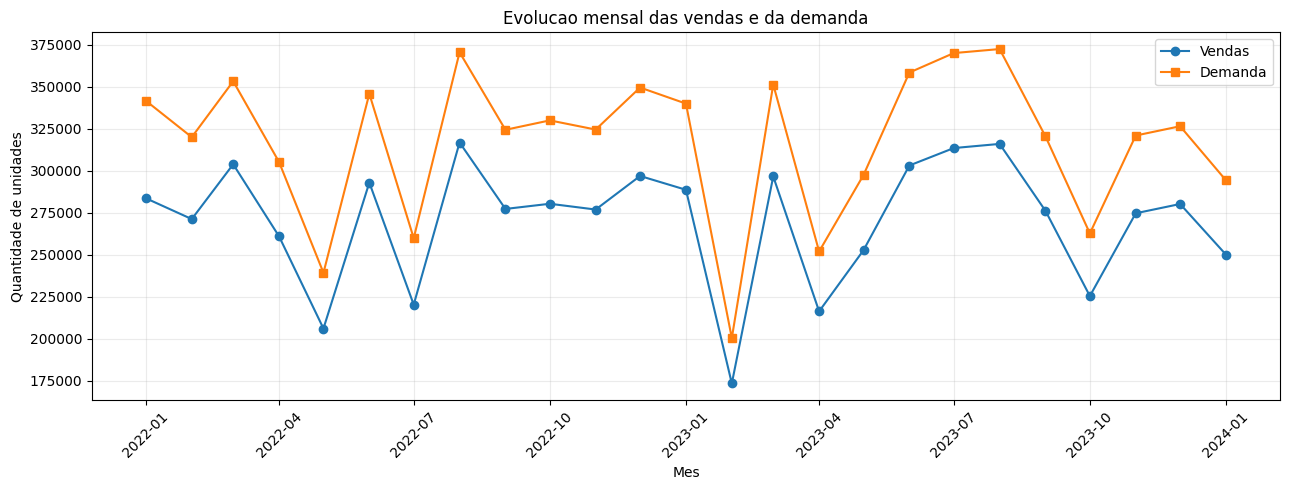

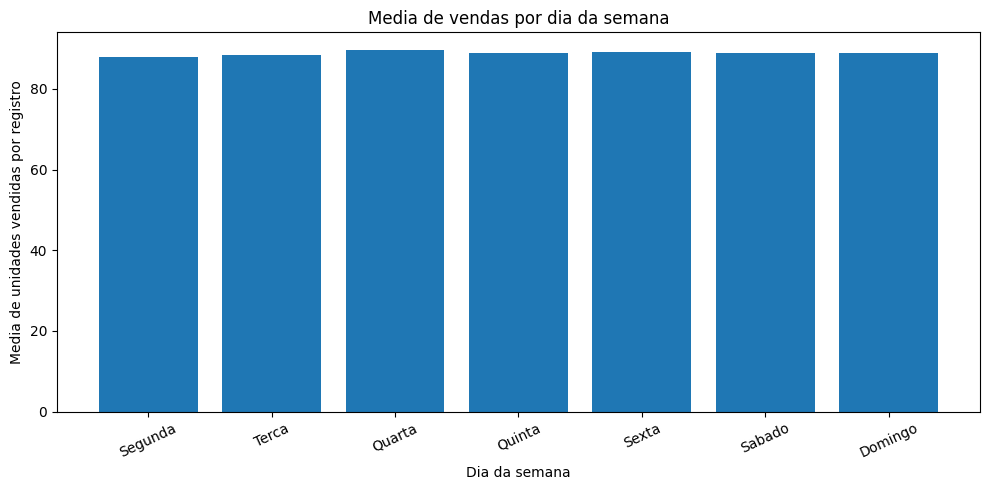

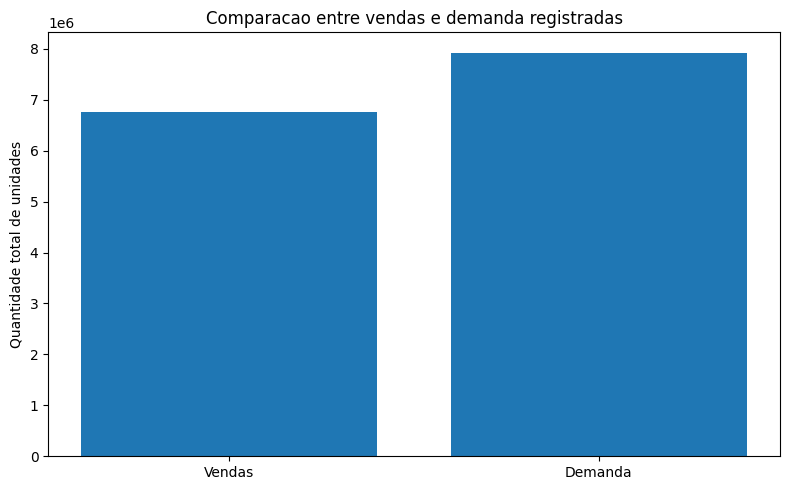


MEDIA DE VENDAS POR DIA DA SEMANA
---------------------------------------------


,Dia da semana,Media de vendas
0,Segunda,87.87
1,Terca,88.42
2,Quarta,89.55
3,Quinta,88.88
4,Sexta,89.18
5,Sabado,88.96
6,Domingo,88.95



CELULA 6 EXECUTADA COM SUCESSO!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 2")
print("CELULA 6 - ANALISE TEMPORAL")
print("=" * 65)

# 1. Criar uma copia para a analise
temporal = base.copy()

# 2. Garantir o formato correto das datas
temporal["data"] = pd.to_datetime(
    temporal["data"],
    errors="raise"
)

# 3. Criar variaveis temporais
temporal["ano"] = temporal["data"].dt.year
temporal["mes"] = temporal["data"].dt.month
temporal["dia_semana"] = temporal["data"].dt.dayofweek

# 4. Agregar vendas e demanda por mes
vendas_mensais = (
    temporal
    .set_index("data")
    .resample("MS")[["vendas", "demanda"]]
    .sum()
)

# Grafico 1 - Evolucao mensal
plt.figure(figsize=(13, 5))

plt.plot(
    vendas_mensais.index,
    vendas_mensais["vendas"],
    marker="o",
    label="Vendas"
)

plt.plot(
    vendas_mensais.index,
    vendas_mensais["demanda"],
    marker="s",
    label="Demanda"
)

plt.title("Evolucao mensal das vendas e da demanda")
plt.xlabel("Mes")
plt.ylabel("Quantidade de unidades")
plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. Media de vendas por dia da semana
dias = [
    "Segunda", "Terca", "Quarta",
    "Quinta", "Sexta", "Sabado", "Domingo"
]

media_semanal = (
    temporal.groupby("dia_semana")["vendas"]
    .mean()
    .reindex(range(7))
)

# Grafico 2 - Dias da semana
plt.figure(figsize=(10, 5))

plt.bar(
    dias,
    media_semanal.values
)

plt.title("Media de vendas por dia da semana")
plt.xlabel("Dia da semana")
plt.ylabel("Media de unidades vendidas por registro")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 6. Comparar demanda e vendas totais
totais = temporal[["vendas", "demanda"]].sum()

# Grafico 3 - Comparacao geral
plt.figure(figsize=(8, 5))

plt.bar(
    ["Vendas", "Demanda"],
    [totais["vendas"], totais["demanda"]]
)

plt.title("Comparacao entre vendas e demanda registradas")
plt.ylabel("Quantidade total de unidades")
plt.tight_layout()
plt.show()

# 7. Apresentar resultados numericos
print("\nMEDIA DE VENDAS POR DIA DA SEMANA")
print("-" * 45)

resumo_semanal = pd.DataFrame({
    "Dia da semana": dias,
    "Media de vendas": media_semanal.values
})

display(resumo_semanal.round(2))

print("\nCELULA 6 EXECUTADA COM SUCESSO!")


#7 - Análise de estoque e possíveis rupturas

SMARTSTOCK AI - ETAPA 2
CELULA 7 - ANALISE DE ESTOQUE E RUPTURAS

1. INDICADORES DE ESTOQUE
---------------------------------------------
Estoque zero: 406 (0.53%)
Demanda maior que vendas: 53,440 (70.32%)
Vendas maiores que estoque: 0 (0.00%)
Estoque menor que demanda: 10,394 (13.68%)

2. ESTOQUE ZERO E VENDAS
---------------------------------------------


Houve vendas,False,True
Estoque zero,,
False,0,75594
True,406,0



3. DIAGNOSTICO POR CATEGORIA
---------------------------------------------


,registros,estoque_medio,vendas_totais,demanda_total,estoque_zero,demanda_maior_vendas,vendas_maior_estoque,percentual_estoque_zero
categoria,,,,,,,,
Alimentos,30400,360.31,3127335,3677684,208,21497,0,0.68
Brinquedos,10640,229.11,834679,985338,51,7507,0,0.48
Eletrônicos,9120,289.26,757335,889036,46,6430,0,0.50
Móveis,13680,250.07,880654,1006590,46,9180,0,0.34
Vestuário,12160,282.10,1150873,1369456,55,8826,0,0.45


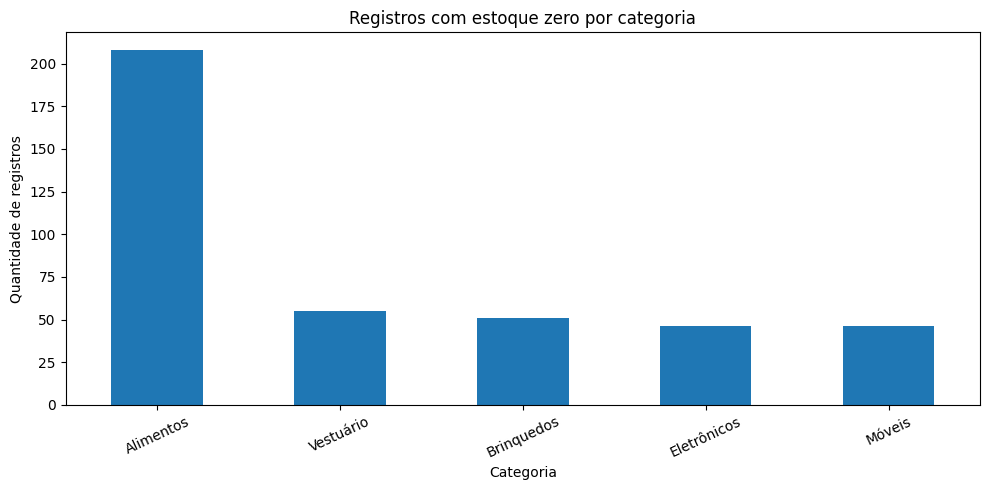

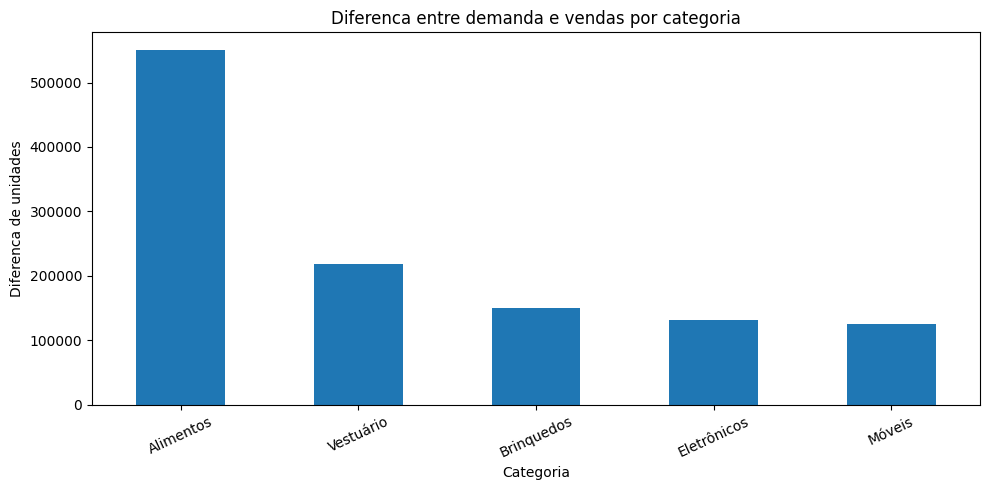


4. REGISTROS PARA INVESTIGACAO
---------------------------------------------
Registros com vendas superiores ao estoque: 0


,data,loja_id,produto_id,estoque,vendas,demanda



CELULA 7 EXECUTADA COM SUCESSO!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 2")
print("CELULA 7 - ANALISE DE ESTOQUE E RUPTURAS")
print("=" * 65)

# 1. Criar copia da base
analise_estoque = base.copy()

# 2. Verificar colunas necessarias
colunas = [
    "data", "loja_id", "produto_id",
    "categoria", "estoque", "vendas",
    "demanda", "unidades_solicitadas"
]

faltantes = [
    c for c in colunas
    if c not in analise_estoque.columns
]

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {faltantes}"
    )

# 3. Criar indicadores de diagnostico
analise_estoque["estoque_zero"] = (
    analise_estoque["estoque"] == 0
)

analise_estoque["demanda_maior_vendas"] = (
    analise_estoque["demanda"] >
    analise_estoque["vendas"]
)

analise_estoque["vendas_maior_estoque"] = (
    analise_estoque["vendas"] >
    analise_estoque["estoque"]
)

analise_estoque["estoque_menor_demanda"] = (
    analise_estoque["estoque"] <
    analise_estoque["demanda"]
)

# Diferenca descritiva, nao perda comprovada
analise_estoque["diferenca_demanda_vendas"] = (
    analise_estoque["demanda"] -
    analise_estoque["vendas"]
)

# 4. Indicadores gerais
print("\n1. INDICADORES DE ESTOQUE")
print("-" * 45)

indicadores = {
    "Estoque zero":
        analise_estoque["estoque_zero"].sum(),

    "Demanda maior que vendas":
        analise_estoque["demanda_maior_vendas"].sum(),

    "Vendas maiores que estoque":
        analise_estoque["vendas_maior_estoque"].sum(),

    "Estoque menor que demanda":
        analise_estoque["estoque_menor_demanda"].sum()
}

for nome, valor in indicadores.items():
    percentual = (
        valor / len(analise_estoque) * 100
    )

    print(
        f"{nome}: {valor:,} "
        f"({percentual:.2f}%)"
    )

# 5. Verificar estoque zero e vendas
print("\n2. ESTOQUE ZERO E VENDAS")
print("-" * 45)

tabela_zero = pd.crosstab(
    analise_estoque["estoque_zero"],
    analise_estoque["vendas"] > 0,
    rownames=["Estoque zero"],
    colnames=["Houve vendas"]
)

display(tabela_zero)

# 6. Resumo por categoria
print("\n3. DIAGNOSTICO POR CATEGORIA")
print("-" * 45)

resumo_categoria = (
    analise_estoque
    .groupby("categoria")
    .agg(
        registros=("estoque", "size"),
        estoque_medio=("estoque", "mean"),
        vendas_totais=("vendas", "sum"),
        demanda_total=("demanda", "sum"),
        estoque_zero=("estoque_zero", "sum"),
        demanda_maior_vendas=(
            "demanda_maior_vendas", "sum"
        ),
        vendas_maior_estoque=(
            "vendas_maior_estoque", "sum"
        )
    )
)

resumo_categoria["percentual_estoque_zero"] = (
    resumo_categoria["estoque_zero"] /
    resumo_categoria["registros"] * 100
)

display(resumo_categoria.round(2))

# 7. Grafico de estoque zero por categoria
plt.figure(figsize=(10, 5))

resumo_categoria["estoque_zero"].sort_values(
    ascending=False
).plot(kind="bar")

plt.title(
    "Registros com estoque zero por categoria"
)
plt.xlabel("Categoria")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 8. Grafico da diferenca entre demanda e vendas
diferenca_categoria = (
    resumo_categoria["demanda_total"] -
    resumo_categoria["vendas_totais"]
)

plt.figure(figsize=(10, 5))

diferenca_categoria.sort_values(
    ascending=False
).plot(kind="bar")

plt.title(
    "Diferenca entre demanda e vendas por categoria"
)
plt.xlabel("Categoria")
plt.ylabel("Diferenca de unidades")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 9. Verificar exemplos que merecem investigacao
print("\n4. REGISTROS PARA INVESTIGACAO")
print("-" * 45)

casos = analise_estoque.loc[
    analise_estoque["vendas_maior_estoque"],
    [
        "data", "loja_id", "produto_id",
        "estoque", "vendas", "demanda"
    ]
]

print(
    "Registros com vendas superiores ao estoque:",
    len(casos)
)

display(casos.head(10))

print("\nCELULA 7 EXECUTADA COM SUCESSO!")


#8 - Validação da relação entre estoque, vendas e demanda

In [ ]:

import pandas as pd
import numpy as np
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 2")
print("CELULA 8 - VALIDACAO DAS RELACOES COMERCIAIS")
print("=" * 65)

# 1. Criar copia para investigacao
diagnostico = base.copy()

# 2. Calcular o minimo entre demanda e estoque
diagnostico["venda_teorica"] = np.minimum(
    diagnostico["demanda"],
    diagnostico["estoque"]
)

# 3. Comparar vendas observadas e venda teorica
diagnostico["diferenca_teorica"] = (
    diagnostico["vendas"] -
    diagnostico["venda_teorica"]
)

igual_minimo = (
    diagnostico["diferenca_teorica"] == 0
).sum()

# 4. Outras relacoes importantes
demanda_maior_estoque = (
    diagnostico["demanda"] >
    diagnostico["estoque"]
).sum()

demanda_maior_vendas = (
    diagnostico["demanda"] >
    diagnostico["vendas"]
).sum()

vendas_iguais_demanda = (
    diagnostico["vendas"] ==
    diagnostico["demanda"]
).sum()

vendas_menores_demanda = (
    diagnostico["vendas"] <
    diagnostico["demanda"]
).sum()

vendas_maiores_demanda = (
    diagnostico["vendas"] >
    diagnostico["demanda"]
).sum()

vendas_iguais_estoque = (
    diagnostico["vendas"] ==
    diagnostico["estoque"]
).sum()

# 5. Apresentar indicadores
total = len(diagnostico)

indicadores = {
    "Vendas iguais ao minimo entre demanda e estoque":
        igual_minimo,

    "Demanda superior ao estoque":
        demanda_maior_estoque,

    "Demanda superior as vendas":
        demanda_maior_vendas,

    "Vendas iguais a demanda":
        vendas_iguais_demanda,

    "Vendas menores que demanda":
        vendas_menores_demanda,

    "Vendas maiores que demanda":
        vendas_maiores_demanda,

    "Vendas iguais ao estoque":
        vendas_iguais_estoque
}

print("\n1. RELACOES ENTRE VARIAVEIS")
print("-" * 55)

for nome, quantidade in indicadores.items():
    percentual = quantidade / total * 100

    print(
        f"{nome}: {quantidade:,} "
        f"({percentual:.2f}%)"
    )

# 6. Estatisticas da diferenca
print("\n2. DIFERENCA ENTRE VENDAS E MINIMO TEORICO")
print("-" * 55)

display(
    diagnostico["diferenca_teorica"]
    .describe()
    .to_frame("Diferenca")
)

# 7. Examinar exemplos divergentes
print("\n3. EXEMPLOS DE REGISTROS DIVERGENTES")
print("-" * 55)

divergentes = diagnostico.loc[
    diagnostico["diferenca_teorica"] != 0,
    [
        "data",
        "loja_id",
        "produto_id",
        "estoque",
        "vendas",
        "demanda",
        "venda_teorica",
        "diferenca_teorica"
    ]
]

print("Quantidade de divergencias:", len(divergentes))

display(divergentes.head(15))

# 8. Interpretacao automatica
print("\n4. DIAGNOSTICO")
print("-" * 55)

percentual_igual = igual_minimo / total * 100

if percentual_igual == 100:
    print(
        "Todas as vendas correspondem exatamente "
        "ao minimo entre demanda e estoque."
    )
    print(
        "Ha evidencia de uma regra deterministica "
        "na construcao da base."
    )

elif percentual_igual >= 95:
    print(
        "A maior parte das vendas corresponde "
        "ao minimo entre demanda e estoque."
    )
    print(
        "A relacao precisa ser considerada "
        "na modelagem preditiva."
    )

else:
    print(
        "As vendas nao seguem predominantemente "
        "a regra do minimo entre demanda e estoque."
    )
    print(
        "Sera necessario investigar outros "
        "fatores que influenciam as vendas."
    )

print("\nCELULA 8 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 2
CELULA 8 - VALIDACAO DAS RELACOES COMERCIAIS

1. RELACOES ENTRE VARIAVEIS
-------------------------------------------------------
Vendas iguais ao minimo entre demanda e estoque: 9,408 (12.38%)
Demanda superior ao estoque: 10,394 (13.68%)
Demanda superior as vendas: 53,440 (70.32%)
Vendas iguais a demanda: 1,560 (2.05%)
Vendas menores que demanda: 53,440 (70.32%)
Vendas maiores que demanda: 21,000 (27.63%)
Vendas iguais ao estoque: 8,654 (11.39%)

2. DIFERENCA ENTRE VENDAS E MINIMO TEORICO
-------------------------------------------------------


,Diferenca
count,76000.000000
mean,-9.227368
std,18.306083
min,-129.000000
25%,-20.000000
50%,-5.000000
75%,2.000000
max,68.000000



3. EXEMPLOS DE REGISTROS DIVERGENTES
-------------------------------------------------------
Quantidade de divergencias: 66592


,data,loja_id,produto_id,estoque,vendas,demanda,venda_teorica,diferenca_teorica
0,2022-01-01,S001,P0001,195,102,115,115,-13
1,2022-01-02,S001,P0001,93,71,84,84,-13
2,2022-01-03,S001,P0001,274,142,132,132,10
3,2022-01-04,S001,P0001,132,42,67,67,-25
4,2022-01-05,S001,P0001,319,129,110,110,19
5,2022-01-06,S001,P0001,190,98,146,146,-48
6,2022-01-07,S001,P0001,92,92,87,87,5
7,2022-01-08,S001,P0001,308,96,113,113,-17
8,2022-01-09,S001,P0001,212,57,87,87,-30
9,2022-01-10,S001,P0001,403,88,99,99,-11



4. DIAGNOSTICO
-------------------------------------------------------
As vendas nao seguem predominantemente a regra do minimo entre demanda e estoque.
Sera necessario investigar outros fatores que influenciam as vendas.

CELULA 8 EXECUTADA COM SUCESSO!


#9 - Investigação da variável demanda

SMARTSTOCK AI - ETAPA 2
CELULA 9 - INVESTIGACAO DA VARIAVEL DEMANDA

1. INDICADORES DESCRITIVOS
---------------------------------------------
MAE: 21.05
RMSE: 30.61
WAPE: 23.69%
Diferenca media (demanda - vendas): 15.49

ATENCAO: Estes indicadores comparam duas colunas observadas. Ainda nao representam o desempenho de um modelo preditivo.

2. MATRIZ DE CORRELACAO


,estoque,vendas,demanda,preco,desconto,promocao
estoque,1.000,0.235,0.127,-0.037,-0.001,-0.006
vendas,0.235,1.000,0.833,-0.015,0.184,0.227
demanda,0.127,0.833,1.000,-0.023,0.225,0.283
preco,-0.037,-0.015,-0.023,1.000,-0.094,-0.043
desconto,-0.001,0.184,0.225,-0.094,1.000,0.784
promocao,-0.006,0.227,0.283,-0.043,0.784,1.000


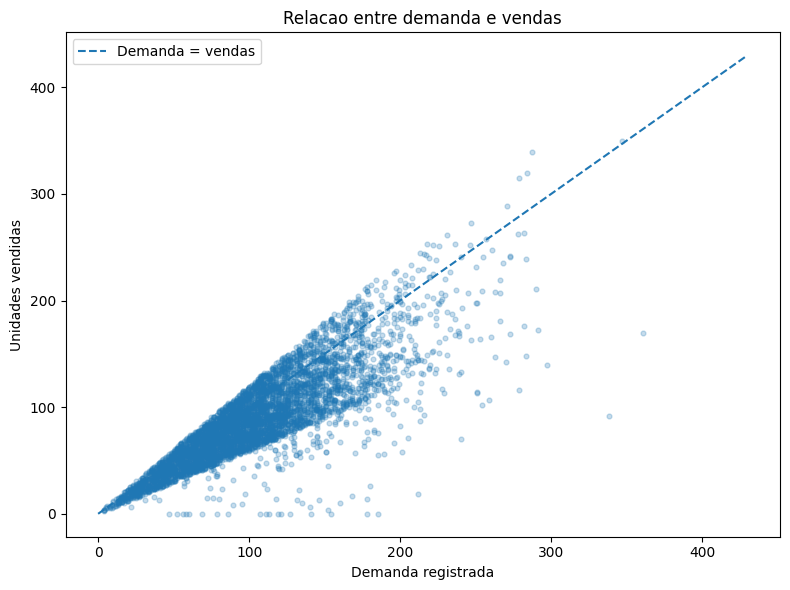


3. COMPARACAO POR CATEGORIA


,registros,vendas_medias,demanda_media,erro_absoluto_medio,diferenca_media
categoria,,,,,
Alimentos,30400,102.87,120.98,24.63,18.10
Brinquedos,10640,78.45,92.61,18.75,14.16
Eletrônicos,9120,83.04,97.48,19.60,14.44
Móveis,13680,64.38,73.58,13.76,9.21
Vestuário,12160,94.64,112.62,23.37,17.98



4. DISTRIBUICAO DAS DIFERENCAS


,Demanda menos vendas
count,76000.000000
mean,15.489842
std,26.404353
min,-68.000000
25%,-2.000000
50%,11.000000
75%,27.000000
max,316.000000



CELULA 9 EXECUTADA COM SUCESSO!


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 2")
print("CELULA 9 - INVESTIGACAO DA VARIAVEL DEMANDA")
print("=" * 65)

# 1. Criar copia da base
investigacao = base.copy()

# 2. Verificar colunas obrigatorias
colunas = [
    "data", "categoria", "estoque",
    "vendas", "demanda", "preco",
    "desconto", "promocao"
]

faltantes = [
    c for c in colunas
    if c not in investigacao.columns
]

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {faltantes}"
    )

# 3. Calcular diferencas
investigacao["erro_demanda"] = (
    investigacao["demanda"] -
    investigacao["vendas"]
)

investigacao["erro_absoluto"] = (
    investigacao["erro_demanda"].abs()
)

# 4. Calcular indicadores de erro
mae = investigacao["erro_absoluto"].mean()

rmse = np.sqrt(
    np.mean(investigacao["erro_demanda"] ** 2)
)

total_vendas = investigacao["vendas"].sum()

wape = (
    investigacao["erro_absoluto"].sum()
    / total_vendas * 100
    if total_vendas > 0
    else np.nan
)

vies = investigacao["erro_demanda"].mean()

print("\n1. INDICADORES DESCRITIVOS")
print("-" * 45)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"WAPE: {wape:.2f}%")
print(f"Diferenca media (demanda - vendas): {vies:.2f}")

print(
    "\nATENCAO: Estes indicadores comparam duas "
    "colunas observadas. Ainda nao representam "
    "o desempenho de um modelo preditivo."
)

# 5. Matriz de correlacao
variaveis = [
    "estoque",
    "vendas",
    "demanda",
    "preco",
    "desconto",
    "promocao"
]

correlacao = investigacao[variaveis].corr()

print("\n2. MATRIZ DE CORRELACAO")
display(correlacao.round(3))

# 6. Grafico de dispersao
# Amostra reproduzivel para melhorar visualizacao
amostra = investigacao.sample(
    n=min(5000, len(investigacao)),
    random_state=42
)

plt.figure(figsize=(8, 6))

plt.scatter(
    amostra["demanda"],
    amostra["vendas"],
    alpha=0.25,
    s=12
)

limite = max(
    investigacao["demanda"].max(),
    investigacao["vendas"].max()
)

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    label="Demanda = vendas"
)

plt.title("Relacao entre demanda e vendas")
plt.xlabel("Demanda registrada")
plt.ylabel("Unidades vendidas")
plt.legend()
plt.tight_layout()
plt.show()

# 7. Comparacao por categoria
resumo = (
    investigacao.groupby("categoria")
    .agg(
        registros=("vendas", "size"),
        vendas_medias=("vendas", "mean"),
        demanda_media=("demanda", "mean"),
        erro_absoluto_medio=(
            "erro_absoluto", "mean"
        ),
        diferenca_media=("erro_demanda", "mean")
    )
)

print("\n3. COMPARACAO POR CATEGORIA")
display(resumo.round(2))

# 8. Estatisticas dos erros
print("\n4. DISTRIBUICAO DAS DIFERENCAS")
display(
    investigacao["erro_demanda"]
    .describe()
    .to_frame("Demanda menos vendas")
)

print("\nCELULA 9 EXECUTADA COM SUCESSO!")


#10 - Análise da sazonalidade por produto

SMARTSTOCK AI - ETAPA 2
CELULA 10 - ANALISE DA SAZONALIDADE POR PRODUTO


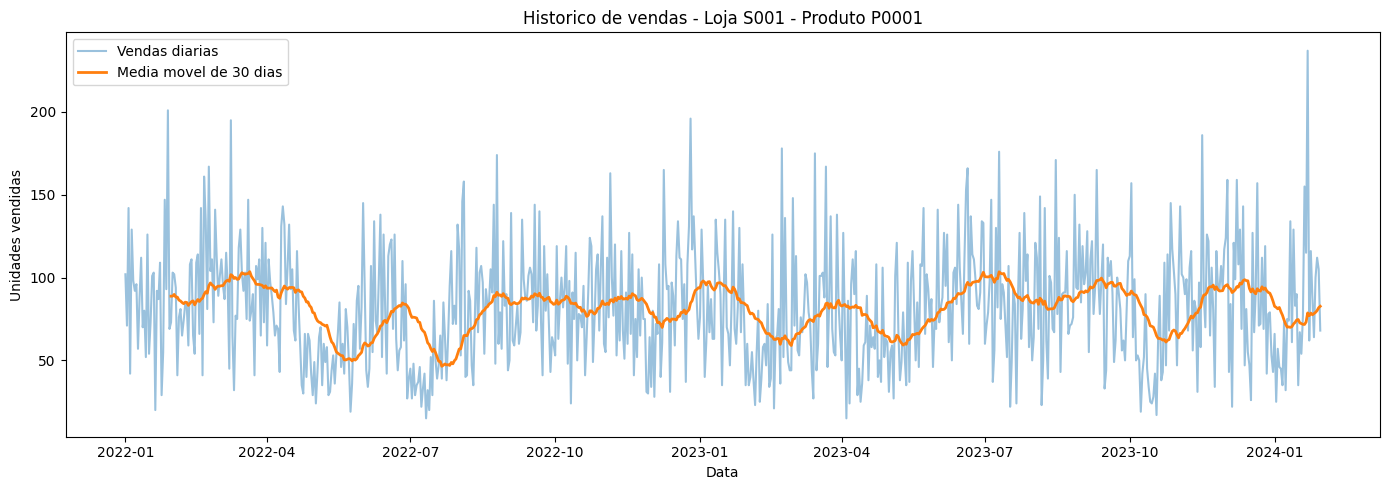

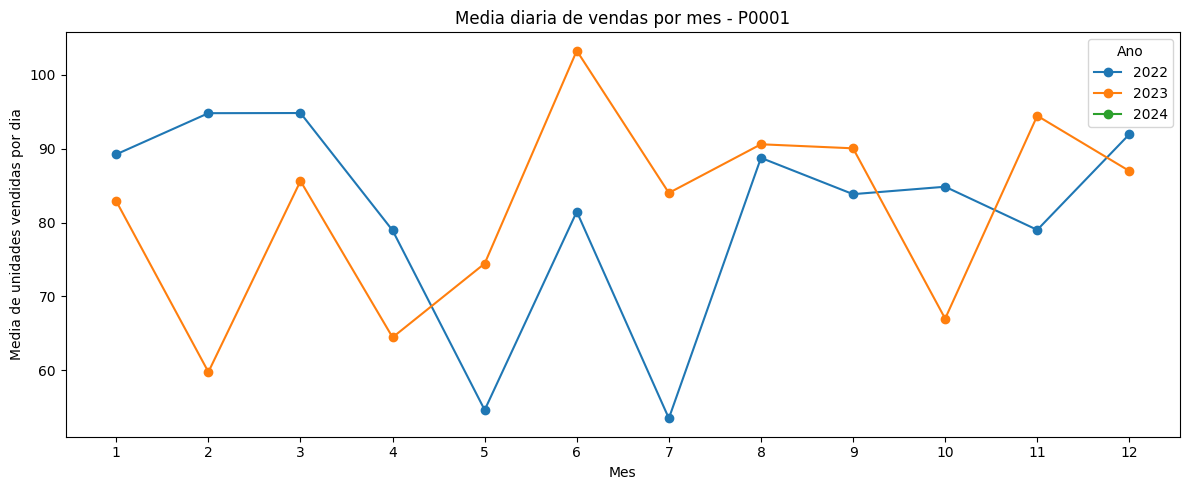


RESUMO DO PRODUTO
---------------------------------------------
Loja: S001
Produto: P0001
Categoria: Eletrônicos
Registros: 760
Media diaria: 81.68
Desvio padrao: 35.13
Venda minima: 15
Venda maxima: 237

MEDIA DIARIA POR MES E ANO


ano,2022,2023,2024
mes,,,
1,89.23,82.87,NaN
2,94.79,59.79,NaN
3,94.81,85.61,NaN
4,78.93,64.47,NaN
5,54.65,74.45,NaN
6,81.47,103.23,NaN
7,53.52,84.00,NaN
8,88.74,90.58,NaN
9,83.83,90.03,NaN



CELULA 10 EXECUTADA COM SUCESSO!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 2")
print("CELULA 10 - ANALISE DA SAZONALIDADE POR PRODUTO")
print("=" * 65)

# 1. Criar copia da base
sazonalidade = base.copy()

sazonalidade["data"] = pd.to_datetime(
    sazonalidade["data"],
    errors="raise"
)

# 2. Selecionar loja e produto
LOJA = "S001"
PRODUTO = "P0001"

produto = sazonalidade.loc[
    (sazonalidade["loja_id"] == LOJA) &
    (sazonalidade["produto_id"] == PRODUTO)
].copy()

if produto.empty:
    raise ValueError(
        "A combinacao de loja e produto nao foi encontrada."
    )

produto = produto.sort_values("data")

# 3. Calcular media movel de 30 dias
produto["media_movel_30"] = (
    produto["vendas"]
    .rolling(window=30, min_periods=30)
    .mean()
)

# 4. Grafico do historico diario
plt.figure(figsize=(14, 5))

plt.plot(
    produto["data"],
    produto["vendas"],
    alpha=0.45,
    label="Vendas diarias"
)

plt.plot(
    produto["data"],
    produto["media_movel_30"],
    linewidth=2,
    label="Media movel de 30 dias"
)

plt.title(
    f"Historico de vendas - Loja {LOJA} - Produto {PRODUTO}"
)
plt.xlabel("Data")
plt.ylabel("Unidades vendidas")
plt.legend()
plt.tight_layout()
plt.show()

# 5. Criar variaveis temporais
produto["mes"] = produto["data"].dt.month
produto["ano"] = produto["data"].dt.year

# 6. Calcular media diaria por mes e ano
media_mensal = (
    produto.groupby(["ano", "mes"])["vendas"]
    .mean()
    .unstack(0)
)

# Considerar apenas meses completos
dias_observados = (
    produto.groupby(["ano", "mes"])["data"]
    .nunique()
)

dias_esperados = (
    produto.groupby(["ano", "mes"])["data"]
    .apply(lambda x: x.dt.days_in_month.iloc[0])
)

meses_completos = (
    dias_observados == dias_esperados
)

for (ano, mes), completo in meses_completos.items():
    if not completo:
        media_mensal.loc[mes, ano] = float("nan")

# 7. Grafico comparativo de sazonalidade
plt.figure(figsize=(12, 5))

for ano in media_mensal.columns:
    plt.plot(
        media_mensal.index,
        media_mensal[ano],
        marker="o",
        label=str(ano)
    )

plt.title(
    f"Media diaria de vendas por mes - {PRODUTO}"
)
plt.xlabel("Mes")
plt.ylabel("Media de unidades vendidas por dia")
plt.xticks(range(1, 13))
plt.legend(title="Ano")
plt.tight_layout()
plt.show()

# 8. Estatisticas do produto
print("\nRESUMO DO PRODUTO")
print("-" * 45)

print("Loja:", LOJA)
print("Produto:", PRODUTO)
print("Categoria:", produto["categoria"].iloc[0])
print("Registros:", len(produto))
print("Media diaria:", round(produto["vendas"].mean(), 2))
print("Desvio padrao:", round(produto["vendas"].std(), 2))
print("Venda minima:", produto["vendas"].min())
print("Venda maxima:", produto["vendas"].max())

print("\nMEDIA DIARIA POR MES E ANO")
display(media_mensal.round(2))

print("\nCELULA 10 EXECUTADA COM SUCESSO!")


#11 - Engenharia de variáveis para Machine Learning

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 3")
print("CELULA 11 - ENGENHARIA DE VARIAVEIS")
print("=" * 65)

# 1. Criar copia da base
ml = base.copy()

# 2. Garantir datas corretas
ml["data"] = pd.to_datetime(
    ml["data"],
    errors="raise"
)

# 3. Ordenar por loja, produto e data
ml = ml.sort_values(
    ["loja_id", "produto_id", "data"]
).reset_index(drop=True)

# 4. Identificar cada serie temporal
chaves = ["loja_id", "produto_id"]

grupo = ml.groupby(
    chaves,
    sort=False
)["vendas"]

# 5. Criar variaveis de calendario
ml["dia_semana"] = ml["data"].dt.dayofweek
ml["mes"] = ml["data"].dt.month
ml["dia_mes"] = ml["data"].dt.day

# 6. Criar historico de vendas
for atraso in [1, 7, 14, 30]:
    ml[f"vendas_lag_{atraso}"] = (
        grupo.shift(atraso)
    )

# 7. Criar medias moveis
# IMPORTANTE: excluir o dia atual
for janela in [7, 14, 30]:
    ml[f"media_movel_{janela}"] = (
        ml.groupby(chaves)["vendas"]
        .transform(
            lambda serie: (
                serie.shift(1)
                .rolling(
                    window=janela,
                    min_periods=janela
                )
                .mean()
            )
        )
    )

# 8. Criar desvio-padrao historico
ml["desvio_movel_7"] = (
    ml.groupby(chaves)["vendas"]
    .transform(
        lambda serie: (
            serie.shift(1)
            .rolling(
                window=7,
                min_periods=7
            )
            .std()
        )
    )
)

# 9. Identificar colunas historicas
colunas_historicas = [
    "vendas_lag_1",
    "vendas_lag_7",
    "vendas_lag_14",
    "vendas_lag_30",
    "media_movel_7",
    "media_movel_14",
    "media_movel_30",
    "desvio_movel_7"
]

# 10. Remover apenas linhas iniciais
# sem historico suficiente
linhas_antes = len(ml)

ml = ml.dropna(
    subset=colunas_historicas
).reset_index(drop=True)

linhas_depois = len(ml)

# 11. Verificar a base
assert not ml[colunas_historicas].isna().any().any()

assert not ml.duplicated(
    ["data", "loja_id", "produto_id"]
).any()

print("\nRESULTADOS")
print("-" * 45)
print("Registros originais:", linhas_antes)
print("Registros preparados:", linhas_depois)
print("Registros removidos:", linhas_antes - linhas_depois)
print("Variaveis historicas:", len(colunas_historicas))

# 12. Exibir amostra
print("\nAMOSTRA DAS VARIAVEIS CRIADAS")

display(
    ml[
        [
            "data",
            "loja_id",
            "produto_id",
            "vendas",
            "vendas_lag_1",
            "vendas_lag_7",
            "media_movel_7",
            "media_movel_30"
        ]
    ].head(10)
)

# 13. Salvar a base preparada
PASTA_ML = Path(
    "/content/drive/MyDrive/Varejo/"
    "dados_processados"
)

PASTA_ML.mkdir(
    parents=True,
    exist_ok=True
)

CAMINHO_ML = (
    PASTA_ML / "base_machine_learning.csv"
)

ml.to_csv(
    CAMINHO_ML,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# 14. Conferir o arquivo salvo
conferencia = pd.read_csv(CAMINHO_ML)

assert conferencia.shape == ml.shape

print("\nARQUIVO SALVO:")
print(CAMINHO_ML)

print("\nCELULA 11 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 3
CELULA 11 - ENGENHARIA DE VARIAVEIS

RESULTADOS
---------------------------------------------
Registros originais: 76000
Registros preparados: 73000
Registros removidos: 3000
Variaveis historicas: 8

AMOSTRA DAS VARIAVEIS CRIADAS


,data,loja_id,produto_id,vendas,vendas_lag_1,vendas_lag_7,media_movel_7,media_movel_30
0,2022-01-31,S001,P0001,103,73.0,29.0,95.285714,88.766667
1,2022-02-01,S001,P0001,102,103.0,55.0,105.857143,88.800000
2,2022-02-02,S001,P0001,94,102.0,147.0,112.571429,89.833333
3,2022-02-03,S001,P0001,41,94.0,93.0,105.000000,88.233333
4,2022-02-04,S001,P0001,76,41.0,201.0,97.571429,88.200000
5,2022-02-05,S001,P0001,81,76.0,69.0,79.714286,86.433333
6,2022-02-06,S001,P0001,65,81.0,73.0,81.428571,85.866667
7,2022-02-07,S001,P0001,74,65.0,103.0,80.285714,84.966667
8,2022-02-08,S001,P0001,84,74.0,102.0,76.142857,84.233333
9,2022-02-09,S001,P0001,83,84.0,94.0,73.571429,85.133333



ARQUIVO SALVO:
/content/drive/MyDrive/Varejo/dados_processados/base_machine_learning.csv

CELULA 11 EXECUTADA COM SUCESSO!


#12 — Divisão cronológica e seleção das variáveis

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 3")
print("CELULA 12 - DIVISAO CRONOLOGICA")
print("=" * 65)

# 1. Carregar a base preparada
CAMINHO_ML = Path(
    "/content/drive/MyDrive/Varejo/"
    "dados_processados/base_machine_learning.csv"
)

if not CAMINHO_ML.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {CAMINHO_ML}"
    )

ml = pd.read_csv(
    CAMINHO_ML,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 2. Definir a variavel que queremos prever
ALVO = "vendas"

# 3. Selecionar somente variaveis seguras
# para previsao de um dia a frente
VARIAVEIS = [
    "loja_id",
    "produto_id",
    "dia_semana",
    "mes",
    "dia_mes",
    "vendas_lag_1",
    "vendas_lag_7",
    "vendas_lag_14",
    "vendas_lag_30",
    "media_movel_7",
    "media_movel_14",
    "media_movel_30",
    "desvio_movel_7"
]

# 4. Validar as colunas
necessarias = VARIAVEIS + [ALVO, "data"]

faltantes = [
    coluna for coluna in necessarias
    if coluna not in ml.columns
]

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {faltantes}"
    )

# 5. Verificar dados ausentes
if ml[necessarias].isna().any().any():
    raise ValueError(
        "Existem valores ausentes nas variaveis."
    )

# 6. Definir datas dos conjuntos
FIM_TREINO = pd.Timestamp("2023-08-31")
FIM_VALIDACAO = pd.Timestamp("2023-11-30")

treino = ml.loc[
    ml["data"] <= FIM_TREINO
].copy()

validacao = ml.loc[
    (ml["data"] > FIM_TREINO) &
    (ml["data"] <= FIM_VALIDACAO)
].copy()

teste = ml.loc[
    ml["data"] > FIM_VALIDACAO
].copy()

# 7. Garantir que nenhum conjunto esteja vazio
if any(
    conjunto.empty
    for conjunto in [treino, validacao, teste]
):
    raise ValueError(
        "Um dos conjuntos esta vazio."
    )

# 8. Verificar separacao cronologica
assert treino["data"].max() < validacao["data"].min()
assert validacao["data"].max() < teste["data"].min()

# 9. Conferir registros
assert (
    len(treino) + len(validacao) + len(teste)
    == len(ml)
)

# 10. Separar entradas e resultados
X_treino = treino[VARIAVEIS].copy()
y_treino = treino[ALVO].copy()

X_validacao = validacao[VARIAVEIS].copy()
y_validacao = validacao[ALVO].copy()

X_teste = teste[VARIAVEIS].copy()
y_teste = teste[ALVO].copy()

# 11. Criar relatorio
resumo = pd.DataFrame({
    "Conjunto": [
        "Treinamento",
        "Validacao",
        "Teste"
    ],
    "Registros": [
        len(treino),
        len(validacao),
        len(teste)
    ],
    "Data inicial": [
        treino["data"].min().date(),
        validacao["data"].min().date(),
        teste["data"].min().date()
    ],
    "Data final": [
        treino["data"].max().date(),
        validacao["data"].max().date(),
        teste["data"].max().date()
    ]
})

resumo["Percentual"] = (
    resumo["Registros"] / len(ml) * 100
).round(2)

print("\n1. DIVISAO DOS DADOS")
display(resumo)

print("\n2. VARIAVEIS PREDITORAS")
for i, coluna in enumerate(VARIAVEIS, 1):
    print(f"{i:02d}. {coluna}")

print("\n3. VARIAVEL ALVO")
print(ALVO)

print("\n4. VERIFICACAO DE INTEGRIDADE")
print("Total de registros:", len(ml))
print("Registros distribuidos:", len(treino) +
      len(validacao) + len(teste))

print("\nCELULA 12 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 3
CELULA 12 - DIVISAO CRONOLOGICA

1. DIVISAO DOS DADOS


,Conjunto,Registros,Data inicial,Data final,Percentual
0,Treinamento,57800,2022-01-31,2023-08-31,79.18
1,Validacao,9100,2023-09-01,2023-11-30,12.47
2,Teste,6100,2023-12-01,2024-01-30,8.36



2. VARIAVEIS PREDITORAS
01. loja_id
02. produto_id
03. dia_semana
04. mes
05. dia_mes
06. vendas_lag_1
07. vendas_lag_7
08. vendas_lag_14
09. vendas_lag_30
10. media_movel_7
11. media_movel_14
12. media_movel_30
13. desvio_movel_7

3. VARIAVEL ALVO
vendas

4. VERIFICACAO DE INTEGRIDADE
Total de registros: 73000
Registros distribuidos: 73000

CELULA 12 EXECUTADA COM SUCESSO!


#13 - Primeiro modelo de Machine Learning

In [ ]:

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 3")
print("CELULA 13 - PRIMEIRO MODELO DE MACHINE LEARNING")
print("=" * 65)

# 1. Validar os conjuntos
assert len(X_treino) == len(y_treino)
assert len(X_validacao) == len(y_validacao)

assert not X_treino.isna().any().any()
assert not X_validacao.isna().any().any()

# 2. Separar as variaveis categoricas e numericas
categoricas = ["loja_id", "produto_id"]

numericas = [
    coluna for coluna in VARIAVEIS
    if coluna not in categoricas
]

# 3. Preparar as variaveis categoricas
preprocessamento = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categoricas
        ),
        (
            "numericas",
            "passthrough",
            numericas
        )
    ]
)

# 4. Definir o modelo Random Forest
floresta = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# 5. Criar o pipeline
modelo = Pipeline(
    steps=[
        ("preprocessamento", preprocessamento),
        ("random_forest", floresta)
    ]
)

# 6. Treinar somente com os dados de treinamento
print("\nTreinando o modelo Random Forest...")

modelo.fit(
    X_treino,
    y_treino
)

print("Treinamento concluido!")

# 7. Prever os dados de validacao
previsao_rf = modelo.predict(X_validacao)

# Impedir previsoes negativas
previsao_rf = np.maximum(
    previsao_rf, 0
)

# 8. Modelo de referencia:
# media dos ultimos 7 dias
previsao_referencia = (
    X_validacao["media_movel_7"].to_numpy()
)

# 9. Funcao de avaliacao
def avaliar_modelo(y_real, y_previsto):
    real = np.asarray(y_real)
    previsto = np.asarray(y_previsto)

    mae = mean_absolute_error(real, previsto)

    rmse = np.sqrt(
        mean_squared_error(real, previsto)
    )

    soma_real = np.sum(np.abs(real))

    wape = (
        np.sum(np.abs(real - previsto))
        / soma_real * 100
        if soma_real > 0
        else np.nan
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    }

# 10. Avaliar os dois metodos
resultado_referencia = avaliar_modelo(
    y_validacao,
    previsao_referencia
)

resultado_rf = avaliar_modelo(
    y_validacao,
    previsao_rf
)

# 11. Comparar resultados
comparacao = pd.DataFrame(
    [
        {
            "Modelo": "Media movel de 7 dias",
            **resultado_referencia
        },
        {
            "Modelo": "Random Forest",
            **resultado_rf
        }
    ]
)

print("\nRESULTADOS NA VALIDACAO")
print("-" * 45)

display(comparacao.round(3))

# 12. Calcular melhoria percentual no MAE
mae_base = resultado_referencia["MAE"]
mae_rf = resultado_rf["MAE"]

melhoria = (
    (mae_base - mae_rf) / mae_base * 100
    if mae_base > 0
    else np.nan
)

print("\nCOMPARACAO COM A MEDIA MOVEL")

print(
    f"Variacao relativa do MAE: "
    f"{melhoria:.2f}%"
)

if melhoria > 0:
    print(
        "Random Forest apresentou menor erro "
        "que a media movel."
    )
elif melhoria < 0:
    print(
        "A media movel apresentou menor erro "
        "que Random Forest."
    )
else:
    print(
        "Os modelos apresentaram o mesmo MAE."
    )

print("\nCELULA 13 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 3
CELULA 13 - PRIMEIRO MODELO DE MACHINE LEARNING

Treinando o modelo Random Forest...
Treinamento concluido!

RESULTADOS NA VALIDACAO
---------------------------------------------


,Modelo,MAE,RMSE,WAPE (%)
0,Media movel de 7 dias,29.766,38.585,34.913
1,Random Forest,29.199,37.416,34.248



COMPARACAO COM A MEDIA MOVEL
Variacao relativa do MAE: 1.91%
Random Forest apresentou menor erro que a media movel.

CELULA 13 EXECUTADA COM SUCESSO!


#14 - Análise dos erros do modelo

SMARTSTOCK AI - ETAPA 3
CELULA 14 - ANALISE DOS ERROS DO MODELO

1. ERROS POR CATEGORIA
---------------------------------------------


,Registros,MAE,RMSE,WAPE (%),Vies
categoria,,,,,
Alimentos,3640.0,33.132,42.515,34.069,1.210
Eletrônicos,1092.0,27.756,35.015,33.499,3.143
Brinquedos,1274.0,27.752,34.543,37.225,5.485
Vestuário,1456.0,27.533,35.372,30.519,1.358
Móveis,1638.0,24.027,30.055,37.465,7.010



2. ERROS POR LOJA
---------------------------------------------


,Registros,MAE,RMSE,WAPE (%),Vies
loja_id,,,,,
S005,1820.0,30.438,38.789,35.207,2.746
S003,1820.0,30.031,38.052,34.346,2.567
S002,1820.0,29.128,37.363,33.842,3.583
S004,1820.0,28.911,37.839,34.876,3.468
S001,1820.0,27.487,34.921,32.944,3.176



3. VIES GERAL
---------------------------------------------
Vies medio: 3.108 unidades
O modelo tende a superestimar as vendas, em media.


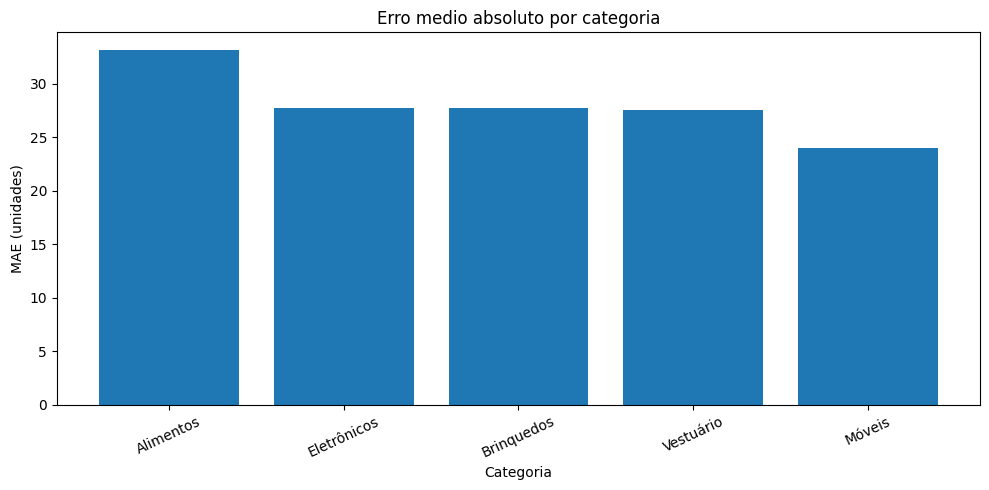

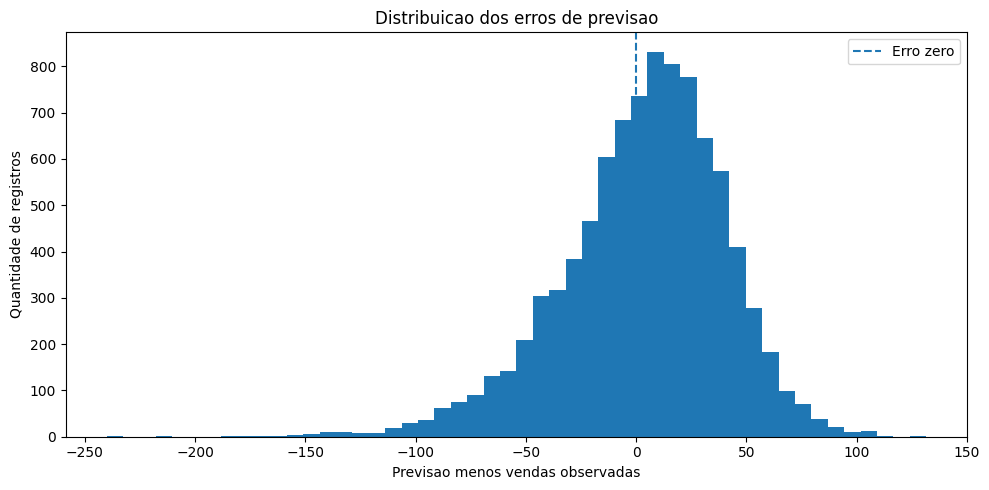


4. DEZ MAIORES ERROS ABSOLUTOS
---------------------------------------------


,data,loja_id,produto_id,categoria,vendas,previsao,erro,erro_absoluto,erro_quadratico
10078,2023-09-11,S001,P0014,Alimentos,336,95.90,-240.10,240.10,57646.00
53192,2023-10-25,S004,P0013,Alimentos,288,74.05,-213.95,213.95,45772.79
22485,2023-09-08,S002,P0011,Alimentos,319,107.39,-211.61,211.61,44777.69
69985,2023-10-28,S005,P0016,Brinquedos,252,67.38,-184.62,184.62,34085.09
30583,2023-11-15,S003,P0002,Alimentos,275,93.71,-181.29,181.29,32865.41
2084,2023-10-17,S001,P0003,Vestuário,271,95.63,-175.37,175.37,30755.44
63388,2023-10-01,S005,P0007,Alimentos,262,91.07,-170.93,170.93,29218.64
44432,2023-10-25,S004,P0001,Alimentos,258,89.48,-168.52,168.52,28398.31
63420,2023-11-02,S005,P0007,Alimentos,255,93.80,-161.20,161.20,25984.84
32046,2023-11-18,S003,P0004,Alimentos,254,95.24,-158.76,158.76,25203.35



CELULA 14 EXECUTADA COM SUCESSO!


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 3")
print("CELULA 14 - ANALISE DOS ERROS DO MODELO")
print("=" * 65)

# 1. Verificar integridade
if len(validacao) != len(previsao_rf):
    raise ValueError(
        "Quantidade de previsoes diferente "
        "da quantidade de registros."
    )

# 2. Criar base de diagnostico
erros_modelo = validacao[
    [
        "data",
        "loja_id",
        "produto_id",
        "categoria",
        "vendas"
    ]
].copy()

erros_modelo["previsao"] = previsao_rf

# 3. Calcular erros
erros_modelo["erro"] = (
    erros_modelo["previsao"] -
    erros_modelo["vendas"]
)

erros_modelo["erro_absoluto"] = (
    erros_modelo["erro"].abs()
)

erros_modelo["erro_quadratico"] = (
    erros_modelo["erro"] ** 2
)

# 4. Funcao de resumo dos erros
def resumir_erros(grupo):
    soma_vendas = grupo["vendas"].sum()

    wape = (
        grupo["erro_absoluto"].sum()
        / soma_vendas * 100
        if soma_vendas > 0
        else np.nan
    )

    return pd.Series({
        "Registros": len(grupo),
        "MAE": grupo["erro_absoluto"].mean(),
        "RMSE": np.sqrt(
            grupo["erro_quadratico"].mean()
        ),
        "WAPE (%)": wape,
        "Vies": grupo["erro"].mean()
    })

# 5. Erros por categoria
print("\n1. ERROS POR CATEGORIA")
print("-" * 45)

erros_categoria = (
    erros_modelo.groupby("categoria")
    .apply(
        resumir_erros,
        include_groups=False
    )
    .sort_values("MAE", ascending=False)
)

display(erros_categoria.round(3))

# 6. Erros por loja
print("\n2. ERROS POR LOJA")
print("-" * 45)

erros_loja = (
    erros_modelo.groupby("loja_id")
    .apply(
        resumir_erros,
        include_groups=False
    )
    .sort_values("MAE", ascending=False)
)

display(erros_loja.round(3))

# 7. Vies geral
vies_geral = erros_modelo["erro"].mean()

print("\n3. VIES GERAL")
print("-" * 45)

print(f"Vies medio: {vies_geral:.3f} unidades")

if vies_geral > 0:
    print(
        "O modelo tende a superestimar "
        "as vendas, em media."
    )
elif vies_geral < 0:
    print(
        "O modelo tende a subestimar "
        "as vendas, em media."
    )
else:
    print("Vies medio igual a zero.")

# 8. Grafico de erros absolutos por categoria
plt.figure(figsize=(10, 5))

plt.bar(
    erros_categoria.index,
    erros_categoria["MAE"]
)

plt.title("Erro medio absoluto por categoria")
plt.xlabel("Categoria")
plt.ylabel("MAE (unidades)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 9. Histograma dos erros
plt.figure(figsize=(10, 5))

plt.hist(
    erros_modelo["erro"],
    bins=50
)

plt.axvline(
    0,
    linestyle="--",
    label="Erro zero"
)

plt.title("Distribuicao dos erros de previsao")
plt.xlabel("Previsao menos vendas observadas")
plt.ylabel("Quantidade de registros")
plt.legend()
plt.tight_layout()
plt.show()

# 10. Investigar maiores erros
print("\n4. DEZ MAIORES ERROS ABSOLUTOS")
print("-" * 45)

maiores_erros = (
    erros_modelo.sort_values(
        "erro_absoluto",
        ascending=False
    )
    .head(10)
)

display(maiores_erros.round(2))

print("\nCELULA 14 EXECUTADA COM SUCESSO!")


#15 - Comparação de algoritmos de Machine Learning

In [ ]:

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 3")
print("CELULA 15 - COMPARACAO DE ALGORITMOS")
print("=" * 65)

# 1. Conferir dados da etapa anterior
assert len(X_treino) == len(y_treino)
assert len(X_validacao) == len(y_validacao)

assert len(previsao_rf) == len(y_validacao)
assert len(previsao_referencia) == len(y_validacao)

# 2. Criar o modelo Extra Trees
extra_trees = ExtraTreesRegressor(
    n_estimators=150,
    max_depth=18,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# 3. Utilizar o mesmo preprocessamento
# empregado no Random Forest
modelo_extra = Pipeline(
    steps=[
        (
            "preprocessamento",
            clone(preprocessamento)
        ),
        (
            "extra_trees",
            extra_trees
        )
    ]
)

# 4. Treinar com os dados de treinamento
print("\nTreinando Extra Trees...")

modelo_extra.fit(
    X_treino,
    y_treino
)

print("Treinamento concluido!")

# 5. Gerar previsoes na validacao
previsao_extra = modelo_extra.predict(
    X_validacao
)

# Impedir previsoes negativas
previsao_extra = np.maximum(
    previsao_extra, 0
)

# 6. Avaliar os tres metodos
resultados = []

modelos_previsoes = {
    "Media movel de 7 dias": previsao_referencia,
    "Random Forest": previsao_rf,
    "Extra Trees": previsao_extra
}

for nome, previsoes in modelos_previsoes.items():

    metricas = avaliar_modelo(
        y_validacao,
        previsoes
    )

    resultados.append({
        "Modelo": nome,
        **metricas
    })

comparacao_modelos = pd.DataFrame(
    resultados
).sort_values("MAE").reset_index(drop=True)

print("\n1. COMPARACAO NA VALIDACAO")
print("-" * 45)

display(comparacao_modelos.round(3))

# 7. Comparar os modelos com a referencia
mae_referencia = avaliar_modelo(
    y_validacao,
    previsao_referencia
)["MAE"]

comparacao_modelos["Melhoria MAE (%)"] = (
    (mae_referencia - comparacao_modelos["MAE"])
    / mae_referencia * 100
)

print("\n2. MELHORIA EM RELACAO A MEDIA MOVEL")
print("-" * 45)

display(
    comparacao_modelos[
        ["Modelo", "MAE", "Melhoria MAE (%)"]
    ].round(3)
)

# 8. Identificar o melhor modelo pelo MAE
melhor_nome = comparacao_modelos.iloc[0]["Modelo"]

print("\n3. MELHOR DESEMPENHO NA VALIDACAO")
print("-" * 45)

print("Modelo:", melhor_nome)

# 9. Comparar vies dos modelos
print("\n4. ANALISE DE VIES")
print("-" * 45)

for nome, previsoes in modelos_previsoes.items():

    vies = np.mean(
        np.asarray(previsoes) -
        np.asarray(y_validacao)
    )

    print(f"{nome}: {vies:.3f} unidades")

print("\nCELULA 15 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 3
CELULA 15 - COMPARACAO DE ALGORITMOS

Treinando Extra Trees...
Treinamento concluido!

1. COMPARACAO NA VALIDACAO
---------------------------------------------


,Modelo,MAE,RMSE,WAPE (%)
0,Extra Trees,28.880,37.147,33.873
1,Random Forest,29.199,37.416,34.248
2,Media movel de 7 dias,29.766,38.585,34.913



2. MELHORIA EM RELACAO A MEDIA MOVEL
---------------------------------------------


,Modelo,MAE,Melhoria MAE (%)
0,Extra Trees,28.880,2.977
1,Random Forest,29.199,1.905
2,Media movel de 7 dias,29.766,0.000



3. MELHOR DESEMPENHO NA VALIDACAO
---------------------------------------------
Modelo: Extra Trees

4. ANALISE DE VIES
---------------------------------------------
Media movel de 7 dias: 0.326 unidades
Random Forest: 3.108 unidades
Extra Trees: 3.020 unidades

CELULA 15 EXECUTADA COM SUCESSO!


#16 - Otimização do Extra Trees

In [ ]:

import numpy as np
import pandas as pd

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 3")
print("CELULA 16 - OTIMIZACAO DO EXTRA TREES")
print("=" * 65)

# 1. Configuracoes a serem testadas
# A configuracao original sera mantida
configuracoes = [
    {
        "nome": "Original",
        "n_estimators": 150,
        "max_depth": 18,
        "min_samples_leaf": 5
    },
    {
        "nome": "Configuracao A",
        "n_estimators": 200,
        "max_depth": 12,
        "min_samples_leaf": 5
    },
    {
        "nome": "Configuracao B",
        "n_estimators": 200,
        "max_depth": 18,
        "min_samples_leaf": 10
    },
    {
        "nome": "Configuracao C",
        "n_estimators": 200,
        "max_depth": 25,
        "min_samples_leaf": 3
    },
    {
        "nome": "Configuracao D",
        "n_estimators": 250,
        "max_depth": None,
        "min_samples_leaf": 5
    }
]

# 2. Armazenar resultados e modelos
resultados_otimizacao = []
modelos_treinados = {}

# 3. Executar treinamento
for config in configuracoes:

    nome = config["nome"]

    print(f"\nTreinando: {nome}")

    algoritmo = ExtraTreesRegressor(
        n_estimators=config["n_estimators"],
        max_depth=config["max_depth"],
        min_samples_leaf=config["min_samples_leaf"],
        random_state=42,
        n_jobs=-1
    )

    pipeline = Pipeline(
        steps=[
            (
                "preprocessamento",
                clone(preprocessamento)
            ),
            (
                "extra_trees",
                algoritmo
            )
        ]
    )

    pipeline.fit(
        X_treino,
        y_treino
    )

    previsoes = pipeline.predict(
        X_validacao
    )

    previsoes = np.maximum(
        previsoes, 0
    )

    metricas = avaliar_modelo(
        y_validacao,
        previsoes
    )

    vies = np.mean(
        previsoes - np.asarray(y_validacao)
    )

    resultados_otimizacao.append({
        "Configuracao": nome,
        "Arvores": config["n_estimators"],
        "Profundidade": str(config["max_depth"]),
        "Minimo_folha": config["min_samples_leaf"],
        "MAE": metricas["MAE"],
        "RMSE": metricas["RMSE"],
        "WAPE (%)": metricas["WAPE (%)"],
        "Vies": vies
    })

    modelos_treinados[nome] = pipeline

    print(
        f"MAE: {metricas['MAE']:.3f} | "
        f"WAPE: {metricas['WAPE (%)']:.3f}%"
    )

# 4. Organizar resultados
tabela_otimizacao = pd.DataFrame(
    resultados_otimizacao
).sort_values(
    "MAE"
).reset_index(drop=True)

print("\nRESULTADOS DA OTIMIZACAO")
print("-" * 45)

display(tabela_otimizacao.round(3))

# 5. Identificar a melhor configuracao
melhor_configuracao = (
    tabela_otimizacao.iloc[0]["Configuracao"]
)

melhor_modelo = modelos_treinados[
    melhor_configuracao
]

# 6. Calcular melhoria em relacao ao modelo original
mae_original = tabela_otimizacao.loc[
    tabela_otimizacao["Configuracao"] == "Original",
    "MAE"
].iloc[0]

mae_melhor = tabela_otimizacao.iloc[0]["MAE"]

melhoria = (
    (mae_original - mae_melhor)
    / mae_original * 100
)

print("\nMELHOR CONFIGURACAO")
print("-" * 45)

print("Configuracao:", melhor_configuracao)
print(f"MAE: {mae_melhor:.3f}")
print(f"Melhoria sobre o original: {melhoria:.3f}%")

print("\nCELULA 16 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 3
CELULA 16 - OTIMIZACAO DO EXTRA TREES

Treinando: Original
MAE: 28.880 | WAPE: 33.873%

Treinando: Configuracao A
MAE: 28.827 | WAPE: 33.812%

Treinando: Configuracao B
MAE: 28.795 | WAPE: 33.773%

Treinando: Configuracao C
MAE: 29.035 | WAPE: 34.055%

Treinando: Configuracao D
MAE: 28.926 | WAPE: 33.928%

RESULTADOS DA OTIMIZACAO
---------------------------------------------


,Configuracao,Arvores,Profundidade,Minimo_folha,MAE,RMSE,WAPE (%),Vies
0,Configuracao B,200,18,10,28.795,37.090,33.773,2.664
1,Configuracao A,200,12,5,28.827,37.124,33.812,2.650
2,Original,150,18,5,28.880,37.147,33.873,3.020
3,Configuracao D,250,None,5,28.926,37.199,33.928,3.135
4,Configuracao C,200,25,3,29.035,37.298,34.055,3.415



MELHOR CONFIGURACAO
---------------------------------------------
Configuracao: Configuracao B
MAE: 28.795
Melhoria sobre o original: 0.296%

CELULA 16 EXECUTADA COM SUCESSO!


In [ ]:
ExtraTreesRegressor(
    n_estimators=200,
    max_depth=18,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

ExtraTreesRegressor(max_depth=18, min_samples_leaf=10, n_estimators=200,
                    n_jobs=-1, random_state=42)

#17 - Avaliação final do modelo

In [ ]:

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 3")
print("CELULA 17 - AVALIACAO FINAL DO MODELO")
print("=" * 65)

# 1. Reunir treinamento e validacao
treino_final = pd.concat(
    [treino, validacao],
    axis=0
).sort_values(
    ["data", "loja_id", "produto_id"]
)

X_treino_final = treino_final[VARIAVEIS].copy()
y_treino_final = treino_final[ALVO].copy()

# 2. Garantir integridade temporal
assert treino_final["data"].max() < teste["data"].min()

assert len(treino_final) == (
    len(treino) + len(validacao)
)

assert not X_treino_final.isna().any().any()
assert not X_teste.isna().any().any()

# 3. Criar modelo com a configuracao escolhida
algoritmo_final = ExtraTreesRegressor(
    n_estimators=200,
    max_depth=18,
    min_samples_leaf=10,
    random_state=42,
    n_jobs=-1
)

modelo_final = Pipeline(
    steps=[
        (
            "preprocessamento",
            clone(preprocessamento)
        ),
        (
            "extra_trees",
            algoritmo_final
        )
    ]
)

# 4. Treinar modelo final
print("\nTreinando modelo final...")

modelo_final.fit(
    X_treino_final,
    y_treino_final
)

print("Treinamento concluido!")

# 5. Gerar previsoes no conjunto de teste
previsao_teste = modelo_final.predict(
    X_teste
)

previsao_teste = np.maximum(
    previsao_teste, 0
)

# 6. Previsao de referencia
previsao_base_teste = (
    X_teste["media_movel_7"].to_numpy()
)

# 7. Avaliar os modelos
metricas_ia = avaliar_modelo(
    y_teste,
    previsao_teste
)

metricas_base = avaliar_modelo(
    y_teste,
    previsao_base_teste
)

comparacao_final = pd.DataFrame([
    {
        "Modelo": "Media movel de 7 dias",
        **metricas_base
    },
    {
        "Modelo": "Extra Trees otimizado",
        **metricas_ia
    }
])

print("\n1. RESULTADOS NO TESTE FINAL")
display(comparacao_final.round(3))

# 8. Calcular melhoria
melhoria_final = (
    (
        metricas_base["MAE"] -
        metricas_ia["MAE"]
    )
    / metricas_base["MAE"]
    * 100
)

print("\n2. COMPARACAO FINAL")
print("-" * 45)

print(
    f"Variacao relativa do MAE: "
    f"{melhoria_final:.3f}%"
)

# 9. Calcular vies
vies_ia = np.mean(
    previsao_teste - np.asarray(y_teste)
)

vies_base = np.mean(
    previsao_base_teste - np.asarray(y_teste)
)

print("\n3. VIES DOS MODELOS")
print("-" * 45)

print(f"Extra Trees: {vies_ia:.3f}")
print(f"Media movel: {vies_base:.3f}")

# 10. Organizar as previsoes
resultado_teste = teste[
    [
        "data",
        "loja_id",
        "produto_id",
        "categoria",
        "vendas"
    ]
].copy()

resultado_teste["previsao_ia"] = previsao_teste
resultado_teste["previsao_media_movel"] = (
    previsao_base_teste
)

resultado_teste["erro_ia"] = (
    resultado_teste["previsao_ia"] -
    resultado_teste["vendas"]
)

# 11. Criar pasta dos modelos
PASTA_MODELOS = Path(
    "/content/drive/MyDrive/Varejo/modelos"
)

PASTA_MODELOS.mkdir(
    parents=True,
    exist_ok=True
)

# 12. Salvar modelo
CAMINHO_MODELO = (
    PASTA_MODELOS / "extra_trees_final.joblib"
)

joblib.dump(
    modelo_final,
    CAMINHO_MODELO
)

# 13. Salvar previsoes
CAMINHO_RESULTADOS = (
    PASTA_MODELOS / "resultado_teste.csv"
)

resultado_teste.to_csv(
    CAMINHO_RESULTADOS,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# 14. Verificar arquivos
assert CAMINHO_MODELO.is_file()
assert CAMINHO_RESULTADOS.is_file()

assert len(resultado_teste) == len(teste)

print("\n4. ARQUIVOS SALVOS")
print("-" * 45)

print("Modelo:", CAMINHO_MODELO)
print("Resultados:", CAMINHO_RESULTADOS)

print("\nCELULA 17 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 3
CELULA 17 - AVALIACAO FINAL DO MODELO

Treinando modelo final...
Treinamento concluido!

1. RESULTADOS NO TESTE FINAL


,Modelo,MAE,RMSE,WAPE (%)
0,Media movel de 7 dias,31.640,40.919,36.415
1,Extra Trees otimizado,30.786,39.641,35.432



2. COMPARACAO FINAL
---------------------------------------------
Variacao relativa do MAE: 2.700%

3. VIES DOS MODELOS
---------------------------------------------
Extra Trees: -0.136
Media movel: -0.178

4. ARQUIVOS SALVOS
---------------------------------------------
Modelo: /content/drive/MyDrive/Varejo/modelos/extra_trees_final.joblib
Resultados: /content/drive/MyDrive/Varejo/modelos/resultado_teste.csv

CELULA 17 EXECUTADA COM SUCESSO!


#18 - Auditoria final das previsões

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 3")
print("CELULA 18 - AUDITORIA FINAL DAS PREVISOES")
print("=" * 65)

# 1. Localizar os resultados
CAMINHO = Path(
    "/content/drive/MyDrive/Varejo/"
    "modelos/resultado_teste.csv"
)

if not CAMINHO.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {CAMINHO}"
    )

# 2. Carregar as previsoes
resultado = pd.read_csv(
    CAMINHO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 3. Verificar integridade
colunas = [
    "data", "loja_id", "produto_id",
    "categoria", "vendas",
    "previsao_ia", "previsao_media_movel"
]

faltantes = set(colunas) - set(resultado.columns)

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {faltantes}"
    )

assert len(resultado) == 6100

assert not resultado[colunas].isna().any().any()

assert not resultado.duplicated(
    ["data", "loja_id", "produto_id"]
).any()

assert (resultado["previsao_ia"] >= 0).all()

# 4. Calcular os erros
resultado["erro"] = (
    resultado["previsao_ia"] -
    resultado["vendas"]
)

resultado["erro_absoluto"] = (
    resultado["erro"].abs()
)

resultado["subestimacao"] = (
    resultado["erro"] < -50
)

resultado["superestimacao"] = (
    resultado["erro"] > 50
)

# 5. Resumo por categoria
categoria = (
    resultado.groupby("categoria")
    .agg(
        registros=("vendas", "size"),
        vendas_totais=("vendas", "sum"),
        mae=("erro_absoluto", "mean"),
        erro_absoluto_total=(
            "erro_absoluto", "sum"
        ),
        vies=("erro", "mean"),
        subestimacoes_50=(
            "subestimacao", "sum"
        ),
        superestimacoes_50=(
            "superestimacao", "sum"
        )
    )
)

categoria["wape"] = (
    categoria["erro_absoluto_total"]
    / categoria["vendas_totais"]
    * 100
)

print("\n1. ERROS POR CATEGORIA")
display(
    categoria[
        [
            "registros", "mae", "wape",
            "vies", "subestimacoes_50",
            "superestimacoes_50"
        ]
    ].round(2)
)

# 6. Resumo por loja
loja = (
    resultado.groupby("loja_id")
    .agg(
        registros=("vendas", "size"),
        mae=("erro_absoluto", "mean"),
        vies=("erro", "mean"),
        subestimacoes_50=(
            "subestimacao", "sum"
        ),
        superestimacoes_50=(
            "superestimacao", "sum"
        )
    )
)

print("\n2. ERROS POR LOJA")
display(loja.round(2))

# 7. Indicadores gerais
print("\n3. INDICADORES DE RISCO")
print("-" * 45)

print(
    "Subestimacoes acima de 50 unidades:",
    resultado["subestimacao"].sum()
)

print(
    "Superestimacoes acima de 50 unidades:",
    resultado["superestimacao"].sum()
)

print(
    "Maior erro absoluto:",
    round(resultado["erro_absoluto"].max(), 2)
)

# 8. Dez maiores erros
print("\n4. MAIORES ERROS")
display(
    resultado.nlargest(
        10, "erro_absoluto"
    )[
        [
            "data", "loja_id", "produto_id",
            "categoria", "vendas",
            "previsao_ia", "erro"
        ]
    ].round(2)
)

print("\nCELULA 18 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 3
CELULA 18 - AUDITORIA FINAL DAS PREVISOES

1. ERROS POR CATEGORIA


,registros,mae,wape,vies,subestimacoes_50,superestimacoes_50
categoria,,,,,,
Alimentos,2440,34.15,35.27,-0.67,291,254
Brinquedos,854,29.22,40.23,2.70,70,81
Eletrônicos,732,29.91,36.37,1.49,63,60
Móveis,1098,23.46,37.20,2.70,51,33
Vestuário,976,32.65,31.14,-5.70,141,72



2. ERROS POR LOJA


,registros,mae,vies,subestimacoes_50,superestimacoes_50
loja_id,,,,,
S001,1220,30.27,-0.61,127,88
S002,1220,32.09,-1.29,135,96
S003,1220,30.56,-0.04,128,103
S004,1220,30.55,0.69,117,104
S005,1220,30.45,0.57,109,109



3. INDICADORES DE RISCO
---------------------------------------------
Subestimacoes acima de 50 unidades: 616
Superestimacoes acima de 50 unidades: 500
Maior erro absoluto: 218.12

4. MAIORES ERROS


,data,loja_id,produto_id,categoria,vendas,previsao_ia,erro
1762,2024-01-24,S002,P0009,Alimentos,320,101.88,-218.12
4311,2024-01-11,S004,P0011,Vestuário,305,110.11,-194.89
384,2023-12-19,S001,P0007,Alimentos,292,107.40,-184.60
4023,2024-01-28,S004,P0006,Alimentos,265,93.67,-171.33
3634,2024-01-05,S003,P0020,Vestuário,270,100.52,-169.48
1269,2024-01-19,S002,P0001,Alimentos,269,99.71,-169.29
4934,2024-01-24,S005,P0001,Alimentos,253,88.76,-164.24
52,2024-01-22,S001,P0001,Eletrônicos,237,82.70,-154.30
2137,2023-12-03,S002,P0016,Vestuário,245,93.58,-151.42
4447,2024-01-25,S004,P0013,Alimentos,246,95.26,-150.74



CELULA 18 EXECUTADA COM SUCESSO!


#19 - Preparação da previsão futura

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 19 - PREPARACAO DO HISTORICO FUTURO")
print("=" * 65)

# 1. Localizar a base tratada
CAMINHO_HISTORICO = Path(
    "/content/drive/MyDrive/Varejo/"
    "dados_processados/vendas_tratadas.csv"
)

if not CAMINHO_HISTORICO.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {CAMINHO_HISTORICO}"
    )

# 2. Carregar historico completo
historico = pd.read_csv(
    CAMINHO_HISTORICO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 3. Organizar cronologicamente
historico = historico.sort_values(
    ["loja_id", "produto_id", "data"]
).reset_index(drop=True)

# 4. Identificar a ultima data
ULTIMA_DATA = historico["data"].max()

print("\nULTIMA DATA DO HISTORICO:")
print(ULTIMA_DATA.strftime("%d/%m/%Y"))

# 5. Identificar series
chaves = ["loja_id", "produto_id"]

quantidade_series = (
    historico[chaves]
    .drop_duplicates()
    .shape[0]
)

print("\nQUANTIDADE DE SERIES:")
print(quantidade_series)

# 6. Conferir registros por serie
resumo_series = (
    historico.groupby(chaves)
    .agg(
        registros=("data", "size"),
        primeira_data=("data", "min"),
        ultima_data=("data", "max"),
        estoque_atual=("estoque", "last"),
        venda_mais_recente=("vendas", "last")
    )
    .reset_index()
)

# 7. Verificar historico minimo
historico_insuficiente = (
    resumo_series["registros"] < 30
).sum()

# 8. Verificar atualizacao das series
series_desatualizadas = (
    resumo_series["ultima_data"] != ULTIMA_DATA
).sum()

# 9. Validar integridade
assert quantidade_series == 100

assert historico_insuficiente == 0

assert series_desatualizadas == 0

assert not historico.duplicated(
    ["data", "loja_id", "produto_id"]
).any()

# 10. Gerar calendario futuro
HORIZONTE = 7

datas_futuras = pd.date_range(
    start=ULTIMA_DATA + pd.Timedelta(days=1),
    periods=HORIZONTE,
    freq="D"
)

print("\nPERIODO DA PREVISAO:")
print(
    datas_futuras.min().strftime("%d/%m/%Y"),
    "ate",
    datas_futuras.max().strftime("%d/%m/%Y")
)

# 11. Apresentar resumo das series
print("\nRESUMO DAS SERIES:")
display(resumo_series.head(10))

print("\nVALIDACOES:")
print("Series encontradas:", quantidade_series)
print("Series com historico insuficiente:",
      historico_insuficiente)
print("Series desatualizadas:",
      series_desatualizadas)

print("\nCELULA 19 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 19 - PREPARACAO DO HISTORICO FUTURO

ULTIMA DATA DO HISTORICO:
30/01/2024

QUANTIDADE DE SERIES:
100

PERIODO DA PREVISAO:
31/01/2024 ate 06/02/2024

RESUMO DAS SERIES:


,loja_id,produto_id,registros,primeira_data,ultima_data,estoque_atual,venda_mais_recente
0,S001,P0001,760,2022-01-01,2024-01-30,383,68
1,S001,P0002,760,2022-01-01,2024-01-30,136,77
2,S001,P0003,760,2022-01-01,2024-01-30,434,151
3,S001,P0004,760,2022-01-01,2024-01-30,241,86
4,S001,P0005,760,2022-01-01,2024-01-30,946,29
5,S001,P0006,760,2022-01-01,2024-01-30,436,81
6,S001,P0007,760,2022-01-01,2024-01-30,476,64
7,S001,P0008,760,2022-01-01,2024-01-30,162,34
8,S001,P0009,760,2022-01-01,2024-01-30,128,90
9,S001,P0010,760,2022-01-01,2024-01-30,518,64



VALIDACOES:
Series encontradas: 100
Series com historico insuficiente: 0
Series desatualizadas: 0

CELULA 19 EXECUTADA COM SUCESSO!


#20 - Previsão de vendas para os próximos 7 dias

In [ ]:

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 20 - PREVISAO RECURSIVA DE 7 DIAS")
print("=" * 65)

# 1. Localizar o modelo treinado
CAMINHO_MODELO = Path(
    "/content/drive/MyDrive/Varejo/"
    "modelos/extra_trees_final.joblib"
)

if not CAMINHO_MODELO.is_file():
    raise FileNotFoundError(
        f"Modelo nao encontrado: {CAMINHO_MODELO}"
    )

# Carregar somente modelo criado neste projeto
modelo_previsao = joblib.load(CAMINHO_MODELO)

# 2. Verificar colunas necessarias
COLUNAS_MODELO = [
    "loja_id",
    "produto_id",
    "dia_semana",
    "mes",
    "dia_mes",
    "vendas_lag_1",
    "vendas_lag_7",
    "vendas_lag_14",
    "vendas_lag_30",
    "media_movel_7",
    "media_movel_14",
    "media_movel_30",
    "desvio_movel_7"
]

if hasattr(modelo_previsao, "feature_names_in_"):
    assert (
        list(modelo_previsao.feature_names_in_)
        == COLUNAS_MODELO
    ), "As variaveis nao correspondem ao modelo."

# 3. Validar historico
colunas_necessarias = [
    "data", "loja_id", "produto_id",
    "categoria", "vendas"
]

assert all(
    c in historico.columns
    for c in colunas_necessarias
)

assert not historico.duplicated(
    ["data", "loja_id", "produto_id"]
).any()

assert historico["vendas"].notna().all()
assert (historico["vendas"] >= 0).all()

# 4. Preparar as series
series_historicas = {}

for (loja, produto), grupo in historico.groupby(
    ["loja_id", "produto_id"]
):

    grupo = grupo.sort_values("data")

    valores = grupo["vendas"].astype(float).tolist()

    if len(valores) < 30:
        raise ValueError(
            f"Historico insuficiente: {loja}/{produto}"
        )

    series_historicas[(loja, produto)] = {
        "vendas": valores,
        "categoria": grupo["categoria"].iloc[-1]
    }

# 5. Definir horizonte
HORIZONTE = 7

data_inicial = (
    historico["data"].max()
    + pd.Timedelta(days=1)
)

previsoes_futuras = []

# 6. Gerar previsoes recursivamente
for passo in range(HORIZONTE):

    data_prevista = (
        data_inicial
        + pd.Timedelta(days=passo)
    )

    linhas = []
    identificadores = []

    for chave, info in series_historicas.items():

        loja, produto = chave
        valores = np.asarray(
            info["vendas"], dtype=float
        )

        # Todas as variaveis utilizam apenas
        # valores anteriores a data prevista
        linha = {
            "loja_id": loja,
            "produto_id": produto,
            "dia_semana": data_prevista.dayofweek,
            "mes": data_prevista.month,
            "dia_mes": data_prevista.day,

            "vendas_lag_1": valores[-1],
            "vendas_lag_7": valores[-7],
            "vendas_lag_14": valores[-14],
            "vendas_lag_30": valores[-30],

            "media_movel_7": valores[-7:].mean(),
            "media_movel_14": valores[-14:].mean(),
            "media_movel_30": valores[-30:].mean(),

            "desvio_movel_7": valores[-7:].std(ddof=1)
        }

        linhas.append(linha)
        identificadores.append(chave)

    # Criar entradas na mesma ordem do treinamento
    X_futuro = pd.DataFrame(
        linhas
    )[COLUNAS_MODELO]

    # Verificar integridade
    if X_futuro.isna().any().any():
        raise ValueError(
            "Foram encontrados valores ausentes."
        )

    # Gerar as previsoes do dia
    previsoes_dia = modelo_previsao.predict(
        X_futuro
    )

    previsoes_dia = np.maximum(
        previsoes_dia, 0
    )

    if not np.isfinite(previsoes_dia).all():
        raise ValueError(
            "O modelo produziu previsoes invalidas."
        )

    # Armazenar previsoes e atualizar historico
    for chave, previsao in zip(
        identificadores,
        previsoes_dia
    ):

        loja, produto = chave
        info = series_historicas[chave]

        previsoes_futuras.append({
            "data": data_prevista,
            "loja_id": loja,
            "produto_id": produto,
            "categoria": info["categoria"],
            "dia_previsao": passo + 1,
            "vendas_previstas": float(previsao)
        })

        # Atualizar historico apenas com a previsao
        # Nenhuma venda real futura e utilizada
        info["vendas"].append(float(previsao))

    print(
        f"Dia {passo + 1}/{HORIZONTE}: "
        f"{data_prevista.strftime('%d/%m/%Y')} "
        "- concluido"
    )

# 7. Criar tabela final
df_previsoes = pd.DataFrame(
    previsoes_futuras
)

df_previsoes = df_previsoes.sort_values(
    ["loja_id", "produto_id", "data"]
).reset_index(drop=True)

# 8. Validacoes finais
quantidade_series = len(series_historicas)

assert len(df_previsoes) == (
    quantidade_series * HORIZONTE
)

assert df_previsoes["data"].nunique() == HORIZONTE

assert not df_previsoes.duplicated(
    ["data", "loja_id", "produto_id"]
).any()

assert (df_previsoes["vendas_previstas"] >= 0).all()

assert df_previsoes["vendas_previstas"].notna().all()

# 9. Resumo das previsoes
print("\n1. RESUMO DAS PREVISOES")
print("-" * 45)

print("Series previstas:", quantidade_series)
print("Dias previstos:", HORIZONTE)
print("Total de previsoes:", len(df_previsoes))

print(
    "Total previsto de unidades:",
    round(df_previsoes["vendas_previstas"].sum(), 2)
)

# 10. Exibir amostra
print("\n2. AMOSTRA DAS PREVISOES")
display(df_previsoes.head(14).round(2))

# 11. Total por categoria
print("\n3. PREVISAO TOTAL POR CATEGORIA")

resumo_categoria_futuro = (
    df_previsoes.groupby("categoria")
    ["vendas_previstas"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

display(resumo_categoria_futuro.round(2))

# 12. Salvar arquivo
PASTA_PREVISOES = Path(
    "/content/drive/MyDrive/Varejo/previsoes"
)

PASTA_PREVISOES.mkdir(
    parents=True,
    exist_ok=True
)

CAMINHO_PREVISOES = (
    PASTA_PREVISOES / "previsoes_7_dias.csv"
)

df_previsoes.to_csv(
    CAMINHO_PREVISOES,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# 13. Conferir arquivo salvo
conferencia = pd.read_csv(
    CAMINHO_PREVISOES
)

assert len(conferencia) == len(df_previsoes)

print("\nARQUIVO SALVO:")
print(CAMINHO_PREVISOES)

print("\nCELULA 20 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 20 - PREVISAO RECURSIVA DE 7 DIAS
Dia 1/7: 31/01/2024 - concluido
Dia 2/7: 01/02/2024 - concluido
Dia 3/7: 02/02/2024 - concluido
Dia 4/7: 03/02/2024 - concluido
Dia 5/7: 04/02/2024 - concluido
Dia 6/7: 05/02/2024 - concluido
Dia 7/7: 06/02/2024 - concluido

1. RESUMO DAS PREVISOES
---------------------------------------------
Series previstas: 100
Dias previstos: 7
Total de previsoes: 700
Total previsto de unidades: 64279.79

2. AMOSTRA DAS PREVISOES


,data,loja_id,produto_id,categoria,dia_previsao,vendas_previstas
0,2024-01-31,S001,P0001,Eletrônicos,1,85.88
1,2024-02-01,S001,P0001,Eletrônicos,2,94.52
2,2024-02-02,S001,P0001,Eletrônicos,3,96.07
3,2024-02-03,S001,P0001,Eletrônicos,4,99.25
4,2024-02-04,S001,P0001,Eletrônicos,5,97.89
5,2024-02-05,S001,P0001,Eletrônicos,6,98.86
6,2024-02-06,S001,P0001,Eletrônicos,7,91.64
7,2024-01-31,S001,P0002,Vestuário,1,83.70
8,2024-02-01,S001,P0002,Vestuário,2,88.24
9,2024-02-02,S001,P0002,Vestuário,3,88.97



3. PREVISAO TOTAL POR CATEGORIA


,categoria,vendas_previstas
0,Alimentos,27817.38
1,Vestuário,10948.72
2,Móveis,9403.53
3,Brinquedos,8591.36
4,Eletrônicos,7518.80



ARQUIVO SALVO:
/content/drive/MyDrive/Varejo/previsoes/previsoes_7_dias.csv

CELULA 20 EXECUTADA COM SUCESSO!


#21 - Validação histórica das previsões de 7 dias

In [ ]:

import numpy as np
import pandas as pd
import joblib
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 21 - BACKTESTING DE 7 DIAS")
print("=" * 65)

# 1. Carregar o modelo salvo
pasta = Path("/content/drive/MyDrive/Varejo")

modelo = joblib.load(
    pasta / "modelos/extra_trees_final.joblib"
)

# 2. Carregar as vendas historicas
hist = pd.read_csv(
    pasta / "dados_processados/vendas_tratadas.csv",
    parse_dates=["data"],
    encoding="utf-8-sig"
)

# 3. Organizar as 100 series
tabela = hist.pivot(
    index="data",
    columns=["loja_id", "produto_id"],
    values="vendas"
).sort_index()

assert tabela.shape[1] == 100
assert not tabela.isna().any().any()

# 4. Selecionar apenas origens de teste
inicio = pd.Timestamp("2023-12-01")
fim = pd.Timestamp("2024-01-30")

origens = pd.date_range(
    start=inicio,
    end=fim - pd.Timedelta(days=6),
    freq="7D"
)

# 5. Variaveis do modelo
colunas = [
    "loja_id", "produto_id",
    "dia_semana", "mes", "dia_mes",
    "vendas_lag_1", "vendas_lag_7",
    "vendas_lag_14", "vendas_lag_30",
    "media_movel_7", "media_movel_14",
    "media_movel_30", "desvio_movel_7"
]

if hasattr(modelo, "feature_names_in_"):
    assert list(modelo.feature_names_in_) == colunas

pares = list(tabela.columns)
lojas = [p[0] for p in pares]
produtos = [p[1] for p in pares]

resultados = []

# 6. Simular cada janela historica
for origem in origens:

    # Usar apenas vendas anteriores a origem
    passado = tabela.loc[
        tabela.index < origem
    ].tail(30)

    assert len(passado) == 30

    # Matriz: 100 series x 30 dias
    historico_local = passado.to_numpy().T.copy()

    # Referencia fixa para os proximos 7 dias
    media_base = historico_local[:, -7:].mean(axis=1)

    for horizonte in range(1, 8):

        data_alvo = origem + pd.Timedelta(
            days=horizonte - 1
        )

        # Construir as variaveis sem usar o futuro
        entradas = pd.DataFrame({
            "loja_id": lojas,
            "produto_id": produtos,
            "dia_semana": data_alvo.dayofweek,
            "mes": data_alvo.month,
            "dia_mes": data_alvo.day,
            "vendas_lag_1": historico_local[:, -1],
            "vendas_lag_7": historico_local[:, -7],
            "vendas_lag_14": historico_local[:, -14],
            "vendas_lag_30": historico_local[:, -30],
            "media_movel_7":
                historico_local[:, -7:].mean(axis=1),
            "media_movel_14":
                historico_local[:, -14:].mean(axis=1),
            "media_movel_30":
                historico_local[:, -30:].mean(axis=1),
            "desvio_movel_7":
                historico_local[:, -7:].std(
                    axis=1, ddof=1
                )
        })[colunas]

        # Previsao da IA
        previsao = np.maximum(
            modelo.predict(entradas), 0
        )

        # Vendas reais: apenas para avaliacao
        real = tabela.loc[data_alvo].to_numpy()

        for i, (loja, produto) in enumerate(pares):
            resultados.append({
                "origem": origem,
                "data": data_alvo,
                "horizonte": horizonte,
                "loja_id": loja,
                "produto_id": produto,
                "real": float(real[i]),
                "extra_trees": float(previsao[i]),
                "media_movel": float(media_base[i])
            })

        # Atualizar o historico somente
        # com a previsao produzida pela IA
        historico_local = np.column_stack([
            historico_local[:, 1:],
            previsao
        ])

    print(
        "Janela iniciada em",
        origem.strftime("%d/%m/%Y"),
        "- concluida"
    )

# 7. Conferir resultados
backtest = pd.DataFrame(resultados)

assert len(backtest) == len(origens) * 7 * 100
assert backtest["data"].max() <= fim
assert not backtest.isna().any().any()

# 8. Funcao de avaliacao
def metricas_backtest(df, coluna):
    real = df["real"].to_numpy()
    previsto = df[coluna].to_numpy()

    erro = previsto - real

    return {
        "MAE": np.mean(np.abs(erro)),
        "RMSE": np.sqrt(np.mean(erro ** 2)),
        "WAPE (%)": (
            np.sum(np.abs(erro))
            / np.sum(np.abs(real)) * 100
        ),
        "Vies": np.mean(erro)
    }

# 9. Comparacao geral
geral = pd.DataFrame([
    {
        "Modelo": "Media movel",
        **metricas_backtest(backtest, "media_movel")
    },
    {
        "Modelo": "Extra Trees",
        **metricas_backtest(backtest, "extra_trees")
    }
])

print("\n1. RESULTADOS GERAIS")
display(geral.round(3))

# 10. Erros por horizonte
linhas = []

for horizonte, grupo in backtest.groupby("horizonte"):
    for nome, coluna in [
        ("Media movel", "media_movel"),
        ("Extra Trees", "extra_trees")
    ]:
        linhas.append({
            "Dia": horizonte,
            "Modelo": nome,
            **metricas_backtest(grupo, coluna)
        })

por_horizonte = pd.DataFrame(linhas)

print("\n2. RESULTADOS POR DIA DE PREVISAO")
display(por_horizonte.round(3))

# 11. Avaliar o total acumulado de cada semana
semanal = backtest.groupby(
    ["origem", "loja_id", "produto_id"],
    as_index=False
)[["real", "extra_trees", "media_movel"]].sum()

acumulado = pd.DataFrame([
    {
        "Modelo": "Media movel",
        **metricas_backtest(semanal, "media_movel")
    },
    {
        "Modelo": "Extra Trees",
        **metricas_backtest(semanal, "extra_trees")
    }
])

print("\n3. ERRO DO TOTAL PREVISTO EM 7 DIAS")
display(acumulado.round(3))

# 12. Salvar a auditoria
saida = pasta / "previsoes" / "backtesting_7_dias.csv"

backtest.to_csv(
    saida,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

print("\n4. RESUMO")
print("Janelas avaliadas:", len(origens))
print("Previsoes avaliadas:", len(backtest))
print("Totais semanais avaliados:", len(semanal))
print("Arquivo salvo:", saida)

print("\nCELULA 21 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 21 - BACKTESTING DE 7 DIAS
Janela iniciada em 01/12/2023 - concluida
Janela iniciada em 08/12/2023 - concluida
Janela iniciada em 15/12/2023 - concluida
Janela iniciada em 22/12/2023 - concluida
Janela iniciada em 29/12/2023 - concluida
Janela iniciada em 05/01/2024 - concluida
Janela iniciada em 12/01/2024 - concluida
Janela iniciada em 19/01/2024 - concluida

1. RESULTADOS GERAIS


,Modelo,MAE,RMSE,WAPE (%),Vies
0,Media movel,33.548,42.834,38.812,-0.565
1,Extra Trees,32.662,41.455,37.787,1.615



2. RESULTADOS POR DIA DE PREVISAO


,Dia,Modelo,MAE,RMSE,WAPE (%),Vies
0,1,Media movel,32.021,41.319,38.159,1.959
1,1,Extra Trees,31.259,40.171,37.250,3.129
2,2,Media movel,33.693,43.374,38.130,-2.490
3,2,Extra Trees,33.243,42.281,37.621,-0.744
4,3,Media movel,32.042,41.894,37.629,0.722
5,3,Extra Trees,31.701,40.766,37.229,3.062
6,4,Media movel,32.319,41.411,38.398,1.705
7,4,Extra Trees,31.547,39.950,37.481,3.975
8,5,Media movel,33.256,41.901,38.151,-1.296
9,5,Extra Trees,31.156,39.570,35.742,1.030



3. ERRO DO TOTAL PREVISTO EM 7 DIAS


,Modelo,MAE,RMSE,WAPE (%),Vies
0,Media movel,135.216,169.081,22.347,-3.956
1,Extra Trees,116.800,150.586,19.304,11.305



4. RESUMO
Janelas avaliadas: 8
Previsoes avaliadas: 5600
Totais semanais avaliados: 800
Arquivo salvo: /content/drive/MyDrive/Varejo/previsoes/backtesting_7_dias.csv

CELULA 21 EXECUTADA COM SUCESSO!


#22 - Diagnóstico da previsão semanal por produto

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 22 - DIAGNOSTICO SEMANAL POR PRODUTO")
print("=" * 65)

# 1. Localizar os arquivos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_BACKTEST = (
    PASTA / "previsoes/backtesting_7_dias.csv"
)

ARQUIVO_HISTORICO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

for arquivo in [ARQUIVO_BACKTEST, ARQUIVO_HISTORICO]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar os dados
bt = pd.read_csv(
    ARQUIVO_BACKTEST,
    parse_dates=["origem", "data"],
    encoding="utf-8-sig"
)

hist = pd.read_csv(
    ARQUIVO_HISTORICO,
    encoding="utf-8-sig"
)

# 3. Validar a estrutura
chaves = ["loja_id", "produto_id"]

colunas_bt = [
    "origem", "data", "horizonte",
    "loja_id", "produto_id",
    "real", "extra_trees", "media_movel"
]

if not set(colunas_bt).issubset(bt.columns):
    raise ValueError("Colunas ausentes no backtesting.")

assert len(bt) == 5600

assert not bt.duplicated(
    ["origem", "data", "loja_id", "produto_id"]
).any()

assert not bt[colunas_bt].isna().any().any()

assert (
    (bt["data"] - bt["origem"]).dt.days + 1
    == bt["horizonte"]
).all()

# 4. Validar as categorias por loja e produto
categorias = hist.groupby(chaves)["categoria"].nunique()

if (categorias != 1).any():
    raise ValueError(
        "Categorias inconsistentes por loja e produto."
    )

mapa_categorias = (
    hist[chaves + ["categoria"]]
    .drop_duplicates()
)

# 5. Calcular totais por semana e serie
semanal_diagnostico = (
    bt.groupby(
        ["origem"] + chaves,
        as_index=False
    )
    .agg(
        vendas_reais=("real", "sum"),
        previsao_ia=("extra_trees", "sum"),
        previsao_base=("media_movel", "sum"),
        dias=("horizonte", "nunique")
    )
)

assert len(semanal_diagnostico) == 800
assert (semanal_diagnostico["dias"] == 7).all()

# 6. Adicionar a categoria
semanal_diagnostico = (
    semanal_diagnostico.merge(
        mapa_categorias,
        on=chaves,
        how="left",
        validate="many_to_one"
    )
)

assert semanal_diagnostico["categoria"].notna().all()

# 7. Calcular os erros semanais
semanal_diagnostico["erro_ia"] = (
    semanal_diagnostico["previsao_ia"]
    - semanal_diagnostico["vendas_reais"]
)

semanal_diagnostico["erro_base"] = (
    semanal_diagnostico["previsao_base"]
    - semanal_diagnostico["vendas_reais"]
)

semanal_diagnostico["erro_abs_ia"] = (
    semanal_diagnostico["erro_ia"].abs()
)

semanal_diagnostico["erro_abs_base"] = (
    semanal_diagnostico["erro_base"].abs()
)

# 8. Funcao para comparar os metodos
def resumo_semanal(grupo):

    total_real = grupo["vendas_reais"].sum()

    wape_ia = (
        grupo["erro_abs_ia"].sum()
        / total_real * 100
        if total_real > 0 else np.nan
    )

    wape_base = (
        grupo["erro_abs_base"].sum()
        / total_real * 100
        if total_real > 0 else np.nan
    )

    return pd.Series({
        "semanas": len(grupo),
        "mae_ia": grupo["erro_abs_ia"].mean(),
        "mae_base": grupo["erro_abs_base"].mean(),
        "wape_ia": wape_ia,
        "wape_base": wape_base,
        "vies_ia": grupo["erro_ia"].mean()
    })

# 9. Resultado por categoria
por_categoria = (
    semanal_diagnostico
    .groupby("categoria")
    .apply(
        resumo_semanal,
        include_groups=False
    )
    .sort_values("wape_ia", ascending=False)
)

print("\n1. RESULTADOS SEMANAIS POR CATEGORIA")
display(por_categoria.round(2))

# 10. Resultado por loja
por_loja = (
    semanal_diagnostico
    .groupby("loja_id")
    .apply(
        resumo_semanal,
        include_groups=False
    )
    .sort_values("wape_ia", ascending=False)
)

print("\n2. RESULTADOS SEMANAIS POR LOJA")
display(por_loja.round(2))

# 11. Resultado por produto e loja
por_produto = (
    semanal_diagnostico
    .groupby(chaves)
    .apply(
        resumo_semanal,
        include_groups=False
    )
    .sort_values("wape_ia", ascending=False)
)

print("\n3. DEZ SERIES COM MAIOR WAPE SEMANAL")
display(por_produto.head(10).round(2))

# 12. Maiores erros de subestimacao
maiores_subestimacoes = (
    semanal_diagnostico
    .sort_values("erro_ia")
    .head(10)
)

print("\n4. MAIORES SUBESTIMACOES SEMANAIS")
display(
    maiores_subestimacoes[
        [
            "origem", "loja_id", "produto_id",
            "categoria", "vendas_reais",
            "previsao_ia", "erro_ia"
        ]
    ].round(2)
)

# 13. Salvar diagnostico
SAIDA = (
    PASTA / "previsoes/"
    "diagnostico_semanal.csv"
)

semanal_diagnostico.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# 14. Conferir o arquivo salvo
conferencia = pd.read_csv(SAIDA)

assert len(conferencia) == 800

print("\n5. VALIDACAO FINAL")
print("Previsoes diarias avaliadas:", len(bt))
print("Totais semanais avaliados:", len(conferencia))
print("Arquivo salvo:", SAIDA)

print("\nCELULA 22 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 22 - DIAGNOSTICO SEMANAL POR PRODUTO

1. RESULTADOS SEMANAIS POR CATEGORIA


,semanas,mae_ia,mae_base,wape_ia,wape_base,vies_ia
categoria,,,,,,
Brinquedos,112.0,141.53,159.31,28.19,31.73,35.87
Móveis,144.0,110.39,115.23,25.43,26.54,37.03
Eletrônicos,96.0,111.98,131.58,19.62,23.05,29.64
Alimentos,320.0,121.52,144.22,17.97,21.33,6.17
Vestuário,128.0,94.21,116.82,12.81,15.88,-40.03



2. RESULTADOS SEMANAIS POR LOJA


,semanas,mae_ia,mae_base,wape_ia,wape_base,vies_ia
loja_id,,,,,,
S001,160.0,125.46,136.02,21.10,22.88,4.78
S003,160.0,127.08,138.13,20.78,22.59,13.63
S005,160.0,123.23,146.78,20.51,24.43,16.46
S002,160.0,108.08,141.00,17.20,22.44,0.70
S004,160.0,100.16,114.15,16.97,19.34,20.95



3. DEZ SERIES COM MAIOR WAPE SEMANAL


semanas  mae_ia  mae_base  wape_ia  wape_base  vies_ia
loja_id produto_id                                                        
S003    P0007           8.0  219.80    255.25    34.55      40.13    33.15
S002    P0017           8.0  159.93    185.00    33.48      38.72    28.56
S004    P0015           8.0  136.66    162.25    33.22      39.44    42.37
S002    P0002           8.0  175.22    220.88    33.21      41.86    31.28
S003    P0001           8.0  168.39    216.50    33.00      42.43    50.96
S001    P0017           8.0  156.98    161.62    32.67      33.64    -1.67
S004    P0003           8.0  140.88    139.62    31.51      31.23    84.32
S001    P0013           8.0  146.13    160.62    30.56      33.59    46.95
        P0006           8.0  156.41    151.00    30.36      29.31    11.36
        P0011           8.0  133.91    118.62    29.63      26.24    34.86


4. MAIORES SUBESTIMACOES SEMANAIS


,origem,loja_id,produto_id,categoria,vendas_reais,previsao_ia,erro_ia
636,2024-01-12,S002,P0017,Brinquedos,712.0,229.29,-482.71
570,2024-01-05,S004,P0011,Vestuário,1105.0,710.57,-394.43
696,2024-01-12,S005,P0017,Brinquedos,591.0,213.52,-377.48
241,2023-12-15,S003,P0002,Alimentos,1050.0,682.22,-367.78
261,2023-12-15,S004,P0002,Alimentos,986.0,629.80,-356.20
616,2024-01-12,S001,P0017,Brinquedos,585.0,236.65,-348.35
434,2023-12-29,S002,P0015,Vestuário,960.0,622.28,-337.72
683,2024-01-12,S005,P0004,Alimentos,910.0,572.29,-337.71
655,2024-01-12,S003,P0016,Eletrônicos,771.0,469.74,-301.26
674,2024-01-12,S004,P0015,Móveis,561.0,259.75,-301.25



5. VALIDACAO FINAL
Previsoes diarias avaliadas: 5600
Totais semanais avaliados: 800
Arquivo salvo: /content/drive/MyDrive/Varejo/previsoes/diagnostico_semanal.csv

CELULA 22 EXECUTADA COM SUCESSO!


#23 - Verificação da dinâmica de estoque

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 23 - AUDITORIA DA DINAMICA DE ESTOQUE")
print("=" * 65)

# 1. Carregar base tratada
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {ARQUIVO}"
    )

estoque_df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 2. Validar colunas
obrigatorias = [
    "data",
    "loja_id",
    "produto_id",
    "estoque",
    "vendas",
    "unidades_solicitadas"
]

faltantes = set(obrigatorias) - set(estoque_df.columns)

if faltantes:
    raise ValueError(f"Colunas ausentes: {faltantes}")

chaves = ["loja_id", "produto_id"]

estoque_df = estoque_df.sort_values(
    chaves + ["data"]
).reset_index(drop=True)

assert not estoque_df.duplicated(
    chaves + ["data"]
).any()

assert not estoque_df[obrigatorias].isna().any().any()

# 3. Obter valores do dia seguinte
grupos = estoque_df.groupby(chaves)

estoque_df["estoque_seguinte"] = (
    grupos["estoque"].shift(-1)
)

estoque_df["data_seguinte"] = (
    grupos["data"].shift(-1)
)

# 4. Manter somente pares de dias consecutivos
dias_diferenca = (
    estoque_df["data_seguinte"] - estoque_df["data"]
).dt.days

transicoes = estoque_df.loc[
    dias_diferenca == 1
].copy()

# 5. Testar hipotese de estoque inicial
# Considera entrega imediata de tudo que foi solicitado
transicoes["saldo_teorico"] = (
    transicoes["estoque"]
    + transicoes["unidades_solicitadas"]
    - transicoes["vendas"]
)

transicoes["diferenca_saldo"] = (
    transicoes["estoque_seguinte"]
    - transicoes["saldo_teorico"]
)

# 6. Testar hipotese sem recebimento de pedidos
transicoes["saldo_sem_reposicao"] = (
    transicoes["estoque"]
    - transicoes["vendas"]
)

transicoes["diferenca_sem_reposicao"] = (
    transicoes["estoque_seguinte"]
    - transicoes["saldo_sem_reposicao"]
)

# 7. Medir correspondencia entre registros
total = len(transicoes)

iguais_com_pedido = (
    transicoes["diferenca_saldo"].abs() < 0.01
).sum()

iguais_sem_pedido = (
    transicoes["diferenca_sem_reposicao"].abs() < 0.01
).sum()

print("\n1. VALIDACAO DAS TRANSICOES")
print("-" * 50)

print("Transicoes analisadas:", total)

print(
    "Correspondencia com pedido no mesmo dia:",
    iguais_com_pedido,
    f"({iguais_com_pedido / total * 100:.2f}%)"
)

print(
    "Correspondencia sem reposicao:",
    iguais_sem_pedido,
    f"({iguais_sem_pedido / total * 100:.2f}%)"
)

# 8. Estatisticas das diferencas
print("\n2. DIFERENCAS ENTRE SALDOS")
print("-" * 50)

display(
    transicoes[
        [
            "diferenca_saldo",
            "diferenca_sem_reposicao"
        ]
    ].describe().round(2)
)

# 9. Investigar pedidos
print("\n3. COMPORTAMENTO DAS SOLICITACOES")
print("-" * 50)

pedidos_positivos = (
    estoque_df["unidades_solicitadas"] > 0
).sum()

print("Registros com pedidos:", pedidos_positivos)

print(
    "Percentual com pedidos:",
    f"{pedidos_positivos / len(estoque_df) * 100:.2f}%"
)

print(
    "Media das unidades solicitadas:",
    round(
        estoque_df["unidades_solicitadas"].mean(), 2
    )
)

# 10. Mostrar exemplos de sequencias
print("\n4. EXEMPLO DE UMA SERIE")
print("-" * 50)

exemplo = estoque_df.loc[
    (estoque_df["loja_id"] == "S001") &
    (estoque_df["produto_id"] == "P0001")
]

display(
    exemplo[
        [
            "data",
            "estoque",
            "vendas",
            "unidades_solicitadas",
            "estoque_seguinte"
        ]
    ].head(15)
)

# 11. Diagnostico
print("\n5. DIAGNOSTICO")
print("-" * 50)

if iguais_com_pedido / total >= 0.95:
    print(
        "A maior parte das transicoes e compatível "
        "com a hipotese de reposicao imediata."
    )
else:
    print(
        "A regra de reposicao imediata nao explica "
        "a maior parte das transicoes."
    )

print(
    "\nA correspondencia matematica nao comprova "
    "o significado operacional das colunas."
)

print("\nCELULA 23 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 23 - AUDITORIA DA DINAMICA DE ESTOQUE

1. VALIDACAO DAS TRANSICOES
--------------------------------------------------
Transicoes analisadas: 75900
Correspondencia com pedido no mesmo dia: 52254 (68.85%)
Correspondencia sem reposicao: 47069 (62.01%)

2. DIFERENCAS ENTRE SALDOS
--------------------------------------------------


,diferenca_saldo,diferenca_sem_reposicao
count,75900.00,75900.00
mean,-0.18,88.96
std,236.05,162.28
min,-1616.00,0.00
25%,0.00,0.00
50%,0.00,0.00
75%,0.00,121.00
max,1616.00,1616.00



3. COMPORTAMENTO DAS SOLICITACOES
--------------------------------------------------
Registros com pedidos: 28893
Percentual com pedidos: 38.02%
Media das unidades solicitadas: 89.09

4. EXEMPLO DE UMA SERIE
--------------------------------------------------


,data,estoque,vendas,unidades_solicitadas,estoque_seguinte
0,2022-01-01,195,102,252,93.0
1,2022-01-02,93,71,0,274.0
2,2022-01-03,274,142,229,132.0
3,2022-01-04,132,42,0,319.0
4,2022-01-05,319,129,0,190.0
5,2022-01-06,190,98,308,92.0
6,2022-01-07,92,92,0,308.0
7,2022-01-08,308,96,248,212.0
8,2022-01-09,212,57,0,403.0
9,2022-01-10,403,88,0,315.0



5. DIAGNOSTICO
--------------------------------------------------
A regra de reposicao imediata nao explica a maior parte das transicoes.

A correspondencia matematica nao comprova o significado operacional das colunas.

CELULA 23 EXECUTADA COM SUCESSO!


#24 - Identificação do prazo de reposição

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 24 - IDENTIFICACAO DO PRAZO DE REPOSICAO")
print("=" * 65)

# 1. Carregar base tratada
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {ARQUIVO}"
    )

df_estoque = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 2. Validar colunas e organizar os registros
chaves = ["loja_id", "produto_id"]

obrigatorias = chaves + [
    "data", "estoque", "vendas",
    "unidades_solicitadas"
]

if not set(obrigatorias).issubset(df_estoque.columns):
    raise ValueError("Existem colunas obrigatorias ausentes.")

df_estoque = df_estoque.sort_values(
    chaves + ["data"]
).reset_index(drop=True)

assert not df_estoque[obrigatorias].isna().any().any()

assert not df_estoque.duplicated(
    chaves + ["data"]
).any()

# 3. Preparar estoque do dia seguinte
grupo = df_estoque.groupby(chaves, sort=False)

df_estoque["estoque_seguinte"] = (
    grupo["estoque"].shift(-1)
)

df_estoque["data_seguinte"] = (
    grupo["data"].shift(-1)
)

# 4. Testar pedidos de diferentes datas
# atraso=0: pedido no proprio dia t
# atraso=1: pedido realizado no dia t-1
# atraso=2: pedido realizado no dia t-2
for atraso in [0, 1, 2]:

    df_estoque[f"pedido_lag_{atraso}"] = (
        grupo["unidades_solicitadas"]
        .shift(atraso)
    )

# 5. Selecionar transicoes consecutivas
# com todos os atrasos conhecidos
dias = (
    df_estoque["data_seguinte"]
    - df_estoque["data"]
).dt.days

avaliacao = df_estoque.loc[
    (dias == 1) &
    df_estoque["pedido_lag_2"].notna()
].copy()

# Verificar as 100 series
assert avaliacao.groupby(chaves).ngroups == 100

# 6. Calcular saldos teoricos
resultados = []

for atraso in [0, 1, 2]:

    saldo = (
        avaliacao["estoque"]
        - avaliacao["vendas"]
        + avaliacao[f"pedido_lag_{atraso}"]
    )

    erro = (
        avaliacao["estoque_seguinte"]
        - saldo
    )

    avaliacao[f"erro_lag_{atraso}"] = erro

    acertos = (erro.abs() < 0.01).sum()

    resultados.append({
        "Hipotese": f"Pedido de t-{atraso}",
        "Registros": len(avaliacao),
        "Correspondencias": acertos,
        "Correspondencia (%)":
            acertos / len(avaliacao) * 100,
        "Erro absoluto medio":
            erro.abs().mean(),
        "Maior erro absoluto":
            erro.abs().max()
    })

# 7. Comparar hipoteses
tabela_hipoteses = pd.DataFrame(
    resultados
).sort_values(
    "Correspondencia (%)",
    ascending=False
)

print("\n1. COMPARACAO DOS PRAZOS")
print("-" * 50)

display(tabela_hipoteses.round(3))

# 8. Melhor hipotese
melhor = tabela_hipoteses.iloc[0]

print("\n2. MELHOR HIPOTESE")
print("-" * 50)

print("Hipotese:", melhor["Hipotese"])

print(
    "Correspondencia:",
    f"{melhor['Correspondencia (%)']:.2f}%"
)

# 9. Verificar a hipotese com atraso de um dia
# Isso corresponde a recebimento em t+2
erro_lag_1 = avaliacao["erro_lag_1"]

print("\n3. ANALISE DO PEDIDO REALIZADO EM t-1")
print("-" * 50)

print("Registros avaliados:", len(avaliacao))

print(
    "Correspondencias exatas:",
    (erro_lag_1.abs() < 0.01).sum()
)

print(
    "Divergencias:",
    (erro_lag_1.abs() >= 0.01).sum()
)

print(
    "Erro absoluto medio:",
    round(erro_lag_1.abs().mean(), 3)
)

# 10. Exemplos de divergencias
print("\n4. EXEMPLOS DE DIVERGENCIAS")
print("-" * 50)

divergencias = avaliacao.loc[
    erro_lag_1.abs() >= 0.01,
    [
        "data",
        "loja_id",
        "produto_id",
        "estoque",
        "vendas",
        "pedido_lag_1",
        "estoque_seguinte",
        "erro_lag_1"
    ]
]

display(divergencias.head(15))

# 11. Conferir por loja
print("\n5. CORRESPONDENCIA POR LOJA")
print("-" * 50)

avaliacao["regra_confirmada"] = (
    avaliacao["erro_lag_1"].abs() < 0.01
)

por_loja = (
    avaliacao.groupby("loja_id")
    ["regra_confirmada"]
    .agg(["size", "sum", "mean"])
)

por_loja["percentual"] = (
    por_loja["mean"] * 100
)

display(
    por_loja[
        ["size", "sum", "percentual"]
    ].round(2)
)

# 12. Resultado
print("\n6. DIAGNOSTICO FINAL")
print("-" * 50)

taxa = avaliacao["regra_confirmada"].mean() * 100

if taxa == 100:
    print(
        "A regra com recebimento em t+2 "
        "explica todas as transicoes avaliadas."
    )
elif taxa >= 95:
    print(
        "A regra com recebimento em t+2 "
        "explica a grande maioria das transicoes."
    )
else:
    print(
        "A regra com recebimento em t+2 "
        "nao explica suficientemente as transicoes."
    )

print(
    "\nA interpretacao operacional ainda depende "
    "da confirmacao da definicao dos dados."
)

print("\nCELULA 24 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 24 - IDENTIFICACAO DO PRAZO DE REPOSICAO

1. COMPARACAO DOS PRAZOS
--------------------------------------------------


,Hipotese,Registros,Correspondencias,Correspondencia (%),Erro absoluto medio,Maior erro absoluto
0,Pedido de t-0,75700,52161,68.905,115.275,1616.0
1,Pedido de t-1,75700,40756,53.839,109.956,1616.0
2,Pedido de t-2,75700,39818,52.600,94.617,1616.0



2. MELHOR HIPOTESE
--------------------------------------------------
Hipotese: Pedido de t-0
Correspondencia: 68.90%

3. ANALISE DO PEDIDO REALIZADO EM t-1
--------------------------------------------------
Registros avaliados: 75700
Correspondencias exatas: 40756
Divergencias: 34944
Erro absoluto medio: 109.956

4. EXEMPLOS DE DIVERGENCIAS
--------------------------------------------------


,data,loja_id,produto_id,estoque,vendas,pedido_lag_1,estoque_seguinte,erro_lag_1
762,2022-01-03,S001,P0002,133,92,0.0,159.0,118.0
763,2022-01-04,S001,P0002,159,113,118.0,148.0,-16.0
764,2022-01-05,S001,P0002,148,77,102.0,156.0,-17.0
765,2022-01-06,S001,P0002,156,86,85.0,173.0,18.0
766,2022-01-07,S001,P0002,173,96,103.0,77.0,-103.0
767,2022-01-08,S001,P0002,77,77,0.0,208.0,208.0
768,2022-01-09,S001,P0002,208,134,208.0,243.0,-39.0
769,2022-01-10,S001,P0002,243,192,169.0,51.0,-169.0
770,2022-01-11,S001,P0002,51,51,0.0,176.0,176.0
771,2022-01-12,S001,P0002,176,131,176.0,192.0,-29.0



5. CORRESPONDENCIA POR LOJA
--------------------------------------------------


,size,sum,percentual
loja_id,,,
S001,15140,7242,47.83
S002,15140,8463,55.90
S003,15140,8927,58.96
S004,15140,7899,52.17
S005,15140,8225,54.33



6. DIAGNOSTICO FINAL
--------------------------------------------------
A regra com recebimento em t+2 nao explica suficientemente as transicoes.

A interpretacao operacional ainda depende da confirmacao da definicao dos dados.

CELULA 24 EXECUTADA COM SUCESSO!


#25 - Investigação dos recebimentos de estoque

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 25 - INVESTIGACAO DOS RECEBIMENTOS")
print("=" * 65)

# 1. Carregar a base tratada
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {ARQUIVO}"
    )

df = pd.read_csv(
    ARQUIVO,
    parse_dates=["data"],
    encoding="utf-8-sig"
)

# 2. Validar e ordenar
chaves = ["loja_id", "produto_id"]

obrigatorias = chaves + [
    "data", "estoque", "vendas",
    "unidades_solicitadas"
]

if not set(obrigatorias).issubset(df.columns):
    raise ValueError("Colunas obrigatorias ausentes.")

assert not df[obrigatorias].isna().any().any()
assert not df.duplicated(chaves + ["data"]).any()

df = df.sort_values(
    chaves + ["data"]
).reset_index(drop=True)

grupo = df.groupby(chaves, sort=False)

# 3. Obter estoque e data do dia seguinte
df["estoque_seguinte"] = (
    grupo["estoque"].shift(-1)
)

df["data_seguinte"] = (
    grupo["data"].shift(-1)
)

# 4. Calcular recebimento implicito
df["recebimento_implicito"] = (
    df["estoque_seguinte"]
    - df["estoque"]
    + df["vendas"]
)

# 5. Comparar pedidos realizados entre
# o dia atual e cinco dias anteriores
for atraso in range(6):
    df[f"pedido_lag_{atraso}"] = (
        grupo["unidades_solicitadas"]
        .shift(atraso)
    )

# 6. Manter apenas transicoes consecutivas
# com todos os atrasos disponiveis
diferenca_dias = (
    df["data_seguinte"] - df["data"]
).dt.days

avaliacao_recebimento = df.loc[
    (diferenca_dias == 1)
    & df["pedido_lag_5"].notna()
].copy()

assert not avaliacao_recebimento.empty

# 7. Resumo dos recebimentos implicitos
recebimentos_negativos = (
    avaliacao_recebimento["recebimento_implicito"] < 0
).sum()

recebimentos_zero = (
    avaliacao_recebimento["recebimento_implicito"] == 0
).sum()

recebimentos_positivos = (
    avaliacao_recebimento["recebimento_implicito"] > 0
).sum()

print("\n1. RECEBIMENTOS IMPLICITOS")
print("-" * 50)

print("Transicoes:", len(avaliacao_recebimento))
print("Recebimentos positivos:", recebimentos_positivos)
print("Recebimentos iguais a zero:", recebimentos_zero)
print("Recebimentos negativos:", recebimentos_negativos)

display(
    avaliacao_recebimento[
        ["recebimento_implicito"]
    ].describe().round(2)
)

# 8. Comparar com pedidos anteriores
resultados_atrasos = []

for atraso in range(6):

    pedido = avaliacao_recebimento[
        f"pedido_lag_{atraso}"
    ]

    recebimento = avaliacao_recebimento[
        "recebimento_implicito"
    ]

    diferenca = recebimento - pedido

    correspondencias = (
        diferenca.abs() < 0.01
    ).sum()

    resultados_atrasos.append({
        "Pedido": f"t-{atraso}",
        "Correspondencias": correspondencias,
        "Correspondencia (%)":
            correspondencias
            / len(avaliacao_recebimento) * 100,
        "Erro absoluto medio":
            diferenca.abs().mean()
    })

tabela_atrasos = pd.DataFrame(
    resultados_atrasos
).sort_values(
    "Correspondencia (%)",
    ascending=False
)

print("\n2. COMPARACAO DOS ATRASOS")
print("-" * 50)

display(tabela_atrasos.round(2))

# 9. Conferir correspondencias por loja
print("\n3. MELHOR ATRASO POR LOJA")
print("-" * 50)

linhas_loja = []

for loja, dados_loja in (
    avaliacao_recebimento.groupby("loja_id")
):

    for atraso in range(6):

        diferenca = (
            dados_loja["recebimento_implicito"]
            - dados_loja[f"pedido_lag_{atraso}"]
        )

        linhas_loja.append({
            "loja_id": loja,
            "atraso": atraso,
            "percentual":
                (diferenca.abs() < 0.01).mean() * 100
        })

comparacao_lojas = pd.DataFrame(linhas_loja)

melhores_lojas = (
    comparacao_lojas
    .sort_values(
        ["loja_id", "percentual"],
        ascending=[True, False]
    )
    .drop_duplicates("loja_id")
)

display(melhores_lojas.round(2))

# 10. Diagnostico
print("\n4. DIAGNOSTICO FINAL")
print("-" * 50)

melhor_percentual = (
    tabela_atrasos.iloc[0]["Correspondencia (%)"]
)

print(
    "Maior correspondencia encontrada:",
    f"{melhor_percentual:.2f}%"
)

if melhor_percentual >= 95:
    print(
        "Uma hipotese de atraso explica a "
        "grande maioria das transicoes."
    )
else:
    print(
        "Nenhum atraso fixo testado explica "
        "suficientemente as transicoes."
    )

print(
    "\nATENCAO: correspondencias com pedidos "
    "iguais a zero podem elevar os percentuais."
)

print(
    "Os resultados nao comprovam o prazo "
    "operacional dos fornecedores."
)

print("\nCELULA 25 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 25 - INVESTIGACAO DOS RECEBIMENTOS

1. RECEBIMENTOS IMPLICITOS
--------------------------------------------------
Transicoes: 75400
Recebimentos positivos: 28612
Recebimentos iguais a zero: 46788
Recebimentos negativos: 0


,recebimento_implicito
count,75400.00
mean,88.83
std,162.29
min,0.00
25%,0.00
50%,0.00
75%,121.00
max,1616.00



2. COMPARACAO DOS ATRASOS
--------------------------------------------------


,Pedido,Correspondencias,Correspondencia (%),Erro absoluto medio
0,t-0,52003,68.97,115.09
1,t-1,40652,53.92,109.71
2,t-2,39709,52.66,94.44
3,t-3,37728,50.04,93.93
5,t-5,32954,43.71,129.48
4,t-4,32680,43.34,132.43



3. MELHOR ATRASO POR LOJA
--------------------------------------------------


,loja_id,atraso,percentual
0,S001,0,73.62
6,S002,0,66.62
12,S003,0,67.63
18,S004,0,69.16
24,S005,0,67.81



4. DIAGNOSTICO FINAL
--------------------------------------------------
Maior correspondencia encontrada: 68.97%
Nenhum atraso fixo testado explica suficientemente as transicoes.

ATENCAO: correspondencias com pedidos iguais a zero podem elevar os percentuais.
Os resultados nao comprovam o prazo operacional dos fornecedores.

CELULA 25 EXECUTADA COM SUCESSO!


#26 - Preparação do simulador de estoque

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 26 - PREPARACAO DO SIMULADOR")
print("=" * 65)

# 1. Definir pasta principal
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_PREVISOES = (
    PASTA / "previsoes/previsoes_7_dias.csv"
)

ARQUIVO_HISTORICO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

# 2. Verificar existencia dos arquivos
for arquivo in [ARQUIVO_PREVISOES, ARQUIVO_HISTORICO]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 3. Carregar dados
previsoes = pd.read_csv(
    ARQUIVO_PREVISOES,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

historico_sim = pd.read_csv(
    ARQUIVO_HISTORICO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 4. Definir parametros experimentais
HORIZONTE = 7
PRAZO_ENTREGA = 2
PERIODO_REVISAO = 1

PERIODO_PROTECAO = (
    PRAZO_ENTREGA + PERIODO_REVISAO
)

# 5. Validar a compatibilidade do horizonte
if PERIODO_PROTECAO > HORIZONTE:
    raise ValueError(
        "O periodo de protecao supera "
        "o horizonte previsto."
    )

# 6. Validar as previsoes
chaves = ["loja_id", "produto_id"]

colunas_prev = chaves + [
    "data", "dia_previsao",
    "vendas_previstas"
]

if not set(colunas_prev).issubset(previsoes.columns):
    raise ValueError(
        "Colunas obrigatorias ausentes nas previsoes."
    )

assert not previsoes[colunas_prev].isna().any().any()

assert (previsoes["vendas_previstas"] >= 0).all()

assert not previsoes.duplicated(
    chaves + ["data"]
).any()

assert previsoes["dia_previsao"].between(
    1, HORIZONTE
).all()

# 7. Verificar dias por produto e loja
dias_por_serie = (
    previsoes.groupby(chaves)["dia_previsao"]
    .agg(["nunique", "min", "max"])
)

assert (
    (dias_por_serie["nunique"] == HORIZONTE)
    & (dias_por_serie["min"] == 1)
    & (dias_por_serie["max"] == HORIZONTE)
).all()

# 8. Obter a ultima posicao historica de estoque
historico_sim = historico_sim.sort_values(
    chaves + ["data"]
)

ultima_posicao = (
    historico_sim.groupby(chaves)
    .tail(1)
    [
        chaves + [
            "data", "categoria",
            "estoque"
        ]
    ]
    .copy()
)

ultima_posicao = ultima_posicao.rename(
    columns={
        "data": "data_referencia",
        "estoque": "estoque_inicial"
    }
)

# 9. Verificar a data de referencia
DATA_REFERENCIA = historico_sim["data"].max()

assert (
    ultima_posicao["data_referencia"]
    == DATA_REFERENCIA
).all()

# 10. Calcular previsao acumulada
demanda_acumulada = (
    previsoes.groupby(chaves)
    .agg(
        previsao_7_dias=(
            "vendas_previstas", "sum"
        )
    )
    .reset_index()
)

# 11. Calcular demanda durante o periodo
# de protecao experimental
previsoes_protecao = previsoes.loc[
    previsoes["dia_previsao"]
    <= PERIODO_PROTECAO
]

demanda_protecao = (
    previsoes_protecao.groupby(chaves)
    .agg(
        previsao_protecao=(
            "vendas_previstas", "sum"
        )
    )
    .reset_index()
)

# 12. Reunir configuracao do simulador
configuracao = (
    ultima_posicao
    .merge(
        demanda_acumulada,
        on=chaves,
        validate="one_to_one"
    )
    .merge(
        demanda_protecao,
        on=chaves,
        validate="one_to_one"
    )
)

# 13. Registrar parametros operacionais
configuracao["prazo_entrega_dias"] = PRAZO_ENTREGA
configuracao["revisao_dias"] = PERIODO_REVISAO
configuracao["periodo_protecao"] = PERIODO_PROTECAO

# Hipotese: nenhum pedido pendente no inicio
configuracao["pedidos_pendentes_iniciais"] = 0

# 14. Validacoes finais
assert len(configuracao) == 100

assert not configuracao.duplicated(chaves).any()

assert configuracao["estoque_inicial"].ge(0).all()

assert (
    configuracao["previsao_protecao"]
    <= configuracao["previsao_7_dias"] + 1e-9
).all()

assert not configuracao.isna().any().any()

# 15. Exibir resultados
print("\n1. PARAMETROS DA SIMULACAO")
print("-" * 50)

print("Horizonte previsto:", HORIZONTE, "dias")
print("Prazo de entrega:", PRAZO_ENTREGA, "dias")
print("Periodo de revisao:", PERIODO_REVISAO, "dia")
print("Periodo de protecao:", PERIODO_PROTECAO, "dias")
print("Series preparadas:", len(configuracao))

print("\n2. RESUMO DAS CONFIGURACOES")
print("-" * 50)

display(
    configuracao[
        [
            "loja_id",
            "produto_id",
            "categoria",
            "estoque_inicial",
            "previsao_protecao",
            "previsao_7_dias",
            "prazo_entrega_dias"
        ]
    ].head(10).round(2)
)

# 16. Criar pasta do simulador
PASTA_SIMULADOR = PASTA / "simulador"

PASTA_SIMULADOR.mkdir(
    parents=True,
    exist_ok=True
)

ARQUIVO_CONFIGURACAO = (
    PASTA_SIMULADOR / "configuracao_inicial.csv"
)

# 17. Salvar configuracao
configuracao.to_csv(
    ARQUIVO_CONFIGURACAO,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# 18. Conferir arquivo salvo
conferencia = pd.read_csv(
    ARQUIVO_CONFIGURACAO
)

assert len(conferencia) == len(configuracao)

assert (
    conferencia.columns.tolist()
    == configuracao.columns.tolist()
)

print("\n3. ARQUIVO SALVO")
print(ARQUIVO_CONFIGURACAO)

print("\nCELULA 26 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 26 - PREPARACAO DO SIMULADOR

1. PARAMETROS DA SIMULACAO
--------------------------------------------------
Horizonte previsto: 7 dias
Prazo de entrega: 2 dias
Periodo de revisao: 1 dia
Periodo de protecao: 3 dias
Series preparadas: 100

2. RESUMO DAS CONFIGURACOES
--------------------------------------------------


,loja_id,produto_id,categoria,estoque_inicial,previsao_protecao,previsao_7_dias,prazo_entrega_dias
0,S001,P0001,Eletrônicos,383,276.48,664.12,2
1,S001,P0002,Vestuário,136,260.90,629.78,2
2,S001,P0003,Vestuário,434,333.69,791.47,2
3,S001,P0004,Eletrônicos,241,251.13,597.33,2
4,S001,P0005,Alimentos,946,268.57,605.25,2
5,S001,P0006,Brinquedos,436,251.38,582.80,2
6,S001,P0007,Alimentos,476,280.02,696.45,2
7,S001,P0008,Eletrônicos,162,229.04,542.12,2
8,S001,P0009,Vestuário,128,313.63,748.55,2
9,S001,P0010,Móveis,518,234.55,549.25,2



3. ARQUIVO SALVO
/content/drive/MyDrive/Varejo/simulador/configuracao_inicial.csv

CELULA 26 EXECUTADA COM SUCESSO!


#27 - Cálculo inicial de reposição de estoque

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 27 - CALCULO INICIAL DE REPOSICAO")
print("=" * 65)

# 1. Localizar a configuracao do simulador
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_CONFIG = (
    PASTA / "simulador/configuracao_inicial.csv"
)

if not ARQUIVO_CONFIG.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {ARQUIVO_CONFIG}"
    )

# 2. Carregar a configuracao
reposicao = pd.read_csv(
    ARQUIVO_CONFIG,
    encoding="utf-8-sig",
    parse_dates=["data_referencia"]
)

# 3. Validar as colunas necessarias
obrigatorias = [
    "loja_id",
    "produto_id",
    "categoria",
    "estoque_inicial",
    "previsao_protecao",
    "previsao_7_dias",
    "pedidos_pendentes_iniciais",
    "prazo_entrega_dias",
    "periodo_protecao"
]

faltantes = [
    coluna for coluna in obrigatorias
    if coluna not in reposicao.columns
]

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {faltantes}"
    )

# 4. Validar a integridade
assert len(reposicao) == 100

assert not reposicao.duplicated(
    ["loja_id", "produto_id"]
).any()

colunas_numericas = [
    "estoque_inicial",
    "previsao_protecao",
    "previsao_7_dias",
    "pedidos_pendentes_iniciais"
]

assert not reposicao[colunas_numericas].isna().any().any()

assert (
    reposicao[colunas_numericas] >= 0
).all().all()

assert (
    reposicao["previsao_protecao"]
    <= reposicao["previsao_7_dias"] + 1e-9
).all()

# 5. Estoque de seguranca inicial
# Sera calculado em etapa posterior
reposicao["estoque_seguranca"] = 0

# 6. Calcular necessidade de reposicao
reposicao["necessidade_liquida"] = (
    reposicao["previsao_protecao"]
    + reposicao["estoque_seguranca"]
    - reposicao["estoque_inicial"]
    - reposicao["pedidos_pendentes_iniciais"]
)

# 7. Calcular quantidade sugerida
# Usar teto para evitar quantidades fracionadas
reposicao["quantidade_recomendada"] = (
    np.ceil(
        np.maximum(
            reposicao["necessidade_liquida"], 0
        )
    ).astype(int)
)

# 8. Calcular cobertura estimada sem nova compra
# Considera consumo medio previsto em 3 dias
reposicao["consumo_medio_previsto"] = (
    reposicao["previsao_protecao"]
    / reposicao["periodo_protecao"]
)

reposicao["cobertura_dias"] = (
    reposicao["estoque_inicial"]
    / reposicao["consumo_medio_previsto"].replace(
        0, np.nan
    )
)

# 9. Classificar recomendacoes
reposicao["situacao"] = np.where(
    reposicao["quantidade_recomendada"] > 0,
    "Reposicao sugerida",
    "Sem reposicao sugerida"
)

# 10. Validacoes matematicas
assert (
    reposicao["quantidade_recomendada"] >= 0
).all()

assert (
    reposicao["quantidade_recomendada"]
    .apply(lambda valor: isinstance(valor, (int, np.integer)))
).all()

# Garantir que o resultado cobre a necessidade
# calculada, considerando os pedidos pendentes
saldo_projetado = (
    reposicao["estoque_inicial"]
    + reposicao["pedidos_pendentes_iniciais"]
    + reposicao["quantidade_recomendada"]
)

necessidade = (
    reposicao["previsao_protecao"]
    + reposicao["estoque_seguranca"]
)

assert (
    saldo_projetado + 1e-9 >= necessidade
).all()

# 11. Resumo geral
total_compras = (
    reposicao["quantidade_recomendada"].sum()
)

produtos_repor = (
    reposicao["quantidade_recomendada"] > 0
).sum()

produtos_sem_compra = (
    reposicao["quantidade_recomendada"] == 0
).sum()

print("\n1. INDICADORES GERAIS")
print("-" * 50)

print("Series avaliadas:", len(reposicao))
print("Series com reposicao sugerida:", produtos_repor)
print("Series sem reposicao:", produtos_sem_compra)
print("Total de unidades sugeridas:", total_compras)

# 12. Exibir as recomendacoes
print("\n2. RECOMENDACOES POR PRODUTO")
print("-" * 50)

colunas_resultado = [
    "loja_id",
    "produto_id",
    "categoria",
    "estoque_inicial",
    "previsao_protecao",
    "quantidade_recomendada",
    "cobertura_dias",
    "situacao"
]

display(
    reposicao[
        colunas_resultado
    ].head(15).round(2)
)

# 13. Produtos com maiores necessidades
print("\n3. MAIORES RECOMENDACOES")
print("-" * 50)

maiores_compras = reposicao.sort_values(
    "quantidade_recomendada",
    ascending=False
)

display(
    maiores_compras[
        colunas_resultado
    ].head(10).round(2)
)

# 14. Resumo por categoria
print("\n4. RESUMO POR CATEGORIA")
print("-" * 50)

resumo_categoria = (
    reposicao.groupby("categoria")
    .agg(
        series=("produto_id", "size"),
        estoque_total=("estoque_inicial", "sum"),
        demanda_protecao=("previsao_protecao", "sum"),
        unidades_recomendadas=(
            "quantidade_recomendada", "sum"
        ),
        series_com_reposicao=(
            "quantidade_recomendada",
            lambda x: (x > 0).sum()
        )
    )
)

display(resumo_categoria.round(2))

# 15. Salvar as recomendacoes
PASTA_SIMULADOR = PASTA / "simulador"

ARQUIVO_SAIDA = (
    PASTA_SIMULADOR / "reposicao_inicial.csv"
)

reposicao.to_csv(
    ARQUIVO_SAIDA,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# 16. Verificar arquivo salvo
conferencia = pd.read_csv(
    ARQUIVO_SAIDA
)

assert len(conferencia) == 100

assert (
    conferencia["quantidade_recomendada"]
    .sum() == total_compras
)

print("\n5. ARQUIVO SALVO")
print(ARQUIVO_SAIDA)

print("\nCELULA 27 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 27 - CALCULO INICIAL DE REPOSICAO

1. INDICADORES GERAIS
--------------------------------------------------
Series avaliadas: 100
Series com reposicao sugerida: 57
Series sem reposicao: 43
Total de unidades sugeridas: 6843

2. RECOMENDACOES POR PRODUTO
--------------------------------------------------


,loja_id,produto_id,categoria,estoque_inicial,previsao_protecao,quantidade_recomendada,cobertura_dias,situacao
0,S001,P0001,Eletrônicos,383,276.48,0,4.16,Sem reposicao sugerida
1,S001,P0002,Vestuário,136,260.90,125,1.56,Reposicao sugerida
2,S001,P0003,Vestuário,434,333.69,0,3.90,Sem reposicao sugerida
3,S001,P0004,Eletrônicos,241,251.13,11,2.88,Reposicao sugerida
4,S001,P0005,Alimentos,946,268.57,0,10.57,Sem reposicao sugerida
5,S001,P0006,Brinquedos,436,251.38,0,5.20,Sem reposicao sugerida
6,S001,P0007,Alimentos,476,280.02,0,5.10,Sem reposicao sugerida
7,S001,P0008,Eletrônicos,162,229.04,68,2.12,Reposicao sugerida
8,S001,P0009,Vestuário,128,313.63,186,1.22,Reposicao sugerida
9,S001,P0010,Móveis,518,234.55,0,6.63,Sem reposicao sugerida



3. MAIORES RECOMENDACOES
--------------------------------------------------


,loja_id,produto_id,categoria,estoque_inicial,previsao_protecao,quantidade_recomendada,cobertura_dias,situacao
30,S002,P0011,Alimentos,73,281.98,209,0.78,Reposicao sugerida
25,S002,P0006,Vestuário,98,300.86,203,0.98,Reposicao sugerida
27,S002,P0008,Alimentos,85,286.84,202,0.89,Reposicao sugerida
37,S002,P0018,Vestuário,61,259.88,199,0.70,Reposicao sugerida
35,S002,P0016,Vestuário,88,281.78,194,0.94,Reposicao sugerida
14,S001,P0015,Brinquedos,80,273.69,194,0.88,Reposicao sugerida
59,S003,P0020,Vestuário,113,305.24,193,1.11,Reposicao sugerida
32,S002,P0013,Alimentos,125,312.01,188,1.20,Reposicao sugerida
58,S003,P0019,Alimentos,108,294.94,187,1.10,Reposicao sugerida
8,S001,P0009,Vestuário,128,313.63,186,1.22,Reposicao sugerida



4. RESUMO POR CATEGORIA
--------------------------------------------------


,series,estoque_total,demanda_protecao,unidades_recomendadas,series_com_reposicao
categoria,,,,,
Alimentos,40,12788,11653.12,2827,21
Brinquedos,14,3779,3618.15,937,9
Eletrônicos,12,3462,3162.42,684,7
Móveis,18,4580,3986.87,823,9
Vestuário,16,4440,4609.18,1572,11



5. ARQUIVO SALVO
/content/drive/MyDrive/Varejo/simulador/reposicao_inicial.csv

CELULA 27 EXECUTADA COM SUCESSO!


#28 - Estoque de segurança e risco de ruptura

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 28 - ESTOQUE DE SEGURANCA E RUPTURA")
print("=" * 65)

# 1. Caminhos do projeto
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_CONFIG = (
    PASTA / "simulador/configuracao_inicial.csv"
)

ARQUIVO_PREVISOES = (
    PASTA / "previsoes/previsoes_7_dias.csv"
)

for arquivo in [ARQUIVO_CONFIG, ARQUIVO_PREVISOES]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar dados
config = pd.read_csv(
    ARQUIVO_CONFIG,
    encoding="utf-8-sig"
)

prev = pd.read_csv(
    ARQUIVO_PREVISOES,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

chaves = ["loja_id", "produto_id"]

# 3. Validar dados
assert len(config) == 100
assert len(prev) == 700

assert not config.duplicated(chaves).any()
assert not prev.duplicated(
    chaves + ["data"]
).any()

assert not config.isna().any().any()
assert not prev.isna().any().any()

assert (config["estoque_inicial"] >= 0).all()
assert (prev["vendas_previstas"] >= 0).all()

# Pedidos pendentes continuam zerados
# conforme a configuracao experimental
assert (
    config["pedidos_pendentes_iniciais"] == 0
).all()

# 4. Calcular consumo antes da entrega
# Hipotese: prazo de 2 dias e recebimento
# no inicio do terceiro dia previsto
assert (
    config["prazo_entrega_dias"] == 2
).all()

assert (
    config["periodo_protecao"] == 3
).all()

consumo_antes_entrega = (
    prev.loc[
        prev["dia_previsao"] <= 2
    ]
    .groupby(chaves, as_index=False)
    .agg(
        demanda_antes_entrega=(
            "vendas_previstas", "sum"
        )
    )
)

# 5. Integrar os dados
sim = config.merge(
    consumo_antes_entrega,
    on=chaves,
    how="left",
    validate="one_to_one"
)

assert len(sim) == 100
assert not sim.isna().any().any()

# 6. Identificar risco antes da entrega
sim["risco_antes_entrega"] = (
    sim["demanda_antes_entrega"]
    > sim["estoque_inicial"]
)

sim["deficit_antes_entrega"] = np.maximum(
    sim["demanda_antes_entrega"]
    - sim["estoque_inicial"],
    0
)

# 7. Definir margens experimentais
cenarios = {
    "Sem seguranca": 0.00,
    "Moderada": 0.10,
    "Elevada": 0.20
}

resultados = []
tabelas_cenarios = []

# 8. Calcular cada cenario
for nome, margem in cenarios.items():

    cenario = sim.copy()

    cenario["cenario"] = nome
    cenario["margem_seguranca"] = margem

    # Estoque de seguranca experimental
    cenario["estoque_seguranca"] = np.ceil(
        margem * cenario["previsao_protecao"]
    ).astype(int)

    # Necessidade total
    necessidade = (
        cenario["previsao_protecao"]
        + cenario["estoque_seguranca"]
        - cenario["estoque_inicial"]
    )

    # Quantidade a comprar
    cenario["quantidade_recomendada"] = (
        np.ceil(
            np.maximum(necessidade, 0)
        ).astype(int)
    )

    # Posicao teorica apos recebimento
    cenario["estoque_apos_compra"] = (
        cenario["estoque_inicial"]
        + cenario["quantidade_recomendada"]
    )

    # Conferencia da formula
    assert (
        cenario["estoque_apos_compra"] + 1e-9
        >= cenario["previsao_protecao"]
        + cenario["estoque_seguranca"]
    ).all()

    tabelas_cenarios.append(cenario)

    resultados.append({
        "Cenario": nome,
        "Margem (%)": margem * 100,
        "Series com compra": (
            cenario["quantidade_recomendada"] > 0
        ).sum(),
        "Unidades recomendadas": (
            cenario["quantidade_recomendada"].sum()
        ),
        "Series com risco antes da entrega": (
            cenario["risco_antes_entrega"].sum()
        )
    })

# 9. Consolidar os resultados
comparacao_seguranca = pd.DataFrame(
    resultados
)

todos_cenarios = pd.concat(
    tabelas_cenarios,
    ignore_index=True
)

assert len(todos_cenarios) == 300

# 10. Conferir o cenario sem seguranca
# Deve reproduzir a celula 27
ARQUIVO_ANTERIOR = (
    PASTA / "simulador/reposicao_inicial.csv"
)

anterior = pd.read_csv(
    ARQUIVO_ANTERIOR,
    encoding="utf-8-sig"
)

sem_seguranca = todos_cenarios.loc[
    todos_cenarios["cenario"] == "Sem seguranca"
]

comparar = sem_seguranca.merge(
    anterior[
        chaves + ["quantidade_recomendada"]
    ],
    on=chaves,
    suffixes=("_novo", "_anterior"),
    validate="one_to_one"
)

assert (
    comparar["quantidade_recomendada_novo"]
    == comparar["quantidade_recomendada_anterior"]
).all()

print("\n1. COMPARACAO DOS CENARIOS")
display(comparacao_seguranca)

print("\n2. RISCO ANTES DA ENTREGA")
print("-" * 50)

print(
    "Series com risco:",
    int(sim["risco_antes_entrega"].sum())
)

print(
    "Deficit total estimado:",
    round(sim["deficit_antes_entrega"].sum(), 2)
)

# 11. Produtos com maior risco
print("\n3. MAIORES DEFICITS ANTES DA ENTREGA")

display(
    sim.sort_values(
        "deficit_antes_entrega",
        ascending=False
    )[
        [
            "loja_id",
            "produto_id",
            "categoria",
            "estoque_inicial",
            "demanda_antes_entrega",
            "deficit_antes_entrega"
        ]
    ].head(10).round(2)
)

# 12. Mostrar recomendacoes moderadas
print("\n4. CENARIO DE SEGURANCA MODERADA")

moderada = todos_cenarios.loc[
    todos_cenarios["cenario"] == "Moderada"
]

display(
    moderada[
        [
            "loja_id",
            "produto_id",
            "categoria",
            "estoque_inicial",
            "previsao_protecao",
            "estoque_seguranca",
            "quantidade_recomendada",
            "risco_antes_entrega"
        ]
    ].head(15).round(2)
)

# 13. Salvar os resultados
PASTA_SAIDA = PASTA / "simulador"

ARQUIVO_CENARIOS = (
    PASTA_SAIDA / "cenarios_seguranca.csv"
)

ARQUIVO_COMPARACAO = (
    PASTA_SAIDA / "comparacao_seguranca.csv"
)

todos_cenarios.to_csv(
    ARQUIVO_CENARIOS,
    index=False,
    encoding="utf-8-sig"
)

comparacao_seguranca.to_csv(
    ARQUIVO_COMPARACAO,
    index=False,
    encoding="utf-8-sig"
)

# 14. Conferir arquivos
assert ARQUIVO_CENARIOS.is_file()
assert ARQUIVO_COMPARACAO.is_file()

print("\n5. ARQUIVOS SALVOS")
print(ARQUIVO_CENARIOS)
print(ARQUIVO_COMPARACAO)

print("\nCELULA 28 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 28 - ESTOQUE DE SEGURANCA E RUPTURA

1. COMPARACAO DOS CENARIOS


,Cenario,Margem (%),Series com compra,Unidades recomendadas,Series com risco antes da entrega
0,Sem seguranca,0.0,57,6843,38
1,Moderada,10.0,62,8492,38
2,Elevada,20.0,67,10234,38



2. RISCO ANTES DA ENTREGA
--------------------------------------------------
Series com risco: 38
Deficit total estimado: 2247.07

3. MAIORES DEFICITS ANTES DA ENTREGA


,loja_id,produto_id,categoria,estoque_inicial,demanda_antes_entrega,deficit_antes_entrega
37,S002,P0018,Vestuário,61,171.97,110.97
30,S002,P0011,Alimentos,73,178.01,105.01
27,S002,P0008,Alimentos,85,187.56,102.56
25,S002,P0006,Vestuário,98,196.60,98.60
14,S001,P0015,Brinquedos,80,178.01,98.01
35,S002,P0016,Vestuário,88,186.00,98.00
42,S003,P0003,Eletrônicos,95,182.69,87.69
59,S003,P0020,Vestuário,113,199.58,86.58
58,S003,P0019,Alimentos,108,193.66,85.66
8,S001,P0009,Vestuário,128,204.61,76.61



4. CENARIO DE SEGURANCA MODERADA


,loja_id,produto_id,categoria,estoque_inicial,previsao_protecao,estoque_seguranca,quantidade_recomendada,risco_antes_entrega
100,S001,P0001,Eletrônicos,383,276.48,28,0,False
101,S001,P0002,Vestuário,136,260.90,27,152,True
102,S001,P0003,Vestuário,434,333.69,34,0,False
103,S001,P0004,Eletrônicos,241,251.13,26,37,False
104,S001,P0005,Alimentos,946,268.57,27,0,False
105,S001,P0006,Brinquedos,436,251.38,26,0,False
106,S001,P0007,Alimentos,476,280.02,29,0,False
107,S001,P0008,Eletrônicos,162,229.04,23,91,False
108,S001,P0009,Vestuário,128,313.63,32,218,True
109,S001,P0010,Móveis,518,234.55,24,0,False



5. ARQUIVOS SALVOS
/content/drive/MyDrive/Varejo/simulador/cenarios_seguranca.csv
/content/drive/MyDrive/Varejo/simulador/comparacao_seguranca.csv

CELULA 28 EXECUTADA COM SUCESSO!


#29 - Simulação diária do estoque

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 29 - SIMULACAO DIARIA DO ESTOQUE")
print("=" * 65)

# 1. Caminhos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_CENARIOS = (
    PASTA / "simulador/cenarios_seguranca.csv"
)

ARQUIVO_PREVISOES = (
    PASTA / "previsoes/previsoes_7_dias.csv"
)

for arquivo in [ARQUIVO_CENARIOS, ARQUIVO_PREVISOES]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar arquivos
cenarios = pd.read_csv(
    ARQUIVO_CENARIOS,
    encoding="utf-8-sig"
)

previsoes = pd.read_csv(
    ARQUIVO_PREVISOES,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

chaves = ["loja_id", "produto_id"]

# 3. Validar dados
assert len(cenarios) == 300
assert len(previsoes) == 700

assert not cenarios.duplicated(
    ["cenario"] + chaves
).any()

assert not previsoes.duplicated(
    chaves + ["dia_previsao"]
).any()

assert cenarios["quantidade_recomendada"].ge(0).all()
assert cenarios["estoque_inicial"].ge(0).all()

assert (cenarios["prazo_entrega_dias"] == 2).all()
assert (cenarios["periodo_protecao"] == 3).all()

assert (
    cenarios["pedidos_pendentes_iniciais"] == 0
).all()

assert (
    previsoes["vendas_previstas"] >= 0
).all()

# 4. Selecionar os primeiros tres dias
prev_3dias = previsoes.loc[
    previsoes["dia_previsao"].between(1, 3)
].copy()

assert len(prev_3dias) == 300

# 5. Integrar previsoes e cenarios
# Correção: Alterado validate para "many_to_many" já que as chaves se repetem nos dois lados
dados_simulacao = cenarios.merge(
    prev_3dias[
        chaves + [
            "data",
            "dia_previsao",
            "vendas_previstas"
        ]
    ],
    on=chaves,
    how="left",
    validate="many_to_many"
)

assert len(dados_simulacao) == 900
assert not dados_simulacao[
    ["data", "vendas_previstas"]
].isna().any().any()

# 6. Simular movimentacao do estoque
movimentacoes = []

grupos = dados_simulacao.groupby(
    ["cenario"] + chaves,
    sort=False
)

for chave, grupo in grupos:

    grupo = grupo.sort_values("dia_previsao")

    estoque = float(
        grupo["estoque_inicial"].iloc[0]
    )

    quantidade_pedido = int(
        grupo["quantidade_recomendada"].iloc[0]
    )

    prazo = int(
        grupo["prazo_entrega_dias"].iloc[0]
    )

    # Pedido realizado no inicio do dia 1
    # e recebido no inicio do dia prazo + 1
    dia_recebimento = prazo + 1

    for _, linha in grupo.iterrows():

        dia = int(linha["dia_previsao"])

        estoque_inicio = estoque

        recebimento = (
            quantidade_pedido
            if dia == dia_recebimento
            else 0
        )

        estoque_disponivel = (
            estoque_inicio + recebimento
        )

        demanda = float(
            linha["vendas_previstas"]
        )

        # Demanda atendida, sem estoque negativo
        vendas_atendidas = min(
            estoque_disponivel,
            demanda
        )

        # Demanda prevista nao atendida
        demanda_nao_atendida = max(
            demanda - estoque_disponivel,
            0
        )

        estoque_final = max(
            estoque_disponivel - vendas_atendidas,
            0
        )

        movimentacoes.append({
            "cenario": linha["cenario"],
            "loja_id": linha["loja_id"],
            "produto_id": linha["produto_id"],
            "categoria": linha["categoria"],
            "data": linha["data"],
            "dia": dia,
            "estoque_inicio": estoque_inicio,
            "recebimento": recebimento,
            "demanda_prevista": demanda,
            "vendas_atendidas": vendas_atendidas,
            "demanda_nao_atendida": demanda_nao_atendida,
            "estoque_final": estoque_final
        })

        estoque = estoque_final

# 7. Criar tabela de movimentacoes
mov = pd.DataFrame(movimentacoes)

assert len(mov) == 900

assert mov["estoque_final"].ge(0).all()

assert mov["demanda_nao_atendida"].ge(0).all()

# Conferir conservacao do estoque
assert np.allclose(
    mov["estoque_inicio"]
    + mov["recebimento"]
    - mov["vendas_atendidas"],
    mov["estoque_final"]
)

# Conferir atendimento da demanda
assert np.allclose(
    mov["vendas_atendidas"]
    + mov["demanda_nao_atendida"],
    mov["demanda_prevista"]
)

# 8. Resumo dos tres cenarios
resumo = (
    mov.groupby("cenario")
    .agg(
        demanda_prevista=(
            "demanda_prevista", "sum"
        ),
        demanda_atendida=(
            "vendas_atendidas", "sum"
        ),
        demanda_nao_atendida=(
            "demanda_nao_atendida", "sum"
        ),
        unidades_recebidas=(
            "recebimento", "sum"
        )
    )
)

# 9. Estoque final no terceiro dia
estoque_dia3 = mov.loc[
    mov["dia"] == 3
].groupby("cenario")["estoque_final"].sum()

resumo["estoque_final_dia3"] = estoque_dia3

resumo["atendimento_percentual"] = (
    resumo["demanda_atendida"]
    / resumo["demanda_prevista"]
    * 100
)

print("\n1. RESULTADOS POR CENARIO")
display(resumo.round(2))

# 10. Rupturas por dia
mov["houve_ruptura"] = (
    mov["demanda_nao_atendida"] > 1e-9
)

rupturas = (
    mov.groupby(["cenario", "dia"])
    .agg(
        series_com_ruptura=(
            "houve_ruptura", "sum"
        ),
        demanda_nao_atendida=(
            "demanda_nao_atendida", "sum"
        )
    )
)

print("\n2. RUPTURAS POR DIA")
display(rupturas.round(2))

# 11. Verificar que os cenarios nao
# alteram as rupturas antes da entrega
antes_entrega = (
    mov.loc[mov["dia"] <= 2]
    .groupby("cenario")[
        "demanda_nao_atendida"
    ].sum()
)

assert np.allclose(
    antes_entrega.values,
    antes_entrega.iloc[0]
)

print("\n3. DEMANDA NAO ATENDIDA ANTES DA ENTREGA")
display(antes_entrega.round(2))

# 12. Mostrar um produto com risco
print("\n4. EXEMPLO DE MOVIMENTACAO")

exemplo = mov.loc[
    (mov["loja_id"] == "S002")
    & (mov["produto_id"] == "P0018")
]

display(
    exemplo[
        [
            "cenario", "dia",
            "estoque_inicio",
            "recebimento",
            "demanda_prevista",
            "vendas_atendidas",
            "demanda_nao_atendida",
            "estoque_final"
        ]
    ].round(2)
)

# 13. Salvar resultados
ARQUIVO_MOV = (
    PASTA / "simulador/"
    "movimentacoes_3_dias.csv"
)

ARQUIVO_RESUMO = (
    PASTA / "simulador/"
    "resumo_simulacao_3_dias.csv"
)

mov.to_csv(
    ARQUIVO_MOV,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

resumo.to_csv(
    ARQUIVO_RESUMO,
    encoding="utf-8-sig"
)

assert ARQUIVO_MOV.is_file()
assert ARQUIVO_RESUMO.is_file()

print("\n5. ARQUIVOS SALVOS")
print(ARQUIVO_MOV)
print(ARQUIVO_RESUMO)

print("\nCELULA 29 EXECUTADA COM SUCESSO!")

SMARTSTOCK AI - ETAPA 4
CELULA 29 - SIMULACAO DIARIA DO ESTOQUE

1. RESULTADOS POR CENARIO


,demanda_prevista,demanda_atendida,demanda_nao_atendida,unidades_recebidas,estoque_final_dia3,atendimento_percentual
cenario,,,,,,
Elevada,27029.74,24782.67,2247.07,10234,14500.33,91.69
Moderada,27029.74,24782.67,2247.07,8492,12758.33,91.69
Sem seguranca,27029.74,24782.67,2247.07,6843,11109.33,91.69



2. RUPTURAS POR DIA


series_com_ruptura  demanda_nao_atendida
cenario       dia                                          
Elevada       1                     4                 36.51
              2                    38               2210.56
              3                     0                  0.00
Moderada      1                     4                 36.51
              2                    38               2210.56
              3                     0                  0.00
Sem seguranca 1                     4                 36.51
              2                    38               2210.56
              3                     0                  0.00


3. DEMANDA NAO ATENDIDA ANTES DA ENTREGA


,demanda_nao_atendida
cenario,
Elevada,2247.07
Moderada,2247.07
Sem seguranca,2247.07



4. EXEMPLO DE MOVIMENTACAO


,cenario,dia,estoque_inicio,recebimento,demanda_prevista,vendas_atendidas,demanda_nao_atendida,estoque_final
111,Sem seguranca,1,61.0,0,81.69,61.00,20.69,0.00
112,Sem seguranca,2,0.0,0,90.28,0.00,90.28,0.00
113,Sem seguranca,3,0.0,199,87.91,87.91,0.00,111.09
411,Moderada,1,61.0,0,81.69,61.00,20.69,0.00
412,Moderada,2,0.0,0,90.28,0.00,90.28,0.00
413,Moderada,3,0.0,225,87.91,87.91,0.00,137.09
711,Elevada,1,61.0,0,81.69,61.00,20.69,0.00
712,Elevada,2,0.0,0,90.28,0.00,90.28,0.00
713,Elevada,3,0.0,251,87.91,87.91,0.00,163.09



5. ARQUIVOS SALVOS
/content/drive/MyDrive/Varejo/simulador/movimentacoes_3_dias.csv
/content/drive/MyDrive/Varejo/simulador/resumo_simulacao_3_dias.csv

CELULA 29 EXECUTADA COM SUCESSO!


#30 - Impacto do prazo de entrega nas rupturas

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 30 - IMPACTO DO PRAZO DE ENTREGA")
print("=" * 65)

# 1. Localizar os arquivos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_CENARIOS = (
    PASTA / "simulador/cenarios_seguranca.csv"
)

ARQUIVO_PREVISOES = (
    PASTA / "previsoes/previsoes_7_dias.csv"
)

for arquivo in [ARQUIVO_CENARIOS, ARQUIVO_PREVISOES]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar os dados
cenarios = pd.read_csv(
    ARQUIVO_CENARIOS,
    encoding="utf-8-sig"
)

previsoes = pd.read_csv(
    ARQUIVO_PREVISOES,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

chaves = ["loja_id", "produto_id"]

# 3. Validacoes
assert len(cenarios) == 300
assert len(previsoes) == 700

assert not cenarios.duplicated(
    ["cenario"] + chaves
).any()

assert not previsoes.duplicated(
    chaves + ["dia_previsao"]
).any()

assert not cenarios[
    ["estoque_inicial", "quantidade_recomendada"]
].isna().any().any()

assert (
    cenarios["estoque_inicial"] >= 0
).all()

assert (
    cenarios["quantidade_recomendada"] >= 0
).all()

assert (
    previsoes["vendas_previstas"] >= 0
).all()

# 4. Selecionar os tres primeiros dias (Corrigido para usar colchetes)
prev_3 = previsoes.loc[
    previsoes["dia_previsao"].between(1, 3)
].copy()

assert len(prev_3) == 300

# 5. Integrar as previsoes
dados = cenarios.merge(
    prev_3[
        chaves + [
            "dia_previsao",
            "vendas_previstas"
        ]
    ],
    on=chaves,
    validate="many_to_many"
)

assert len(dados) == 900

# 6. Definir os prazos experimentais
PRAZOS = [0, 1, 2]

movimentacoes_prazo = []

# 7. Simular cada prazo
for prazo in PRAZOS:

    print(
        f"\nSimulando prazo de {prazo} dia(s)..."
    )

    for chave, grupo in dados.groupby(
        ["cenario"] + chaves,
        sort=False
    ):

        grupo = grupo.sort_values("dia_previsao")

        estoque = float(
            grupo["estoque_inicial"].iloc[0]
        )

        pedido = int(
            grupo["quantidade_recomendada"].iloc[0]
        )

        # Recebimento no inicio do dia prazo + 1
        dia_entrega = prazo + 1

        for _, linha in grupo.iterrows():

            dia = int(linha["dia_previsao"])

            estoque_inicio = estoque

            recebido = (
                pedido if dia == dia_entrega
                else 0
            )

            disponivel = estoque_inicio + recebido

            demanda = float(
                linha["vendas_previstas"]
            )

            atendida = min(disponivel, demanda)

            nao_atendida = max(
                demanda - atendida, 0
            )

            estoque = max(
                disponivel - atendida, 0
            )

            movimentacoes_prazo.append({
                "prazo_entrega": prazo,
                "cenario": linha["cenario"],
                "loja_id": linha["loja_id"],
                "produto_id": linha["produto_id"],
                "dia": dia,
                "estoque_inicio": estoque_inicio,
                "recebimento": recebido,
                "demanda": demanda,
                "atendida": atendida,
                "nao_atendida": nao_atendida,
                "estoque_final": estoque
            })

# 8. Criar tabela completa
mov_prazos = pd.DataFrame(
    movimentacoes_prazo
)

assert len(mov_prazos) == 2700

assert not mov_prazos.isna().any().any()

assert (
    mov_prazos["estoque_final"] >= 0
).all()

assert np.allclose(
    mov_prazos["estoque_inicio"]
    + mov_prazos["recebimento"]
    - mov_prazos["atendida"],
    mov_prazos["estoque_final"]
)

assert np.allclose(
    mov_prazos["atendida"]
    + mov_prazos["nao_atendida"],
    mov_prazos["demanda"]
)

# 9. Resumir resultados
resumo_prazos = (
    mov_prazos.groupby(
        ["cenario", "prazo_entrega"]
    )
    .agg(
        demanda_total=("demanda", "sum"),
        demanda_atendida=("atendida", "sum"),
        demanda_nao_atendida=(
            "nao_atendida", "sum"
        ),
        unidades_recebidas=(
            "recebimento", "sum"
        )
    )
    .reset_index()
)

resumo_prazos["taxa_atendimento"] = (
    resumo_prazos["demanda_atendida"]
    / resumo_prazos["demanda_total"] * 100
)

# 10. Estoque ao final do terceiro dia
estoque_final = (
    mov_prazos.loc[
        mov_prazos["dia"] == 3
    ]
    .groupby(
        ["cenario", "prazo_entrega"]
    )["estoque_final"]
    .sum()
    .reset_index(name="estoque_final")
)

resumo_prazos = resumo_prazos.merge(
    estoque_final,
    on=["cenario", "prazo_entrega"],
    validate="one_to_one"
)

print("\n1. COMPARACAO DOS PRAZOS")
display(resumo_prazos.round(2))

# 11. Quantidade de series afetadas
rupturas = (
    mov_prazos.groupby(
        [
            "cenario", "prazo_entrega",
            "loja_id", "produto_id"
        ]
    )["nao_atendida"]
    .sum()
    .reset_index()
)

rupturas["houve_ruptura"] = (
    rupturas["nao_atendida"] > 1e-9
)

resumo_rupturas = (
    rupturas.groupby(
        ["cenario", "prazo_entrega"]
    )["houve_ruptura"]
    .sum()
    .reset_index(name="series_com_ruptura")
)

print("\n2. SERIES COM RUPTURA")
display(resumo_rupturas)

# 12. Detalhamento por dia
por_dia = (
    mov_prazos.groupby(
        ["cenario", "prazo_entrega", "dia"]
    )["nao_atendida"]
    .sum()
    .reset_index()
)

print("\n3. DEMANDA NAO ATENDIDA POR DIA")
display(por_dia.round(2))

# 13. Conferir reproducao da Celula 29
referencia = resumo_prazos.loc[
    resumo_prazos["prazo_entrega"] == 2
]

assert np.allclose(
    referencia["demanda_nao_atendida"],
    2247.07,
    atol=0.02
), "O resultado nao reproduziu a Celula 29."

print("\n4. VALIDACAO")
print("A simulacao de 2 dias reproduziu a Celula 29.")

# 14. Salvar resultados
PASTA_SAIDA = PASTA / "simulador"

ARQUIVO_MOV = (
    PASTA_SAIDA / "movimentacoes_por_prazo.csv"
)

ARQUIVO_RESUMO = (
    PASTA_SAIDA / "comparacao_prazos.csv"
)

mov_prazos.to_csv(
    ARQUIVO_MOV,
    index=False,
    encoding="utf-8-sig"
)

resumo_prazos.to_csv(
    ARQUIVO_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

assert ARQUIVO_MOV.is_file()
assert ARQUIVO_RESUMO.is_file()

print("\n5. ARQUIVOS SALVOS")
print(ARQUIVO_MOV)
print(ARQUIVO_RESUMO)

print("\nCELULA 30 EXECUTADA COM SUCESSO!")

SMARTSTOCK AI - ETAPA 4
CELULA 30 - IMPACTO DO PRAZO DE ENTREGA

Simulando prazo de 0 dia(s)...

Simulando prazo de 1 dia(s)...

Simulando prazo de 2 dia(s)...

1. COMPARACAO DOS PRAZOS


,cenario,prazo_entrega,demanda_total,demanda_atendida,demanda_nao_atendida,unidades_recebidas,taxa_atendimento,estoque_final
0,Elevada,0,27029.74,27029.74,0.00,10234,100.00,12253.26
1,Elevada,1,27029.74,26993.22,36.51,10234,99.86,12289.78
2,Elevada,2,27029.74,24782.67,2247.07,10234,91.69,14500.33
3,Moderada,0,27029.74,27029.74,0.00,8492,100.00,10511.26
4,Moderada,1,27029.74,26993.22,36.51,8492,99.86,10547.78
5,Moderada,2,27029.74,24782.67,2247.07,8492,91.69,12758.33
6,Sem seguranca,0,27029.74,27029.74,0.00,6843,100.00,8862.26
7,Sem seguranca,1,27029.74,26993.22,36.51,6843,99.86,8898.78
8,Sem seguranca,2,27029.74,24782.67,2247.07,6843,91.69,11109.33



2. SERIES COM RUPTURA


,cenario,prazo_entrega,series_com_ruptura
0,Elevada,0,0
1,Elevada,1,4
2,Elevada,2,38
3,Moderada,0,0
4,Moderada,1,4
5,Moderada,2,38
6,Sem seguranca,0,0
7,Sem seguranca,1,4
8,Sem seguranca,2,38



3. DEMANDA NAO ATENDIDA POR DIA


,cenario,prazo_entrega,dia,nao_atendida
0,Elevada,0,1,0.00
1,Elevada,0,2,0.00
2,Elevada,0,3,0.00
3,Elevada,1,1,36.51
4,Elevada,1,2,0.00
5,Elevada,1,3,0.00
6,Elevada,2,1,36.51
7,Elevada,2,2,2210.56
8,Elevada,2,3,0.00
9,Moderada,0,1,0.00



4. VALIDACAO
A simulacao de 2 dias reproduziu a Celula 29.

5. ARQUIVOS SALVOS
/content/drive/MyDrive/Varejo/simulador/movimentacoes_por_prazo.csv
/content/drive/MyDrive/Varejo/simulador/comparacao_prazos.csv

CELULA 30 EXECUTADA COM SUCESSO!


#31 -Simulação de estoque durante os 7 dias

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 31 - SIMULACAO COMPLETA DE 7 DIAS")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")

cenarios = pd.read_csv(
    PASTA / "simulador/cenarios_seguranca.csv",
    encoding="utf-8-sig"
)

previsoes = pd.read_csv(
    PASTA / "previsoes/previsoes_7_dias.csv",
    encoding="utf-8-sig",
    parse_dates=["data"]
)

chaves = ["loja_id", "produto_id"]
HORIZONTE = 7
PRAZOS = [0, 1, 2]

# 1. Validar entradas
assert len(cenarios) == 300
assert len(previsoes) == 700

assert not cenarios.duplicated(
    ["cenario"] + chaves
).any()

assert not previsoes.duplicated(
    chaves + ["dia_previsao"]
).any()

assert not cenarios[
    ["estoque_inicial", "quantidade_recomendada"]
].isna().any().any()

assert not previsoes[
    ["vendas_previstas", "dia_previsao"]
].isna().any().any()

assert (
    cenarios["estoque_inicial"] >= 0
).all()

assert (
    cenarios["quantidade_recomendada"] >= 0
).all()

assert (
    previsoes["vendas_previstas"] >= 0
).all()

assert previsoes.groupby(chaves)[
    "dia_previsao"
].nunique().eq(HORIZONTE).all()

# 2. Integrar as previsoes (Corrigido para many_to_many devido aos múltiplos cenários por produto)
dados = cenarios.merge(
    previsoes[
        chaves + [
            "data",
            "dia_previsao",
            "vendas_previstas"
        ]
    ],
    on=chaves,
    how="inner",
    validate="many_to_many"
)

assert len(dados) == 2100

# 3. Simular os 7 dias para cada prazo
registros = []

for prazo in PRAZOS:

    for chave, grupo in dados.groupby(
        ["cenario"] + chaves,
        sort=False
    ):

        grupo = grupo.sort_values("dia_previsao")

        estoque = float(
            grupo["estoque_inicial"].iloc[0]
        )

        pedido = int(
            grupo["quantidade_recomendada"].iloc[0]
        )

        dia_entrega = prazo + 1

        for _, linha in grupo.iterrows():

            dia = int(linha["dia_previsao"])

            inicio = estoque

            recebido = (
                pedido if dia == dia_entrega
                else 0
            )

            disponivel = inicio + recebido

            demanda = float(
                linha["vendas_previstas"]
            )

            atendida = min(disponivel, demanda)
            perdida = max(demanda - atendida, 0)

            estoque = max(
                disponivel - atendida, 0
            )

            registros.append({
                "cenario": linha["cenario"],
                "prazo_entrega": prazo,
                "loja_id": linha["loja_id"],
                "produto_id": linha["produto_id"],
                "categoria": linha["categoria"],
                "data": linha["data"],
                "dia": dia,
                "estoque_inicio": inicio,
                "recebimento": recebido,
                "demanda": demanda,
                "atendida": atendida,
                "nao_atendida": perdida,
                "estoque_final": estoque
            })

mov7 = pd.DataFrame(registros)

# 4. Validacoes matematicas
assert len(mov7) == 6300

assert not mov7.isna().any().any()

assert mov7["estoque_final"].ge(0).all()

assert np.allclose(
    mov7["estoque_inicio"]
    + mov7["recebimento"]
    - mov7["atendida"],
    mov7["estoque_final"]
)

assert np.allclose(
    mov7["atendida"]
    + mov7["nao_atendida"],
    mov7["demanda"]
)

# 5. Consolidar por cenario e prazo
resumo7 = (
    mov7.groupby(
        ["cenario", "prazo_entrega"]
    )
    .agg(
        demanda_total=("demanda", "sum"),
        demanda_atendida=("atendida", "sum"),
        demanda_nao_atendida=(
            "nao_atendida", "sum"
        ),
        unidades_recebidas=(
            "recebimento", "sum"
        ),
        estoque_dias=(
            "estoque_final", "sum"
        )
    )
    .reset_index()
)

resumo7["atendimento_percentual"] = (
    100 * resumo7["demanda_atendida"]
    / resumo7["demanda_total"]
)

# 6. Estoque ao final do dia 7
finais = (
    mov7.loc[mov7["dia"] == 7]
    .groupby(["cenario", "prazo_entrega"])
    ["estoque_final"]
    .sum()
    .reset_index(name="estoque_final_dia7")
)

resumo7 = resumo7.merge(
    finais,
    on=["cenario", "prazo_entrega"],
    validate="one_to_one"
)

# 7. Identificar series com falta de estoque
rupturas_series = (
    mov7.groupby(
        ["cenario", "prazo_entrega"] + chaves
    )["nao_atendida"]
    .sum()
    .reset_index()
)

rupturas_series["houve_ruptura"] = (
    rupturas_series["nao_atendida"] > 1e-9
)

quantidade_rupturas = (
    rupturas_series.groupby(
        ["cenario", "prazo_entrega"]
    )["houve_ruptura"]
    .sum()
    .reset_index(name="series_com_ruptura")
)

resumo7 = resumo7.merge(
    quantidade_rupturas,
    on=["cenario", "prazo_entrega"],
    validate="one_to_one"
)

print("\n1. RESULTADOS GERAIS DE 7 DIAS")
display(resumo7.round(2))

# 8. Evolucao da demanda nao atendida por dia
por_dia7 = (
    mov7.groupby(
        ["cenario", "prazo_entrega", "dia"]
    )["nao_atendida"]
    .sum()
    .reset_index()
)

print("\n2. DEMANDA NAO ATENDIDA POR DIA")
display(por_dia7.round(2))

# 9. Conferir os primeiros 3 dias
# contra a Celula 30
referencia = pd.read_csv(
    PASTA / "simulador/comparacao_prazos.csv",
    encoding="utf-8-sig"
)

primeiros3 = (
    mov7.loc[mov7["dia"] <= 3]
    .groupby(["cenario", "prazo_entrega"])
    ["nao_atendida"]
    .sum()
    .reset_index()
)

conferencia = primeiros3.merge(
    referencia[
        [
            "cenario",
            "prazo_entrega",
            "demanda_nao_atendida"
        ]
    ],
    on=["cenario", "prazo_entrega"],
    validate="one_to_one"
)

assert len(conferencia) == 9

assert np.allclose(
    conferencia["nao_atendida"],
    conferencia["demanda_nao_atendida"],
    atol=1e-6
)

print("\n3. VALIDACAO")
print("Os primeiros 3 dias reproduzem a Celula 30.")

# 10. Salvar resultados
SAIDA_MOV = (
    PASTA / "simulador/movimentacoes_7_dias.csv"
)

SAIDA_RESUMO = (
    PASTA / "simulador/comparacao_7_dias.csv"
)

mov7.to_csv(
    SAIDA_MOV,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

resumo7.to_csv(
    SAIDA_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA_MOV.is_file()
assert SAIDA_RESUMO.is_file()

print("\n4. ARQUIVOS SALVOS")
print(SAIDA_MOV)
print(SAIDA_RESUMO)

print("\nCELULA 31 EXECUTADA COM SUCESSO!")

SMARTSTOCK AI - ETAPA 4
CELULA 31 - SIMULACAO COMPLETA DE 7 DIAS

1. RESULTADOS GERAIS DE 7 DIAS


,cenario,prazo_entrega,demanda_total,demanda_atendida,demanda_nao_atendida,unidades_recebidas,estoque_dias,atendimento_percentual,estoque_final_dia7,series_com_ruptura
0,Elevada,0,64279.79,38051.03,26228.76,10234,77004.35,59.20,1231.97,92
1,Elevada,1,64279.79,38051.03,26228.76,10234,66879.89,59.20,1231.97,92
2,Elevada,2,64279.79,38051.03,26228.76,10234,61942.80,59.20,1231.97,92
3,Moderada,0,64279.79,36309.03,27970.76,8492,71778.35,56.49,1231.97,92
4,Moderada,1,64279.79,36309.03,27970.76,8492,63395.89,56.49,1231.97,92
5,Moderada,2,64279.79,36309.03,27970.76,8492,59609.74,56.49,1231.97,92
6,Sem seguranca,0,64279.79,34660.03,29619.76,6843,66831.35,53.92,1231.97,92
7,Sem seguranca,1,64279.79,34660.03,29619.76,6843,60097.89,53.92,1231.97,92
8,Sem seguranca,2,64279.79,34660.03,29619.76,6843,57711.47,53.92,1231.97,92



2. DEMANDA NAO ATENDIDA POR DIA


,cenario,prazo_entrega,dia,nao_atendida
0,Elevada,0,1,0.00
1,Elevada,0,2,0.00
2,Elevada,0,3,0.00
3,Elevada,0,4,2592.19
4,Elevada,0,5,7196.74
...,...,...,...,...
58,Sem seguranca,2,3,0.00
59,Sem seguranca,2,4,3771.59
60,Sem seguranca,2,5,7161.27
61,Sem seguranca,2,6,8041.49



3. VALIDACAO
Os primeiros 3 dias reproduzem a Celula 30.

4. ARQUIVOS SALVOS
/content/drive/MyDrive/Varejo/simulador/movimentacoes_7_dias.csv
/content/drive/MyDrive/Varejo/simulador/comparacao_7_dias.csv

CELULA 31 EXECUTADA COM SUCESSO!


#32 -Reposição dinâmica de estoque

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 32 - REPOSICAO DINAMICA DE ESTOQUE")
print("=" * 65)

# 1. Localizar arquivos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_CONFIG = (
    PASTA / "simulador/configuracao_inicial.csv"
)

ARQUIVO_PREV = (
    PASTA / "previsoes/previsoes_7_dias.csv"
)

ARQUIVO_ANTERIOR = (
    PASTA / "simulador/movimentacoes_7_dias.csv"
)

for arquivo in [
    ARQUIVO_CONFIG, ARQUIVO_PREV, ARQUIVO_ANTERIOR
]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

config = pd.read_csv(
    ARQUIVO_CONFIG,
    encoding="utf-8-sig"
)

prev = pd.read_csv(
    ARQUIVO_PREV,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

anterior = pd.read_csv(
    ARQUIVO_ANTERIOR,
    encoding="utf-8-sig"
)

# 2. Parametros experimentais
HORIZONTE = 7
PRAZOS = [0, 1, 2]

MARGENS = {
    "Sem seguranca": 0.00,
    "Moderada": 0.10,
    "Elevada": 0.20
}

chaves = ["loja_id", "produto_id"]

# 3. Validacoes
assert len(config) == 100
assert len(prev) == 700
assert len(anterior) == 6300

assert not config.duplicated(chaves).any()

assert not prev.duplicated(
    chaves + ["dia_previsao"]
).any()

assert (
    prev.groupby(chaves)["dia_previsao"]
    .nunique() == 7
).all()

assert not config[
    chaves + ["estoque_inicial"]
].isna().any().any()

assert not prev[
    chaves + ["vendas_previstas"]
].isna().any().any()

assert config["estoque_inicial"].ge(0).all()
assert prev["vendas_previstas"].ge(0).all()

assert (
    config["pedidos_pendentes_iniciais"] == 0
).all()

# 4. Organizar as previsoes por serie
previsoes_por_serie = {}

for chave, grupo in prev.groupby(chaves):

    grupo = grupo.sort_values("dia_previsao")

    assert grupo["dia_previsao"].tolist() == list(
        range(1, HORIZONTE + 1)
    )

    previsoes_por_serie[chave] = (
        grupo["vendas_previstas"]
        .to_numpy(dtype=float)
    )

# 5. Simular revisao diaria
registros = []

for nome_cenario, margem in MARGENS.items():

    for prazo in PRAZOS:

        for _, item in config.iterrows():

            loja = item["loja_id"]
            produto = item["produto_id"]
            chave = (loja, produto)

            demanda_futura = previsoes_por_serie[chave]

            estoque = float(item["estoque_inicial"])

            # Pedidos pendentes:
            # lista de (dia_recebimento, quantidade)
            pendentes = []

            for dia in range(1, HORIZONTE + 1):

                estoque_inicio = estoque

                # A. Receber pedidos programados
                recebimento = sum(
                    quantidade
                    for chegada, quantidade in pendentes
                    if chegada == dia
                )

                pendentes = [
                    (chegada, quantidade)
                    for chegada, quantidade in pendentes
                    if chegada != dia
                ]

                estoque += recebimento

                # B. Definir periodo de protecao
                # Revisao diaria: prazo + 1 dias
                ultimo_dia = min(
                    HORIZONTE,
                    dia + prazo
                )

                demanda_protecao = float(
                    demanda_futura[
                        dia - 1:ultimo_dia
                    ].sum()
                )

                seguranca = (
                    margem * demanda_protecao
                )

                # C. Pedidos que chegarao
                # dentro do periodo de protecao
                pendentes_protecao = sum(
                    quantidade
                    for chegada, quantidade in pendentes
                    if chegada <= ultimo_dia
                )

                posicao_estoque = (
                    estoque + pendentes_protecao
                )

                # D. Calcular pedido necessario
                necessidade = (
                    demanda_protecao
                    + seguranca
                    - posicao_estoque
                )

                pedido = int(
                    np.ceil(
                        max(necessidade, 0)
                    )
                )

                dia_chegada = dia + prazo

                # Nao encomendar itens que chegariam
                # depois do horizonte experimental
                if dia_chegada > HORIZONTE:
                    pedido = 0

                # E. Programar entrega
                if pedido > 0:

                    if prazo == 0:
                        # Entrega imediata
                        estoque += pedido
                        recebimento += pedido
                    else:
                        pendentes.append(
                            (dia_chegada, pedido)
                        )

                # F. Simular consumo do dia
                demanda = float(
                    demanda_futura[dia - 1]
                )

                atendida = min(
                    estoque, demanda
                )

                nao_atendida = max(
                    demanda - atendida, 0
                )

                estoque = max(
                    estoque - atendida, 0
                )

                # G. Registrar movimentacao
                registros.append({
                    "cenario": nome_cenario,
                    "prazo_entrega": prazo,
                    "loja_id": loja,
                    "produto_id": produto,
                    "categoria": item["categoria"],
                    "dia": dia,
                    "estoque_inicio": estoque_inicio,
                    "recebimento": recebimento,
                    "pedido_realizado": pedido,
                    "pedidos_pendentes_final": sum(
                        qtd for _, qtd in pendentes
                    ),
                    "demanda": demanda,
                    "atendida": atendida,
                    "nao_atendida": nao_atendida,
                    "estoque_final": estoque
                })

        print(
            f"Cenario: {nome_cenario} | "
            f"Prazo: {prazo} dia(s) - concluido"
        )

# 6. Consolidar as movimentacoes
dinamico = pd.DataFrame(registros)

assert len(dinamico) == 6300

assert not dinamico.isna().any().any()

assert dinamico[
    ["estoque_final", "pedido_realizado",
     "pedidos_pendentes_final"]
].ge(0).all().all()

# 7. Conferir conservacao do estoque
assert np.allclose(
    dinamico["estoque_inicio"]
    + dinamico["recebimento"]
    - dinamico["atendida"],
    dinamico["estoque_final"]
)

assert np.allclose(
    dinamico["atendida"]
    + dinamico["nao_atendida"],
    dinamico["demanda"]
)

# 8. Resumir a politica dinamica
resumo_dinamico = (
    dinamico.groupby(
        ["cenario", "prazo_entrega"]
    )
    .agg(
        demanda_total=("demanda", "sum"),
        demanda_atendida=("atendida", "sum"),
        demanda_nao_atendida=(
            "nao_atendida", "sum"
        ),
        unidades_pedidas=(
            "pedido_realizado", "sum"
        ),
        unidades_recebidas=(
            "recebimento", "sum"
        ),
        estoque_dias=("estoque_final", "sum")
    )
    .reset_index()
)

resumo_dinamico["atendimento_percentual"] = (
    100 * resumo_dinamico["demanda_atendida"]
    / resumo_dinamico["demanda_total"]
)

# 9. Calcular estoque final do dia 7
estoque_final = (
    dinamico.loc[dinamico["dia"] == 7]
    .groupby(["cenario", "prazo_entrega"])
    ["estoque_final"]
    .sum()
    .reset_index(name="estoque_final_dia7")
)

resumo_dinamico = resumo_dinamico.merge(
    estoque_final,
    on=["cenario", "prazo_entrega"],
    validate="one_to_one"
)

# 10. Comparar com compra unica
resumo_anterior = (
    anterior.groupby(
        ["cenario", "prazo_entrega"]
    )
    .agg(
        demanda_nao_atendida_anterior=(
            "nao_atendida", "sum"
        )
    )
    .reset_index()
)

comparacao = resumo_dinamico.merge(
    resumo_anterior,
    on=["cenario", "prazo_entrega"],
    validate="one_to_one"
)

comparacao["reducao_nao_atendida_percentual"] = (
    100 * (
        comparacao["demanda_nao_atendida_anterior"]
        - comparacao["demanda_nao_atendida"]
    )
    / comparacao["demanda_nao_atendida_anterior"]
)

# 11. Apresentar resultados
print("\n1. RESULTADOS DA REPOSICAO DINAMICA")
display(resumo_dinamico.round(2))

print("\n2. COMPARACAO COM COMPRA UNICA")
display(
    comparacao[
        [
            "cenario",
            "prazo_entrega",
            "demanda_nao_atendida_anterior",
            "demanda_nao_atendida",
            "reducao_nao_atendida_percentual",
            "unidades_pedidas"
        ]
    ].round(2)
)

# 12. Evolucao diaria
por_dia = (
    dinamico.groupby(
        ["cenario", "prazo_entrega", "dia"]
    )
    .agg(
        pedidos=("pedido_realizado", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        estoque_final=("estoque_final", "sum")
    )
    .reset_index()
)

print("\n3. MOVIMENTACAO DIARIA")
display(
    por_dia.loc[
        (por_dia["cenario"] == "Moderada")
        & (por_dia["prazo_entrega"] == 2)
    ].round(2)
)

# 13. Validar a demanda em todos os cenarios
assert np.allclose(
    resumo_dinamico["demanda_total"],
    resumo_dinamico["demanda_total"].iloc[0]
)

# 14. Salvar resultados
SAIDA_MOV = (
    PASTA / "simulador/"
    "reposicao_dinamica_7_dias.csv"
)

SAIDA_RESUMO = (
    PASTA / "simulador/"
    "comparacao_reposicao_dinamica.csv"
)

dinamico.to_csv(
    SAIDA_MOV,
    index=False,
    encoding="utf-8-sig"
)

comparacao.to_csv(
    SAIDA_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA_MOV.is_file()
assert SAIDA_RESUMO.is_file()

print("\n4. VALIDACAO FINAL")
print("Movimentacoes:", len(dinamico))
print("Cenarios comparados:", len(comparacao))

print("\nARQUIVOS SALVOS:")
print(SAIDA_MOV)
print(SAIDA_RESUMO)

print("\nCELULA 32 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 32 - REPOSICAO DINAMICA DE ESTOQUE
Cenario: Sem seguranca | Prazo: 0 dia(s) - concluido
Cenario: Sem seguranca | Prazo: 1 dia(s) - concluido
Cenario: Sem seguranca | Prazo: 2 dia(s) - concluido
Cenario: Moderada | Prazo: 0 dia(s) - concluido
Cenario: Moderada | Prazo: 1 dia(s) - concluido
Cenario: Moderada | Prazo: 2 dia(s) - concluido
Cenario: Elevada | Prazo: 0 dia(s) - concluido
Cenario: Elevada | Prazo: 1 dia(s) - concluido
Cenario: Elevada | Prazo: 2 dia(s) - concluido

1. RESULTADOS DA REPOSICAO DINAMICA


,cenario,prazo_entrega,demanda_total,demanda_atendida,demanda_nao_atendida,unidades_pedidas,unidades_recebidas,estoque_dias,atendimento_percentual,estoque_final_dia7
0,Elevada,0,64279.79,64279.79,0.00,38237,38237,63853.06,100.00,3006.21
1,Elevada,1,64279.79,64243.28,36.51,39944,39944,72117.64,99.94,4749.72
2,Elevada,2,64279.79,62032.72,2247.07,39489,39489,82590.99,96.50,6505.28
3,Moderada,0,64279.79,64279.79,0.00,37376,37376,59685.06,100.00,2145.21
4,Moderada,1,64279.79,64243.28,36.51,38211,38211,63748.64,99.94,3016.72
5,Moderada,2,64279.79,62032.72,2247.07,36861,36861,71116.99,96.50,3877.28
6,Sem seguranca,0,64279.79,64279.79,0.00,36511,36511,55616.06,100.00,1280.21
7,Sem seguranca,1,64279.79,64243.28,36.51,36474,36474,55651.64,99.94,1279.72
8,Sem seguranca,2,64279.79,62032.72,2247.07,34262,34262,60061.99,96.50,1278.28



2. COMPARACAO COM COMPRA UNICA


,cenario,prazo_entrega,demanda_nao_atendida_anterior,demanda_nao_atendida,reducao_nao_atendida_percentual,unidades_pedidas
0,Elevada,0,26228.76,0.00,100.00,38237
1,Elevada,1,26228.76,36.51,99.86,39944
2,Elevada,2,26228.76,2247.07,91.43,39489
3,Moderada,0,27970.76,0.00,100.00,37376
4,Moderada,1,27970.76,36.51,99.87,38211
5,Moderada,2,27970.76,2247.07,91.97,36861
6,Sem seguranca,0,29619.76,0.00,100.00,36511
7,Sem seguranca,1,29619.76,36.51,99.88,36474
8,Sem seguranca,2,29619.76,2247.07,92.41,34262



3. MOVIMENTACAO DIARIA


,cenario,prazo_entrega,dia,pedidos,nao_atendida,estoque_final
35,Moderada,2,1,8456,36.51,20657.77
36,Moderada,2,2,6409,2210.56,13589.93
37,Moderada,2,3,5264,0.00,12722.33
38,Moderada,2,4,8232,0.00,9813.43
39,Moderada,2,5,8500,0.00,5767.43
40,Moderada,2,6,0,0.00,4688.82
41,Moderada,2,7,0,0.00,3877.28



4. VALIDACAO FINAL
Movimentacoes: 6300
Cenarios comparados: 9

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/simulador/reposicao_dinamica_7_dias.csv
/content/drive/MyDrive/Varejo/simulador/comparacao_reposicao_dinamica.csv

CELULA 32 EXECUTADA COM SUCESSO!


#33 - Auditoria financeira e operacional das compras

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 33 - AUDITORIA OPERACIONAL DAS COMPRAS")
print("=" * 65)

# 1. Localizar arquivos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_DINAMICO = (
    PASTA / "simulador/reposicao_dinamica_7_dias.csv"
)

ARQUIVO_CONFIG = (
    PASTA / "simulador/configuracao_inicial.csv"
)

for arquivo in [ARQUIVO_DINAMICO, ARQUIVO_CONFIG]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar dados
mov = pd.read_csv(
    ARQUIVO_DINAMICO,
    encoding="utf-8-sig"
)

config = pd.read_csv(
    ARQUIVO_CONFIG,
    encoding="utf-8-sig"
)

chaves = ["loja_id", "produto_id"]
grupo_chave = ["cenario", "prazo_entrega"] + chaves

# 3. Validar estrutura
assert len(mov) == 6300
assert len(config) == 100

assert not mov.duplicated(
    grupo_chave + ["dia"]
).any()

assert (
    mov.groupby(grupo_chave)["dia"].nunique() == 7
).all()

colunas_numericas = [
    "estoque_inicio",
    "recebimento",
    "pedido_realizado",
    "pedidos_pendentes_final",
    "demanda",
    "atendida",
    "nao_atendida",
    "estoque_final"
]

assert not mov[colunas_numericas].isna().any().any()

assert mov[colunas_numericas].ge(-1e-9).all().all()

# 4. Conferir transicoes entre dias
ordenado = mov.sort_values(
    grupo_chave + ["dia"]
).copy()

ordenado["estoque_final_anterior"] = (
    ordenado.groupby(grupo_chave)["estoque_final"]
    .shift(1)
)

transicoes = ordenado.loc[
    ordenado["dia"] > 1
].copy()

assert np.allclose(
    transicoes["estoque_inicio"],
    transicoes["estoque_final_anterior"],
    atol=1e-7
)

print("\n1. CONTINUIDADE DO ESTOQUE")
print("Transicoes consecutivas aprovadas:",
      len(transicoes))

# 5. Conferir o saldo de cada dia
saldo_calculado = (
    mov["estoque_inicio"]
    + mov["recebimento"]
    - mov["atendida"]
)

assert np.allclose(
    saldo_calculado,
    mov["estoque_final"],
    atol=1e-7
)

assert np.allclose(
    mov["atendida"] + mov["nao_atendida"],
    mov["demanda"],
    atol=1e-7
)

print("\n2. CONSERVACAO DIARIA")
print("Movimentacoes aprovadas:", len(mov))

# 6. Consolidar compras, recebimentos
# e pedidos pendentes por serie
resumo_series = (
    mov.groupby(grupo_chave)
    .agg(
        unidades_pedidas=("pedido_realizado", "sum"),
        unidades_recebidas=("recebimento", "sum"),
        vendas_atendidas=("atendida", "sum"),
        demanda_nao_atendida=("nao_atendida", "sum")
    )
    .reset_index()
)

# Valores do primeiro dia
inicio = (
    mov.loc[mov["dia"] == 1,
        grupo_chave + ["estoque_inicio"]]
    .rename(columns={
        "estoque_inicio": "estoque_inicial"
    })
)

# Valores do ultimo dia
final = (
    mov.loc[mov["dia"] == 7,
        grupo_chave + [
            "estoque_final",
            "pedidos_pendentes_final"
        ]]
)

resumo_series = (
    resumo_series.merge(
        inicio,
        on=grupo_chave,
        validate="one_to_one"
    )
    .merge(
        final,
        on=grupo_chave,
        validate="one_to_one"
    )
)

assert len(resumo_series) == 900

# 7. Conferir a equacao global
saldo_final_teorico = (
    resumo_series["estoque_inicial"]
    + resumo_series["unidades_recebidas"]
    - resumo_series["vendas_atendidas"]
)

assert np.allclose(
    saldo_final_teorico,
    resumo_series["estoque_final"],
    atol=1e-7
)

# 8. Conferir pedidos pendentes
# A configuracao inicial definiu
# zero pedidos pendentes
saldo_pedidos = (
    resumo_series["unidades_pedidas"]
    - resumo_series["unidades_recebidas"]
)

assert np.allclose(
    saldo_pedidos,
    resumo_series["pedidos_pendentes_final"],
    atol=1e-7
)

# 9. Resumo por cenario e prazo
resumo = (
    resumo_series.groupby(
        ["cenario", "prazo_entrega"]
    )
    .agg(
        unidades_pedidas=("unidades_pedidas", "sum"),
        unidades_recebidas=("unidades_recebidas", "sum"),
        pedidos_pendentes=(
            "pedidos_pendentes_final", "sum"
        ),
        estoque_inicial=("estoque_inicial", "sum"),
        estoque_final=("estoque_final", "sum"),
        vendas_atendidas=("vendas_atendidas", "sum"),
        demanda_nao_atendida=(
            "demanda_nao_atendida", "sum"
        )
    )
    .reset_index()
)

print("\n3. AUDITORIA POR CENARIO")
display(resumo.round(2))

# 10. Verificar compras pendentes ao final
print("\n4. PEDIDOS PENDENTES")
display(
    resumo[
        [
            "cenario",
            "prazo_entrega",
            "unidades_pedidas",
            "unidades_recebidas",
            "pedidos_pendentes"
        ]
    ]
)

# 11. Auditar saldo de estoque por serie
print("\n5. DEZ MAIORES ESTOQUES FINAIS")
display(
    resumo_series.sort_values(
        "estoque_final",
        ascending=False
    ).head(10).round(2)
)

# 12. Verificar o balanco total
print("\n6. VALIDACAO FINAL")

print("Series auditadas:", len(resumo_series))
print("Movimentacoes auditadas:", len(mov))
print("Continuidade do estoque: APROVADA")
print("Conservacao de unidades: APROVADA")
print("Controle de pedidos: APROVADO")

# 13. Salvar relatorios
ARQUIVO_RESUMO = (
    PASTA / "simulador/auditoria_compras.csv"
)

ARQUIVO_SERIES = (
    PASTA / "simulador/auditoria_por_serie.csv"
)

resumo.to_csv(
    ARQUIVO_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

resumo_series.to_csv(
    ARQUIVO_SERIES,
    index=False,
    encoding="utf-8-sig"
)

assert ARQUIVO_RESUMO.is_file()
assert ARQUIVO_SERIES.is_file()

print("\nARQUIVOS SALVOS:")
print(ARQUIVO_RESUMO)
print(ARQUIVO_SERIES)

print("\nCELULA 33 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 33 - AUDITORIA OPERACIONAL DAS COMPRAS

1. CONTINUIDADE DO ESTOQUE
Transicoes consecutivas aprovadas: 5400

2. CONSERVACAO DIARIA
Movimentacoes aprovadas: 6300

3. AUDITORIA POR CENARIO


,cenario,prazo_entrega,unidades_pedidas,unidades_recebidas,pedidos_pendentes,estoque_inicial,estoque_final,vendas_atendidas,demanda_nao_atendida
0,Elevada,0,38237,38237,0,29049.0,3006.21,64279.79,0.00
1,Elevada,1,39944,39944,0,29049.0,4749.72,64243.28,36.51
2,Elevada,2,39489,39489,0,29049.0,6505.28,62032.72,2247.07
3,Moderada,0,37376,37376,0,29049.0,2145.21,64279.79,0.00
4,Moderada,1,38211,38211,0,29049.0,3016.72,64243.28,36.51
5,Moderada,2,36861,36861,0,29049.0,3877.28,62032.72,2247.07
6,Sem seguranca,0,36511,36511,0,29049.0,1280.21,64279.79,0.00
7,Sem seguranca,1,36474,36474,0,29049.0,1279.72,64243.28,36.51
8,Sem seguranca,2,34262,34262,0,29049.0,1278.28,62032.72,2247.07



4. PEDIDOS PENDENTES


,cenario,prazo_entrega,unidades_pedidas,unidades_recebidas,pedidos_pendentes
0,Elevada,0,38237,38237,0
1,Elevada,1,39944,39944,0
2,Elevada,2,39489,39489,0
3,Moderada,0,37376,37376,0
4,Moderada,1,38211,38211,0
5,Moderada,2,36861,36861,0
6,Sem seguranca,0,36511,36511,0
7,Sem seguranca,1,36474,36474,0
8,Sem seguranca,2,34262,34262,0



5. DEZ MAIORES ESTOQUES FINAIS


,cenario,prazo_entrega,loja_id,produto_id,unidades_pedidas,unidades_recebidas,vendas_atendidas,demanda_nao_atendida,estoque_inicial,estoque_final,pedidos_pendentes_final
4,Elevada,0,S001,P0005,0,0,605.25,0.0,946.0,340.75,0
604,Sem seguranca,0,S001,P0005,0,0,605.25,0.0,946.0,340.75,0
704,Sem seguranca,1,S001,P0005,0,0,605.25,0.0,946.0,340.75,0
304,Moderada,0,S001,P0005,0,0,605.25,0.0,946.0,340.75,0
504,Moderada,2,S001,P0005,0,0,605.25,0.0,946.0,340.75,0
404,Moderada,1,S001,P0005,0,0,605.25,0.0,946.0,340.75,0
204,Elevada,2,S001,P0005,0,0,605.25,0.0,946.0,340.75,0
804,Sem seguranca,2,S001,P0005,0,0,605.25,0.0,946.0,340.75,0
104,Elevada,1,S001,P0005,0,0,605.25,0.0,946.0,340.75,0
734,Sem seguranca,1,S002,P0015,0,0,711.40,0.0,1039.0,327.60,0



6. VALIDACAO FINAL
Series auditadas: 900
Movimentacoes auditadas: 6300
Continuidade do estoque: APROVADA
Conservacao de unidades: APROVADA
Controle de pedidos: APROVADO

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/simulador/auditoria_compras.csv
/content/drive/MyDrive/Varejo/simulador/auditoria_por_serie.csv

CELULA 33 EXECUTADA COM SUCESSO!


#34 - Identificação de estoque potencialmente excessivo

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 34 - ANALISE DE EXCESSO DE ESTOQUE")
print("=" * 65)

# 1. Localizar arquivos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_AUDITORIA = (
    PASTA / "simulador/auditoria_por_serie.csv"
)

ARQUIVO_CONFIG = (
    PASTA / "simulador/configuracao_inicial.csv"
)

ARQUIVO_PREVISOES = (
    PASTA / "previsoes/previsoes_7_dias.csv"
)

for arquivo in [
    ARQUIVO_AUDITORIA,
    ARQUIVO_CONFIG,
    ARQUIVO_PREVISOES
]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar os arquivos
auditoria = pd.read_csv(
    ARQUIVO_AUDITORIA,
    encoding="utf-8-sig"
)

config = pd.read_csv(
    ARQUIVO_CONFIG,
    encoding="utf-8-sig"
)

previsoes = pd.read_csv(
    ARQUIVO_PREVISOES,
    encoding="utf-8-sig"
)

chaves = ["loja_id", "produto_id"]

# 3. Selecionar o cenario experimental
CENARIO = "Moderada"
PRAZO = 2

estoques = auditoria.loc[
    (auditoria["cenario"] == CENARIO) &
    (auditoria["prazo_entrega"] == PRAZO)
].copy()

assert len(estoques) == 100

assert not estoques.duplicated(chaves).any()

# 4. Calcular consumo medio diario previsto
previsao_semanal = (
    previsoes.groupby(chaves)
    .agg(
        consumo_previsto_7_dias=(
            "vendas_previstas", "sum"
        )
    )
    .reset_index()
)

previsao_semanal["consumo_medio_diario"] = (
    previsao_semanal["consumo_previsto_7_dias"] / 7
)

# 5. Integrar os resultados
analise_excesso = estoques.merge(
    previsao_semanal,
    on=chaves,
    how="left",
    validate="one_to_one"
)

# Adicionar categoria
categorias = config[
    chaves + ["categoria"]
].drop_duplicates()

analise_excesso = analise_excesso.merge(
    categorias,
    on=chaves,
    how="left",
    validate="one_to_one"
)

assert len(analise_excesso) == 100

assert not analise_excesso[
    [
        "estoque_final",
        "consumo_medio_diario",
        "categoria"
    ]
].isna().any().any()

assert (
    analise_excesso["estoque_final"] >= 0
).all()

# 6. Calcular cobertura em dias
# Quando o consumo previsto for zero,
# a cobertura sera indefinida
analise_excesso["cobertura_dias"] = (
    analise_excesso["estoque_final"]
    / analise_excesso[
        "consumo_medio_diario"
    ].replace(0, np.nan)
)

# 7. Criar faixas exploratorias
# Esses limites ainda nao representam
# uma politica comercial otimizada
def classificar_cobertura(valor):

    if pd.isna(valor):
        return "Consumo previsto zero"

    if valor < 1:
        return "Menos de 1 dia"

    if valor < 3:
        return "De 1 a menos de 3 dias"

    if valor <= 7:
        return "De 3 a 7 dias"

    return "Mais de 7 dias"

analise_excesso["faixa_cobertura"] = (
    analise_excesso["cobertura_dias"]
    .apply(classificar_cobertura)
)

# 8. Indicadores gerais
print("\n1. INDICADORES GERAIS")
print("-" * 50)

print("Cenario:", CENARIO)
print("Prazo de entrega:", PRAZO, "dias")
print("Series analisadas:", len(analise_excesso))

print(
    "Estoque final total:",
    round(analise_excesso["estoque_final"].sum(), 2)
)

print(
    "Cobertura mediana:",
    round(
        analise_excesso["cobertura_dias"].median(),
        2
    ),
    "dias"
)

# 9. Distribuicao das faixas
print("\n2. FAIXAS DE COBERTURA")
print("-" * 50)

faixas = (
    analise_excesso["faixa_cobertura"]
    .value_counts()
    .reset_index()
)

faixas.columns = [
    "Faixa de cobertura",
    "Quantidade de series"
]

display(faixas)

# 10. Produtos com maior cobertura
print("\n3. MAIORES COBERTURAS DE ESTOQUE")
print("-" * 50)

colunas_resultado = [
    "loja_id",
    "produto_id",
    "categoria",
    "estoque_final",
    "consumo_medio_diario",
    "cobertura_dias",
    "faixa_cobertura"
]

display(
    analise_excesso.sort_values(
        "cobertura_dias",
        ascending=False
    )[colunas_resultado]
    .head(15)
    .round(2)
)

# 11. Resumo por categoria
print("\n4. COBERTURA POR CATEGORIA")
print("-" * 50)

resumo_categoria = (
    analise_excesso.groupby("categoria")
    .agg(
        series=("produto_id", "size"),
        estoque_final_total=("estoque_final", "sum"),
        cobertura_mediana=(
            "cobertura_dias", "median"
        ),
        series_acima_7_dias=(
            "cobertura_dias",
            lambda x: (x > 7).sum()
        )
    )
)

display(resumo_categoria.round(2))

# 12. Conferencia de um produto conhecido
exemplo = analise_excesso.loc[
    (analise_excesso["loja_id"] == "S001") &
    (analise_excesso["produto_id"] == "P0005")
]

assert len(exemplo) == 1

print("\n5. CONFERENCIA DO PRODUTO S001/P0005")
display(
    exemplo[colunas_resultado].round(2)
)

# 13. Salvar a analise
ARQUIVO_SAIDA = (
    PASTA / "simulador/"
    "analise_cobertura_estoque.csv"
)

analise_excesso.to_csv(
    ARQUIVO_SAIDA,
    index=False,
    encoding="utf-8-sig"
)

# 14. Verificar o arquivo
conferencia = pd.read_csv(
    ARQUIVO_SAIDA
)

assert len(conferencia) == 100

assert not conferencia.duplicated(chaves).any()

print("\n6. VALIDACAO FINAL")
print("Series analisadas:", len(conferencia))
print("Arquivo salvo:", ARQUIVO_SAIDA)

print("\nCELULA 34 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 34 - ANALISE DE EXCESSO DE ESTOQUE

1. INDICADORES GERAIS
--------------------------------------------------
Cenario: Moderada
Prazo de entrega: 2 dias
Series analisadas: 100
Estoque final total: 3877.28
Cobertura mediana: 0.31 dias

2. FAIXAS DE COBERTURA
--------------------------------------------------


,Faixa de cobertura,Quantidade de series
0,Menos de 1 dia,94
1,De 1 a menos de 3 dias,4
2,De 3 a 7 dias,2



3. MAIORES COBERTURAS DE ESTOQUE
--------------------------------------------------


,loja_id,produto_id,categoria,estoque_final,consumo_medio_diario,cobertura_dias,faixa_cobertura
4,S001,P0005,Alimentos,340.75,86.46,3.94,De 3 a 7 dias
34,S002,P0015,Vestuário,327.60,101.63,3.22,De 3 a 7 dias
44,S003,P0005,Brinquedos,182.63,85.62,2.13,De 1 a menos de 3 dias
57,S003,P0018,Móveis,118.74,76.18,1.56,De 1 a menos de 3 dias
52,S003,P0013,Alimentos,124.97,93.72,1.33,De 1 a menos de 3 dias
33,S002,P0014,Eletrônicos,93.96,83.15,1.13,De 1 a menos de 3 dias
92,S005,P0013,Alimentos,40.73,107.32,0.38,Menos de 1 dia
80,S005,P0001,Alimentos,30.47,94.08,0.32,Menos de 1 dia
95,S005,P0016,Brinquedos,24.94,77.44,0.32,Menos de 1 dia
91,S005,P0012,Móveis,21.59,67.06,0.32,Menos de 1 dia



4. COBERTURA POR CATEGORIA
--------------------------------------------------


,series,estoque_final_total,cobertura_mediana,series_acima_7_dias
categoria,,,,
Alimentos,40,1651.89,0.31,0
Brinquedos,14,534.31,0.31,0
Eletrônicos,12,400.60,0.31,0
Móveis,18,511.21,0.31,0
Vestuário,16,779.27,0.31,0



5. CONFERENCIA DO PRODUTO S001/P0005


,loja_id,produto_id,categoria,estoque_final,consumo_medio_diario,cobertura_dias,faixa_cobertura
4,S001,P0005,Alimentos,340.75,86.46,3.94,De 3 a 7 dias



6. VALIDACAO FINAL
Series analisadas: 100
Arquivo salvo: /content/drive/MyDrive/Varejo/simulador/analise_cobertura_estoque.csv

CELULA 34 EXECUTADA COM SUCESSO!


#35 - Auditoria do efeito de fim de horizonte

SMARTSTOCK AI - ETAPA 4
CELULA 35 - AUDITORIA DO FIM DO HORIZONTE

1. MOVIMENTACAO POR DIA


,demanda_prevista,vendas_atendidas,demanda_nao_atendida,unidades_pedidas,unidades_recebidas,estoque_final,pedidos_pendentes
dia,,,,,,,
1,8427.74,8391.23,36.51,8456,0,20657.77,8456
2,9278.41,7067.85,2210.56,6409,0,13589.93,14865
3,9323.59,9323.59,0.00,5264,8456,12722.33,11673
4,9317.90,9317.90,0.00,8232,6409,9813.43,13496
5,9310.00,9310.00,0.00,8500,5264,5767.43,16732
6,9310.60,9310.60,0.00,0,8232,4688.82,8500
7,9311.54,9311.54,0.00,0,8500,3877.28,0



2. COBERTURA DOS DIAS 1 A 6


,Dia,Cobertura mediana,Series abaixo de 1 dia
0,1,1.52,38
1,2,0.50,57
2,3,0.90,57
3,4,0.69,66
4,5,0.31,89
5,6,0.31,92



3. PEDIDOS NO FINAL DO HORIZONTE


,unidades_pedidas,unidades_recebidas,estoque_final,pedidos_pendentes
dia,,,,
5,8500,5264,5767.43,16732
6,0,8232,4688.82,8500
7,0,8500,3877.28,0


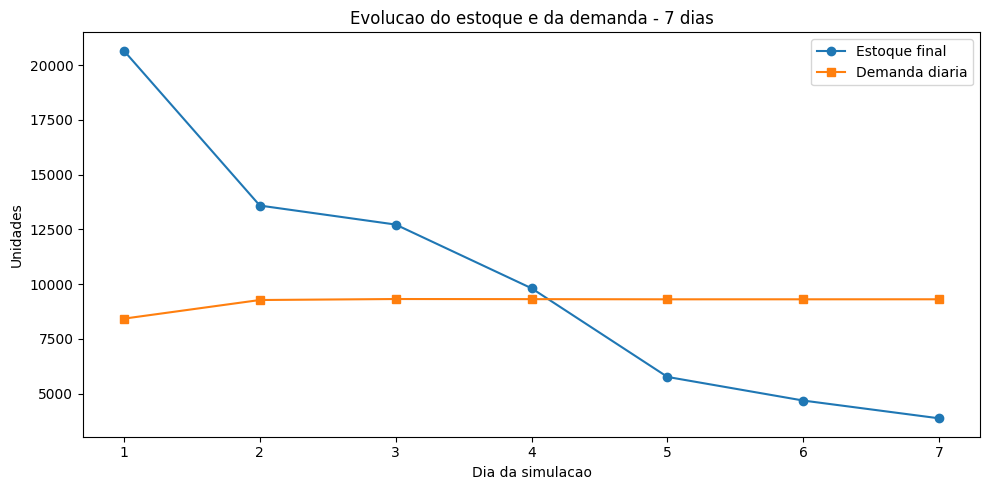


4. DIAGNOSTICO DO HORIZONTE
--------------------------------------------------
Pedidos realizados no dia 6: 0
Pedidos realizados no dia 7: 0
A interrupcao de pedidos no final do horizonte foi confirmada.

A cobertura do dia 7 exige previsoes posteriores ao horizonte disponivel.

CELULA 35 EXECUTADA COM SUCESSO!


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 35 - AUDITORIA DO FIM DO HORIZONTE")
print("=" * 65)

# 1. Carregar as movimentacoes
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO = (
    PASTA / "simulador/"
    "reposicao_dinamica_7_dias.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {ARQUIVO}"
    )

mov = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig"
)

# 2. Selecionar o cenario analisado
CENARIO = "Moderada"
PRAZO = 2

dados = mov.loc[
    (mov["cenario"] == CENARIO) &
    (mov["prazo_entrega"] == PRAZO)
].copy()

chaves = ["loja_id", "produto_id"]

# 3. Validacoes
assert len(dados) == 700

assert not dados.duplicated(
    chaves + ["dia"]
).any()

assert (
    dados.groupby(chaves)["dia"].nunique() == 7
).all()

assert not dados.isna().any().any()

assert dados[
    [
        "estoque_final",
        "pedido_realizado",
        "pedidos_pendentes_final"
    ]
].ge(0).all().all()

# 4. Resumo das movimentacoes por dia
resumo_diario = (
    dados.groupby("dia")
    .agg(
        demanda_prevista=("demanda", "sum"),
        vendas_atendidas=("atendida", "sum"),
        demanda_nao_atendida=("nao_atendida", "sum"),
        unidades_pedidas=("pedido_realizado", "sum"),
        unidades_recebidas=("recebimento", "sum"),
        estoque_final=("estoque_final", "sum"),
        pedidos_pendentes=(
            "pedidos_pendentes_final", "sum"
        )
    )
)

print("\n1. MOVIMENTACAO POR DIA")
display(resumo_diario.round(2))

# 5. Calcular cobertura ao final de cada dia
# Usa a media de demanda dos proximos
# dias que ainda existem na simulacao
previsoes = (
    dados.pivot(
        index=chaves,
        columns="dia",
        values="demanda"
    )
)

estoques = (
    dados.pivot(
        index=chaves,
        columns="dia",
        values="estoque_final"
    )
)

coberturas = []

for dia in range(1, 8):

    dias_restantes = list(
        range(dia + 1, 8)
    )

    if dias_restantes:

        media_futura = (
            previsoes[dias_restantes].mean(axis=1)
        )

        cobertura = (
            estoques[dia]
            / media_futura.replace(0, np.nan)
        )

        coberturas.append({
            "Dia": dia,
            "Cobertura mediana": cobertura.median(),
            "Series abaixo de 1 dia": (
                cobertura < 1
            ).sum()
        })

# No dia 7 nao existe previsao posterior
tabela_cobertura = pd.DataFrame(coberturas)

print("\n2. COBERTURA DOS DIAS 1 A 6")
display(tabela_cobertura.round(2))

# 6. Investigar os ultimos dias
print("\n3. PEDIDOS NO FINAL DO HORIZONTE")

ultimos = resumo_diario.loc[
    resumo_diario.index >= 5,
    [
        "unidades_pedidas",
        "unidades_recebidas",
        "estoque_final",
        "pedidos_pendentes"
    ]
]

display(ultimos.round(2))

# 7. Grafico da evolucao do estoque
plt.figure(figsize=(10, 5))

plt.plot(
    resumo_diario.index,
    resumo_diario["estoque_final"],
    marker="o",
    label="Estoque final"
)

plt.plot(
    resumo_diario.index,
    resumo_diario["demanda_prevista"],
    marker="s",
    label="Demanda diaria"
)

plt.title(
    "Evolucao do estoque e da demanda - 7 dias"
)

plt.xlabel("Dia da simulacao")
plt.ylabel("Unidades")
plt.xticks(range(1, 8))
plt.legend()
plt.tight_layout()
plt.show()

# 8. Verificar pedidos finais
print("\n4. DIAGNOSTICO DO HORIZONTE")
print("-" * 50)

pedidos_dia6 = resumo_diario.loc[
    6, "unidades_pedidas"
]

pedidos_dia7 = resumo_diario.loc[
    7, "unidades_pedidas"
]

print("Pedidos realizados no dia 6:", pedidos_dia6)
print("Pedidos realizados no dia 7:", pedidos_dia7)

if pedidos_dia6 == 0 and pedidos_dia7 == 0:
    print(
        "A interrupcao de pedidos no final "
        "do horizonte foi confirmada."
    )
else:
    print(
        "Existem pedidos nos ultimos dias. "
        "A regra precisa ser investigada."
    )

print(
    "\nA cobertura do dia 7 exige previsoes "
    "posteriores ao horizonte disponivel."
)

print("\nCELULA 35 EXECUTADA COM SUCESSO!")


#36 - Ampliação do horizonte de previsão

In [ ]:

import numpy as np
import pandas as pd
import joblib
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 36 - AMPLIACAO DA PREVISAO PARA 10 DIAS")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")

# 1. Carregar arquivos
historico_36 = pd.read_csv(
    PASTA / "dados_processados/vendas_tratadas.csv",
    parse_dates=["data"],
    encoding="utf-8-sig"
)

previsoes_7 = pd.read_csv(
    PASTA / "previsoes/previsoes_7_dias.csv",
    parse_dates=["data"],
    encoding="utf-8-sig"
)

# Carregar apenas o modelo criado anteriormente
modelo_36 = joblib.load(
    PASTA / "modelos/extra_trees_final.joblib"
)

# 2. Definir configuracao
HORIZONTE_NOVO = 10
chaves = ["loja_id", "produto_id"]

colunas_modelo = [
    "loja_id",
    "produto_id",
    "dia_semana",
    "mes",
    "dia_mes",
    "vendas_lag_1",
    "vendas_lag_7",
    "vendas_lag_14",
    "vendas_lag_30",
    "media_movel_7",
    "media_movel_14",
    "media_movel_30",
    "desvio_movel_7"
]

# 3. Validar estrutura
assert len(historico_36) == 76000
assert len(previsoes_7) == 700

assert not historico_36.duplicated(
    chaves + ["data"]
).any()

assert not previsoes_7.duplicated(
    chaves + ["data"]
).any()

assert (
    historico_36["vendas"].ge(0)
).all()

if hasattr(modelo_36, "feature_names_in_"):
    assert (
        list(modelo_36.feature_names_in_)
        == colunas_modelo
    )

# 4. Preparar series historicas
series_36 = {}

for chave, grupo in historico_36.groupby(chaves):

    grupo = grupo.sort_values("data")

    assert len(grupo) >= 30

    series_36[chave] = {
        "vendas": grupo["vendas"]
        .astype(float).tolist(),
        "categoria": grupo["categoria"].iloc[-1]
    }

assert len(series_36) == 100

# 5. Identificar inicio das previsoes
data_inicio = (
    historico_36["data"].max()
    + pd.Timedelta(days=1)
)

registros_36 = []

# 6. Gerar previsoes recursivas
for passo in range(HORIZONTE_NOVO):

    data_prevista = (
        data_inicio + pd.Timedelta(days=passo)
    )

    linhas = []
    identificadores = []

    for chave, info in series_36.items():

        loja, produto = chave

        valores = np.asarray(
            info["vendas"],
            dtype=float
        )

        linhas.append({
            "loja_id": loja,
            "produto_id": produto,
            "dia_semana": data_prevista.dayofweek,
            "mes": data_prevista.month,
            "dia_mes": data_prevista.day,
            "vendas_lag_1": valores[-1],
            "vendas_lag_7": valores[-7],
            "vendas_lag_14": valores[-14],
            "vendas_lag_30": valores[-30],
            "media_movel_7": valores[-7:].mean(),
            "media_movel_14": valores[-14:].mean(),
            "media_movel_30": valores[-30:].mean(),
            "desvio_movel_7": valores[-7:].std(ddof=1)
        })

        identificadores.append(chave)

    X_novo = pd.DataFrame(
        linhas
    )[colunas_modelo]

    assert not X_novo.isna().any().any()

    previsoes_dia = np.maximum(
        modelo_36.predict(X_novo), 0
    )

    assert np.isfinite(previsoes_dia).all()

    for chave, valor in zip(
        identificadores, previsoes_dia
    ):

        loja, produto = chave

        registros_36.append({
            "data": data_prevista,
            "loja_id": loja,
            "produto_id": produto,
            "categoria": series_36[chave]["categoria"],
            "dia_previsao": passo + 1,
            "vendas_previstas": float(valor)
        })

        series_36[chave]["vendas"].append(
            float(valor)
        )

    print(
        f"Dia {passo + 1}/10:",
        data_prevista.strftime("%d/%m/%Y"),
        "- concluido"
    )

# 7. Organizar resultados
previsoes_10 = pd.DataFrame(
    registros_36
).sort_values(
    chaves + ["data"]
).reset_index(drop=True)

assert len(previsoes_10) == 1000

assert previsoes_10["data"].nunique() == 10

assert not previsoes_10.duplicated(
    chaves + ["data"]
).any()

# 8. Verificar se os primeiros 7 dias
# reproduzem exatamente a Celula 20
primeiros_7 = previsoes_10.loc[
    previsoes_10["dia_previsao"] <= 7
]

comparacao = primeiros_7.merge(
    previsoes_7[
        chaves + ["data", "vendas_previstas"]
    ],
    on=chaves + ["data"],
    suffixes=("_novo", "_original"),
    validate="one_to_one"
)

assert len(comparacao) == 700

assert np.allclose(
    comparacao["vendas_previstas_novo"],
    comparacao["vendas_previstas_original"],
    rtol=1e-10,
    atol=1e-8
), "As previsoes originais foram alteradas."

# 9. Apresentar resumo
print("\n1. VALIDACAO")
print("Series:", len(series_36))
print("Previsoes geradas:", len(previsoes_10))
print("Primeiros 7 dias: identicos a Celula 20")

print("\n2. PREVISOES ADICIONAIS")

adicionais = previsoes_10.loc[
    previsoes_10["dia_previsao"] >= 8
]

display(adicionais.head(12).round(2))

print("\n3. TOTAL POR DIA")

total_dia = (
    previsoes_10.groupby(
        ["dia_previsao", "data"], as_index=False
    )["vendas_previstas"].sum()
)

display(total_dia.round(2))

# 10. Salvar nova previsao
SAIDA = (
    PASTA / "previsoes/previsoes_10_dias.csv"
)

previsoes_10.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

conferencia = pd.read_csv(SAIDA)

assert len(conferencia) == 1000

print("\n4. ARQUIVO SALVO")
print(SAIDA)

print("\nCELULA 36 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 36 - AMPLIACAO DA PREVISAO PARA 10 DIAS
Dia 1/10: 31/01/2024 - concluido
Dia 2/10: 01/02/2024 - concluido
Dia 3/10: 02/02/2024 - concluido
Dia 4/10: 03/02/2024 - concluido
Dia 5/10: 04/02/2024 - concluido
Dia 6/10: 05/02/2024 - concluido
Dia 7/10: 06/02/2024 - concluido
Dia 8/10: 07/02/2024 - concluido
Dia 9/10: 08/02/2024 - concluido
Dia 10/10: 09/02/2024 - concluido

1. VALIDACAO
Series: 100
Previsoes geradas: 1000
Primeiros 7 dias: identicos a Celula 20

2. PREVISOES ADICIONAIS


,data,loja_id,produto_id,categoria,dia_previsao,vendas_previstas
7,2024-02-07,S001,P0001,Eletrônicos,8,94.91
8,2024-02-08,S001,P0001,Eletrônicos,9,94.97
9,2024-02-09,S001,P0001,Eletrônicos,10,95.13
17,2024-02-07,S001,P0002,Vestuário,8,92.12
18,2024-02-08,S001,P0002,Vestuário,9,92.69
19,2024-02-09,S001,P0002,Vestuário,10,91.68
27,2024-02-07,S001,P0003,Vestuário,8,115.40
28,2024-02-08,S001,P0003,Vestuário,9,119.37
29,2024-02-09,S001,P0003,Vestuário,10,113.05
37,2024-02-07,S001,P0004,Eletrônicos,8,87.56



3. TOTAL POR DIA


,dia_previsao,data,vendas_previstas
0,1,2024-01-31,8427.74
1,2,2024-02-01,9278.41
2,3,2024-02-02,9323.59
3,4,2024-02-03,9317.90
4,5,2024-02-04,9310.00
5,6,2024-02-05,9310.60
6,7,2024-02-06,9311.54
7,8,2024-02-07,9373.73
8,9,2024-02-08,9384.95
9,10,2024-02-09,9338.80



4. ARQUIVO SALVO
/content/drive/MyDrive/Varejo/previsoes/previsoes_10_dias.csv

CELULA 36 EXECUTADA COM SUCESSO!


#37 -  Correção do planejamento contínuo

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 37 - PLANEJAMENTO CONTINUO")
print("=" * 65)

# 1. Caminhos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_CONFIG = (
    PASTA / "simulador/configuracao_inicial.csv"
)

ARQUIVO_PREV = (
    PASTA / "previsoes/previsoes_10_dias.csv"
)

ARQUIVO_ANTERIOR = (
    PASTA / "simulador/reposicao_dinamica_7_dias.csv"
)

for arquivo in [
    ARQUIVO_CONFIG,
    ARQUIVO_PREV,
    ARQUIVO_ANTERIOR
]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar arquivos
config = pd.read_csv(
    ARQUIVO_CONFIG,
    encoding="utf-8-sig"
)

prev = pd.read_csv(
    ARQUIVO_PREV,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

anterior = pd.read_csv(
    ARQUIVO_ANTERIOR,
    encoding="utf-8-sig"
)

# 3. Parametros experimentais
CENARIO = "Moderada"
MARGEM = 0.10
PRAZO = 2

DIAS_AVALIACAO = 7
HORIZONTE_PREVISAO = 10

chaves = ["loja_id", "produto_id"]

# 4. Validacoes
assert len(config) == 100
assert len(prev) == 1000

assert not config.duplicated(chaves).any()

assert not prev.duplicated(
    chaves + ["dia_previsao"]
).any()

assert not config[
    ["estoque_inicial", "pedidos_pendentes_iniciais"]
].isna().any().any()

assert (
    config["estoque_inicial"] >= 0
).all()

assert (
    config["pedidos_pendentes_iniciais"] == 0
).all()

assert prev["vendas_previstas"].notna().all()
assert prev["vendas_previstas"].ge(0).all()

assert (
    HORIZONTE_PREVISAO
    >= DIAS_AVALIACAO + PRAZO
)

# 5. Organizar previsoes por serie
mapa_previsoes = {}

for chave, grupo in prev.groupby(chaves):

    grupo = grupo.sort_values("dia_previsao")

    assert grupo["dia_previsao"].tolist() == list(
        range(1, HORIZONTE_PREVISAO + 1)
    )

    mapa_previsoes[chave] = (
        grupo["vendas_previstas"].to_numpy(
            dtype=float
        )
    )

assert len(mapa_previsoes) == 100

# 6. Executar simulacao corrigida
registros = []

for _, item in config.iterrows():

    loja = item["loja_id"]
    produto = item["produto_id"]
    chave = (loja, produto)

    demanda_futura = mapa_previsoes[chave]

    estoque = float(item["estoque_inicial"])

    # Lista de pedidos: (dia_chegada, quantidade)
    pendentes = []

    for dia in range(1, DIAS_AVALIACAO + 1):

        estoque_inicio = estoque

        # A. Recebimentos do dia
        recebimento = sum(
            quantidade
            for chegada, quantidade in pendentes
            if chegada == dia
        )

        pendentes = [
            (chegada, quantidade)
            for chegada, quantidade in pendentes
            if chegada != dia
        ]

        estoque += recebimento

        # B. Demanda no periodo de protecao
        ultimo_dia = dia + PRAZO

        demanda_protecao = float(
            demanda_futura[
                dia - 1:ultimo_dia
            ].sum()
        )

        assert ultimo_dia <= HORIZONTE_PREVISAO

        seguranca = (
            MARGEM * demanda_protecao
        )

        # C. Pedidos ja realizados que
        # chegarao ate o fim da protecao
        pendentes_protecao = sum(
            quantidade
            for chegada, quantidade in pendentes
            if chegada <= ultimo_dia
        )

        posicao_estoque = (
            estoque + pendentes_protecao
        )

        # D. Calcular novo pedido
        necessidade = (
            demanda_protecao
            + seguranca
            - posicao_estoque
        )

        pedido = int(
            np.ceil(max(necessidade, 0))
        )

        # E. Agendar recebimento
        dia_chegada = dia + PRAZO

        if pedido > 0:
            pendentes.append(
                (dia_chegada, pedido)
            )

        # F. Consumo do dia
        demanda = float(
            demanda_futura[dia - 1]
        )

        atendida = min(estoque, demanda)

        nao_atendida = max(
            demanda - atendida, 0
        )

        estoque = max(
            estoque - atendida, 0
        )

        # G. Registrar saldos
        registros.append({
            "cenario": CENARIO,
            "prazo_entrega": PRAZO,
            "loja_id": loja,
            "produto_id": produto,
            "categoria": item["categoria"],
            "dia": dia,
            "estoque_inicio": estoque_inicio,
            "recebimento": recebimento,
            "pedido_realizado": pedido,
            "dia_chegada_pedido": dia_chegada,
            "pedidos_pendentes_final": sum(
                quantidade
                for _, quantidade in pendentes
            ),
            "demanda": demanda,
            "atendida": atendida,
            "nao_atendida": nao_atendida,
            "estoque_final": estoque
        })

# 7. Criar tabela de movimentacoes
continuo = pd.DataFrame(registros)

assert len(continuo) == 700

assert not continuo.isna().any().any()

assert continuo["estoque_final"].ge(0).all()
assert continuo["pedido_realizado"].ge(0).all()

# 8. Validar conservacao de unidades
assert np.allclose(
    continuo["estoque_inicio"]
    + continuo["recebimento"]
    - continuo["atendida"],
    continuo["estoque_final"]
)

assert np.allclose(
    continuo["atendida"]
    + continuo["nao_atendida"],
    continuo["demanda"]
)

# 9. Validar continuidade do estoque
ordenado = continuo.sort_values(
    chaves + ["dia"]
).copy()

ordenado["saldo_anterior"] = (
    ordenado.groupby(chaves)["estoque_final"]
    .shift(1)
)

transicoes = ordenado.loc[
    ordenado["dia"] > 1
]

assert np.allclose(
    transicoes["estoque_inicio"],
    transicoes["saldo_anterior"]
)

# 10. Comparar resultados com a Celula 32
anterior_moderado = anterior.loc[
    (anterior["cenario"] == CENARIO)
    & (anterior["prazo_entrega"] == PRAZO)
].copy()

comparacao = continuo.merge(
    anterior_moderado[
        chaves + [
            "dia",
            "estoque_final",
            "nao_atendida",
            "pedido_realizado"
        ]
    ],
    on=chaves + ["dia"],
    suffixes=("_novo", "_anterior"),
    validate="one_to_one"
)

assert len(comparacao) == 700

# Como as novas compras dos dias 6 e 7
# chegam depois da avaliacao, o estoque
# e as rupturas devem permanecer iguais
assert np.allclose(
    comparacao["estoque_final_novo"],
    comparacao["estoque_final_anterior"]
)

assert np.allclose(
    comparacao["nao_atendida_novo"],
    comparacao["nao_atendida_anterior"]
)

# Os pedidos dos dias 1 a 5 devem
# permanecer iguais
primeiros5 = comparacao.loc[
    comparacao["dia"] <= 5
]

assert np.array_equal(
    primeiros5["pedido_realizado_novo"],
    primeiros5["pedido_realizado_anterior"]
)

# 11. Resumo diario
resumo_diario = (
    continuo.groupby("dia")
    .agg(
        demanda_prevista=("demanda", "sum"),
        unidades_pedidas=("pedido_realizado", "sum"),
        unidades_recebidas=("recebimento", "sum"),
        demanda_nao_atendida=("nao_atendida", "sum"),
        estoque_final=("estoque_final", "sum"),
        pedidos_pendentes=(
            "pedidos_pendentes_final", "sum"
        )
    )
)

print("\n1. MOVIMENTACAO DIARIA CORRIGIDA")
display(resumo_diario.round(2))

# 12. Examinar pedidos dos ultimos dias
print("\n2. PEDIDOS NOS DIAS 6 E 7")

pedidos_finais = resumo_diario.loc[
    [6, 7],
    [
        "unidades_pedidas",
        "unidades_recebidas",
        "pedidos_pendentes"
    ]
]

display(pedidos_finais.round(2))

# 13. Auditoria global dos pedidos
pedidos = continuo["pedido_realizado"].sum()
recebidos = continuo["recebimento"].sum()

pendentes_finais = (
    continuo.loc[continuo["dia"] == 7,
    "pedidos_pendentes_final"].sum()
)

assert np.isclose(
    pedidos - recebidos,
    pendentes_finais
)

print("\n3. CONFERENCIA DOS PEDIDOS")
print("Unidades pedidas:", int(pedidos))
print("Unidades recebidas:", int(recebidos))
print("Unidades pendentes ao final:", int(pendentes_finais))

# 14. Comparar a demanda nao atendida
print("\n4. COMPARACAO COM CELULA 32")

print(
    "Demanda nao atendida anterior:",
    round(
        anterior_moderado["nao_atendida"].sum(), 2
    )
)

print(
    "Demanda nao atendida atual:",
    round(continuo["nao_atendida"].sum(), 2)
)

print(
    "Estoque final preservado:",
    round(
        continuo.loc[
            continuo["dia"] == 7,
            "estoque_final"
        ].sum(), 2
    )
)

print("\n5. VALIDACAO FINAL")
print("Movimentacoes:", len(continuo))
print("Conservacao de estoque: APROVADA")
print("Continuidade do estoque: APROVADA")
print("Controle de pedidos: APROVADO")
print("Comparacao historica: APROVADA")

# 15. Salvar arquivos sem sobrescrever anteriores
PASTA_SAIDA = PASTA / "simulador"

SAIDA_MOV = (
    PASTA_SAIDA / "reposicao_continua_7_dias.csv"
)

SAIDA_RESUMO = (
    PASTA_SAIDA / "resumo_reposicao_continua.csv"
)

continuo.to_csv(
    SAIDA_MOV,
    index=False,
    encoding="utf-8-sig"
)

resumo_diario.to_csv(
    SAIDA_RESUMO,
    encoding="utf-8-sig"
)

assert SAIDA_MOV.is_file()
assert SAIDA_RESUMO.is_file()

print("\nARQUIVOS SALVOS:")
print(SAIDA_MOV)
print(SAIDA_RESUMO)

print("\nCELULA 37 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 37 - PLANEJAMENTO CONTINUO

1. MOVIMENTACAO DIARIA CORRIGIDA


,demanda_prevista,unidades_pedidas,unidades_recebidas,demanda_nao_atendida,estoque_final,pedidos_pendentes
dia,,,,,,
1,8427.74,8456,0,36.51,20657.77,8456
2,9278.41,6409,0,2210.56,13589.93,14865
3,9323.59,5264,8456,0.00,12722.33,11673
4,9317.90,8232,6409,0.00,9813.43,13496
5,9310.00,8500,5264,0.00,5767.43,16732
6,9310.60,8843,8232,0.00,4688.82,17343
7,9311.54,9120,8500,0.00,3877.28,17963



2. PEDIDOS NOS DIAS 6 E 7


,unidades_pedidas,unidades_recebidas,pedidos_pendentes
dia,,,
6,8843,8232,17343
7,9120,8500,17963



3. CONFERENCIA DOS PEDIDOS
Unidades pedidas: 54824
Unidades recebidas: 36861
Unidades pendentes ao final: 17963

4. COMPARACAO COM CELULA 32
Demanda nao atendida anterior: 2247.07
Demanda nao atendida atual: 2247.07
Estoque final preservado: 3877.28

5. VALIDACAO FINAL
Movimentacoes: 700
Conservacao de estoque: APROVADA
Continuidade do estoque: APROVADA
Controle de pedidos: APROVADO
Comparacao historica: APROVADA

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/simulador/reposicao_continua_7_dias.csv
/content/drive/MyDrive/Varejo/simulador/resumo_reposicao_continua.csv

CELULA 37 EXECUTADA COM SUCESSO!


#38 - Preparação dos dados econômicos

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 38 - AUDITORIA DOS PRECOS DE VENDA")
print("=" * 65)

# 1. Localizar os arquivos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_BASE = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

ARQUIVO_CONFIG = (
    PASTA / "simulador/configuracao_inicial.csv"
)

for arquivo in [ARQUIVO_BASE, ARQUIVO_CONFIG]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar dados
base_precos = pd.read_csv(
    ARQUIVO_BASE,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

config_precos = pd.read_csv(
    ARQUIVO_CONFIG,
    encoding="utf-8-sig"
)

chaves = ["loja_id", "produto_id"]

# 3. Validar estrutura
obrigatorias = chaves + [
    "data", "categoria", "preco",
    "desconto", "vendas"
]

faltantes = [
    coluna for coluna in obrigatorias
    if coluna not in base_precos.columns
]

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {faltantes}"
    )

assert len(base_precos) == 76000
assert len(config_precos) == 100

assert not base_precos.duplicated(
    chaves + ["data"]
).any()

assert not config_precos.duplicated(chaves).any()

assert not base_precos[obrigatorias].isna().any().any()

assert np.isfinite(
    base_precos[["preco", "desconto", "vendas"]]
    .to_numpy(dtype=float)
).all()

assert (base_precos["preco"] > 0).all()
assert base_precos["vendas"].ge(0).all()

# 4. Verificar descontos
print("\n1. AUDITORIA GERAL DOS PRECOS")
print("-" * 50)

print("Registros:", len(base_precos))
print("Menor preco:", base_precos["preco"].min())
print("Maior preco:", base_precos["preco"].max())
print("Preco medio:", round(
    base_precos["preco"].mean(), 2
))

print("Menor desconto:", base_precos["desconto"].min())
print("Maior desconto:", base_precos["desconto"].max())

descontos_invalidos = (
    ~base_precos["desconto"].between(0, 100)
).sum()

print("Descontos fora de 0 a 100:",
      descontos_invalidos)

# 5. Preparar resumo por loja e produto
ordenado = base_precos.sort_values(
    chaves + ["data"]
)

resumo_precos = (
    ordenado.groupby(chaves)
    .agg(
        categoria=("categoria", "last"),
        registros=("preco", "size"),
        preco_minimo=("preco", "min"),
        preco_medio=("preco", "mean"),
        preco_maximo=("preco", "max"),
        preco_ultimo=("preco", "last"),
        desvio_preco=("preco", "std"),
        desconto_medio=("desconto", "mean"),
        data_ultimo_preco=("data", "last")
    )
    .reset_index()
)

# 6. Verificar categoria consistente
categorias = (
    ordenado.groupby(chaves)["categoria"]
    .nunique()
)

assert (categorias == 1).all()
assert len(resumo_precos) == 100

# 7. Conferir ultima data
ultima_data = base_precos["data"].max()

assert (
    resumo_precos["data_ultimo_preco"]
    == ultima_data
).all()

# 8. Conferir compatibilidade com simulador
referencias = config_precos[
    chaves + ["categoria"]
]

conferencia_categorias = resumo_precos.merge(
    referencias,
    on=chaves,
    suffixes=("_base", "_simulador"),
    validate="one_to_one"
)

assert len(conferencia_categorias) == 100

assert (
    conferencia_categorias["categoria_base"]
    == conferencia_categorias["categoria_simulador"]
).all()

# 9. Verificar variacao de precos
resumo_precos["amplitude_preco"] = (
    resumo_precos["preco_maximo"]
    - resumo_precos["preco_minimo"]
)

resumo_precos["variacao_relativa_percentual"] = (
    resumo_precos["amplitude_preco"]
    / resumo_precos["preco_medio"] * 100
)

# 10. Exibir resultados
print("\n2. PRECOS POR LOJA E PRODUTO")
display(resumo_precos.head(10).round(2))

print("\n3. MAIORES VARIACOES DE PRECO")

display(
    resumo_precos.sort_values(
        "variacao_relativa_percentual",
        ascending=False
    ).head(10).round(2)
)

# 11. Resumo por categoria
print("\n4. PRECOS POR CATEGORIA")

resumo_categoria_precos = (
    resumo_precos.groupby("categoria")
    .agg(
        series=("produto_id", "size"),
        preco_medio_atual=("preco_ultimo", "mean"),
        menor_preco_atual=("preco_ultimo", "min"),
        maior_preco_atual=("preco_ultimo", "max")
    )
)

display(resumo_categoria_precos.round(2))

# 12. Criar tabela economica inicial
# Ainda nao existe custo de aquisicao comprovado
tabela_economica = resumo_precos[
    chaves + [
        "categoria",
        "data_ultimo_preco",
        "preco_ultimo",
        "preco_medio"
    ]
].copy()

tabela_economica = tabela_economica.rename(
    columns={
        "preco_ultimo": "preco_venda_referencia",
        "preco_medio": "preco_venda_medio_historico"
    }
)

tabela_economica["origem_preco"] = (
    "Base historica de vendas"
)

# 13. Salvar tabela de referencia
PASTA_ECONOMIA = PASTA / "economia"

PASTA_ECONOMIA.mkdir(
    parents=True,
    exist_ok=True
)

SAIDA = (
    PASTA_ECONOMIA / "referencia_precos.csv"
)

tabela_economica.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d"
)

# 14. Validar arquivo salvo
verificacao = pd.read_csv(
    SAIDA,
    encoding="utf-8-sig"
)

assert len(verificacao) == 100
assert not verificacao.duplicated(chaves).any()

assert (
    verificacao["preco_venda_referencia"] > 0
).all()

print("\n5. VALIDACAO FINAL")
print("Series avaliadas:", len(verificacao))
print("Categorias consistentes: SIM")
print("Preco de venda identificado: SIM")
print("Custos ainda nao estimados: SIM")
print("Arquivo salvo:", SAIDA)

print("\nCELULA 38 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 38 - AUDITORIA DOS PRECOS DE VENDA

1. AUDITORIA GERAL DOS PRECOS
--------------------------------------------------
Registros: 76000
Menor preco: 4.74
Maior preco: 228.03
Preco medio: 67.73
Menor desconto: 0
Maior desconto: 25
Descontos fora de 0 a 100: 0

2. PRECOS POR LOJA E PRODUTO


,loja_id,produto_id,categoria,registros,preco_minimo,preco_medio,preco_maximo,preco_ultimo,desvio_preco,desconto_medio,data_ultimo_preco,amplitude_preco,variacao_relativa_percentual
0,S001,P0001,Eletrônicos,760,43.36,66.38,90.74,71.56,8.83,9.01,2024-01-30,47.38,71.38
1,S001,P0002,Vestuário,760,37.73,67.10,99.74,70.55,9.89,8.69,2024-01-30,62.01,92.41
2,S001,P0003,Vestuário,760,35.11,56.00,81.12,59.46,7.62,8.97,2024-01-30,46.01,82.17
3,S001,P0004,Eletrônicos,760,64.91,100.21,142.17,93.82,13.99,8.81,2024-01-30,77.26,77.10
4,S001,P0005,Alimentos,760,36.98,59.28,90.20,45.82,8.85,9.03,2024-01-30,53.22,89.78
5,S001,P0006,Brinquedos,760,22.47,37.80,57.41,37.13,6.04,9.13,2024-01-30,34.94,92.42
6,S001,P0007,Alimentos,760,14.92,24.79,37.09,24.57,3.77,9.24,2024-01-30,22.17,89.44
7,S001,P0008,Eletrônicos,760,24.47,41.73,64.22,34.68,5.72,8.86,2024-01-30,39.75,95.26
8,S001,P0009,Vestuário,760,49.07,90.35,167.34,90.35,12.80,9.03,2024-01-30,118.27,130.90
9,S001,P0010,Móveis,760,80.83,118.75,177.46,125.82,15.17,8.99,2024-01-30,96.63,81.37



3. MAIORES VARIACOES DE PRECO


,loja_id,produto_id,categoria,registros,preco_minimo,preco_medio,preco_maximo,preco_ultimo,desvio_preco,desconto_medio,data_ultimo_preco,amplitude_preco,variacao_relativa_percentual
45,S003,P0006,Brinquedos,760,21.19,36.29,70.18,48.42,6.05,9.18,2024-01-30,48.99,134.98
8,S001,P0009,Vestuário,760,49.07,90.35,167.34,90.35,12.80,9.03,2024-01-30,118.27,130.90
85,S005,P0006,Alimentos,760,37.51,59.86,107.68,72.40,8.93,9.19,2024-01-30,70.17,117.22
87,S005,P0008,Alimentos,760,37.64,63.10,110.86,59.36,9.95,9.24,2024-01-30,73.22,116.04
15,S001,P0016,Alimentos,760,20.13,39.04,64.09,35.90,5.99,8.91,2024-01-30,43.96,112.61
84,S005,P0005,Alimentos,760,9.94,16.24,28.21,17.12,2.53,9.26,2024-01-30,18.27,112.47
65,S004,P0006,Alimentos,760,19.93,36.64,61.05,36.62,5.68,9.02,2024-01-30,41.12,112.23
96,S005,P0017,Brinquedos,760,20.50,34.62,58.05,42.92,5.76,9.09,2024-01-30,37.55,108.46
52,S003,P0013,Alimentos,760,44.48,73.06,123.56,74.45,11.26,9.26,2024-01-30,79.08,108.24
54,S003,P0015,Alimentos,760,58.75,97.69,163.99,104.09,15.15,8.81,2024-01-30,105.24,107.73



4. PRECOS POR CATEGORIA


,series,preco_medio_atual,menor_preco_atual,maior_preco_atual
categoria,,,,
Alimentos,40,51.73,7.73,119.68
Brinquedos,14,28.58,13.26,48.42
Eletrônicos,12,91.12,34.68,147.24
Móveis,18,126.01,80.54,182.88
Vestuário,16,73.97,17.81,120.79



5. VALIDACAO FINAL
Series avaliadas: 100
Categorias consistentes: SIM
Preco de venda identificado: SIM
Custos ainda nao estimados: SIM
Arquivo salvo: /content/drive/MyDrive/Varejo/economia/referencia_precos.csv

CELULA 38 EXECUTADA COM SUCESSO!


#39 - Definição dos parâmetros econômicos

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 39 - PARAMETROS ECONOMICOS")
print("=" * 65)

# 1. Definir caminhos
PASTA = Path("/content/drive/MyDrive/Varejo")
PASTA_ECONOMIA = PASTA / "economia"

ARQUIVO_PRECOS = (
    PASTA_ECONOMIA / "referencia_precos.csv"
)

if not ARQUIVO_PRECOS.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {ARQUIVO_PRECOS}"
    )

# 2. Carregar precos de referencia
precos = pd.read_csv(
    ARQUIVO_PRECOS,
    encoding="utf-8-sig"
)

chaves = ["loja_id", "produto_id"]

assert len(precos) == 100
assert not precos.duplicated(chaves).any()

# 3. Definir hipoteses economicas
# Valores experimentais, nao observados
hipoteses = pd.DataFrame({
    "categoria": [
        "Alimentos",
        "Brinquedos",
        "Eletrônicos",
        "Móveis",
        "Vestuário"
    ],
    "percentual_aquisicao": [
        0.65, 0.60, 0.75, 0.70, 0.55
    ],
    "taxa_armazenamento_dia": [
        0.0030, 0.0015, 0.0010,
        0.0020, 0.0020
    ]
})

hipoteses["origem_parametros"] = (
    "Hipotese experimental"
)

# 4. Validar hipoteses
assert not hipoteses["categoria"].duplicated().any()

assert hipoteses[
    "percentual_aquisicao"
].between(0, 1).all()

assert hipoteses[
    "taxa_armazenamento_dia"
].ge(0).all()

# 5. Integrar precos e parametros
economia = precos.merge(
    hipoteses,
    on="categoria",
    how="left",
    validate="many_to_one"
)

assert len(economia) == 100

colunas_custo = [
    "preco_venda_referencia",
    "percentual_aquisicao",
    "taxa_armazenamento_dia"
]

assert not economia[colunas_custo].isna().any().any()

assert np.isfinite(
    economia[colunas_custo].to_numpy(dtype=float)
).all()

assert (
    economia["preco_venda_referencia"] > 0
).all()

# 6. Calcular custo estimado de aquisicao
economia["custo_aquisicao_unitario"] = (
    economia["preco_venda_referencia"]
    * economia["percentual_aquisicao"]
)

# 7. Calcular custo diario de armazenamento
economia["custo_armazenamento_unitario_dia"] = (
    economia["custo_aquisicao_unitario"]
    * economia["taxa_armazenamento_dia"]
)

# 8. Calcular margem de contribuicao
# simplificada (sem outros custos variaveis)
economia["margem_contribuicao_unitaria"] = (
    economia["preco_venda_referencia"]
    - economia["custo_aquisicao_unitario"]
)

# 9. Registrar natureza dos valores
economia["natureza_custos"] = (
    "Custos simulados"
)

economia["unidade_monetaria"] = (
    "UM - unidade monetaria hipotetica"
)

# 10. Validar resultados
colunas_calculadas = [
    "custo_aquisicao_unitario",
    "custo_armazenamento_unitario_dia",
    "margem_contribuicao_unitaria"
]

assert economia[colunas_calculadas].ge(0).all().all()

assert np.allclose(
    economia["custo_aquisicao_unitario"]
    + economia["margem_contribuicao_unitaria"],
    economia["preco_venda_referencia"]
)

# 11. Resumo geral
print("\n1. PARAMETROS POR CATEGORIA")
display(hipoteses)

print("\n2. BASE ECONOMICA POR PRODUTO")

colunas_resultado = chaves + [
    "categoria",
    "preco_venda_referencia",
    "custo_aquisicao_unitario",
    "custo_armazenamento_unitario_dia",
    "margem_contribuicao_unitaria"
]

display(
    economia[colunas_resultado]
    .head(15)
    .round(4)
)

# 12. Estatisticas por categoria
resumo_economico = (
    economia.groupby("categoria")
    .agg(
        series=("produto_id", "size"),
        preco_medio=("preco_venda_referencia", "mean"),
        aquisicao_media=(
            "custo_aquisicao_unitario", "mean"
        ),
        armazenamento_medio_dia=(
            "custo_armazenamento_unitario_dia", "mean"
        ),
        margem_media=(
            "margem_contribuicao_unitaria", "mean"
        )
    )
)

print("\n3. RESUMO ECONOMICO POR CATEGORIA")
display(resumo_economico.round(4))

# 13. Salvar hipoteses separadamente
ARQUIVO_HIPOTESES = (
    PASTA_ECONOMIA / "hipoteses_custos.csv"
)

ARQUIVO_ECONOMIA = (
    PASTA_ECONOMIA / "parametros_economicos.csv"
)

hipoteses.to_csv(
    ARQUIVO_HIPOTESES,
    index=False,
    encoding="utf-8-sig"
)

economia.to_csv(
    ARQUIVO_ECONOMIA,
    index=False,
    encoding="utf-8-sig"
)

# 14. Conferir os arquivos
hipoteses_salvas = pd.read_csv(
    ARQUIVO_HIPOTESES,
    encoding="utf-8-sig"
)

economia_salva = pd.read_csv(
    ARQUIVO_ECONOMIA,
    encoding="utf-8-sig"
)

assert len(hipoteses_salvas) == 5
assert len(economia_salva) == 100

assert not economia_salva.duplicated(chaves).any()

assert np.allclose(
    economia_salva["custo_aquisicao_unitario"],
    economia["custo_aquisicao_unitario"]
)

print("\n4. VALIDACAO FINAL")
print("Categorias parametrizadas:", len(hipoteses))
print("Series comerciais:", len(economia))
print("Precos reais da base preservados: SIM")
print("Custos identificados como simulados: SIM")
print("Integridade matematica: APROVADA")

print("\nARQUIVOS SALVOS:")
print(ARQUIVO_HIPOTESES)
print(ARQUIVO_ECONOMIA)

print("\nCELULA 39 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 39 - PARAMETROS ECONOMICOS

1. PARAMETROS POR CATEGORIA


,categoria,percentual_aquisicao,taxa_armazenamento_dia,origem_parametros
0,Alimentos,0.65,0.0030,Hipotese experimental
1,Brinquedos,0.60,0.0015,Hipotese experimental
2,Eletrônicos,0.75,0.0010,Hipotese experimental
3,Móveis,0.70,0.0020,Hipotese experimental
4,Vestuário,0.55,0.0020,Hipotese experimental



2. BASE ECONOMICA POR PRODUTO


,loja_id,produto_id,categoria,preco_venda_referencia,custo_aquisicao_unitario,custo_armazenamento_unitario_dia,margem_contribuicao_unitaria
0,S001,P0001,Eletrônicos,71.56,53.6700,0.0537,17.8900
1,S001,P0002,Vestuário,70.55,38.8025,0.0776,31.7475
2,S001,P0003,Vestuário,59.46,32.7030,0.0654,26.7570
3,S001,P0004,Eletrônicos,93.82,70.3650,0.0704,23.4550
4,S001,P0005,Alimentos,45.82,29.7830,0.0893,16.0370
5,S001,P0006,Brinquedos,37.13,22.2780,0.0334,14.8520
6,S001,P0007,Alimentos,24.57,15.9705,0.0479,8.5995
7,S001,P0008,Eletrônicos,34.68,26.0100,0.0260,8.6700
8,S001,P0009,Vestuário,90.35,49.6925,0.0994,40.6575
9,S001,P0010,Móveis,125.82,88.0740,0.1761,37.7460



3. RESUMO ECONOMICO POR CATEGORIA


,series,preco_medio,aquisicao_media,armazenamento_medio_dia,margem_media
categoria,,,,,
Alimentos,40,51.7310,33.6252,0.1009,18.1058
Brinquedos,14,28.5764,17.1459,0.0257,11.4306
Eletrônicos,12,91.1175,68.3381,0.0683,22.7794
Móveis,18,126.0128,88.2089,0.1764,37.8038
Vestuário,16,73.9700,40.6835,0.0814,33.2865



4. VALIDACAO FINAL
Categorias parametrizadas: 5
Series comerciais: 100
Precos reais da base preservados: SIM
Custos identificados como simulados: SIM
Integridade matematica: APROVADA

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/economia/hipoteses_custos.csv
/content/drive/MyDrive/Varejo/economia/parametros_economicos.csv

CELULA 39 EXECUTADA COM SUCESSO!


#40 - Avaliação econômica das políticas de reposição

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 40 - AVALIACAO ECONOMICA DAS POLITICAS")
print("=" * 65)

# 1. Localizar arquivos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVOS = {
    "economia": (
        PASTA / "economia/parametros_economicos.csv"
    ),
    "compra_unica": (
        PASTA / "simulador/movimentacoes_7_dias.csv"
    ),
    "reposicao_dinamica": (
        PASTA / "simulador/reposicao_dinamica_7_dias.csv"
    ),
    "reposicao_continua": (
        PASTA / "simulador/reposicao_continua_7_dias.csv"
    ),
    "configuracao": (
        PASTA / "simulador/configuracao_inicial.csv"
    )
}

for nome, caminho in ARQUIVOS.items():
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo ausente ({nome}): {caminho}"
        )

# 2. Carregar dados
economia = pd.read_csv(
    ARQUIVOS["economia"],
    encoding="utf-8-sig"
)

unica = pd.read_csv(
    ARQUIVOS["compra_unica"],
    encoding="utf-8-sig"
)

continua = pd.read_csv(
    ARQUIVOS["reposicao_continua"],
    encoding="utf-8-sig"
)

config = pd.read_csv(
    ARQUIVOS["configuracao"],
    encoding="utf-8-sig"
)

# 3. Parametros comparativos
CENARIO = "Moderada"
PRAZO = 2

chaves = ["loja_id", "produto_id"]

# 4. Selecionar os cenarios equivalentes
unica = unica.loc[
    (unica["cenario"] == CENARIO) &
    (unica["prazo_entrega"] == PRAZO)
].copy()

continua = continua.loc[
    (continua["cenario"] == CENARIO) &
    (continua["prazo_entrega"] == PRAZO)
].copy()

assert len(unica) == 700
assert len(continua) == 700
assert len(economia) == 100

assert not economia.duplicated(chaves).any()

# 5. Preparar a compra unica
# Pedido original registrado no arquivo
# de cenarios da Celula 28
arquivo_cenarios = (
    PASTA / "simulador/cenarios_seguranca.csv"
)

cenarios_originais = pd.read_csv(
    arquivo_cenarios,
    encoding="utf-8-sig"
)

pedidos_iniciais = cenarios_originais.loc[
    cenarios_originais["cenario"] == CENARIO,
    chaves + ["quantidade_recomendada"]
].copy()

assert len(pedidos_iniciais) == 100

unica = unica.merge(
    pedidos_iniciais,
    on=chaves,
    validate="many_to_one"
)

# Compra unica: pedido feito no dia 1
unica["pedido_realizado"] = np.where(
    unica["dia"] == 1,
    unica["quantidade_recomendada"],
    0
)

unica["politica"] = "Compra unica"

continua["politica"] = "Reposicao dinamica"

# 6. Unir movimentacoes
colunas = chaves + [
    "dia",
    "politica",
    "demanda",
    "atendida",
    "nao_atendida",
    "pedido_realizado",
    "recebimento",
    "estoque_final"
]

mov_economico = pd.concat(
    [
        unica[colunas],
        continua[colunas]
    ],
    ignore_index=True
)

assert len(mov_economico) == 1400

assert not mov_economico.duplicated(
    ["politica"] + chaves + ["dia"]
).any()

# 7. Integrar custos por loja e produto
custos = economia[
    chaves + [
        "categoria",
        "preco_venda_referencia",
        "custo_aquisicao_unitario",
        "custo_armazenamento_unitario_dia",
        "margem_contribuicao_unitaria"
    ]
].copy()

mov_economico = mov_economico.merge(
    custos,
    on=chaves,
    how="left",
    validate="many_to_one"
)

assert len(mov_economico) == 1400
assert not mov_economico.isna().any().any()

# 8. Validar quantidades
quantidades = [
    "demanda",
    "atendida",
    "nao_atendida",
    "pedido_realizado",
    "recebimento",
    "estoque_final"
]

assert mov_economico[quantidades].ge(-1e-9).all().all()

assert np.allclose(
    mov_economico["demanda"],
    mov_economico["atendida"]
    + mov_economico["nao_atendida"]
)

# 9. Calcular indicadores monetarios

# Valor das encomendas realizadas
mov_economico["valor_compras"] = (
    mov_economico["pedido_realizado"]
    * mov_economico["custo_aquisicao_unitario"]
)

# Valor das mercadorias recebidas
mov_economico["valor_recebimentos"] = (
    mov_economico["recebimento"]
    * mov_economico["custo_aquisicao_unitario"]
)

# Aproximacao do custo diario de armazenamento:
# usa estoque ao final de cada dia
mov_economico["custo_armazenamento"] = (
    mov_economico["estoque_final"]
    * mov_economico[
        "custo_armazenamento_unitario_dia"
    ]
)

# Margem potencial associada a demanda
# simulada que nao foi atendida
mov_economico["contribuicao_nao_realizada"] = (
    mov_economico["nao_atendida"]
    * mov_economico["margem_contribuicao_unitaria"]
)

# Valor contábil hipotetico do estoque final
mov_economico["valor_estoque_final"] = (
    mov_economico["estoque_final"]
    * mov_economico["custo_aquisicao_unitario"]
)

# 10. Consolidar por politica
resumo_economico = (
    mov_economico.groupby("politica")
    .agg(
        unidades_pedidas=("pedido_realizado", "sum"),
        unidades_recebidas=("recebimento", "sum"),
        demanda_atendida=("atendida", "sum"),
        demanda_nao_atendida=("nao_atendida", "sum"),
        valor_compras=("valor_compras", "sum"),
        valor_recebimentos=(
            "valor_recebimentos", "sum"
        ),
        custo_armazenamento=(
            "custo_armazenamento", "sum"
        ),
        contribuicao_nao_realizada=(
            "contribuicao_nao_realizada", "sum"
        )
    )
    .reset_index()
)

# 11. Obter valor do estoque apenas no dia 7
estoque_final = (
    mov_economico.loc[
        mov_economico["dia"] == 7
    ]
    .groupby("politica")
    ["valor_estoque_final"]
    .sum()
    .reset_index(
        name="valor_estoque_final_dia7"
    )
)

resumo_economico = resumo_economico.merge(
    estoque_final,
    on="politica",
    validate="one_to_one"
)

# Indicador parcial, nao custo economico total
resumo_economico["custo_operacional_parcial"] = (
    resumo_economico["custo_armazenamento"]
    + resumo_economico["contribuicao_nao_realizada"]
)

# 12. Conferir reproducao da simulacao
demanda_unica = unica["nao_atendida"].sum()
demanda_dinamica = continua["nao_atendida"].sum()

assert np.isclose(
    demanda_unica, 27970.76, atol=0.02
)

assert np.isclose(
    demanda_dinamica, 2247.07, atol=0.02
)

# 13. Resumo principal
print("\n1. COMPARACAO ECONOMICA DAS POLITICAS")
display(resumo_economico.round(2))

# 14. Analisar custos por categoria
por_categoria = (
    mov_economico.groupby(
        ["politica", "categoria"]
    )
    .agg(
        compras=("valor_compras", "sum"),
        armazenamento=(
            "custo_armazenamento", "sum"
        ),
        contribuicao_nao_realizada=(
            "contribuicao_nao_realizada", "sum"
        ),
        demanda_nao_atendida=(
            "nao_atendida", "sum"
        )
    )
    .reset_index()
)

print("\n2. INDICADORES POR CATEGORIA")
display(por_categoria.round(2))

# 15. Conferir a diferenca de compras
compra_unica = resumo_economico.loc[
    resumo_economico["politica"] == "Compra unica"
].iloc[0]

dinamica = resumo_economico.loc[
    resumo_economico["politica"] == "Reposicao dinamica"
].iloc[0]

print("\n3. DIFERENCAS ENTRE POLITICAS")
print("-" * 50)

print(
    "Unidades adicionais encomendadas:",
    int(
        dinamica["unidades_pedidas"]
        - compra_unica["unidades_pedidas"]
    )
)

print(
    "Reducao da demanda nao atendida:",
    round(
        compra_unica["demanda_nao_atendida"]
        - dinamica["demanda_nao_atendida"],
        2
    )
)

print(
    "Diferenca do custo de armazenamento:",
    round(
        dinamica["custo_armazenamento"]
        - compra_unica["custo_armazenamento"],
        2
    )
)

# 16. Salvar resultados
PASTA_SAIDA = PASTA / "economia"

SAIDA_DETALHE = (
    PASTA_SAIDA / "movimentacoes_economicas.csv"
)

SAIDA_RESUMO = (
    PASTA_SAIDA / "comparacao_economica.csv"
)

SAIDA_CATEGORIA = (
    PASTA_SAIDA / "economia_por_categoria.csv"
)

mov_economico.to_csv(
    SAIDA_DETALHE,
    index=False,
    encoding="utf-8-sig"
)

resumo_economico.to_csv(
    SAIDA_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

por_categoria.to_csv(
    SAIDA_CATEGORIA,
    index=False,
    encoding="utf-8-sig"
)

# 17. Validacao final
assert SAIDA_DETALHE.is_file()
assert SAIDA_RESUMO.is_file()
assert SAIDA_CATEGORIA.is_file()

print("\n4. VALIDACAO FINAL")
print("Movimentacoes:", len(mov_economico))
print("Politicas comparadas:", len(resumo_economico))
print("Parametros financeiros identificados: SIM")
print("Conservacao da demanda: APROVADA")
print("Arquivos salvos: SIM")

print("\nCELULA 40 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 40 - AVALIACAO ECONOMICA DAS POLITICAS

1. COMPARACAO ECONOMICA DAS POLITICAS


,politica,unidades_pedidas,unidades_recebidas,demanda_atendida,demanda_nao_atendida,valor_compras,valor_recebimentos,custo_armazenamento,contribuicao_nao_realizada,valor_estoque_final_dia7,custo_operacional_parcial
0,Compra unica,8492,8492,36309.03,27970.76,361831.81,361831.81,5966.67,639778.94,53066.85,645745.61
1,Reposicao dinamica,54824,36861,62032.72,2247.07,2403445.78,1604134.94,7031.88,51877.39,169902.66,58909.27



2. INDICADORES POR CATEGORIA


,politica,categoria,compras,armazenamento,contribuicao_nao_realizada,demanda_nao_atendida
0,Compra unica,Alimentos,108744.94,2915.08,207136.41,12054.41
1,Compra unica,Brinquedos,20801.18,188.47,43836.25,3804.00
2,Compra unica,Eletrônicos,61883.26,509.09,72434.57,3262.76
3,Compra unica,Móveis,93825.98,1611.84,147575.73,3905.27
4,Compra unica,Vestuário,76576.45,742.19,168795.98,4944.33
5,Reposicao dinamica,Alimentos,758723.55,3402.78,17856.99,1009.27
6,Reposicao dinamica,Brinquedos,129303.64,227.54,3025.55,265.67
7,Reposicao dinamica,Eletrônicos,430671.44,595.30,4437.34,178.40
8,Reposicao dinamica,Móveis,681733.28,1887.92,8504.75,234.74
9,Reposicao dinamica,Vestuário,403013.86,918.34,18052.75,558.99



3. DIFERENCAS ENTRE POLITICAS
--------------------------------------------------
Unidades adicionais encomendadas: 46332
Reducao da demanda nao atendida: 25723.69
Diferenca do custo de armazenamento: 1065.21

4. VALIDACAO FINAL
Movimentacoes: 1400
Politicas comparadas: 2
Parametros financeiros identificados: SIM
Conservacao da demanda: APROVADA
Arquivos salvos: SIM

CELULA 40 EXECUTADA COM SUCESSO!


#41 - Auditoria do capital e dos custos de estoque

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 41 - AUDITORIA ECONOMICA DO CAPITAL")
print("=" * 65)

# 1. Caminhos dos arquivos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_MOV = (
    PASTA / "economia/movimentacoes_economicas.csv"
)

ARQUIVO_CONTINUO = (
    PASTA / "simulador/reposicao_continua_7_dias.csv"
)

ARQUIVO_CUSTOS = (
    PASTA / "economia/parametros_economicos.csv"
)

for arquivo in [
    ARQUIVO_MOV,
    ARQUIVO_CONTINUO,
    ARQUIVO_CUSTOS
]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar arquivos
mov = pd.read_csv(
    ARQUIVO_MOV,
    encoding="utf-8-sig"
)

continuo = pd.read_csv(
    ARQUIVO_CONTINUO,
    encoding="utf-8-sig"
)

custos = pd.read_csv(
    ARQUIVO_CUSTOS,
    encoding="utf-8-sig"
)

chaves = ["loja_id", "produto_id"]
chaves_politica = ["politica"] + chaves

# 3. Validacoes iniciais
assert len(mov) == 1400
assert len(continuo) == 700
assert len(custos) == 100

assert not mov.duplicated(
    chaves_politica + ["dia"]
).any()

assert not continuo.duplicated(
    chaves + ["dia"]
).any()

assert not custos.duplicated(chaves).any()

assert set(mov["politica"]) == {
    "Compra unica", "Reposicao dinamica"
}

assert not mov.isna().any().any()

# 4. Validar integridade da demanda
assert np.allclose(
    mov["demanda"],
    mov["atendida"] + mov["nao_atendida"]
)

# 5. Conferir unidades pedidas e recebidas
serie = (
    mov.groupby(chaves_politica, as_index=False)
    .agg(
        unidades_pedidas=("pedido_realizado", "sum"),
        unidades_recebidas=("recebimento", "sum"),
        vendas_atendidas=("atendida", "sum"),
        demanda_nao_atendida=("nao_atendida", "sum"),
        valor_encomendado=("valor_compras", "sum"),
        valor_recebido=("valor_recebimentos", "sum"),
        armazenamento=("custo_armazenamento", "sum"),
        contribuicao_nao_realizada=(
            "contribuicao_nao_realizada", "sum"
        )
    )
)

# 6. Adicionar saldos finais
finais = mov.loc[
    mov["dia"] == 7,
    chaves_politica + [
        "estoque_final",
        "valor_estoque_final",
        "custo_aquisicao_unitario"
    ]
].copy()

serie = serie.merge(
    finais,
    on=chaves_politica,
    validate="one_to_one"
)

assert len(serie) == 200

# 7. Calcular pedidos pendentes ao final
serie["pedidos_pendentes"] = (
    serie["unidades_pedidas"]
    - serie["unidades_recebidas"]
)

# Valor economico dos pedidos pendentes
serie["valor_pedidos_pendentes"] = (
    serie["pedidos_pendentes"]
    * serie["custo_aquisicao_unitario"]
)

assert (
    serie["pedidos_pendentes"] >= 0
).all()

assert (
    serie["valor_pedidos_pendentes"] >= 0
).all()

# 8. Validar balanco monetario
assert np.allclose(
    serie["valor_encomendado"],
    serie["valor_recebido"]
    + serie["valor_pedidos_pendentes"],
    rtol=1e-9,
    atol=1e-6
)

# 9. Conferir pedidos pendentes da
# politica dinamica contra a Celula 37
pendentes_continuo = continuo.loc[
    continuo["dia"] == 7,
    chaves + ["pedidos_pendentes_final"]
]

dinamica = serie.loc[
    serie["politica"] == "Reposicao dinamica"
]

conferencia = dinamica.merge(
    pendentes_continuo,
    on=chaves,
    validate="one_to_one"
)

assert len(conferencia) == 100

assert np.allclose(
    conferencia["pedidos_pendentes"],
    conferencia["pedidos_pendentes_final"]
)

# 10. Consolidar por politica
resumo = (
    serie.groupby("politica", as_index=False)
    .agg(
        unidades_pedidas=("unidades_pedidas", "sum"),
        unidades_recebidas=("unidades_recebidas", "sum"),
        unidades_pendentes=("pedidos_pendentes", "sum"),
        valor_encomendado=("valor_encomendado", "sum"),
        valor_recebido=("valor_recebido", "sum"),
        valor_pendente=(
            "valor_pedidos_pendentes", "sum"
        ),
        valor_estoque_final=(
            "valor_estoque_final", "sum"
        ),
        armazenamento=("armazenamento", "sum"),
        contribuicao_nao_realizada=(
            "contribuicao_nao_realizada", "sum"
        ),
        vendas_atendidas=("vendas_atendidas", "sum"),
        demanda_nao_atendida=(
            "demanda_nao_atendida", "sum"
        )
    )
)

# 11. Calcular indicadores comparaveis
demanda_total = (
    mov.loc[mov["politica"] == "Compra unica",
    "demanda"].sum()
)

resumo["taxa_atendimento_percentual"] = (
    100 * resumo["vendas_atendidas"]
    / demanda_total
)

resumo["armazenamento_por_unidade_atendida"] = (
    resumo["armazenamento"]
    / resumo["vendas_atendidas"]
)

# Indicador parcial: nao inclui todos
# os custos de uma operacao comercial
resumo["encargo_operacional_parcial"] = (
    resumo["armazenamento"]
    + resumo["contribuicao_nao_realizada"]
)

# 12. Exibir resultados
print("\n1. CAPITAL ASSOCIADO AOS PEDIDOS")
display(
    resumo[
        [
            "politica",
            "unidades_pedidas",
            "unidades_recebidas",
            "unidades_pendentes",
            "valor_encomendado",
            "valor_recebido",
            "valor_pendente"
        ]
    ].round(2)
)

print("\n2. ESTOQUE E CUSTOS OPERACIONAIS")
display(
    resumo[
        [
            "politica",
            "valor_estoque_final",
            "armazenamento",
            "contribuicao_nao_realizada",
            "encargo_operacional_parcial"
        ]
    ].round(2)
)

print("\n3. INDICADORES DE ATENDIMENTO")
display(
    resumo[
        [
            "politica",
            "taxa_atendimento_percentual",
            "armazenamento_por_unidade_atendida",
            "demanda_nao_atendida"
        ]
    ].round(3)
)

# 13. Conferencias contabeis
print("\n4. VALIDACAO FINAL")
print("-" * 50)

print("Series economicas auditadas:", len(serie))
print("Politicas comparadas:", len(resumo))

print("Balanco financeiro dos pedidos: APROVADO")
print("Pedidos pendentes: APROVADO")
print("Conservacao da demanda: APROVADA")

# 14. Salvar arquivos
PASTA_SAIDA = PASTA / "economia"

SAIDA_RESUMO = (
    PASTA_SAIDA / "auditoria_capital.csv"
)

SAIDA_SERIES = (
    PASTA_SAIDA / "auditoria_capital_por_serie.csv"
)

resumo.to_csv(
    SAIDA_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

serie.to_csv(
    SAIDA_SERIES,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA_RESUMO.is_file()
assert SAIDA_SERIES.is_file()

print("\nARQUIVOS SALVOS:")
print(SAIDA_RESUMO)
print(SAIDA_SERIES)

print("\nCELULA 41 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 41 - AUDITORIA ECONOMICA DO CAPITAL

1. CAPITAL ASSOCIADO AOS PEDIDOS


,politica,unidades_pedidas,unidades_recebidas,unidades_pendentes,valor_encomendado,valor_recebido,valor_pendente
0,Compra unica,8492,8492,0,361831.81,361831.81,0.00
1,Reposicao dinamica,54824,36861,17963,2403445.78,1604134.94,799310.84



2. ESTOQUE E CUSTOS OPERACIONAIS


,politica,valor_estoque_final,armazenamento,contribuicao_nao_realizada,encargo_operacional_parcial
0,Compra unica,53066.85,5966.67,639778.94,645745.61
1,Reposicao dinamica,169902.66,7031.88,51877.39,58909.27



3. INDICADORES DE ATENDIMENTO


,politica,taxa_atendimento_percentual,armazenamento_por_unidade_atendida,demanda_nao_atendida
0,Compra unica,56.486,0.164,27970.757
1,Reposicao dinamica,96.504,0.113,2247.070



4. VALIDACAO FINAL
--------------------------------------------------
Series economicas auditadas: 200
Politicas comparadas: 2
Balanco financeiro dos pedidos: APROVADO
Pedidos pendentes: APROVADO
Conservacao da demanda: APROVADA

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/economia/auditoria_capital.csv
/content/drive/MyDrive/Varejo/economia/auditoria_capital_por_serie.csv

CELULA 41 EXECUTADA COM SUCESSO!


#42 - Preparação do módulo de validade e desperdício

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 42 - PREPARACAO DO CONTROLE DE VALIDADE")
print("=" * 65)

# 1. Definir caminhos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_CONFIG = (
    PASTA / "simulador/configuracao_inicial.csv"
)

ARQUIVO_CUSTOS = (
    PASTA / "economia/parametros_economicos.csv"
)

ARQUIVO_MOV = (
    PASTA / "simulador/reposicao_continua_7_dias.csv"
)

for arquivo in [
    ARQUIVO_CONFIG,
    ARQUIVO_CUSTOS,
    ARQUIVO_MOV
]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar os arquivos
config = pd.read_csv(
    ARQUIVO_CONFIG,
    encoding="utf-8-sig"
)

custos = pd.read_csv(
    ARQUIVO_CUSTOS,
    encoding="utf-8-sig"
)

mov = pd.read_csv(
    ARQUIVO_MOV,
    encoding="utf-8-sig"
)

chaves = ["loja_id", "produto_id"]

# 3. Validar a estrutura
assert len(config) == 100
assert len(custos) == 100
assert len(mov) == 700

assert not config.duplicated(chaves).any()
assert not custos.duplicated(chaves).any()

assert not mov.duplicated(
    chaves + ["dia"]
).any()

# 4. Selecionar apenas alimentos
alimentos = config.loc[
    config["categoria"] == "Alimentos"
].copy()

assert len(alimentos) == 40

assert (
    alimentos["estoque_inicial"] >= 0
).all()

# 5. Obter custos de aquisicao
custos_alimentos = custos.loc[
    custos["categoria"] == "Alimentos",
    chaves + [
        "custo_aquisicao_unitario",
        "custo_armazenamento_unitario_dia"
    ]
].copy()

alimentos = alimentos.merge(
    custos_alimentos,
    on=chaves,
    how="left",
    validate="one_to_one"
)

assert len(alimentos) == 40
assert not alimentos.isna().any().any()

# 6. Definir cenarios de validade
# Hipoteses experimentais, nao dados reais
cenarios_validade = pd.DataFrame({
    "cenario_validade": [
        "A - Curta",
        "B - Intermediaria",
        "C - Longa"
    ],
    "validade_inicial_dias": [2, 5, 10],
    "validade_recebimento_dias": [5, 10, 15]
})

cenarios_validade["metodo_saida"] = "FEFO"

cenarios_validade["origem_parametros"] = (
    "Hipotese experimental"
)

# 7. Validar os cenarios
assert len(cenarios_validade) == 3

assert (
    cenarios_validade[
        "validade_inicial_dias"
    ] > 0
).all()

assert (
    cenarios_validade[
        "validade_recebimento_dias"
    ] > 0
).all()

# 8. Combinar cada produto com
# os tres cenarios de validade
lotes_config = alimentos.merge(
    cenarios_validade,
    how="cross"
)

assert len(lotes_config) == 120

assert not lotes_config.duplicated(
    chaves + ["cenario_validade"]
).any()

# 9. Preparar o lote inicial
# Um lote inicial por loja/produto/cenario
# E uma simplificacao experimental
lotes_config["lote_inicial_id"] = (
    lotes_config["loja_id"].astype(str)
    + "_"
    + lotes_config["produto_id"].astype(str)
    + "_INICIAL"
)

lotes_config["quantidade_lote_inicial"] = (
    lotes_config["estoque_inicial"]
)

# O lote inicial fica disponivel nos dias
# 1 ate validade_inicial_dias, inclusive
lotes_config["primeiro_dia_descarte"] = (
    lotes_config["validade_inicial_dias"] + 1
)

# 10. Conferir os movimentos de alimentos
mov_alimentos = mov.merge(
    alimentos[chaves],
    on=chaves,
    how="inner",
    validate="many_to_one"
)

assert len(mov_alimentos) == 280

assert (
    mov_alimentos.groupby(chaves)["dia"]
    .nunique() == 7
).all()

# 11. Validar saldo inicial dos movimentos
inicio_mov = mov_alimentos.loc[
    mov_alimentos["dia"] == 1,
    chaves + ["estoque_inicio"]
]

comparacao_inicio = alimentos.merge(
    inicio_mov,
    on=chaves,
    validate="one_to_one"
)

assert len(comparacao_inicio) == 40

assert np.allclose(
    comparacao_inicio["estoque_inicial"],
    comparacao_inicio["estoque_inicio"]
)

# 12. Exibir indicadores
print("\n1. INDICADORES GERAIS")
print("-" * 50)

print("Produtos/lojas de Alimentos:", len(alimentos))
print("Cenarios de validade:", len(cenarios_validade))
print("Lotes iniciais configurados:", len(lotes_config))
print("Movimentacoes de referencia:", len(mov_alimentos))

print("\n2. CENARIOS DE VALIDADE")
display(cenarios_validade)

print("\n3. CONFIGURACAO DOS LOTES")
display(
    lotes_config[
        [
            "loja_id",
            "produto_id",
            "cenario_validade",
            "quantidade_lote_inicial",
            "validade_inicial_dias",
            "primeiro_dia_descarte",
            "validade_recebimento_dias",
            "custo_aquisicao_unitario"
        ]
    ].head(12).round(2)
)

# 13. Valor inicial em estoque
# Cada cenario reutiliza a mesma base inicial
valor_inicial = (
    alimentos["estoque_inicial"]
    * alimentos["custo_aquisicao_unitario"]
).sum()

print("\n4. ESTOQUE INICIAL DE ALIMENTOS")
print("-" * 50)

print(
    "Unidades iniciais:",
    round(alimentos["estoque_inicial"].sum(), 2)
)

print(
    "Valor de aquisicao estimado (UM):",
    round(valor_inicial, 2)
)

# 14. Salvar configuracoes
PASTA_VALIDADE = PASTA / "validade"

PASTA_VALIDADE.mkdir(
    parents=True,
    exist_ok=True
)

SAIDA_CENARIOS = (
    PASTA_VALIDADE / "cenarios_validade.csv"
)

SAIDA_LOTES = (
    PASTA_VALIDADE / "configuracao_lotes.csv"
)

cenarios_validade.to_csv(
    SAIDA_CENARIOS,
    index=False,
    encoding="utf-8-sig"
)

lotes_config.to_csv(
    SAIDA_LOTES,
    index=False,
    encoding="utf-8-sig"
)

# 15. Conferir arquivos salvos
conferencia = pd.read_csv(
    SAIDA_LOTES,
    encoding="utf-8-sig"
)

assert len(conferencia) == 120

assert not conferencia.duplicated(
    chaves + ["cenario_validade"]
).any()

print("\n5. VALIDACAO FINAL")
print("-" * 50)

print("Cenarios configurados: 3")
print("Lotes iniciais preparados: 120")
print("Movimentacoes historicas preservadas: SIM")
print("Custos identificados como simulados: SIM")
print("Integridade dos dados: APROVADA")

print("\nARQUIVOS SALVOS:")
print(SAIDA_CENARIOS)
print(SAIDA_LOTES)

print("\nCELULA 42 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 42 - PREPARACAO DO CONTROLE DE VALIDADE

1. INDICADORES GERAIS
--------------------------------------------------
Produtos/lojas de Alimentos: 40
Cenarios de validade: 3
Lotes iniciais configurados: 120
Movimentacoes de referencia: 280

2. CENARIOS DE VALIDADE


,cenario_validade,validade_inicial_dias,validade_recebimento_dias,metodo_saida,origem_parametros
0,A - Curta,2,5,FEFO,Hipotese experimental
1,B - Intermediaria,5,10,FEFO,Hipotese experimental
2,C - Longa,10,15,FEFO,Hipotese experimental



3. CONFIGURACAO DOS LOTES


,loja_id,produto_id,cenario_validade,quantidade_lote_inicial,validade_inicial_dias,primeiro_dia_descarte,validade_recebimento_dias,custo_aquisicao_unitario
0,S001,P0005,A - Curta,946,2,3,5,29.78
1,S001,P0005,B - Intermediaria,946,5,6,10,29.78
2,S001,P0005,C - Longa,946,10,11,15,29.78
3,S001,P0007,A - Curta,476,2,3,5,15.97
4,S001,P0007,B - Intermediaria,476,5,6,10,15.97
5,S001,P0007,C - Longa,476,10,11,15,15.97
6,S001,P0012,A - Curta,396,2,3,5,54.38
7,S001,P0012,B - Intermediaria,396,5,6,10,54.38
8,S001,P0012,C - Longa,396,10,11,15,54.38
9,S001,P0014,A - Curta,660,2,3,5,45.49



4. ESTOQUE INICIAL DE ALIMENTOS
--------------------------------------------------
Unidades iniciais: 12788
Valor de aquisicao estimado (UM): 449476.55

5. VALIDACAO FINAL
--------------------------------------------------
Cenarios configurados: 3
Lotes iniciais preparados: 120
Movimentacoes historicas preservadas: SIM
Custos identificados como simulados: SIM
Integridade dos dados: APROVADA

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/validade/cenarios_validade.csv
/content/drive/MyDrive/Varejo/validade/configuracao_lotes.csv

CELULA 42 EXECUTADA COM SUCESSO!


#43 - Simulação de vencimentos pelo método FEFO

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 43 - SIMULACAO DE VALIDADE COM FEFO")
print("=" * 65)

# 1. Localizar arquivos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_LOTES = (
    PASTA / "validade/configuracao_lotes.csv"
)

ARQUIVO_MOV = (
    PASTA / "simulador/reposicao_continua_7_dias.csv"
)

for arquivo in [ARQUIVO_LOTES, ARQUIVO_MOV]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar dados
config_lotes = pd.read_csv(
    ARQUIVO_LOTES,
    encoding="utf-8-sig"
)

movimentos = pd.read_csv(
    ARQUIVO_MOV,
    encoding="utf-8-sig"
)

chaves = ["loja_id", "produto_id"]

# 3. Validar estrutura
assert len(config_lotes) == 120
assert len(movimentos) == 700

assert not config_lotes.duplicated(
    chaves + ["cenario_validade"]
).any()

assert not movimentos.duplicated(
    chaves + ["dia"]
).any()

assert (
    config_lotes["validade_inicial_dias"] > 0
).all()

assert (
    config_lotes["validade_recebimento_dias"] > 0
).all()

assert (
    config_lotes["quantidade_lote_inicial"] >= 0
).all()

assert (
    movimentos[
        ["recebimento", "demanda", "estoque_final"]
    ] >= 0
).all().all()

# 4. Selecionar movimentacoes de alimentos
pares_alimentos = (
    config_lotes[chaves].drop_duplicates()
)

mov_alimentos = movimentos.merge(
    pares_alimentos,
    on=chaves,
    how="inner",
    validate="many_to_one"
)

assert len(mov_alimentos) == 280

assert (
    mov_alimentos.groupby(chaves)["dia"].nunique() == 7
).all()

# 5. Conferir estoque inicial
inicio = mov_alimentos.loc[
    mov_alimentos["dia"] == 1,
    chaves + ["estoque_inicio"]
]

conferencia = config_lotes.merge(
    inicio,
    on=chaves,
    validate="many_to_one"
)

assert np.allclose(
    conferencia["quantidade_lote_inicial"],
    conferencia["estoque_inicio"]
)

# 6. Iniciar simulacao FEFO
registros = []
detalhes_descartes = []

for _, item in config_lotes.iterrows():

    loja = item["loja_id"]
    produto = item["produto_id"]
    cenario = item["cenario_validade"]

    custo = float(
        item["custo_aquisicao_unitario"]
    )

    validade_inicial = int(
        item["validade_inicial_dias"]
    )

    validade_novos = int(
        item["validade_recebimento_dias"]
    )

    movimentos_serie = mov_alimentos.loc[
        (mov_alimentos["loja_id"] == loja) &
        (mov_alimentos["produto_id"] == produto)
    ].sort_values("dia")

    assert len(movimentos_serie) == 7

    # Cada lote possui quantidade e
    # primeiro dia em que deve ser descartado.
    #
    # Um lote com validade de 2 dias
    # pode ser utilizado nos dias 1 e 2.
    lotes = [{
        "id": "INICIAL",
        "quantidade": float(
            item["quantidade_lote_inicial"]
        ),
        "dia_descarte": validade_inicial + 1
    }]

    for _, movimento in movimentos_serie.iterrows():

        dia = int(movimento["dia"])

        estoque_inicio = sum(
            lote["quantidade"] for lote in lotes
        )

        # A. Descartar unidades vencidas
        descartado = 0.0
        lotes_validos = []

        for lote in lotes:

            if lote["dia_descarte"] <= dia:

                quantidade = lote["quantidade"]
                descartado += quantidade

                if quantidade > 1e-9:
                    detalhes_descartes.append({
                        "cenario_validade": cenario,
                        "loja_id": loja,
                        "produto_id": produto,
                        "dia": dia,
                        "lote_id": lote["id"],
                        "unidades_descartadas": quantidade,
                        "valor_descarte": quantidade * custo
                    })

            else:
                lotes_validos.append(lote)

        lotes = lotes_validos

        # B. Registrar recebimento previsto
        recebido = float(
            movimento["recebimento"]
        )

        if recebido > 0:

            lotes.append({
                "id": f"RECEBIMENTO_DIA_{dia}",
                "quantidade": recebido,
                "dia_descarte": (
                    dia + validade_novos
                )
            })

        # C. Atender demanda pelo FEFO
        demanda = float(
            movimento["demanda"]
        )

        demanda_restante = demanda

        # Ordenar pela validade mais proxima
        lotes.sort(
            key=lambda lote: lote["dia_descarte"]
        )

        for lote in lotes:

            if demanda_restante <= 1e-9:
                break

            consumo = min(
                lote["quantidade"],
                demanda_restante
            )

            lote["quantidade"] -= consumo
            demanda_restante -= consumo

        atendida = demanda - demanda_restante

        nao_atendida = max(
            demanda_restante, 0.0
        )

        # D. Remover lotes consumidos
        lotes = [
            lote for lote in lotes
            if lote["quantidade"] > 1e-9
        ]

        estoque_final = sum(
            lote["quantidade"] for lote in lotes
        )

        # E. Conferir conservacao
        saldo_calculado = (
            estoque_inicio
            + recebido
            - descartado
            - atendida
        )

        if not np.isclose(
            saldo_calculado,
            estoque_final,
            atol=1e-6
        ):
            raise ValueError(
                f"Erro de estoque: {loja}/{produto}, "
                f"cenario {cenario}, dia {dia}"
            )

        if not np.isclose(
            atendida + nao_atendida,
            demanda,
            atol=1e-6
        ):
            raise ValueError(
                "Erro na conservacao da demanda."
            )

        # F. Registrar resultado diario
        registros.append({
            "cenario_validade": cenario,
            "loja_id": loja,
            "produto_id": produto,
            "categoria": "Alimentos",
            "dia": dia,
            "estoque_inicio": estoque_inicio,
            "recebimento": recebido,
            "demanda_prevista": demanda,
            "vendas_atendidas": atendida,
            "demanda_nao_atendida": nao_atendida,
            "unidades_descartadas": descartado,
            "valor_descarte": descartado * custo,
            "estoque_final": estoque_final
        })

# 7. Consolidar movimentacoes
fefo = pd.DataFrame(registros)

descartes_lotes = pd.DataFrame(
    detalhes_descartes,
    columns=[
        "cenario_validade",
        "loja_id",
        "produto_id",
        "dia",
        "lote_id",
        "unidades_descartadas",
        "valor_descarte"
    ]
)

assert len(fefo) == 840

assert not fefo.duplicated(
    ["cenario_validade"] + chaves + ["dia"]
).any()

assert not fefo.isna().any().any()

assert fefo[
    [
        "vendas_atendidas",
        "demanda_nao_atendida",
        "unidades_descartadas",
        "estoque_final"
    ]
].ge(-1e-8).all().all()

# 8. Validar todos os saldos
assert np.allclose(
    fefo["estoque_inicio"]
    + fefo["recebimento"]
    - fefo["unidades_descartadas"]
    - fefo["vendas_atendidas"],
    fefo["estoque_final"],
    atol=1e-6
)

assert np.allclose(
    fefo["vendas_atendidas"]
    + fefo["demanda_nao_atendida"],
    fefo["demanda_prevista"],
    atol=1e-6
)

# 9. Verificar continuidade entre dias
ordenado = fefo.sort_values(
    ["cenario_validade"] + chaves + ["dia"]
).copy()

ordenado["estoque_anterior"] = (
    ordenado.groupby(
        ["cenario_validade"] + chaves
    )["estoque_final"].shift(1)
)

transicoes = ordenado.loc[
    ordenado["dia"] > 1
]

assert np.allclose(
    transicoes["estoque_inicio"],
    transicoes["estoque_anterior"],
    atol=1e-6
)

# 10. Resumo por validade
resumo_fefo = (
    fefo.groupby("cenario_validade")
    .agg(
        demanda_total=("demanda_prevista", "sum"),
        demanda_atendida=("vendas_atendidas", "sum"),
        demanda_nao_atendida=(
            "demanda_nao_atendida", "sum"
        ),
        unidades_descartadas=(
            "unidades_descartadas", "sum"
        ),
        valor_descartado=("valor_descarte", "sum"),
        unidades_recebidas=("recebimento", "sum")
    )
)

estoques_finais = (
    fefo.loc[fefo["dia"] == 7]
    .groupby("cenario_validade")[
        "estoque_final"
    ].sum()
)

resumo_fefo["estoque_final_dia7"] = estoques_finais

resumo_fefo["atendimento_percentual"] = (
    resumo_fefo["demanda_atendida"]
    / resumo_fefo["demanda_total"] * 100
)

# 11. Conferir desperdicio por lotes
if not descartes_lotes.empty:
    assert np.isclose(
        descartes_lotes["unidades_descartadas"].sum(),
        fefo["unidades_descartadas"].sum()
    )

    assert np.isclose(
        descartes_lotes["valor_descarte"].sum(),
        fefo["valor_descarte"].sum()
    )

# 12. Apresentar resultados
print("\n1. RESULTADOS POR CENARIO DE VALIDADE")
display(resumo_fefo.round(2))

print("\n2. DESCARTES POR DIA")

por_dia = (
    fefo.groupby(
        ["cenario_validade", "dia"]
    )
    .agg(
        descartadas=("unidades_descartadas", "sum"),
        valor_descarte=("valor_descarte", "sum"),
        demanda_nao_atendida=(
            "demanda_nao_atendida", "sum"
        )
    )
)

display(por_dia.round(2))

print("\n3. MAIORES DESCARTES POR PRODUTO")

por_produto = (
    fefo.groupby(
        ["cenario_validade"] + chaves
    )
    .agg(
        unidades_descartadas=(
            "unidades_descartadas", "sum"
        ),
        valor_descarte=("valor_descarte", "sum"),
        demanda_nao_atendida=(
            "demanda_nao_atendida", "sum"
        )
    )
    .reset_index()
    .sort_values(
        "valor_descarte",
        ascending=False
    )
)

display(por_produto.head(15).round(2))

# 13. Comparacao com a simulacao sem vencimento
referencia_alimentos = (
    mov_alimentos[
        ["demanda", "atendida", "nao_atendida"]
    ].sum()
)

print("\n4. REFERENCIA SEM CONTROLE DE VALIDADE")
print("-" * 50)

print(
    "Demanda prevista:",
    round(referencia_alimentos["demanda"], 2)
)

print(
    "Demanda atendida:",
    round(referencia_alimentos["atendida"], 2)
)

print(
    "Demanda nao atendida:",
    round(referencia_alimentos["nao_atendida"], 2)
)

# 14. Salvar resultados
PASTA_SAIDA = PASTA / "validade"

SAIDA_MOV = (
    PASTA_SAIDA / "simulacao_fefo_7_dias.csv"
)

SAIDA_DESCARTES = (
    PASTA_SAIDA / "descartes_por_lote.csv"
)

SAIDA_RESUMO = (
    PASTA_SAIDA / "resumo_desperdicio.csv"
)

fefo.to_csv(
    SAIDA_MOV,
    index=False,
    encoding="utf-8-sig"
)

descartes_lotes.to_csv(
    SAIDA_DESCARTES,
    index=False,
    encoding="utf-8-sig"
)

resumo_fefo.to_csv(
    SAIDA_RESUMO,
    encoding="utf-8-sig"
)

# 15. Validar arquivos
assert SAIDA_MOV.is_file()
assert SAIDA_DESCARTES.is_file()
assert SAIDA_RESUMO.is_file()

print("\n5. VALIDACAO FINAL")
print("-" * 50)

print("Cenarios de validade:", 3)
print("Series por cenario:", 40)
print("Movimentacoes simuladas:", len(fefo))
print("Conservacao do estoque: APROVADA")
print("Conservacao da demanda: APROVADA")
print("Continuidade dos saldos: APROVADA")
print("Controle FEFO: EXECUTADO")

print("\nARQUIVOS SALVOS:")
print(SAIDA_MOV)
print(SAIDA_DESCARTES)
print(SAIDA_RESUMO)

print("\nCELULA 43 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 43 - SIMULACAO DE VALIDADE COM FEFO

1. RESULTADOS POR CENARIO DE VALIDADE


,demanda_total,demanda_atendida,demanda_nao_atendida,unidades_descartadas,valor_descartado,unidades_recebidas,estoque_final_dia7,atendimento_percentual
cenario_validade,,,,,,,,
A - Curta,27817.38,21744.01,6073.37,6194.86,230277.58,15672.0,521.13,78.17
B - Intermediaria,27817.38,25921.94,1895.44,1512.44,58078.10,15672.0,1025.62,93.19
C - Longa,27817.38,26808.11,1009.27,0.00,0.00,15672.0,1651.89,96.37



2. DESCARTES POR DIA


descartadas  valor_descarte  demanda_nao_atendida
cenario_validade  dia                                                   
A - Curta         1           0.00            0.00                 13.04
                  2           0.00            0.00                996.22
                  3        6194.86       230277.58               2074.92
                  4           0.00            0.00               1303.94
                  5           0.00            0.00                796.72
                  6           0.00            0.00                497.57
                  7           0.00            0.00                390.95
B - Intermediaria 1           0.00            0.00                 13.04
                  2           0.00            0.00                996.22
                  3           0.00            0.00                  0.00
                  4           0.00            0.00                  0.00
                  5           0.00            0.00                  0.00
                  6        1512.44        58078.10                495.88
                  7           0.00            0.00                390.30
C - Longa         1           0.00            0.00                 13.04
                  2           0.00            0.00                996.22
                  3           0.00            0.00                  0.00
                  4           0.00            0.00                  0.00
                  5           0.00            0.00                  0.00
                  6           0.00            0.00                  0.00
                  7           0.00            0.00                  0.00


3. MAIORES DESCARTES POR PRODUTO


,cenario_validade,loja_id,produto_id,unidades_descartadas,valor_descarte,demanda_nao_atendida
38,A - Curta,S005,P0013,587.12,29812.71,546.39
19,A - Curta,S003,P0013,592.10,28653.21,467.13
0,A - Curta,S001,P0005,766.92,22841.18,426.17
3,A - Curta,S001,P0014,476.96,21698.74,446.16
6,A - Curta,S002,P0001,374.48,19029.96,343.37
40,B - Intermediaria,S001,P0005,509.65,15178.92,168.90
59,B - Intermediaria,S003,P0013,308.44,14926.38,183.47
21,A - Curta,S003,P0015,219.67,14862.56,189.86
78,B - Intermediaria,S005,P0013,257.65,13083.14,216.92
20,A - Curta,S003,P0014,160.98,12523.13,129.89



4. REFERENCIA SEM CONTROLE DE VALIDADE
--------------------------------------------------
Demanda prevista: 27817.38
Demanda atendida: 26808.11
Demanda nao atendida: 1009.27

5. VALIDACAO FINAL
--------------------------------------------------
Cenarios de validade: 3
Series por cenario: 40
Movimentacoes simuladas: 840
Conservacao do estoque: APROVADA
Conservacao da demanda: APROVADA
Continuidade dos saldos: APROVADA
Controle FEFO: EXECUTADO

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/validade/simulacao_fefo_7_dias.csv
/content/drive/MyDrive/Varejo/validade/descartes_por_lote.csv
/content/drive/MyDrive/Varejo/validade/resumo_desperdicio.csv

CELULA 43 EXECUTADA COM SUCESSO!


#44 - Auditoria dos desperdícios por vencimento

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 44 - AUDITORIA DOS DESPERDICIOS")
print("=" * 65)

# 1. Definir caminhos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_FEFO = (
    PASTA / "validade/simulacao_fefo_7_dias.csv"
)

ARQUIVO_DESCARTES = (
    PASTA / "validade/descartes_por_lote.csv"
)

ARQUIVO_REFERENCIA = (
    PASTA / "simulador/reposicao_continua_7_dias.csv"
)

for arquivo in [
    ARQUIVO_FEFO,
    ARQUIVO_DESCARTES,
    ARQUIVO_REFERENCIA
]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar os dados
fefo = pd.read_csv(
    ARQUIVO_FEFO,
    encoding="utf-8-sig"
)

descartes = pd.read_csv(
    ARQUIVO_DESCARTES,
    encoding="utf-8-sig"
)

referencia = pd.read_csv(
    ARQUIVO_REFERENCIA,
    encoding="utf-8-sig"
)

chaves = ["loja_id", "produto_id"]

# 3. Validacoes iniciais
assert len(fefo) == 840
assert not fefo.duplicated(
    ["cenario_validade"] + chaves + ["dia"]
).any()

assert fefo["cenario_validade"].nunique() == 3
assert not fefo.isna().any().any()

assert fefo[
    [
        "demanda_prevista",
        "vendas_atendidas",
        "demanda_nao_atendida",
        "unidades_descartadas",
        "valor_descarte",
        "estoque_final"
    ]
].ge(-1e-8).all().all()

# 4. Preparar referencia sem vencimentos
referencia_alimentos = referencia.loc[
    referencia["categoria"] == "Alimentos"
].copy()

assert len(referencia_alimentos) == 280

demanda_base = (
    referencia_alimentos["demanda"].sum()
)

atendida_base = (
    referencia_alimentos["atendida"].sum()
)

nao_atendida_base = (
    referencia_alimentos["nao_atendida"].sum()
)

# 5. Consolidar os tres cenarios
resumo = (
    fefo.groupby("cenario_validade")
    .agg(
        demanda_total=("demanda_prevista", "sum"),
        demanda_atendida=("vendas_atendidas", "sum"),
        demanda_nao_atendida=(
            "demanda_nao_atendida", "sum"
        ),
        unidades_descartadas=(
            "unidades_descartadas", "sum"
        ),
        valor_descartado=("valor_descarte", "sum"),
        unidades_recebidas=("recebimento", "sum")
    )
    .reset_index()
)

# 6. Acrescentar estoques finais
estoque_final = (
    fefo.loc[fefo["dia"] == 7]
    .groupby("cenario_validade")
    ["estoque_final"]
    .sum()
    .reset_index(name="estoque_final_dia7")
)

resumo = resumo.merge(
    estoque_final,
    on="cenario_validade",
    validate="one_to_one"
)

# 7. Calcular indicadores
resumo["atendimento_percentual"] = (
    100 * resumo["demanda_atendida"]
    / resumo["demanda_total"]
)

resumo["descarte_sobre_demanda_percentual"] = (
    100 * resumo["unidades_descartadas"]
    / resumo["demanda_total"]
)

resumo["aumento_demanda_nao_atendida"] = (
    resumo["demanda_nao_atendida"]
    - nao_atendida_base
)

# 8. Verificar referencia e conservacao
assert np.allclose(
    resumo["demanda_total"],
    demanda_base,
    atol=1e-5
)

assert np.allclose(
    resumo["demanda_total"],
    resumo["demanda_atendida"]
    + resumo["demanda_nao_atendida"],
    atol=1e-5
)

assert (
    resumo["aumento_demanda_nao_atendida"]
    >= -1e-5
).all()

# 9. Auditar os lotes descartados
assert np.isclose(
    descartes["unidades_descartadas"].sum(),
    fefo["unidades_descartadas"].sum(),
    atol=1e-5
)

assert np.isclose(
    descartes["valor_descarte"].sum(),
    fefo["valor_descarte"].sum(),
    atol=1e-5
)

# 10. Apresentar comparacao geral
print("\n1. COMPARACAO DOS CENARIOS DE VALIDADE")
print("-" * 50)

display(
    resumo[
        [
            "cenario_validade",
            "unidades_descartadas",
            "valor_descartado",
            "demanda_nao_atendida",
            "atendimento_percentual",
            "estoque_final_dia7"
        ]
    ].round(2)
)

# 11. Impacto dos vencimentos
print("\n2. IMPACTO SOBRE O ATENDIMENTO")
print("-" * 50)

print(
    "Demanda nao atendida sem vencimento:",
    round(nao_atendida_base, 2)
)

display(
    resumo[
        [
            "cenario_validade",
            "aumento_demanda_nao_atendida",
            "descarte_sobre_demanda_percentual"
        ]
    ].round(2)
)

# 12. Descartes por dia
print("\n3. EVOLUCAO DIARIA DOS DESCARTES")

descartes_dia = (
    fefo.groupby(
        ["cenario_validade", "dia"]
    )
    .agg(
        unidades_descartadas=(
            "unidades_descartadas", "sum"
        ),
        valor_descartado=("valor_descarte", "sum")
    )
    .reset_index()
)

display(descartes_dia.round(2))

# 13. Descartes de lotes iniciais e recebidos
print("\n4. ORIGEM DOS DESCARTES")

if not descartes.empty:

    descartes["origem_lote"] = np.where(
        descartes["lote_id"] == "INICIAL",
        "Estoque inicial",
        "Novos recebimentos"
    )

    origem = (
        descartes.groupby(
            ["cenario_validade", "origem_lote"]
        )
        .agg(
            unidades=("unidades_descartadas", "sum"),
            valor=("valor_descarte", "sum")
        )
        .reset_index()
    )

    display(origem.round(2))

else:
    origem = pd.DataFrame(
        columns=[
            "cenario_validade",
            "origem_lote",
            "unidades",
            "valor"
        ]
    )
    print("Nenhum descarte registrado.")

# 14. Identificar produtos com maiores perdas
print("\n5. DEZ MAIORES PERDAS POR PRODUTO")

produtos = (
    fefo.groupby(
        ["cenario_validade"] + chaves
    )
    .agg(
        unidades_descartadas=(
            "unidades_descartadas", "sum"
        ),
        valor_descartado=("valor_descarte", "sum")
    )
    .reset_index()
    .sort_values(
        "valor_descartado",
        ascending=False
    )
)

display(produtos.head(10).round(2))

# 15. Salvar resultados
PASTA_SAIDA = PASTA / "validade"

SAIDA_RESUMO = (
    PASTA_SAIDA / "auditoria_desperdicios.csv"
)

SAIDA_ORIGEM = (
    PASTA_SAIDA / "origem_dos_descartes.csv"
)

resumo.to_csv(
    SAIDA_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

origem.to_csv(
    SAIDA_ORIGEM,
    index=False,
    encoding="utf-8-sig"
)

# 16. Validacao final
assert SAIDA_RESUMO.is_file()
assert SAIDA_ORIGEM.is_file()

print("\n6. VALIDACAO FINAL")
print("-" * 50)

print("Cenarios auditados:", len(resumo))
print("Movimentacoes:", len(fefo))
print("Conservacao da demanda: APROVADA")
print("Conferencia dos descartes: APROVADA")
print("Arquivos salvos: SIM")

print("\nCELULA 44 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 44 - AUDITORIA DOS DESPERDICIOS

1. COMPARACAO DOS CENARIOS DE VALIDADE
--------------------------------------------------


,cenario_validade,unidades_descartadas,valor_descartado,demanda_nao_atendida,atendimento_percentual,estoque_final_dia7
0,A - Curta,6194.86,230277.58,6073.37,78.17,521.13
1,B - Intermediaria,1512.44,58078.10,1895.44,93.19,1025.62
2,C - Longa,0.00,0.00,1009.27,96.37,1651.89



2. IMPACTO SOBRE O ATENDIMENTO
--------------------------------------------------
Demanda nao atendida sem vencimento: 1009.27


,cenario_validade,aumento_demanda_nao_atendida,descarte_sobre_demanda_percentual
0,A - Curta,5064.10,22.27
1,B - Intermediaria,886.17,5.44
2,C - Longa,0.00,0.00



3. EVOLUCAO DIARIA DOS DESCARTES


,cenario_validade,dia,unidades_descartadas,valor_descartado
0,A - Curta,1,0.00,0.00
1,A - Curta,2,0.00,0.00
2,A - Curta,3,6194.86,230277.58
3,A - Curta,4,0.00,0.00
4,A - Curta,5,0.00,0.00
5,A - Curta,6,0.00,0.00
6,A - Curta,7,0.00,0.00
7,B - Intermediaria,1,0.00,0.00
8,B - Intermediaria,2,0.00,0.00
9,B - Intermediaria,3,0.00,0.00



4. ORIGEM DOS DESCARTES


,cenario_validade,origem_lote,unidades,valor
0,A - Curta,Estoque inicial,6194.86,230277.58
1,B - Intermediaria,Estoque inicial,1512.44,58078.10



5. DEZ MAIORES PERDAS POR PRODUTO


,cenario_validade,loja_id,produto_id,unidades_descartadas,valor_descartado
38,A - Curta,S005,P0013,587.12,29812.71
19,A - Curta,S003,P0013,592.10,28653.21
0,A - Curta,S001,P0005,766.92,22841.18
3,A - Curta,S001,P0014,476.96,21698.74
6,A - Curta,S002,P0001,374.48,19029.96
40,B - Intermediaria,S001,P0005,509.65,15178.92
59,B - Intermediaria,S003,P0013,308.44,14926.38
21,A - Curta,S003,P0015,219.67,14862.56
78,B - Intermediaria,S005,P0013,257.65,13083.14
20,A - Curta,S003,P0014,160.98,12523.13



6. VALIDACAO FINAL
--------------------------------------------------
Cenarios auditados: 3
Movimentacoes: 840
Conservacao da demanda: APROVADA
Conferencia dos descartes: APROVADA
Arquivos salvos: SIM

CELULA 44 EXECUTADA COM SUCESSO!


#45 - Diagnóstico do impacto da validade no abastecimento

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 45 - IMPACTO DA VALIDADE NO ABASTECIMENTO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")

# 1. Carregar arquivos existentes
fefo = pd.read_csv(
    PASTA / "validade/simulacao_fefo_7_dias.csv",
    encoding="utf-8-sig"
)

lotes = pd.read_csv(
    PASTA / "validade/descartes_por_lote.csv",
    encoding="utf-8-sig"
)

referencia = pd.read_csv(
    PASTA / "simulador/reposicao_continua_7_dias.csv",
    encoding="utf-8-sig"
)

chaves = ["loja_id", "produto_id"]

# 2. Validar integridade
assert len(fefo) == 840
assert fefo["cenario_validade"].nunique() == 3

assert not fefo.duplicated(
    ["cenario_validade"] + chaves + ["dia"]
).any()

assert not fefo.isna().any().any()

assert np.allclose(
    fefo["demanda_prevista"],
    fefo["vendas_atendidas"]
    + fefo["demanda_nao_atendida"]
)

assert np.allclose(
    fefo["estoque_inicio"]
    + fefo["recebimento"]
    - fefo["unidades_descartadas"]
    - fefo["vendas_atendidas"],
    fefo["estoque_final"]
)

# 3. Resumo por cenario
resumo = (
    fefo.groupby("cenario_validade")
    .agg(
        demanda=("demanda_prevista", "sum"),
        atendida=("vendas_atendidas", "sum"),
        nao_atendida=("demanda_nao_atendida", "sum"),
        descartadas=("unidades_descartadas", "sum"),
        valor_descarte=("valor_descarte", "sum")
    )
    .reset_index()
)

resumo["taxa_atendimento"] = (
    100 * resumo["atendida"] / resumo["demanda"]
)

# 4. Adicionar referencia sem validade
ref_alimentos = referencia.loc[
    referencia["categoria"] == "Alimentos"
]

assert len(ref_alimentos) == 280

demanda_ref = ref_alimentos["demanda"].sum()
nao_atendida_ref = ref_alimentos["nao_atendida"].sum()

assert np.allclose(
    resumo["demanda"],
    demanda_ref
)

resumo["aumento_nao_atendida"] = (
    resumo["nao_atendida"] - nao_atendida_ref
)

assert (
    resumo["aumento_nao_atendida"] >= -1e-6
).all()

# 5. Conferir e identificar origem dos descartes
if not lotes.empty:

    assert not lotes[
        ["unidades_descartadas", "valor_descarte"]
    ].isna().any().any()

    lotes["origem"] = np.where(
        lotes["lote_id"] == "INICIAL",
        "Estoque inicial",
        "Novos recebimentos"
    )

    origens = (
        lotes.groupby(["cenario_validade", "origem"])
        .agg(
            unidades=("unidades_descartadas", "sum"),
            valor=("valor_descarte", "sum")
        )
        .reset_index()
    )

else:
    origens = pd.DataFrame(
        columns=[
            "cenario_validade", "origem",
            "unidades", "valor"
        ]
    )

assert np.isclose(
    origens["unidades"].sum(),
    resumo["descartadas"].sum(),
    atol=1e-5
)

assert np.isclose(
    origens["valor"].sum(),
    resumo["valor_descarte"].sum(),
    atol=1e-5
)

# 6. Exibir comparacao
print("\n1. IMPACTO POR CENARIO")
display(resumo.round(2))

print("\n2. ORIGEM DOS DESCARTES")
display(origens.round(2))

# 7. Identificar dias com maior desperdicio
por_dia = (
    fefo.groupby(["cenario_validade", "dia"])
    .agg(
        descartadas=("unidades_descartadas", "sum"),
        demanda_nao_atendida=(
            "demanda_nao_atendida", "sum"
        )
    )
    .reset_index()
)

print("\n3. DESCARTES E RUPTURAS POR DIA")
display(por_dia.round(2))

# 8. Analise de risco por produto
risco = (
    fefo.groupby(["cenario_validade"] + chaves)
    .agg(
        descartadas=("unidades_descartadas", "sum"),
        valor_descarte=("valor_descarte", "sum"),
        nao_atendida=("demanda_nao_atendida", "sum")
    )
    .reset_index()
)

risco["descarte_e_ruptura"] = (
    (risco["descartadas"] > 1e-6)
    & (risco["nao_atendida"] > 1e-6)
)

print("\n4. PRODUTOS COM DESCARTE E RUPTURA")

resumo_risco = (
    risco.groupby("cenario_validade")
    .agg(
        series=("produto_id", "size"),
        series_com_descarte=(
            "descartadas", lambda x: (x > 1e-6).sum()
        ),
        series_com_ruptura=(
            "nao_atendida", lambda x: (x > 1e-6).sum()
        ),
        series_com_ambos=("descarte_e_ruptura", "sum")
    )
)

display(resumo_risco)

# 9. Salvar diagnostico
SAIDA = (
    PASTA / "validade/diagnostico_prevencao.csv"
)

resumo.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA.is_file()

print("\n5. VALIDACAO FINAL")
print("Cenarios analisados:", len(resumo))
print("Series por cenario: 40")
print("Conservacao de estoque: APROVADA")
print("Conservacao de demanda: APROVADA")
print("Conferencia dos descartes: APROVADA")
print("Arquivo salvo:", SAIDA)

print("\nCELULA 45 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 45 - IMPACTO DA VALIDADE NO ABASTECIMENTO

1. IMPACTO POR CENARIO


,cenario_validade,demanda,atendida,nao_atendida,descartadas,valor_descarte,taxa_atendimento,aumento_nao_atendida
0,A - Curta,27817.38,21744.01,6073.37,6194.86,230277.58,78.17,5064.10
1,B - Intermediaria,27817.38,25921.94,1895.44,1512.44,58078.10,93.19,886.17
2,C - Longa,27817.38,26808.11,1009.27,0.00,0.00,96.37,0.00



2. ORIGEM DOS DESCARTES


,cenario_validade,origem,unidades,valor
0,A - Curta,Estoque inicial,6194.86,230277.58
1,B - Intermediaria,Estoque inicial,1512.44,58078.10



3. DESCARTES E RUPTURAS POR DIA


,cenario_validade,dia,descartadas,demanda_nao_atendida
0,A - Curta,1,0.00,13.04
1,A - Curta,2,0.00,996.22
2,A - Curta,3,6194.86,2074.92
3,A - Curta,4,0.00,1303.94
4,A - Curta,5,0.00,796.72
5,A - Curta,6,0.00,497.57
6,A - Curta,7,0.00,390.95
7,B - Intermediaria,1,0.00,13.04
8,B - Intermediaria,2,0.00,996.22
9,B - Intermediaria,3,0.00,0.00



4. PRODUTOS COM DESCARTE E RUPTURA


,series,series_com_descarte,series_com_ruptura,series_com_ambos
cenario_validade,,,,
A - Curta,40,24,39,23
B - Intermediaria,40,7,23,7
C - Longa,40,0,16,0



5. VALIDACAO FINAL
Cenarios analisados: 3
Series por cenario: 40
Conservacao de estoque: APROVADA
Conservacao de demanda: APROVADA
Conferencia dos descartes: APROVADA
Arquivo salvo: /content/drive/MyDrive/Varejo/validade/diagnostico_prevencao.csv

CELULA 45 EXECUTADA COM SUCESSO!


#46 - Preparação da política inteligente sensível à validade

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 46 - BASE PARA POLITICA INTELIGENTE")
print("=" * 65)

# 1. Caminhos
PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVOS = {
    "lotes": PASTA / "validade/configuracao_lotes.csv",
    "fefo": PASTA / "validade/simulacao_fefo_7_dias.csv",
    "movimentos": (
        PASTA / "simulador/reposicao_continua_7_dias.csv"
    ),
    "previsoes": (
        PASTA / "previsoes/previsoes_10_dias.csv"
    )
}

for nome, arquivo in ARQUIVOS.items():
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo ausente ({nome}): {arquivo}"
        )

# 2. Carregar arquivos
lotes = pd.read_csv(
    ARQUIVOS["lotes"], encoding="utf-8-sig"
)

fefo = pd.read_csv(
    ARQUIVOS["fefo"], encoding="utf-8-sig"
)

mov = pd.read_csv(
    ARQUIVOS["movimentos"], encoding="utf-8-sig"
)

prev = pd.read_csv(
    ARQUIVOS["previsoes"], encoding="utf-8-sig",
    parse_dates=["data"]
)

# 3. Escolher cenario piloto
CENARIO_PILOTO = "B - Intermediaria"
PRAZO_ENTREGA = 2
MARGEM_SEGURANCA = 0.10
DIAS_AVALIACAO = 7

chaves = ["loja_id", "produto_id"]

# 4. Selecionar lotes e resultados
lotes_b = lotes.loc[
    lotes["cenario_validade"] == CENARIO_PILOTO
].copy()

fefo_b = fefo.loc[
    fefo["cenario_validade"] == CENARIO_PILOTO
].copy()

mov_alimentos = mov.loc[
    mov["categoria"] == "Alimentos"
].copy()

prev_alimentos = prev.merge(
    lotes_b[chaves],
    on=chaves,
    how="inner",
    validate="many_to_one"
)

# 5. Validacoes
assert len(lotes_b) == 40
assert len(fefo_b) == 280
assert len(mov_alimentos) == 280
assert len(prev_alimentos) == 400

assert not lotes_b.duplicated(chaves).any()

assert not fefo_b.duplicated(
    chaves + ["dia"]
).any()

assert not mov_alimentos.duplicated(
    chaves + ["dia"]
).any()

assert not prev_alimentos.duplicated(
    chaves + ["dia_previsao"]
).any()

assert (
    prev_alimentos.groupby(chaves)[
        "dia_previsao"
    ].nunique() == 10
).all()

# 6. Verificar movimentacoes FEFO
conferencia = fefo_b.merge(
    mov_alimentos[
        chaves + [
            "dia",
            "recebimento",
            "demanda",
            "pedido_realizado"
        ]
    ],
    on=chaves + ["dia"],
    suffixes=("_fefo", "_original"),
    validate="one_to_one"
)

assert len(conferencia) == 280

# Recebimentos devem ser identicos
assert np.allclose(
    conferencia["recebimento_fefo"],
    conferencia["recebimento_original"]
)

# Demanda prevista deve ser identica
assert np.allclose(
    conferencia["demanda_prevista"],
    conferencia["demanda"]
)

# 7. Calcular resultados por serie
resumo_series = (
    fefo_b.groupby(chaves, as_index=False)
    .agg(
        demanda_prevista=(
            "demanda_prevista", "sum"
        ),
        demanda_atendida=(
            "vendas_atendidas", "sum"
        ),
        demanda_nao_atendida=(
            "demanda_nao_atendida", "sum"
        ),
        unidades_descartadas=(
            "unidades_descartadas", "sum"
        ),
        valor_descarte=("valor_descarte", "sum")
    )
)

# 8. Adicionar pedidos realizados
pedidos = (
    mov_alimentos.groupby(chaves, as_index=False)
    .agg(
        unidades_pedidas=(
            "pedido_realizado", "sum"
        ),
        unidades_recebidas=(
            "recebimento", "sum"
        )
    )
)

resumo_series = resumo_series.merge(
    pedidos,
    on=chaves,
    validate="one_to_one"
)

# 9. Adicionar estoque inicial e validades
resumo_series = resumo_series.merge(
    lotes_b[
        chaves + [
            "categoria",
            "quantidade_lote_inicial",
            "validade_inicial_dias",
            "validade_recebimento_dias",
            "custo_aquisicao_unitario"
        ]
    ],
    on=chaves,
    validate="one_to_one"
)

# 10. Classificar problemas
resumo_series["houve_descarte"] = (
    resumo_series["unidades_descartadas"] > 1e-6
)

resumo_series["houve_ruptura"] = (
    resumo_series["demanda_nao_atendida"] > 1e-6
)

resumo_series["descarte_e_ruptura"] = (
    resumo_series["houve_descarte"]
    & resumo_series["houve_ruptura"]
)

# 11. Validar resultados
assert len(resumo_series) == 40

assert np.allclose(
    resumo_series["demanda_prevista"],
    resumo_series["demanda_atendida"]
    + resumo_series["demanda_nao_atendida"]
)

assert (
    resumo_series["unidades_pedidas"]
    >= resumo_series["unidades_recebidas"]
).all()

assert int(
    resumo_series["descarte_e_ruptura"].sum()
) == 7

# 12. Exibir resumo geral
print("\n1. CONFIGURACAO DO EXPERIMENTO")
print("-" * 50)

print("Cenario:", CENARIO_PILOTO)
print("Prazo de entrega:", PRAZO_ENTREGA)
print("Margem de seguranca:", MARGEM_SEGURANCA)
print("Dias avaliados:", DIAS_AVALIACAO)
print("Series analisadas:", len(resumo_series))

print("\n2. INDICADORES DA POLITICA ATUAL")

indicadores = pd.DataFrame([{
    "series": len(resumo_series),
    "series_com_descarte": int(
        resumo_series["houve_descarte"].sum()
    ),
    "series_com_ruptura": int(
        resumo_series["houve_ruptura"].sum()
    ),
    "series_com_ambos": int(
        resumo_series["descarte_e_ruptura"].sum()
    ),
    "unidades_descartadas": (
        resumo_series["unidades_descartadas"].sum()
    ),
    "demanda_nao_atendida": (
        resumo_series["demanda_nao_atendida"].sum()
    ),
    "unidades_pedidas": (
        resumo_series["unidades_pedidas"].sum()
    )
}])

display(indicadores.round(2))

# 13. Series com descarte e ruptura
print("\n3. PRODUTOS COM DESCARTE E RUPTURA")

criticos = resumo_series.loc[
    resumo_series["descarte_e_ruptura"]
].sort_values(
    "valor_descarte", ascending=False
)

display(
    criticos[
        chaves + [
            "quantidade_lote_inicial",
            "unidades_descartadas",
            "demanda_nao_atendida",
            "valor_descarte",
            "unidades_pedidas"
        ]
    ].round(2)
)

# 14. Conferir demanda de 10 dias
print("\n4. PREVISOES DISPONIVEIS")

print(
    "Series previstas:",
    prev_alimentos[chaves].drop_duplicates().shape[0]
)

print(
    "Registros de previsao:",
    len(prev_alimentos)
)

print(
    "Ultima data prevista:",
    prev_alimentos["data"].max().strftime("%d/%m/%Y")
)

# 15. Salvar referencia experimental
PASTA_SAIDA = PASTA / "validade"

SAIDA = (
    PASTA_SAIDA / "referencia_politica_validade.csv"
)

resumo_series.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

verificacao = pd.read_csv(
    SAIDA, encoding="utf-8-sig"
)

assert len(verificacao) == 40

assert not verificacao.duplicated(chaves).any()

print("\n5. VALIDACAO FINAL")
print("Series auditadas:", len(verificacao))
print("Correspondencia dos recebimentos: APROVADA")
print("Correspondencia da demanda: APROVADA")
print("Cenarios de validade: CONSISTENTES")
print("Arquivo salvo:", SAIDA)

print("\nCELULA 46 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 46 - BASE PARA POLITICA INTELIGENTE

1. CONFIGURACAO DO EXPERIMENTO
--------------------------------------------------
Cenario: B - Intermediaria
Prazo de entrega: 2
Margem de seguranca: 0.1
Dias avaliados: 7
Series analisadas: 40

2. INDICADORES DA POLITICA ATUAL


,series,series_com_descarte,series_com_ruptura,series_com_ambos,unidades_descartadas,demanda_nao_atendida,unidades_pedidas
0,40,7,23,7,1512.44,1895.44,23549



3. PRODUTOS COM DESCARTE E RUPTURA


,loja_id,produto_id,quantidade_lote_inicial,unidades_descartadas,demanda_nao_atendida,valor_descarte,unidades_pedidas
0,S001,P0005,946,509.65,168.90,15178.92,0
19,S003,P0013,781,308.44,183.47,14926.38,101
38,S005,P0013,792,257.65,216.92,13083.14,202
3,S001,P0014,660,171.22,140.41,7789.21,271
27,S004,P0007,574,173.02,147.44,3626.92,198
6,S002,P0001,569,59.54,28.43,3025.74,388
15,S003,P0004,552,32.92,0.60,447.79,419



4. PREVISOES DISPONIVEIS
Series previstas: 40
Registros de previsao: 400
Ultima data prevista: 09/02/2024

5. VALIDACAO FINAL
Series auditadas: 40
Correspondencia dos recebimentos: APROVADA
Correspondencia da demanda: APROVADA
Cenarios de validade: CONSISTENTES
Arquivo salvo: /content/drive/MyDrive/Varejo/validade/referencia_politica_validade.csv

CELULA 46 EXECUTADA COM SUCESSO!


#47 - Primeira política inteligente de reposição com validade

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 47 - REPOSICAO SENSIVEL A VALIDADE")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
CHAVES = ["loja_id", "produto_id"]

CENARIO = "B - Intermediaria"
PRAZO = 2
MARGEM = 0.10
DIAS_AVALIACAO = 7
HORIZONTE = 10

# 1. Carregar arquivos
lotes_config = pd.read_csv(
    PASTA / "validade/configuracao_lotes.csv",
    encoding="utf-8-sig"
)

previsoes = pd.read_csv(
    PASTA / "previsoes/previsoes_10_dias.csv",
    encoding="utf-8-sig"
)

mov_antigo = pd.read_csv(
    PASTA / "validade/simulacao_fefo_7_dias.csv",
    encoding="utf-8-sig"
)

# 2. Selecionar o cenario piloto
config = lotes_config.loc[
    lotes_config["cenario_validade"] == CENARIO
].copy()

referencia = mov_antigo.loc[
    mov_antigo["cenario_validade"] == CENARIO
].copy()

assert len(config) == 40
assert len(referencia) == 280
assert not config.duplicated(CHAVES).any()

prev = previsoes.merge(
    config[CHAVES],
    on=CHAVES,
    validate="many_to_one"
)

assert len(prev) == 400
assert not prev.duplicated(
    CHAVES + ["dia_previsao"]
).any()

assert (
    prev["vendas_previstas"].ge(0).all()
)

# 3. Organizar previsoes
mapa_demanda = {}

for chave, grupo in prev.groupby(CHAVES):
    grupo = grupo.sort_values("dia_previsao")

    assert grupo["dia_previsao"].tolist() == list(
        range(1, HORIZONTE + 1)
    )

    mapa_demanda[chave] = (
        grupo["vendas_previstas"]
        .to_numpy(dtype=float)
    )

# 4. Funcao de simulacao FEFO
def executar_dia(lotes, pendentes, dia, demanda,
                  validade_nova, novo_pedido=0,
                  nova_chegada=None):

    lotes = [dict(x) for x in lotes]
    pendentes = [tuple(x) for x in pendentes]

    # Descartar vencidos antes das vendas
    descarte = sum(
        x["qtd"] for x in lotes
        if x["descarte_dia"] <= dia
    )

    lotes = [
        x for x in lotes
        if x["descarte_dia"] > dia
        and x["qtd"] > 1e-9
    ]

    # Receber pedidos programados
    recebimento = sum(
        q for chegada, q in pendentes
        if chegada == dia
    )

    pendentes = [
        (chegada, q)
        for chegada, q in pendentes
        if chegada != dia
    ]

    if recebimento > 0:
        lotes.append({
            "qtd": float(recebimento),
            "descarte_dia": dia + validade_nova
        })

    # Novo pedido, se solicitado
    if novo_pedido > 0:
        if nova_chegada == dia:
            recebimento += novo_pedido
            lotes.append({
                "qtd": float(novo_pedido),
                "descarte_dia": dia + validade_nova
            })
        else:
            pendentes.append(
                (nova_chegada, int(novo_pedido))
            )

    # Consumo por FEFO
    lotes.sort(
        key=lambda x: x["descarte_dia"]
    )

    restante = float(demanda)

    for lote in lotes:
        consumo = min(lote["qtd"], restante)
        lote["qtd"] -= consumo
        restante -= consumo

        if restante <= 1e-9:
            restante = 0.0
            break

    lotes = [
        x for x in lotes
        if x["qtd"] > 1e-9
    ]

    return {
        "lotes": lotes,
        "pendentes": pendentes,
        "recebimento": recebimento,
        "descarte": descarte,
        "atendida": float(demanda) - restante,
        "nao_atendida": restante,
        "estoque_final": sum(
            x["qtd"] for x in lotes
        )
    }

# 5. Calcular pedido por projecao
def calcular_pedido(lotes, pendentes, dia,
                   demandas, validade_nova):

    chegada = dia + PRAZO
    ultimo = chegada + 1

    assert ultimo <= len(demandas)

    demanda_protecao = float(
        demandas[chegada - 1:ultimo].sum()
    )

    seguranca = MARGEM * demanda_protecao

    def testar_pedido(quantidade):

        ls = [dict(x) for x in lotes]
        ps = list(pendentes)

        falta_apos_chegada = 0.0
        estoque_final = 0.0

        for d in range(dia, ultimo + 1):

            resultado = executar_dia(
                ls, ps, d,
                demandas[d - 1],
                validade_nova,
                novo_pedido=(
                    quantidade if d == dia else 0
                ),
                nova_chegada=chegada if d == dia else None
            )

            ls = resultado["lotes"]
            ps = resultado["pendentes"]
            estoque_final = resultado["estoque_final"]

            if d >= chegada:
                falta_apos_chegada += (
                    resultado["nao_atendida"]
                )

        return (
            falta_apos_chegada <= 1e-7
            and estoque_final + 1e-7 >= seguranca
        )

    # Identificar menor quantidade inteira
    if testar_pedido(0):
        return 0

    limite = int(
        np.ceil(
            demandas[dia - 1:ultimo].sum()
            * (2 + MARGEM)
            + seguranca + 1
        )
    )

    if not testar_pedido(limite):
        raise ValueError(
            "Nao foi possivel encontrar pedido viavel."
        )

    baixo, alto = 0, limite

    while baixo < alto:
        meio = (baixo + alto) // 2

        if testar_pedido(meio):
            alto = meio
        else:
            baixo = meio + 1

    return int(baixo)

# 6. Simular a politica inteligente
registros = []

for _, item in config.iterrows():

    chave = (
        item["loja_id"],
        item["produto_id"]
    )

    demandas = mapa_demanda[chave]

    validade_inicial = int(
        item["validade_inicial_dias"]
    )

    validade_nova = int(
        item["validade_recebimento_dias"]
    )

    custo = float(
        item["custo_aquisicao_unitario"]
    )

    lotes = [{
        "qtd": float(
            item["quantidade_lote_inicial"]
        ),
        "descarte_dia": validade_inicial + 1
    }]

    pendentes = []

    for dia in range(1, DIAS_AVALIACAO + 1):

        estoque_inicio = sum(
            x["qtd"] for x in lotes
        )

        # Projetar estoque e validade
        pedido = calcular_pedido(
            lotes,
            pendentes,
            dia,
            demandas,
            validade_nova
        )

        # Executar dia real da simulacao
        resultado = executar_dia(
            lotes,
            pendentes,
            dia,
            demandas[dia - 1],
            validade_nova,
            novo_pedido=pedido,
            nova_chegada=dia + PRAZO
        )

        lotes = resultado["lotes"]
        pendentes = resultado["pendentes"]

        assert np.isclose(
            estoque_inicio
            + resultado["recebimento"]
            - resultado["descarte"]
            - resultado["atendida"],
            resultado["estoque_final"],
            atol=1e-6
        )

        registros.append({
            "politica": "Sensivel a validade",
            "loja_id": chave[0],
            "produto_id": chave[1],
            "dia": dia,
            "demanda": demandas[dia - 1],
            "pedido": pedido,
            "recebimento": resultado["recebimento"],
            "descarte": resultado["descarte"],
            "valor_descarte": (
                resultado["descarte"] * custo
            ),
            "atendida": resultado["atendida"],
            "nao_atendida": resultado["nao_atendida"],
            "estoque_final": resultado["estoque_final"],
            "pendentes": sum(
                q for _, q in pendentes
            )
        })

# 7. Consolidar resultados
inteligente = pd.DataFrame(registros)

assert len(inteligente) == 280

assert not inteligente.duplicated(
    CHAVES + ["dia"]
).any()

assert not inteligente.isna().any().any()

assert inteligente[
    ["pedido", "recebimento", "descarte",
     "atendida", "nao_atendida", "estoque_final"]
].ge(-1e-8).all().all()

assert np.allclose(
    inteligente["demanda"],
    inteligente["atendida"]
    + inteligente["nao_atendida"]
)

# 8. Comparar com politica anterior
resumo_atual = {
    "Politica": "Dinamica atual",
    "Pedidos": referencia.merge(
        pd.read_csv(
            PASTA / "simulador/reposicao_continua_7_dias.csv",
            encoding="utf-8-sig"
        ).loc[
            lambda x: x["categoria"] == "Alimentos",
            CHAVES + ["dia", "pedido_realizado"]
        ],
        on=CHAVES + ["dia"],
        validate="one_to_one"
    )["pedido_realizado"].sum(),
    "Recebimentos": referencia["recebimento"].sum(),
    "Descartes": referencia["unidades_descartadas"].sum(),
    "Valor descartado": referencia["valor_descarte"].sum(),
    "Demanda nao atendida": referencia["demanda_nao_atendida"].sum()
}

resumo_novo = {
    "Politica": "Sensivel a validade",
    "Pedidos": inteligente["pedido"].sum(),
    "Recebimentos": inteligente["recebimento"].sum(),
    "Descartes": inteligente["descarte"].sum(),
    "Valor descartado": inteligente["valor_descarte"].sum(),
    "Demanda nao atendida": inteligente["nao_atendida"].sum()
}

comparacao_47 = pd.DataFrame([
    resumo_atual,
    resumo_novo
])

# 9. Verificar contabilidade dos pedidos
pendentes_finais = (
    inteligente.loc[inteligente["dia"] == 7,
    "pendentes"].sum()
)

assert np.isclose(
    inteligente["pedido"].sum()
    - inteligente["recebimento"].sum(),
    pendentes_finais
)

print("\n1. COMPARACAO DAS POLITICAS")
display(comparacao_47.round(2))

print("\n2. PEDIDOS E PENDENCIAS")
print("Pedidos da nova politica:",
      int(inteligente["pedido"].sum()))
print("Unidades recebidas:",
      int(inteligente["recebimento"].sum()))
print("Pendentes ao final:",
      int(pendentes_finais))

print("\n3. DEZ MAIORES DESCARTES")

descartes_produtos = (
    inteligente.groupby(CHAVES, as_index=False)
    .agg(
        descartes=("descarte", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        pedidos=("pedido", "sum")
    )
    .sort_values("descartes", ascending=False)
)

display(descartes_produtos.head(10).round(2))

# 10. Resumo diario
print("\n4. EVOLUCAO DIARIA")

diario = (
    inteligente.groupby("dia")
    .agg(
        pedidos=("pedido", "sum"),
        recebimentos=("recebimento", "sum"),
        descartes=("descarte", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        estoque_final=("estoque_final", "sum")
    )
)

display(diario.round(2))

# 11. Salvar resultados
PASTA_SAIDA = PASTA / "validade"

SAIDA_MOV = (
    PASTA_SAIDA / "reposicao_sensivel_validade.csv"
)

SAIDA_COMPARACAO = (
    PASTA_SAIDA / "comparacao_politicas_validade.csv"
)

inteligente.to_csv(
    SAIDA_MOV,
    index=False,
    encoding="utf-8-sig"
)

comparacao_47.to_csv(
    SAIDA_COMPARACAO,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA_MOV.is_file()
assert SAIDA_COMPARACAO.is_file()

print("\n5. VALIDACAO FINAL")
print("Series analisadas: 40")
print("Movimentacoes:", len(inteligente))
print("Conservacao da demanda: APROVADA")
print("Controle de pedidos: APROVADO")
print("Arquivos salvos: SIM")

print("\nCELULA 47 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 47 - REPOSICAO SENSIVEL A VALIDADE

1. COMPARACAO DAS POLITICAS


,Politica,Pedidos,Recebimentos,Descartes,Valor descartado,Demanda nao atendida
0,Dinamica atual,23549,15672.0,1512.44,58078.1,1895.44
1,Sensivel a validade,28594,20438.0,1512.44,58078.1,1009.27



2. PEDIDOS E PENDENCIAS
Pedidos da nova politica: 28594
Unidades recebidas: 20438
Pendentes ao final: 8156

3. DEZ MAIORES DESCARTES


,loja_id,produto_id,descartes,nao_atendida,pedidos
0,S001,P0005,509.65,0.00,460
19,S003,P0013,308.44,0.00,498
38,S005,P0013,257.65,0.00,552
27,S004,P0007,173.02,0.00,447
3,S001,P0014,171.22,0.00,533
6,S002,P0001,59.54,0.00,542
15,S003,P0004,32.92,0.00,547
1,S001,P0007,0.00,0.00,568
7,S002,P0003,0.00,0.00,587
5,S001,P0018,0.00,75.07,871



4. EVOLUCAO DIARIA


,pedidos,recebimentos,descartes,nao_atendida,estoque_final
dia,,,,,
1,4923,0,0.00,13.04,9206.74
2,3212,0,0.00,996.22,6194.86
3,4194,4923,0.00,0.00,7067.14
4,4031,3212,0.00,0.00,6234.97
5,4078,4194,0.00,0.00,6392.60
6,4093,4031,1512.44,0.00,4861.92
7,4063,4078,0.00,0.00,4905.45



5. VALIDACAO FINAL
Series analisadas: 40
Movimentacoes: 280
Conservacao da demanda: APROVADA
Controle de pedidos: APROVADO
Arquivos salvos: SIM

CELULA 47 EXECUTADA COM SUCESSO!


#48 - Comparação auditada das duas políticas

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 48 - COMPARACAO AUDITADA DAS POLITICAS")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
CHAVES = ["loja_id", "produto_id"]
CENARIO = "B - Intermediaria"

# 1. Localizar os arquivos
arquivos = {
    "nova": PASTA / "validade/reposicao_sensivel_validade.csv",
    "referencia": PASTA / "validade/simulacao_fefo_7_dias.csv",
    "pedidos": PASTA / "simulador/reposicao_continua_7_dias.csv",
    "custos": PASTA / "economia/parametros_economicos.csv"
}

for nome, caminho in arquivos.items():
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo ausente ({nome}): {caminho}"
        )

# 2. Carregar os dados
nova = pd.read_csv(
    arquivos["nova"], encoding="utf-8-sig"
)

referencia = pd.read_csv(
    arquivos["referencia"], encoding="utf-8-sig"
)

pedidos = pd.read_csv(
    arquivos["pedidos"], encoding="utf-8-sig"
)

custos = pd.read_csv(
    arquivos["custos"], encoding="utf-8-sig"
)

referencia = referencia.loc[
    referencia["cenario_validade"] == CENARIO
].copy()

pedidos = pedidos.loc[
    pedidos["categoria"] == "Alimentos"
].copy()

# 3. Validar estrutura
assert len(nova) == 280
assert len(referencia) == 280
assert len(pedidos) == 280
assert len(custos) == 100

for tabela in [nova, referencia, pedidos]:
    assert not tabela.duplicated(
        CHAVES + ["dia"]
    ).any()

    assert tabela.groupby(CHAVES)[
        "dia"
    ].nunique().eq(7).all()

assert nova[CHAVES].drop_duplicates().shape[0] == 40

# 4. Recuperar pedidos da politica anterior
antiga = referencia.merge(
    pedidos[
        CHAVES + ["dia", "pedido_realizado"]
    ],
    on=CHAVES + ["dia"],
    validate="one_to_one"
)

# 5. Padronizar as duas politicas
colunas = CHAVES + [
    "dia", "demanda", "atendida",
    "nao_atendida", "pedido",
    "recebimento", "descarte",
    "valor_descarte", "estoque_final"
]

base_antiga = antiga.rename(columns={
    "demanda_prevista": "demanda",
    "vendas_atendidas": "atendida",
    "demanda_nao_atendida": "nao_atendida",
    "pedido_realizado": "pedido",
    "unidades_descartadas": "descarte"
})

base_antiga = base_antiga[colunas].copy()
base_antiga["politica"] = "Dinamica atual"

base_nova = nova[colunas].copy()
base_nova["politica"] = "Sensivel a validade"

comparacao = pd.concat(
    [base_antiga, base_nova],
    ignore_index=True
)

assert len(comparacao) == 560
assert not comparacao.isna().any().any()

# 6. Verificar demanda identica
demanda_comparada = base_antiga.merge(
    base_nova[CHAVES + ["dia", "demanda"]],
    on=CHAVES + ["dia"],
    suffixes=("_antiga", "_nova"),
    validate="one_to_one"
)

assert len(demanda_comparada) == 280

assert np.allclose(
    demanda_comparada["demanda_antiga"],
    demanda_comparada["demanda_nova"]
)

# 7. Validar atendimento da demanda
assert np.allclose(
    comparacao["demanda"],
    comparacao["atendida"]
    + comparacao["nao_atendida"]
)

numericas = [
    "demanda", "atendida", "nao_atendida",
    "pedido", "recebimento", "descarte",
    "valor_descarte", "estoque_final"
]

assert np.isfinite(
    comparacao[numericas].to_numpy(dtype=float)
).all()

assert comparacao[numericas].ge(-1e-8).all().all()

# 8. Integrar custos por produto
custos_alimentos = custos.loc[
    custos["categoria"] == "Alimentos",
    CHAVES + [
        "custo_aquisicao_unitario",
        "custo_armazenamento_unitario_dia",
        "margem_contribuicao_unitaria"
    ]
].copy()

assert len(custos_alimentos) == 40

comparacao = comparacao.merge(
    custos_alimentos,
    on=CHAVES,
    validate="many_to_one"
)

assert not comparacao.isna().any().any()

# 9. Indicadores economicos
comparacao["valor_pedidos"] = (
    comparacao["pedido"]
    * comparacao["custo_aquisicao_unitario"]
)

comparacao["custo_armazenamento"] = (
    comparacao["estoque_final"]
    * comparacao["custo_armazenamento_unitario_dia"]
)

comparacao["contribuicao_nao_realizada"] = (
    comparacao["nao_atendida"]
    * comparacao["margem_contribuicao_unitaria"]
)

# 10. Consolidar resultados
resumo = (
    comparacao.groupby("politica")
    .agg(
        demanda=("demanda", "sum"),
        atendida=("atendida", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        pedidos=("pedido", "sum"),
        recebimentos=("recebimento", "sum"),
        descartes=("descarte", "sum"),
        valor_descarte=("valor_descarte", "sum"),
        valor_pedidos=("valor_pedidos", "sum"),
        armazenamento=(
            "custo_armazenamento", "sum"
        ),
        contribuicao_nao_realizada=(
            "contribuicao_nao_realizada", "sum"
        )
    )
    .reset_index()
)

resumo["atendimento_percentual"] = (
    100 * resumo["atendida"] / resumo["demanda"]
)

resumo["pedidos_pendentes"] = (
    resumo["pedidos"] - resumo["recebimentos"]
)

assert resumo["pedidos_pendentes"].ge(-1e-8).all()

# 11. Estoque final do dia 7
finais = (
    comparacao.loc[
        comparacao["dia"] == 7
    ].groupby("politica")["estoque_final"]
    .sum()
    .reset_index(name="estoque_final_dia7")
)

resumo = resumo.merge(
    finais, on="politica", validate="one_to_one"
)

# 12. Exibir comparacao operacional
print("\n1. COMPARACAO OPERACIONAL")
display(
    resumo[
        [
            "politica",
            "pedidos",
            "recebimentos",
            "pedidos_pendentes",
            "descartes",
            "nao_atendida",
            "atendimento_percentual",
            "estoque_final_dia7"
        ]
    ].round(2)
)

# 13. Exibir comparacao economica
print("\n2. COMPARACAO ECONOMICA (UM)")
display(
    resumo[
        [
            "politica",
            "valor_pedidos",
            "valor_descarte",
            "armazenamento",
            "contribuicao_nao_realizada"
        ]
    ].round(2)
)

# 14. Calcular diferencas entre politicas
ant = resumo.loc[
    resumo["politica"] == "Dinamica atual"
].iloc[0]

nov = resumo.loc[
    resumo["politica"] == "Sensivel a validade"
].iloc[0]

indicadores = [
    "pedidos", "descartes",
    "valor_descarte", "nao_atendida",
    "estoque_final_dia7",
    "armazenamento"
]

diferencas = pd.DataFrame([
    {
        "indicador": indicador,
        "politica_atual": ant[indicador],
        "politica_nova": nov[indicador],
        "diferenca_nova_menos_atual":
            nov[indicador] - ant[indicador]
    }
    for indicador in indicadores
])

print("\n3. DIFERENCAS ENTRE POLITICAS")
display(diferencas.round(2))

# 15. Descartes e rupturas por serie
por_serie = (
    comparacao.groupby(
        ["politica"] + CHAVES
    )
    .agg(
        descartes=("descarte", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        pedidos=("pedido", "sum")
    )
    .reset_index()
)

por_serie["descarte_e_ruptura"] = (
    (por_serie["descartes"] > 1e-6)
    & (por_serie["nao_atendida"] > 1e-6)
)

criticos = (
    por_serie.groupby("politica")
    .agg(
        series=("produto_id", "size"),
        com_descarte=(
            "descartes", lambda x: (x > 1e-6).sum()
        ),
        com_ruptura=(
            "nao_atendida", lambda x: (x > 1e-6).sum()
        ),
        com_ambos=("descarte_e_ruptura", "sum")
    )
)

print("\n4. RISCOS POR POLITICA")
display(criticos)

# 16. Salvar resultados sem substituir arquivos
SAIDA = (
    PASTA / "validade/"
    "auditoria_comparativa_politicas.csv"
)

resumo.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA.is_file()

print("\n5. VALIDACAO FINAL")
print("Politicas comparadas:", len(resumo))
print("Series por politica: 40")
print("Movimentacoes analisadas:", len(comparacao))
print("Demanda identica: APROVADA")
print("Conservacao da demanda: APROVADA")
print("Pedidos e recebimentos: CONFERIDOS")
print("Arquivo salvo:", SAIDA)

print("\nCELULA 48 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 48 - COMPARACAO AUDITADA DAS POLITICAS

1. COMPARACAO OPERACIONAL


,politica,pedidos,recebimentos,pedidos_pendentes,descartes,nao_atendida,atendimento_percentual,estoque_final_dia7
0,Dinamica atual,23549,15672.0,7877.0,1512.44,1895.44,93.19,1025.62
1,Sensivel a validade,28594,20438.0,8156.0,1512.44,1009.27,96.37,4905.45



2. COMPARACAO ECONOMICA (UM)


,politica,valor_pedidos,valor_descarte,armazenamento,contribuicao_nao_realizada
0,Dinamica atual,758723.55,58078.1,3222.23,37163.66
1,Sensivel a validade,934978.54,58078.1,4693.28,17856.99



3. DIFERENCAS ENTRE POLITICAS


,indicador,politica_atual,politica_nova,diferenca_nova_menos_atual
0,pedidos,23549.00,28594.00,5045.00
1,descartes,1512.44,1512.44,0.00
2,valor_descarte,58078.10,58078.10,0.00
3,nao_atendida,1895.44,1009.27,-886.17
4,estoque_final_dia7,1025.62,4905.45,3879.83
5,armazenamento,3222.23,4693.28,1471.05



4. RISCOS POR POLITICA


,series,com_descarte,com_ruptura,com_ambos
politica,,,,
Dinamica atual,40,7,23,7
Sensivel a validade,40,7,16,0



5. VALIDACAO FINAL
Politicas comparadas: 2
Series por politica: 40
Movimentacoes analisadas: 560
Demanda identica: APROVADA
Conservacao da demanda: APROVADA
Pedidos e recebimentos: CONFERIDOS
Arquivo salvo: /content/drive/MyDrive/Varejo/validade/auditoria_comparativa_politicas.csv

CELULA 48 EXECUTADA COM SUCESSO!


#49 - Identificação das causas dos desperdícios

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 49 - DIAGNOSTICO DAS CAUSAS DO DESPERDICIO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
CHAVES = ["loja_id", "produto_id"]
CENARIO = "B - Intermediaria"

# 1. Carregar arquivos
arquivos = {
    "nova": PASTA / "validade/reposicao_sensivel_validade.csv",
    "antiga": PASTA / "validade/simulacao_fefo_7_dias.csv",
    "pedidos": PASTA / "simulador/reposicao_continua_7_dias.csv",
    "lotes": PASTA / "validade/configuracao_lotes.csv"
}

for nome, arquivo in arquivos.items():
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo ausente ({nome}): {arquivo}"
        )

nova = pd.read_csv(arquivos["nova"], encoding="utf-8-sig")
antiga = pd.read_csv(arquivos["antiga"], encoding="utf-8-sig")
pedidos = pd.read_csv(arquivos["pedidos"], encoding="utf-8-sig")
lotes = pd.read_csv(arquivos["lotes"], encoding="utf-8-sig")

antiga = antiga.loc[
    antiga["cenario_validade"] == CENARIO
].copy()

lotes = lotes.loc[
    lotes["cenario_validade"] == CENARIO
].copy()

pedidos = pedidos.loc[
    pedidos["categoria"] == "Alimentos"
].copy()

# 2. Validar estrutura
assert len(nova) == 280
assert len(antiga) == 280
assert len(pedidos) == 280
assert len(lotes) == 40

for tabela in [nova, antiga, pedidos]:
    assert not tabela.duplicated(CHAVES + ["dia"]).any()

assert not lotes.duplicated(CHAVES).any()

# 3. Preparar dados da politica antiga
antiga = antiga.merge(
    pedidos[CHAVES + ["dia", "pedido_realizado"]],
    on=CHAVES + ["dia"],
    validate="one_to_one"
)

antiga = antiga.rename(columns={
    "pedido_realizado": "pedido",
    "unidades_descartadas": "descarte",
    "demanda_nao_atendida": "nao_atendida"
})

# 4. Consolidar cada politica por produto
def consolidar(df, nome):
    agrupado = (
        df.groupby(CHAVES, as_index=False)
        .agg(
            pedidos=("pedido", "sum"),
            recebimentos=("recebimento", "sum"),
            descartes=("descarte", "sum"),
            nao_atendida=("nao_atendida", "sum")
        )
    )

    saldo = (
        df.loc[df["dia"] == 7,
               CHAVES + ["estoque_final"]]
    )

    agrupado = agrupado.merge(
        saldo, on=CHAVES, validate="one_to_one"
    )

    return agrupado.rename(columns={
        coluna: f"{coluna}_{nome}"
        for coluna in [
            "pedidos", "recebimentos",
            "descartes", "nao_atendida",
            "estoque_final"
        ]
    })

res_antiga = consolidar(antiga, "atual")
res_nova = consolidar(nova, "nova")

# 5. Comparar as 40 series
diagnostico = res_antiga.merge(
    res_nova,
    on=CHAVES,
    validate="one_to_one"
)

diagnostico = diagnostico.merge(
    lotes[
        CHAVES + [
            "quantidade_lote_inicial",
            "validade_inicial_dias",
            "validade_recebimento_dias",
            "custo_aquisicao_unitario"
        ]
    ],
    on=CHAVES,
    validate="one_to_one"
)

assert len(diagnostico) == 40
assert not diagnostico.isna().any().any()

# 6. Calcular diferencas
for indicador in [
    "pedidos", "recebimentos", "descartes",
    "nao_atendida", "estoque_final"
]:
    diagnostico[f"diferenca_{indicador}"] = (
        diagnostico[f"{indicador}_nova"]
        - diagnostico[f"{indicador}_atual"]
    )

# 7. Identificar produtos com descarte
criticos = diagnostico.loc[
    (diagnostico["descartes_atual"] > 1e-6)
    | (diagnostico["descartes_nova"] > 1e-6)
].copy()

criticos = criticos.sort_values(
    "descartes_atual", ascending=False
)

print("\n1. PRODUTOS COM DESPERDICIO")

display(
    criticos[
        CHAVES + [
            "quantidade_lote_inicial",
            "descartes_atual",
            "descartes_nova",
            "diferenca_pedidos",
            "diferenca_nao_atendida",
            "diferenca_estoque_final"
        ]
    ].round(2)
)

# 8. Investigar dia de vencimento
print("\n2. DESCARTES POR DIA E POLITICA")

descarte_atual = (
    antiga.groupby("dia")["descarte"].sum()
)

descarte_novo = (
    nova.groupby("dia")["descarte"].sum()
)

comparacao_dias = pd.DataFrame({
    "descarte_atual": descarte_atual,
    "descarte_novo": descarte_novo
}).fillna(0)

comparacao_dias["diferenca"] = (
    comparacao_dias["descarte_novo"]
    - comparacao_dias["descarte_atual"]
)

display(comparacao_dias.round(2))

# 9. Investigar pedidos adicionais
print("\n3. PRODUTOS COM MAIOR AUMENTO DE COMPRAS")

display(
    diagnostico.sort_values(
        "diferenca_pedidos", ascending=False
    )[
        CHAVES + [
            "pedidos_atual",
            "pedidos_nova",
            "diferenca_pedidos",
            "diferenca_nao_atendida",
            "diferenca_estoque_final"
        ]
    ].head(10).round(2)
)

# 10. Identificar origem dos descartes
descartes_lotes = pd.read_csv(
    PASTA / "validade/descartes_por_lote.csv",
    encoding="utf-8-sig"
)

descartes_lotes = descartes_lotes.loc[
    descartes_lotes["cenario_validade"] == CENARIO
].copy()

descartes_lotes["origem"] = np.where(
    descartes_lotes["lote_id"] == "INICIAL",
    "Estoque inicial",
    "Novos recebimentos"
)

origem = (
    descartes_lotes.groupby("origem", as_index=False)
    .agg(
        unidades=("unidades_descartadas", "sum"),
        valor=("valor_descarte", "sum")
    )
)

assert np.isclose(
    origem["unidades"].sum(),
    diagnostico["descartes_atual"].sum()
)

print("\n4. ORIGEM DOS DESCARTES DA POLITICA ATUAL")
display(origem.round(2))

# 11. Resumo final
print("\n5. DIAGNOSTICO GERAL")
print("-" * 50)

print("Series analisadas:", len(diagnostico))
print("Series com descarte:", len(criticos))

print(
    "Descarte na politica atual:",
    round(diagnostico["descartes_atual"].sum(), 2)
)

print(
    "Descarte na nova politica:",
    round(diagnostico["descartes_nova"].sum(), 2)
)

print(
    "Diferenca total de compras:",
    int(diagnostico["diferenca_pedidos"].sum())
)

print(
    "Diferenca da demanda nao atendida:",
    round(
        diagnostico["diferenca_nao_atendida"].sum(), 2
    )
)

# 12. Salvar relatorio
SAIDA = (
    PASTA / "validade/"
    "diagnostico_causas_desperdicio.csv"
)

diagnostico.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

conferencia = pd.read_csv(
    SAIDA, encoding="utf-8-sig"
)

assert len(conferencia) == 40
assert not conferencia.duplicated(CHAVES).any()

print("\n6. VALIDACAO FINAL")
print("Integridade dos produtos: APROVADA")
print("Comparacao por serie: APROVADA")
print("Conferencia de descartes: APROVADA")
print("Arquivo salvo:", SAIDA)

print("\nCELULA 49 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 49 - DIAGNOSTICO DAS CAUSAS DO DESPERDICIO

1. PRODUTOS COM DESPERDICIO


,loja_id,produto_id,quantidade_lote_inicial,descartes_atual,descartes_nova,diferenca_pedidos,diferenca_nao_atendida,diferenca_estoque_final
0,S001,P0005,946,509.65,509.65,460,-168.90,107.10
19,S003,P0013,781,308.44,308.44,397,-183.47,118.53
38,S005,P0013,792,257.65,257.65,350,-216.92,129.08
27,S004,P0007,574,173.02,173.02,249,-147.44,104.56
3,S001,P0014,660,171.22,171.22,262,-140.41,125.59
6,S002,P0001,569,59.54,59.54,154,-28.43,126.57
15,S003,P0004,552,32.92,32.92,128,-0.60,126.40



2. DESCARTES POR DIA E POLITICA


,descarte_atual,descarte_novo,diferenca
dia,,,
1,0.00,0.00,0.0
2,0.00,0.00,0.0
3,0.00,0.00,0.0
4,0.00,0.00,0.0
5,0.00,0.00,0.0
6,1512.44,1512.44,0.0
7,0.00,0.00,0.0



3. PRODUTOS COM MAIOR AUMENTO DE COMPRAS


,loja_id,produto_id,pedidos_atual,pedidos_nova,diferenca_pedidos,diferenca_nao_atendida,diferenca_estoque_final
0,S001,P0005,0,460,460,-168.90,107.10
19,S003,P0013,101,498,397,-183.47,118.53
38,S005,P0013,202,552,350,-216.92,129.08
3,S001,P0014,271,533,262,-140.41,125.59
27,S004,P0007,198,447,249,-147.44,104.56
6,S002,P0001,388,542,154,-28.43,126.57
15,S003,P0004,419,547,128,-0.60,126.40
16,S003,P0007,790,893,103,0.00,97.00
29,S004,P0013,673,772,99,0.00,102.00
25,S004,P0004,557,655,98,0.00,97.00



4. ORIGEM DOS DESCARTES DA POLITICA ATUAL


,origem,unidades,valor
0,Estoque inicial,1512.44,58078.1



5. DIAGNOSTICO GERAL
--------------------------------------------------
Series analisadas: 40
Series com descarte: 7
Descarte na politica atual: 1512.44
Descarte na nova politica: 1512.44
Diferenca total de compras: 5045
Diferenca da demanda nao atendida: -886.17

6. VALIDACAO FINAL
Integridade dos produtos: APROVADA
Comparacao por serie: APROVADA
Conferencia de descartes: APROVADA
Arquivo salvo: /content/drive/MyDrive/Varejo/validade/diagnostico_causas_desperdicio.csv

CELULA 49 EXECUTADA COM SUCESSO!


#50 - Identificação do desperdício evitável

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 50 - DIAGNOSTICO DO ESTOQUE INICIAL")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
CHAVES = ["loja_id", "produto_id"]
CENARIO = "B - Intermediaria"

# 1. Arquivos necessarios
arquivos = {
    "lotes": PASTA / "validade/configuracao_lotes.csv",
    "previsoes": PASTA / "previsoes/previsoes_10_dias.csv",
    "descartes": PASTA / "validade/descartes_por_lote.csv",
    "fefo": PASTA / "validade/simulacao_fefo_7_dias.csv"
}

for nome, caminho in arquivos.items():
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo ausente: {nome} - {caminho}"
        )

# 2. Carregar dados
lotes = pd.read_csv(
    arquivos["lotes"], encoding="utf-8-sig"
)

previsoes = pd.read_csv(
    arquivos["previsoes"], encoding="utf-8-sig"
)

descartes = pd.read_csv(
    arquivos["descartes"], encoding="utf-8-sig"
)

fefo = pd.read_csv(
    arquivos["fefo"], encoding="utf-8-sig"
)

# 3. Selecionar o cenario
config = lotes.loc[
    lotes["cenario_validade"] == CENARIO
].copy()

fefo_b = fefo.loc[
    fefo["cenario_validade"] == CENARIO
].copy()

descartes_b = descartes.loc[
    (descartes["cenario_validade"] == CENARIO)
    & (descartes["lote_id"] == "INICIAL")
].copy()

assert len(config) == 40
assert len(fefo_b) == 280

assert not config.duplicated(CHAVES).any()

assert not fefo_b.duplicated(
    CHAVES + ["dia"]
).any()

assert (
    config["validade_inicial_dias"] == 5
).all()

assert config["quantidade_lote_inicial"].ge(0).all()

# 4. Selecionar previsoes dos produtos
prev = previsoes.merge(
    config[CHAVES],
    on=CHAVES,
    how="inner",
    validate="many_to_one"
)

assert len(prev) == 400

assert not prev.duplicated(
    CHAVES + ["dia_previsao"]
).any()

assert prev["vendas_previstas"].ge(0).all()

# 5. Somar a demanda ate o vencimento
demanda_ate_vencimento = (
    prev.loc[
        prev["dia_previsao"] <= 5
    ]
    .groupby(CHAVES, as_index=False)
    .agg(
        demanda_ate_vencimento=(
            "vendas_previstas", "sum"
        )
    )
)

assert len(demanda_ate_vencimento) == 40

# 6. Integrar com os estoques iniciais
diagnostico = config[
    CHAVES + [
        "quantidade_lote_inicial",
        "validade_inicial_dias",
        "custo_aquisicao_unitario"
    ]
].merge(
    demanda_ate_vencimento,
    on=CHAVES,
    validate="one_to_one"
)

# 7. Calcular a sobra teorica
diagnostico["sobra_prevista"] = np.maximum(
    diagnostico["quantidade_lote_inicial"]
    - diagnostico["demanda_ate_vencimento"],
    0
)

diagnostico["valor_sobra"] = (
    diagnostico["sobra_prevista"]
    * diagnostico["custo_aquisicao_unitario"]
)

# 8. Recuperar descartes efetivos da simulacao
descartes_reais_simulados = (
    descartes_b.groupby(CHAVES, as_index=False)
    .agg(
        descarte_simulado=(
            "unidades_descartadas", "sum"
        ),
        valor_descarte_simulado=(
            "valor_descarte", "sum"
        )
    )
)

diagnostico = diagnostico.merge(
    descartes_reais_simulados,
    on=CHAVES,
    how="left",
    validate="one_to_one"
)

diagnostico[
    ["descarte_simulado", "valor_descarte_simulado"]
] = diagnostico[
    ["descarte_simulado", "valor_descarte_simulado"]
].fillna(0)

# 9. Calcular diferencas de auditoria
diagnostico["diferenca_unidades"] = (
    diagnostico["sobra_prevista"]
    - diagnostico["descarte_simulado"]
)

diagnostico["diferenca_valor"] = (
    diagnostico["valor_sobra"]
    - diagnostico["valor_descarte_simulado"]
)

# 10. Verificar a correspondencia
tolerancia = 1e-5

assert np.allclose(
    diagnostico["sobra_prevista"],
    diagnostico["descarte_simulado"],
    atol=tolerancia
), (
    "O descarte nao corresponde a sobra prevista. "
    "Investigue a movimentacao dos lotes."
)

assert np.allclose(
    diagnostico["valor_sobra"],
    diagnostico["valor_descarte_simulado"],
    atol=0.01
)

# 11. Identificar series com sobra
diagnostico["risco_descarte"] = (
    diagnostico["sobra_prevista"] > 1e-6
)

# Indicador de sobra relativa ao estoque inicial
diagnostico["percentual_sobra"] = np.where(
    diagnostico["quantidade_lote_inicial"] > 0,
    100 * diagnostico["sobra_prevista"]
    / diagnostico["quantidade_lote_inicial"],
    0
)

# 12. Resumo geral
print("\n1. DIAGNOSTICO GERAL")
print("-" * 50)

print("Series analisadas:", len(diagnostico))
print(
    "Series com sobra prevista:",
    int(diagnostico["risco_descarte"].sum())
)

print(
    "Estoque inicial:",
    round(
        diagnostico["quantidade_lote_inicial"].sum(), 2
    )
)

print(
    "Demanda prevista ate o dia 5:",
    round(
        diagnostico["demanda_ate_vencimento"].sum(), 2
    )
)

print(
    "Sobra prevista:",
    round(diagnostico["sobra_prevista"].sum(), 2)
)

print(
    "Descarte registrado:",
    round(diagnostico["descarte_simulado"].sum(), 2)
)

# 13. Exibir produtos com maior sobra
print("\n2. PRODUTOS COM MAIOR SOBRA PREVISTA")

colunas_resultado = CHAVES + [
    "quantidade_lote_inicial",
    "demanda_ate_vencimento",
    "sobra_prevista",
    "percentual_sobra",
    "valor_sobra"
]

display(
    diagnostico.sort_values(
        "sobra_prevista", ascending=False
    )[colunas_resultado].head(15).round(2)
)

# 14. Verificar desperdicio por dia
print("\n3. DESCARTES DA SIMULACAO POR DIA")

descartes_diarios = (
    fefo_b.groupby("dia", as_index=False)
    .agg(
        unidades_descartadas=(
            "unidades_descartadas", "sum"
        )
    )
)

display(descartes_diarios.round(2))

# 15. Indicadores finais
print("\n4. CONFERENCIA MATEMATICA")

print(
    "Maior divergencia em unidades:",
    round(
        diagnostico["diferenca_unidades"]
        .abs().max(), 8
    )
)

print(
    "Maior divergencia monetaria:",
    round(
        diagnostico["diferenca_valor"]
        .abs().max(), 6
    )
)

print("Correspondencia com o FEFO: APROVADA")

# 16. Salvar diagnostico
SAIDA = (
    PASTA / "validade/"
    "diagnostico_sobra_antes_vencimento.csv"
)

diagnostico.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

verificacao = pd.read_csv(
    SAIDA, encoding="utf-8-sig"
)

assert len(verificacao) == 40
assert not verificacao.duplicated(CHAVES).any()

print("\n5. VALIDACAO FINAL")
print("Series verificadas:", len(verificacao))
print("Calculo da sobra: APROVADO")
print("Correspondencia dos descartes: APROVADA")
print("Arquivo salvo:", SAIDA)

print("\nCELULA 50 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 50 - DIAGNOSTICO DO ESTOQUE INICIAL

1. DIAGNOSTICO GERAL
--------------------------------------------------
Series analisadas: 40
Series com sobra prevista: 7
Estoque inicial: 12788
Demanda prevista ate o dia 5: 19733.67
Sobra prevista: 1512.44
Descarte registrado: 1512.44

2. PRODUTOS COM MAIOR SOBRA PREVISTA


,loja_id,produto_id,quantidade_lote_inicial,demanda_ate_vencimento,sobra_prevista,percentual_sobra,valor_sobra
0,S001,P0005,946,436.35,509.65,53.87,15178.92
19,S003,P0013,781,472.56,308.44,39.49,14926.38
38,S005,P0013,792,534.35,257.65,32.53,13083.14
27,S004,P0007,574,400.98,173.02,30.14,3626.92
3,S001,P0014,660,488.78,171.22,25.94,7789.21
6,S002,P0001,569,509.46,59.54,10.46,3025.74
15,S003,P0004,552,519.08,32.92,5.96,447.79
1,S001,P0007,476,489.36,0.00,0.00,0.00
7,S002,P0003,388,468.42,0.00,0.00,0.00
5,S001,P0018,130,527.27,0.00,0.00,0.00



3. DESCARTES DA SIMULACAO POR DIA


,dia,unidades_descartadas
0,1,0.00
1,2,0.00
2,3,0.00
3,4,0.00
4,5,0.00
5,6,1512.44
6,7,0.00



4. CONFERENCIA MATEMATICA
Maior divergencia em unidades: 0.0
Maior divergencia monetaria: 0.0
Correspondencia com o FEFO: APROVADA

5. VALIDACAO FINAL
Series verificadas: 40
Calculo da sobra: APROVADO
Correspondencia dos descartes: APROVADA
Arquivo salvo: /content/drive/MyDrive/Varejo/validade/diagnostico_sobra_antes_vencimento.csv

CELULA 50 EXECUTADA COM SUCESSO!


#51 - Simulação experimental de promoções para prevenir vencimentos

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 51 - SIMULACAO DE PROMOCOES E DESPERDICIO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
CHAVES = ["loja_id", "produto_id"]

# 1. Carregar arquivos
def carregar(caminho):
    if not caminho.is_file():
        raise FileNotFoundError(str(caminho))
    return pd.read_csv(caminho, encoding="utf-8-sig")

config = carregar(
    PASTA / "validade/configuracao_lotes.csv"
)

diagnostico = carregar(
    PASTA / "validade/diagnostico_sobra_antes_vencimento.csv"
)

mov = carregar(
    PASTA / "simulador/reposicao_continua_7_dias.csv"
)

custos = carregar(
    PASTA / "economia/parametros_economicos.csv"
)

referencia = carregar(
    PASTA / "validade/simulacao_fefo_7_dias.csv"
)

# 2. Selecionar cenário intermediario
config = config.loc[
    config["cenario_validade"] == "B - Intermediaria"
].copy()

referencia = referencia.loc[
    referencia["cenario_validade"] == "B - Intermediaria"
].copy()

mov = mov.loc[
    mov["categoria"] == "Alimentos"
].copy()

assert len(config) == 40
assert len(mov) == 280
assert len(referencia) == 280

assert not config.duplicated(CHAVES).any()
assert not mov.duplicated(CHAVES + ["dia"]).any()

# 3. Identificar produtos elegiveis
elegiveis = set(
    map(
        tuple,
        diagnostico.loc[
            diagnostico["sobra_prevista"] > 1e-6,
            CHAVES
        ].to_numpy()
    )
)

assert len(elegiveis) == 7

# 4. Preparar custos e precos
info = config.merge(
    custos[
        CHAVES + ["preco_venda_referencia"]
    ],
    on=CHAVES,
    validate="one_to_one"
)

assert len(info) == 40
assert not info.isna().any().any()

# 5. Cenarios experimentais
CENARIOS = [
    ("Sem promocao", 0.00, 0.00),
    ("Promocao sem resposta", 0.10, 0.00),
    ("Resposta moderada", 0.10, 0.10),
    ("Resposta elevada", 0.10, 0.20)
]

registros = []

# 6. Simular vendas, descartes e receitas
for nome, desconto, aumento in CENARIOS:

    for _, item in info.iterrows():

        chave = (
            item["loja_id"],
            item["produto_id"]
        )

        alvo = chave in elegiveis
        custo = float(item["custo_aquisicao_unitario"])
        preco = float(item["preco_venda_referencia"])

        validade_inicial = int(
            item["validade_inicial_dias"]
        )

        validade_nova = int(
            item["validade_recebimento_dias"]
        )

        lotes = [{
            "qtd": float(item["quantidade_lote_inicial"]),
            "vencimento": validade_inicial + 1
        }]

        serie = mov.loc[
            (mov["loja_id"] == chave[0]) &
            (mov["produto_id"] == chave[1])
        ].sort_values("dia")

        assert len(serie) == 7

        for _, linha in serie.iterrows():

            dia = int(linha["dia"])

            saldo_inicio = sum(
                x["qtd"] for x in lotes
            )

            # A. Descartar lotes vencidos
            descarte = sum(
                x["qtd"] for x in lotes
                if x["vencimento"] <= dia
            )

            lotes = [
                x for x in lotes
                if x["vencimento"] > dia
                and x["qtd"] > 1e-9
            ]

            # B. Receber os mesmos pedidos da
            # politica anterior
            recebido = float(linha["recebimento"])

            if recebido > 0:
                lotes.append({
                    "qtd": recebido,
                    "vencimento": dia + validade_nova
                })

            # C. Aplicar hipotese promocional
            promocao_ativa = alvo and dia <= 5

            demanda_original = float(
                linha["demanda"]
            )

            demanda = demanda_original * (
                1 + aumento if promocao_ativa else 1
            )

            desconto_dia = (
                desconto if promocao_ativa else 0
            )

            # D. Atender a demanda pelo FEFO
            lotes.sort(
                key=lambda x: x["vencimento"]
            )

            restante = demanda

            for lote in lotes:
                vendido = min(lote["qtd"], restante)
                lote["qtd"] -= vendido
                restante -= vendido

                if restante <= 1e-9:
                    restante = 0.0
                    break

            atendida = demanda - restante

            lotes = [
                x for x in lotes
                if x["qtd"] > 1e-9
            ]

            saldo_final = sum(
                x["qtd"] for x in lotes
            )

            # E. Verificar conservacao
            assert np.isclose(
                saldo_inicio + recebido
                - descarte - atendida,
                saldo_final,
                atol=1e-6
            )

            # F. Indicadores economicos
            preco_aplicado = preco * (
                1 - desconto_dia
            )

            receita = atendida * preco_aplicado

            contribuicao = atendida * (
                preco_aplicado - custo
            )

            registros.append({
                "cenario": nome,
                "loja_id": chave[0],
                "produto_id": chave[1],
                "dia": dia,
                "promocao_ativa": promocao_ativa,
                "demanda": demanda,
                "demanda_original": demanda_original,
                "atendida": atendida,
                "nao_atendida": restante,
                "recebimento": recebido,
                "descarte": descarte,
                "valor_descarte": descarte * custo,
                "estoque_final": saldo_final,
                "receita": receita,
                "contribuicao": contribuicao
            })

# 7. Consolidar movimentacoes
simulacao = pd.DataFrame(registros)

assert len(simulacao) == 1120

assert not simulacao.duplicated(
    ["cenario"] + CHAVES + ["dia"]
).any()

assert not simulacao.isna().any().any()

assert np.allclose(
    simulacao["demanda"],
    simulacao["atendida"]
    + simulacao["nao_atendida"]
)

# 8. Reproduzir exatamente a referencia
base = simulacao.loc[
    simulacao["cenario"] == "Sem promocao"
]

auditoria = base.merge(
    referencia[
        CHAVES + [
            "dia",
            "vendas_atendidas",
            "demanda_nao_atendida",
            "unidades_descartadas",
            "estoque_final"
        ]
    ],
    on=CHAVES + ["dia"],
    validate="one_to_one",
    suffixes=("_novo", "_referencia")
)

assert len(auditoria) == 280

for coluna_nova, coluna_antiga in [
    ("atendida", "vendas_atendidas"),
    ("nao_atendida", "demanda_nao_atendida"),
    ("descarte", "unidades_descartadas")
]:
    assert np.allclose(
        auditoria[coluna_nova],
        auditoria[coluna_antiga],
        atol=1e-5
    )

assert np.allclose(
    auditoria["estoque_final_novo"],
    auditoria["estoque_final_referencia"],
    atol=1e-5
)

# 9. Resumo dos cenarios
resumo = (
    simulacao.groupby("cenario")
    .agg(
        demanda=("demanda", "sum"),
        demanda_atendida=("atendida", "sum"),
        demanda_nao_atendida=("nao_atendida", "sum"),
        unidades_descartadas=("descarte", "sum"),
        valor_descartado=("valor_descarte", "sum"),
        receita=("receita", "sum"),
        contribuicao=("contribuicao", "sum")
    )
    .reset_index()
)

resumo["taxa_atendimento"] = (
    100 * resumo["demanda_atendida"]
    / resumo["demanda"]
)

# Indicador economico parcial:
# contribuicao de vendas menos baixa
# contabil de itens descartados
resumo["resultado_parcial"] = (
    resumo["contribuicao"]
    - resumo["valor_descartado"]
)

base_resumo = resumo.loc[
    resumo["cenario"] == "Sem promocao"
].iloc[0]

resumo["descarte_evitado"] = (
    base_resumo["unidades_descartadas"]
    - resumo["unidades_descartadas"]
)

resumo["variacao_resultado_parcial"] = (
    resumo["resultado_parcial"]
    - base_resumo["resultado_parcial"]
)

# 10. Exibir comparacao
print("\n1. COMPARACAO DOS CENARIOS")
display(
    resumo[
        [
            "cenario",
            "demanda_atendida",
            "demanda_nao_atendida",
            "unidades_descartadas",
            "descarte_evitado",
            "taxa_atendimento"
        ]
    ].round(2)
)

print("\n2. RESULTADOS ECONOMICOS (UM)")
display(
    resumo[
        [
            "cenario",
            "receita",
            "contribuicao",
            "valor_descartado",
            "resultado_parcial",
            "variacao_resultado_parcial"
        ]
    ].round(2)
)

# 11. Descartes por dia
print("\n3. DESCARTES POR DIA")

por_dia = (
    simulacao.groupby(
        ["cenario", "dia"]
    )["descarte"]
    .sum()
    .reset_index()
)

display(por_dia.round(2))

# 12. Verificar produtos beneficiados
por_produto = (
    simulacao.groupby(
        ["cenario"] + CHAVES
    )["descarte"]
    .sum()
    .reset_index()
)

print("\n4. DESCARTES POR PRODUTO")
display(
    por_produto.loc[
        por_produto["descarte"] > 1e-6
    ].round(2)
)

# 13. Salvar os resultados
PASTA_SAIDA = PASTA / "validade"

SAIDA_MOV = (
    PASTA_SAIDA / "simulacao_promocoes.csv"
)

SAIDA_RESUMO = (
    PASTA_SAIDA / "comparacao_promocoes.csv"
)

simulacao.to_csv(
    SAIDA_MOV,
    index=False,
    encoding="utf-8-sig"
)

resumo.to_csv(
    SAIDA_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA_MOV.is_file()
assert SAIDA_RESUMO.is_file()

print("\n5. VALIDACAO FINAL")
print("Cenarios analisados:", len(CENARIOS))
print("Series por cenario:", len(info))
print("Movimentacoes:", len(simulacao))
print("Referencia sem promocao: REPRODUZIDA")
print("Conservacao da demanda: APROVADA")
print("Conservacao do estoque: APROVADA")
print("Arquivos salvos: SIM")

print("\nCELULA 51 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 51 - SIMULACAO DE PROMOCOES E DESPERDICIO

1. COMPARACAO DOS CENARIOS


,cenario,demanda_atendida,demanda_nao_atendida,unidades_descartadas,descarte_evitado,taxa_atendimento
0,Promocao sem resposta,25921.94,1895.44,1512.44,0.00,93.19
1,Resposta elevada,26481.00,2008.69,953.38,559.06,92.95
2,Resposta moderada,26239.10,1914.43,1195.28,317.16,93.20
3,Sem promocao,25921.94,1895.44,1512.44,0.00,93.19



2. RESULTADOS ECONOMICOS (UM)


,cenario,receita,contribuicao,valor_descartado,resultado_parcial,variacao_resultado_parcial
0,Promocao sem resposta,1296780.95,441214.32,58078.10,383136.23,-19475.40
1,Resposta elevada,1327521.28,449753.30,35876.75,413876.55,11264.93
2,Resposta moderada,1313951.03,445983.79,45677.48,400306.31,-2305.32
3,Sem promocao,1316256.35,460689.72,58078.10,402611.63,0.00



3. DESCARTES POR DIA


,cenario,dia,descarte
0,Promocao sem resposta,1,0.00
1,Promocao sem resposta,2,0.00
2,Promocao sem resposta,3,0.00
3,Promocao sem resposta,4,0.00
4,Promocao sem resposta,5,0.00
5,Promocao sem resposta,6,1512.44
6,Promocao sem resposta,7,0.00
7,Resposta elevada,1,0.00
8,Resposta elevada,2,0.00
9,Resposta elevada,3,0.00



4. DESCARTES POR PRODUTO


,cenario,loja_id,produto_id,descarte
0,Promocao sem resposta,S001,P0005,509.65
3,Promocao sem resposta,S001,P0014,171.22
6,Promocao sem resposta,S002,P0001,59.54
15,Promocao sem resposta,S003,P0004,32.92
19,Promocao sem resposta,S003,P0013,308.44
27,Promocao sem resposta,S004,P0007,173.02
38,Promocao sem resposta,S005,P0013,257.65
40,Resposta elevada,S001,P0005,422.38
43,Resposta elevada,S001,P0014,73.46
59,Resposta elevada,S003,P0013,213.93



5. VALIDACAO FINAL
Cenarios analisados: 4
Series por cenario: 40
Movimentacoes: 1120
Referencia sem promocao: REPRODUZIDA
Conservacao da demanda: APROVADA
Conservacao do estoque: APROVADA
Arquivos salvos: SIM

CELULA 51 EXECUTADA COM SUCESSO!


#52 - Avaliação do impacto das promoções

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 52 - AVALIACAO ECONOMICA DAS PROMOCOES")
print("=" * 65)

# 1. Caminhos
PASTA = Path("/content/drive/MyDrive/Varejo")
PASTA_VALIDADE = PASTA / "validade"

ARQUIVO_MOV = (
    PASTA_VALIDADE / "simulacao_promocoes.csv"
)

ARQUIVO_RESUMO = (
    PASTA_VALIDADE / "comparacao_promocoes.csv"
)

for arquivo in [ARQUIVO_MOV, ARQUIVO_RESUMO]:
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado: {arquivo}"
        )

# 2. Carregar resultados
mov = pd.read_csv(
    ARQUIVO_MOV,
    encoding="utf-8-sig"
)

resumo_original = pd.read_csv(
    ARQUIVO_RESUMO,
    encoding="utf-8-sig"
)

CHAVES = ["loja_id", "produto_id"]

ORDEM = [
    "Sem promocao",
    "Promocao sem resposta",
    "Resposta moderada",
    "Resposta elevada"
]

# 3. Validar dados
assert len(mov) == 1120
assert len(resumo_original) == 4

assert set(mov["cenario"]) == set(ORDEM)

assert not mov.duplicated(
    ["cenario"] + CHAVES + ["dia"]
).any()

assert (
    mov.groupby("cenario").size() == 280
).all()

assert not mov.isna().any().any()

NUMERICAS = [
    "demanda",
    "demanda_original",
    "atendida",
    "nao_atendida",
    "recebimento",
    "descarte",
    "valor_descarte",
    "estoque_final",
    "receita",
    "contribuicao"
]

assert np.isfinite(
    mov[NUMERICAS].to_numpy(dtype=float)
).all()

assert mov[
    [
        "demanda", "atendida",
        "nao_atendida", "descarte",
        "estoque_final"
    ]
].ge(-1e-8).all().all()

assert np.allclose(
    mov["demanda"],
    mov["atendida"] + mov["nao_atendida"]
)

# 4. Consolidar indicadores
resumo = (
    mov.groupby("cenario", as_index=False)
    .agg(
        demanda_original=("demanda_original", "sum"),
        demanda_simulada=("demanda", "sum"),
        vendas_atendidas=("atendida", "sum"),
        demanda_nao_atendida=("nao_atendida", "sum"),
        unidades_descartadas=("descarte", "sum"),
        valor_descartado=("valor_descarte", "sum"),
        receita=("receita", "sum"),
        contribuicao=("contribuicao", "sum")
    )
)

# 5. Adicionar estoque do ultimo dia
finais = (
    mov.loc[mov["dia"] == 7]
    .groupby("cenario", as_index=False)
    .agg(
        estoque_final=("estoque_final", "sum")
    )
)

resumo = resumo.merge(
    finais,
    on="cenario",
    validate="one_to_one"
)

resumo["taxa_atendimento"] = (
    100 * resumo["vendas_atendidas"]
    / resumo["demanda_simulada"]
)

# Indicador financeiro parcial
# Mantido conforme definicao da Celula 51
resumo["resultado_parcial"] = (
    resumo["contribuicao"]
    - resumo["valor_descartado"]
)

# 6. Ordenar cenarios
resumo["cenario"] = pd.Categorical(
    resumo["cenario"],
    categories=ORDEM,
    ordered=True
)

resumo = (
    resumo.sort_values("cenario")
    .reset_index(drop=True)
)

# 7. Obter valores de referencia
base = resumo.loc[
    resumo["cenario"] == "Sem promocao"
].iloc[0]

# 8. Calcular variacoes
resumo["aumento_demanda"] = (
    resumo["demanda_simulada"]
    - base["demanda_simulada"]
)

resumo["vendas_adicionais"] = (
    resumo["vendas_atendidas"]
    - base["vendas_atendidas"]
)

resumo["descarte_evitado"] = (
    base["unidades_descartadas"]
    - resumo["unidades_descartadas"]
)

resumo["reducao_descarte_percentual"] = (
    100 * resumo["descarte_evitado"]
    / base["unidades_descartadas"]
)

resumo["variacao_receita"] = (
    resumo["receita"] - base["receita"]
)

resumo["variacao_contribuicao"] = (
    resumo["contribuicao"] - base["contribuicao"]
)

resumo["variacao_resultado_parcial"] = (
    resumo["resultado_parcial"]
    - base["resultado_parcial"]
)

# 9. Verificar reproducao da Celula 51
original = resumo_original[
    [
        "cenario",
        "unidades_descartadas",
        "receita",
        "contribuicao"
    ]
].copy()

original["cenario"] = original["cenario"].astype(str)

verificacao = resumo.assign(
    cenario=resumo["cenario"].astype(str)
).merge(
    original,
    on="cenario",
    suffixes=("_novo", "_original"),
    validate="one_to_one"
)

assert len(verificacao) == 4

for indicador in [
    "unidades_descartadas",
    "receita",
    "contribuicao"
]:
    assert np.allclose(
        verificacao[f"{indicador}_novo"],
        verificacao[f"{indicador}_original"],
        atol=1e-5
    )

# 10. Conferir cenário sem resposta
sem_resposta = resumo.loc[
    resumo["cenario"] == "Promocao sem resposta"
].iloc[0]

assert np.isclose(
    sem_resposta["vendas_atendidas"],
    base["vendas_atendidas"]
)

assert np.isclose(
    sem_resposta["unidades_descartadas"],
    base["unidades_descartadas"]
)

# 11. Comparacao operacional
print("\n1. RESULTADOS OPERACIONAIS")
print("-" * 50)

display(
    resumo[
        [
            "cenario",
            "aumento_demanda",
            "vendas_adicionais",
            "unidades_descartadas",
            "descarte_evitado",
            "reducao_descarte_percentual",
            "demanda_nao_atendida",
            "estoque_final"
        ]
    ].round(2)
)

# 12. Comparacao economica
print("\n2. RESULTADOS ECONOMICOS (UM)")
print("-" * 50)

display(
    resumo[
        [
            "cenario",
            "receita",
            "contribuicao",
            "valor_descartado",
            "resultado_parcial",
            "variacao_resultado_parcial"
        ]
    ].round(2)
)

# 13. Comparar receitas e contribuicoes
print("\n3. VARIACOES FINANCEIRAS")
print("-" * 50)

display(
    resumo[
        [
            "cenario",
            "variacao_receita",
            "variacao_contribuicao",
            "variacao_resultado_parcial"
        ]
    ].round(2)
)

# 14. Identificar melhor resultado parcial
melhor = resumo.loc[
    resumo["resultado_parcial"].idxmax()
]

print("\n4. DESTAQUE DO EXPERIMENTO")
print("-" * 50)

print("Maior resultado parcial:", melhor["cenario"])

print(
    "Valor:",
    round(float(melhor["resultado_parcial"]), 2),
    "UM"
)

print(
    "Descarte evitado:",
    round(float(melhor["descarte_evitado"]), 2),
    "unidades"
)

print(
    "Variacao frente a referencia:",
    round(
        float(melhor["variacao_resultado_parcial"]),
        2
    ),
    "UM"
)

print(
    "\nATENCAO: o melhor resultado parcial nao "
    "comprova a melhor politica comercial real."
)

# 15. Salvar auditoria
SAIDA = (
    PASTA_VALIDADE /
    "auditoria_economica_promocoes.csv"
)

resumo.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

# 16. Conferencia final
conferencia_salva = pd.read_csv(
    SAIDA,
    encoding="utf-8-sig"
)

assert len(conferencia_salva) == 4
assert conferencia_salva["cenario"].nunique() == 4

print("\n5. VALIDACAO FINAL")
print("-" * 50)

print("Cenarios auditados:", len(resumo))
print("Movimentacoes verificadas:", len(mov))
print("Referencia sem resposta: APROVADA")
print("Reproducao da Celula 51: APROVADA")
print("Conservacao da demanda: APROVADA")
print("Arquivo salvo:", SAIDA)

print("\nCELULA 52 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 52 - AVALIACAO ECONOMICA DAS PROMOCOES

1. RESULTADOS OPERACIONAIS
--------------------------------------------------


,cenario,aumento_demanda,vendas_adicionais,unidades_descartadas,descarte_evitado,reducao_descarte_percentual,demanda_nao_atendida,estoque_final
0,Sem promocao,0.00,0.00,1512.44,0.00,0.00,1895.44,1025.62
1,Promocao sem resposta,0.00,0.00,1512.44,0.00,0.00,1895.44,1025.62
2,Resposta moderada,336.16,317.16,1195.28,317.16,20.97,1914.43,1025.62
3,Resposta elevada,672.31,559.06,953.38,559.06,36.96,2008.69,1025.62



2. RESULTADOS ECONOMICOS (UM)
--------------------------------------------------


,cenario,receita,contribuicao,valor_descartado,resultado_parcial,variacao_resultado_parcial
0,Sem promocao,1316256.35,460689.72,58078.10,402611.63,0.00
1,Promocao sem resposta,1296780.95,441214.32,58078.10,383136.23,-19475.40
2,Resposta moderada,1313951.03,445983.79,45677.48,400306.31,-2305.32
3,Resposta elevada,1327521.28,449753.30,35876.75,413876.55,11264.93



3. VARIACOES FINANCEIRAS
--------------------------------------------------


,cenario,variacao_receita,variacao_contribuicao,variacao_resultado_parcial
0,Sem promocao,0.00,0.00,0.00
1,Promocao sem resposta,-19475.40,-19475.40,-19475.40
2,Resposta moderada,-2305.32,-14705.93,-2305.32
3,Resposta elevada,11264.93,-10936.42,11264.93



4. DESTAQUE DO EXPERIMENTO
--------------------------------------------------
Maior resultado parcial: Resposta elevada
Valor: 413876.55 UM
Descarte evitado: 559.06 unidades
Variacao frente a referencia: 11264.93 UM

ATENCAO: o melhor resultado parcial nao comprova a melhor politica comercial real.

5. VALIDACAO FINAL
--------------------------------------------------
Cenarios auditados: 4
Movimentacoes verificadas: 1120
Referencia sem resposta: APROVADA
Reproducao da Celula 51: APROVADA
Conservacao da demanda: APROVADA
Arquivo salvo: /content/drive/MyDrive/Varejo/validade/auditoria_economica_promocoes.csv

CELULA 52 EXECUTADA COM SUCESSO!


#53 - Auditoria contábil das promoções

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 53 - AUDITORIA CONTABIL DAS PROMOCOES")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
CHAVES = ["loja_id", "produto_id"]

# 1. Localizar arquivos
ARQUIVO_MOV = (
    PASTA / "validade/simulacao_promocoes.csv"
)

ARQUIVO_CUSTOS = (
    PASTA / "economia/parametros_economicos.csv"
)

ARQUIVO_LOTES = (
    PASTA / "validade/configuracao_lotes.csv"
)

for arquivo in [
    ARQUIVO_MOV, ARQUIVO_CUSTOS, ARQUIVO_LOTES
]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

# 2. Carregar dados
mov = pd.read_csv(
    ARQUIVO_MOV, encoding="utf-8-sig"
)

custos = pd.read_csv(
    ARQUIVO_CUSTOS, encoding="utf-8-sig"
)

lotes = pd.read_csv(
    ARQUIVO_LOTES, encoding="utf-8-sig"
)

lotes = lotes.loc[
    lotes["cenario_validade"] == "B - Intermediaria"
].copy()

# 3. Validar estrutura
assert len(mov) == 1120
assert len(lotes) == 40

assert not mov.duplicated(
    ["cenario"] + CHAVES + ["dia"]
).any()

assert not lotes.duplicated(CHAVES).any()
assert not custos.duplicated(CHAVES).any()

assert not mov.isna().any().any()

# 4. Incorporar custos unitarios
tabela_custos = custos.loc[
    custos["categoria"] == "Alimentos",
    CHAVES + ["custo_aquisicao_unitario"]
].copy()

assert len(tabela_custos) == 40

dados = mov.merge(
    tabela_custos,
    on=CHAVES,
    validate="many_to_one"
)

dados = dados.merge(
    lotes[
        CHAVES + ["quantidade_lote_inicial"]
    ],
    on=CHAVES,
    validate="many_to_one"
)

assert len(dados) == 1120
assert not dados.isna().any().any()

# 5. Calcular valor das unidades vendidas
dados["custo_produtos_vendidos"] = (
    dados["atendida"]
    * dados["custo_aquisicao_unitario"]
)

# 6. Recalcular valor dos descartes
dados["valor_descarte_calculado"] = (
    dados["descarte"]
    * dados["custo_aquisicao_unitario"]
)

assert np.allclose(
    dados["valor_descarte"],
    dados["valor_descarte_calculado"],
    atol=1e-5
)

# 7. Calcular resultado contabil parcial
dados["resultado_contabil_dia"] = (
    dados["receita"]
    - dados["custo_produtos_vendidos"]
    - dados["valor_descarte_calculado"]
)

# 8. Validar contribuicao anterior
assert np.allclose(
    dados["contribuicao"],
    dados["receita"]
    - dados["custo_produtos_vendidos"],
    atol=1e-5
)

# 9. Consolidar por serie e cenario
grupo = ["cenario"] + CHAVES

series = (
    dados.groupby(grupo, as_index=False)
    .agg(
        receita=("receita", "sum"),
        unidades_vendidas=("atendida", "sum"),
        recebimentos=("recebimento", "sum"),
        descartes=("descarte", "sum"),
        valor_descartado=(
            "valor_descarte_calculado", "sum"
        ),
        custo_vendido=(
            "custo_produtos_vendidos", "sum"
        ),
        resultado_parcial=(
            "resultado_contabil_dia", "sum"
        )
    )
)

# 10. Recuperar estoque inicial e final
iniciais = lotes[
    CHAVES + ["quantidade_lote_inicial"]
]

finais = dados.loc[
    dados["dia"] == 7,
    grupo + ["estoque_final"]
]

series = series.merge(
    iniciais, on=CHAVES, validate="many_to_one"
)

series = series.merge(
    finais, on=grupo, validate="one_to_one"
)

series = series.merge(
    tabela_custos,
    on=CHAVES, validate="many_to_one"
)

assert len(series) == 160

# 11. Conferir conservacao de unidades
series["saldo_teorico"] = (
    series["quantidade_lote_inicial"]
    + series["recebimentos"]
    - series["unidades_vendidas"]
    - series["descartes"]
)

assert np.allclose(
    series["saldo_teorico"],
    series["estoque_final"],
    atol=1e-5
)

# 12. Conferir conservacao monetaria
series["valor_disponivel"] = (
    (
        series["quantidade_lote_inicial"]
        + series["recebimentos"]
    ) * series["custo_aquisicao_unitario"]
)

series["valor_destinado"] = (
    series["custo_vendido"]
    + series["valor_descartado"]
    + (
        series["estoque_final"]
        * series["custo_aquisicao_unitario"]
    )
)

assert np.allclose(
    series["valor_disponivel"],
    series["valor_destinado"],
    atol=0.01
)

# 13. Consolidar cenarios
resumo = (
    series.groupby("cenario", as_index=False)
    .agg(
        receita=("receita", "sum"),
        custo_vendido=("custo_vendido", "sum"),
        valor_descartado=("valor_descartado", "sum"),
        resultado_parcial=("resultado_parcial", "sum"),
        valor_disponivel=("valor_disponivel", "sum"),
        valor_destinado=("valor_destinado", "sum"),
        estoque_final=("estoque_final", "sum")
    )
)

ORDEM = [
    "Sem promocao",
    "Promocao sem resposta",
    "Resposta moderada",
    "Resposta elevada"
]

resumo["ordem"] = resumo["cenario"].map(
    {nome: i for i, nome in enumerate(ORDEM)}
)

resumo = resumo.sort_values(
    "ordem"
).drop(columns="ordem").reset_index(drop=True)

base = resumo.loc[
    resumo["cenario"] == "Sem promocao"
].iloc[0]

# 14. Calcular variacoes
for coluna in [
    "receita",
    "custo_vendido",
    "valor_descartado",
    "resultado_parcial"
]:
    resumo["variacao_" + coluna] = (
        resumo[coluna] - base[coluna]
    )

# 15. Verificar reconciliacao do resultado
assert np.allclose(
    resumo["variacao_resultado_parcial"],
    resumo["variacao_receita"]
    - resumo["variacao_custo_vendido"]
    - resumo["variacao_valor_descartado"],
    atol=0.01
)

print("\n1. RESULTADO CONTABIL POR CENARIO")
display(
    resumo[
        [
            "cenario",
            "receita",
            "custo_vendido",
            "valor_descartado",
            "resultado_parcial"
        ]
    ].round(2)
)

print("\n2. DECOMPOSICAO DAS DIFERENCAS")
display(
    resumo[
        [
            "cenario",
            "variacao_receita",
            "variacao_custo_vendido",
            "variacao_valor_descartado",
            "variacao_resultado_parcial"
        ]
    ].round(2)
)

print("\n3. BALANCO MONETARIO DO ESTOQUE")
display(
    resumo[
        [
            "cenario",
            "valor_disponivel",
            "valor_destinado",
            "estoque_final"
        ]
    ].round(2)
)

# 16. Interpretar o cenario de resposta elevada
elevada = resumo.loc[
    resumo["cenario"] == "Resposta elevada"
].iloc[0]

print("\n4. DIAGNOSTICO FINANCEIRO")
print("-" * 50)

print(
    "Variacao da receita:",
    round(elevada["variacao_receita"], 2)
)

print(
    "Variacao do custo dos produtos vendidos:",
    round(elevada["variacao_custo_vendido"], 2)
)

print(
    "Variacao do valor descartado:",
    round(elevada["variacao_valor_descartado"], 2)
)

print(
    "Variacao do resultado parcial:",
    round(elevada["variacao_resultado_parcial"], 2)
)

print("\n5. VALIDACAO FINAL")
print("-" * 50)
print("Series auditadas:", len(series))
print("Cenarios:", len(resumo))
print("Conservacao de unidades: APROVADA")
print("Balanco monetario: APROVADO")
print("Decomposicao do resultado: APROVADA")

# 17. Salvar relatorio
SAIDA = (
    PASTA / "economia/"
    "auditoria_contabil_promocoes.csv"
)

resumo.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA.is_file()

print("Arquivo salvo:", SAIDA)
print("\nCELULA 53 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 53 - AUDITORIA CONTABIL DAS PROMOCOES

1. RESULTADO CONTABIL POR CENARIO


,cenario,receita,custo_vendido,valor_descartado,resultado_parcial
0,Sem promocao,1316256.35,855566.63,58078.10,402611.63
1,Promocao sem resposta,1296780.95,855566.63,58078.10,383136.23
2,Resposta moderada,1313951.03,867967.24,45677.48,400306.31
3,Resposta elevada,1327521.28,877767.97,35876.75,413876.55



2. DECOMPOSICAO DAS DIFERENCAS


,cenario,variacao_receita,variacao_custo_vendido,variacao_valor_descartado,variacao_resultado_parcial
0,Sem promocao,0.00,0.00,0.00,0.00
1,Promocao sem resposta,-19475.40,0.00,0.00,-19475.40
2,Resposta moderada,-2305.32,12400.61,-12400.61,-2305.32
3,Resposta elevada,11264.93,22201.35,-22201.35,11264.93



3. BALANCO MONETARIO DO ESTOQUE


,cenario,valor_disponivel,valor_destinado,estoque_final
0,Sem promocao,946874.3,946874.3,1025.62
1,Promocao sem resposta,946874.3,946874.3,1025.62
2,Resposta moderada,946874.3,946874.3,1025.62
3,Resposta elevada,946874.3,946874.3,1025.62



4. DIAGNOSTICO FINANCEIRO
--------------------------------------------------
Variacao da receita: 11264.93
Variacao do custo dos produtos vendidos: 22201.35
Variacao do valor descartado: -22201.35
Variacao do resultado parcial: 11264.93

5. VALIDACAO FINAL
--------------------------------------------------
Series auditadas: 160
Cenarios: 4
Conservacao de unidades: APROVADA
Balanco monetario: APROVADO
Decomposicao do resultado: APROVADA
Arquivo salvo: /content/drive/MyDrive/Varejo/economia/auditoria_contabil_promocoes.csv

CELULA 53 EXECUTADA COM SUCESSO!


#54 - Análise do desconto de equilíbrio das promoções

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 54 - DESCONTO DE EQUILIBRIO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
CHAVES = ["loja_id", "produto_id"]

# 1. Localizar arquivos
ARQUIVO_MOV = (
    PASTA / "validade/simulacao_promocoes.csv"
)

ARQUIVO_CUSTOS = (
    PASTA / "economia/parametros_economicos.csv"
)

for arquivo in [ARQUIVO_MOV, ARQUIVO_CUSTOS]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

# 2. Carregar dados
mov = pd.read_csv(
    ARQUIVO_MOV, encoding="utf-8-sig"
)

custos = pd.read_csv(
    ARQUIVO_CUSTOS, encoding="utf-8-sig"
)

# 3. Configuracoes
RESPOSTAS = [
    "Sem promocao",
    "Resposta moderada",
    "Resposta elevada"
]

DESCONTOS = [0, 5, 10, 15, 20]

assert len(mov) == 1120
assert not custos.duplicated(CHAVES).any()

# 4. Incorporar preco e custo
custos_alimentos = custos.loc[
    custos["categoria"] == "Alimentos",
    CHAVES + [
        "preco_venda_referencia",
        "custo_aquisicao_unitario"
    ]
]

assert len(custos_alimentos) == 40

dados = mov.loc[
    mov["cenario"].isin(RESPOSTAS)
].merge(
    custos_alimentos,
    on=CHAVES,
    validate="many_to_one"
)

assert len(dados) == 840
assert not dados.isna().any().any()

assert not dados.duplicated(
    ["cenario"] + CHAVES + ["dia"]
).any()

# 5. Calcular referencia sem promocao
base = dados.loc[
    dados["cenario"] == "Sem promocao"
].copy()

receita_base = float(
    (
        base["atendida"]
        * base["preco_venda_referencia"]
    ).sum()
)

custo_vendido_base = float(
    (
        base["atendida"]
        * base["custo_aquisicao_unitario"]
    ).sum()
)

descarte_base = float(
    base["valor_descarte"].sum()
)

resultado_base = (
    receita_base
    - custo_vendido_base
    - descarte_base
)

# 6. Calcular resultado para cada desconto
resultados = []
equilibrios = []

for resposta in RESPOSTAS:

    serie = dados.loc[
        dados["cenario"] == resposta
    ].copy()

    assert len(serie) == 280

    receita_sem_desconto = float(
        (
            serie["atendida"]
            * serie["preco_venda_referencia"]
        ).sum()
    )

    custo_vendido = float(
        (
            serie["atendida"]
            * serie["custo_aquisicao_unitario"]
        ).sum()
    )

    valor_descarte = float(
        serie["valor_descarte"].sum()
    )

    resultado_sem_desconto = (
        receita_sem_desconto
        - custo_vendido
        - valor_descarte
    )

    # Valor das vendas sujeitas ao desconto
    valor_vendas_promocionais = float(
        (
            serie.loc[
                serie["promocao_ativa"],
                "atendida"
            ]
            * serie.loc[
                serie["promocao_ativa"],
                "preco_venda_referencia"
            ]
        ).sum()
    )

    # Desconto de equilibrio condicional
    if valor_vendas_promocionais > 0:
        desconto_equilibrio = (
            100
            * (resultado_sem_desconto - resultado_base)
            / valor_vendas_promocionais
        )
    else:
        desconto_equilibrio = np.nan

    equilibrios.append({
        "resposta": resposta,
        "desconto_equilibrio_percentual":
            desconto_equilibrio,
        "valor_vendas_promocionais":
            valor_vendas_promocionais
    })

    for desconto in DESCONTOS:

        taxa = desconto / 100

        receita = (
            receita_sem_desconto
            - taxa * valor_vendas_promocionais
        )

        resultado = (
            receita
            - custo_vendido
            - valor_descarte
        )

        variacao = resultado - resultado_base

        resultados.append({
            "resposta": resposta,
            "desconto_percentual": desconto,
            "receita": receita,
            "custo_vendido": custo_vendido,
            "valor_descarte": valor_descarte,
            "resultado_parcial": resultado,
            "variacao_frente_base": variacao,
            "descarte_evitado": (
                descarte_base - valor_descarte
            ),
            "equilibrio_atingido": bool(
                variacao >= -0.01
            )
        })

# 7. Consolidar tabelas
sensibilidade = pd.DataFrame(resultados)
equilibrios = pd.DataFrame(equilibrios)

assert len(sensibilidade) == 15
assert len(equilibrios) == 3

# 8. Reproduzir os resultados financeiros
# da Celula 53 com desconto de 10%
referencia_53 = pd.read_csv(
    PASTA / "economia/auditoria_contabil_promocoes.csv",
    encoding="utf-8-sig"
)

teste = sensibilidade.loc[
    (sensibilidade["desconto_percentual"] == 10)
    & (sensibilidade["resposta"].isin([
        "Resposta moderada",
        "Resposta elevada"
    ]))
].merge(
    referencia_53[
        ["cenario", "receita", "resultado_parcial"]
    ],
    left_on="resposta",
    right_on="cenario",
    suffixes=("_novo", "_original"),
    validate="one_to_one"
)

assert len(teste) == 2

assert np.allclose(
    teste["receita_novo"],
    teste["receita_original"],
    atol=0.01
)

assert np.allclose(
    teste["resultado_parcial_novo"],
    teste["resultado_parcial_original"],
    atol=0.01
)

# 9. Exibir cenarios
print("\n1. SENSIBILIDADE AOS DESCONTOS")
display(
    sensibilidade[
        [
            "resposta",
            "desconto_percentual",
            "receita",
            "resultado_parcial",
            "variacao_frente_base",
            "equilibrio_atingido"
        ]
    ].round(2)
)

# 10. Exibir descontos de equilibrio
print("\n2. DESCONTOS DE EQUILIBRIO")
display(equilibrios.round(2))

# 11. Comparacao com desconto de 10%
print("\n3. COMPARACAO COM DESCONTO DE 10%")

display(
    sensibilidade.loc[
        sensibilidade["desconto_percentual"] == 10,
        [
            "resposta",
            "resultado_parcial",
            "variacao_frente_base",
            "descarte_evitado"
        ]
    ].round(2)
)

# 12. Verificar cenarios economicamente
# nao inferiores a referencia
print("\n4. CENARIOS COM RESULTADO NAO INFERIOR")

viaveis = sensibilidade.loc[
    sensibilidade["equilibrio_atingido"]
].copy()

display(
    viaveis[
        [
            "resposta",
            "desconto_percentual",
            "variacao_frente_base"
        ]
    ].round(2)
)

# 13. Salvar resultados
PASTA_SAIDA = PASTA / "economia"

SAIDA_SENSIBILIDADE = (
    PASTA_SAIDA / "sensibilidade_descontos.csv"
)

SAIDA_EQUILIBRIO = (
    PASTA_SAIDA / "descontos_equilibrio.csv"
)

sensibilidade.to_csv(
    SAIDA_SENSIBILIDADE,
    index=False,
    encoding="utf-8-sig"
)

equilibrios.to_csv(
    SAIDA_EQUILIBRIO,
    index=False,
    encoding="utf-8-sig"
)

# 14. Validacao final
assert SAIDA_SENSIBILIDADE.is_file()
assert SAIDA_EQUILIBRIO.is_file()

assert np.isfinite(
    sensibilidade[
        [
            "receita",
            "resultado_parcial",
            "variacao_frente_base"
        ]
    ].to_numpy()
).all()

print("\n5. VALIDACAO FINAL")
print("-" * 50)

print("Cenarios de resposta:", len(RESPOSTAS))
print("Descontos analisados:", len(DESCONTOS))
print("Combinacoes economicas:", len(sensibilidade))
print("Reproducao da Celula 53: APROVADA")
print("Calculos financeiros: APROVADOS")

print("\nARQUIVOS SALVOS:")
print(SAIDA_SENSIBILIDADE)
print(SAIDA_EQUILIBRIO)

print("\nCELULA 54 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 54 - DESCONTO DE EQUILIBRIO

1. SENSIBILIDADE AOS DESCONTOS


,resposta,desconto_percentual,receita,resultado_parcial,variacao_frente_base,equilibrio_atingido
0,Sem promocao,0,1316256.35,402611.63,0.00,True
1,Sem promocao,5,1306518.65,392873.93,-9737.70,False
2,Sem promocao,10,1296780.95,383136.23,-19475.40,False
3,Sem promocao,15,1287043.25,373398.53,-29213.10,False
4,Sem promocao,20,1277305.55,363660.83,-38950.79,False
5,Resposta moderada,0,1335334.22,421689.49,19077.87,True
6,Resposta moderada,5,1324642.62,410997.90,8386.28,True
7,Resposta moderada,10,1313951.03,400306.31,-2305.32,False
8,Resposta moderada,15,1303259.44,389614.72,-12996.91,False
9,Resposta moderada,20,1292567.85,378923.13,-23688.50,False



2. DESCONTOS DE EQUILIBRIO


,resposta,desconto_equilibrio_percentual,valor_vendas_promocionais
0,Sem promocao,0.00,194753.97
1,Resposta moderada,8.92,213831.84
2,Resposta elevada,14.92,228909.89



3. COMPARACAO COM DESCONTO DE 10%


,resposta,resultado_parcial,variacao_frente_base,descarte_evitado
2,Sem promocao,383136.23,-19475.40,0.00
7,Resposta moderada,400306.31,-2305.32,12400.61
12,Resposta elevada,413876.55,11264.93,22201.35



4. CENARIOS COM RESULTADO NAO INFERIOR


,resposta,desconto_percentual,variacao_frente_base
0,Sem promocao,0,0.00
5,Resposta moderada,0,19077.87
6,Resposta moderada,5,8386.28
10,Resposta elevada,0,34155.92
11,Resposta elevada,5,22710.42
12,Resposta elevada,10,11264.93



5. VALIDACAO FINAL
--------------------------------------------------
Cenarios de resposta: 3
Descontos analisados: 5
Combinacoes economicas: 15
Reproducao da Celula 53: APROVADA
Calculos financeiros: APROVADOS

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/economia/sensibilidade_descontos.csv
/content/drive/MyDrive/Varejo/economia/descontos_equilibrio.csv

CELULA 54 EXECUTADA COM SUCESSO!


#55 - Simulação de descontos com elasticidade-preço

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 55 - ELASTICIDADE E PROMOCOES")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
CHAVES = ["loja_id", "produto_id"]

CENARIO_VALIDADE = "B - Intermediaria"
DESCONTOS = [0, 5, 10, 15, 20]
ELASTICIDADES = [0.0, 0.5, 1.0, 2.0]
DIAS = 7

# 1. Carregar os arquivos
def carregar(caminho):
    if not caminho.is_file():
        raise FileNotFoundError(str(caminho))
    return pd.read_csv(caminho, encoding="utf-8-sig")

config = carregar(
    PASTA / "validade/configuracao_lotes.csv"
)

diagnostico = carregar(
    PASTA / "validade/diagnostico_sobra_antes_vencimento.csv"
)

mov = carregar(
    PASTA / "simulador/reposicao_continua_7_dias.csv"
)

custos = carregar(
    PASTA / "economia/parametros_economicos.csv"
)

referencia = carregar(
    PASTA / "validade/simulacao_fefo_7_dias.csv"
)

# 2. Selecionar alimentos e validade intermediaria
config = config.loc[
    config["cenario_validade"] == CENARIO_VALIDADE
].copy()

mov = mov.loc[
    mov["categoria"] == "Alimentos"
].copy()

referencia = referencia.loc[
    referencia["cenario_validade"] == CENARIO_VALIDADE
].copy()

assert len(config) == 40
assert len(mov) == 280
assert len(referencia) == 280

assert not config.duplicated(CHAVES).any()
assert not mov.duplicated(CHAVES + ["dia"]).any()

assert (
    mov.groupby(CHAVES)["dia"].nunique() == DIAS
).all()

assert mov[
    ["demanda", "recebimento"]
].notna().all().all()

assert mov[
    ["demanda", "recebimento"]
].ge(0).all().all()

# 3. Identificar produtos com risco de vencimento
elegiveis = set(
    map(
        tuple,
        diagnostico.loc[
            diagnostico["sobra_prevista"] > 1e-6,
            CHAVES
        ].to_numpy()
    )
)

assert len(elegiveis) == 7

# 4. Incorporar precos
info = config.merge(
    custos.loc[
        custos["categoria"] == "Alimentos",
        CHAVES + ["preco_venda_referencia"]
    ],
    on=CHAVES,
    validate="one_to_one"
)

assert len(info) == 40
assert not info.isna().any().any()

# 5. Organizar movimentos por produto
mapa_movimentos = {}

for chave, grupo in mov.groupby(CHAVES):
    grupo = grupo.sort_values("dia")
    assert grupo["dia"].tolist() == list(range(1, 8))
    mapa_movimentos[chave] = grupo

# 6. Simulacao FEFO para cada combinacao
registros = []

for elasticidade in ELASTICIDADES:

    for desconto_pct in DESCONTOS:

        taxa_desconto = desconto_pct / 100

        for _, item in info.iterrows():

            chave = (
                item["loja_id"],
                item["produto_id"]
            )

            elegivel = chave in elegiveis

            preco = float(
                item["preco_venda_referencia"]
            )

            custo = float(
                item["custo_aquisicao_unitario"]
            )

            validade_inicial = int(
                item["validade_inicial_dias"]
            )

            validade_nova = int(
                item["validade_recebimento_dias"]
            )

            lotes = [{
                "quantidade": float(
                    item["quantidade_lote_inicial"]
                ),
                "dia_descarte": validade_inicial + 1
            }]

            for _, linha in mapa_movimentos[chave].iterrows():

                dia = int(linha["dia"])

                estoque_inicio = sum(
                    lote["quantidade"] for lote in lotes
                )

                # A. Descartar lotes vencidos
                descarte = sum(
                    lote["quantidade"]
                    for lote in lotes
                    if lote["dia_descarte"] <= dia
                )

                lotes = [
                    lote for lote in lotes
                    if lote["dia_descarte"] > dia
                    and lote["quantidade"] > 1e-9
                ]

                # B. Registrar recebimentos fixos
                recebimento = float(
                    linha["recebimento"]
                )

                if recebimento > 0:
                    lotes.append({
                        "quantidade": recebimento,
                        "dia_descarte": dia + validade_nova
                    })

                # C. Promocao durante os dias 1 a 5
                promocao_ativa = (
                    elegivel
                    and dia <= validade_inicial
                    and desconto_pct > 0
                )

                demanda_original = float(
                    linha["demanda"]
                )

                if promocao_ativa:
                    fator_demanda = (
                        1 + elasticidade * taxa_desconto
                    )
                    preco_aplicado = (
                        preco * (1 - taxa_desconto)
                    )
                else:
                    fator_demanda = 1.0
                    preco_aplicado = preco

                demanda = (
                    demanda_original * fator_demanda
                )

                # D. Vendas utilizando FEFO
                lotes.sort(
                    key=lambda x: x["dia_descarte"]
                )

                restante = demanda

                for lote in lotes:
                    vendido = min(
                        lote["quantidade"], restante
                    )

                    lote["quantidade"] -= vendido
                    restante -= vendido

                    if restante <= 1e-9:
                        restante = 0.0
                        break

                atendida = demanda - restante

                lotes = [
                    lote for lote in lotes
                    if lote["quantidade"] > 1e-9
                ]

                estoque_final = sum(
                    lote["quantidade"] for lote in lotes
                )

                # E. Auditoria do estoque
                assert np.isclose(
                    estoque_inicio
                    + recebimento
                    - descarte
                    - atendida,
                    estoque_final,
                    atol=1e-6
                )

                # F. Resultado economico parcial
                receita = (
                    atendida * preco_aplicado
                )

                custo_vendido = (
                    atendida * custo
                )

                valor_descarte = (
                    descarte * custo
                )

                resultado_parcial = (
                    receita
                    - custo_vendido
                    - valor_descarte
                )

                registros.append({
                    "elasticidade": elasticidade,
                    "desconto_percentual": desconto_pct,
                    "loja_id": chave[0],
                    "produto_id": chave[1],
                    "dia": dia,
                    "promocao_ativa": promocao_ativa,
                    "demanda_original": demanda_original,
                    "demanda_simulada": demanda,
                    "vendas_atendidas": atendida,
                    "demanda_nao_atendida": restante,
                    "recebimento": recebimento,
                    "estoque_inicio": estoque_inicio,
                    "descarte": descarte,
                    "valor_descarte": valor_descarte,
                    "estoque_final": estoque_final,
                    "receita": receita,
                    "custo_vendido": custo_vendido,
                    "resultado_parcial": resultado_parcial
                })

# 7. Consolidar resultados
sim = pd.DataFrame(registros)

assert len(sim) == 5600

assert not sim.duplicated(
    ["elasticidade", "desconto_percentual"]
    + CHAVES + ["dia"]
).any()

assert not sim.isna().any().any()

assert np.isfinite(
    sim.select_dtypes(include=[np.number])
    .to_numpy()
).all()

assert np.allclose(
    sim["demanda_simulada"],
    sim["vendas_atendidas"]
    + sim["demanda_nao_atendida"]
)

assert np.allclose(
    sim["estoque_inicio"]
    + sim["recebimento"]
    - sim["descarte"]
    - sim["vendas_atendidas"],
    sim["estoque_final"]
)

# 8. Conferir continuidade entre dias
ordenado = sim.sort_values(
    ["elasticidade", "desconto_percentual"]
    + CHAVES + ["dia"]
).copy()

grupos = (
    ["elasticidade", "desconto_percentual"]
    + CHAVES
)

ordenado["saldo_anterior"] = (
    ordenado.groupby(grupos)["estoque_final"]
    .shift(1)
)

transicoes = ordenado.loc[
    ordenado["dia"] > 1
]

assert np.allclose(
    transicoes["estoque_inicio"],
    transicoes["saldo_anterior"]
)

# 9. Consolidar os 20 cenarios
resumo = (
    sim.groupby(
        ["elasticidade", "desconto_percentual"],
        as_index=False
    )
    .agg(
        demanda=("demanda_simulada", "sum"),
        vendas_atendidas=("vendas_atendidas", "sum"),
        nao_atendida=("demanda_nao_atendida", "sum"),
        descartes=("descarte", "sum"),
        valor_descarte=("valor_descarte", "sum"),
        receita=("receita", "sum"),
        custo_vendido=("custo_vendido", "sum"),
        resultado_parcial=("resultado_parcial", "sum")
    )
)

assert len(resumo) == 20

# 10. Estoque final de cada cenario
finais = (
    sim.loc[sim["dia"] == 7]
    .groupby(
        ["elasticidade", "desconto_percentual"],
        as_index=False
    )["estoque_final"].sum()
)

resumo = resumo.merge(
    finais,
    on=["elasticidade", "desconto_percentual"],
    validate="one_to_one"
)

# 11. Verificar referencia sem promocao
sem_desconto = resumo.loc[
    resumo["desconto_percentual"] == 0
].copy()

assert len(sem_desconto) == 4

assert np.allclose(
    sem_desconto["descartes"],
    referencia["unidades_descartadas"].sum()
)

assert np.allclose(
    sem_desconto["nao_atendida"],
    referencia["demanda_nao_atendida"].sum()
)

base = sem_desconto.iloc[0]

# Conferir todos os movimentos da referencia
base_mov = sim.loc[
    (sim["elasticidade"] == 0)
    & (sim["desconto_percentual"] == 0)
]

teste = base_mov.merge(
    referencia[
        CHAVES + [
            "dia",
            "vendas_atendidas",
            "demanda_nao_atendida",
            "unidades_descartadas",
            "estoque_final"
        ]
    ],
    on=CHAVES + ["dia"],
    suffixes=("_novo", "_ref"),
    validate="one_to_one"
)

assert len(teste) == 280

for nova, antiga in [
    ("vendas_atendidas_novo", "vendas_atendidas_ref"),
    ("demanda_nao_atendida_novo", "demanda_nao_atendida_ref"),
    ("descarte", "unidades_descartadas"),
    ("estoque_final_novo", "estoque_final_ref")
]:
    assert np.allclose(
        teste[nova], teste[antiga], atol=1e-5
    )

# 12. Calcular indicadores comparativos
resumo["descarte_evitado"] = (
    base["descartes"] - resumo["descartes"]
)

resumo["reducao_descarte_pct"] = (
    100 * resumo["descarte_evitado"]
    / base["descartes"]
)

resumo["variacao_resultado"] = (
    resumo["resultado_parcial"]
    - base["resultado_parcial"]
)

resumo["atendimento_pct"] = (
    100 * resumo["vendas_atendidas"]
    / resumo["demanda"]
)

# 13. Exibir resultados operacionais
print("\n1. RESULTADOS OPERACIONAIS")

display(
    resumo[
        [
            "elasticidade",
            "desconto_percentual",
            "descartes",
            "descarte_evitado",
            "reducao_descarte_pct",
            "nao_atendida",
            "atendimento_pct"
        ]
    ].round(2)
)

# 14. Resultados economicos
print("\n2. RESULTADOS ECONOMICOS (UM)")

display(
    resumo[
        [
            "elasticidade",
            "desconto_percentual",
            "receita",
            "valor_descarte",
            "resultado_parcial",
            "variacao_resultado"
        ]
    ].round(2)
)

# 15. Matriz de sensibilidade
print("\n3. MATRIZ DE RESULTADO ECONOMICO")

matriz = resumo.pivot(
    index="elasticidade",
    columns="desconto_percentual",
    values="variacao_resultado"
)

display(matriz.round(2))

# 16. Identificar cenarios que satisfazem
# dois criterios simultaneamente
# Reduzir descarte e nao piorar o
# resultado parcial
criterio = (
    (resumo["descarte_evitado"] > 1e-6)
    & (resumo["variacao_resultado"] >= -0.01)
)

viaveis = resumo.loc[criterio].copy()

print("\n4. CENARIOS FAVORAVEIS NOS DOIS CRITERIOS")

if viaveis.empty:
    print(
        "Nenhuma combinacao satisfez os dois criterios."
    )
else:
    display(
        viaveis[
            [
                "elasticidade",
                "desconto_percentual",
                "descarte_evitado",
                "variacao_resultado",
                "nao_atendida"
            ]
        ].round(2)
    )

# 17. Salvar resultados
SAIDA_MOV = (
    PASTA / "validade/"
    "simulacao_elasticidade.csv"
)

SAIDA_RESUMO = (
    PASTA / "economia/"
    "sensibilidade_elasticidade.csv"
)

sim.to_csv(
    SAIDA_MOV,
    index=False,
    encoding="utf-8-sig"
)

resumo.to_csv(
    SAIDA_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA_MOV.is_file()
assert SAIDA_RESUMO.is_file()

print("\n5. VALIDACAO FINAL")
print("Elasticidades testadas:", len(ELASTICIDADES))
print("Descontos testados:", len(DESCONTOS))
print("Combinacoes:", len(resumo))
print("Movimentacoes:", len(sim))
print("Referencia FEFO: REPRODUZIDA")
print("Conservacao do estoque: APROVADA")
print("Conservacao da demanda: APROVADA")
print("Continuidade dos saldos: APROVADA")

print("\nARQUIVOS SALVOS:")
print(SAIDA_MOV)
print(SAIDA_RESUMO)

print("\nCELULA 55 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 55 - ELASTICIDADE E PROMOCOES

1. RESULTADOS OPERACIONAIS


,elasticidade,desconto_percentual,descartes,descarte_evitado,reducao_descarte_pct,nao_atendida,atendimento_pct
0,0.0,0,1512.44,0.00,0.00,1895.44,93.19
1,0.0,5,1512.44,0.00,0.00,1895.44,93.19
2,0.0,10,1512.44,0.00,0.00,1895.44,93.19
3,0.0,15,1512.44,0.00,0.00,1895.44,93.19
4,0.0,20,1512.44,0.00,0.00,1895.44,93.19
5,0.5,0,1512.44,0.00,0.00,1895.44,93.19
6,0.5,5,1428.40,84.04,5.56,1895.44,93.21
7,0.5,10,1344.36,168.08,11.11,1895.44,93.23
8,0.5,15,1266.34,246.10,16.27,1901.46,93.23
9,0.5,20,1195.28,317.16,20.97,1914.43,93.20



2. RESULTADOS ECONOMICOS (UM)


,elasticidade,desconto_percentual,receita,valor_descarte,resultado_parcial,variacao_resultado
0,0.0,0,1316256.35,58078.10,402611.63,0.00
1,0.0,5,1306518.65,58078.10,392873.93,-9737.70
2,0.0,10,1296780.95,58078.10,383136.23,-19475.40
3,0.0,15,1287043.25,58078.10,373398.53,-29213.10
4,0.0,20,1277305.55,58078.10,363660.83,-38950.79
5,0.5,0,1316256.35,58078.10,402611.63,0.00
6,0.5,5,1311144.06,54913.34,397499.33,-5112.29
7,0.5,10,1305544.88,51748.59,391900.16,-10711.47
8,0.5,15,1299351.79,48665.69,385707.06,-16904.56
9,0.5,20,1292567.85,45677.48,378923.13,-23688.50



3. MATRIZ DE RESULTADO ECONOMICO


desconto_percentual,0,5,10,15,20
elasticidade,,,,,
0.0,0.0,-9737.70,-19475.40,-29213.10,-38950.79
0.5,0.0,-5112.29,-10711.47,-16904.56,-23688.50
1.0,0.0,-486.88,-2305.32,-6303.12,-11626.06
2.0,0.0,8386.28,11264.93,12064.54,10063.07



4. CENARIOS FAVORAVEIS NOS DOIS CRITERIOS


,elasticidade,desconto_percentual,descarte_evitado,variacao_resultado,nao_atendida
16,2.0,5,317.16,8386.28,1914.43
17,2.0,10,559.06,11264.93,2008.69
18,2.0,15,792.36,12064.54,2111.55
19,2.0,20,1001.37,10063.07,2238.70



5. VALIDACAO FINAL
Elasticidades testadas: 4
Descontos testados: 5
Combinacoes: 20
Movimentacoes: 5600
Referencia FEFO: REPRODUZIDA
Conservacao do estoque: APROVADA
Conservacao da demanda: APROVADA
Continuidade dos saldos: APROVADA

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/validade/simulacao_elasticidade.csv
/content/drive/MyDrive/Varejo/economia/sensibilidade_elasticidade.csv

CELULA 55 EXECUTADA COM SUCESSO!


#56 -  Seleção multicritério das promoções

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 4")
print("CELULA 56 - SELECAO MULTICRITERIO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO = (
    PASTA / "economia/sensibilidade_elasticidade.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(
        f"Arquivo nao encontrado: {ARQUIVO}"
    )

# 1. Carregar resultados anteriores
dados = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig"
)

# 2. Validar integridade
assert len(dados) == 20

assert not dados.duplicated(
    ["elasticidade", "desconto_percentual"]
).any()

colunas = [
    "elasticidade",
    "desconto_percentual",
    "demanda",
    "vendas_atendidas",
    "nao_atendida",
    "descartes",
    "descarte_evitado",
    "resultado_parcial",
    "variacao_resultado",
    "atendimento_pct"
]

ausentes = [
    coluna for coluna in colunas
    if coluna not in dados.columns
]

if ausentes:
    raise ValueError(
        f"Colunas ausentes: {ausentes}"
    )

assert np.isfinite(
    dados[colunas].to_numpy(dtype=float)
).all()

assert np.allclose(
    dados["demanda"],
    dados["vendas_atendidas"]
    + dados["nao_atendida"]
)

# 3. Obter a referencia sem promocao
referencias = dados.loc[
    dados["desconto_percentual"] == 0
]

assert len(referencias) == 4

assert np.allclose(
    referencias["nao_atendida"],
    referencias["nao_atendida"].iloc[0]
)

assert np.allclose(
    referencias["resultado_parcial"],
    referencias["resultado_parcial"].iloc[0]
)

base = referencias.iloc[0]

FALTA_BASE = float(base["nao_atendida"])
DESCARTE_BASE = float(base["descartes"])
RESULTADO_BASE = float(base["resultado_parcial"])

# 4. Limites experimentais
TOLERANCIA_RUPTURA = 0.05

LIMITE_FALTA = (
    FALTA_BASE * (1 + TOLERANCIA_RUPTURA)
)

# 5. Calcular variacoes
dados["aumento_falta_percentual"] = (
    100 * (
        dados["nao_atendida"] - FALTA_BASE
    ) / FALTA_BASE
)

dados["reducao_descarte_percentual"] = (
    100 * (
        DESCARTE_BASE - dados["descartes"]
    ) / DESCARTE_BASE
)

# 6. Definir os tres criterios
dados["reduz_desperdicio"] = (
    dados["descarte_evitado"] > 1e-6
)

dados["preserva_resultado"] = (
    dados["resultado_parcial"]
    >= RESULTADO_BASE - 0.01
)

dados["respeita_limite_falta"] = (
    dados["nao_atendida"]
    <= LIMITE_FALTA + 1e-6
)

dados["aprovado_tres_criterios"] = (
    dados["reduz_desperdicio"]
    & dados["preserva_resultado"]
    & dados["respeita_limite_falta"]
)

# 7. Exibir referencia
print("\n1. PARAMETROS DA AVALIACAO")
print("-" * 50)

print(
    "Demanda nao atendida de referencia:",
    round(FALTA_BASE, 2)
)

print(
    "Limite experimental de aumento: 5%"
)

print(
    "Demanda nao atendida maxima admitida:",
    round(LIMITE_FALTA, 2)
)

print(
    "Descarte de referencia:",
    round(DESCARTE_BASE, 2)
)

print(
    "Resultado economico parcial de referencia:",
    round(RESULTADO_BASE, 2)
)

# 8. Mostrar aprovados
aprovados = dados.loc[
    dados["aprovado_tres_criterios"]
].sort_values(
    [
        "variacao_resultado",
        "descarte_evitado"
    ],
    ascending=False
)

print("\n2. CENARIOS APROVADOS NOS TRES CRITERIOS")

if aprovados.empty:
    print(
        "Nenhum cenario atende simultaneamente "
        "aos tres criterios."
    )
else:
    display(
        aprovados[
            [
                "elasticidade",
                "desconto_percentual",
                "descarte_evitado",
                "variacao_resultado",
                "nao_atendida",
                "aumento_falta_percentual"
            ]
        ].round(2)
    )

# 9. Conferir os quatro cenarios
# anteriormente favoraveis
favoraveis = dados.loc[
    dados["reduz_desperdicio"]
    & dados["preserva_resultado"]
].sort_values(
    ["elasticidade", "desconto_percentual"]
)

print("\n3. ANALISE DOS CENARIOS FAVORAVEIS")
display(
    favoraveis[
        [
            "elasticidade",
            "desconto_percentual",
            "descarte_evitado",
            "variacao_resultado",
            "nao_atendida",
            "aumento_falta_percentual",
            "respeita_limite_falta"
        ]
    ].round(2)
)

# 10. Sensibilidade ao limite de ruptura
LIMITES = [0, 0.05, 0.10, 0.15, 0.20]

registros = []

for tolerancia in LIMITES:

    candidatos = dados.loc[
        dados["reduz_desperdicio"]
        & dados["preserva_resultado"]
        & (
            dados["nao_atendida"]
            <= FALTA_BASE * (1 + tolerancia) + 1e-6
        )
    ]

    registros.append({
        "tolerancia_percentual": tolerancia * 100,
        "cenarios_aprovados": len(candidatos),
        "maior_descarte_evitado": (
            candidatos["descarte_evitado"].max()
            if not candidatos.empty else 0
        ),
        "maior_variacao_resultado": (
            candidatos["variacao_resultado"].max()
            if not candidatos.empty else 0
        )
    })

sensibilidade = pd.DataFrame(registros)

print("\n4. SENSIBILIDADE A TOLERANCIA DE FALTAS")
display(sensibilidade.round(2))

# 11. Identificar destaque experimental
print("\n5. DIAGNOSTICO DA SELECAO")

if aprovados.empty:
    print(
        "Nenhuma politica selecionada para "
        "a tolerancia de 5%."
    )
else:
    melhor = aprovados.iloc[0]

    print(
        "Elasticidade hipotetica:",
        melhor["elasticidade"]
    )

    print(
        "Desconto:",
        melhor["desconto_percentual"],
        "%"
    )

    print(
        "Descarte evitado:",
        round(melhor["descarte_evitado"], 2)
    )

    print(
        "Variacao economica:",
        round(melhor["variacao_resultado"], 2)
    )

print(
    "\nOs resultados sao condicionais "
    "a elasticidades hipoteticas."
)

# 12. Salvar auditoria
PASTA_SAIDA = PASTA / "economia"

SAIDA_AVALIACAO = (
    PASTA_SAIDA / "avaliacao_multicriterio.csv"
)

SAIDA_SENSIBILIDADE = (
    PASTA_SAIDA / "tolerancia_rupturas.csv"
)

dados.to_csv(
    SAIDA_AVALIACAO,
    index=False,
    encoding="utf-8-sig"
)

sensibilidade.to_csv(
    SAIDA_SENSIBILIDADE,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA_AVALIACAO.is_file()
assert SAIDA_SENSIBILIDADE.is_file()

# 13. Validacao final
print("\n6. VALIDACAO FINAL")
print("-" * 50)

print("Combinacoes avaliadas:", len(dados))
print("Criterios simultaneos: 3")
print("Limites de tolerancia testados:", len(LIMITES))
print("Conservacao da demanda: APROVADA")
print("Integridade dos cenarios: APROVADA")

print("\nARQUIVOS SALVOS:")
print(SAIDA_AVALIACAO)
print(SAIDA_SENSIBILIDADE)

print("\nCELULA 56 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 4
CELULA 56 - SELECAO MULTICRITERIO

1. PARAMETROS DA AVALIACAO
--------------------------------------------------
Demanda nao atendida de referencia: 1895.44
Limite experimental de aumento: 5%
Demanda nao atendida maxima admitida: 1990.21
Descarte de referencia: 1512.44
Resultado economico parcial de referencia: 402611.63

2. CENARIOS APROVADOS NOS TRES CRITERIOS


,elasticidade,desconto_percentual,descarte_evitado,variacao_resultado,nao_atendida,aumento_falta_percentual
16,2.0,5,317.16,8386.28,1914.43,1.0



3. ANALISE DOS CENARIOS FAVORAVEIS


,elasticidade,desconto_percentual,descarte_evitado,variacao_resultado,nao_atendida,aumento_falta_percentual,respeita_limite_falta
16,2.0,5,317.16,8386.28,1914.43,1.00,True
17,2.0,10,559.06,11264.93,2008.69,5.97,False
18,2.0,15,792.36,12064.54,2111.55,11.40,False
19,2.0,20,1001.37,10063.07,2238.70,18.11,False



4. SENSIBILIDADE A TOLERANCIA DE FALTAS


,tolerancia_percentual,cenarios_aprovados,maior_descarte_evitado,maior_variacao_resultado
0,0.0,0,0.00,0.00
1,5.0,1,317.16,8386.28
2,10.0,2,559.06,11264.93
3,15.0,3,792.36,12064.54
4,20.0,4,1001.37,12064.54



5. DIAGNOSTICO DA SELECAO
Elasticidade hipotetica: 2.0
Desconto: 5 %
Descarte evitado: 317.16
Variacao economica: 8386.28

Os resultados sao condicionais a elasticidades hipoteticas.

6. VALIDACAO FINAL
--------------------------------------------------
Combinacoes avaliadas: 20
Criterios simultaneos: 3
Limites de tolerancia testados: 5
Conservacao da demanda: APROVADA
Integridade dos cenarios: APROVADA

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/economia/avaliacao_multicriterio.csv
/content/drive/MyDrive/Varejo/economia/tolerancia_rupturas.csv

CELULA 56 EXECUTADA COM SUCESSO!


#57 - Auditoria dos dados históricos para estimar a elasticidade

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 5")
print("CELULA 57 - AUDITORIA DE PRECOS E PROMOCOES")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "economia"
SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar base historica
df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

CHAVES = ["loja_id", "produto_id"]

COLUNAS = [
    "data",
    "loja_id",
    "produto_id",
    "categoria",
    "preco",
    "desconto",
    "promocao",
    "vendas"
]

# 2. Validar estrutura
faltantes = [
    c for c in COLUNAS if c not in df.columns
]

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {faltantes}"
    )

assert len(df) == 76000

assert not df.duplicated(
    CHAVES + ["data"]
).any()

assert not df[COLUNAS].isna().any().any()

assert np.isfinite(
    df[
        ["preco", "desconto", "promocao", "vendas"]
    ].to_numpy(dtype=float)
).all()

assert df["preco"].gt(0).all()
assert df["vendas"].ge(0).all()
assert df["desconto"].between(0, 100).all()
assert df["promocao"].isin([0, 1]).all()

assert df[CHAVES].drop_duplicates().shape[0] == 100

# 3. Informacoes gerais
print("\n1. INFORMACOES GERAIS")
print("-" * 50)

print("Registros:", len(df))
print("Series:", df[CHAVES].drop_duplicates().shape[0])
print("Categorias:", df["categoria"].nunique())

print(
    "Periodo:",
    df["data"].min().strftime("%d/%m/%Y"),
    "a",
    df["data"].max().strftime("%d/%m/%Y")
)

print(
    "Registros com promocao:",
    int(df["promocao"].sum())
)

print(
    "Registros com desconto positivo:",
    int(df["desconto"].gt(0).sum())
)

print(
    "Registros com vendas zero:",
    int(df["vendas"].eq(0).sum())
)

# 4. Distribuicao dos descontos
print("\n2. DISTRIBUICAO DOS DESCONTOS")

descontos = (
    df.groupby("desconto")
    .agg(
        registros=("vendas", "size"),
        vendas_medias=("vendas", "mean"),
        preco_medio=("preco", "mean"),
        percentual_promocao=(
            "promocao", "mean"
        )
    )
    .reset_index()
)

descontos["percentual_promocao"] *= 100

display(descontos.round(2))

# 5. Relacao entre promocao e desconto
print("\n3. PROMOCAO X DESCONTO")

df["tem_desconto"] = df["desconto"] > 0

tabela_cruzada = pd.crosstab(
    df["promocao"],
    df["tem_desconto"],
    margins=True
)

display(tabela_cruzada)

# 6. Variabilidade dentro de cada serie
series = (
    df.groupby(CHAVES)
    .agg(
        categoria=("categoria", "first"),
        registros=("vendas", "size"),
        precos_distintos=("preco", "nunique"),
        descontos_distintos=("desconto", "nunique"),
        dias_promocao=("promocao", "sum"),
        dias_com_desconto=(
            "tem_desconto", "sum"
        ),
        vendas_medias=("vendas", "mean"),
        preco_medio=("preco", "mean"),
        desvio_preco=("preco", "std")
    )
    .reset_index()
)

series["dias_sem_promocao"] = (
    series["registros"]
    - series["dias_promocao"]
)

series["variacao_preco_percentual"] = (
    100 * series["desvio_preco"]
    / series["preco_medio"]
)

series["tem_comparacao_promocional"] = (
    series["dias_promocao"].gt(0)
    & series["dias_sem_promocao"].gt(0)
)

assert len(series) == 100

print("\n4. VARIACAO POR LOJA E PRODUTO")

indicadores = pd.DataFrame([{
    "series_total": len(series),
    "series_com_mais_de_um_preco": int(
        series["precos_distintos"].gt(1).sum()
    ),
    "series_com_mais_de_um_desconto": int(
        series["descontos_distintos"].gt(1).sum()
    ),
    "series_com_promocao_e_sem_promocao": int(
        series["tem_comparacao_promocional"].sum()
    ),
    "series_sem_variacao_de_preco": int(
        series["precos_distintos"].eq(1).sum()
    )
}])

display(indicadores)

# 7. Estatisticas por categoria
print("\n5. COMPORTAMENTO POR CATEGORIA")

categorias = (
    df.groupby("categoria")
    .agg(
        registros=("vendas", "size"),
        vendas_medias=("vendas", "mean"),
        preco_medio=("preco", "mean"),
        desconto_medio=("desconto", "mean"),
        frequencia_promocional=(
            "promocao", "mean"
        )
    )
)

categorias["frequencia_promocional"] *= 100

display(categorias.round(2))

# 8. Associacoes descritivas
# Nao representam efeitos causais
print("\n6. ASSOCIACOES DESCRITIVAS")

correlacoes = df[
    ["preco", "desconto", "promocao", "vendas"]
].corr()

display(correlacoes.round(3))

# 9. Preparar comparacao dentro da serie
# Remove diferencas de escala media entre
# produtos e lojas, apenas para diagnostico
df["log_preco"] = np.log(df["preco"])
df["log_vendas_mais_1"] = np.log1p(df["vendas"])

for coluna in [
    "log_preco",
    "log_vendas_mais_1",
    "desconto",
    "promocao"
]:
    df[coluna + "_centrado"] = (
        df[coluna]
        - df.groupby(CHAVES)[coluna].transform("mean")
    )

associacoes_internas = df[
    [
        "log_preco_centrado",
        "log_vendas_mais_1_centrado",
        "desconto_centrado",
        "promocao_centrado"
    ]
].corr()

print("\n7. ASSOCIACOES DENTRO DAS SERIES")
display(associacoes_internas.round(3))

# 10. Conferir concentracao de descontos
print("\n8. PRODUTOS COM MAIOR VARIACAO DE PRECO")

display(
    series.sort_values(
        "variacao_preco_percentual",
        ascending=False
    ).head(10).round(2)
)

# 11. Validacao das series
assert series["registros"].sum() == len(df)

assert (
    series["dias_promocao"]
    + series["dias_sem_promocao"]
    == series["registros"]
).all()

assert not series.duplicated(CHAVES).any()

# 12. Salvar relatorios
ARQUIVO_SERIES = (
    SAIDA / "auditoria_elasticidade_series.csv"
)

ARQUIVO_DESCONTOS = (
    SAIDA / "distribuicao_descontos.csv"
)

ARQUIVO_CATEGORIAS = (
    SAIDA / "auditoria_promocoes_categorias.csv"
)

series.to_csv(
    ARQUIVO_SERIES,
    index=False,
    encoding="utf-8-sig"
)

descontos.to_csv(
    ARQUIVO_DESCONTOS,
    index=False,
    encoding="utf-8-sig"
)

categorias.to_csv(
    ARQUIVO_CATEGORIAS,
    encoding="utf-8-sig"
)

for arquivo in [
    ARQUIVO_SERIES,
    ARQUIVO_DESCONTOS,
    ARQUIVO_CATEGORIAS
]:
    assert arquivo.is_file()

print("\n9. VALIDACAO FINAL")
print("-" * 50)

print("Registros auditados:", len(df))
print("Series auditadas:", len(series))
print("Dados originais preservados: SIM")
print("Variacoes comerciais analisadas: SIM")
print("Arquivos salvos: SIM")

print("\nCELULA 57 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 5
CELULA 57 - AUDITORIA DE PRECOS E PROMOCOES

1. INFORMACOES GERAIS
--------------------------------------------------
Registros: 76000
Series: 100
Categorias: 5
Periodo: 01/01/2022 a 30/01/2024
Registros com promocao: 25000
Registros com desconto positivo: 58874
Registros com vendas zero: 406

2. DISTRIBUICAO DOS DESCONTOS


,desconto,registros,vendas_medias,preco_medio,percentual_promocao
0,0,17126,81.57,73.07,0.00
1,5,16918,81.69,68.53,0.00
2,10,23298,87.66,66.93,27.22
3,15,6245,102.88,67.08,100.00
4,20,6191,103.77,63.45,100.00
5,25,6222,103.59,58.74,100.00



3. PROMOCAO X DESCONTO


tem_desconto,False,True,All
promocao,,,
0,17126,33874,51000
1,0,25000,25000
All,17126,58874,76000



4. VARIACAO POR LOJA E PRODUTO


,series_total,series_com_mais_de_um_preco,series_com_mais_de_um_desconto,series_com_promocao_e_sem_promocao,series_sem_variacao_de_preco
0,100,100,100,100,0


... (5 outputs left out)

,log_preco_centrado,log_vendas_mais_1_centrado,desconto_centrado,promocao_centrado
log_preco_centrado,1.000,0.564,-0.362,-0.181
log_vendas_mais_1_centrado,0.564,1.000,0.138,0.170
desconto_centrado,-0.362,0.138,1.000,0.784
promocao_centrado,-0.181,0.170,0.784,1.000



8. PRODUTOS COM MAIOR VARIACAO DE PRECO


,loja_id,produto_id,categoria,registros,precos_distintos,descontos_distintos,dias_promocao,dias_com_desconto,vendas_medias,preco_medio,desvio_preco,dias_sem_promocao,variacao_preco_percentual,tem_comparacao_promocional
45,S003,P0006,Brinquedos,760,631,6,250,600,78.65,36.29,6.05,510,16.66,True
96,S005,P0017,Brinquedos,760,645,6,250,599,77.18,34.62,5.76,510,16.63,True
12,S001,P0013,Brinquedos,760,628,6,250,592,75.80,30.72,5.06,510,16.48,True
16,S001,P0017,Brinquedos,760,581,6,250,611,72.50,21.03,3.43,510,16.32,True
14,S001,P0015,Brinquedos,760,507,6,250,591,76.09,14.75,2.39,510,16.23,True
61,S004,P0002,Alimentos,760,550,6,250,594,99.82,20.36,3.29,510,16.14,True
44,S003,P0005,Brinquedos,760,575,6,250,605,81.05,20.87,3.36,510,16.10,True
95,S005,P0016,Brinquedos,760,637,6,250,583,80.94,32.53,5.23,510,16.09,True
26,S002,P0007,Brinquedos,760,612,6,250,575,80.72,26.25,4.21,510,16.04,True
21,S002,P0002,Brinquedos,760,610,6,250,583,82.30,30.69,4.92,510,16.04,True



9. VALIDACAO FINAL
--------------------------------------------------
Registros auditados: 76000
Series auditadas: 100
Dados originais preservados: SIM
Variacoes comerciais analisadas: SIM
Arquivos salvos: SIM

CELULA 57 EXECUTADA COM SUCESSO!


#58 - Investigação da estrutura das promoções e dos preços

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 5")
print("CELULA 58 - AUDITORIA DA ESTRUTURA PROMOCIONAL")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
PASTA_SAIDA = PASTA / "economia"
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar dados
df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

CHAVES = ["loja_id", "produto_id"]

COLUNAS = [
    "data", "loja_id", "produto_id",
    "categoria", "preco", "desconto",
    "promocao", "vendas"
]

# 2. Validacoes estruturais
assert len(df) == 76000
assert not df[COLUNAS].isna().any().any()

assert not df.duplicated(
    CHAVES + ["data"]
).any()

assert df["promocao"].isin([0, 1]).all()
assert df["preco"].gt(0).all()
assert df["desconto"].between(0, 100).all()
assert df["vendas"].ge(0).all()

assert np.isfinite(
    df[
        ["preco", "desconto", "vendas"]
    ].to_numpy(dtype=float)
).all()

series = df[CHAVES].drop_duplicates()
assert len(series) == 100

# 3. Distribuicao de promocoes por serie
promocoes_serie = (
    df.groupby(CHAVES)
    .agg(
        registros=("promocao", "size"),
        dias_promocao=("promocao", "sum"),
        descontos_distintos=("desconto", "nunique"),
        precos_distintos=("preco", "nunique")
    )
    .reset_index()
)

print("\n1. DISTRIBUICAO POR SERIE")

print(
    "Menor quantidade de dias promocionais:",
    promocoes_serie["dias_promocao"].min()
)

print(
    "Maior quantidade de dias promocionais:",
    promocoes_serie["dias_promocao"].max()
)

print(
    "Series com exatamente 250 promocoes:",
    int(
        promocoes_serie["dias_promocao"]
        .eq(250).sum()
    )
)

display(
    promocoes_serie[
        ["dias_promocao", "descontos_distintos"]
    ].describe().round(2)
)

# 4. Distribuicao diaria das promocoes
calendario = (
    df.groupby("data")
    .agg(
        registros=("promocao", "size"),
        series_promocao=("promocao", "sum"),
        desconto_medio=("desconto", "mean"),
        vendas_medias=("vendas", "mean")
    )
    .reset_index()
)

calendario["percentual_series_promocao"] = (
    100 * calendario["series_promocao"]
    / calendario["registros"]
)

print("\n2. SINCRONIZACAO DAS PROMOCOES")

print(
    "Datas analisadas:",
    len(calendario)
)

print(
    "Datas com todas as series em promocao:",
    int(
        (
            calendario["series_promocao"]
            == calendario["registros"]
        ).sum()
    )
)

print(
    "Datas sem nenhuma promocao:",
    int(
        calendario["series_promocao"].eq(0).sum()
    )
)

print(
    "Datas com promocoes parciais:",
    int(
        (
            calendario["series_promocao"].gt(0)
            & (
                calendario["series_promocao"]
                < calendario["registros"]
            )
        ).sum()
    )
)

display(
    calendario[
        "percentual_series_promocao"
    ].describe().round(2)
)

# 5. Frequencia de dias com diferentes
# quantidades de series promocionais
distribuicao_diaria = (
    calendario["series_promocao"]
    .value_counts()
    .sort_index()
    .rename_axis("series_em_promocao")
    .reset_index(name="quantidade_dias")
)

print("\n3. DISTRIBUICAO DO CALENDARIO")
display(distribuicao_diaria)

# 6. Conferir descontos e indicador promocional
cruzamento = pd.crosstab(
    df["desconto"],
    df["promocao"]
)

print("\n4. DESCONTO X INDICADOR PROMOCIONAL")
display(cruzamento)

# 7. Verificar se os descontos mudam
# quando a promocao esta ativa
resumo_comercial = (
    df.groupby("promocao")
    .agg(
        registros=("preco", "size"),
        preco_medio=("preco", "mean"),
        desconto_medio=("desconto", "mean"),
        vendas_medias=("vendas", "mean")
    )
    .reset_index()
)

print("\n5. ESTATISTICAS POR PROMOCAO")
display(resumo_comercial.round(2))

# 8. Examinar dias de promocao
# dentro de cada loja e produto
variacao_promo = (
    df.groupby(CHAVES)["promocao"].nunique()
)

print("\n6. VARIABILIDADE PROMOCIONAL")

print(
    "Series com promocao e sem promocao:",
    int(variacao_promo.eq(2).sum())
)

print(
    "Series com indicador constante:",
    int(variacao_promo.eq(1).sum())
)

# 9. Conferir associacao entre preco
# e desconto dentro de cada serie
df["preco_centrado"] = (
    df["preco"]
    - df.groupby(CHAVES)["preco"].transform("mean")
)

df["desconto_centrado"] = (
    df["desconto"]
    - df.groupby(CHAVES)["desconto"].transform("mean")
)

df["vendas_centradas"] = (
    df["vendas"]
    - df.groupby(CHAVES)["vendas"].transform("mean")
)

def correlacao_segura(a, b):
    if a.std() < 1e-12 or b.std() < 1e-12:
        return np.nan
    return a.corr(b)

correlacoes = {
    "preco_x_desconto": correlacao_segura(
        df["preco_centrado"],
        df["desconto_centrado"]
    ),
    "preco_x_vendas": correlacao_segura(
        df["preco_centrado"],
        df["vendas_centradas"]
    ),
    "desconto_x_vendas": correlacao_segura(
        df["desconto_centrado"],
        df["vendas_centradas"]
    )
}

print("\n7. ASSOCIACOES DENTRO DAS SERIES")

for nome, valor in correlacoes.items():
    print(
        nome,
        ":",
        round(valor, 4)
        if pd.notna(valor) else "Indefinida"
    )

print(
    "\nEssas correlacoes sao descritivas, "
    "nao causais."
)

# 10. Variacao das promocoes em cada data
variacao_data = (
    df.groupby("data")["promocao"].nunique()
)

datas_mistas = int(variacao_data.eq(2).sum())

print("\n8. IDENTIFICACAO DE PADROES")

print(
    "Datas com series promocionais "
    "e nao promocionais simultaneamente:",
    datas_mistas
)

if datas_mistas == 0:
    print(
        "ALERTA: o indicador promocional "
        "nao varia entre series na mesma data."
    )
    print(
        "Sera necessario controlar cuidadosamente "
        "o calendario ao estimar seus efeitos."
    )
else:
    print(
        "Existem datas com comparacao "
        "entre series promocionais e nao promocionais."
    )

# 11. Amostra do calendario
print("\n9. AMOSTRA DO CALENDARIO")
display(
    calendario[
        [
            "data",
            "registros",
            "series_promocao",
            "percentual_series_promocao",
            "desconto_medio"
        ]
    ].head(15).round(2)
)

# 12. Salvar auditoria
SAIDA_SERIES = (
    PASTA_SAIDA /
    "auditoria_promocoes_por_serie.csv"
)

SAIDA_CALENDARIO = (
    PASTA_SAIDA /
    "auditoria_calendario_promocional.csv"
)

SAIDA_CRUZAMENTO = (
    PASTA_SAIDA /
    "auditoria_desconto_promocao.csv"
)

promocoes_serie.to_csv(
    SAIDA_SERIES,
    index=False,
    encoding="utf-8-sig"
)

calendario.to_csv(
    SAIDA_CALENDARIO,
    index=False,
    encoding="utf-8-sig"
)

cruzamento.to_csv(
    SAIDA_CRUZAMENTO,
    encoding="utf-8-sig"
)

# 13. Validacao dos arquivos
for arquivo in [
    SAIDA_SERIES,
    SAIDA_CALENDARIO,
    SAIDA_CRUZAMENTO
]:
    assert arquivo.is_file()

assert promocoes_serie["registros"].sum() == len(df)

assert calendario["registros"].sum() == len(df)

assert (
    cruzamento.to_numpy().sum() == len(df)
)

print("\n10. VALIDACAO FINAL")
print("-" * 50)

print("Registros analisados:", len(df))
print("Series analisadas:", len(promocoes_serie))
print("Datas analisadas:", len(calendario))
print("Dados originais preservados: SIM")
print("Distribuicao promocional: AUDITADA")
print("Associacoes comerciais: CALCULADAS")
print("Arquivos salvos: SIM")

print("\nCELULA 58 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 5
CELULA 58 - AUDITORIA DA ESTRUTURA PROMOCIONAL

1. DISTRIBUICAO POR SERIE
Menor quantidade de dias promocionais: 250
Maior quantidade de dias promocionais: 250
Series com exatamente 250 promocoes: 100


,dias_promocao,descontos_distintos
count,100.0,100.0
mean,250.0,6.0
std,0.0,0.0
min,250.0,6.0
25%,250.0,6.0
50%,250.0,6.0
75%,250.0,6.0
max,250.0,6.0



2. SINCRONIZACAO DAS PROMOCOES
Datas analisadas: 760
Datas com todas as series em promocao: 0
Datas sem nenhuma promocao: 60
Datas com promocoes parciais: 700


,percentual_series_promocao
count,760.00
mean,32.89
std,14.06
min,0.00
25%,25.00
50%,35.00
75%,40.00
max,70.00



3. DISTRIBUICAO DO CALENDARIO


,series_em_promocao,quantidade_dias
0,0,60
1,10,4
2,15,27
3,20,45
4,25,87
5,30,107
6,35,124
7,40,125
8,45,88
9,50,47


... (3 outputs left out)

,promocao,registros,preco_medio,desconto_medio,vendas_medias
0,0,51000,68.92,4.98,81.83
1,1,25000,65.30,17.46,103.10



6. VARIABILIDADE PROMOCIONAL
Series com promocao e sem promocao: 100
Series com indicador constante: 0

7. ASSOCIACOES DENTRO DAS SERIES
preco_x_desconto : -0.3273
preco_x_vendas : 0.5525
desconto_x_vendas : 0.194

Essas correlacoes sao descritivas, nao causais.

8. IDENTIFICACAO DE PADROES
Datas com series promocionais e nao promocionais simultaneamente: 700
Existem datas com comparacao entre series promocionais e nao promocionais.

9. AMOSTRA DO CALENDARIO


,data,registros,series_promocao,percentual_series_promocao,desconto_medio
0,2022-01-01,100,15,15.0,6.45
1,2022-01-02,100,20,20.0,7.35
2,2022-01-03,100,35,35.0,9.15
3,2022-01-04,100,45,45.0,10.30
4,2022-01-05,100,70,70.0,14.35
5,2022-01-06,100,25,25.0,7.50
6,2022-01-07,100,40,40.0,10.00
7,2022-01-08,100,60,60.0,12.55
8,2022-01-09,100,15,15.0,7.75
9,2022-01-10,100,30,30.0,8.85



10. VALIDACAO FINAL
--------------------------------------------------
Registros analisados: 76000
Series analisadas: 100
Datas analisadas: 760
Dados originais preservados: SIM
Distribuicao promocional: AUDITADA
Associacoes comerciais: CALCULADAS
Arquivos salvos: SIM

CELULA 58 EXECUTADA COM SUCESSO!


#59 - Diagnóstico da relação entre preços, promoções e vendas

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 5")
print("CELULA 59 - DIAGNOSTICO COMERCIAL AVANCADO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "economia"
SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVO = PASTA / "dados_processados/vendas_tratadas.csv"

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar e validar a base
df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

CHAVES = ["loja_id", "produto_id"]

COLUNAS = CHAVES + [
    "data", "preco", "desconto",
    "promocao", "vendas"
]

assert len(df) == 76000
assert not df[COLUNAS].isna().any().any()
assert not df.duplicated(CHAVES + ["data"]).any()

assert np.isfinite(
    df[["preco", "desconto", "promocao", "vendas"]]
    .to_numpy(dtype=float)
).all()

assert df["preco"].gt(0).all()
assert df["desconto"].between(0, 100).all()
assert df["promocao"].isin([0, 1]).all()
assert df["vendas"].ge(0).all()

# 2. Conferir desconto e indicador promocional
df["tem_desconto"] = df["desconto"] > 0

cruzamento = pd.crosstab(
    df["promocao"],
    df["tem_desconto"]
)

print("\n1. CONSISTENCIA ENTRE DESCONTO E PROMOCAO")
display(cruzamento)

inconsistencias = int(
    (
        (df["promocao"] == 1)
        & (~df["tem_desconto"])
    ).sum()
    +
    (
        (df["promocao"] == 0)
        & (df["tem_desconto"])
    ).sum()
)

print(
    "Registros em que promocao e desconto "
    "nao coincidem:",
    inconsistencias
)

# Nao assumimos que a divergencia seja erro:
# os dois campos podem ter significados diferentes.

# 3. Comparar indicadores comerciais
comparacao = (
    df.groupby(["promocao", "tem_desconto"])
    .agg(
        registros=("vendas", "size"),
        preco_medio=("preco", "mean"),
        vendas_medias=("vendas", "mean"),
        desconto_medio=("desconto", "mean")
    )
    .reset_index()
)

print("\n2. PERFIS COMERCIAIS")
display(comparacao.round(2))

# 4. Variacao dentro de loja/produto
series = (
    df.groupby(CHAVES)
    .agg(
        registros=("vendas", "size"),
        precos_distintos=("preco", "nunique"),
        descontos_distintos=("desconto", "nunique"),
        preco_medio=("preco", "mean"),
        desvio_preco=("preco", "std"),
        vendas_medias=("vendas", "mean"),
        dias_promocao=("promocao", "sum")
    )
    .reset_index()
)

assert len(series) == 100

series["variacao_preco_pct"] = (
    100 * series["desvio_preco"]
    / series["preco_medio"]
)

print("\n3. VARIABILIDADE COMERCIAL")
display(
    series[
        [
            "precos_distintos",
            "descontos_distintos",
            "variacao_preco_pct",
            "dias_promocao"
        ]
    ].describe().round(2)
)

# 5. Correlações individuais
# Sao associacoes, nao elasticidades causais
resultados = []

for chave, grupo in df.groupby(CHAVES):

    correlacao = grupo["preco"].corr(
        grupo["vendas"]
    )

    resultados.append({
        "loja_id": chave[0],
        "produto_id": chave[1],
        "correlacao_preco_vendas": correlacao,
        "correlacao_desconto_vendas":
            grupo["desconto"].corr(grupo["vendas"]),
        "correlacao_promocao_vendas":
            grupo["promocao"].corr(grupo["vendas"])
    })

correlacoes = pd.DataFrame(resultados)

print("\n4. CORRELACOES POR LOJA E PRODUTO")
display(
    correlacoes.describe().round(3)
)

# 6. Resumo dos sinais de correlacao
corr_validas = correlacoes[
    "correlacao_preco_vendas"
].dropna()

sinais = pd.DataFrame([{
    "series_com_correlacao_calculavel":
        len(corr_validas),
    "correlacao_negativa":
        int((corr_validas < 0).sum()),
    "correlacao_positiva":
        int((corr_validas > 0).sum()),
    "correlacao_proxima_zero":
        int((corr_validas.abs() < 0.05).sum())
}])

print("\n5. SINAIS DAS ASSOCIACOES")
display(sinais)

# 7. Verificar sincronizacao do calendario
calendario = (
    df.groupby("data")
    .agg(
        registros=("promocao", "size"),
        em_promocao=("promocao", "sum")
    )
    .reset_index()
)

print("\n6. PADROES TEMPORAIS")

print(
    "Datas com promocoes parciais:",
    int(
        (
            (calendario["em_promocao"] > 0)
            & (
                calendario["em_promocao"]
                < calendario["registros"]
            )
        ).sum()
    )
)

print(
    "Datas sem promocoes:",
    int((calendario["em_promocao"] == 0).sum())
)

print(
    "Datas com todas as series em promocao:",
    int(
        (
            calendario["em_promocao"]
            == calendario["registros"]
        ).sum()
    )
)

# 8. Verificar estabilidade temporal de preco
df["mes_referencia"] = df["data"].dt.to_period(
    "M"
).astype(str)

serie_mensal = (
    df.groupby(
        CHAVES + ["mes_referencia"],
        as_index=False
    )
    .agg(
        preco_medio=("preco", "mean"),
        vendas_medias=("vendas", "mean"),
        desconto_medio=("desconto", "mean")
    )
)

print("\n7. AMOSTRA DE EVOLUCAO MENSAL")
display(serie_mensal.head(12).round(2))

# 9. Salvar diagnosticos
ARQUIVO_CORRELACOES = (
    SAIDA / "correlacoes_comerciais_por_serie.csv"
)

ARQUIVO_VARIABILIDADE = (
    SAIDA / "variabilidade_comercial.csv"
)

ARQUIVO_MENSAL = (
    SAIDA / "evolucao_comercial_mensal.csv"
)

correlacoes.to_csv(
    ARQUIVO_CORRELACOES,
    index=False,
    encoding="utf-8-sig"
)

series.to_csv(
    ARQUIVO_VARIABILIDADE,
    index=False,
    encoding="utf-8-sig"
)

serie_mensal.to_csv(
    ARQUIVO_MENSAL,
    index=False,
    encoding="utf-8-sig"
)

# 10. Validacao final
for arquivo in [
    ARQUIVO_CORRELACOES,
    ARQUIVO_VARIABILIDADE,
    ARQUIVO_MENSAL
]:
    assert arquivo.is_file()

assert len(correlacoes) == 100
assert series["registros"].sum() == 76000
assert serie_mensal.groupby(CHAVES).size().ge(1).all()

print("\n8. VALIDACAO FINAL")
print("Registros:", len(df))
print("Series:", len(series))
print("Correlacoes calculadas:", len(correlacoes))
print("Dados originais preservados: SIM")
print("Arquivos salvos: SIM")

print("\nCELULA 59 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 5
CELULA 59 - DIAGNOSTICO COMERCIAL AVANCADO

1. CONSISTENCIA ENTRE DESCONTO E PROMOCAO


tem_desconto,False,True
promocao,,
0,17126,33874
1,0,25000


Registros em que promocao e desconto nao coincidem: 33874

2. PERFIS COMERCIAIS


,promocao,tem_desconto,registros,preco_medio,vendas_medias,desconto_medio
0,0,False,17126,73.07,81.57,0.00
1,0,True,33874,66.82,81.96,7.50
2,1,True,25000,65.30,103.10,17.46



3. VARIABILIDADE COMERCIAL


,precos_distintos,descontos_distintos,variacao_preco_pct,dias_promocao
count,100.00,100.0,100.00,100.0
mean,653.86,6.0,14.44,250.0
std,68.52,0.0,1.26,0.0
min,374.00,6.0,12.15,250.0
25%,630.25,6.0,13.13,250.0
50%,681.00,6.0,14.92,250.0
75%,704.00,6.0,15.36,250.0
max,720.00,6.0,16.66,250.0


... (3 outputs left out)

,series_com_correlacao_calculavel,correlacao_negativa,correlacao_positiva,correlacao_proxima_zero
0,100,0,100,0



6. PADROES TEMPORAIS
Datas com promocoes parciais: 700
Datas sem promocoes: 60
Datas com todas as series em promocao: 0

7. AMOSTRA DE EVOLUCAO MENSAL


,loja_id,produto_id,mes_referencia,preco_medio,vendas_medias,desconto_medio
0,S001,P0001,2022-01,67.02,89.23,10.65
1,S001,P0001,2022-02,68.46,94.79,9.64
2,S001,P0001,2022-03,67.90,94.81,9.52
3,S001,P0001,2022-04,67.44,78.93,7.83
4,S001,P0001,2022-05,60.32,54.65,9.19
5,S001,P0001,2022-06,66.58,81.47,8.83
6,S001,P0001,2022-07,60.48,53.52,7.58
7,S001,P0001,2022-08,69.12,88.74,7.90
8,S001,P0001,2022-09,67.95,83.83,9.17
9,S001,P0001,2022-10,67.22,84.84,8.39



8. VALIDACAO FINAL
Registros: 76000
Series: 100
Correlacoes calculadas: 100
Dados originais preservados: SIM
Arquivos salvos: SIM

CELULA 59 EXECUTADA COM SUCESSO!


#60: Primeira estimativa estatística exploratória da elasticidade-preço

In [ ]:

import sys
import subprocess
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 5")
print("CELULA 60 - MODELO EXPLORATORIO DE PRECOS")
print("=" * 65)

# 1. Verificar biblioteca
try:
    import statsmodels.formula.api as smf
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip",
        "install", "-q", "statsmodels"
    ])
    import statsmodels.formula.api as smf

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "economia"
SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 2. Carregar base
df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

necessarias = [
    "data", "loja_id", "produto_id",
    "categoria", "preco", "desconto",
    "promocao", "vendas", "estoque"
]

faltantes = [
    c for c in necessarias if c not in df.columns
]

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {faltantes}"
    )

assert len(df) == 76000
assert not df[necessarias].isna().any().any()

assert not df.duplicated(
    ["loja_id", "produto_id", "data"]
).any()

assert df["preco"].gt(0).all()
assert df["vendas"].ge(0).all()
assert df["estoque"].ge(0).all()
assert df["desconto"].between(0, 100).all()
assert df["promocao"].isin([0, 1]).all()

# 3. Criar identificadores
df["serie"] = (
    df["loja_id"].astype(str)
    + "_"
    + df["produto_id"].astype(str)
)

df["mes_referencia"] = (
    df["data"].dt.to_period("M").astype(str)
)

df["dia_semana"] = df["data"].dt.dayofweek

df["log_preco"] = np.log(df["preco"])
df["log_vendas"] = np.log1p(df["vendas"])
df["desconto_fracao"] = df["desconto"] / 100

assert df["serie"].nunique() == 100

# 4. Selecionar observacoes com estoque
# positivo para reduzir, sem eliminar,
# o problema das vendas limitadas por estoque
amostra = df.loc[
    df["estoque"] > 0
].copy()

print("\n1. PREPARACAO DA AMOSTRA")
print("Registros originais:", len(df))
print("Registros com estoque positivo:", len(amostra))
print("Registros excluidos:", len(df) - len(amostra))
print("Series:", amostra["serie"].nunique())
print("Meses:", amostra["mes_referencia"].nunique())

assert len(amostra) > 1000
assert amostra["serie"].nunique() == 100

# 5. Ajustar modelo exploratorio
# Erros padrao agrupados por serie
formula = (
    "log_vendas ~ log_preco"
    " + desconto_fracao"
    " + promocao"
    " + C(serie)"
    " + C(mes_referencia)"
    " + C(dia_semana)"
)

print("\nTreinando regressao exploratoria...")

modelo = smf.ols(
    formula=formula,
    data=amostra
).fit(
    cov_type="cluster",
    cov_kwds={
        "groups": amostra["serie"]
    }
)

print("Regressao concluida.")

# 6. Extrair coeficientes principais
variaveis = [
    "log_preco",
    "desconto_fracao",
    "promocao"
]

intervalos = modelo.conf_int()

coeficientes = pd.DataFrame({
    "variavel": variaveis,
    "coeficiente": [
        modelo.params[v] for v in variaveis
    ],
    "erro_padrao": [
        modelo.bse[v] for v in variaveis
    ],
    "p_valor": [
        modelo.pvalues[v] for v in variaveis
    ],
    "limite_inferior_95": [
        intervalos.loc[v, 0] for v in variaveis
    ],
    "limite_superior_95": [
        intervalos.loc[v, 1] for v in variaveis
    ]
})

assert np.isfinite(
    coeficientes[
        [
            "coeficiente",
            "erro_padrao",
            "limite_inferior_95",
            "limite_superior_95"
        ]
    ].to_numpy()
).all()

print("\n2. COEFICIENTES DO MODELO")
display(coeficientes.round(5))

# 7. Indicadores de ajuste
indicadores = pd.DataFrame([{
    "observacoes": int(modelo.nobs),
    "series": amostra["serie"].nunique(),
    "r_quadrado": modelo.rsquared,
    "r_quadrado_ajustado": modelo.rsquared_adj,
    "coeficiente_log_preco": modelo.params["log_preco"]
}])

print("\n3. INDICADORES DO AJUSTE")
display(indicadores.round(4))

# 8. Associacao por categoria
# Modelo separado com os mesmos controles
resultados_categoria = []

print("\n4. ASSOCIACAO POR CATEGORIA")

for categoria, grupo in amostra.groupby("categoria"):

    ajuste = smf.ols(
        formula=formula,
        data=grupo
    ).fit(
        cov_type="cluster",
        cov_kwds={
            "groups": grupo["serie"]
        }
    )

    resultados_categoria.append({
        "categoria": categoria,
        "registros": int(ajuste.nobs),
        "series": grupo["serie"].nunique(),
        "coeficiente_log_preco":
            ajuste.params["log_preco"],
        "erro_padrao":
            ajuste.bse["log_preco"],
        "r_quadrado":
            ajuste.rsquared
    })

categorias = pd.DataFrame(resultados_categoria)

assert len(categorias) == 5

display(categorias.round(4))

# 9. Interpretacao automatica prudente
beta = float(modelo.params["log_preco"])

print("\n5. DIAGNOSTICO EXPLORATORIO")

print(
    "Coeficiente associado ao log do preco:",
    round(beta, 5)
)

if beta < 0:
    print(
        "Associacao condicional negativa "
        "entre preco e log(1 + vendas)."
    )
elif beta > 0:
    print(
        "Associacao condicional positiva "
        "entre preco e log(1 + vendas)."
    )
else:
    print(
        "Coeficiente estimado igual a zero."
    )

print(
    "\nO coeficiente nao deve ser interpretado "
    "como efeito causal de alteracoes de preco."
)

print(
    "O significado comercial da coluna preco "
    "ainda precisa de confirmacao."
)

# 10. Salvar resultados
ARQUIVO_COEF = (
    SAIDA / "modelo_exploratorio_coeficientes.csv"
)

ARQUIVO_CATEGORIAS = (
    SAIDA / "modelo_exploratorio_categorias.csv"
)

ARQUIVO_INDICADORES = (
    SAIDA / "modelo_exploratorio_indicadores.csv"
)

coeficientes.to_csv(
    ARQUIVO_COEF,
    index=False,
    encoding="utf-8-sig"
)

categorias.to_csv(
    ARQUIVO_CATEGORIAS,
    index=False,
    encoding="utf-8-sig"
)

indicadores.to_csv(
    ARQUIVO_INDICADORES,
    index=False,
    encoding="utf-8-sig"
)

for arquivo in [
    ARQUIVO_COEF,
    ARQUIVO_CATEGORIAS,
    ARQUIVO_INDICADORES
]:
    assert arquivo.is_file()

print("\n6. VALIDACAO FINAL")
print("Modelo executado: SIM")
print("Categorias avaliadas:", len(categorias))
print("Coeficientes registrados:", len(coeficientes))
print("Arquivos salvos: SIM")
print("Base historica original preservada: SIM")

print("\nCELULA 60 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 5
CELULA 60 - MODELO EXPLORATORIO DE PRECOS

1. PREPARACAO DA AMOSTRA
Registros originais: 76000
Registros com estoque positivo: 75594
Registros excluidos: 406
Series: 100
Meses: 25

Treinando regressao exploratoria...
Regressao concluida.

2. COEFICIENTES DO MODELO


,variavel,coeficiente,erro_padrao,p_valor,limite_inferior_95,limite_superior_95
0,log_preco,2.95366,0.04804,0.0,2.85951,3.04782
1,desconto_fracao,3.36198,0.06159,0.0,3.24126,3.48269
2,promocao,-0.02394,0.00506,0.0,-0.03385,-0.01403



3. INDICADORES DO AJUSTE


,observacoes,series,r_quadrado,r_quadrado_ajustado,coeficiente_log_preco
0,75594,100,0.6844,0.6838,2.9537



4. ASSOCIACAO POR CATEGORIA


,categoria,registros,series,coeficiente_log_preco,erro_padrao,r_quadrado
0,Alimentos,30192,40,2.6208,0.0377,0.6101
1,Brinquedos,10589,14,3.3901,0.0562,0.7503
2,Eletrônicos,9074,12,3.0025,0.0972,0.6658
3,Móveis,13634,18,3.7092,0.0470,0.7057
4,Vestuário,12105,16,2.6256,0.0789,0.5826



5. DIAGNOSTICO EXPLORATORIO
Coeficiente associado ao log do preco: 2.95366
Associacao condicional positiva entre preco e log(1 + vendas).

O coeficiente nao deve ser interpretado como efeito causal de alteracoes de preco.
O significado comercial da coluna preco ainda precisa de confirmacao.

6. VALIDACAO FINAL
Modelo executado: SIM
Categorias avaliadas: 5
Coeficientes registrados: 3
Arquivos salvos: SIM
Base historica original preservada: SIM

CELULA 60 EXECUTADA COM SUCESSO!


#61 - Investigação da associação positiva entre preço e vendas

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 5")
print("CELULA 61 - AUDITORIA DA ASSOCIACAO PRECO E VENDAS")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "economia"
SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar dados
df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

CHAVES = ["loja_id", "produto_id"]

COLUNAS = [
    "data", "loja_id", "produto_id",
    "categoria", "preco", "desconto",
    "promocao", "estoque", "vendas",
    "demanda"
]

faltantes = [
    c for c in COLUNAS if c not in df.columns
]

if faltantes:
    raise ValueError(
        f"Colunas ausentes: {faltantes}"
    )

assert len(df) == 76000
assert not df[COLUNAS].isna().any().any()

assert not df.duplicated(
    CHAVES + ["data"]
).any()

assert np.isfinite(
    df[
        [
            "preco", "desconto",
            "promocao", "estoque",
            "vendas", "demanda"
        ]
    ].to_numpy(dtype=float)
).all()

assert df["preco"].gt(0).all()
assert df["vendas"].ge(0).all()
assert df["estoque"].ge(0).all()
assert df["demanda"].ge(0).all()
assert df["desconto"].between(0, 100).all()
assert df["promocao"].isin([0, 1]).all()

df = df.sort_values(
    CHAVES + ["data"]
).reset_index(drop=True)

assert df[CHAVES].drop_duplicates().shape[0] == 100

# 2. Correlacao por serie
# O resultado continua sendo descritivo
registros = []

for chave, grupo in df.groupby(CHAVES):

    registros.append({
        "loja_id": chave[0],
        "produto_id": chave[1],
        "categoria": grupo["categoria"].iloc[0],
        "corr_preco_vendas": (
            grupo["preco"].corr(grupo["vendas"])
        ),
        "corr_preco_demanda": (
            grupo["preco"].corr(grupo["demanda"])
        ),
        "corr_desconto_vendas": (
            grupo["desconto"].corr(grupo["vendas"])
        ),
        "corr_preco_desconto": (
            grupo["preco"].corr(grupo["desconto"])
        ),
        "corr_estoque_vendas": (
            grupo["estoque"].corr(grupo["vendas"])
        )
    })

correlacoes = pd.DataFrame(registros)

assert len(correlacoes) == 100

print("\n1. CORRELACOES POR SERIE")
display(
    correlacoes[
        [
            "corr_preco_vendas",
            "corr_preco_demanda",
            "corr_desconto_vendas",
            "corr_preco_desconto",
            "corr_estoque_vendas"
        ]
    ].describe().round(4)
)

# 3. Contar sinais das associacoes
print("\n2. SINAIS DAS CORRELACOES")

sinais = []

for coluna in [
    "corr_preco_vendas",
    "corr_preco_demanda",
    "corr_desconto_vendas",
    "corr_preco_desconto"
]:

    valores = correlacoes[coluna]

    sinais.append({
        "relacao": coluna,
        "positivas": int((valores > 0).sum()),
        "negativas": int((valores < 0).sum()),
        "proximas_zero": int(
            (valores.abs() < 0.05).sum()
        ),
        "indefinidas": int(valores.isna().sum())
    })

tabela_sinais = pd.DataFrame(sinais)

display(tabela_sinais)

# 4. Verificar variacoes entre dias consecutivos
for coluna in [
    "preco", "vendas", "demanda", "desconto"
]:
    df["delta_" + coluna] = (
        df.groupby(CHAVES)[coluna].diff()
    )

diferencas = df.dropna(
    subset=[
        "delta_preco",
        "delta_vendas",
        "delta_demanda"
    ]
).copy()

assert len(diferencas) == 75900

corr_deltas = diferencas[
    [
        "delta_preco",
        "delta_vendas",
        "delta_demanda",
        "delta_desconto"
    ]
].corr()

print("\n3. ASSOCIACOES NAS VARIACOES DIARIAS")
display(corr_deltas.round(4))

# 5. Identificar possivel limitacao por estoque
df["venda_igual_estoque"] = np.isclose(
    df["vendas"], df["estoque"],
    atol=1e-8
)

df["demanda_maior_vendas"] = (
    df["demanda"] > df["vendas"] + 1e-8
)

df["demanda_maior_estoque"] = (
    df["demanda"] > df["estoque"] + 1e-8
)

resumo_estoque = pd.DataFrame([{
    "registros": len(df),
    "estoque_zero": int(
        df["estoque"].eq(0).sum()
    ),
    "vendas_iguais_estoque": int(
        df["venda_igual_estoque"].sum()
    ),
    "demanda_maior_vendas": int(
        df["demanda_maior_vendas"].sum()
    ),
    "demanda_maior_estoque": int(
        df["demanda_maior_estoque"].sum()
    )
}])

print("\n4. POSSIVEIS LIMITACOES DE ESTOQUE")
display(resumo_estoque)

print(
    "\nATENCAO: esses indicadores nao comprovam "
    "individualmente a existencia de ruptura."
)

# 6. Investigar associacao de preco e desconto
print("\n5. PRECOS POR FAIXA DE DESCONTO")

resumo_desconto = (
    df.groupby("desconto", as_index=False)
    .agg(
        registros=("preco", "size"),
        preco_medio=("preco", "mean"),
        vendas_medias=("vendas", "mean"),
        demanda_media=("demanda", "mean"),
        promocao_media=("promocao", "mean")
    )
)

display(resumo_desconto.round(3))

# 7. Verificar variacao do preco
# na mesma serie, com e sem promocao
resumo_promocao = (
    df.groupby("promocao", as_index=False)
    .agg(
        registros=("preco", "size"),
        preco_medio=("preco", "mean"),
        desconto_medio=("desconto", "mean"),
        vendas_medias=("vendas", "mean"),
        demanda_media=("demanda", "mean")
    )
)

print("\n6. COMPARACAO POR INDICADOR PROMOCIONAL")
display(resumo_promocao.round(3))

# 8. Comparar correlacoes por categoria
resumo_categoria = (
    correlacoes.groupby("categoria")
    .agg(
        series=("produto_id", "size"),
        correlacao_media_preco_vendas=(
            "corr_preco_vendas", "mean"
        ),
        correlacao_media_preco_demanda=(
            "corr_preco_demanda", "mean"
        ),
        correlacao_media_preco_desconto=(
            "corr_preco_desconto", "mean"
        )
    )
    .reset_index()
)

print("\n7. ASSOCIACOES POR CATEGORIA")
display(resumo_categoria.round(4))

# 9. Salvar diagnosticos
ARQUIVO_CORRELACOES = (
    SAIDA / "auditoria_preco_vendas_series.csv"
)

ARQUIVO_ESTOQUE = (
    SAIDA / "auditoria_limitacao_estoque.csv"
)

ARQUIVO_CATEGORIAS = (
    SAIDA / "auditoria_preco_vendas_categorias.csv"
)

correlacoes.to_csv(
    ARQUIVO_CORRELACOES,
    index=False,
    encoding="utf-8-sig"
)

resumo_estoque.to_csv(
    ARQUIVO_ESTOQUE,
    index=False,
    encoding="utf-8-sig"
)

resumo_categoria.to_csv(
    ARQUIVO_CATEGORIAS,
    index=False,
    encoding="utf-8-sig"
)

# 10. Validar arquivos
for arquivo in [
    ARQUIVO_CORRELACOES,
    ARQUIVO_ESTOQUE,
    ARQUIVO_CATEGORIAS
]:
    assert arquivo.is_file()

assert correlacoes[CHAVES].drop_duplicates().shape[0] == 100

assert resumo_categoria["series"].sum() == 100

print("\n8. VALIDACAO FINAL")
print("-" * 50)

print("Registros auditados:", len(df))
print("Series investigadas:", len(correlacoes))
print("Variacoes diarias avaliadas:", len(diferencas))
print("Dados originais preservados: SIM")
print("Associacoes estatisticas: CALCULADAS")
print("Indicadores de estoque: AUDITADOS")
print("Arquivos salvos: SIM")

print("\nCELULA 61 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 5
CELULA 61 - AUDITORIA DA ASSOCIACAO PRECO E VENDAS

1. CORRELACOES POR SERIE


,corr_preco_vendas,corr_preco_demanda,corr_desconto_vendas,corr_preco_desconto,corr_estoque_vendas
count,100.0000,100.0000,100.0000,100.0000,100.0000
mean,0.6564,0.7971,0.1962,-0.3539,0.2528
std,0.0507,0.0397,0.0357,0.0539,0.1073
min,0.5424,0.6979,0.1024,-0.4780,0.0059
25%,0.6265,0.7588,0.1721,-0.3875,0.1727
50%,0.6540,0.8141,0.1986,-0.3358,0.2391
75%,0.6896,0.8279,0.2212,-0.3146,0.3034
max,0.7723,0.8577,0.2668,-0.2656,0.5488



2. SINAIS DAS CORRELACOES


,relacao,positivas,negativas,proximas_zero,indefinidas
0,corr_preco_vendas,100,0,0,0
1,corr_preco_demanda,100,0,0,0
2,corr_desconto_vendas,100,0,0,0
3,corr_preco_desconto,0,100,0,0



3. ASSOCIACOES NAS VARIACOES DIARIAS


,delta_preco,delta_vendas,delta_demanda,delta_desconto
delta_preco,1.0000,0.4812,0.6232,-0.3688
delta_vendas,0.4812,1.0000,0.7594,0.2124
delta_demanda,0.6232,0.7594,1.0000,0.2774
delta_desconto,-0.3688,0.2124,0.2774,1.0000


... (5 outputs left out)

,promocao,registros,preco_medio,desconto_medio,vendas_medias,demanda_media
0,0,51000,68.917,4.983,81.833,95.027
1,1,25000,65.297,17.459,103.095,123.269



7. ASSOCIACOES POR CATEGORIA


,categoria,series,correlacao_media_preco_vendas,correlacao_media_preco_demanda,correlacao_media_preco_desconto
0,Alimentos,40,0.6662,0.8227,-0.3136
1,Brinquedos,14,0.7288,0.8422,-0.3291
2,Eletrônicos,12,0.6443,0.7829,-0.3677
3,Móveis,18,0.6388,0.7391,-0.4371
4,Vestuário,16,0.5975,0.7697,-0.3723



8. VALIDACAO FINAL
--------------------------------------------------
Registros auditados: 76000
Series investigadas: 100
Variacoes diarias avaliadas: 75900
Dados originais preservados: SIM
Associacoes estatisticas: CALCULADAS
Indicadores de estoque: AUDITADOS
Arquivos salvos: SIM

CELULA 61 EXECUTADA COM SUCESSO!


#62 - Auditoria da interpretação dos preços e descontos

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 5")
print("CELULA 62 - AUDITORIA DOS PRECOS E DESCONTOS")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "economia"
SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar dados
df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

CHAVES = ["loja_id", "produto_id"]

COLUNAS = CHAVES + [
    "data", "categoria", "preco",
    "desconto", "promocao", "vendas", "demanda"
]

assert len(df) == 76000
assert not df[COLUNAS].isna().any().any()
assert not df.duplicated(CHAVES + ["data"]).any()

assert np.isfinite(
    df[["preco", "desconto", "vendas", "demanda"]]
    .to_numpy(dtype=float)
).all()

assert df["preco"].gt(0).all()
assert df["desconto"].between(0, 100).all()
assert df["promocao"].isin([0, 1]).all()

# 2. Criar identificadores
df["serie"] = (
    df["loja_id"].astype(str)
    + "_"
    + df["produto_id"].astype(str)
)

df["mes"] = df["data"].dt.to_period("M").astype(str)

df["tem_desconto"] = df["desconto"] > 0

# 3. Verificar os descontos registrados
print("\n1. VALORES DE DESCONTO")

distribuicao = (
    df.groupby("desconto", as_index=False)
    .agg(
        registros=("preco", "size"),
        preco_medio=("preco", "mean"),
        vendas_medias=("vendas", "mean"),
        demanda_media=("demanda", "mean")
    )
)

display(distribuicao.round(3))

# 4. Verificar consistencia com promocao
print("\n2. DESCONTO X PROMOCAO")

cruzamento = pd.crosstab(
    df["desconto"],
    df["promocao"],
    margins=True
)

display(cruzamento)

# 5. Comparar preco com e sem desconto
# dentro de cada serie
comparacoes = []

for chave, grupo in df.groupby(CHAVES):

    sem = grupo.loc[
        grupo["desconto"] == 0, "preco"
    ]

    com = grupo.loc[
        grupo["desconto"] > 0, "preco"
    ]

    if len(sem) == 0 or len(com) == 0:
        continue

    media_sem = sem.mean()
    media_com = com.mean()

    comparacoes.append({
        "loja_id": chave[0],
        "produto_id": chave[1],
        "preco_sem_desconto": media_sem,
        "preco_com_desconto": media_com,
        "diferenca_percentual": (
            100 * (media_com - media_sem)
            / media_sem
        ),
        "registros_sem_desconto": len(sem),
        "registros_com_desconto": len(com)
    })

comparacao_series = pd.DataFrame(comparacoes)

print("\n3. COMPARACAO DENTRO DAS SERIES")
display(comparacao_series.describe().round(3))

print(
    "Series com preco medio menor nos dias "
    "de desconto:",
    int(
        (comparacao_series["diferenca_percentual"] < 0)
        .sum()
    )
)

print(
    "Series com preco medio maior nos dias "
    "de desconto:",
    int(
        (comparacao_series["diferenca_percentual"] > 0)
        .sum()
    )
)

# 6. Comparacao dentro de serie e mes
# Reduz parte das diferencas temporais
mensal = (
    df.groupby(
        CHAVES + ["mes", "tem_desconto"]
    )
    .agg(
        preco_medio=("preco", "mean"),
        registros=("preco", "size")
    )
    .reset_index()
)

pares = mensal.pivot(
    index=CHAVES + ["mes"],
    columns="tem_desconto",
    values="preco_medio"
)

pares = pares.dropna(subset=[False, True]).copy()

pares["diferenca_percentual"] = (
    100 * (pares[True] - pares[False])
    / pares[False]
)

print("\n4. COMPARACAO DENTRO DO MES")

print(
    "Pares serie-mes comparaveis:",
    len(pares)
)

display(
    pares["diferenca_percentual"]
    .describe().round(3)
)

# 7. Correlacao de preco e desconto
# dentro de cada serie
correlacoes = []

for chave, grupo in df.groupby(CHAVES):

    correlacoes.append({
        "loja_id": chave[0],
        "produto_id": chave[1],
        "correlacao_preco_desconto":
            grupo["preco"].corr(grupo["desconto"]),
        "correlacao_preco_promocao":
            grupo["preco"].corr(grupo["promocao"])
    })

corr = pd.DataFrame(correlacoes)

print("\n5. CORRELACOES COMERCIAIS")
display(
    corr[
        [
            "correlacao_preco_desconto",
            "correlacao_preco_promocao"
        ]
    ].describe().round(4)
)

# 8. Mostrar registros concretos para revisao
print("\n6. AMOSTRA DO PRODUTO S001/P0001")

amostra = df.loc[
    (df["loja_id"] == "S001")
    & (df["produto_id"] == "P0001"),
    [
        "data", "preco", "desconto",
        "promocao", "vendas", "demanda"
    ]
].sort_values("data")

display(amostra.head(20))

# 9. Diagnostico prudente
print("\n7. DIAGNOSTICO DE INTERPRETACAO")

if len(pares) > 0:

    mediana = pares["diferenca_percentual"].median()

    print(
        "Diferenca mediana de preco dentro "
        "de serie-mes:",
        round(mediana, 3), "%"
    )

    if mediana < 0:
        print(
            "Precos menores nos registros com "
            "desconto sao compativeis com varias "
            "explicacoes comerciais."
        )
    else:
        print(
            "Nao foi observada reducao mediana "
            "do preco registrado nesses pares."
        )

print(
    "\nIMPORTANTE: o comportamento estatistico "
    "nao identifica definitivamente se o campo "
    "'preco' ja inclui descontos."
)

print(
    "Essa definicao exige documentacao da origem "
    "ou da regra de geracao dos dados."
)

# 10. Salvar auditorias
ARQUIVO_SERIES = (
    SAIDA / "auditoria_interpretacao_precos.csv"
)

ARQUIVO_CORR = (
    SAIDA / "correlacoes_precos_descontos.csv"
)

ARQUIVO_MENSAL = (
    SAIDA / "comparacao_precos_mensal.csv"
)

comparacao_series.to_csv(
    ARQUIVO_SERIES,
    index=False,
    encoding="utf-8-sig"
)

corr.to_csv(
    ARQUIVO_CORR,
    index=False,
    encoding="utf-8-sig"
)

pares.reset_index().to_csv(
    ARQUIVO_MENSAL,
    index=False,
    encoding="utf-8-sig"
)

# 11. Validacao final
for arquivo in [
    ARQUIVO_SERIES,
    ARQUIVO_CORR,
    ARQUIVO_MENSAL
]:
    assert arquivo.is_file()

assert len(corr) == 100
assert len(df) == 76000

print("\n8. VALIDACAO FINAL")
print("Registros analisados:", len(df))
print("Series auditadas:", len(corr))
print("Comparacoes temporais:", len(pares))
print("Base original preservada: SIM")
print("Associacoes de preco auditadas: SIM")
print("Arquivos salvos: SIM")

print("\nCELULA 62 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 5
CELULA 62 - AUDITORIA DOS PRECOS E DESCONTOS

1. VALORES DE DESCONTO


,desconto,registros,preco_medio,vendas_medias,demanda_media
0,0,17126,73.068,81.574,94.749
1,5,16918,68.526,81.695,94.942
2,10,23298,66.927,87.658,102.768
3,15,6245,67.082,102.878,123.576
4,20,6191,63.453,103.775,124.065
5,25,6222,58.738,103.588,122.967



2. DESCONTO X PROMOCAO


promocao,0,1,All
desconto,,,
0,17126,0,17126
5,16918,0,16918
10,16956,6342,23298
15,0,6245,6245
20,0,6191,6191
25,0,6222,6222
All,51000,25000,76000



3. COMPARACAO DENTRO DAS SERIES


,preco_sem_desconto,preco_com_desconto,diferenca_percentual,registros_sem_desconto,registros_com_desconto
count,100.000,100.000,100.000,100.000,100.000
mean,72.444,66.339,-8.355,171.260,588.740
std,40.889,37.288,1.010,11.303,11.303
min,8.257,7.660,-10.610,146.000,559.000
25%,34.668,31.335,-9.040,164.000,582.000
50%,68.545,62.445,-8.357,170.000,590.000
75%,101.415,93.165,-7.670,178.000,596.000
max,168.165,152.140,-6.031,201.000,614.000


... (3 outputs left out)

,correlacao_preco_desconto,correlacao_preco_promocao
count,100.0000,100.0000
mean,-0.3539,-0.1690
std,0.0539,0.0519
min,-0.4780,-0.3003
25%,-0.3875,-0.1941
50%,-0.3358,-0.1587
75%,-0.3146,-0.1384
max,-0.2656,-0.0615



6. AMOSTRA DO PRODUTO S001/P0001


,data,preco,desconto,promocao,vendas,demanda
0,2022-01-01,72.72,5,0,102,115
1,2022-01-02,65.63,5,0,71,84
2,2022-01-03,68.55,15,1,142,132
3,2022-01-04,61.66,10,0,42,67
4,2022-01-05,59.56,25,1,129,110
5,2022-01-06,84.03,0,0,98,146
6,2022-01-07,66.07,10,0,92,87
7,2022-01-08,68.56,10,1,96,113
8,2022-01-09,62.76,10,0,57,87
9,2022-01-10,68.99,5,0,88,99



7. DIAGNOSTICO DE INTERPRETACAO
Diferenca mediana de preco dentro de serie-mes: -8.421 %
Precos menores nos registros com desconto sao compativeis com varias explicacoes comerciais.

IMPORTANTE: o comportamento estatistico nao identifica definitivamente se o campo 'preco' ja inclui descontos.
Essa definicao exige documentacao da origem ou da regra de geracao dos dados.

8. VALIDACAO FINAL
Registros analisados: 76000
Series auditadas: 100
Comparacoes temporais: 2500
Base original preservada: SIM
Associacoes de preco auditadas: SIM
Arquivos salvos: SIM

CELULA 62 EXECUTADA COM SUCESSO!


#63 - Testes de robustez da associação entre preço e vendas

In [ ]:

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 5")
print("CELULA 63 - TESTES DE ROBUSTEZ")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "economia"
SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVO = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar base
df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

colunas = [
    "data", "loja_id", "produto_id",
    "preco", "desconto", "promocao",
    "vendas", "demanda", "estoque"
]

assert len(df) == 76000
assert not df[colunas].isna().any().any()

assert not df.duplicated(
    ["loja_id", "produto_id", "data"]
).any()

assert np.isfinite(
    df[
        ["preco", "desconto", "promocao",
         "vendas", "demanda", "estoque"]
    ].to_numpy(dtype=float)
).all()

assert df["preco"].gt(0).all()
assert df["desconto"].between(0, 100).all()
assert df["vendas"].ge(0).all()
assert df["demanda"].ge(0).all()
assert df["estoque"].ge(0).all()
assert df["promocao"].isin([0, 1]).all()

# 2. Preparar variaveis
df["serie"] = (
    df["loja_id"].astype(str)
    + "_"
    + df["produto_id"].astype(str)
)

df["mes"] = df["data"].dt.to_period("M").astype(str)
df["dia_semana"] = df["data"].dt.dayofweek

df["log_vendas"] = np.log1p(df["vendas"])
df["log_demanda"] = np.log1p(df["demanda"])
df["log_preco"] = np.log(df["preco"])
df["desconto_fracao"] = df["desconto"] / 100

# Hipotese alternativa:
# preco seria anterior ao desconto.
# Nao significa que esta hipotese seja verdadeira.
df["preco_alternativo"] = (
    df["preco"] * (1 - df["desconto_fracao"])
)

assert df["preco_alternativo"].gt(0).all()

df["log_preco_alternativo"] = np.log(
    df["preco_alternativo"]
)

# 3. Definir modelos
formula_basica = (
    "log_vendas ~ log_preco"
    " + C(serie) + C(mes)"
)

formula_completa = (
    "log_vendas ~ log_preco"
    " + desconto_fracao + promocao"
    " + C(serie) + C(mes)"
    " + C(dia_semana)"
)

formula_demanda = (
    "log_demanda ~ log_preco"
    " + desconto_fracao + promocao"
    " + C(serie) + C(mes)"
    " + C(dia_semana)"
)

formula_alternativa = (
    "log_vendas ~ log_preco_alternativo"
    " + desconto_fracao + promocao"
    " + C(serie) + C(mes)"
    " + C(dia_semana)"
)

# 4. Amostras
amostra_positiva = df.loc[
    df["estoque"] > 0
].copy()

# Filtro diagnostico:
# estoque superior a demanda registrada.
# Nao garante ausencia de endogeneidade.
amostra_folga = df.loc[
    df["estoque"] > df["demanda"]
].copy()

assert len(amostra_positiva) > 1000
assert len(amostra_folga) > 1000

print("\n1. AMOSTRAS")
print("Base completa:", len(df))
print("Estoque positivo:", len(amostra_positiva))
print("Estoque superior a demanda:", len(amostra_folga))

# 5. Funcao de ajuste e extracao
resultados = []

def ajustar(nome, formula, dados, variavel_preco):

    print("\nAjustando:", nome)

    n_series = dados["serie"].nunique()

    if n_series < 20:
        raise ValueError(
            "Amostra com poucas series para auditoria."
        )

    ajuste = smf.ols(
        formula=formula,
        data=dados
    ).fit(
        cov_type="cluster",
        cov_kwds={"groups": dados["serie"]}
    )

    intervalo = ajuste.conf_int().loc[variavel_preco]

    resultados.append({
        "modelo": nome,
        "observacoes": int(ajuste.nobs),
        "series": n_series,
        "coeficiente": float(
            ajuste.params[variavel_preco]
        ),
        "erro_padrao": float(
            ajuste.bse[variavel_preco]
        ),
        "limite_inferior_95": float(
            intervalo.iloc[0]
        ),
        "limite_superior_95": float(
            intervalo.iloc[1]
        ),
        "p_valor": float(
            ajuste.pvalues[variavel_preco]
        ),
        "r_quadrado_ajustado": float(
            ajuste.rsquared_adj
        )
    })

# 6. Executar os testes
ajustar(
    "A - Basico",
    formula_basica,
    amostra_positiva,
    "log_preco"
)

ajustar(
    "B - Completo",
    formula_completa,
    amostra_positiva,
    "log_preco"
)

ajustar(
    "C - Demanda registrada",
    formula_demanda,
    amostra_positiva,
    "log_preco"
)

ajustar(
    "D - Estoque com folga",
    formula_completa,
    amostra_folga,
    "log_preco"
)

ajustar(
    "E - Preco alternativo hipotetico",
    formula_alternativa,
    amostra_positiva,
    "log_preco_alternativo"
)

# 7. Consolidar
resumo = pd.DataFrame(resultados)

assert len(resumo) == 5

assert np.isfinite(
    resumo[
        ["coeficiente", "erro_padrao",
         "limite_inferior_95", "limite_superior_95",
         "r_quadrado_ajustado"]
    ].to_numpy()
).all()

print("\n2. COMPARACAO DOS MODELOS")
display(resumo.round(5))

# 8. Conferir reproducao da Celula 60
coef_anterior = pd.read_csv(
    SAIDA / "modelo_exploratorio_coeficientes.csv",
    encoding="utf-8-sig"
)

beta_anterior = float(
    coef_anterior.loc[
        coef_anterior["variavel"] == "log_preco",
        "coeficiente"
    ].iloc[0]
)

beta_atual = float(
    resumo.loc[
        resumo["modelo"] == "B - Completo",
        "coeficiente"
    ].iloc[0]
)

assert np.isclose(
    beta_anterior,
    beta_atual,
    atol=1e-5
)

print("\n3. REPRODUCAO DO MODELO ANTERIOR")
print("Coeficiente Celula 60:", round(beta_anterior, 5))
print("Coeficiente Celula 63:", round(beta_atual, 5))
print("Correspondencia: APROVADA")

# 9. Analisar estabilidade
resumo["coeficiente_positivo"] = (
    resumo["coeficiente"] > 0
)

resumo["intervalo_contem_zero"] = (
    (resumo["limite_inferior_95"] <= 0)
    & (resumo["limite_superior_95"] >= 0)
)

print("\n4. SINAIS E INCERTEZA")
display(
    resumo[
        ["modelo", "coeficiente",
         "coeficiente_positivo",
         "intervalo_contem_zero"]
    ]
)

# 10. Diagnostico sem interpretar causalidade
print("\n5. DIAGNOSTICO DE ROBUSTEZ")

positivos = int(
    resumo["coeficiente_positivo"].sum()
)

print("Modelos com coeficiente positivo:", positivos)
print("Modelos avaliados:", len(resumo))

if positivos == len(resumo):
    print(
        "A associacao positiva permanece em "
        "todas as especificacoes avaliadas."
    )
else:
    print(
        "A associacao muda de sinal entre "
        "as especificacoes avaliadas."
    )

print(
    "\nATENCAO: estabilidade estatistica "
    "nao comprova elasticidade causal."
)

print(
    "O preco efetivamente cobrado ainda "
    "depende de confirmacao documental."
)

# 11. Salvar resultados
ARQUIVO_SAIDA = (
    SAIDA / "robustez_modelos_preco.csv"
)

resumo.to_csv(
    ARQUIVO_SAIDA,
    index=False,
    encoding="utf-8-sig"
)

conferencia = pd.read_csv(
    ARQUIVO_SAIDA,
    encoding="utf-8-sig"
)

assert len(conferencia) == 5

# 12. Validacao final
print("\n6. VALIDACAO FINAL")
print("Modelos ajustados:", len(resumo))
print("Reproducao da Celula 60: APROVADA")
print("Amostras comparadas: SIM")
print("Intervalos de confianca calculados: SIM")
print("Base original preservada: SIM")
print("Arquivo salvo:", ARQUIVO_SAIDA)

print("\nCELULA 63 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 5
CELULA 63 - TESTES DE ROBUSTEZ

1. AMOSTRAS
Base completa: 76000
Estoque positivo: 75594
Estoque superior a demanda: 65405

Ajustando: A - Basico

Ajustando: B - Completo

Ajustando: C - Demanda registrada

Ajustando: D - Estoque com folga

Ajustando: E - Preco alternativo hipotetico

2. COMPARACAO DOS MODELOS


,modelo,observacoes,series,coeficiente,erro_padrao,limite_inferior_95,limite_superior_95,p_valor,r_quadrado_ajustado
0,A - Basico,75594,100,2.28020,0.03259,2.21633,2.34407,0.0,0.52350
1,B - Completo,75594,100,2.95366,0.04804,2.85951,3.04782,0.0,0.68381
2,C - Demanda registrada,75594,100,3.21650,0.04278,3.13266,3.30035,0.0,0.90051
3,D - Estoque com folga,65405,100,3.34283,0.04852,3.24772,3.43793,0.0,0.79027
4,E - Preco alternativo hipotetico,75594,100,2.94458,0.04788,2.85074,3.03843,0.0,0.68246



3. REPRODUCAO DO MODELO ANTERIOR
Coeficiente Celula 60: 2.95366
Coeficiente Celula 63: 2.95366
Correspondencia: APROVADA

4. SINAIS E INCERTEZA


,modelo,coeficiente,coeficiente_positivo,intervalo_contem_zero
0,A - Basico,2.280202,True,False
1,B - Completo,2.953665,True,False
2,C - Demanda registrada,3.216501,True,False
3,D - Estoque com folga,3.342827,True,False
4,E - Preco alternativo hipotetico,2.944584,True,False



5. DIAGNOSTICO DE ROBUSTEZ
Modelos com coeficiente positivo: 5
Modelos avaliados: 5
A associacao positiva permanece em todas as especificacoes avaliadas.

ATENCAO: estabilidade estatistica nao comprova elasticidade causal.
O preco efetivamente cobrado ainda depende de confirmacao documental.

6. VALIDACAO FINAL
Modelos ajustados: 5
Reproducao da Celula 60: APROVADA
Amostras comparadas: SIM
Intervalos de confianca calculados: SIM
Base original preservada: SIM
Arquivo salvo: /content/drive/MyDrive/Varejo/economia/robustez_modelos_preco.csv

CELULA 63 EXECUTADA COM SUCESSO!


#64 — Registro da decisão metodológica

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 5")
print("CELULA 64 - CONCLUSAO DO DIAGNOSTICO ESTATISTICO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
PASTA_SAIDA = PASTA / "economia"

ARQUIVO = PASTA_SAIDA / "robustez_modelos_preco.csv"

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar resultados
modelos = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig"
)

# 2. Validar estrutura
colunas = [
    "modelo", "coeficiente",
    "limite_inferior_95", "limite_superior_95"
]

assert len(modelos) == 5
assert not modelos[colunas].isna().any().any()
assert modelos["modelo"].nunique() == 5

assert np.isfinite(
    modelos[
        ["coeficiente", "limite_inferior_95",
         "limite_superior_95"]
    ].to_numpy(dtype=float)
).all()

# 3. Resumo estatistico
positivos = int((modelos["coeficiente"] > 0).sum())

intervalos_excluem_zero = int((
    (modelos["limite_inferior_95"] > 0)
    | (modelos["limite_superior_95"] < 0)
).sum())

print("\n1. RESULTADO DOS MODELOS")
display(modelos.round(4))

print("\n2. RESUMO DO DIAGNOSTICO")
print("Modelos analisados:", len(modelos))
print("Coeficientes positivos:", positivos)
print("Intervalos que excluem zero:",
      intervalos_excluem_zero)

# 4. Registrar conclusoes metodologicas
diagnostico = pd.DataFrame([
    {
        "componente": "Associacao preco-vendas",
        "situacao": "Robusta quanto ao sinal",
        "decisao": "Uso descritivo"
    },
    {
        "componente": "Elasticidade causal",
        "situacao": "Nao validada",
        "decisao": "Nao usar para recomendar descontos"
    },
    {
        "componente": "Interpretacao do preco",
        "situacao": "Confirmacao documental pendente",
        "decisao": "Nao calcular preco liquido definitivo"
    },
    {
        "componente": "Modulo promocional",
        "situacao": "Experimental",
        "decisao": "Manter elasticidades hipoteticas"
    },
    {
        "componente": "Previsao de demanda",
        "situacao": "Modelo existente preservado",
        "decisao": "Continuar desenvolvimento e validacao"
    }
])

print("\n3. DECISOES METODOLOGICAS")
display(diagnostico)

# 5. Salvar relatorio
SAIDA = (
    PASTA_SAIDA /
    "conclusao_diagnostico_elasticidade.csv"
)

diagnostico.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

# 6. Validacao final
verificacao = pd.read_csv(
    SAIDA,
    encoding="utf-8-sig"
)

assert len(verificacao) == 5
assert verificacao["componente"].nunique() == 5

print("\n4. VALIDACAO FINAL")
print("Diagnosticos registrados:", len(verificacao))
print("Modelos anteriores preservados: SIM")
print("Decisoes documentadas: SIM")
print("Arquivo salvo:", SAIDA)

print("\nCELULA 64 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 5
CELULA 64 - CONCLUSAO DO DIAGNOSTICO ESTATISTICO

1. RESULTADO DOS MODELOS


,modelo,observacoes,series,coeficiente,erro_padrao,limite_inferior_95,limite_superior_95,p_valor,r_quadrado_ajustado,coeficiente_positivo,intervalo_contem_zero
0,A - Basico,75594,100,2.2802,0.0326,2.2163,2.3441,0.0,0.5235,True,False
1,B - Completo,75594,100,2.9537,0.0480,2.8595,3.0478,0.0,0.6838,True,False
2,C - Demanda registrada,75594,100,3.2165,0.0428,3.1327,3.3003,0.0,0.9005,True,False
3,D - Estoque com folga,65405,100,3.3428,0.0485,3.2477,3.4379,0.0,0.7903,True,False
4,E - Preco alternativo hipotetico,75594,100,2.9446,0.0479,2.8507,3.0384,0.0,0.6825,True,False



2. RESUMO DO DIAGNOSTICO
Modelos analisados: 5
Coeficientes positivos: 5
Intervalos que excluem zero: 5

3. DECISOES METODOLOGICAS


,componente,situacao,decisao
0,Associacao preco-vendas,Robusta quanto ao sinal,Uso descritivo
1,Elasticidade causal,Nao validada,Nao usar para recomendar descontos
2,Interpretacao do preco,Confirmacao documental pendente,Nao calcular preco liquido definitivo
3,Modulo promocional,Experimental,Manter elasticidades hipoteticas
4,Previsao de demanda,Modelo existente preservado,Continuar desenvolvimento e validacao



4. VALIDACAO FINAL
Diagnosticos registrados: 5
Modelos anteriores preservados: SIM
Decisoes documentadas: SIM
Arquivo salvo: /content/drive/MyDrive/Varejo/economia/conclusao_diagnostico_elasticidade.csv

CELULA 64 EXECUTADA COM SUCESSO!


#65 - Auditoria dos arquivos para validação operacional

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 65 - AUDITORIA DA VALIDACAO OPERACIONAL")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")

# 1. Arquivos principais do projeto
arquivos = {
    "Base historica": (
        PASTA / "dados_processados/vendas_tratadas.csv"
    ),
    "Base de machine learning": (
        PASTA / "dados_processados/base_machine_learning.csv"
    ),
    "Resultado do teste": (
        PASTA / "modelos/resultado_teste.csv"
    ),
    "Backtesting de 7 dias": (
        PASTA / "previsoes/backtesting_7_dias.csv"
    ),
    "Previsoes de 10 dias": (
        PASTA / "previsoes/previsoes_10_dias.csv"
    ),
    "Reposicao continua": (
        PASTA / "simulador/reposicao_continua_7_dias.csv"
    ),
    "Comparacao de reposicao": (
        PASTA / "simulador/comparacao_reposicao_dinamica.csv"
    ),
    "Auditoria economica": (
        PASTA / "validade/auditoria_comparativa_politicas.csv"
    )
}

# 2. Identificar arquivos existentes
inventario = []

for nome, caminho in arquivos.items():

    existe = caminho.is_file()

    inventario.append({
        "arquivo": nome,
        "existe": existe,
        "tamanho_kb": (
            round(caminho.stat().st_size / 1024, 2)
            if existe else None
        ),
        "caminho": str(caminho)
    })

inventario = pd.DataFrame(inventario)

print("\n1. INVENTARIO DOS ARQUIVOS")
display(inventario)

print(
    "\nArquivos encontrados:",
    int(inventario["existe"].sum()),
    "de",
    len(inventario)
)

# 3. Examinar somente arquivos existentes
estruturas = []
amostras = {}

for nome, caminho in arquivos.items():

    if not caminho.is_file():
        continue

    df_temp = pd.read_csv(
        caminho,
        encoding="utf-8-sig",
        nrows=5
    )

    amostras[nome] = df_temp

    for coluna, tipo in df_temp.dtypes.items():
        estruturas.append({
            "arquivo": nome,
            "coluna": coluna,
            "tipo_inferido_amostra": str(tipo)
        })

estrutura = pd.DataFrame(estruturas)

print("\n2. ESTRUTURA DOS ARQUIVOS")
display(estrutura)

# 4. Conferir especificamente o backtesting
print("\n3. BACKTESTING HISTORICO")

ARQUIVO_BACKTEST = arquivos["Backtesting de 7 dias"]

if ARQUIVO_BACKTEST.is_file():

    backtest = pd.read_csv(
        ARQUIVO_BACKTEST,
        encoding="utf-8-sig"
    )

    print("Registros:", len(backtest))
    print("Colunas:", list(backtest.columns))
    print("Valores ausentes:", int(
        backtest.isna().sum().sum()
    ))

    print("\nAmostra:")
    display(backtest.head(10))

    print("\nTipos:")
    display(
        backtest.dtypes.astype(str)
        .rename("tipo")
        .reset_index()
        .rename(columns={"index": "coluna"})
    )

else:
    print("Arquivo de backtesting nao encontrado.")

# 5. Conferir resultados do teste
print("\n4. RESULTADOS HISTORICOS DO MODELO")

ARQUIVO_TESTE = arquivos["Resultado do teste"]

if ARQUIVO_TESTE.is_file():

    teste = pd.read_csv(
        ARQUIVO_TESTE,
        encoding="utf-8-sig"
    )

    print("Registros:", len(teste))
    print("Colunas:", list(teste.columns))
    print("Valores ausentes:", int(
        teste.isna().sum().sum()
    ))

    display(teste.head(10))

else:
    print("Arquivo de teste nao encontrado.")

# 6. Verificar existencia da base historica
print("\n5. BASE HISTORICA")

ARQUIVO_BASE = arquivos["Base historica"]

if ARQUIVO_BASE.is_file():

    base = pd.read_csv(
        ARQUIVO_BASE,
        encoding="utf-8-sig",
        parse_dates=["data"],
        usecols=["data", "loja_id", "produto_id", "vendas"]
    )

    print("Registros:", len(base))

    print(
        "Data inicial:",
        base["data"].min().strftime("%d/%m/%Y")
    )

    print(
        "Data final:",
        base["data"].max().strftime("%d/%m/%Y")
    )

    print(
        "Series comerciais:",
        base[["loja_id", "produto_id"]]
        .drop_duplicates().shape[0]
    )

    print(
        "Duplicidades de loja-produto-data:",
        int(base.duplicated(
            ["loja_id", "produto_id", "data"]
        ).sum())
    )

else:
    print("Base historica nao encontrada.")

# 7. Listar outros arquivos relevantes
print("\n6. ARQUIVOS ADICIONAIS")

for subpasta in ["modelos", "previsoes", "simulador"]:

    caminho = PASTA / subpasta

    print(f"\n{subpasta.upper()}")

    if caminho.is_dir():

        for arquivo in sorted(caminho.glob("*.csv")):
            print(" -", arquivo.name)

    else:
        print("Pasta nao encontrada.")

# 8. Salvar apenas o inventario
PASTA_SAIDA = PASTA / "validacao"
PASTA_SAIDA.mkdir(
    parents=True,
    exist_ok=True
)

SAIDA = PASTA_SAIDA / "inventario_validacao.csv"

inventario.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA.is_file()

# 9. Validacao final
print("\n7. VALIDACAO FINAL")
print("-" * 50)

print("Arquivos verificados:", len(arquivos))
print("Arquivos localizados:", int(
    inventario["existe"].sum()
))
print("Dados anteriores modificados: NAO")
print("Inventario salvo:", SAIDA)

print("\nCELULA 65 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 65 - AUDITORIA DA VALIDACAO OPERACIONAL

1. INVENTARIO DOS ARQUIVOS


,arquivo,existe,tamanho_kb,caminho
0,Base historica,True,6458.11,/content/drive/MyDrive/Varejo/dados_processado...
1,Base de machine learning,True,12892.66,/content/drive/MyDrive/Varejo/dados_processado...
2,Resultado do teste,True,531.50,/content/drive/MyDrive/Varejo/modelos/resultad...
3,Backtesting de 7 dias,True,411.33,/content/drive/MyDrive/Varejo/previsoes/backte...
4,Previsoes de 10 dias,True,51.41,/content/drive/MyDrive/Varejo/previsoes/previs...
5,Reposicao continua,True,82.29,/content/drive/MyDrive/Varejo/simulador/reposi...
6,Comparacao de reposicao,True,1.61,/content/drive/MyDrive/Varejo/simulador/compar...
7,Auditoria economica,True,0.62,/content/drive/MyDrive/Varejo/validade/auditor...



Arquivos encontrados: 8 de 8

2. ESTRUTURA DOS ARQUIVOS


,arquivo,coluna,tipo_inferido_amostra
0,Base historica,data,object
1,Base historica,loja_id,object
2,Base historica,produto_id,object
3,Base historica,categoria,object
4,Base historica,regiao,object
...,...,...,...
101,Auditoria economica,armazenamento,float64
102,Auditoria economica,contribuicao_nao_realizada,float64
103,Auditoria economica,atendimento_percentual,float64
104,Auditoria economica,pedidos_pendentes,float64



3. BACKTESTING HISTORICO
Registros: 5600
Colunas: ['origem', 'data', 'horizonte', 'loja_id', 'produto_id', 'real', 'extra_trees', 'media_movel']
Valores ausentes: 0

Amostra:


,origem,data,horizonte,loja_id,produto_id,real,extra_trees,media_movel
0,2023-12-01,2023-12-01,1,S001,P0001,124.0,96.842342,93.428571
1,2023-12-01,2023-12-01,1,S001,P0002,97.0,95.068308,79.857143
2,2023-12-01,2023-12-01,1,S001,P0003,184.0,110.692028,110.857143
3,2023-12-01,2023-12-01,1,S001,P0004,58.0,90.067249,96.000000
4,2023-12-01,2023-12-01,1,S001,P0005,147.0,108.922745,99.428571
5,2023-12-01,2023-12-01,1,S001,P0006,57.0,83.390672,71.714286
6,2023-12-01,2023-12-01,1,S001,P0007,99.0,104.371908,87.714286
7,2023-12-01,2023-12-01,1,S001,P0008,42.0,77.149400,78.714286
8,2023-12-01,2023-12-01,1,S001,P0009,163.0,106.295248,113.428571
9,2023-12-01,2023-12-01,1,S001,P0010,88.0,79.317347,69.857143



Tipos:


,coluna,tipo
0,origem,object
1,data,object
2,horizonte,int64
3,loja_id,object
4,produto_id,object
5,real,float64
6,extra_trees,float64
7,media_movel,float64



4. RESULTADOS HISTORICOS DO MODELO
Registros: 6100
Colunas: ['data', 'loja_id', 'produto_id', 'categoria', 'vendas', 'previsao_ia', 'previsao_media_movel', 'erro_ia']
Valores ausentes: 0


,data,loja_id,produto_id,categoria,vendas,previsao_ia,previsao_media_movel,erro_ia
0,2023-12-01,S001,P0001,Eletrônicos,124,96.842342,93.428571,-27.157658
1,2023-12-02,S001,P0001,Eletrônicos,159,101.151142,106.285714,-57.848858
2,2023-12-03,S001,P0001,Eletrônicos,43,105.044895,112.428571,62.044895
3,2023-12-04,S001,P0001,Eletrônicos,84,100.869535,105.142857,16.869535
4,2023-12-05,S001,P0001,Eletrônicos,22,96.355578,103.857143,74.355578
5,2023-12-06,S001,P0001,Eletrônicos,121,91.781824,91.714286,-29.218176
6,2023-12-07,S001,P0001,Eletrônicos,99,93.409113,95.714286,-5.590887
7,2023-12-08,S001,P0001,Eletrônicos,159,94.499442,93.142857,-64.500558
8,2023-12-09,S001,P0001,Eletrônicos,108,101.563371,98.142857,-6.436629
9,2023-12-10,S001,P0001,Eletrônicos,129,101.529475,90.857143,-27.470525



5. BASE HISTORICA
Registros: 76000
Data inicial: 01/01/2022
Data final: 30/01/2024
Series comerciais: 100
Duplicidades de loja-produto-data: 0

6. ARQUIVOS ADICIONAIS

MODELOS
 - resultado_teste.csv

PREVISOES
 - backtesting_7_dias.csv
 - diagnostico_semanal.csv
 - previsoes_10_dias.csv
 - previsoes_7_dias.csv

SIMULADOR
 - analise_cobertura_estoque.csv
 - auditoria_compras.csv
 - auditoria_por_serie.csv
 - cenarios_seguranca.csv
 - comparacao_7_dias.csv
 - comparacao_prazos.csv
 - comparacao_reposicao_dinamica.csv
 - comparacao_seguranca.csv
 - configuracao_inicial.csv
 - movimentacoes_3_dias.csv
 - movimentacoes_7_dias.csv
 - movimentacoes_por_prazo.csv
 - reposicao_continua_7_dias.csv
 - reposicao_dinamica_7_dias.csv
 - reposicao_inicial.csv
 - resumo_reposicao_continua.csv
 - resumo_simulacao_3_dias.csv

7. VALIDACAO FINAL
--------------------------------------------------
Arquivos verificados: 8
Arquivos localizados: 8
Dados anteriores modificados: NAO
Inventario salvo: /content/

#66 -  Verificação do backtesting e correspondência histórica

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 66 - AUDITORIA DO BACKTESTING")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")

ARQUIVO_BACK = (
    PASTA / "previsoes/backtesting_7_dias.csv"
)

ARQUIVO_TESTE = (
    PASTA / "modelos/resultado_teste.csv"
)

ARQUIVO_BASE = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

for arquivo in [
    ARQUIVO_BACK,
    ARQUIVO_TESTE,
    ARQUIVO_BASE
]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

# 1. Carregar dados sem alterar colunas
back = pd.read_csv(
    ARQUIVO_BACK,
    encoding="utf-8-sig"
)

teste = pd.read_csv(
    ARQUIVO_TESTE,
    encoding="utf-8-sig"
)

historico = pd.read_csv(
    ARQUIVO_BASE,
    encoding="utf-8-sig"
)

# 2. Conferir estrutura
print("\n1. ESTRUTURA DOS ARQUIVOS")

for nome, tabela in [
    ("Backtesting", back),
    ("Teste", teste),
    ("Historico", historico)
]:
    print(f"\n{nome.upper()}")
    print("Registros:", len(tabela))
    print("Colunas:", list(tabela.columns))
    print(
        "Valores ausentes:",
        int(tabela.isna().sum().sum())
    )

# 3. Conferir identificadores
print("\n2. IDENTIFICADORES DISPONIVEIS")

for nome, tabela in [
    ("Backtesting", back),
    ("Teste", teste),
    ("Historico", historico)
]:
    print(f"\n{nome}:")

    identificadores = [
        coluna for coluna in [
            "data",
            "data_previsao",
            "origem",
            "dia",
            "loja_id",
            "produto_id",
            "vendas",
            "demanda",
            "vendas_reais",
            "previsao_ia",
            "previsao"
        ]
        if coluna in tabela.columns
    ]

    print(identificadores)

# 4. Conferir datas existentes
print("\n3. DATAS DO BACKTESTING")

colunas_data = [
    coluna for coluna in back.columns
    if (
        "data" in coluna.lower()
        or "origem" in coluna.lower()
    )
]

for coluna in colunas_data:
    convertido = pd.to_datetime(
        back[coluna],
        errors="coerce"
    )

    validas = convertido.dropna()

    print(f"\nColuna: {coluna}")
    print("Datas reconhecidas:", len(validas))

    if len(validas) > 0:
        print(
            "Primeira:",
            validas.min().strftime("%d/%m/%Y")
        )
        print(
            "Ultima:",
            validas.max().strftime("%d/%m/%Y")
        )

# 5. Verificar chaves repetidas
print("\n4. DUPLICIDADES")

chaves = ["loja_id", "produto_id"]

if all(c in back.columns for c in chaves):

    print(
        "Series no backtesting:",
        back[chaves].drop_duplicates().shape[0]
    )

    chave_temporal = [
        c for c in [
            "origem",
            "data_previsao",
            "data",
            "dia"
        ]
        if c in back.columns
    ]

    if chave_temporal:

        chave_completa = chaves + chave_temporal

        duplicados = int(
            back.duplicated(chave_completa).sum()
        )

        print(
            "Duplicidades na chave examinada:",
            duplicados
        )

        print(
            "ATENCAO: janelas de previsao "
            "sobrepostas podem repetir datas "
            "sem representar registros invalidos."
        )

    else:
        print(
            "Chave temporal nao identificada. "
            "Correspondencia pendente."
        )

else:
    print(
        "Identificadores de loja/produto "
        "nao encontrados com nomes esperados."
    )

# 6. Verificar periodo historico
print("\n5. PERIODO DO HISTORICO")

if "data" in historico.columns:

    datas = pd.to_datetime(
        historico["data"],
        errors="coerce"
    )

    assert datas.notna().all()

    print(
        "Inicio:",
        datas.min().strftime("%d/%m/%Y")
    )

    print(
        "Fim:",
        datas.max().strftime("%d/%m/%Y")
    )

# 7. Identificar possiveis colunas
# de previsao e observacao
print("\n6. VARIAVEIS PARA COMPARACAO")

termos = [
    "prev",
    "real",
    "observ",
    "venda",
    "demanda",
    "horizonte"
]

for coluna in back.columns:

    if any(
        termo in coluna.lower()
        for termo in termos
    ):
        print(
            coluna,
            "-",
            str(back[coluna].dtype)
        )

# 8. Verificar tipos numericos
numericas_back = (
    back.select_dtypes(include=[np.number])
)

print("\n7. ESTATISTICAS NUMERICAS")

if not numericas_back.empty:
    display(
        numericas_back.describe().round(3)
    )

# 9. Amostras para auditoria
print("\n8. AMOSTRA DO BACKTESTING")
display(back.head(10))

print("\n9. AMOSTRA DO TESTE")
display(teste.head(10))

# 10. Salvar relatorio estrutural
PASTA_SAIDA = PASTA / "validacao"
PASTA_SAIDA.mkdir(
    parents=True,
    exist_ok=True
)

estrutura = []

for nome, tabela in [
    ("backtesting", back),
    ("teste", teste),
    ("historico", historico)
]:
    for coluna in tabela.columns:

        estrutura.append({
            "arquivo": nome,
            "coluna": coluna,
            "tipo": str(tabela[coluna].dtype),
            "registros": len(tabela),
            "ausentes": int(
                tabela[coluna].isna().sum()
            )
        })

relatorio = pd.DataFrame(estrutura)

SAIDA = (
    PASTA_SAIDA /
    "auditoria_estrutura_backtesting.csv"
)

relatorio.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA.is_file()

print("\n10. VALIDACAO FINAL")
print("-" * 50)

print("Backtesting inspecionado: SIM")
print("Teste historico inspecionado: SIM")
print("Base original preservada: SIM")
print("Estrutura documentada: SIM")
print("Correspondencia temporal: PENDENTE")
print("Ausencia de vazamento temporal: NAO VERIFICADA")
print("Arquivo salvo:", SAIDA)

print("\nCELULA 66 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 66 - AUDITORIA DO BACKTESTING

1. ESTRUTURA DOS ARQUIVOS

BACKTESTING
Registros: 5600
Colunas: ['origem', 'data', 'horizonte', 'loja_id', 'produto_id', 'real', 'extra_trees', 'media_movel']
Valores ausentes: 0

TESTE
Registros: 6100
Colunas: ['data', 'loja_id', 'produto_id', 'categoria', 'vendas', 'previsao_ia', 'previsao_media_movel', 'erro_ia']
Valores ausentes: 0

HISTORICO
Registros: 76000
Colunas: ['data', 'loja_id', 'produto_id', 'categoria', 'regiao', 'estoque', 'vendas', 'unidades_solicitadas', 'preco', 'desconto', 'condicao_climatica', 'promocao', 'preco_concorrencia', 'estacao_ano', 'epidemia', 'demanda']
Valores ausentes: 0

2. IDENTIFICADORES DISPONIVEIS

Backtesting:
['data', 'origem', 'loja_id', 'produto_id']

Teste:
['data', 'loja_id', 'produto_id', 'vendas', 'previsao_ia']

Historico:
['data', 'loja_id', 'produto_id', 'vendas', 'demanda']

3. DATAS DO BACKTESTING

Coluna: origem
Datas reconhecidas: 5600
Primeira: 01/12/2023
Ultima: 19/01/2

,horizonte,real,extra_trees,media_movel
count,5600.0,5600.000,5600.000,5600.000
mean,4.0,86.439,88.054,85.874
std,2.0,43.593,18.652,25.143
min,1.0,0.000,28.873,14.714
25%,2.0,56.000,78.450,69.571
50%,4.0,81.500,92.064,87.500
75%,6.0,113.000,101.861,103.179
max,7.0,320.000,129.189,157.857



8. AMOSTRA DO BACKTESTING


,origem,data,horizonte,loja_id,produto_id,real,extra_trees,media_movel
0,2023-12-01,2023-12-01,1,S001,P0001,124.0,96.842342,93.428571
1,2023-12-01,2023-12-01,1,S001,P0002,97.0,95.068308,79.857143
2,2023-12-01,2023-12-01,1,S001,P0003,184.0,110.692028,110.857143
3,2023-12-01,2023-12-01,1,S001,P0004,58.0,90.067249,96.000000
4,2023-12-01,2023-12-01,1,S001,P0005,147.0,108.922745,99.428571
5,2023-12-01,2023-12-01,1,S001,P0006,57.0,83.390672,71.714286
6,2023-12-01,2023-12-01,1,S001,P0007,99.0,104.371908,87.714286
7,2023-12-01,2023-12-01,1,S001,P0008,42.0,77.149400,78.714286
8,2023-12-01,2023-12-01,1,S001,P0009,163.0,106.295248,113.428571
9,2023-12-01,2023-12-01,1,S001,P0010,88.0,79.317347,69.857143



9. AMOSTRA DO TESTE


,data,loja_id,produto_id,categoria,vendas,previsao_ia,previsao_media_movel,erro_ia
0,2023-12-01,S001,P0001,Eletrônicos,124,96.842342,93.428571,-27.157658
1,2023-12-02,S001,P0001,Eletrônicos,159,101.151142,106.285714,-57.848858
2,2023-12-03,S001,P0001,Eletrônicos,43,105.044895,112.428571,62.044895
3,2023-12-04,S001,P0001,Eletrônicos,84,100.869535,105.142857,16.869535
4,2023-12-05,S001,P0001,Eletrônicos,22,96.355578,103.857143,74.355578
5,2023-12-06,S001,P0001,Eletrônicos,121,91.781824,91.714286,-29.218176
6,2023-12-07,S001,P0001,Eletrônicos,99,93.409113,95.714286,-5.590887
7,2023-12-08,S001,P0001,Eletrônicos,159,94.499442,93.142857,-64.500558
8,2023-12-09,S001,P0001,Eletrônicos,108,101.563371,98.142857,-6.436629
9,2023-12-10,S001,P0001,Eletrônicos,129,101.529475,90.857143,-27.470525



10. VALIDACAO FINAL
--------------------------------------------------
Backtesting inspecionado: SIM
Teste historico inspecionado: SIM
Base original preservada: SIM
Estrutura documentada: SIM
Correspondencia temporal: PENDENTE
Ausencia de vazamento temporal: NAO VERIFICADA
Arquivo salvo: /content/drive/MyDrive/Varejo/validacao/auditoria_estrutura_backtesting.csv

CELULA 66 EXECUTADA COM SUCESSO!


#67 - Validação histórica das previsões

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 67 - VALIDACAO HISTORICA DAS PREVISOES")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

CHAVES = ["loja_id", "produto_id"]

# 1. Carregar arquivos
arquivo_teste = PASTA / "modelos/resultado_teste.csv"
arquivo_base = PASTA / "dados_processados/vendas_tratadas.csv"

for arquivo in [arquivo_teste, arquivo_base]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

teste = pd.read_csv(
    arquivo_teste,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

historico = pd.read_csv(
    arquivo_base,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 2. Validar colunas
obrigatorias = CHAVES + [
    "data", "vendas", "previsao_ia",
    "previsao_media_movel"
]

for nome, tabela in [
    ("teste", teste),
    ("historico", historico)
]:
    if nome == "teste":
        faltantes = [
            c for c in obrigatorias
            if c not in tabela.columns
        ]
    else:
        faltantes = [
            c for c in CHAVES + ["data", "vendas"]
            if c not in tabela.columns
        ]

    if faltantes:
        raise ValueError(
            f"Colunas ausentes em {nome}: {faltantes}"
        )

assert not teste.duplicated(CHAVES + ["data"]).any()
assert not historico.duplicated(CHAVES + ["data"]).any()

assert not teste[obrigatorias].isna().any().any()

assert np.isfinite(
    teste[
        ["vendas", "previsao_ia",
         "previsao_media_movel"]
    ].to_numpy(dtype=float)
).all()

assert (
    teste[
        ["vendas", "previsao_ia",
         "previsao_media_movel"]
    ] >= 0
).all().all()

print("\n1. PERIODO DE TESTE")
print("-" * 50)

print("Registros:", len(teste))
print("Series:", teste[CHAVES].drop_duplicates().shape[0])
print("Inicio:", teste["data"].min().date())
print("Fim:", teste["data"].max().date())

# 3. Verificar correspondencia com historico
historico_reduzido = historico[
    CHAVES + ["data", "vendas"]
].rename(columns={
    "vendas": "vendas_historico"
})

conferencia = teste.merge(
    historico_reduzido,
    on=CHAVES + ["data"],
    how="left",
    validate="one_to_one",
    indicator=True
)

sem_correspondencia = int(
    (conferencia["_merge"] != "both").sum()
)

print("\n2. CORRESPONDENCIA HISTORICA")
print("Registros sem correspondencia:", sem_correspondencia)

assert sem_correspondencia == 0

divergencias = ~np.isclose(
    conferencia["vendas"],
    conferencia["vendas_historico"],
    atol=1e-8
)

print("Vendas divergentes:", int(divergencias.sum()))

assert not divergencias.any()

print("Correspondencia de vendas: APROVADA")

# 4. Verificar erro informado pela IA
if "erro_ia" in teste.columns:

    erro_calculado = (
        teste["previsao_ia"] - teste["vendas"]
    )

    diferenca_erro = np.abs(
        erro_calculado - teste["erro_ia"]
    )

    print("\n3. AUDITORIA DOS ERROS")
    print(
        "Maior diferenca no erro registrado:",
        round(float(diferenca_erro.max()), 8)
    )

    assert np.allclose(
        erro_calculado,
        teste["erro_ia"],
        atol=1e-5
    )

    print("Erro da IA: APROVADO")

# 5. Recalcular media movel causal de 7 dias
hist_ordenado = historico.sort_values(
    CHAVES + ["data"]
).copy()

hist_ordenado["media_movel_causal_7"] = (
    hist_ordenado.groupby(CHAVES)["vendas"]
    .transform(
        lambda serie: (
            serie.shift(1)
            .rolling(7, min_periods=7)
            .mean()
        )
    )
)

# A media usa somente os 7 registros
# anteriores ao dia avaliado.
# Nunca inclui vendas do proprio dia.

media_auditada = teste.merge(
    hist_ordenado[
        CHAVES + [
            "data", "media_movel_causal_7"
        ]
    ],
    on=CHAVES + ["data"],
    how="left",
    validate="one_to_one"
)

sem_historico = int(
    media_auditada["media_movel_causal_7"]
    .isna().sum()
)

if sem_historico > 0:
    raise ValueError(
        f"{sem_historico} registros sem 7 dias "
        "anteriores disponiveis."
    )

dif_media = np.abs(
    media_auditada["previsao_media_movel"]
    - media_auditada["media_movel_causal_7"]
)

print("\n4. AUDITORIA DA MEDIA MOVEL")
print(
    "Maior diferenca:",
    round(float(dif_media.max()), 8)
)

media_corresponde = bool(
    np.allclose(
        media_auditada["previsao_media_movel"],
        media_auditada["media_movel_causal_7"],
        atol=1e-5
    )
)

if media_corresponde:
    print(
        "Media movel de 7 dias causal: REPRODUZIDA"
    )
else:
    print(
        "ATENCAO: a media movel registrada "
        "nao corresponde integralmente a media "
        "dos sete registros anteriores."
    )

    display(
        media_auditada.loc[
            dif_media > 1e-5,
            CHAVES + [
                "data",
                "previsao_media_movel",
                "media_movel_causal_7"
            ]
        ].head(10)
    )

    print(
        "A definicao do baseline anterior "
        "precisa ser investigada."
    )

# 6. Calcular indicadores de erro
def metricas(y, previsao):

    y = np.asarray(y, dtype=float)
    previsao = np.asarray(previsao, dtype=float)

    erro = previsao - y

    mae = np.mean(np.abs(erro))
    rmse = np.sqrt(np.mean(erro ** 2))

    total = np.sum(np.abs(y))

    wape = (
        100 * np.sum(np.abs(erro)) / total
        if total > 0 else np.nan
    )

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE_pct": wape,
        "Vies": np.mean(erro)
    }

resultados = []

for nome, coluna in [
    ("Extra Trees", "previsao_ia"),
    ("Media movel registrada", "previsao_media_movel"),
    ("Media movel causal recalculada",
     "media_movel_causal_7")
]:

    medidas = metricas(
        media_auditada["vendas"],
        media_auditada[coluna]
    )

    resultados.append({
        "Modelo": nome,
        **medidas
    })

resumo = pd.DataFrame(resultados)

print("\n5. COMPARACAO DOS ERROS")
display(resumo.round(3))

# 7. Avaliar por categoria
if "categoria" in teste.columns:

    resultados_cat = []

    for categoria, grupo in teste.groupby("categoria"):

        for nome, coluna in [
            ("Extra Trees", "previsao_ia"),
            ("Media movel", "previsao_media_movel")
        ]:

            medidas = metricas(
                grupo["vendas"],
                grupo[coluna]
            )

            resultados_cat.append({
                "Categoria": categoria,
                "Modelo": nome,
                "Registros": len(grupo),
                **medidas
            })

    categorias = pd.DataFrame(resultados_cat)

    print("\n6. ERROS POR CATEGORIA")
    display(categorias.round(3))

else:
    categorias = pd.DataFrame()
    print("\n6. Categoria indisponivel no teste.")

# 8. Verificar separacao temporal
print("\n7. AUDITORIA TEMPORAL")

print("Primeira data de teste:", teste["data"].min().date())
print("Ultima data de teste:", teste["data"].max().date())

print(
    "Vendas historicas correspondentes: APROVADAS"
)

if media_corresponde:
    print("Media movel causal: REPRODUZIDA")
else:
    print("Media movel registrada: NAO REPRODUZIDA")

print(
    "Ausencia de vazamento no Extra Trees: "
    "AINDA NAO COMPROVADA"
)

print(
    "A verificacao do Extra Trees exige "
    "auditoria da construcao das variaveis "
    "e do treinamento historico."
)

# 9. Salvar novos resultados
ARQUIVO_RESUMO = (
    SAIDA / "metricas_validacao_historica.csv"
)

ARQUIVO_CONFERENCIA = (
    SAIDA / "conferencia_media_movel.csv"
)

resumo.to_csv(
    ARQUIVO_RESUMO,
    index=False,
    encoding="utf-8-sig"
)

media_auditada[
    CHAVES + [
        "data",
        "vendas",
        "previsao_ia",
        "previsao_media_movel",
        "media_movel_causal_7"
    ]
].to_csv(
    ARQUIVO_CONFERENCIA,
    index=False,
    encoding="utf-8-sig"
)

assert ARQUIVO_RESUMO.is_file()
assert ARQUIVO_CONFERENCIA.is_file()

print("\n8. VALIDACAO FINAL")
print("-" * 50)

print("Correspondencia historica: APROVADA")
print(
    "Media movel causal:",
    "REPRODUZIDA" if media_corresponde
    else "DIVERGENTE"
)
print("Metricas comparativas: CALCULADAS")
print("Dados anteriores preservados: SIM")
print("Arquivos salvos: SIM")

print("\nCELULA 67 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 67 - VALIDACAO HISTORICA DAS PREVISOES

1. PERIODO DE TESTE
--------------------------------------------------
Registros: 6100
Series: 100
Inicio: 2023-12-01
Fim: 2024-01-30

2. CORRESPONDENCIA HISTORICA
Registros sem correspondencia: 0
Vendas divergentes: 0
Correspondencia de vendas: APROVADA

3. AUDITORIA DOS ERROS
Maior diferenca no erro registrado: 0.0
Erro da IA: APROVADO

4. AUDITORIA DA MEDIA MOVEL
Maior diferenca: 0.0
Media movel de 7 dias causal: REPRODUZIDA

5. COMPARACAO DOS ERROS


,Modelo,MAE,RMSE,WAPE_pct,Vies
0,Extra Trees,30.786,39.641,35.432,-0.136
1,Media movel registrada,31.640,40.919,36.415,-0.178
2,Media movel causal recalculada,31.640,40.919,36.415,-0.178



6. ERROS POR CATEGORIA


,Categoria,Modelo,Registros,MAE,RMSE,WAPE_pct,Vies
0,Alimentos,Extra Trees,2440,34.146,43.581,35.275,-0.670
1,Alimentos,Media movel,2440,35.276,45.246,36.441,-0.047
2,Brinquedos,Extra Trees,854,29.220,37.092,40.227,2.705
3,Brinquedos,Media movel,854,29.576,37.511,40.717,0.150
4,Eletrônicos,Extra Trees,732,29.915,37.697,36.366,1.493
5,Eletrônicos,Media movel,732,30.378,38.822,36.929,0.017
6,Móveis,Extra Trees,1098,23.460,29.752,37.196,2.699
7,Móveis,Media movel,1098,23.698,30.455,37.573,-0.132
8,Vestuário,Extra Trees,976,32.648,42.516,31.144,-5.700
9,Vestuário,Media movel,976,34.238,44.068,32.662,-0.990



7. AUDITORIA TEMPORAL
Primeira data de teste: 2023-12-01
Ultima data de teste: 2024-01-30
Vendas historicas correspondentes: APROVADAS
Media movel causal: REPRODUZIDA
Ausencia de vazamento no Extra Trees: AINDA NAO COMPROVADA
A verificacao do Extra Trees exige auditoria da construcao das variaveis e do treinamento historico.

8. VALIDACAO FINAL
--------------------------------------------------
Correspondencia historica: APROVADA
Media movel causal: REPRODUZIDA
Metricas comparativas: CALCULADAS
Dados anteriores preservados: SIM
Arquivos salvos: SIM

CELULA 67 EXECUTADA COM SUCESSO!


#68 - Auditoria de vazamento temporal do Extra Trees

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 68 - AUDITORIA DE VAZAMENTO TEMPORAL")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

CHAVES = ["loja_id", "produto_id"]
CHAVE_TEMPORAL = CHAVES + ["data"]

# 1. Carregar arquivos
ARQUIVO_BASE = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)
ARQUIVO_ML = (
    PASTA / "dados_processados/base_machine_learning.csv"
)
ARQUIVO_TESTE = (
    PASTA / "modelos/resultado_teste.csv"
)

for arquivo in [
    ARQUIVO_BASE,
    ARQUIVO_ML,
    ARQUIVO_TESTE
]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

historico = pd.read_csv(
    ARQUIVO_BASE,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

ml = pd.read_csv(
    ARQUIVO_ML,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

teste = pd.read_csv(
    ARQUIVO_TESTE,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 2. Validacoes estruturais
for nome, tabela in [
    ("Historico", historico),
    ("Machine Learning", ml),
    ("Teste", teste)
]:
    obrigatorias = CHAVE_TEMPORAL + ["vendas"]

    ausentes = [
        c for c in obrigatorias
        if c not in tabela.columns
    ]

    if ausentes:
        raise ValueError(
            f"{nome}: colunas ausentes {ausentes}"
        )

    assert not tabela.duplicated(
        CHAVE_TEMPORAL
    ).any(), f"Duplicidade em {nome}"

    assert not tabela[obrigatorias].isna().any().any()

# 3. Organizar historico
historico = historico.sort_values(
    CHAVE_TEMPORAL
).copy()

ml = ml.sort_values(
    CHAVE_TEMPORAL
).copy()

# 4. Recalcular variaveis apenas com o passado
grupo = historico.groupby(CHAVES)["vendas"]

variaveis_historicas = [
    "vendas_lag_1",
    "vendas_lag_7",
    "vendas_lag_14",
    "vendas_lag_30",
    "media_movel_7",
    "media_movel_14",
    "media_movel_30",
    "desvio_movel_7"
]

for lag in [1, 7, 14, 30]:
    historico[f"vendas_lag_{lag}_auditado"] = (
        grupo.shift(lag)
    )

for janela in [7, 14, 30]:
    historico[f"media_movel_{janela}_auditado"] = (
        grupo.transform(
            lambda s: s.shift(1).rolling(
                janela,
                min_periods=janela
            ).mean()
        )
    )

historico["desvio_movel_7_auditado"] = (
    grupo.transform(
        lambda s: s.shift(1).rolling(
            7, min_periods=7
        ).std()
    )
)

# 5. Conferir variaveis disponíveis
disponiveis = [
    c for c in variaveis_historicas
    if c in ml.columns
]

ausentes = [
    c for c in variaveis_historicas
    if c not in ml.columns
]

print("\n1. VARIAVEIS HISTORICAS")

print("Esperadas:", len(variaveis_historicas))
print("Encontradas:", len(disponiveis))
print("Ausentes:", ausentes)

# 6. Comparar com base de ML
colunas_auditadas = [
    c + "_auditado"
    for c in disponiveis
]

conferencia = ml.merge(
    historico[
        CHAVE_TEMPORAL + colunas_auditadas
    ],
    on=CHAVE_TEMPORAL,
    how="left",
    validate="one_to_one",
    indicator=True
)

assert (
    conferencia["_merge"] == "both"
).all(), "Datas da base ML sem correspondencia"

resultados = []

for coluna in disponiveis:

    auditada = coluna + "_auditado"

    atual = pd.to_numeric(
        conferencia[coluna],
        errors="coerce"
    )

    esperado = pd.to_numeric(
        conferencia[auditada],
        errors="coerce"
    )

    comparaveis = (
        atual.notna() & esperado.notna()
    )

    divergentes = (
        ~np.isclose(
            atual[comparaveis],
            esperado[comparaveis],
            atol=1e-5,
            rtol=1e-6
        )
    )

    resultados.append({
        "variavel": coluna,
        "registros_comparados": int(
            comparaveis.sum()
        ),
        "registros_sem_comparacao": int(
            (~comparaveis).sum()
        ),
        "divergencias": int(
            divergentes.sum()
        ),
        "maior_diferenca": (
            float(np.abs(
                atual[comparaveis]
                - esperado[comparaveis]
            ).max())
            if comparaveis.any() else np.nan
        )
    })

auditoria = pd.DataFrame(resultados)

print("\n2. AUDITORIA DAS VARIAVEIS")

if auditoria.empty:
    print("Nenhuma variavel historica reconhecida.")
else:
    display(auditoria.round(6))

# 7. Verificar valores alvo
alvos = ml.merge(
    historico[
        CHAVE_TEMPORAL + ["vendas"]
    ],
    on=CHAVE_TEMPORAL,
    suffixes=("_ml", "_historico"),
    validate="one_to_one"
)

assert len(alvos) == len(ml)

assert np.allclose(
    alvos["vendas_ml"],
    alvos["vendas_historico"]
)

print("\n3. CORRESPONDENCIA DA VARIAVEL ALVO")
print("Registros verificados:", len(alvos))
print("Valores alvo correspondentes: SIM")

# 8. Verificar periodos
inicio_teste = teste["data"].min()
fim_teste = teste["data"].max()

anteriores = ml.loc[
    ml["data"] < inicio_teste
]

periodo_teste = ml.loc[
    ml["data"] >= inicio_teste
]

print("\n4. ANALISE TEMPORAL")
print(
    "Inicio do teste:",
    inicio_teste.strftime("%d/%m/%Y")
)
print(
    "Fim do teste:",
    fim_teste.strftime("%d/%m/%Y")
)
print(
    "Registros ML anteriores ao teste:",
    len(anteriores)
)
print(
    "Registros ML a partir do inicio do teste:",
    len(periodo_teste)
)

# 9. Conferir correspondencia do teste
teste_ml = teste.merge(
    ml[CHAVE_TEMPORAL + ["vendas"]],
    on=CHAVE_TEMPORAL,
    how="left",
    suffixes=("_teste", "_ml"),
    validate="one_to_one",
    indicator=True
)

assert (
    teste_ml["_merge"] == "both"
).all()

assert np.allclose(
    teste_ml["vendas_teste"],
    teste_ml["vendas_ml"]
)

print("\n5. INTEGRIDADE DO TESTE")
print("Registros do teste:", len(teste))
print("Correspondencia com ML: APROVADA")

# 10. Diagnostico
print("\n6. DIAGNOSTICO DE VAZAMENTO")

total_divergencias = (
    int(auditoria["divergencias"].sum())
    if not auditoria.empty else 0
)

total_comparados = (
    int(auditoria["registros_comparados"].sum())
    if not auditoria.empty else 0
)

if total_comparados == 0:
    status = "INCONCLUSIVO"
elif total_divergencias == 0:
    status = "VARIAVEIS REPRODUZIDAS"
else:
    status = "DIVERGENCIAS ENCONTRADAS"

print("Status das variaveis:", status)
print("Divergencias:", total_divergencias)

print(
    "\nATENCAO: a reproducao das variaveis "
    "nao comprova ausencia total de vazamento."
)

print(
    "Ainda e necessario verificar as demais "
    "variaveis, o treinamento e a data em "
    "que cada previsao foi produzida."
)

# 11. Salvar auditoria
ARQUIVO_SAIDA = (
    SAIDA / "auditoria_vazamento_temporal.csv"
)

auditoria.to_csv(
    ARQUIVO_SAIDA,
    index=False,
    encoding="utf-8-sig"
)

assert ARQUIVO_SAIDA.is_file()

print("\n7. VALIDACAO FINAL")
print("Base historica preservada: SIM")
print("Base ML preservada: SIM")
print("Teste preservado: SIM")
print("Variaveis comparadas:", len(disponiveis))
print("Status:", status)
print("Arquivo salvo:", ARQUIVO_SAIDA)

print("\nCELULA 68 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 68 - AUDITORIA DE VAZAMENTO TEMPORAL

1. VARIAVEIS HISTORICAS
Esperadas: 8
Encontradas: 8
Ausentes: []

2. AUDITORIA DAS VARIAVEIS


,variavel,registros_comparados,registros_sem_comparacao,divergencias,maior_diferenca
0,vendas_lag_1,73000,0,0,0.0
1,vendas_lag_7,73000,0,0,0.0
2,vendas_lag_14,73000,0,0,0.0
3,vendas_lag_30,73000,0,0,0.0
4,media_movel_7,73000,0,0,0.0
5,media_movel_14,73000,0,0,0.0
6,media_movel_30,73000,0,0,0.0
7,desvio_movel_7,73000,0,0,0.0



3. CORRESPONDENCIA DA VARIAVEL ALVO
Registros verificados: 73000
Valores alvo correspondentes: SIM

4. ANALISE TEMPORAL
Inicio do teste: 01/12/2023
Fim do teste: 30/01/2024
Registros ML anteriores ao teste: 66900
Registros ML a partir do inicio do teste: 6100

5. INTEGRIDADE DO TESTE
Registros do teste: 6100
Correspondencia com ML: APROVADA

6. DIAGNOSTICO DE VAZAMENTO
Status das variaveis: VARIAVEIS REPRODUZIDAS
Divergencias: 0

ATENCAO: a reproducao das variaveis nao comprova ausencia total de vazamento.
Ainda e necessario verificar as demais variaveis, o treinamento e a data em que cada previsao foi produzida.

7. VALIDACAO FINAL
Base historica preservada: SIM
Base ML preservada: SIM
Teste preservado: SIM
Variaveis comparadas: 8
Status: VARIAVEIS REPRODUZIDAS
Arquivo salvo: /content/drive/MyDrive/Varejo/validacao/auditoria_vazamento_temporal.csv

CELULA 68 EXECUTADA COM SUCESSO!


#69 - Auditoria das variáveis preditoras e do horizonte de previsão

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 69 - AUDITORIA DAS VARIAVEIS PREDITORAS")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
CHAVES = ["loja_id", "produto_id"]

CAMINHOS = {
    "ml": PASTA / "dados_processados/base_machine_learning.csv",
    "teste": PASTA / "modelos/resultado_teste.csv",
    "backtesting": PASTA / "previsoes/backtesting_7_dias.csv"
}

for nome, arquivo in CAMINHOS.items():
    if not arquivo.is_file():
        raise FileNotFoundError(
            f"Arquivo ausente ({nome}): {arquivo}"
        )

ml = pd.read_csv(
    CAMINHOS["ml"], encoding="utf-8-sig",
    parse_dates=["data"]
)

teste = pd.read_csv(
    CAMINHOS["teste"], encoding="utf-8-sig",
    parse_dates=["data"]
)

back = pd.read_csv(
    CAMINHOS["backtesting"], encoding="utf-8-sig"
)

assert len(ml) == 73000
assert len(teste) == 6100

# 1. Preditoras declaradas anteriormente
PREDITORAS_CELULA_12 = [
    "loja_id",
    "produto_id",
    "dia_semana",
    "mes",
    "dia_mes",
    "vendas_lag_1",
    "vendas_lag_7",
    "vendas_lag_14",
    "vendas_lag_30",
    "media_movel_7",
    "media_movel_14",
    "media_movel_30",
    "desvio_movel_7"
]

faltantes = [
    c for c in PREDITORAS_CELULA_12
    if c not in ml.columns
]

if faltantes:
    raise ValueError(
        f"Preditoras ausentes: {faltantes}"
    )

# 2. Classificacao de disponibilidade
historicas = [
    "vendas_lag_1",
    "vendas_lag_7",
    "vendas_lag_14",
    "vendas_lag_30",
    "media_movel_7",
    "media_movel_14",
    "media_movel_30",
    "desvio_movel_7"
]

calendario = [
    "dia_semana", "mes", "dia_mes"
]

identificadores = ["loja_id", "produto_id"]

auditoria = []

for coluna in PREDITORAS_CELULA_12:
    if coluna in historicas:
        classificacao = "Historica"
        observacao = (
            "Validada por registro na Celula 68; "
            "disponibilidade depende do horizonte"
        )
    elif coluna in calendario:
        classificacao = "Calendario"
        observacao = (
            "Conhecida antecipadamente, "
            "se calculada da data prevista"
        )
    else:
        classificacao = "Identificador"
        observacao = (
            "Conhecido antecipadamente; "
            "codificacao deve ser conferida"
        )

    auditoria.append({
        "variavel": coluna,
        "classificacao": classificacao,
        "observacao": observacao
    })

auditoria = pd.DataFrame(auditoria)

print("\n1. CLASSIFICACAO DAS PREDITORAS")
display(auditoria)

# 3. Conferir calendario calculado da data
print("\n2. VALIDACAO DAS VARIAVEIS DE CALENDARIO")

esperados = {
    "dia_semana": ml["data"].dt.dayofweek,
    "mes": ml["data"].dt.month,
    "dia_mes": ml["data"].dt.day
}

for coluna, esperado in esperados.items():
    valores = pd.to_numeric(
        ml[coluna], errors="coerce"
    )

    divergencias = int(
        (~np.isclose(
            valores, esperado,
            equal_nan=False
        )).sum()
    )

    print(coluna, "- divergencias:", divergencias)

    if divergencias:
        print(
            "ATENCAO: conferir convencao "
            "ou codificacao da variavel."
        )

# 4. Conferir fronteira cronologica
inicio_teste = teste["data"].min()
fim_teste = teste["data"].max()

chave_teste = CHAVES + ["data"]

assert not teste.duplicated(chave_teste).any()

print("\n3. FRONTEIRA TEMPORAL")

print("Inicio do teste:", inicio_teste.date())
print("Fim do teste:", fim_teste.date())

print(
    "ML anterior ao teste:",
    int((ml["data"] < inicio_teste).sum())
)

print(
    "ML no periodo do teste:",
    int(ml["data"].between(
        inicio_teste, fim_teste
    ).sum())
)

# A base ML conter linhas do teste e normal.
# O ponto decisivo e saber quais linhas foram
# realmente utilizadas no ajuste do modelo.

# 5. Examinar campos do backtesting
print("\n4. ESTRUTURA TEMPORAL DO BACKTESTING")

print("Registros:", len(back))
print("Colunas:")
print(list(back.columns))

candidatas = [
    c for c in back.columns
    if any(
        termo in c.lower()
        for termo in [
            "origem", "inicio", "data",
            "horizonte", "dia", "prev"
        ]
    )
]

print("\nCampos potencialmente relevantes:")
print(candidatas)

if len(candidatas):
    display(back[candidatas].head(10))

# 6. Verificacao do horizonte
print("\n5. DIAGNOSTICO DE HORIZONTE")

print(
    "As defasagens foram reproduzidas "
    "por data na Celula 68."
)

print(
    "Isso nao comprova que uma previsao "
    "de 7 dias usou apenas dados conhecidos "
    "na origem da janela."
)

print(
    "A lista de pred i toras declarada "
    "tambem nao comprova quais colunas "
    "foram efetivamente passadas ao modelo."
    .replace("pred i toras", "preditoras")
)

# 7. Arquivos de codigo do projeto
print("\n6. ARQUIVOS DE CODIGO DISPONIVEIS")

encontrados = []

for extensao in ["*.ipynb", "*.py"]:
    encontrados.extend(
        PASTA.rglob(extensao)
    )

for arquivo in sorted(encontrados)[:20]:
    print("-", arquivo.relative_to(PASTA))

print("Total de arquivos de codigo:", len(encontrados))

# 8. Salvar relatorio
PASTA_SAIDA = PASTA / "validacao"
PASTA_SAIDA.mkdir(
    parents=True, exist_ok=True
)

SAIDA = (
    PASTA_SAIDA /
    "auditoria_preditoras_horizonte.csv"
)

auditoria.to_csv(
    SAIDA,
    index=False,
    encoding="utf-8-sig"
)

assert SAIDA.is_file()

print("\n7. VALIDACAO FINAL")
print("Preditoras classificadas:", len(auditoria))
print("Base ML preservada: SIM")
print("Teste preservado: SIM")
print("Backtesting preservado: SIM")
print("Disponibilidade multietapa: PENDENTE")
print("Treinamento sem vazamento: PENDENTE")
print("Arquivo salvo:", SAIDA)

print("\nCELULA 69 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 69 - AUDITORIA DAS VARIAVEIS PREDITORAS

1. CLASSIFICACAO DAS PREDITORAS


,variavel,classificacao,observacao
0,loja_id,Identificador,Conhecido antecipadamente; codificacao deve se...
1,produto_id,Identificador,Conhecido antecipadamente; codificacao deve se...
2,dia_semana,Calendario,"Conhecida antecipadamente, se calculada da dat..."
3,mes,Calendario,"Conhecida antecipadamente, se calculada da dat..."
4,dia_mes,Calendario,"Conhecida antecipadamente, se calculada da dat..."
5,vendas_lag_1,Historica,Validada por registro na Celula 68; disponibil...
6,vendas_lag_7,Historica,Validada por registro na Celula 68; disponibil...
7,vendas_lag_14,Historica,Validada por registro na Celula 68; disponibil...
8,vendas_lag_30,Historica,Validada por registro na Celula 68; disponibil...
9,media_movel_7,Historica,Validada por registro na Celula 68; disponibil...



2. VALIDACAO DAS VARIAVEIS DE CALENDARIO
dia_semana - divergencias: 0
mes - divergencias: 0
dia_mes - divergencias: 0

3. FRONTEIRA TEMPORAL
Inicio do teste: 2023-12-01
Fim do teste: 2024-01-30
ML anterior ao teste: 66900
ML no periodo do teste: 6100

4. ESTRUTURA TEMPORAL DO BACKTESTING
Registros: 5600
Colunas:
['origem', 'data', 'horizonte', 'loja_id', 'produto_id', 'real', 'extra_trees', 'media_movel']

Campos potencialmente relevantes:
['origem', 'data', 'horizonte', 'media_movel']


,origem,data,horizonte,media_movel
0,2023-12-01,2023-12-01,1,93.428571
1,2023-12-01,2023-12-01,1,79.857143
2,2023-12-01,2023-12-01,1,110.857143
3,2023-12-01,2023-12-01,1,96.000000
4,2023-12-01,2023-12-01,1,99.428571
5,2023-12-01,2023-12-01,1,71.714286
6,2023-12-01,2023-12-01,1,87.714286
7,2023-12-01,2023-12-01,1,78.714286
8,2023-12-01,2023-12-01,1,113.428571
9,2023-12-01,2023-12-01,1,69.857143



5. DIAGNOSTICO DE HORIZONTE
As defasagens foram reproduzidas por data na Celula 68.
Isso nao comprova que uma previsao de 7 dias usou apenas dados conhecidos na origem da janela.
A lista de preditoras declarada tambem nao comprova quais colunas foram efetivamente passadas ao modelo.

6. ARQUIVOS DE CODIGO DISPONIVEIS
Total de arquivos de codigo: 0

7. VALIDACAO FINAL
Preditoras classificadas: 13
Base ML preservada: SIM
Teste preservado: SIM
Backtesting preservado: SIM
Disponibilidade multietapa: PENDENTE
Treinamento sem vazamento: PENDENTE
Arquivo salvo: /content/drive/MyDrive/Varejo/validacao/auditoria_preditoras_horizonte.csv

CELULA 69 EXECUTADA COM SUCESSO!


In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 60)
print("SMARTSTOCK AI - CONFERENCIA DAS DATAS DO BACKTESTING")
print("=" * 60)

caminho = Path(
    "/content/drive/MyDrive/Varejo/previsoes/backtesting_7_dias.csv"
)

if not caminho.is_file():
    raise FileNotFoundError(caminho)

back = pd.read_csv(caminho, encoding="utf-8-sig")

print("\n1. COLUNAS DISPONIVEIS")
for coluna in back.columns:
    print("-", coluna)

print("\n2. PRIMEIROS REGISTROS")
display(back.head(15))

print("\n3. CAMPOS TEMPORAIS")
campos = [
    c for c in back.columns
    if any(
        termo in c.lower()
        for termo in ["data", "origem", "dia", "horizonte"]
    )
]

display(back[campos].drop_duplicates().head(30))

print("\n4. QUANTIDADE DE REGISTROS")
print(len(back))

print("\nCONFERENCIA CONCLUIDA!")


SMARTSTOCK AI - CONFERENCIA DAS DATAS DO BACKTESTING

1. COLUNAS DISPONIVEIS
- origem
- data
- horizonte
- loja_id
- produto_id
- real
- extra_trees
- media_movel

2. PRIMEIROS REGISTROS


,origem,data,horizonte,loja_id,produto_id,real,extra_trees,media_movel
0,2023-12-01,2023-12-01,1,S001,P0001,124.0,96.842342,93.428571
1,2023-12-01,2023-12-01,1,S001,P0002,97.0,95.068308,79.857143
2,2023-12-01,2023-12-01,1,S001,P0003,184.0,110.692028,110.857143
3,2023-12-01,2023-12-01,1,S001,P0004,58.0,90.067249,96.000000
4,2023-12-01,2023-12-01,1,S001,P0005,147.0,108.922745,99.428571
5,2023-12-01,2023-12-01,1,S001,P0006,57.0,83.390672,71.714286
6,2023-12-01,2023-12-01,1,S001,P0007,99.0,104.371908,87.714286
7,2023-12-01,2023-12-01,1,S001,P0008,42.0,77.149400,78.714286
8,2023-12-01,2023-12-01,1,S001,P0009,163.0,106.295248,113.428571
9,2023-12-01,2023-12-01,1,S001,P0010,88.0,79.317347,69.857143



3. CAMPOS TEMPORAIS


,origem,data,horizonte,media_movel
0,2023-12-01,2023-12-01,1,93.428571
1,2023-12-01,2023-12-01,1,79.857143
2,2023-12-01,2023-12-01,1,110.857143
3,2023-12-01,2023-12-01,1,96.000000
4,2023-12-01,2023-12-01,1,99.428571
5,2023-12-01,2023-12-01,1,71.714286
6,2023-12-01,2023-12-01,1,87.714286
7,2023-12-01,2023-12-01,1,78.714286
8,2023-12-01,2023-12-01,1,113.428571
9,2023-12-01,2023-12-01,1,69.857143



4. QUANTIDADE DE REGISTROS
5600

CONFERENCIA CONCLUIDA!


#70 - Auditoria da origem e dos horizontes das previsões

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 70 - AUDITORIA DAS ORIGENS DE PREVISAO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVO = PASTA / "previsoes/backtesting_7_dias.csv"

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar preservando os dados originais
back = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig"
)

assert len(back) > 0

print("\n1. ESTRUTURA ORIGINAL")
print("Registros:", len(back))
print("Colunas:", list(back.columns))
display(back.head(10))

# 2. Identificar campos temporais candidatos
colunas_temporais = [
    c for c in back.columns
    if any(
        termo in c.lower()
        for termo in [
            "data", "origem", "inicio",
            "horizonte", "dia_previsao"
        ]
    )
]

print("\n2. CAMPOS TEMPORAIS IDENTIFICADOS")

for coluna in colunas_temporais:
    print(
        f"{coluna}: "
        f"{back[coluna].nunique()} valores distintos"
    )

    display(
        back[coluna].value_counts(
            dropna=False
        ).head(10).rename("registros")
    )

# 3. Identificar nomes com significado explícito
ORIGENS = [
    "data_origem",
    "origem_previsao",
    "data_corte",
    "data_treino_final"
]

DESTINOS = [
    "data_prevista",
    "data_previsao",
    "data_alvo"
]

HORIZONTES = [
    "dia_previsao",
    "horizonte",
    "passo_previsao"
]

def localizar(candidatos):
    encontrados = [
        c for c in candidatos if c in back.columns
    ]
    return encontrados[0] if encontrados else None

col_origem = localizar(ORIGENS)
col_destino = localizar(DESTINOS)
col_horizonte = localizar(HORIZONTES)

print("\n3. IDENTIFICACAO SEMANTICA")

print("Campo de origem:", col_origem)
print("Campo de destino:", col_destino)
print("Campo de horizonte:", col_horizonte)

# Nomes genericos como 'data' e 'origem'
# nao sao interpretados automaticamente.
# O significado precisa ser confirmado.

# 4. Conferir horizonte
if col_horizonte is not None:

    h = pd.to_numeric(
        back[col_horizonte],
        errors="coerce"
    )

    print("\n4. DISTRIBUICAO DOS HORIZONTES")

    display(
        h.value_counts(
            dropna=False
        ).sort_index().rename("registros")
    )

    print(
        "Valores nao numericos:",
        int(h.isna().sum())
    )

    print(
        "Horizontes diferentes:",
        int(h.nunique())
    )

else:
    h = None
    print("\n4. Horizonte nao identificado.")

# 5. Conferir origem e destino
status_temporal = "PENDENTE"

if col_origem is not None and col_destino is not None:

    origem = pd.to_datetime(
        back[col_origem], errors="coerce"
    )

    destino = pd.to_datetime(
        back[col_destino], errors="coerce"
    )

    diferenca_dias = (
        destino - origem
    ).dt.days

    print("\n5. DISTANCIA ENTRE DATAS")

    print(
        "Datas invalidas:",
        int(
            (origem.isna() | destino.isna()).sum()
        )
    )

    display(
        diferenca_dias.value_counts(
            dropna=False
        ).sort_index().rename("registros")
    )

    datas_nao_posteriores = (
        diferenca_dias <= 0
    ).fillna(False)

    print(
        "Destinos no mesmo dia ou antes da origem:",
        int(datas_nao_posteriores.sum())
    )

    if h is not None:
        comparaveis = (
            diferenca_dias.notna() & h.notna()
        )

        divergencias = (
            diferenca_dias[comparaveis]
            != h[comparaveis]
        )

        print(
            "Divergencias entre distancia "
            "e horizonte declarado:",
            int(divergencias.sum())
        )

        if (
            comparaveis.all()
            and not divergencias.any()
            and not datas_nao_posteriores.any()
        ):
            status_temporal = (
                "DISTANCIAS TEMPORAIS CONSISTENTES"
            )
        else:
            status_temporal = (
                "EXIGE INVESTIGACAO"
            )
    else:
        status_temporal = "HORIZONTE NAO IDENTIFICADO"

else:
    print("\n5. ORIGEM OU DESTINO SEM IDENTIFICACAO EXPLICITA")
    print(
        "A correspondencia temporal nao pode "
        "ser comprovada apenas pelos nomes."
    )

# 6. Verificar quantidade de registros por janela
print("\n6. ORGANIZACAO DAS JANELAS")

colunas_grupo = [
    c for c in [
        col_origem, col_horizonte
    ]
    if c is not None
]

if colunas_grupo:
    distribuicao = (
        back.groupby(
            colunas_grupo,
            dropna=False
        )
        .size()
        .reset_index(name="registros")
    )

    display(distribuicao.head(30))

else:
    distribuicao = pd.DataFrame()
    print("Campos insuficientes para agrupar janelas.")

# 7. Auditar a diversidade de previsoes
print("\n7. CAMPOS DE PREVISAO")

colunas_previsao = [
    c for c in back.columns
    if "previs" in c.lower()
    or "media_movel" in c.lower()
]

print("Campos encontrados:", colunas_previsao)

for coluna in colunas_previsao:
    print(
        coluna,
        "- valores distintos:",
        back[coluna].nunique()
    )

# 8. Registrar resultado metodologico
diagnostico = pd.DataFrame([{
    "registros": len(back),
    "campo_origem": col_origem or "Nao identificado",
    "campo_destino": col_destino or "Nao identificado",
    "campo_horizonte": col_horizonte or "Nao identificado",
    "status_temporal": status_temporal,
    "treinamento_auditado": False,
    "ausencia_vazamento_comprovada": False
}])

print("\n8. DIAGNOSTICO")
display(diagnostico)

# 9. Salvar sem sobrescrever arquivos anteriores
ARQUIVO_SAIDA = (
    SAIDA / "auditoria_origem_horizonte.csv"
)

diagnostico.to_csv(
    ARQUIVO_SAIDA,
    index=False,
    encoding="utf-8-sig"
)

assert ARQUIVO_SAIDA.is_file()

print("\n9. VALIDACAO FINAL")
print("Backtesting preservado: SIM")
print("Campos temporais inspecionados: SIM")
print("Status temporal:", status_temporal)
print("Ausencia total de vazamento: NAO COMPROVADA")
print("Arquivo salvo:", ARQUIVO_SAIDA)

print("\nCELULA 70 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 70 - AUDITORIA DAS ORIGENS DE PREVISAO

1. ESTRUTURA ORIGINAL
Registros: 5600
Colunas: ['origem', 'data', 'horizonte', 'loja_id', 'produto_id', 'real', 'extra_trees', 'media_movel']


,origem,data,horizonte,loja_id,produto_id,real,extra_trees,media_movel
0,2023-12-01,2023-12-01,1,S001,P0001,124.0,96.842342,93.428571
1,2023-12-01,2023-12-01,1,S001,P0002,97.0,95.068308,79.857143
2,2023-12-01,2023-12-01,1,S001,P0003,184.0,110.692028,110.857143
3,2023-12-01,2023-12-01,1,S001,P0004,58.0,90.067249,96.000000
4,2023-12-01,2023-12-01,1,S001,P0005,147.0,108.922745,99.428571
5,2023-12-01,2023-12-01,1,S001,P0006,57.0,83.390672,71.714286
6,2023-12-01,2023-12-01,1,S001,P0007,99.0,104.371908,87.714286
7,2023-12-01,2023-12-01,1,S001,P0008,42.0,77.149400,78.714286
8,2023-12-01,2023-12-01,1,S001,P0009,163.0,106.295248,113.428571
9,2023-12-01,2023-12-01,1,S001,P0010,88.0,79.317347,69.857143



2. CAMPOS TEMPORAIS IDENTIFICADOS
origem: 8 valores distintos


,registros
origem,
2023-12-01,700
2023-12-08,700
2023-12-15,700
2023-12-22,700
2023-12-29,700
2024-01-05,700
2024-01-12,700
2024-01-19,700


data: 56 valores distintos


,registros
data,
2023-12-01,100
2023-12-02,100
2023-12-03,100
2023-12-04,100
2023-12-05,100
2023-12-06,100
2023-12-07,100
2023-12-08,100
2023-12-09,100


... (5 outputs left out)

,horizonte,registros
0,1,800
1,2,800
2,3,800
3,4,800
4,5,800
5,6,800
6,7,800



7. CAMPOS DE PREVISAO
Campos encontrados: ['media_movel']
media_movel - valores distintos: 472

8. DIAGNOSTICO


,registros,campo_origem,campo_destino,campo_horizonte,status_temporal,treinamento_auditado,ausencia_vazamento_comprovada
0,5600,Nao identificado,Nao identificado,horizonte,PENDENTE,False,False



9. VALIDACAO FINAL
Backtesting preservado: SIM
Campos temporais inspecionados: SIM
Status temporal: PENDENTE
Ausencia total de vazamento: NAO COMPROVADA
Arquivo salvo: /content/drive/MyDrive/Varejo/validacao/auditoria_origem_horizonte.csv

CELULA 70 EXECUTADA COM SUCESSO!


#71 — Identificação exata das colunas

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 71 - IDENTIFICACAO DOS CAMPOS REAIS")
print("=" * 65)

ARQUIVO = Path(
    "/content/drive/MyDrive/Varejo/previsoes/backtesting_7_dias.csv"
)

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

df = pd.read_csv(ARQUIVO, encoding="utf-8-sig")

print("\n1. COLUNAS EXISTENTES")
for numero, coluna in enumerate(df.columns, 1):
    print(f"{numero:02d}. {repr(coluna)}")

print("\n2. TIPOS DOS DADOS")
display(
    df.dtypes.astype(str).rename("tipo").reset_index()
)

print("\n3. PRIMEIROS REGISTROS COMPLETOS")
display(df.head(5).T)

print("\n4. VALORES DISTINTOS POR COLUNA")
for coluna in df.columns:
    print(
        f"{coluna}: {df[coluna].nunique(dropna=False)}"
    )

print("\n5. VALIDACAO FINAL")
print("Registros:", len(df))
print("Colunas:", len(df.columns))
print("Arquivo original preservado: SIM")
print("\nCELULA 71 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 71 - IDENTIFICACAO DOS CAMPOS REAIS

1. COLUNAS EXISTENTES
01. 'origem'
02. 'data'
03. 'horizonte'
04. 'loja_id'
05. 'produto_id'
06. 'real'
07. 'extra_trees'
08. 'media_movel'

2. TIPOS DOS DADOS


,index,tipo
0,origem,object
1,data,object
2,horizonte,int64
3,loja_id,object
4,produto_id,object
5,real,float64
6,extra_trees,float64
7,media_movel,float64



3. PRIMEIROS REGISTROS COMPLETOS


,0,1,2,3,4
origem,2023-12-01,2023-12-01,2023-12-01,2023-12-01,2023-12-01
data,2023-12-01,2023-12-01,2023-12-01,2023-12-01,2023-12-01
horizonte,1,1,1,1,1
loja_id,S001,S001,S001,S001,S001
produto_id,P0001,P0002,P0003,P0004,P0005
real,124.0,97.0,184.0,58.0,147.0
extra_trees,96.842342,95.068308,110.692028,90.067249,108.922745
media_movel,93.428571,79.857143,110.857143,96.0,99.428571



4. VALORES DISTINTOS POR COLUNA
origem: 8
data: 56
horizonte: 7
loja_id: 5
produto_id: 20
real: 247
extra_trees: 5600
media_movel: 472

5. VALIDACAO FINAL
Registros: 5600
Colunas: 8
Arquivo original preservado: SIM

CELULA 71 EXECUTADA COM SUCESSO!


#72 — Validação da cronologia das oito janelas

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 72 - VALIDACAO DAS JANELAS TEMPORAIS")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
ARQUIVO = PASTA / "previsoes/backtesting_7_dias.csv"

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar dados
df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

obrigatorias = [
    "origem", "data", "horizonte",
    "loja_id", "produto_id",
    "real", "extra_trees", "media_movel"
]

assert set(obrigatorias).issubset(df.columns)
assert len(df) == 5600
assert not df[obrigatorias].isna().any().any()

assert np.isfinite(
    df[["real", "extra_trees", "media_movel"]]
    .to_numpy(dtype=float)
).all()

# 2. Verificar hipotese sobre a origem
df["data_esperada"] = (
    df["origem"]
    + pd.to_timedelta(df["horizonte"] - 1, unit="D")
)

df["cronologia_valida"] = (
    df["data"] == df["data_esperada"]
)

# A data de corte e uma inferencia condicional,
# nao uma origem comprovada documentalmente.
df["corte_inferido"] = (
    df["origem"] - pd.Timedelta(days=1)
)

df["antecedencia_inferida"] = (
    df["data"] - df["corte_inferido"]
).dt.days

print("\n1. CONFERENCIA DA CRONOLOGIA")
print("Registros:", len(df))
print("Cronologia coerente:", int(df["cronologia_valida"].sum()))
print("Divergencias:", int((~df["cronologia_valida"]).sum()))

assert df["cronologia_valida"].all()
assert (
    df["antecedencia_inferida"] == df["horizonte"]
).all()

# 3. Conferir janelas individualmente
janelas = (
    df.groupby("origem")
    .agg(
        registros=("horizonte", "size"),
        series=("produto_id", "count"),
        horizontes_distintos=("horizonte", "nunique"),
        primeiro_dia=("data", "min"),
        ultimo_dia=("data", "max"),
        corte_inferido=("corte_inferido", "first")
    )
    .reset_index()
)

print("\n2. RESUMO DAS JANELAS")
display(janelas)

assert len(janelas) == 8
assert janelas["registros"].eq(700).all()
assert janelas["horizontes_distintos"].eq(7).all()

# 4. Verificar combinacoes unicas
chave = [
    "origem", "horizonte",
    "loja_id", "produto_id"
]

assert not df.duplicated(chave).any()

contagem = (
    df.groupby(["origem", "horizonte"])
    .agg(
        registros=("real", "size"),
        series_unicas=(
            "produto_id",
            lambda x: len(x)
        )
    )
    .reset_index()
)

assert contagem["registros"].eq(100).all()

assert set(df["horizonte"].unique()) == set(range(1, 8))

print("\n3. HORIZONTES POR JANELA")
display(contagem)

# 5. Conferir datas de corte inferidas
print("\n4. DATAS DE CORTE INFERIDAS")

display(
    janelas[
        [
            "origem",
            "corte_inferido",
            "primeiro_dia",
            "ultimo_dia"
        ]
    ]
)

# 6. Diagnostico final
print("\n5. DIAGNOSTICO")

print("Estrutura de 8 janelas: APROVADA")
print("Sete horizontes por janela: APROVADO")
print("Cem series por horizonte: APROVADO")
print("Formula data = origem + horizonte - 1: APROVADA")

print(
    "\nATENCAO: o teste confirmou a coerencia "
    "da interpretacao proposta, mas nao provou "
    "que os dados foram gerados antes da data "
    "de corte inferida."
)

print(
    "Disponibilidade das variaveis na origem: "
    "PENDENTE"
)

print(
    "Treinamento sem vazamento: PENDENTE"
)

# 7. Salvar relatorio, sem alterar o backtesting
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

DESTINO = SAIDA / "auditoria_janelas_temporais.csv"

janelas.to_csv(
    DESTINO,
    index=False,
    encoding="utf-8-sig"
)

assert DESTINO.is_file()

print("\n6. VALIDACAO FINAL")
print("Janelas auditadas:", len(janelas))
print("Registros auditados:", len(df))
print("Arquivo original preservado: SIM")
print("Relatorio salvo:", DESTINO)

print("\nCELULA 72 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 72 - VALIDACAO DAS JANELAS TEMPORAIS

1. CONFERENCIA DA CRONOLOGIA
Registros: 5600
Cronologia coerente: 5600
Divergencias: 0

2. RESUMO DAS JANELAS


,origem,registros,series,horizontes_distintos,primeiro_dia,ultimo_dia,corte_inferido
0,2023-12-01,700,700,7,2023-12-01,2023-12-07,2023-11-30
1,2023-12-08,700,700,7,2023-12-08,2023-12-14,2023-12-07
2,2023-12-15,700,700,7,2023-12-15,2023-12-21,2023-12-14
3,2023-12-22,700,700,7,2023-12-22,2023-12-28,2023-12-21
4,2023-12-29,700,700,7,2023-12-29,2024-01-04,2023-12-28
5,2024-01-05,700,700,7,2024-01-05,2024-01-11,2024-01-04
6,2024-01-12,700,700,7,2024-01-12,2024-01-18,2024-01-11
7,2024-01-19,700,700,7,2024-01-19,2024-01-25,2024-01-18



3. HORIZONTES POR JANELA


,origem,horizonte,registros,series_unicas
0,2023-12-01,1,100,100
1,2023-12-01,2,100,100
2,2023-12-01,3,100,100
3,2023-12-01,4,100,100
4,2023-12-01,5,100,100
5,2023-12-01,6,100,100
6,2023-12-01,7,100,100
7,2023-12-08,1,100,100
8,2023-12-08,2,100,100
9,2023-12-08,3,100,100



4. DATAS DE CORTE INFERIDAS


,origem,corte_inferido,primeiro_dia,ultimo_dia
0,2023-12-01,2023-11-30,2023-12-01,2023-12-07
1,2023-12-08,2023-12-07,2023-12-08,2023-12-14
2,2023-12-15,2023-12-14,2023-12-15,2023-12-21
3,2023-12-22,2023-12-21,2023-12-22,2023-12-28
4,2023-12-29,2023-12-28,2023-12-29,2024-01-04
5,2024-01-05,2024-01-04,2024-01-05,2024-01-11
6,2024-01-12,2024-01-11,2024-01-12,2024-01-18
7,2024-01-19,2024-01-18,2024-01-19,2024-01-25



5. DIAGNOSTICO
Estrutura de 8 janelas: APROVADA
Sete horizontes por janela: APROVADO
Cem series por horizonte: APROVADO
Formula data = origem + horizonte - 1: APROVADA

ATENCAO: o teste confirmou a coerencia da interpretacao proposta, mas nao provou que os dados foram gerados antes da data de corte inferida.
Disponibilidade das variaveis na origem: PENDENTE
Treinamento sem vazamento: PENDENTE

6. VALIDACAO FINAL
Janelas auditadas: 8
Registros auditados: 5600
Arquivo original preservado: SIM
Relatorio salvo: /content/drive/MyDrive/Varejo/validacao/auditoria_janelas_temporais.csv

CELULA 72 EXECUTADA COM SUCESSO!


#73 - Preparação para um backtesting sem vazamento temporal

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 73 - PREPARACAO DO BACKTESTING AUDITAVEL")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

CHAVES = ["loja_id", "produto_id"]

# 1. Localizar arquivos originais
arquivo_base = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)
arquivo_back = (
    PASTA / "previsoes/backtesting_7_dias.csv"
)

for arquivo in [arquivo_base, arquivo_back]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

historico = pd.read_csv(
    arquivo_base,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

back = pd.read_csv(
    arquivo_back,
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

# 2. Validar integridade
assert len(historico) == 76000
assert len(back) == 5600

assert not historico.duplicated(
    CHAVES + ["data"]
).any()

assert not back.duplicated(
    CHAVES + ["origem", "horizonte"]
).any()

assert historico[
    CHAVES + ["data", "vendas"]
].notna().all().all()

assert back[
    CHAVES + ["origem", "data", "horizonte", "real"]
].notna().all().all()

assert np.isfinite(
    historico["vendas"].to_numpy(dtype=float)
).all()

assert historico["vendas"].ge(0).all()

# 3. Conferir datas e horizontes
data_esperada = (
    back["origem"]
    + pd.to_timedelta(back["horizonte"] - 1, unit="D")
)

assert (back["data"] == data_esperada).all()

assert set(back["horizonte"]) == set(range(1, 8))

# 4. Preparar janelas
janelas = (
    back.groupby("origem")
    .agg(
        registros=("real", "size"),
        primeiro_dia=("data", "min"),
        ultimo_dia=("data", "max"),
        horizontes=("horizonte", "nunique")
    )
    .reset_index()
    .sort_values("origem")
)

janelas["data_corte"] = (
    janelas["origem"] - pd.Timedelta(days=1)
)

assert len(janelas) == 8
assert janelas["registros"].eq(700).all()
assert janelas["horizontes"].eq(7).all()

# 5. Verificar historico disponivel por janela
registros = []

series_esperadas = set(
    map(tuple, back[CHAVES].drop_duplicates().to_numpy())
)

assert len(series_esperadas) == 100

for _, janela in janelas.iterrows():

    corte = janela["data_corte"]
    inicio = janela["primeiro_dia"]
    fim = janela["ultimo_dia"]

    passado = historico.loc[
        historico["data"] <= corte
    ].copy()

    futuro = historico.loc[
        historico["data"].between(inicio, fim)
    ].copy()

    contagem = passado.groupby(CHAVES).size()

    series_suficientes = {
        chave for chave, quantidade in contagem.items()
        if quantidade >= 30
    }

    # Conferir se cada serie possui as 30 datas
    # imediatamente anteriores ao corte.
    datas_necessarias = pd.date_range(
        end=corte, periods=30, freq="D"
    )

    ultimos_30 = passado.loc[
        passado["data"].isin(datas_necessarias)
    ]

    cobertura = (
        ultimos_30.groupby(CHAVES)["data"].nunique()
    )

    series_continuas = {
        chave for chave, quantidade in cobertura.items()
        if quantidade == 30
    }

    serie_futuro = set(
        map(tuple, futuro[CHAVES].drop_duplicates().to_numpy())
    )

    registros.append({
        "origem": inicio,
        "data_corte": corte,
        "ultimo_dia": fim,
        "registros_historicos": len(passado),
        "series_com_30_registros": len(
            series_suficientes & series_esperadas
        ),
        "series_com_30_dias_continuos": len(
            series_continuas & series_esperadas
        ),
        "series_com_observacoes_futuras": len(
            serie_futuro & series_esperadas
        ),
        "registros_futuros": len(futuro)
    })

auditoria = pd.DataFrame(registros)

print("\n1. DISPONIBILIDADE HISTORICA")
display(auditoria)

# 6. Conferir os valores observados
conferencia = back.merge(
    historico[
        CHAVES + ["data", "vendas"]
    ],
    on=CHAVES + ["data"],
    how="left",
    validate="many_to_one",
    indicator=True
)

assert (conferencia["_merge"] == "both").all()

assert np.allclose(
    conferencia["real"],
    conferencia["vendas"],
    atol=1e-6
)

print("\n2. CONFERENCIA DAS VENDAS REAIS")
print("Previsoes com observacao correspondente:", len(conferencia))
print("Divergencias:", int(
    (~np.isclose(
        conferencia["real"],
        conferencia["vendas"],
        atol=1e-6
    )).sum()
))

# 7. Verificar se as janelas podem ser reconstruidas
historico_suficiente = bool(
    auditoria["series_com_30_dias_continuos"]
    .eq(100).all()
)

futuro_completo = bool(
    auditoria["registros_futuros"]
    .eq(700).all()
    and auditoria["series_com_observacoes_futuras"]
    .eq(100).all()
)

print("\n3. CONDICOES PARA RECONSTRUCAO")

print("Historico de 30 dias:",
      "APROVADO" if historico_suficiente else "PENDENTE")

print("Observacoes futuras completas:",
      "APROVADO" if futuro_completo else "PENDENTE")

print("Correspondencia historica: APROVADA")

# 8. Identificar arquivos do modelo
print("\n4. ARQUIVOS DO MODELO")

pasta_modelos = PASTA / "modelos"

modelos = sorted(
    list(pasta_modelos.glob("*.joblib"))
    + list(pasta_modelos.glob("*.pkl"))
) if pasta_modelos.is_dir() else []

for arquivo in modelos:
    print("-", arquivo.name)

print("Total de arquivos de modelo:", len(modelos))

# 9. Salvar somente os resultados da auditoria
destino = SAIDA / "preparacao_backtesting_auditavel.csv"

auditoria.to_csv(
    destino,
    index=False,
    encoding="utf-8-sig"
)

assert destino.is_file()

# 10. Diagnostico final
print("\n5. DIAGNOSTICO FINAL")

if historico_suficiente and futuro_completo:
    print("Dados suficientes para reconstruir as janelas: SIM")
else:
    print("Dados suficientes para reconstruir as janelas: PENDENTE")

print("Treinamento original sem vazamento: NAO COMPROVADO")
print("Nova avaliacao sem vazamento: AINDA NAO EXECUTADA")

print("\n6. VALIDACAO FINAL")
print("Janelas auditadas:", len(auditoria))
print("Previsoes conferidas:", len(conferencia))
print("Arquivos anteriores preservados: SIM")
print("Relatorio salvo:", destino)

print("\nCELULA 73 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 73 - PREPARACAO DO BACKTESTING AUDITAVEL

1. DISPONIBILIDADE HISTORICA


,origem,data_corte,ultimo_dia,registros_historicos,series_com_30_registros,series_com_30_dias_continuos,series_com_observacoes_futuras,registros_futuros
0,2023-12-01,2023-11-30,2023-12-07,69900,100,100,100,700
1,2023-12-08,2023-12-07,2023-12-14,70600,100,100,100,700
2,2023-12-15,2023-12-14,2023-12-21,71300,100,100,100,700
3,2023-12-22,2023-12-21,2023-12-28,72000,100,100,100,700
4,2023-12-29,2023-12-28,2024-01-04,72700,100,100,100,700
5,2024-01-05,2024-01-04,2024-01-11,73400,100,100,100,700
6,2024-01-12,2024-01-11,2024-01-18,74100,100,100,100,700
7,2024-01-19,2024-01-18,2024-01-25,74800,100,100,100,700



2. CONFERENCIA DAS VENDAS REAIS
Previsoes com observacao correspondente: 5600
Divergencias: 0

3. CONDICOES PARA RECONSTRUCAO
Historico de 30 dias: APROVADO
Observacoes futuras completas: APROVADO
Correspondencia historica: APROVADA

4. ARQUIVOS DO MODELO
- extra_trees_final.joblib
Total de arquivos de modelo: 1

5. DIAGNOSTICO FINAL
Dados suficientes para reconstruir as janelas: SIM
Treinamento original sem vazamento: NAO COMPROVADO
Nova avaliacao sem vazamento: AINDA NAO EXECUTADA

6. VALIDACAO FINAL
Janelas auditadas: 8
Previsoes conferidas: 5600
Arquivos anteriores preservados: SIM
Relatorio salvo: /content/drive/MyDrive/Varejo/validacao/preparacao_backtesting_auditavel.csv

CELULA 73 EXECUTADA COM SUCESSO!


#74 - Reconstrução do backtesting sem vazamento temporal

In [ ]:

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from IPython.display import display
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 74 - BACKTESTING RECURSIVO SEM VAZAMENTO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

CHAVES = ["loja_id", "produto_id"]

# 1. Carregar arquivos
ml = pd.read_csv(
    PASTA / "dados_processados/base_machine_learning.csv",
    encoding="utf-8-sig",
    parse_dates=["data"]
)

historico = pd.read_csv(
    PASTA / "dados_processados/vendas_tratadas.csv",
    encoding="utf-8-sig",
    parse_dates=["data"]
)

back_antigo = pd.read_csv(
    PASTA / "previsoes/backtesting_7_dias.csv",
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

assert len(ml) == 73000
assert len(historico) == 76000
assert len(back_antigo) == 5600

for nome, tabela in [
    ("ML", ml),
    ("Historico", historico)
]:
    assert not tabela.duplicated(
        CHAVES + ["data"]
    ).any(), nome

assert not back_antigo.duplicated(
    CHAVES + ["origem", "horizonte"]
).any()

# 2. Definir o corte de treinamento
PRIMEIRA_ORIGEM = back_antigo["origem"].min()
CORTE_TREINO = PRIMEIRA_ORIGEM - pd.Timedelta(days=1)

treino = ml.loc[
    ml["data"] <= CORTE_TREINO
].copy()

assert len(treino) == 66900
assert treino["data"].max() <= CORTE_TREINO

# 3. Preditoras do modelo
CATEGORICAS = ["loja_id", "produto_id"]

NUMERICAS = [
    "dia_semana",
    "mes",
    "dia_mes",
    "vendas_lag_1",
    "vendas_lag_7",
    "vendas_lag_14",
    "vendas_lag_30",
    "media_movel_7",
    "media_movel_14",
    "media_movel_30",
    "desvio_movel_7"
]

PREDITORAS = CATEGORICAS + NUMERICAS

assert len(PREDITORAS) == 13

assert not treino[
    PREDITORAS + ["vendas"]
].isna().any().any()

assert np.isfinite(
    treino[NUMERICAS + ["vendas"]]
    .to_numpy(dtype=float)
).all()

# 4. Preparar pipeline sem vazamento
preprocessamento = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            CATEGORICAS
        ),
        (
            "numericas",
            "passthrough",
            NUMERICAS
        )
    ]
)

modelo = Pipeline([
    ("preprocessamento", preprocessamento),
    (
        "extra_trees",
        ExtraTreesRegressor(
            n_estimators=100,
            max_depth=18,
            min_samples_leaf=10,
            random_state=42,
            n_jobs=-1
        )
    )
])

print("\n1. TREINAMENTO CONTROLADO")
print("Registros de treinamento:", len(treino))
print("Ultima data permitida:", CORTE_TREINO.date())
print("Preditoras:", len(PREDITORAS))

modelo.fit(
    treino[PREDITORAS],
    treino["vendas"]
)

print("Novo modelo treinado com sucesso.")

# 5. Preparar historicos por serie
historico = historico.sort_values(
    CHAVES + ["data"]
).copy()

historicos = {}

for chave, grupo in historico.groupby(CHAVES):
    historicos[chave] = grupo[
        ["data", "vendas"]
    ].copy()

series = sorted(historicos.keys())

assert len(series) == 100

# 6. Definir janelas
origens = sorted(back_antigo["origem"].unique())

assert len(origens) == 8

registros = []

# 7. Previsoes semanais recursivas
for numero_janela, origem in enumerate(origens, 1):

    origem = pd.Timestamp(origem)
    corte = origem - pd.Timedelta(days=1)

    print(
        f"\nJanela {numero_janela}/8 - "
        f"corte: {corte.date()}"
    )

    # Historico conhecido ate a origem
    memoria = {}
    baselines = {}

    for chave in series:

        conhecido = historicos[chave].loc[
            historicos[chave]["data"] <= corte
        ].sort_values("data")

        ultimos = conhecido.tail(30)

        assert len(ultimos) == 30

        datas_esperadas = pd.date_range(
            end=corte,
            periods=30,
            freq="D"
        )

        assert np.array_equal(
            ultimos["data"].to_numpy(
                dtype="datetime64[ns]"
            ),
            datas_esperadas.to_numpy()
        )

        valores = ultimos["vendas"].to_numpy(
            dtype=float
        )

        memoria[chave] = list(valores)

        # Media movel com informacoes do corte
        baselines[chave] = float(
            np.mean(valores[-7:])
        )

    for horizonte in range(1, 8):

        data_prevista = (
            origem + pd.Timedelta(days=horizonte - 1)
        )

        linhas = []

        # Construir variaveis sem acessar vendas futuras
        for chave in series:

            valores = np.asarray(
                memoria[chave],
                dtype=float
            )

            assert len(valores) >= 30

            linhas.append({
                "loja_id": chave[0],
                "produto_id": chave[1],
                "dia_semana": data_prevista.dayofweek,
                "mes": data_prevista.month,
                "dia_mes": data_prevista.day,
                "vendas_lag_1": valores[-1],
                "vendas_lag_7": valores[-7],
                "vendas_lag_14": valores[-14],
                "vendas_lag_30": valores[-30],
                "media_movel_7": np.mean(valores[-7:]),
                "media_movel_14": np.mean(valores[-14:]),
                "media_movel_30": np.mean(valores[-30:]),
                "desvio_movel_7": np.std(
                    valores[-7:], ddof=1
                )
            })

        X_futuro = pd.DataFrame(linhas)

        assert len(X_futuro) == 100
        assert not X_futuro[PREDITORAS].isna().any().any()

        previsoes = np.maximum(
            modelo.predict(X_futuro[PREDITORAS]),
            0
        )

        assert np.isfinite(previsoes).all()

        # Registrar previsoes e atualizar memoria
        # exclusivamente com previsoes do modelo
        for i, chave in enumerate(series):

            previsto = float(previsoes[i])

            registros.append({
                "origem": origem,
                "data_corte": corte,
                "data": data_prevista,
                "horizonte": horizonte,
                "loja_id": chave[0],
                "produto_id": chave[1],
                "extra_trees_novo": previsto,
                "media_movel_nova": baselines[chave]
            })

            memoria[chave].append(previsto)

    print("Previsoes geradas: 700")

# 8. Consolidar previsoes
novo_back = pd.DataFrame(registros)

assert len(novo_back) == 5600

CHAVE_BACK = [
    "origem", "data", "horizonte"
] + CHAVES

assert not novo_back.duplicated(CHAVE_BACK).any()

# 9. Recuperar observacoes reais apenas
# para avaliacao, depois das previsoes
observado = historico[
    CHAVES + ["data", "vendas"]
].rename(columns={"vendas": "real"})

novo_back = novo_back.merge(
    observado,
    on=CHAVES + ["data"],
    how="left",
    validate="many_to_one"
)

assert novo_back["real"].notna().all()

# 10. Conferir observacoes do backtesting antigo
conferencia = novo_back.merge(
    back_antigo[
        CHAVE_BACK + ["real"]
    ],
    on=CHAVE_BACK,
    validate="one_to_one",
    suffixes=("_novo", "_antigo")
)

assert len(conferencia) == 5600

assert np.allclose(
    conferencia["real_novo"],
    conferencia["real_antigo"]
)

print("\n2. CORRESPONDENCIA HISTORICA")
print("Observacoes conferidas:", len(conferencia))
print("Divergencias: 0")

# 11. Calcular metricas
def metricas(y, previsao):

    y = np.asarray(y, dtype=float)
    previsao = np.asarray(previsao, dtype=float)

    erro = previsao - y

    return {
        "MAE": np.mean(np.abs(erro)),
        "RMSE": np.sqrt(np.mean(erro ** 2)),
        "WAPE_pct": (
            100 * np.sum(np.abs(erro))
            / np.sum(np.abs(y))
        ),
        "Vies": np.mean(erro)
    }

resultados = []

for nome, coluna in [
    ("Extra Trees novo", "extra_trees_novo"),
    ("Media movel nova", "media_movel_nova")
]:

    resultados.append({
        "modelo": nome,
        **metricas(
            novo_back["real"],
            novo_back[coluna]
        )
    })

resumo = pd.DataFrame(resultados)

print("\n3. COMPARACAO GERAL")
display(resumo.round(3))

# 12. Metricas por horizonte
resultados_horizonte = []

for horizonte, grupo in novo_back.groupby("horizonte"):

    for nome, coluna in [
        ("Extra Trees novo", "extra_trees_novo"),
        ("Media movel nova", "media_movel_nova")
    ]:

        resultados_horizonte.append({
            "horizonte": horizonte,
            "modelo": nome,
            **metricas(grupo["real"], grupo[coluna])
        })

por_horizonte = pd.DataFrame(
    resultados_horizonte
)

print("\n4. RESULTADOS POR HORIZONTE")
display(por_horizonte.round(3))

# 13. Comparar com o backtesting antigo
comparacao_antiga = []

for nome, coluna in [
    ("Extra Trees anterior", "extra_trees"),
    ("Media movel anterior", "media_movel")
]:

    comparacao_antiga.append({
        "modelo": nome,
        **metricas(
            back_antigo["real"],
            back_antigo[coluna]
        )
    })

comparacao = pd.concat(
    [
        pd.DataFrame(comparacao_antiga),
        resumo
    ],
    ignore_index=True
)

print("\n5. COMPARACAO ANTIGO X NOVO")
display(comparacao.round(3))

# 14. Salvar separadamente
ARQUIVO_NOVO = (
    SAIDA / "backtesting_recursivo_auditavel.csv"
)

ARQUIVO_METRICAS = (
    SAIDA / "metricas_backtesting_recursivo.csv"
)

ARQUIVO_HORIZONTES = (
    SAIDA / "metricas_por_horizonte_recursivo.csv"
)

ARQUIVO_COMPARACAO = (
    SAIDA / "comparacao_backtesting_antigo_novo.csv"
)

ARQUIVO_MODELO = (
    SAIDA / "extra_trees_backtesting_controlado.joblib"
)

novo_back.to_csv(
    ARQUIVO_NOVO, index=False, encoding="utf-8-sig"
)

resumo.to_csv(
    ARQUIVO_METRICAS, index=False, encoding="utf-8-sig"
)

por_horizonte.to_csv(
    ARQUIVO_HORIZONTES, index=False, encoding="utf-8-sig"
)

comparacao.to_csv(
    ARQUIVO_COMPARACAO, index=False, encoding="utf-8-sig"
)

joblib.dump(modelo, ARQUIVO_MODELO)

# 15. Validacao final
for arquivo in [
    ARQUIVO_NOVO,
    ARQUIVO_METRICAS,
    ARQUIVO_HORIZONTES,
    ARQUIVO_COMPARACAO,
    ARQUIVO_MODELO
]:
    assert arquivo.is_file()

print("\n6. VALIDACAO FINAL")
print("Janelas:", len(origens))
print("Series:", len(series))
print("Previsoes:", len(novo_back))
print("Treinamento limitado ao corte: SIM")
print("Previsoes futuras recursivas: SIM")
print("Vendas futuras usadas como entradas: NAO")
print("Comparador com mesma origem: SIM")
print("Observacoes historicas: CONFERIDAS")
print("Arquivos anteriores sobrescritos: NAO")
print("Novos arquivos salvos: 5")

print("\nCELULA 74 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 74 - BACKTESTING RECURSIVO SEM VAZAMENTO

1. TREINAMENTO CONTROLADO
Registros de treinamento: 66900
Ultima data permitida: 2023-11-30
Preditoras: 13
Novo modelo treinado com sucesso.

Janela 1/8 - corte: 2023-11-30
Previsoes geradas: 700

Janela 2/8 - corte: 2023-12-07
Previsoes geradas: 700

Janela 3/8 - corte: 2023-12-14
Previsoes geradas: 700

Janela 4/8 - corte: 2023-12-21
Previsoes geradas: 700

Janela 5/8 - corte: 2023-12-28
Previsoes geradas: 700

Janela 6/8 - corte: 2024-01-04
Previsoes geradas: 700

Janela 7/8 - corte: 2024-01-11
Previsoes geradas: 700

Janela 8/8 - corte: 2024-01-18
Previsoes geradas: 700

2. CORRESPONDENCIA HISTORICA
Observacoes conferidas: 5600
Divergencias: 0

3. COMPARACAO GERAL


,modelo,MAE,RMSE,WAPE_pct,Vies
0,Extra Trees novo,32.667,41.465,37.792,1.569
1,Media movel nova,33.548,42.834,38.812,-0.565



4. RESULTADOS POR HORIZONTE


,horizonte,modelo,MAE,RMSE,WAPE_pct,Vies
0,1,Extra Trees novo,31.293,40.172,37.292,3.037
1,1,Media movel nova,32.021,41.319,38.159,1.959
2,2,Extra Trees novo,33.233,42.302,37.609,-0.751
3,2,Media movel nova,33.693,43.374,38.130,-2.490
4,3,Extra Trees novo,31.726,40.798,37.258,2.978
5,3,Media movel nova,32.042,41.894,37.629,0.722
6,4,Extra Trees novo,31.570,39.989,37.508,3.974
7,4,Media movel nova,32.319,41.411,38.398,1.705
8,5,Extra Trees novo,31.160,39.568,35.746,0.979
9,5,Media movel nova,33.256,41.901,38.151,-1.296



5. COMPARACAO ANTIGO X NOVO


,modelo,MAE,RMSE,WAPE_pct,Vies
0,Extra Trees anterior,32.662,41.455,37.787,1.615
1,Media movel anterior,33.548,42.834,38.812,-0.565
2,Extra Trees novo,32.667,41.465,37.792,1.569
3,Media movel nova,33.548,42.834,38.812,-0.565



6. VALIDACAO FINAL
Janelas: 8
Series: 100
Previsoes: 5600
Treinamento limitado ao corte: SIM
Previsoes futuras recursivas: SIM
Vendas futuras usadas como entradas: NAO
Comparador com mesma origem: SIM
Observacoes historicas: CONFERIDAS
Arquivos anteriores sobrescritos: NAO
Novos arquivos salvos: 5

CELULA 74 EXECUTADA COM SUCESSO!


#75 - Consistência e incerteza da melhoria do modelo

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 75 - CONSISTENCIA DO DESEMPENHO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVO = SAIDA / "backtesting_recursivo_auditavel.csv"

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["origem", "data", "data_corte"]
)

CHAVES = ["loja_id", "produto_id"]

obrigatorias = [
    "origem", "data", "data_corte", "horizonte",
    "loja_id", "produto_id", "real",
    "extra_trees_novo", "media_movel_nova"
]

assert len(df) == 5600
assert not df[obrigatorias].isna().any().any()
assert not df.duplicated(
    ["origem", "horizonte"] + CHAVES
).any()

assert np.isfinite(
    df[["real", "extra_trees_novo", "media_movel_nova"]]
    .to_numpy(dtype=float)
).all()

assert df["origem"].nunique() == 8
assert df["horizonte"].nunique() == 7

# 1. Calcular erros absolutos
df["erro_ia"] = (
    df["extra_trees_novo"] - df["real"]
).abs()

df["erro_base"] = (
    df["media_movel_nova"] - df["real"]
).abs()

# Valor positivo significa vantagem da IA
df["ganho_absoluto"] = (
    df["erro_base"] - df["erro_ia"]
)

# 2. Comparacao por janela
janelas = (
    df.groupby("origem")
    .agg(
        registros=("real", "size"),
        mae_ia=("erro_ia", "mean"),
        mae_base=("erro_base", "mean"),
        ganho_medio=("ganho_absoluto", "mean")
    )
    .reset_index()
)

janelas["melhoria_pct"] = (
    100 * janelas["ganho_medio"]
    / janelas["mae_base"]
)

janelas["ia_melhor"] = (
    janelas["ganho_medio"] > 0
)

print("\n1. DESEMPENHO POR JANELA")
display(janelas.round(3))

print(
    "Janelas favoraveis a IA:",
    int(janelas["ia_melhor"].sum()),
    "de 8"
)

# 3. Comparacao por serie comercial
series = (
    df.groupby(CHAVES)
    .agg(
        registros=("real", "size"),
        mae_ia=("erro_ia", "mean"),
        mae_base=("erro_base", "mean"),
        ganho_medio=("ganho_absoluto", "mean")
    )
    .reset_index()
)

series["melhoria_pct"] = (
    100 * series["ganho_medio"]
    / series["mae_base"].replace(0, np.nan)
)

series["ia_melhor"] = (
    series["ganho_medio"] > 0
)

assert len(series) == 100

print("\n2. DESEMPENHO POR SERIE")
print(
    "Series favoraveis a IA:",
    int(series["ia_melhor"].sum()),
    "de 100"
)

display(
    series["melhoria_pct"].describe().round(3)
)

# 4. Comparacao por horizonte
horizontes = (
    df.groupby("horizonte")
    .agg(
        mae_ia=("erro_ia", "mean"),
        mae_base=("erro_base", "mean"),
        ganho_medio=("ganho_absoluto", "mean")
    )
    .reset_index()
)

horizontes["melhoria_pct"] = (
    100 * horizontes["ganho_medio"]
    / horizontes["mae_base"]
)

print("\n3. DESEMPENHO POR HORIZONTE")
display(horizontes.round(3))

# 5. Incerteza por reamostragem de janelas
# Preserva a dependencia dentro das janelas.
# Com apenas 8 janelas, a inferencia e exploratoria.
rng = np.random.default_rng(42)

ganhos_janelas = janelas["ganho_medio"].to_numpy()

N_BOOT = 10000

indices = rng.integers(
    low=0,
    high=len(ganhos_janelas),
    size=(N_BOOT, len(ganhos_janelas))
)

ganhos_boot = ganhos_janelas[indices].mean(axis=1)

limite_inferior, limite_superior = np.percentile(
    ganhos_boot, [2.5, 97.5]
)

ganho_observado = df["ganho_absoluto"].mean()

print("\n4. INCERTEZA EXPLORATORIA")
print("Ganho medio observado:", round(ganho_observado, 4))
print("Limite inferior:", round(limite_inferior, 4))
print("Limite superior:", round(limite_superior, 4))

print(
    "Proporcao de reamostragens com ganho positivo:",
    round(100 * np.mean(ganhos_boot > 0), 2), "%"
)

print(
    "\nATENCAO: este intervalo bootstrap e exploratorio."
)
print(
    "Oito janelas consecutivas nao garantem "
    "independencia temporal nem generalizacao."
)

# 6. Resumo geral
resumo = pd.DataFrame([{
    "janelas": len(janelas),
    "janelas_favoraveis": int(janelas["ia_melhor"].sum()),
    "series": len(series),
    "series_favoraveis": int(series["ia_melhor"].sum()),
    "ganho_mae": ganho_observado,
    "ganho_mae_limite_inferior": limite_inferior,
    "ganho_mae_limite_superior": limite_superior
}])

print("\n5. RESUMO DA VALIDACAO")
display(resumo.round(4))

# 7. Salvar resultados
arquivos = {
    "consistencia_janelas.csv": janelas,
    "consistencia_series.csv": series,
    "consistencia_horizontes.csv": horizontes,
    "resumo_consistencia_modelo.csv": resumo
}

for nome, tabela in arquivos.items():
    caminho = SAIDA / nome
    tabela.to_csv(
        caminho,
        index=False,
        encoding="utf-8-sig"
    )
    assert caminho.is_file()

print("\n6. VALIDACAO FINAL")
print("Janelas avaliadas:", len(janelas))
print("Series avaliadas:", len(series))
print("Horizontes avaliados:", len(horizontes))
print("Reamostragens realizadas:", N_BOOT)
print("Dados originais preservados: SIM")
print("Arquivos salvos:", len(arquivos))

print("\nCELULA 75 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 75 - CONSISTENCIA DO DESEMPENHO

1. DESEMPENHO POR JANELA


,origem,registros,mae_ia,mae_base,ganho_medio,melhoria_pct,ia_melhor
0,2023-12-01,700,32.848,34.470,1.622,4.706,True
1,2023-12-08,700,30.478,32.027,1.549,4.836,True
2,2023-12-15,700,32.326,33.309,0.983,2.951,True
3,2023-12-22,700,33.804,35.344,1.540,4.358,True
4,2023-12-29,700,39.713,36.432,-3.281,-9.006,False
5,2024-01-05,700,27.899,29.212,1.313,4.494,True
6,2024-01-12,700,32.694,35.222,2.528,7.178,True
7,2024-01-19,700,31.575,32.370,0.795,2.456,True


Janelas favoraveis a IA: 7 de 8

2. DESEMPENHO POR SERIE
Series favoraveis a IA: 67 de 100


,melhoria_pct
count,100.000
mean,2.126
std,5.750
min,-15.866
25%,-1.411
50%,1.598
75%,5.729
max,18.050



3. DESEMPENHO POR HORIZONTE


,horizonte,mae_ia,mae_base,ganho_medio,melhoria_pct
0,1,31.293,32.021,0.728,2.273
1,2,33.233,33.693,0.460,1.364
2,3,31.726,32.042,0.316,0.987
3,4,31.570,32.319,0.748,2.315
4,5,31.160,33.256,2.096,6.303
5,6,34.351,35.233,0.882,2.503
6,7,35.336,36.275,0.939,2.588



4. INCERTEZA EXPLORATORIA
Ganho medio observado: 0.8812
Limite inferior: -0.4166
Limite superior: 1.7491
Proporcao de reamostragens com ganho positivo: 92.57 %

ATENCAO: este intervalo bootstrap e exploratorio.
Oito janelas consecutivas nao garantem independencia temporal nem generalizacao.

5. RESUMO DA VALIDACAO


,janelas,janelas_favoraveis,series,series_favoraveis,ganho_mae,ganho_mae_limite_inferior,ganho_mae_limite_superior
0,8,7,100,67,0.8812,-0.4166,1.7491



6. VALIDACAO FINAL
Janelas avaliadas: 8
Series avaliadas: 100
Horizontes avaliados: 7
Reamostragens realizadas: 10000
Dados originais preservados: SIM
Arquivos salvos: 4

CELULA 75 EXECUTADA COM SUCESSO!


#76 - Preparação da comparação operacional de estoque

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 76 - PREPARACAO DA VALIDACAO OPERACIONAL")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

CHAVES = ["loja_id", "produto_id"]
CHAVE_DATA = CHAVES + ["data"]

# 1. Arquivos
ARQUIVO_BACK = (
    SAIDA / "backtesting_recursivo_auditavel.csv"
)

ARQUIVO_HIST = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

for arquivo in [ARQUIVO_BACK, ARQUIVO_HIST]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

# 2. Carregar dados
back = pd.read_csv(
    ARQUIVO_BACK,
    encoding="utf-8-sig",
    parse_dates=["origem", "data", "data_corte"]
)

hist = pd.read_csv(
    ARQUIVO_HIST,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 3. Validar colunas obrigatorias
col_back = CHAVE_DATA + [
    "origem", "data_corte", "horizonte",
    "real", "extra_trees_novo", "media_movel_nova"
]

col_hist = CHAVE_DATA + [
    "categoria", "vendas",
    "demanda", "estoque"
]

for nome, df, colunas in [
    ("Backtesting", back, col_back),
    ("Historico", hist, col_hist)
]:
    faltantes = [
        c for c in colunas if c not in df.columns
    ]

    if faltantes:
        raise ValueError(
            f"{nome}: colunas ausentes {faltantes}"
        )

assert len(back) == 5600
assert len(hist) == 76000

assert not hist.duplicated(CHAVE_DATA).any()

assert not back.duplicated(
    ["origem", "horizonte"] + CHAVES
).any()

assert not back[col_back].isna().any().any()
assert not hist[col_hist].isna().any().any()

assert (
    back["data"] >
    back["data_corte"]
).all()

assert (
    (back["data"] - back["data_corte"]).dt.days
    == back["horizonte"]
).all()

# 4. Conferir campos operacionais opcionais
opcionais = [
    "unidades_solicitadas",
    "preco",
    "desconto"
]

disponiveis = [
    c for c in opcionais if c in hist.columns
]

print("\n1. VARIAVEIS OPERACIONAIS")

for coluna in col_hist + disponiveis:
    print("-", coluna)

# 5. Vincular previsoes e historico
hist_reduzido = hist[
    col_hist + disponiveis
].copy()

dados = back.merge(
    hist_reduzido,
    on=CHAVE_DATA,
    how="left",
    validate="many_to_one",
    indicator=True
)

sem_correspondencia = int(
    (dados["_merge"] != "both").sum()
)

assert sem_correspondencia == 0

dados = dados.drop(columns="_merge")

assert len(dados) == 5600

numericas = [
    "real", "vendas", "demanda", "estoque",
    "extra_trees_novo", "media_movel_nova"
]

assert np.isfinite(
    dados[numericas].to_numpy(dtype=float)
).all()

assert dados[numericas].ge(0).all().all()

assert np.allclose(
    dados["real"],
    dados["vendas"],
    atol=1e-6
)

print("\n2. CORRESPONDENCIA HISTORICA")
print("Previsoes vinculadas:", len(dados))
print("Divergencias nas vendas: 0")
print("Correspondencia: APROVADA")

# 6. Investigar disponibilidade de estoque
dados["demanda_superior_vendas"] = (
    dados["demanda"] > dados["vendas"]
)

dados["demanda_superior_estoque"] = (
    dados["demanda"] > dados["estoque"]
)

dados["estoque_zero"] = (
    dados["estoque"] == 0
)

dados["vendas_iguais_estoque"] = np.isclose(
    dados["vendas"],
    dados["estoque"],
    atol=1e-6
)

indicadores = pd.DataFrame([{
    "registros": len(dados),
    "estoque_zero": int(
        dados["estoque_zero"].sum()
    ),
    "demanda_maior_vendas": int(
        dados["demanda_superior_vendas"].sum()
    ),
    "demanda_maior_estoque": int(
        dados["demanda_superior_estoque"].sum()
    ),
    "vendas_iguais_estoque": int(
        dados["vendas_iguais_estoque"].sum()
    ),
    "demanda_total": dados["demanda"].sum(),
    "vendas_totais": dados["vendas"].sum()
}])

print("\n3. INDICADORES DE DISPONIBILIDADE")
display(indicadores.round(2))

# 7. Estatisticas por categoria
categorias = (
    dados.groupby("categoria")
    .agg(
        registros=("vendas", "size"),
        vendas_medias=("vendas", "mean"),
        demanda_media=("demanda", "mean"),
        estoque_medio=("estoque", "mean"),
        registros_demanda_maior_vendas=(
            "demanda_superior_vendas", "sum"
        ),
        registros_demanda_maior_estoque=(
            "demanda_superior_estoque", "sum"
        )
    )
    .reset_index()
)

print("\n4. INDICADORES POR CATEGORIA")
display(categorias.round(2))

# 8. Verificar indicadores por janela
janelas = (
    dados.groupby("origem")
    .agg(
        registros=("vendas", "size"),
        vendas_total=("vendas", "sum"),
        demanda_total=("demanda", "sum"),
        estoque_medio=("estoque", "mean"),
        demanda_maior_estoque=(
            "demanda_superior_estoque", "sum"
        )
    )
    .reset_index()
)

assert len(janelas) == 8
assert janelas["registros"].eq(700).all()

print("\n5. INDICADORES POR JANELA")
display(janelas.round(2))

# 9. Conferir unidades solicitadas
print("\n6. INFORMACOES DE REPOSICAO")

if "unidades_solicitadas" in dados.columns:

    assert dados[
        "unidades_solicitadas"
    ].notna().all()

    assert dados[
        "unidades_solicitadas"
    ].ge(0).all()

    print(
        "Registros com pedidos positivos:",
        int(
            dados["unidades_solicitadas"]
            .gt(0).sum()
        )
    )

    print(
        "Unidades solicitadas:",
        round(
            dados["unidades_solicitadas"].sum(),
            2
        )
    )

else:
    print(
        "Campo unidades_solicitadas "
        "nao localizado."
    )

print(
    "\nATENCAO: unidades solicitadas "
    "nao equivalem necessariamente a "
    "unidades efetivamente recebidas."
)

# 10. Separar indicadores observados
# de indicadores ainda nao comprovados
diagnostico = pd.DataFrame([
    {
        "indicador": "Vendas observadas",
        "situacao": "Disponivel",
        "uso": "Avaliacao historica"
    },
    {
        "indicador": "Demanda registrada",
        "situacao": "Disponivel",
        "uso": "Avaliar semantica antes da simulacao"
    },
    {
        "indicador": "Estoque registrado",
        "situacao": "Disponivel",
        "uso": "Verificar significado operacional"
    },
    {
        "indicador": "Recebimento efetivo",
        "situacao": "Nao comprovado",
        "uso": "Definir regras de recebimento"
    },
    {
        "indicador": "Custos e validade",
        "situacao": "Parametros simulados anteriores",
        "uso": "Identificar como hipoteticos"
    }
])

print("\n7. DIAGNOSTICO METODOLOGICO")
display(diagnostico)

# 11. Salvar arquivos independentes
ARQUIVO_DADOS = (
    SAIDA / "base_validacao_operacional.csv"
)

ARQUIVO_INDICADORES = (
    SAIDA / "indicadores_operacionais_iniciais.csv"
)

ARQUIVO_DIAGNOSTICO = (
    SAIDA / "diagnostico_validacao_operacional.csv"
)

dados.to_csv(
    ARQUIVO_DADOS,
    index=False,
    encoding="utf-8-sig"
)

indicadores.to_csv(
    ARQUIVO_INDICADORES,
    index=False,
    encoding="utf-8-sig"
)

diagnostico.to_csv(
    ARQUIVO_DIAGNOSTICO,
    index=False,
    encoding="utf-8-sig"
)

# 12. Validacao final
for arquivo in [
    ARQUIVO_DADOS,
    ARQUIVO_INDICADORES,
    ARQUIVO_DIAGNOSTICO
]:
    assert arquivo.is_file()

assert len(dados) == 5600
assert dados["origem"].nunique() == 8

print("\n8. VALIDACAO FINAL")
print("Previsoes auditadas:", len(dados))
print("Janelas:", dados["origem"].nunique())
print("Correspondencia historica: APROVADA")
print("Dados originais preservados: SIM")
print("Arquivos salvos: 3")

print(
    "\nSimulacao comparativa de reposicao: "
    "AINDA NAO EXECUTADA"
)

print("\nCELULA 76 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 76 - PREPARACAO DA VALIDACAO OPERACIONAL

1. VARIAVEIS OPERACIONAIS
- loja_id
- produto_id
- data
- categoria
- vendas
- demanda
- estoque
- unidades_solicitadas
- preco
- desconto

2. CORRESPONDENCIA HISTORICA
Previsoes vinculadas: 5600
Divergencias nas vendas: 0
Correspondencia: APROVADA

3. INDICADORES DE DISPONIBILIDADE


,registros,estoque_zero,demanda_maior_vendas,demanda_maior_estoque,vendas_iguais_estoque,demanda_total,vendas_totais
0,5600,29,3857,762,631,566461,484057



4. INDICADORES POR CATEGORIA


,categoria,registros,vendas_medias,demanda_media,estoque_medio,registros_demanda_maior_vendas,registros_demanda_maior_estoque
0,Alimentos,2240,96.59,112.98,345.44,1548,285
1,Brinquedos,784,71.72,85.22,235.02,552,113
2,Eletrônicos,672,81.55,94.44,274.60,449,93
3,Móveis,1008,62.02,70.15,245.62,654,71
4,Vestuário,896,105.07,125.45,309.85,654,200



5. INDICADORES POR JANELA


,origem,registros,vendas_total,demanda_total,estoque_medio,demanda_maior_estoque
0,2023-12-01,700,69369,80839,299.03,122
1,2023-12-08,700,66427,76948,307.53,105
2,2023-12-15,700,66575,78794,314.75,105
3,2023-12-22,700,60353,70244,319.76,81
4,2023-12-29,700,41431,47213,299.70,52
5,2024-01-05,700,51009,60565,238.55,92
6,2024-01-12,700,63338,75061,292.39,103
7,2024-01-19,700,65555,76797,310.82,102



6. INFORMACOES DE REPOSICAO
Registros com pedidos positivos: 2084
Unidades solicitadas: 486100

ATENCAO: unidades solicitadas nao equivalem necessariamente a unidades efetivamente recebidas.

7. DIAGNOSTICO METODOLOGICO


,indicador,situacao,uso
0,Vendas observadas,Disponivel,Avaliacao historica
1,Demanda registrada,Disponivel,Avaliar semantica antes da simulacao
2,Estoque registrado,Disponivel,Verificar significado operacional
3,Recebimento efetivo,Nao comprovado,Definir regras de recebimento
4,Custos e validade,Parametros simulados anteriores,Identificar como hipoteticos



8. VALIDACAO FINAL
Previsoes auditadas: 5600
Janelas: 8
Correspondencia historica: APROVADA
Dados originais preservados: SIM
Arquivos salvos: 3

Simulacao comparativa de reposicao: AINDA NAO EXECUTADA

CELULA 76 EXECUTADA COM SUCESSO!


#77 - Auditoria da movimentação histórica dos estoques

In [ ]:

# 7. Avaliar por categoria - VERSAO CORRIGIDA

print("\n6. FLUXOS POR CATEGORIA")

if "categoria" in transicoes.columns:

    resumo_categoria = (
        transicoes.groupby("categoria")
        .agg(
            transicoes=("fluxo_liquido_implicito", "size"),
            fluxo_positivo=("fluxo_positivo", "sum"),
            fluxo_negativo=("fluxo_negativo", "sum"),
            fluxo_zero=("fluxo_zero", "sum")
        )
        .reset_index()
    )

    # Conferir integridade
    assert (
        resumo_categoria["transicoes"].sum()
        == len(transicoes)
    )

    assert (
        resumo_categoria["fluxo_positivo"].sum()
        == transicoes["fluxo_positivo"].sum()
    )

    assert (
        resumo_categoria["fluxo_negativo"].sum()
        == transicoes["fluxo_negativo"].sum()
    )

    print("Categorias analisadas:", len(resumo_categoria))
    print("Transicoes conferidas:", len(transicoes))

    display(resumo_categoria)

    print("\nANALISE POR CATEGORIA: APROVADA")

else:
    raise ValueError(
        "A coluna 'categoria' nao foi encontrada. "
        "Verifique a estrutura de transicoes."
    )



6. FLUXOS POR CATEGORIA
Categorias analisadas: 5
Transicoes conferidas: 75900


,categoria,transicoes,fluxo_positivo,fluxo_negativo,fluxo_zero
0,Alimentos,30360,10149,0,20211
1,Brinquedos,10626,5043,0,5583
2,Eletrônicos,9108,3345,0,5763
3,Móveis,13662,4445,0,9217
4,Vestuário,12144,5849,0,6295



ANALISE POR CATEGORIA: APROVADA


#78 - Preparação da comparação operacional

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 78 - PREPARACAO DA COMPARACAO OPERACIONAL")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

CHAVES = ["loja_id", "produto_id"]
CHAVE_DATA = CHAVES + ["data"]
CHAVE_BACK = ["origem", "horizonte"] + CHAVES

ARQUIVO_BACK = (
    SAIDA / "backtesting_recursivo_auditavel.csv"
)

ARQUIVO_HIST = (
    PASTA / "dados_processados/vendas_tratadas.csv"
)

for arquivo in [ARQUIVO_BACK, ARQUIVO_HIST]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

# 1. Carregar arquivos
back = pd.read_csv(
    ARQUIVO_BACK,
    encoding="utf-8-sig",
    parse_dates=["origem", "data", "data_corte"]
)

hist = pd.read_csv(
    ARQUIVO_HIST,
    encoding="utf-8-sig",
    parse_dates=["data"]
)

# 2. Validar colunas
COL_BACK = CHAVE_BACK + [
    "data", "data_corte", "real",
    "extra_trees_novo", "media_movel_nova"
]

COL_HIST = CHAVE_DATA + [
    "categoria", "estoque", "vendas",
    "demanda", "unidades_solicitadas"
]

for nome, tabela, colunas in [
    ("Backtesting", back, COL_BACK),
    ("Historico", hist, COL_HIST)
]:
    ausentes = [
        c for c in colunas if c not in tabela.columns
    ]

    if ausentes:
        raise ValueError(
            f"{nome}: colunas ausentes: {ausentes}"
        )

    assert not tabela[colunas].isna().any().any()

assert len(back) == 5600
assert len(hist) == 76000

assert not back.duplicated(CHAVE_BACK).any()
assert not hist.duplicated(CHAVE_DATA).any()

NUM_BACK = [
    "real", "extra_trees_novo", "media_movel_nova"
]

NUM_HIST = [
    "estoque", "vendas", "demanda",
    "unidades_solicitadas"
]

assert np.isfinite(
    back[NUM_BACK].to_numpy(dtype=float)
).all()

assert np.isfinite(
    hist[NUM_HIST].to_numpy(dtype=float)
).all()

assert back[NUM_BACK].ge(0).all().all()
assert hist[NUM_HIST].ge(0).all().all()

assert (
    back["data"]
    == back["origem"]
    + pd.to_timedelta(
        back["horizonte"] - 1, unit="D"
    )
).all()

assert (
    back["data_corte"]
    == back["origem"] - pd.Timedelta(days=1)
).all()

# 3. Conferir as janelas
print("\n1. ESTRUTURA DO BACKTESTING")

print("Previsoes:", len(back))
print("Janelas:", back["origem"].nunique())
print("Horizontes:", back["horizonte"].nunique())

assert back["origem"].nunique() == 8
assert set(back["horizonte"]) == set(range(1, 8))

contagem = (
    back.groupby(["origem", "horizonte"])
    .size()
)

assert len(contagem) == 56
assert contagem.eq(100).all()

# 4. Recuperar os valores historicos
hist_reduzido = hist[
    COL_HIST
].copy()

dados = back.merge(
    hist_reduzido,
    on=CHAVE_DATA,
    how="left",
    validate="one_to_one",
    indicator=True
)

assert dados["_merge"].eq("both").all()
dados = dados.drop(columns="_merge")

assert len(dados) == 5600

assert np.allclose(
    dados["real"],
    dados["vendas"],
    atol=1e-6
)

print("\n2. CORRESPONDENCIA HISTORICA")
print("Registros conferidos:", len(dados))
print("Divergencias nas vendas: 0")

# 5. Identificar estoque inicial de cada janela
# O estoque registrado no primeiro dia sera
# utilizado como hipotese de saldo inicial.
inicio = hist[
    CHAVE_DATA + ["estoque"]
].rename(columns={
    "data": "origem",
    "estoque": "estoque_inicial"
})

dados = dados.merge(
    inicio,
    on=["origem"] + CHAVES,
    how="left",
    validate="many_to_one"
)

assert dados["estoque_inicial"].notna().all()
assert dados["estoque_inicial"].ge(0).all()

# Verificar que o estoque inicial nao muda
# dentro da mesma janela e produto
constancia = (
    dados.groupby(["origem"] + CHAVES)
    ["estoque_inicial"]
    .nunique()
)

assert constancia.eq(1).all()
assert len(constancia) == 800

print("\n3. ESTOQUE INICIAL DAS JANELAS")

estoques = (
    dados.loc[dados["horizonte"] == 1]
    .groupby("origem")
    .agg(
        series=("produto_id", "size"),
        estoque_inicial_total=(
            "estoque_inicial", "sum"
        ),
        estoque_inicial_medio=(
            "estoque_inicial", "mean"
        )
    )
    .reset_index()
)

display(estoques.round(2))

# 6. Criar campos para a comparacao
dados["previsao_ia"] = dados[
    "extra_trees_novo"
]

dados["previsao_convencional"] = dados[
    "media_movel_nova"
]

dados["demanda_avaliacao"] = dados["demanda"]

# A demanda observada sera utilizada
# apenas para avaliar as politicas.
# Nao sera utilizada para definir pedidos
# antes da data correspondente.

# 7. Verificar horizonte de protecao
PRAZO_ENTREGA = 2
PERIODO_REVISAO = 1
HORIZONTE_PROTECAO = (
    PRAZO_ENTREGA + PERIODO_REVISAO
)

print("\n4. PARAMETROS EXPERIMENTAIS")

print("Prazo hipotetico de entrega:",
      PRAZO_ENTREGA, "dias")

print("Periodo de revisao:",
      PERIODO_REVISAO, "dia")

print("Horizonte de protecao:",
      HORIZONTE_PROTECAO, "dias")

print(
    "ATENCAO: esses parametros nao representam "
    "prazos reais comprovados."
)

# 8. Validar previsoes comuns
print("\n5. DISPONIBILIDADE DAS PREVISOES")

assert dados["previsao_ia"].notna().all()
assert dados["previsao_convencional"].notna().all()

assert dados["previsao_ia"].ge(0).all()
assert dados["previsao_convencional"].ge(0).all()

resumo_previsoes = pd.DataFrame([{
    "registros": len(dados),
    "series_janelas": len(constancia),
    "previsao_total_ia": dados["previsao_ia"].sum(),
    "previsao_total_convencional":
        dados["previsao_convencional"].sum(),
    "demanda_total_avaliacao":
        dados["demanda_avaliacao"].sum()
}])

display(resumo_previsoes.round(2))

# 9. Registrar limites metodologicos
print("\n6. CONDICOES DA SIMULACAO")

condicoes = pd.DataFrame([
    {
        "componente": "Previsoes",
        "condicao": "Backtesting recursivo reconstruido"
    },
    {
        "componente": "Demanda",
        "condicao": "Demanda registrada para avaliacao"
    },
    {
        "componente": "Estoque inicial",
        "condicao": "Saldo registrado no inicio da janela"
    },
    {
        "componente": "Recebimentos",
        "condicao": "Serão simulados com regras iguais"
    },
    {
        "componente": "Prazo de entrega",
        "condicao": "Hipotese experimental de 2 dias"
    },
    {
        "componente": "Desperdicio",
        "condicao": "Exige regras explicitas de validade"
    }
])

display(condicoes)

# 10. Salvar base comparativa
COLUNAS_SAIDA = [
    "origem", "data_corte", "data", "horizonte",
    "loja_id", "produto_id", "categoria",
    "estoque_inicial",
    "previsao_ia",
    "previsao_convencional",
    "demanda_avaliacao",
    "vendas",
    "unidades_solicitadas"
]

base_comparativa = dados[
    COLUNAS_SAIDA
].sort_values(
    ["origem", "loja_id", "produto_id", "horizonte"]
).reset_index(drop=True)

ARQUIVO_SAIDA = (
    SAIDA / "base_comparacao_operacional.csv"
)

ARQUIVO_CONDICOES = (
    SAIDA / "condicoes_simulacao_operacional.csv"
)

base_comparativa.to_csv(
    ARQUIVO_SAIDA,
    index=False,
    encoding="utf-8-sig"
)

condicoes.to_csv(
    ARQUIVO_CONDICOES,
    index=False,
    encoding="utf-8-sig"
)

# 11. Validacao dos arquivos
verificacao = pd.read_csv(
    ARQUIVO_SAIDA,
    encoding="utf-8-sig"
)

assert len(verificacao) == 5600
assert verificacao[COLUNAS_SAIDA].notna().all().all()

assert not verificacao.duplicated(
    CHAVE_BACK
).any()

assert ARQUIVO_CONDICOES.is_file()

print("\n7. VALIDACAO FINAL")

print("Previsoes preparadas:", len(base_comparativa))
print("Janelas:", base_comparativa["origem"].nunique())
print("Series por janela: 100")
print("Horizontes por janela: 7")
print("Estoque inicial verificado: SIM")
print("Demanda historica vinculada: SIM")
print("Condicoes documentadas: SIM")
print("Arquivos anteriores modificados: NAO")

print("\nARQUIVOS SALVOS:")
print(ARQUIVO_SAIDA)
print(ARQUIVO_CONDICOES)

print("\nCELULA 78 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 78 - PREPARACAO DA COMPARACAO OPERACIONAL

1. ESTRUTURA DO BACKTESTING
Previsoes: 5600
Janelas: 8
Horizontes: 7

2. CORRESPONDENCIA HISTORICA
Registros conferidos: 5600
Divergencias nas vendas: 0

3. ESTOQUE INICIAL DAS JANELAS


,origem,series,estoque_inicial_total,estoque_inicial_medio
0,2023-12-01,100,29728,297.28
1,2023-12-08,100,30436,304.36
2,2023-12-15,100,30080,300.80
3,2023-12-22,100,31825,318.25
4,2023-12-29,100,33798,337.98
5,2024-01-05,100,23559,235.59
6,2024-01-12,100,23753,237.53
7,2024-01-19,100,32637,326.37



4. PARAMETROS EXPERIMENTAIS
Prazo hipotetico de entrega: 2 dias
Periodo de revisao: 1 dia
Horizonte de protecao: 3 dias
ATENCAO: esses parametros nao representam prazos reais comprovados.

5. DISPONIBILIDADE DAS PREVISOES


,registros,series_janelas,previsao_total_ia,previsao_total_convencional,demanda_total_avaliacao
0,5600,800,492845.96,480892.0,566461



6. CONDICOES DA SIMULACAO


,componente,condicao
0,Previsoes,Backtesting recursivo reconstruido
1,Demanda,Demanda registrada para avaliacao
2,Estoque inicial,Saldo registrado no inicio da janela
3,Recebimentos,Serão simulados com regras iguais
4,Prazo de entrega,Hipotese experimental de 2 dias
5,Desperdicio,Exige regras explicitas de validade



7. VALIDACAO FINAL
Previsoes preparadas: 5600
Janelas: 8
Series por janela: 100
Horizontes por janela: 7
Estoque inicial verificado: SIM
Demanda historica vinculada: SIM
Condicoes documentadas: SIM
Arquivos anteriores modificados: NAO

ARQUIVOS SALVOS:
/content/drive/MyDrive/Varejo/validacao/base_comparacao_operacional.csv
/content/drive/MyDrive/Varejo/validacao/condicoes_simulacao_operacional.csv

CELULA 78 EXECUTADA COM SUCESSO!


#79 - Simulação comparativa de reposição de estoque

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 79 - SIMULACAO COMPARATIVA DE REPOSICAO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

ARQUIVO = SAIDA / "base_comparacao_operacional.csv"

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar dados
df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["origem", "data_corte", "data"]
)

CHAVES = ["origem", "loja_id", "produto_id"]

COLUNAS = CHAVES + [
    "data", "horizonte", "estoque_inicial",
    "demanda_avaliacao",
    "previsao_ia", "previsao_convencional"
]

faltantes = [c for c in COLUNAS if c not in df.columns]

if faltantes:
    raise ValueError(f"Colunas ausentes: {faltantes}")

assert len(df) == 5600
assert not df[COLUNAS].isna().any().any()
assert not df.duplicated(CHAVES + ["horizonte"]).any()

NUMERICAS = [
    "estoque_inicial", "demanda_avaliacao",
    "previsao_ia", "previsao_convencional"
]

assert np.isfinite(
    df[NUMERICAS].to_numpy(dtype=float)
).all()

assert df[NUMERICAS].ge(0).all().all()

# 2. Parametros da simulacao
PRAZO_ENTREGA = 2
PERIODO_REVISAO = 1
HORIZONTE = 7

PROTECAO = PRAZO_ENTREGA + PERIODO_REVISAO

POLITICAS = {
    "Extra Trees": "previsao_ia",
    "Media movel": "previsao_convencional"
}

print("\n1. PARAMETROS EXPERIMENTAIS")
print("Prazo de entrega:", PRAZO_ENTREGA)
print("Revisao:", PERIODO_REVISAO)
print("Horizonte de protecao:", PROTECAO)
print("Dias simulados:", HORIZONTE)
print("Politicas:", list(POLITICAS))

# 3. Funcao de simulacao
def simular_serie(grupo, politica, coluna_previsao):

    grupo = grupo.sort_values("horizonte").copy()

    assert len(grupo) == HORIZONTE
    assert grupo["horizonte"].tolist() == list(
        range(1, HORIZONTE + 1)
    )

    estoque = float(grupo["estoque_inicial"].iloc[0])

    assert np.allclose(
        grupo["estoque_inicial"], estoque
    )

    previsoes = grupo[coluna_previsao].to_numpy(
        dtype=float
    )

    demandas = grupo["demanda_avaliacao"].to_numpy(
        dtype=float
    )

    # Pedidos pendentes:
    # cada item contem dia de chegada e quantidade.
    pendentes = []

    resultados = []

    for indice in range(HORIZONTE):

        dia = indice + 1
        linha = grupo.iloc[indice]

        estoque_abertura = estoque

        # A. Receber pedidos com entrega prevista
        # para o inicio do dia atual
        recebimento = sum(
            quantidade for chegada, quantidade in pendentes
            if chegada == dia
        )

        pendentes = [
            (chegada, quantidade)
            for chegada, quantidade in pendentes
            if chegada != dia
        ]

        estoque += recebimento
        estoque_apos_recebimento = estoque

        # B. Calcular posicao de estoque
        pipeline = sum(
            quantidade for _, quantidade in pendentes
        )

        posicao = estoque + pipeline

        # C. Previsao para o periodo de protecao
        fim = min(indice + PROTECAO, HORIZONTE)

        demanda_prevista_protecao = float(
            previsoes[indice:fim].sum()
        )

        objetivo = int(np.ceil(
            demanda_prevista_protecao
        ))

        # D. Decidir pedido antes da demanda do dia
        # Pedidos que chegariam apos o dia 7
        # nao sao realizados nesta experiencia.
        pedido = 0

        if dia + PRAZO_ENTREGA <= HORIZONTE:

            pedido = max(
                0,
                int(np.ceil(objetivo - posicao))
            )

            if pedido > 0:
                pendentes.append(
                    (dia + PRAZO_ENTREGA, pedido)
                )

        # E. Avaliar a demanda observada
        # Somente depois de decidir a compra
        demanda = float(demandas[indice])

        atendida = min(estoque, demanda)
        nao_atendida = max(0.0, demanda - atendida)

        estoque -= atendida

        assert estoque >= -1e-8

        # F. Verificar conservacao de estoque
        diferenca = (
            estoque_abertura
            + recebimento
            - atendida
            - estoque
        )

        assert np.isclose(diferenca, 0, atol=1e-6)

        resultados.append({
            "politica": politica,
            "origem": linha["origem"],
            "data": linha["data"],
            "dia": dia,
            "loja_id": linha["loja_id"],
            "produto_id": linha["produto_id"],
            "categoria": linha["categoria"],
            "estoque_abertura": estoque_abertura,
            "recebimento": recebimento,
            "estoque_apos_recebimento":
                estoque_apos_recebimento,
            "previsao_dia": previsoes[indice],
            "previsao_protecao":
                demanda_prevista_protecao,
            "pedido": pedido,
            "demanda": demanda,
            "atendida": atendida,
            "nao_atendida": nao_atendida,
            "estoque_final": estoque,
            "pedidos_pendentes": sum(
                q for _, q in pendentes
            )
        })

    assert len(pendentes) == 0

    return resultados

# 4. Executar simulacoes
movimentacoes = []

grupos = list(df.groupby(CHAVES, sort=True))

assert len(grupos) == 800

print("\n2. EXECUCAO DAS POLITICAS")

for politica, coluna in POLITICAS.items():

    print("Simulando:", politica)

    for chave, grupo in grupos:

        movimentacoes.extend(
            simular_serie(grupo, politica, coluna)
        )

mov = pd.DataFrame(movimentacoes)

assert len(mov) == 11200

assert not mov.duplicated(
    ["politica", "origem", "loja_id",
     "produto_id", "dia"]
).any()

print("Movimentacoes produzidas:", len(mov))

# 5. Resumir resultados
resumo = (
    mov.groupby("politica")
    .agg(
        demanda_total=("demanda", "sum"),
        demanda_atendida=("atendida", "sum"),
        demanda_nao_atendida=("nao_atendida", "sum"),
        unidades_pedidas=("pedido", "sum"),
        unidades_recebidas=("recebimento", "sum"),
        registros_com_ruptura=(
            "nao_atendida",
            lambda x: int((x > 1e-8).sum())
        )
    )
    .reset_index()
)

resumo["taxa_atendimento_pct"] = (
    100 * resumo["demanda_atendida"]
    / resumo["demanda_total"]
)

# Estoques finais por serie-janela,
# sem somar saldos de todos os dias
estoques_finais = (
    mov.loc[mov["dia"] == HORIZONTE]
    .groupby("politica")["estoque_final"]
    .sum()
)

resumo["estoque_final_total"] = (
    resumo["politica"].map(estoques_finais)
)

print("\n3. RESULTADOS GERAIS")
display(resumo.round(2))

# 6. Comparacao das politicas
a = resumo.set_index("politica")

comparacao = pd.DataFrame([
    {
        "indicador": "Demanda nao atendida",
        "Extra Trees": a.loc[
            "Extra Trees", "demanda_nao_atendida"
        ],
        "Media movel": a.loc[
            "Media movel", "demanda_nao_atendida"
        ]
    },
    {
        "indicador": "Unidades pedidas",
        "Extra Trees": a.loc[
            "Extra Trees", "unidades_pedidas"
        ],
        "Media movel": a.loc[
            "Media movel", "unidades_pedidas"
        ]
    },
    {
        "indicador": "Estoque final total",
        "Extra Trees": a.loc[
            "Extra Trees", "estoque_final_total"
        ],
        "Media movel": a.loc[
            "Media movel", "estoque_final_total"
        ]
    },
    {
        "indicador": "Taxa de atendimento (%)",
        "Extra Trees": a.loc[
            "Extra Trees", "taxa_atendimento_pct"
        ],
        "Media movel": a.loc[
            "Media movel", "taxa_atendimento_pct"
        ]
    }
])

comparacao["IA_menos_convencional"] = (
    comparacao["Extra Trees"]
    - comparacao["Media movel"]
)

print("\n4. COMPARACAO DIRETA")
display(comparacao.round(2))

# 7. Conferencias matematicas
print("\n5. AUDITORIA DE CONSERVACAO")

assert np.allclose(
    mov["demanda"],
    mov["atendida"] + mov["nao_atendida"]
)

assert np.allclose(
    mov["estoque_abertura"]
    + mov["recebimento"]
    - mov["atendida"],
    mov["estoque_final"],
    atol=1e-6
)

assert mov["estoque_final"].ge(-1e-8).all()
assert mov["nao_atendida"].ge(-1e-8).all()

assert np.allclose(
    resumo["unidades_pedidas"],
    resumo["unidades_recebidas"]
)

assert np.isclose(
    resumo["demanda_total"].iloc[0],
    resumo["demanda_total"].iloc[1]
)

# Verificar continuidade dentro das series
mov_ordenado = mov.sort_values([
    "politica", "origem", "loja_id",
    "produto_id", "dia"
]).copy()

mov_ordenado["estoque_anterior"] = (
    mov_ordenado.groupby(
        ["politica", "origem", "loja_id", "produto_id"]
    )["estoque_final"].shift(1)
)

continuidade = mov_ordenado.loc[
    mov_ordenado["dia"] > 1
]

assert np.allclose(
    continuidade["estoque_abertura"],
    continuidade["estoque_anterior"],
    atol=1e-6
)

# Conferir estoque inicial idêntico
inicios = mov.loc[mov["dia"] == 1].pivot(
    index=["origem", "loja_id", "produto_id"],
    columns="politica",
    values="estoque_abertura"
)

assert np.allclose(
    inicios["Extra Trees"],
    inicios["Media movel"]
)

print("Conservacao de estoque: APROVADA")
print("Conservacao da demanda: APROVADA")
print("Continuidade dos saldos: APROVADA")
print("Pedidos e recebimentos: APROVADOS")
print("Estoque inicial comum: APROVADO")

# 8. Resultados por janela
por_janela = (
    mov.groupby(["origem", "politica"])
    .agg(
        demanda=("demanda", "sum"),
        atendida=("atendida", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        pedidos=("pedido", "sum"),
        recebimentos=("recebimento", "sum")
    )
    .reset_index()
)

print("\n6. RESULTADOS POR JANELA")
display(por_janela.round(2))

# 9. Salvar arquivos
ARQUIVOS = {
    "movimentacoes_comparacao_ia.csv": mov,
    "resumo_comparacao_operacional_ia.csv": resumo,
    "indicadores_comparacao_ia.csv": comparacao,
    "comparacao_operacional_janelas.csv": por_janela
}

for nome, tabela in ARQUIVOS.items():

    destino = SAIDA / nome

    tabela.to_csv(
        destino,
        index=False,
        encoding="utf-8-sig"
    )

    assert destino.is_file()

print("\n7. VALIDACAO FINAL")
print("Politicas comparadas:", len(POLITICAS))
print("Series-janelas:", len(grupos))
print("Dias por janela:", HORIZONTE)
print("Movimentacoes:", len(mov))
print("Conservacao de estoque: APROVADA")
print("Conservacao da demanda: APROVADA")
print("Arquivos anteriores preservados: SIM")
print("Novos arquivos salvos:", len(ARQUIVOS))

print("\nCELULA 79 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 79 - SIMULACAO COMPARATIVA DE REPOSICAO

1. PARAMETROS EXPERIMENTAIS
Prazo de entrega: 2
Revisao: 1
Horizonte de protecao: 3
Dias simulados: 7
Politicas: ['Extra Trees', 'Media movel']

2. EXECUCAO DAS POLITICAS
Simulando: Extra Trees
Simulando: Media movel
Movimentacoes produzidas: 11200

3. RESULTADOS GERAIS


,politica,demanda_total,demanda_atendida,demanda_nao_atendida,unidades_pedidas,unidades_recebidas,registros_com_ruptura,taxa_atendimento_pct,estoque_final_total
0,Extra Trees,566461.0,455853.0,110608.0,253759,253759,1982,80.47,33722.0
1,Media movel,566461.0,448438.0,118023.0,246114,246114,2091,79.16,33492.0



4. COMPARACAO DIRETA


,indicador,Extra Trees,Media movel,IA_menos_convencional
0,Demanda nao atendida,110608.00,118023.00,-7415.00
1,Unidades pedidas,253759.00,246114.00,7645.00
2,Estoque final total,33722.00,33492.00,230.00
3,Taxa de atendimento (%),80.47,79.16,1.31



5. AUDITORIA DE CONSERVACAO
Conservacao de estoque: APROVADA
Conservacao da demanda: APROVADA
Continuidade dos saldos: APROVADA
Pedidos e recebimentos: APROVADOS
Estoque inicial comum: APROVADO

6. RESULTADOS POR JANELA


,origem,politica,demanda,atendida,nao_atendida,pedidos,recebimentos
0,2023-12-01,Extra Trees,80839.0,64268.0,16571.0,36600,36600
1,2023-12-01,Media movel,80839.0,62535.0,18304.0,34566,34566
2,2023-12-08,Extra Trees,76948.0,62900.0,14048.0,35037,35037
3,2023-12-08,Media movel,76948.0,63815.0,13133.0,36367,36367
4,2023-12-15,Extra Trees,78794.0,64104.0,14690.0,36647,36647
5,2023-12-15,Media movel,78794.0,63848.0,14946.0,36342,36342
6,2023-12-22,Extra Trees,70244.0,58953.0,11291.0,34738,34738
7,2023-12-22,Media movel,70244.0,58488.0,11756.0,34586,34586
8,2023-12-29,Extra Trees,47213.0,43377.0,3836.0,21739,21739
9,2023-12-29,Media movel,47213.0,43202.0,4011.0,20884,20884



7. VALIDACAO FINAL
Politicas comparadas: 2
Series-janelas: 800
Dias por janela: 7
Movimentacoes: 11200
Conservacao de estoque: APROVADA
Conservacao da demanda: APROVADA
Arquivos anteriores preservados: SIM
Novos arquivos salvos: 4

CELULA 79 EXECUTADA COM SUCESSO!


#80 - Avaliação da eficiência operacional da IA

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 80 - EFICIENCIA OPERACIONAL")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
SAIDA = PASTA / "validacao"

ARQUIVO = SAIDA / "movimentacoes_comparacao_ia.csv"

if not ARQUIVO.is_file():
    raise FileNotFoundError(str(ARQUIVO))

# 1. Carregar movimentacoes
df = pd.read_csv(
    ARQUIVO,
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

POLITICAS = {"Extra Trees", "Media movel"}
CHAVES = ["origem", "loja_id", "produto_id"]

OBRIGATORIAS = CHAVES + [
    "politica", "dia", "demanda", "atendida",
    "nao_atendida", "pedido", "recebimento",
    "estoque_abertura", "estoque_final"
]

faltantes = [
    c for c in OBRIGATORIAS if c not in df.columns
]

if faltantes:
    raise ValueError(f"Colunas ausentes: {faltantes}")

assert len(df) == 11200
assert set(df["politica"]) == POLITICAS
assert not df.duplicated(
    ["politica"] + CHAVES + ["dia"]
).any()

NUMERICAS = [
    "demanda", "atendida", "nao_atendida",
    "pedido", "recebimento",
    "estoque_abertura", "estoque_final"
]

assert not df[OBRIGATORIAS].isna().any().any()
assert np.isfinite(
    df[NUMERICAS].to_numpy(dtype=float)
).all()

assert (df[NUMERICAS] >= -1e-8).all().all()

assert np.allclose(
    df["demanda"],
    df["atendida"] + df["nao_atendida"],
    atol=1e-6
)

# 2. Consolidar series-janelas
resumo_series = (
    df.groupby(["politica"] + CHAVES)
    .agg(
        dias=("dia", "size"),
        demanda=("demanda", "sum"),
        atendida=("atendida", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        pedidos=("pedido", "sum"),
        recebimentos=("recebimento", "sum")
    )
    .reset_index()
)

finais = df.loc[
    df["dia"] == 7,
    ["politica"] + CHAVES + ["estoque_final"]
]

resumo_series = resumo_series.merge(
    finais,
    on=["politica"] + CHAVES,
    how="left",
    validate="one_to_one"
)

assert len(resumo_series) == 1600
assert resumo_series["dias"].eq(7).all()

# 3. Criar comparacao pareada
metricas = [
    "demanda", "atendida", "nao_atendida",
    "pedidos", "recebimentos", "estoque_final"
]

pares = None

for metrica in metricas:

    tabela = resumo_series.pivot(
        index=CHAVES,
        columns="politica",
        values=metrica
    )

    tabela = tabela.rename(columns={
        "Extra Trees": metrica + "_ia",
        "Media movel": metrica + "_base"
    }).reset_index()

    if pares is None:
        pares = tabela
    else:
        pares = pares.merge(
            tabela,
            on=CHAVES,
            validate="one_to_one"
        )

assert len(pares) == 800
assert not pares.isna().any().any()

assert np.allclose(
    pares["demanda_ia"],
    pares["demanda_base"]
)

# 4. Calcular diferencas operacionais
# Positivo = reducao de faltas pela IA
pares["faltas_evitadas"] = (
    pares["nao_atendida_base"]
    - pares["nao_atendida_ia"]
)

pares["atendimento_adicional"] = (
    pares["atendida_ia"]
    - pares["atendida_base"]
)

pares["compras_adicionais"] = (
    pares["pedidos_ia"]
    - pares["pedidos_base"]
)

pares["estoque_final_adicional"] = (
    pares["estoque_final_ia"]
    - pares["estoque_final_base"]
)

assert np.allclose(
    pares["faltas_evitadas"],
    pares["atendimento_adicional"]
)

# 5. Resumo geral
print("\n1. INDICADORES GERAIS")

indicadores = []

for politica, grupo in resumo_series.groupby("politica"):

    demanda = grupo["demanda"].sum()
    atendida = grupo["atendida"].sum()

    indicadores.append({
        "politica": politica,
        "demanda": demanda,
        "atendida": atendida,
        "nao_atendida": grupo["nao_atendida"].sum(),
        "compras": grupo["pedidos"].sum(),
        "recebimentos": grupo["recebimentos"].sum(),
        "estoque_final": grupo["estoque_final"].sum(),
        "taxa_atendimento_pct": (
            100 * atendida / demanda
        )
    })

indicadores = pd.DataFrame(indicadores)
display(indicadores.round(2))

# 6. Comparacao direta
print("\n2. DIFERENCAS ENTRE AS POLITICAS")

totais = pares[
    [
        "faltas_evitadas",
        "atendimento_adicional",
        "compras_adicionais",
        "estoque_final_adicional"
    ]
].sum()

display(
    totais.rename("diferenca_ia").to_frame().round(2)
)

# 7. Ganho operacional relativo
base = indicadores.set_index("politica")

faltas_base = float(
    base.loc["Media movel", "nao_atendida"]
)

faltas_ia = float(
    base.loc["Extra Trees", "nao_atendida"]
)

reducao_pct = (
    100 * (faltas_base - faltas_ia) / faltas_base
    if faltas_base > 0 else np.nan
)

compras_base = float(
    base.loc["Media movel", "compras"]
)

compras_ia = float(
    base.loc["Extra Trees", "compras"]
)

variacao_compras_pct = (
    100 * (compras_ia - compras_base) / compras_base
    if compras_base > 0 else np.nan
)

print("\n3. EFICIENCIA RELATIVA")

print(
    "Reducao da demanda nao atendida (%):",
    round(reducao_pct, 3)
)

print(
    "Variacao das compras (%):",
    round(variacao_compras_pct, 3)
)

# Razao descritiva; nao e retorno financeiro
compras_adicionais = pares[
    "compras_adicionais"
].sum()

faltas_evitadas = pares[
    "faltas_evitadas"
].sum()

if compras_adicionais > 0:

    razao = faltas_evitadas / compras_adicionais

    print(
        "Faltas liquidas evitadas por unidade "
        "adicional comprada:",
        round(razao, 4)
    )

    print(
        "ATENCAO: essa razao agregada nao "
        "representa produtividade causal "
        "nem retorno financeiro."
    )

else:
    print(
        "Compras adicionais liquidas "
        "nao positivas."
    )

# 8. Resultados por janela
print("\n4. EFICIENCIA POR JANELA")

janelas = (
    pares.groupby("origem")
    .agg(
        series=("produto_id", "size"),
        faltas_evitadas=("faltas_evitadas", "sum"),
        compras_adicionais=("compras_adicionais", "sum"),
        estoque_final_adicional=(
            "estoque_final_adicional", "sum"
        )
    )
    .reset_index()
)

assert len(janelas) == 8
assert janelas["series"].eq(100).all()

janelas["ia_reduziu_faltas"] = (
    janelas["faltas_evitadas"] > 0
)

display(janelas.round(2))

# 9. Desempenho por serie-janela
print("\n5. CONSISTENCIA ENTRE SERIES")

favoraveis = int(
    (pares["faltas_evitadas"] > 1e-8).sum()
)

desfavoraveis = int(
    (pares["faltas_evitadas"] < -1e-8).sum()
)

empates = len(pares) - favoraveis - desfavoraveis

print("Series-janelas favoraveis:", favoraveis)
print("Series-janelas desfavoraveis:", desfavoraveis)
print("Empates:", empates)

assert favoraveis + desfavoraveis + empates == 800

# 10. Auditoria contabil
print("\n6. AUDITORIA MATEMATICA")

assert np.allclose(
    indicadores["demanda"],
    indicadores["atendida"]
    + indicadores["nao_atendida"]
)

assert np.allclose(
    indicadores["compras"],
    indicadores["recebimentos"]
)

for metrica in metricas:
    assert np.isclose(
        pares[metrica + "_ia"].sum(),
        resumo_series.loc[
            resumo_series["politica"] == "Extra Trees",
            metrica
        ].sum()
    )

print("Demanda conservada: APROVADA")
print("Compras e recebimentos: APROVADOS")
print("Comparacao pareada: APROVADA")
print("Series-janelas verificadas: 800")

# 11. Salvar relatorios
ARQUIVOS = {
    "eficiencia_operacional_series.csv": pares,
    "eficiencia_operacional_janelas.csv": janelas,
    "eficiencia_operacional_geral.csv": indicadores
}

for nome, tabela in ARQUIVOS.items():

    destino = SAIDA / nome

    tabela.to_csv(
        destino,
        index=False,
        encoding="utf-8-sig"
    )

    assert destino.is_file()

print("\n7. VALIDACAO FINAL")
print("Politicas comparadas: 2")
print("Series-janelas analisadas:", len(pares))
print("Janelas:", len(janelas))
print("Conservacao matematica: APROVADA")
print("Arquivos anteriores preservados: SIM")
print("Novos arquivos salvos:", len(ARQUIVOS))

print("\nCELULA 80 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 80 - EFICIENCIA OPERACIONAL

1. INDICADORES GERAIS


,politica,demanda,atendida,nao_atendida,compras,recebimentos,estoque_final,taxa_atendimento_pct
0,Extra Trees,566461.0,455853.0,110608.0,253759,253759,33722.0,80.47
1,Media movel,566461.0,448438.0,118023.0,246114,246114,33492.0,79.16



2. DIFERENCAS ENTRE AS POLITICAS


,diferenca_ia
politica,
faltas_evitadas,7415.0
atendimento_adicional,7415.0
compras_adicionais,7645.0
estoque_final_adicional,230.0



3. EFICIENCIA RELATIVA
Reducao da demanda nao atendida (%): 6.283
Variacao das compras (%): 3.106
Faltas liquidas evitadas por unidade adicional comprada: 0.9699
ATENCAO: essa razao agregada nao representa produtividade causal nem retorno financeiro.

4. EFICIENCIA POR JANELA


,origem,series,faltas_evitadas,compras_adicionais,estoque_final_adicional,ia_reduziu_faltas
0,2023-12-01,100,1733.0,2034,301.0,True
1,2023-12-08,100,-915.0,-1330,-415.0,False
2,2023-12-15,100,256.0,305,49.0,True
3,2023-12-22,100,465.0,152,-313.0,True
4,2023-12-29,100,175.0,855,680.0,True
5,2024-01-05,100,3217.0,3031,-186.0,True
6,2024-01-12,100,2564.0,2910,346.0,True
7,2024-01-19,100,-80.0,-312,-232.0,False



5. CONSISTENCIA ENTRE SERIES
Series-janelas favoraveis: 392
Series-janelas desfavoraveis: 236
Empates: 172

6. AUDITORIA MATEMATICA
Demanda conservada: APROVADA
Compras e recebimentos: APROVADOS
Comparacao pareada: APROVADA
Series-janelas verificadas: 800

7. VALIDACAO FINAL
Politicas comparadas: 2
Series-janelas analisadas: 800
Janelas: 8
Conservacao matematica: APROVADA
Arquivos anteriores preservados: SIM
Novos arquivos salvos: 3

CELULA 80 EXECUTADA COM SUCESSO!


#81 - Auditoria dos parâmetros econômicos

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 81 - AUDITORIA DOS PARAMETROS ECONOMICOS")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
ECONOMIA = PASTA / "economia"
VALIDACAO = PASTA / "validacao"

ARQUIVOS = {
    "Parametros economicos":
        ECONOMIA / "parametros_economicos.csv",
    "Hipoteses de custos":
        ECONOMIA / "hipoteses_custos.csv",
    "Referencia de precos":
        ECONOMIA / "referencia_precos.csv",
    "Movimentacoes operacionais":
        VALIDACAO / "movimentacoes_comparacao_ia.csv",
    "Resumo operacional":
        VALIDACAO / "eficiencia_operacional_geral.csv"
}

# 1. Inventario
print("\n1. ARQUIVOS ECONOMICOS")

inventario = []

for nome, caminho in ARQUIVOS.items():
    inventario.append({
        "arquivo": nome,
        "existe": caminho.is_file(),
        "caminho": str(caminho)
    })

display(pd.DataFrame(inventario))

# 2. Carregar os arquivos disponiveis
tabelas = {}

for nome, caminho in ARQUIVOS.items():
    if caminho.is_file():
        tabelas[nome] = pd.read_csv(
            caminho,
            encoding="utf-8-sig"
        )

print("\n2. ESTRUTURA DOS ARQUIVOS")

for nome, tabela in tabelas.items():
    print("\n" + "-" * 55)
    print(nome.upper())
    print("Registros:", len(tabela))
    print("Colunas:", list(tabela.columns))
    print("Duplicatas completas:",
          int(tabela.duplicated().sum()))
    print("Valores ausentes:",
          int(tabela.isna().sum().sum()))

    display(tabela.head(8))

# 3. Procurar campos financeiros
print("\n3. VARIAVEIS ECONOMICAS")

termos = [
    "custo", "preco", "aquisi",
    "armazen", "margem", "contribu",
    "descarte", "perda", "valor"
]

campos = []

for nome, tabela in tabelas.items():
    for coluna in tabela.columns:
        if any(t in coluna.lower() for t in termos):
            campos.append({
                "arquivo": nome,
                "coluna": coluna,
                "tipo": str(tabela[coluna].dtype),
                "ausentes": int(tabela[coluna].isna().sum())
            })

campos_df = pd.DataFrame(campos)

if not campos_df.empty:
    display(campos_df)
else:
    print("Nenhuma coluna economica reconhecida.")

# 4. Identificar chaves comerciais
print("\n4. CHAVES PARA VINCULAR OS CUSTOS")

possiveis_chaves = [
    "categoria", "loja_id", "produto_id"
]

for nome, tabela in tabelas.items():

    chaves = [
        c for c in possiveis_chaves
        if c in tabela.columns
    ]

    print("\nArquivo:", nome)
    print("Chaves disponiveis:", chaves)

    if chaves:
        print(
            "Combinacoes distintas:",
            tabela[chaves].drop_duplicates().shape[0]
        )
        print(
            "Chaves duplicadas:",
            int(tabela.duplicated(chaves).sum())
        )

# 5. Validar resultados operacionais
print("\n5. CONFERENCIA OPERACIONAL")

if "Movimentacoes operacionais" in tabelas:

    mov = tabelas["Movimentacoes operacionais"]

    assert len(mov) == 11200

    assert set(mov["politica"]) == {
        "Extra Trees", "Media movel"
    }

    totais = (
        mov.groupby("politica")
        .agg(
            demanda=("demanda", "sum"),
            atendida=("atendida", "sum"),
            nao_atendida=("nao_atendida", "sum"),
            pedidos=("pedido", "sum"),
            recebimentos=("recebimento", "sum")
        )
    )

    assert np.allclose(
        totais["demanda"],
        totais["atendida"] + totais["nao_atendida"]
    )

    assert np.allclose(
        totais["pedidos"],
        totais["recebimentos"]
    )

    display(totais.round(2))

    print("Conservacao operacional: APROVADA")

else:
    print("Movimentacoes nao encontradas.")

# 6. Registrar situacao metodologica
print("\n6. DIAGNOSTICO ECONOMICO")

print("Custos historicos reais: NAO COMPROVADOS")
print("Parametros simulados: EM AUDITORIA")
print("Lucro real: NAO CALCULADO")
print("Descarte efetivo: NAO COMPROVADO")
print("Comparacao financeira: AINDA NAO EXECUTADA")

# 7. Validacao final
print("\n7. VALIDACAO FINAL")

print("Arquivos procurados:", len(ARQUIVOS))
print("Arquivos encontrados:", len(tabelas))
print("Arquivos anteriores modificados: NAO")
print("Custos auditados estruturalmente: SIM")
print("Interpretacao economica: PENDENTE")

print("\nCELULA 81 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 81 - AUDITORIA DOS PARAMETROS ECONOMICOS

1. ARQUIVOS ECONOMICOS


,arquivo,existe,caminho
0,Parametros economicos,True,/content/drive/MyDrive/Varejo/economia/paramet...
1,Hipoteses de custos,True,/content/drive/MyDrive/Varejo/economia/hipotes...
2,Referencia de precos,True,/content/drive/MyDrive/Varejo/economia/referen...
3,Movimentacoes operacionais,True,/content/drive/MyDrive/Varejo/validacao/movime...
4,Resumo operacional,True,/content/drive/MyDrive/Varejo/validacao/eficie...



2. ESTRUTURA DOS ARQUIVOS

-------------------------------------------------------
PARAMETROS ECONOMICOS
Registros: 100
Colunas: ['loja_id', 'produto_id', 'categoria', 'data_ultimo_preco', 'preco_venda_referencia', 'preco_venda_medio_historico', 'origem_preco', 'percentual_aquisicao', 'taxa_armazenamento_dia', 'origem_parametros', 'custo_aquisicao_unitario', 'custo_armazenamento_unitario_dia', 'margem_contribuicao_unitaria', 'natureza_custos', 'unidade_monetaria']
Duplicatas completas: 0
Valores ausentes: 0


,loja_id,produto_id,categoria,data_ultimo_preco,preco_venda_referencia,preco_venda_medio_historico,origem_preco,percentual_aquisicao,taxa_armazenamento_dia,origem_parametros,custo_aquisicao_unitario,custo_armazenamento_unitario_dia,margem_contribuicao_unitaria,natureza_custos,unidade_monetaria
0,S001,P0001,Eletrônicos,2024-01-30,71.56,66.378605,Base historica de vendas,0.75,0.0010,Hipotese experimental,53.6700,0.053670,17.8900,Custos simulados,UM - unidade monetaria hipotetica
1,S001,P0002,Vestuário,2024-01-30,70.55,67.103618,Base historica de vendas,0.55,0.0020,Hipotese experimental,38.8025,0.077605,31.7475,Custos simulados,UM - unidade monetaria hipotetica
2,S001,P0003,Vestuário,2024-01-30,59.46,55.996789,Base historica de vendas,0.55,0.0020,Hipotese experimental,32.7030,0.065406,26.7570,Custos simulados,UM - unidade monetaria hipotetica
3,S001,P0004,Eletrônicos,2024-01-30,93.82,100.213658,Base historica de vendas,0.75,0.0010,Hipotese experimental,70.3650,0.070365,23.4550,Custos simulados,UM - unidade monetaria hipotetica
4,S001,P0005,Alimentos,2024-01-30,45.82,59.276000,Base historica de vendas,0.65,0.0030,Hipotese experimental,29.7830,0.089349,16.0370,Custos simulados,UM - unidade monetaria hipotetica
5,S001,P0006,Brinquedos,2024-01-30,37.13,37.803974,Base historica de vendas,0.60,0.0015,Hipotese experimental,22.2780,0.033417,14.8520,Custos simulados,UM - unidade monetaria hipotetica
6,S001,P0007,Alimentos,2024-01-30,24.57,24.788803,Base historica de vendas,0.65,0.0030,Hipotese experimental,15.9705,0.047912,8.5995,Custos simulados,UM - unidade monetaria hipotetica
7,S001,P0008,Eletrônicos,2024-01-30,34.68,41.727855,Base historica de vendas,0.75,0.0010,Hipotese experimental,26.0100,0.026010,8.6700,Custos simulados,UM - unidade monetaria hipotetica



-------------------------------------------------------
HIPOTESES DE CUSTOS
Registros: 5
Colunas: ['categoria', 'percentual_aquisicao', 'taxa_armazenamento_dia', 'origem_parametros']
Duplicatas completas: 0
Valores ausentes: 0


,categoria,percentual_aquisicao,taxa_armazenamento_dia,origem_parametros
0,Alimentos,0.65,0.0030,Hipotese experimental
1,Brinquedos,0.60,0.0015,Hipotese experimental
2,Eletrônicos,0.75,0.0010,Hipotese experimental
3,Móveis,0.70,0.0020,Hipotese experimental
4,Vestuário,0.55,0.0020,Hipotese experimental


... (7 outputs left out)

,arquivo,coluna,tipo,ausentes
0,Parametros economicos,data_ultimo_preco,object,0
1,Parametros economicos,preco_venda_referencia,float64,0
2,Parametros economicos,preco_venda_medio_historico,float64,0
3,Parametros economicos,origem_preco,object,0
4,Parametros economicos,percentual_aquisicao,float64,0
5,Parametros economicos,taxa_armazenamento_dia,float64,0
6,Parametros economicos,custo_aquisicao_unitario,float64,0
7,Parametros economicos,custo_armazenamento_unitario_dia,float64,0
8,Parametros economicos,margem_contribuicao_unitaria,float64,0
9,Parametros economicos,natureza_custos,object,0



4. CHAVES PARA VINCULAR OS CUSTOS

Arquivo: Parametros economicos
Chaves disponiveis: ['categoria', 'loja_id', 'produto_id']
Combinacoes distintas: 100
Chaves duplicadas: 0

Arquivo: Hipoteses de custos
Chaves disponiveis: ['categoria']
Combinacoes distintas: 5
Chaves duplicadas: 0

Arquivo: Referencia de precos
Chaves disponiveis: ['categoria', 'loja_id', 'produto_id']
Combinacoes distintas: 100
Chaves duplicadas: 0

Arquivo: Movimentacoes operacionais
Chaves disponiveis: ['categoria', 'loja_id', 'produto_id']
Combinacoes distintas: 100
Chaves duplicadas: 11100

Arquivo: Resumo operacional
Chaves disponiveis: []

5. CONFERENCIA OPERACIONAL


,demanda,atendida,nao_atendida,pedidos,recebimentos
politica,,,,,
Extra Trees,566461.0,455853.0,110608.0,253759,253759
Media movel,566461.0,448438.0,118023.0,246114,246114


Conservacao operacional: APROVADA

6. DIAGNOSTICO ECONOMICO
Custos historicos reais: NAO COMPROVADOS
Parametros simulados: EM AUDITORIA
Lucro real: NAO CALCULADO
Descarte efetivo: NAO COMPROVADO
Comparacao financeira: AINDA NAO EXECUTADA

7. VALIDACAO FINAL
Arquivos procurados: 5
Arquivos encontrados: 5
Arquivos anteriores modificados: NAO
Custos auditados estruturalmente: SIM
Interpretacao economica: PENDENTE

CELULA 81 EXECUTADA COM SUCESSO!


#82 - Conferência definitiva dos parâmetros financeiros

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 82 - CONFERENCIA DOS PARAMETROS FINANCEIROS")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
ECONOMIA = PASTA / "economia"
VALIDACAO = PASTA / "validacao"

ARQUIVOS = {
    "Parametros economicos": ECONOMIA / "parametros_economicos.csv",
    "Hipoteses de custos": ECONOMIA / "hipoteses_custos.csv",
    "Referencia de precos": ECONOMIA / "referencia_precos.csv"
}

tabelas = {}

# 1. Carregar arquivos
for nome, caminho in ARQUIVOS.items():

    if not caminho.is_file():
        raise FileNotFoundError(str(caminho))

    tabelas[nome] = pd.read_csv(
        caminho,
        encoding="utf-8-sig"
    )

print("\n1. ESTRUTURA ECONOMICA")

for nome, tabela in tabelas.items():

    print("\nARQUIVO:", nome)
    print("Registros:", len(tabela))
    print("Colunas:", list(tabela.columns))
    print("Valores ausentes:", int(tabela.isna().sum().sum()))

    display(tabela.head(10))

# 2. Conferir parametros numericos
print("\n2. ESTATISTICAS DOS PARAMETROS")

for nome, tabela in tabelas.items():

    numericas = tabela.select_dtypes(
        include=[np.number]
    )

    print("\nARQUIVO:", nome)

    if numericas.empty:
        print("Nenhuma coluna numerica.")
        continue

    display(numericas.describe().T.round(4))

    for coluna in numericas.columns:
        print(
            coluna,
            "| negativos:",
            int((numericas[coluna] < 0).sum()),
            "| ausentes:",
            int(numericas[coluna].isna().sum())
        )

# 3. Conferir granularidade
print("\n3. GRANULARIDADE DOS PARAMETROS")

for nome, tabela in tabelas.items():

    print("\nARQUIVO:", nome)

    chaves = [
        c for c in ["loja_id", "produto_id", "categoria"]
        if c in tabela.columns
    ]

    print("Chaves presentes:", chaves)

    if chaves:
        display(
            tabela.groupby(chaves, dropna=False)
            .size()
            .reset_index(name="registros")
            .head(10)
        )

# 4. Conferir cobertura comercial
print("\n4. COBERTURA DAS SERIES COMERCIAIS")

base = pd.read_csv(
    PASTA / "dados_processados/vendas_tratadas.csv",
    encoding="utf-8-sig",
    usecols=["loja_id", "produto_id", "categoria"]
)

series = base.drop_duplicates(
    ["loja_id", "produto_id"]
)

assert len(series) == 100

for nome, tabela in tabelas.items():

    chaves = [
        c for c in ["loja_id", "produto_id", "categoria"]
        if c in tabela.columns
    ]

    if not chaves:
        print(nome, ": sem chave comercial explicita")
        continue

    referencia = tabela[chaves].drop_duplicates()

    vinculo = series.merge(
        referencia,
        on=chaves,
        how="left",
        indicator=True,
        validate="many_to_one"
    )

    cobertas = int(
        (vinculo["_merge"] == "both").sum()
    )

    print(
        nome,
        "| series cobertas:", cobertas,
        "de 100"
    )

# 5. Conferir dados operacionais
print("\n5. INTEGRACAO OPERACIONAL")

operacional = pd.read_csv(
    VALIDACAO / "eficiencia_operacional_geral.csv",
    encoding="utf-8-sig"
)

assert len(operacional) == 2

display(operacional.round(3))

# 6. Diagnostico
print("\n6. DIAGNOSTICO")

print("Arquivos economicos encontrados: 3")
print("Series comerciais conferidas: 100")
print("Parametros numericos inspecionados: SIM")
print("Cobertura comercial verificada: SIM")

print(
    "Natureza real ou hipotetica dos custos: "
    "EXIGE INTERPRETACAO DOCUMENTAL"
)

print(
    "Resultado economico comparativo: "
    "AINDA NAO CALCULADO"
)

print("\n7. VALIDACAO FINAL")
print("Arquivos anteriores modificados: NAO")
print("Dados economicos preservados: SIM")
print("Auditoria estrutural concluida: SIM")

print("\nCELULA 82 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 82 - CONFERENCIA DOS PARAMETROS FINANCEIROS

1. ESTRUTURA ECONOMICA

ARQUIVO: Parametros economicos
Registros: 100
Colunas: ['loja_id', 'produto_id', 'categoria', 'data_ultimo_preco', 'preco_venda_referencia', 'preco_venda_medio_historico', 'origem_preco', 'percentual_aquisicao', 'taxa_armazenamento_dia', 'origem_parametros', 'custo_aquisicao_unitario', 'custo_armazenamento_unitario_dia', 'margem_contribuicao_unitaria', 'natureza_custos', 'unidade_monetaria']
Valores ausentes: 0


,loja_id,produto_id,categoria,data_ultimo_preco,preco_venda_referencia,preco_venda_medio_historico,origem_preco,percentual_aquisicao,taxa_armazenamento_dia,origem_parametros,custo_aquisicao_unitario,custo_armazenamento_unitario_dia,margem_contribuicao_unitaria,natureza_custos,unidade_monetaria
0,S001,P0001,Eletrônicos,2024-01-30,71.56,66.378605,Base historica de vendas,0.75,0.0010,Hipotese experimental,53.6700,0.053670,17.8900,Custos simulados,UM - unidade monetaria hipotetica
1,S001,P0002,Vestuário,2024-01-30,70.55,67.103618,Base historica de vendas,0.55,0.0020,Hipotese experimental,38.8025,0.077605,31.7475,Custos simulados,UM - unidade monetaria hipotetica
2,S001,P0003,Vestuário,2024-01-30,59.46,55.996789,Base historica de vendas,0.55,0.0020,Hipotese experimental,32.7030,0.065406,26.7570,Custos simulados,UM - unidade monetaria hipotetica
3,S001,P0004,Eletrônicos,2024-01-30,93.82,100.213658,Base historica de vendas,0.75,0.0010,Hipotese experimental,70.3650,0.070365,23.4550,Custos simulados,UM - unidade monetaria hipotetica
4,S001,P0005,Alimentos,2024-01-30,45.82,59.276000,Base historica de vendas,0.65,0.0030,Hipotese experimental,29.7830,0.089349,16.0370,Custos simulados,UM - unidade monetaria hipotetica
5,S001,P0006,Brinquedos,2024-01-30,37.13,37.803974,Base historica de vendas,0.60,0.0015,Hipotese experimental,22.2780,0.033417,14.8520,Custos simulados,UM - unidade monetaria hipotetica
6,S001,P0007,Alimentos,2024-01-30,24.57,24.788803,Base historica de vendas,0.65,0.0030,Hipotese experimental,15.9705,0.047912,8.5995,Custos simulados,UM - unidade monetaria hipotetica
7,S001,P0008,Eletrônicos,2024-01-30,34.68,41.727855,Base historica de vendas,0.75,0.0010,Hipotese experimental,26.0100,0.026010,8.6700,Custos simulados,UM - unidade monetaria hipotetica
8,S001,P0009,Vestuário,2024-01-30,90.35,90.349803,Base historica de vendas,0.55,0.0020,Hipotese experimental,49.6925,0.099385,40.6575,Custos simulados,UM - unidade monetaria hipotetica
9,S001,P0010,Móveis,2024-01-30,125.82,118.748105,Base historica de vendas,0.70,0.0020,Hipotese experimental,88.0740,0.176148,37.7460,Custos simulados,UM - unidade monetaria hipotetica



ARQUIVO: Hipoteses de custos
Registros: 5
Colunas: ['categoria', 'percentual_aquisicao', 'taxa_armazenamento_dia', 'origem_parametros']
Valores ausentes: 0


,categoria,percentual_aquisicao,taxa_armazenamento_dia,origem_parametros
0,Alimentos,0.65,0.0030,Hipotese experimental
1,Brinquedos,0.60,0.0015,Hipotese experimental
2,Eletrônicos,0.75,0.0010,Hipotese experimental
3,Móveis,0.70,0.0020,Hipotese experimental
4,Vestuário,0.55,0.0020,Hipotese experimental



ARQUIVO: Referencia de precos
Registros: 100
Colunas: ['loja_id', 'produto_id', 'categoria', 'data_ultimo_preco', 'preco_venda_referencia', 'preco_venda_medio_historico', 'origem_preco']
Valores ausentes: 0


,loja_id,produto_id,categoria,data_ultimo_preco,preco_venda_referencia,preco_venda_medio_historico,origem_preco
0,S001,P0001,Eletrônicos,2024-01-30,71.56,66.378605,Base historica de vendas
1,S001,P0002,Vestuário,2024-01-30,70.55,67.103618,Base historica de vendas
2,S001,P0003,Vestuário,2024-01-30,59.46,55.996789,Base historica de vendas
3,S001,P0004,Eletrônicos,2024-01-30,93.82,100.213658,Base historica de vendas
4,S001,P0005,Alimentos,2024-01-30,45.82,59.276000,Base historica de vendas
5,S001,P0006,Brinquedos,2024-01-30,37.13,37.803974,Base historica de vendas
6,S001,P0007,Alimentos,2024-01-30,24.57,24.788803,Base historica de vendas
7,S001,P0008,Eletrônicos,2024-01-30,34.68,41.727855,Base historica de vendas
8,S001,P0009,Vestuário,2024-01-30,90.35,90.349803,Base historica de vendas
9,S001,P0010,Móveis,2024-01-30,125.82,118.748105,Base historica de vendas


... (11 outputs left out)

,loja_id,produto_id,categoria,registros
0,S001,P0001,Eletrônicos,1
1,S001,P0002,Vestuário,1
2,S001,P0003,Vestuário,1
3,S001,P0004,Eletrônicos,1
4,S001,P0005,Alimentos,1
5,S001,P0006,Brinquedos,1
6,S001,P0007,Alimentos,1
7,S001,P0008,Eletrônicos,1
8,S001,P0009,Vestuário,1
9,S001,P0010,Móveis,1



4. COBERTURA DAS SERIES COMERCIAIS
Parametros economicos | series cobertas: 100 de 100
Hipoteses de custos | series cobertas: 100 de 100
Referencia de precos | series cobertas: 100 de 100

5. INTEGRACAO OPERACIONAL


,politica,demanda,atendida,nao_atendida,compras,recebimentos,estoque_final,taxa_atendimento_pct
0,Extra Trees,566461.0,455853.0,110608.0,253759,253759,33722.0,80.474
1,Media movel,566461.0,448438.0,118023.0,246114,246114,33492.0,79.165



6. DIAGNOSTICO
Arquivos economicos encontrados: 3
Series comerciais conferidas: 100
Parametros numericos inspecionados: SIM
Cobertura comercial verificada: SIM
Natureza real ou hipotetica dos custos: EXIGE INTERPRETACAO DOCUMENTAL
Resultado economico comparativo: AINDA NAO CALCULADO

7. VALIDACAO FINAL
Arquivos anteriores modificados: NAO
Dados economicos preservados: SIM
Auditoria estrutural concluida: SIM

CELULA 82 EXECUTADA COM SUCESSO!


#83 - Identificação dos parâmetros para o cálculo financeiro

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 83 - IDENTIFICACAO DOS PARAMETROS FINANCEIROS")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
ECONOMIA = PASTA / "economia"

arquivos = {
    "PARAMETROS ECONOMICOS":
        ECONOMIA / "parametros_economicos.csv",
    "HIPOTESES DE CUSTOS":
        ECONOMIA / "hipoteses_custos.csv",
    "REFERENCIA DE PRECOS":
        ECONOMIA / "referencia_precos.csv"
}

tabelas = {}

for nome, caminho in arquivos.items():

    if not caminho.is_file():
        raise FileNotFoundError(str(caminho))

    tabela = pd.read_csv(
        caminho,
        encoding="utf-8-sig"
    )

    tabelas[nome] = tabela

    print("\n" + "=" * 65)
    print(nome)
    print("=" * 65)

    print("Registros:", len(tabela))

    print("\nCOLUNAS E TIPOS:")
    for coluna in tabela.columns:
        print(f" - {coluna}: {tabela[coluna].dtype}")

    print("\nAMOSTRA COMPLETA:")
    display(tabela.head(5).T)

    print("\nESTATISTICAS NUMERICAS:")
    numericas = tabela.select_dtypes(
        include=[np.number]
    )

    if not numericas.empty:
        display(
            numericas.describe().T[
                ["min", "mean", "max"]
            ].round(4)
        )

    print("\nCHAVES COMERCIAIS:")
    chaves = [
        c for c in ["loja_id", "produto_id", "categoria"]
        if c in tabela.columns
    ]

    print("Chaves:", chaves)

    if chaves:
        print(
            "Combinacoes distintas:",
            tabela[chaves].drop_duplicates().shape[0]
        )
        print(
            "Duplicidades nas chaves:",
            int(tabela.duplicated(chaves).sum())
        )

print("\n4. DIAGNOSTICO FINAL")
print("Arquivos analisados:", len(tabelas))
print("Dados originais preservados: SIM")
print("Parametros financeiros identificados: SIM")
print("Calculo financeiro executado: NAO")

print("\nCELULA EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 83 - IDENTIFICACAO DOS PARAMETROS FINANCEIROS

PARAMETROS ECONOMICOS
Registros: 100

COLUNAS E TIPOS:
 - loja_id: object
 - produto_id: object
 - categoria: object
 - data_ultimo_preco: object
 - preco_venda_referencia: float64
 - preco_venda_medio_historico: float64
 - origem_preco: object
 - percentual_aquisicao: float64
 - taxa_armazenamento_dia: float64
 - origem_parametros: object
 - custo_aquisicao_unitario: float64
 - custo_armazenamento_unitario_dia: float64
 - margem_contribuicao_unitaria: float64
 - natureza_custos: object
 - unidade_monetaria: object

AMOSTRA COMPLETA:


,0,1,2,3,4
loja_id,S001,S001,S001,S001,S001
produto_id,P0001,P0002,P0003,P0004,P0005
categoria,Eletrônicos,Vestuário,Vestuário,Eletrônicos,Alimentos
data_ultimo_preco,2024-01-30,2024-01-30,2024-01-30,2024-01-30,2024-01-30
preco_venda_referencia,71.56,70.55,59.46,93.82,45.82
preco_venda_medio_historico,66.378605,67.103618,55.996789,100.213658,59.276
origem_preco,Base historica de vendas,Base historica de vendas,Base historica de vendas,Base historica de vendas,Base historica de vendas
percentual_aquisicao,0.75,0.55,0.55,0.75,0.65
taxa_armazenamento_dia,0.001,0.002,0.002,0.001,0.003
origem_parametros,Hipotese experimental,Hipotese experimental,Hipotese experimental,Hipotese experimental,Hipotese experimental



ESTATISTICAS NUMERICAS:


,min,mean,max
preco_venda_referencia,7.7300,70.1447,182.8800
preco_venda_medio_historico,7.8074,67.7260,155.9779
percentual_aquisicao,0.5500,0.6480,0.7500
taxa_armazenamento_dia,0.0010,0.0022,0.0030
custo_aquisicao_unitario,5.0245,46.4380,128.0160
custo_armazenamento_unitario_dia,0.0119,0.0969,0.2560
margem_contribuicao_unitaria,2.7055,23.7067,54.8640



CHAVES COMERCIAIS:
Chaves: ['loja_id', 'produto_id', 'categoria']
Combinacoes distintas: 100
Duplicidades nas chaves: 0

HIPOTESES DE CUSTOS
Registros: 5

COLUNAS E TIPOS:
 - categoria: object
 - percentual_aquisicao: float64
 - taxa_armazenamento_dia: float64
 - origem_parametros: object

AMOSTRA COMPLETA:


,0,1,2,3,4
categoria,Alimentos,Brinquedos,Eletrônicos,Móveis,Vestuário
percentual_aquisicao,0.65,0.6,0.75,0.7,0.55
taxa_armazenamento_dia,0.003,0.0015,0.001,0.002,0.002
origem_parametros,Hipotese experimental,Hipotese experimental,Hipotese experimental,Hipotese experimental,Hipotese experimental


... (3 outputs left out)

,0,1,2,3,4
loja_id,S001,S001,S001,S001,S001
produto_id,P0001,P0002,P0003,P0004,P0005
categoria,Eletrônicos,Vestuário,Vestuário,Eletrônicos,Alimentos
data_ultimo_preco,2024-01-30,2024-01-30,2024-01-30,2024-01-30,2024-01-30
preco_venda_referencia,71.56,70.55,59.46,93.82,45.82
preco_venda_medio_historico,66.378605,67.103618,55.996789,100.213658,59.276
origem_preco,Base historica de vendas,Base historica de vendas,Base historica de vendas,Base historica de vendas,Base historica de vendas



ESTATISTICAS NUMERICAS:


,min,mean,max
preco_venda_referencia,7.7300,70.1447,182.8800
preco_venda_medio_historico,7.8074,67.7260,155.9779



CHAVES COMERCIAIS:
Chaves: ['loja_id', 'produto_id', 'categoria']
Combinacoes distintas: 100
Duplicidades nas chaves: 0

4. DIAGNOSTICO FINAL
Arquivos analisados: 3
Dados originais preservados: SIM
Parametros financeiros identificados: SIM
Calculo financeiro executado: NAO

CELULA EXECUTADA COM SUCESSO!


In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

PASTA = Path("/content/drive/MyDrive/Varejo/economia")

arquivos = [
    "parametros_economicos.csv",
    "hipoteses_custos.csv"
]

for nome in arquivos:
    caminho = PASTA / nome

    if not caminho.is_file():
        print("Arquivo nao encontrado:", nome)
        continue

    df = pd.read_csv(
        caminho,
        encoding="utf-8-sig"
    )

    print("\n" + "=" * 60)
    print("ARQUIVO:", nome)
    print("REGISTROS:", len(df))
    print("COLUNAS:", list(df.columns))
    print("=" * 60)

    print("\nAMOSTRA DOS PARAMETROS:")
    display(df.head(5).T)

    print("\nESTATISTICAS NUMERICAS:")
    display(
        df.select_dtypes(include="number")
        .describe().T[["min", "mean", "max"]]
        .round(4)
    )

print("\nCONFERENCIA CONCLUIDA!")



ARQUIVO: parametros_economicos.csv
REGISTROS: 100
COLUNAS: ['loja_id', 'produto_id', 'categoria', 'data_ultimo_preco', 'preco_venda_referencia', 'preco_venda_medio_historico', 'origem_preco', 'percentual_aquisicao', 'taxa_armazenamento_dia', 'origem_parametros', 'custo_aquisicao_unitario', 'custo_armazenamento_unitario_dia', 'margem_contribuicao_unitaria', 'natureza_custos', 'unidade_monetaria']

AMOSTRA DOS PARAMETROS:


,0,1,2,3,4
loja_id,S001,S001,S001,S001,S001
produto_id,P0001,P0002,P0003,P0004,P0005
categoria,Eletrônicos,Vestuário,Vestuário,Eletrônicos,Alimentos
data_ultimo_preco,2024-01-30,2024-01-30,2024-01-30,2024-01-30,2024-01-30
preco_venda_referencia,71.56,70.55,59.46,93.82,45.82
preco_venda_medio_historico,66.378605,67.103618,55.996789,100.213658,59.276
origem_preco,Base historica de vendas,Base historica de vendas,Base historica de vendas,Base historica de vendas,Base historica de vendas
percentual_aquisicao,0.75,0.55,0.55,0.75,0.65
taxa_armazenamento_dia,0.001,0.002,0.002,0.001,0.003
origem_parametros,Hipotese experimental,Hipotese experimental,Hipotese experimental,Hipotese experimental,Hipotese experimental



ESTATISTICAS NUMERICAS:


,min,mean,max
preco_venda_referencia,7.7300,70.1447,182.8800
preco_venda_medio_historico,7.8074,67.7260,155.9779
percentual_aquisicao,0.5500,0.6480,0.7500
taxa_armazenamento_dia,0.0010,0.0022,0.0030
custo_aquisicao_unitario,5.0245,46.4380,128.0160
custo_armazenamento_unitario_dia,0.0119,0.0969,0.2560
margem_contribuicao_unitaria,2.7055,23.7067,54.8640



ARQUIVO: hipoteses_custos.csv
REGISTROS: 5
COLUNAS: ['categoria', 'percentual_aquisicao', 'taxa_armazenamento_dia', 'origem_parametros']

AMOSTRA DOS PARAMETROS:


,0,1,2,3,4
categoria,Alimentos,Brinquedos,Eletrônicos,Móveis,Vestuário
percentual_aquisicao,0.65,0.6,0.75,0.7,0.55
taxa_armazenamento_dia,0.003,0.0015,0.001,0.002,0.002
origem_parametros,Hipotese experimental,Hipotese experimental,Hipotese experimental,Hipotese experimental,Hipotese experimental



ESTATISTICAS NUMERICAS:


,min,mean,max
percentual_aquisicao,0.550,0.6500,0.750
taxa_armazenamento_dia,0.001,0.0019,0.003



CONFERENCIA CONCLUIDA!


#84 - Comparação econômica simulada das políticas

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 84 - COMPARACAO ECONOMICA SIMULADA")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
ECONOMIA = PASTA / "economia"
SAIDA = PASTA / "validacao"
SAIDA.mkdir(parents=True, exist_ok=True)

CHAVES = ["loja_id", "produto_id"]

# 1. Arquivos originais
caminhos = {
    "movimentacoes":
        SAIDA / "movimentacoes_comparacao_ia.csv",
    "parametros":
        ECONOMIA / "parametros_economicos.csv",
    "custos":
        ECONOMIA / "hipoteses_custos.csv",
    "precos":
        ECONOMIA / "referencia_precos.csv"
}

for nome, caminho in caminhos.items():
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo ausente: {nome} - {caminho}"
        )

mov = pd.read_csv(
    caminhos["movimentacoes"],
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

param = pd.read_csv(
    caminhos["parametros"],
    encoding="utf-8-sig"
)

custos = pd.read_csv(
    caminhos["custos"],
    encoding="utf-8-sig"
)

precos = pd.read_csv(
    caminhos["precos"],
    encoding="utf-8-sig"
)

# 2. Verificar colunas utilizadas
col_mov = [
    "politica", "origem", "data", "dia",
    "loja_id", "produto_id", "categoria",
    "estoque_apos_recebimento",
    "estoque_final", "atendida",
    "demanda", "nao_atendida",
    "pedido", "recebimento"
]

col_param = CHAVES + [
    "margem_contribuicao_unitaria"
]

col_custos = [
    "categoria", "percentual_aquisicao",
    "taxa_armazenamento_dia"
]

col_precos = CHAVES + [
    "preco_venda_referencia"
]

for nome, tabela, colunas in [
    ("Movimentacoes", mov, col_mov),
    ("Parametros", param, col_param),
    ("Custos", custos, col_custos),
    ("Precos", precos, col_precos)
]:
    faltantes = [
        c for c in colunas if c not in tabela.columns
    ]
    if faltantes:
        raise ValueError(
            f"{nome}: colunas ausentes {faltantes}"
        )

assert len(mov) == 11200
assert set(mov["politica"]) == {
    "Extra Trees", "Media movel"
}

assert not param.duplicated(CHAVES).any()
assert not precos.duplicated(CHAVES).any()
assert not custos.duplicated(["categoria"]).any()

# 3. Preparar parametros economicos
param_reduzido = param[
    col_param
].copy()

precos_reduzidos = precos[
    col_precos
].copy()

custos_reduzidos = custos[
    col_custos
].copy()

# Validar categorias quando presentes
for nome, tabela in [
    ("Parametros", param),
    ("Precos", precos)
]:
    if "categoria" in tabela.columns:
        referencia = (
            mov[CHAVES + ["categoria"]]
            .drop_duplicates()
        )

        verificacao = referencia.merge(
            tabela[CHAVES + ["categoria"]],
            on=CHAVES,
            how="left",
            suffixes=("_mov", "_arquivo"),
            validate="one_to_one"
        )

        assert (
            verificacao["categoria_arquivo"].notna()
        ).all(), f"Categoria ausente em {nome}"

        assert (
            verificacao["categoria_mov"]
            == verificacao["categoria_arquivo"]
        ).all(), f"Categoria divergente em {nome}"

# 4. Vincular parametros
dados = mov.merge(
    param_reduzido,
    on=CHAVES,
    how="left",
    validate="many_to_one"
)

dados = dados.merge(
    precos_reduzidos,
    on=CHAVES,
    how="left",
    validate="many_to_one"
)

dados = dados.merge(
    custos_reduzidos,
    on="categoria",
    how="left",
    validate="many_to_one"
)

economicas = [
    "margem_contribuicao_unitaria",
    "preco_venda_referencia",
    "percentual_aquisicao",
    "taxa_armazenamento_dia"
]

assert not dados[economicas].isna().any().any()
assert np.isfinite(
    dados[economicas].to_numpy(dtype=float)
).all()

assert dados["preco_venda_referencia"].gt(0).all()
assert dados["percentual_aquisicao"].between(0, 1).all()
assert dados["taxa_armazenamento_dia"].ge(0).all()

# Margens negativas seriam possiveis economicamente,
# portanto nao sao proibidas automaticamente.

assert len(dados) == 11200

print("\n1. INTEGRACAO DOS PARAMETROS")
print("Movimentacoes vinculadas:", len(dados))
print(
    "Series vinculadas:",
    dados[CHAVES].drop_duplicates().shape[0]
)
print("Categorias:", dados["categoria"].nunique())
print("Valores economicos ausentes: 0")

# 5. Estimar custo unitario de aquisicao
# Hipotese economica, nao custo observado.
dados["custo_aquisicao_unitario_hip"] = (
    dados["preco_venda_referencia"]
    * dados["percentual_aquisicao"]
)

# 6. Calcular contribuicao das unidades atendidas
# A margem fornecida deve ser interpretada
# como contribuicao por unidade, ja descontados
# os custos variaveis incluidos em sua definicao.
dados["contribuicao_vendas"] = (
    dados["atendida"]
    * dados["margem_contribuicao_unitaria"]
)

# 7. Calcular armazenagem diaria
# Aproximacao: estoque medio entre o momento
# apos recebimento e o encerramento do dia.
dados["estoque_medio_dia"] = (
    dados["estoque_apos_recebimento"]
    + dados["estoque_final"]
) / 2

dados["custo_armazenagem"] = (
    dados["estoque_medio_dia"]
    * dados["custo_aquisicao_unitario_hip"]
    * dados["taxa_armazenamento_dia"]
)

# 8. Resultado economico parcial
# Nao subtrair compras novamente, pois a margem
# unitaria ja incorpora custos variaveis conforme
# a hipotese economica definida anteriormente.
dados["resultado_parcial"] = (
    dados["contribuicao_vendas"]
    - dados["custo_armazenagem"]
)

# Indicadores financeiros complementares
dados["valor_pedidos_hip"] = (
    dados["pedido"]
    * dados["custo_aquisicao_unitario_hip"]
)

dados["valor_estoque_final_hip"] = (
    dados["estoque_final"]
    * dados["custo_aquisicao_unitario_hip"]
)

# 9. Auditoria matematica
assert np.allclose(
    dados["resultado_parcial"],
    dados["contribuicao_vendas"]
    - dados["custo_armazenagem"]
)

assert dados["custo_armazenagem"].ge(0).all()

assert np.allclose(
    dados["demanda"],
    dados["atendida"] + dados["nao_atendida"]
)

print("\n2. VALIDACAO DOS CALCULOS")
print("Contribuicao calculada: SIM")
print("Armazenagem calculada: SIM")
print("Resultado parcial calculado: SIM")
print("Conservacao da demanda: APROVADA")

# 10. Resultado geral
resumo = (
    dados.groupby("politica")
    .agg(
        demanda=("demanda", "sum"),
        atendida=("atendida", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        unidades_pedidas=("pedido", "sum"),
        valor_pedidos_hip=(
            "valor_pedidos_hip", "sum"
        ),
        contribuicao_vendas=(
            "contribuicao_vendas", "sum"
        ),
        custo_armazenagem=(
            "custo_armazenagem", "sum"
        ),
        resultado_parcial=(
            "resultado_parcial", "sum"
        )
    )
    .reset_index()
)

# Estoque final: considerar apenas dia 7
saldos_finais = (
    dados.loc[dados["dia"] == 7]
    .groupby("politica")
    .agg(
        estoque_final_unidades=(
            "estoque_final", "sum"
        ),
        valor_estoque_final_hip=(
            "valor_estoque_final_hip", "sum"
        )
    )
    .reset_index()
)

resumo = resumo.merge(
    saldos_finais,
    on="politica",
    validate="one_to_one"
)

print("\n3. RESULTADOS ECONOMICOS GERAIS")
display(resumo.round(2))

# 11. Diferencas entre as politicas
geral = resumo.set_index("politica")

indicadores = [
    "atendida",
    "nao_atendida",
    "unidades_pedidas",
    "valor_pedidos_hip",
    "contribuicao_vendas",
    "custo_armazenagem",
    "resultado_parcial",
    "estoque_final_unidades",
    "valor_estoque_final_hip"
]

comparacao = pd.DataFrame({
    "indicador": indicadores,
    "extra_trees": [
        geral.loc["Extra Trees", c]
        for c in indicadores
    ],
    "media_movel": [
        geral.loc["Media movel", c]
        for c in indicadores
    ]
})

comparacao["diferenca_ia_menos_base"] = (
    comparacao["extra_trees"]
    - comparacao["media_movel"]
)

print("\n4. DIFERENCAS ECONOMICAS")
display(comparacao.round(2))

# 12. Comparacao por categoria
categorias = (
    dados.groupby(["categoria", "politica"])
    .agg(
        atendida=("atendida", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        valor_pedidos_hip=(
            "valor_pedidos_hip", "sum"
        ),
        contribuicao_vendas=(
            "contribuicao_vendas", "sum"
        ),
        custo_armazenagem=(
            "custo_armazenagem", "sum"
        ),
        resultado_parcial=(
            "resultado_parcial", "sum"
        )
    )
    .reset_index()
)

print("\n5. RESULTADOS POR CATEGORIA")
display(categorias.round(2))

# 13. Comparacao por janela
janelas = (
    dados.groupby(["origem", "politica"])
    .agg(
        atendida=("atendida", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        valor_pedidos_hip=(
            "valor_pedidos_hip", "sum"
        ),
        contribuicao_vendas=(
            "contribuicao_vendas", "sum"
        ),
        custo_armazenagem=(
            "custo_armazenagem", "sum"
        ),
        resultado_parcial=(
            "resultado_parcial", "sum"
        )
    )
    .reset_index()
)

assert len(janelas) == 16

print("\n6. RESULTADOS POR JANELA")
display(janelas.round(2))

# 14. Diagnostico economico
diferenca_resultado = (
    geral.loc["Extra Trees", "resultado_parcial"]
    - geral.loc["Media movel", "resultado_parcial"]
)

print("\n7. DIAGNOSTICO ECONOMICO")

print(
    "Diferenca do resultado parcial (IA - base):",
    round(float(diferenca_resultado), 2)
)

if diferenca_resultado > 0:
    print(
        "A IA apresentou maior resultado "
        "economico parcial simulado."
    )
elif diferenca_resultado < 0:
    print(
        "A media movel apresentou maior "
        "resultado economico parcial simulado."
    )
else:
    print(
        "Os resultados economicos parciais "
        "foram equivalentes."
    )

print(
    "\nATENCAO: este resultado nao representa "
    "lucro liquido, economia real comprovada "
    "ou efeito causal da IA."
)

print(
    "Precos de referencia usados como "
    "parametros retrospectivos fixos."
)

print(
    "Custos de aquisicao e armazenagem: "
    "HIPOTESES EXPERIMENTAIS."
)

print(
    "Descarte, impostos, custos financeiros "
    "e outros custos nao foram incluidos."
)

# 15. Salvar em arquivos novos
ARQUIVOS = {
    "resultado_economico_ia_detalhado.csv": dados,
    "resultado_economico_ia_geral.csv": resumo,
    "comparacao_economica_ia.csv": comparacao,
    "resultado_economico_ia_categorias.csv": categorias,
    "resultado_economico_ia_janelas.csv": janelas
}

for nome, tabela in ARQUIVOS.items():

    destino = SAIDA / nome

    if destino.exists():
        raise FileExistsError(
            f"Arquivo ja existe; preservado: {destino}"
        )

    tabela.to_csv(
        destino,
        index=False,
        encoding="utf-8-sig"
    )

    assert destino.is_file()

print("\n8. VALIDACAO FINAL")
print("Politicas comparadas: 2")
print("Movimentacoes avaliadas:", len(dados))
print("Series comerciais: 100")
print("Janelas: 8")
print("Conservacao matematica: APROVADA")
print("Parametros hipoteticos identificados: SIM")
print("Arquivos anteriores sobrescritos: NAO")
print("Novos arquivos salvos:", len(ARQUIVOS))

print("\nCELULA EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 84 - COMPARACAO ECONOMICA SIMULADA

1. INTEGRACAO DOS PARAMETROS
Movimentacoes vinculadas: 11200
Series vinculadas: 100
Categorias: 5
Valores economicos ausentes: 0

2. VALIDACAO DOS CALCULOS
Contribuicao calculada: SIM
Armazenagem calculada: SIM
Resultado parcial calculado: SIM
Conservacao da demanda: APROVADA

3. RESULTADOS ECONOMICOS GERAIS


,politica,demanda,atendida,nao_atendida,unidades_pedidas,valor_pedidos_hip,contribuicao_vendas,custo_armazenagem,resultado_parcial,estoque_final_unidades,valor_estoque_final_hip
0,Extra Trees,566461.0,455853.0,110608.0,253759,11088464.12,10681068.09,73362.23,10607705.86,33722.0,1447985.82
1,Media movel,566461.0,448438.0,118023.0,246114,10677768.11,10539826.61,72636.51,10467190.10,33492.0,1382245.53



4. DIFERENCAS ECONOMICAS


,indicador,extra_trees,media_movel,diferenca_ia_menos_base
0,atendida,455853.00,448438.00,7415.00
1,nao_atendida,110608.00,118023.00,-7415.00
2,unidades_pedidas,253759.00,246114.00,7645.00
3,valor_pedidos_hip,11088464.12,10677768.11,410696.01
4,contribuicao_vendas,10681068.09,10539826.61,141241.48
5,custo_armazenagem,73362.23,72636.51,725.72
6,resultado_parcial,10607705.86,10467190.10,140515.76
7,estoque_final_unidades,33722.00,33492.00,230.00
8,valor_estoque_final_hip,1447985.82,1382245.53,65740.29



5. RESULTADOS POR CATEGORIA


,categoria,politica,atendida,nao_atendida,valor_pedidos_hip,contribuicao_vendas,custo_armazenagem,resultado_parcial
0,Alimentos,Extra Trees,205880.0,47187.0,3723802.11,3732524.55,33989.41,3698535.14
1,Alimentos,Media movel,202524.0,50543.0,3653582.30,3684230.08,33978.50,3650251.59
2,Brinquedos,Extra Trees,51461.0,15352.0,565203.88,589142.36,2485.17,586657.18
3,Brinquedos,Media movel,49990.0,16823.0,535507.08,572422.92,2427.57,569995.35
4,Eletrônicos,Extra Trees,51716.0,11747.0,2093336.94,1184736.32,5524.47,1179211.86
5,Eletrônicos,Media movel,50543.0,12920.0,1987184.08,1158565.53,5392.63,1153172.90
6,Móveis,Extra Trees,59534.0,11179.0,2599754.08,2252470.61,21523.39,2230947.22
7,Móveis,Media movel,57407.0,13306.0,2318603.04,2171026.06,20721.29,2150304.77
8,Vestuário,Extra Trees,87262.0,25143.0,2106367.11,2922194.25,9839.80,2912354.46
9,Vestuário,Media movel,87974.0,24431.0,2182891.61,2953582.02,10116.53,2943465.50



6. RESULTADOS POR JANELA


,origem,politica,atendida,nao_atendida,valor_pedidos_hip,contribuicao_vendas,custo_armazenagem,resultado_parcial
0,2023-12-01,Extra Trees,64268.0,16571.0,1557033.76,1489444.43,8785.29,1480659.15
1,2023-12-01,Media movel,62535.0,18304.0,1448222.29,1438105.88,8537.08,1429568.80
2,2023-12-08,Extra Trees,62900.0,14048.0,1541386.63,1464167.99,9122.59,1455045.39
3,2023-12-08,Media movel,63815.0,13133.0,1601039.09,1495698.99,9428.63,1486270.36
4,2023-12-15,Extra Trees,64104.0,14690.0,1590038.51,1491870.55,8995.31,1482875.24
5,2023-12-15,Media movel,63848.0,14946.0,1577702.95,1493437.75,8958.65,1484479.11
6,2023-12-22,Extra Trees,58953.0,11291.0,1533213.07,1364719.30,9973.23,1354746.07
7,2023-12-22,Media movel,58488.0,11756.0,1509324.53,1358918.58,10099.91,1348818.67
8,2023-12-29,Extra Trees,43377.0,3836.0,907878.92,1045207.59,14189.02,1031018.57
9,2023-12-29,Media movel,43202.0,4011.0,845801.55,1043439.81,13778.39,1029661.42



7. DIAGNOSTICO ECONOMICO
Diferenca do resultado parcial (IA - base): 140515.76
A IA apresentou maior resultado economico parcial simulado.

ATENCAO: este resultado nao representa lucro liquido, economia real comprovada ou efeito causal da IA.
Precos de referencia usados como parametros retrospectivos fixos.
Custos de aquisicao e armazenagem: HIPOTESES EXPERIMENTAIS.
Descarte, impostos, custos financeiros e outros custos nao foram incluidos.

8. VALIDACAO FINAL
Politicas comparadas: 2
Movimentacoes avaliadas: 11200
Series comerciais: 100
Janelas: 8
Conservacao matematica: APROVADA
Parametros hipoteticos identificados: SIM
Arquivos anteriores sobrescritos: NAO
Novos arquivos salvos: 5

CELULA 84 EXECUTADA COM SUCESSO!


#85 - Preparação da análise de desperdício e validade

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 85 - AUDITORIA PARA INTEGRACAO FEFO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
VALIDACAO = PASTA / "validacao"
VALIDADE = PASTA / "validade"

# 1. Arquivos conhecidos do projeto
arquivos = {
    "Movimentacoes IA":
        VALIDACAO / "movimentacoes_comparacao_ia.csv",
    "Resultado economico":
        VALIDACAO / "resultado_economico_ia_detalhado.csv",
    "Simulacao FEFO":
        VALIDADE / "simulacao_fefo_7_dias.csv",
    "Descartes por lote":
        VALIDADE / "descartes_por_lote.csv",
    "Resumo desperdicio":
        VALIDADE / "resumo_desperdicio.csv",
    "Referencia da validade":
        VALIDADE / "referencia_politica_validade.csv"
}

print("\n1. INVENTARIO DOS ARQUIVOS")

inventario = []

for nome, caminho in arquivos.items():
    inventario.append({
        "arquivo": nome,
        "encontrado": caminho.is_file(),
        "caminho": str(caminho)
    })

inventario = pd.DataFrame(inventario)
display(inventario)

# 2. Examinar estruturas existentes
print("\n2. ESTRUTURA DOS ARQUIVOS")

tabelas = []

for nome, caminho in arquivos.items():

    if not caminho.is_file():
        print("\nNao localizado:", nome)
        continue

    amostra = pd.read_csv(
        caminho,
        encoding="utf-8-sig",
        nrows=5
    )

    total = sum(
        1 for _ in pd.read_csv(
            caminho,
            encoding="utf-8-sig",
            chunksize=100000
        )
        for __ in [0]
    )

    print("\nARQUIVO:", nome)
    print("Colunas:", list(amostra.columns))
    print("Amostra:")
    display(amostra.head(3).T)

    for coluna in amostra.columns:
        tabelas.append({
            "arquivo": nome,
            "coluna": coluna,
            "tipo_inferido": str(
                amostra[coluna].dtype
            )
        })

estrutura = pd.DataFrame(tabelas)

# 3. Conferir movimentacoes da IA
print("\n3. COBERTURA OPERACIONAL DE ALIMENTOS")

caminho_mov = arquivos["Movimentacoes IA"]

if not caminho_mov.is_file():
    raise FileNotFoundError(str(caminho_mov))

mov = pd.read_csv(
    caminho_mov,
    encoding="utf-8-sig"
)

necessarias = [
    "politica", "origem", "data",
    "loja_id", "produto_id", "categoria",
    "atendida", "pedido", "recebimento",
    "estoque_final"
]

faltantes = [
    c for c in necessarias
    if c not in mov.columns
]

if faltantes:
    raise ValueError(
        f"Colunas operacionais ausentes: {faltantes}"
    )

assert len(mov) == 11200

alimentos = mov.loc[
    mov["categoria"] == "Alimentos"
].copy()

print("Movimentacoes de alimentos:", len(alimentos))
print(
    "Series comerciais:",
    alimentos[
        ["loja_id", "produto_id"]
    ].drop_duplicates().shape[0]
)
print(
    "Politicas:",
    sorted(alimentos["politica"].unique())
)
print(
    "Janelas:",
    alimentos["origem"].nunique()
)

resumo = (
    alimentos.groupby("politica")
    .agg(
        movimentacoes=("atendida", "size"),
        unidades_atendidas=("atendida", "sum"),
        unidades_pedidas=("pedido", "sum"),
        unidades_recebidas=("recebimento", "sum")
    )
    .reset_index()
)

display(resumo.round(2))

# 4. Identificar campos necessarios ao FEFO
print("\n4. VERIFICACAO DOS CAMPOS DE VALIDADE")

campos_procurados = [
    "lote",
    "validade",
    "vencimento",
    "descarte",
    "estoque",
    "recebimento",
    "categoria",
    "cenario"
]

for nome, caminho in arquivos.items():

    if not caminho.is_file():
        continue

    colunas = pd.read_csv(
        caminho,
        encoding="utf-8-sig",
        nrows=0
    ).columns

    encontrados = [
        c for c in colunas
        if any(
            termo in c.lower()
            for termo in campos_procurados
        )
    ]

    print("\n", nome)
    print("Campos relevantes:", encontrados)

# 5. Registrar pendencias metodologicas
print("\n5. DIAGNOSTICO METODOLOGICO")

diagnostico = pd.DataFrame([
    {
        "verificacao": "Comparacao IA x media movel",
        "situacao": "Disponivel"
    },
    {
        "verificacao": "Movimentacoes de alimentos",
        "situacao": "Disponivel"
    },
    {
        "verificacao": "Lotes e datas de validade",
        "situacao": "Exige conferencia de compatibilidade"
    },
    {
        "verificacao": "FEFO com as duas politicas",
        "situacao": "Ainda nao executado"
    },
    {
        "verificacao": "Reducao de desperdicio pela IA",
        "situacao": "Ainda nao demonstrada"
    }
])

display(diagnostico)

# 6. Salvar apenas relatorios novos
VALIDACAO.mkdir(parents=True, exist_ok=True)

destino_inventario = (
    VALIDACAO / "inventario_integracao_fefo.csv"
)

destino_estrutura = (
    VALIDACAO / "estrutura_integracao_fefo.csv"
)

inventario.to_csv(
    destino_inventario,
    index=False,
    encoding="utf-8-sig"
)

estrutura.to_csv(
    destino_estrutura,
    index=False,
    encoding="utf-8-sig"
)

# 7. Validacao final
assert destino_inventario.is_file()
assert destino_estrutura.is_file()

print("\n6. VALIDACAO FINAL")
print("Arquivos procurados:", len(arquivos))
print(
    "Arquivos encontrados:",
    int(inventario["encontrado"].sum())
)
print("Movimentacoes operacionais:", len(mov))
print("Dados anteriores modificados: NAO")
print("Relatorios salvos: 2")
print("Comparacao FEFO entre politicas: PENDENTE")

print("\nCELULA EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 85 - AUDITORIA PARA INTEGRACAO FEFO

1. INVENTARIO DOS ARQUIVOS


,arquivo,encontrado,caminho
0,Movimentacoes IA,True,/content/drive/MyDrive/Varejo/validacao/movime...
1,Resultado economico,True,/content/drive/MyDrive/Varejo/validacao/result...
2,Simulacao FEFO,True,/content/drive/MyDrive/Varejo/validade/simulac...
3,Descartes por lote,True,/content/drive/MyDrive/Varejo/validade/descart...
4,Resumo desperdicio,True,/content/drive/MyDrive/Varejo/validade/resumo_...
5,Referencia da validade,True,/content/drive/MyDrive/Varejo/validade/referen...



2. ESTRUTURA DOS ARQUIVOS

ARQUIVO: Movimentacoes IA
Colunas: ['politica', 'origem', 'data', 'dia', 'loja_id', 'produto_id', 'categoria', 'estoque_abertura', 'recebimento', 'estoque_apos_recebimento', 'previsao_dia', 'previsao_protecao', 'pedido', 'demanda', 'atendida', 'nao_atendida', 'estoque_final', 'pedidos_pendentes']
Amostra:


,0,1,2
politica,Extra Trees,Extra Trees,Extra Trees
origem,2023-12-01,2023-12-01,2023-12-01
data,2023-12-01,2023-12-02,2023-12-03
dia,1,2,3
loja_id,S001,S001,S001
produto_id,P0001,P0001,P0001
categoria,Eletrônicos,Eletrônicos,Eletrônicos
estoque_abertura,326.0,217.0,57.0
recebimento,0,0,0
estoque_apos_recebimento,326.0,217.0,57.0



ARQUIVO: Resultado economico
Colunas: ['politica', 'origem', 'data', 'dia', 'loja_id', 'produto_id', 'categoria', 'estoque_abertura', 'recebimento', 'estoque_apos_recebimento', 'previsao_dia', 'previsao_protecao', 'pedido', 'demanda', 'atendida', 'nao_atendida', 'estoque_final', 'pedidos_pendentes', 'margem_contribuicao_unitaria', 'preco_venda_referencia', 'percentual_aquisicao', 'taxa_armazenamento_dia', 'custo_aquisicao_unitario_hip', 'contribuicao_vendas', 'estoque_medio_dia', 'custo_armazenagem', 'resultado_parcial', 'valor_pedidos_hip', 'valor_estoque_final_hip']
Amostra:


,0,1,2
politica,Extra Trees,Extra Trees,Extra Trees
origem,2023-12-01,2023-12-01,2023-12-01
data,2023-12-01,2023-12-02,2023-12-03
dia,1,2,3
loja_id,S001,S001,S001
produto_id,P0001,P0001,P0001
categoria,Eletrônicos,Eletrônicos,Eletrônicos
estoque_abertura,326.0,217.0,57.0
recebimento,0,0,0
estoque_apos_recebimento,326.0,217.0,57.0


... (9 outputs left out)

,politica,movimentacoes,unidades_atendidas,unidades_pedidas,unidades_recebidas
0,Extra Trees,2240,205880.0,109045,109045
1,Media movel,2240,202524.0,106123,106123



4. VERIFICACAO DOS CAMPOS DE VALIDADE

 Movimentacoes IA
Campos relevantes: ['categoria', 'estoque_abertura', 'recebimento', 'estoque_apos_recebimento', 'estoque_final']

 Resultado economico
Campos relevantes: ['categoria', 'estoque_abertura', 'recebimento', 'estoque_apos_recebimento', 'estoque_final', 'estoque_medio_dia', 'valor_estoque_final_hip']

 Simulacao FEFO
Campos relevantes: ['cenario_validade', 'categoria', 'estoque_inicio', 'recebimento', 'valor_descarte', 'estoque_final']

 Descartes por lote
Campos relevantes: ['cenario_validade', 'lote_id', 'valor_descarte']

 Resumo desperdicio
Campos relevantes: ['cenario_validade', 'estoque_final_dia7']

 Referencia da validade
Campos relevantes: ['valor_descarte', 'categoria', 'quantidade_lote_inicial', 'validade_inicial_dias', 'validade_recebimento_dias', 'houve_descarte', 'descarte_e_ruptura']

5. DIAGNOSTICO METODOLOGICO


,verificacao,situacao
0,Comparacao IA x media movel,Disponivel
1,Movimentacoes de alimentos,Disponivel
2,Lotes e datas de validade,Exige conferencia de compatibilidade
3,FEFO com as duas politicas,Ainda nao executado
4,Reducao de desperdicio pela IA,Ainda nao demonstrada



6. VALIDACAO FINAL
Arquivos procurados: 6
Arquivos encontrados: 6
Movimentacoes operacionais: 11200
Dados anteriores modificados: NAO
Relatorios salvos: 2
Comparacao FEFO entre politicas: PENDENTE

CELULA 85 EXECUTADA COM SUCESSO!


#86 - Compatibilidade dos lotes e preparação do FEFO comparativo

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 86 - PREPARACAO DO FEFO COMPARATIVO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
VALIDACAO = PASTA / "validacao"
VALIDADE = PASTA / "validade"

VALIDACAO.mkdir(parents=True, exist_ok=True)

CHAVES = ["loja_id", "produto_id"]
CHAVE_JANELA = ["origem"] + CHAVES

ARQUIVO_MOV = (
    VALIDACAO / "movimentacoes_comparacao_ia.csv"
)

ARQUIVO_REF = (
    VALIDADE / "referencia_politica_validade.csv"
)

ARQUIVO_FEFO = (
    VALIDADE / "simulacao_fefo_7_dias.csv"
)

for arquivo in [ARQUIVO_MOV, ARQUIVO_REF, ARQUIVO_FEFO]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

# 1. Carregar arquivos
mov = pd.read_csv(
    ARQUIVO_MOV,
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

ref = pd.read_csv(
    ARQUIVO_REF,
    encoding="utf-8-sig"
)

fefo = pd.read_csv(
    ARQUIVO_FEFO,
    encoding="utf-8-sig"
)

assert len(mov) == 11200

# 2. Identificar as series de alimentos
alimentos = mov.loc[
    mov["categoria"] == "Alimentos"
].copy()

series = alimentos[CHAVES].drop_duplicates()

print("\n1. COBERTURA DOS ALIMENTOS")
print("Movimentacoes:", len(alimentos))
print("Series comerciais:", len(series))
print("Janelas:", alimentos["origem"].nunique())
print("Politicas:", alimentos["politica"].nunique())

assert len(series) == 40
assert alimentos["origem"].nunique() == 8
assert alimentos["politica"].nunique() == 2

# 3. Conferir as referencias anteriores
print("\n2. ESTRUTURA DA REFERENCIA DE VALIDADE")
print("Registros:", len(ref))
print("Colunas:", list(ref.columns))
display(ref.head(10).T)

print("\n3. ESTRUTURA DA SIMULACAO FEFO ANTERIOR")
print("Registros:", len(fefo))
print("Colunas:", list(fefo.columns))
display(fefo.head(5).T)

# 4. Verificar cenarios anteriores
print("\n4. CENARIOS DE VALIDADE")

if "cenario_validade" in ref.columns:
    display(
        ref["cenario_validade"]
        .value_counts(dropna=False)
        .rename("registros")
    )
elif "cenario_validade" in fefo.columns:
    display(
        fefo["cenario_validade"]
        .value_counts(dropna=False)
        .rename("registros")
    )

# 5. Verificar colunas de validade
colunas_validade = [
    "validade_inicial_dias",
    "validade_recebimento_dias",
    "quantidade_lote_inicial"
]

print("\n5. PARAMETROS DE VALIDADE")

for coluna in colunas_validade:
    if coluna in ref.columns:
        print("\n", coluna)
        display(
            ref[coluna].value_counts(
                dropna=False
            ).sort_index().head(30)
        )
    else:
        print(coluna, "- AUSENTE")

# 6. Identificar chaves da referencia
print("\n6. CORRESPONDENCIA COMERCIAL")

chaves_ref = [
    c for c in CHAVES
    if c in ref.columns
]

print("Chaves encontradas:", chaves_ref)

if len(chaves_ref) == 2:

    correspondencia = series.merge(
        ref[CHAVES].drop_duplicates(),
        on=CHAVES,
        how="left",
        indicator=True,
        validate="one_to_one"
    )

    cobertas = int(
        correspondencia["_merge"].eq("both").sum()
    )

    print("Series cobertas:", cobertas, "de 40")

else:
    cobertas = 0
    print(
        "Referencia sem identificadores suficientes "
        "para vinculo individual."
    )

# 7. Conferir estoque inicial igual entre politicas
print("\n7. IGUALDADE DOS ESTOQUES INICIAIS")

inicio = alimentos.loc[
    alimentos["dia"] == 1
].copy()

assert len(inicio) == 640

estoque_comparado = inicio.pivot(
    index=CHAVE_JANELA,
    columns="politica",
    values="estoque_abertura"
)

assert len(estoque_comparado) == 320

iguais = np.isclose(
    estoque_comparado["Extra Trees"],
    estoque_comparado["Media movel"]
)

print("Series-janelas:", len(estoque_comparado))
print("Estoques iguais:", int(iguais.sum()))
print("Divergencias:", int((~iguais).sum()))

assert iguais.all()

# 8. Preparar referencia de lotes iniciais
lotes = inicio.loc[
    inicio["politica"] == "Extra Trees",
    CHAVE_JANELA + [
        "categoria", "estoque_abertura"
    ]
].copy()

lotes = lotes.rename(columns={
    "estoque_abertura": "quantidade_inicial"
})

assert len(lotes) == 320

lotes["origem_lote"] = (
    "Estoque inicial registrado"
)

lotes["validade_inicial_confirmada"] = False

# Nao atribuir vencimentos artificiais neste ponto.
# A validade sera parametrizada explicitamente
# na simulacao comparativa posterior.

print("\n8. LOTES INICIAIS PREPARADOS")
display(lotes.head(10))

# 9. Registrar as condicoes experimentais
condicoes = pd.DataFrame([
    {
        "componente": "Estoque inicial",
        "situacao": "Identico entre politicas"
    },
    {
        "componente": "Validade historica real",
        "situacao": "Nao comprovada"
    },
    {
        "componente": "Validade dos novos recebimentos",
        "situacao": "Parametro experimental"
    },
    {
        "componente": "Pedidos e recebimentos",
        "situacao": "Movimentacoes simuladas existentes"
    },
    {
        "componente": "Criterio FEFO",
        "situacao": "Consumir primeiro lotes com menor validade"
    },
    {
        "componente": "Descarte por vencimento",
        "situacao": "Ainda nao calculado"
    }
])

print("\n9. CONDICOES METODOLOGICAS")
display(condicoes)

# 10. Salvar dados preparados
ARQUIVO_LOTES = (
    VALIDACAO / "lotes_iniciais_fefo_comparativo.csv"
)

ARQUIVO_CONDICOES = (
    VALIDACAO / "condicoes_fefo_comparativo.csv"
)

for destino in [ARQUIVO_LOTES, ARQUIVO_CONDICOES]:
    if destino.exists():
        raise FileExistsError(
            f"Arquivo ja existente; preservado: {destino}"
        )

lotes.to_csv(
    ARQUIVO_LOTES,
    index=False,
    encoding="utf-8-sig"
)

condicoes.to_csv(
    ARQUIVO_CONDICOES,
    index=False,
    encoding="utf-8-sig"
)

assert ARQUIVO_LOTES.is_file()
assert ARQUIVO_CONDICOES.is_file()

print("\n10. VALIDACAO FINAL")
print("Series de alimentos:", len(series))
print("Series-janelas preparadas:", len(lotes))
print("Estoques iniciais iguais: APROVADO")
print("Referencia individual coberta:", cobertas, "de 40")
print("Arquivos anteriores sobrescritos: NAO")
print("Novos arquivos salvos: 2")
print("Simulacao FEFO comparativa: PENDENTE")

print("\nCELULA EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 86 - PREPARACAO DO FEFO COMPARATIVO

1. COBERTURA DOS ALIMENTOS
Movimentacoes: 4480
Series comerciais: 40
Janelas: 8
Politicas: 2

2. ESTRUTURA DA REFERENCIA DE VALIDADE
Registros: 40
Colunas: ['loja_id', 'produto_id', 'demanda_prevista', 'demanda_atendida', 'demanda_nao_atendida', 'unidades_descartadas', 'valor_descarte', 'unidades_pedidas', 'unidades_recebidas', 'categoria', 'quantidade_lote_inicial', 'validade_inicial_dias', 'validade_recebimento_dias', 'custo_aquisicao_unitario', 'houve_descarte', 'houve_ruptura', 'descarte_e_ruptura']


,0,1,2,3,4,5,6,7,8,9
loja_id,S001,S001,S001,S001,S001,S001,S002,S002,S002,S002
produto_id,P0005,P0007,P0012,P0014,P0016,P0018,P0001,P0003,P0004,P0008
demanda_prevista,605.246528,696.450229,694.734244,690.196012,729.931163,740.473731,716.88527,657.597276,716.845425,690.02095
demanda_atendida,436.349614,696.450229,694.734244,549.784166,729.931163,665.406093,688.458112,657.597276,645.925027,587.459429
demanda_nao_atendida,168.896914,0.0,0.0,140.411846,0.0,75.067639,28.427158,0.0,70.920398,102.56152
unidades_descartadas,509.650386,0.0,0.0,171.215834,0.0,0.0,59.541888,0.0,0.0,0.0
valor_descarte,15178.917442,0.0,0.0,7789.207529,0.0,0.0,3025.740122,0.0,0.0,0.0
unidades_pedidas,0,471,533,271,745,778,388,497,757,735
unidades_recebidas,0,252,330,61,537,568,179,298,548,533
categoria,Alimentos,Alimentos,Alimentos,Alimentos,Alimentos,Alimentos,Alimentos,Alimentos,Alimentos,Alimentos



3. ESTRUTURA DA SIMULACAO FEFO ANTERIOR
Registros: 840
Colunas: ['cenario_validade', 'loja_id', 'produto_id', 'categoria', 'dia', 'estoque_inicio', 'recebimento', 'demanda_prevista', 'vendas_atendidas', 'demanda_nao_atendida', 'unidades_descartadas', 'valor_descarte', 'estoque_final']


,0,1,2,3,4
cenario_validade,A - Curta,A - Curta,A - Curta,A - Curta,A - Curta
loja_id,S001,S001,S001,S001,S001
produto_id,P0005,P0005,P0005,P0005,P0005
categoria,Alimentos,Alimentos,Alimentos,Alimentos,Alimentos
dia,1,2,3,4,5
estoque_inicio,946.0,861.293848,766.920218,0.0,0.0
recebimento,0.0,0.0,0.0,0.0,0.0
demanda_prevista,84.706152,94.37363,89.490254,86.118107,81.661471
vendas_atendidas,84.706152,94.37363,0.0,0.0,0.0
demanda_nao_atendida,0.0,0.0,89.490254,86.118107,81.661471



4. CENARIOS DE VALIDADE


,registros
cenario_validade,
A - Curta,280
B - Intermediaria,280
C - Longa,280


... (7 outputs left out)

,origem,loja_id,produto_id,categoria,quantidade_inicial,origem_lote,validade_inicial_confirmada
28,2023-12-01,S001,P0005,Alimentos,453.0,Estoque inicial registrado,False
42,2023-12-01,S001,P0007,Alimentos,514.0,Estoque inicial registrado,False
77,2023-12-01,S001,P0012,Alimentos,140.0,Estoque inicial registrado,False
91,2023-12-01,S001,P0014,Alimentos,509.0,Estoque inicial registrado,False
105,2023-12-01,S001,P0016,Alimentos,228.0,Estoque inicial registrado,False
119,2023-12-01,S001,P0018,Alimentos,121.0,Estoque inicial registrado,False
140,2023-12-01,S002,P0001,Alimentos,135.0,Estoque inicial registrado,False
154,2023-12-01,S002,P0003,Alimentos,608.0,Estoque inicial registrado,False
161,2023-12-01,S002,P0004,Alimentos,345.0,Estoque inicial registrado,False
189,2023-12-01,S002,P0008,Alimentos,173.0,Estoque inicial registrado,False



9. CONDICOES METODOLOGICAS


,componente,situacao
0,Estoque inicial,Identico entre politicas
1,Validade historica real,Nao comprovada
2,Validade dos novos recebimentos,Parametro experimental
3,Pedidos e recebimentos,Movimentacoes simuladas existentes
4,Criterio FEFO,Consumir primeiro lotes com menor validade
5,Descarte por vencimento,Ainda nao calculado



10. VALIDACAO FINAL
Series de alimentos: 40
Series-janelas preparadas: 320
Estoques iniciais iguais: APROVADO
Referencia individual coberta: 40 de 40
Arquivos anteriores sobrescritos: NAO
Novos arquivos salvos: 2
Simulacao FEFO comparativa: PENDENTE

CELULA 86 EXECUTADA COM SUCESSO!


#87 - Simulação FEFO comparativa entre IA e média móvel

In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 87 - CORRECAO DO SALVAMENTO FEFO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
VALIDACAO = PASTA / "validacao"
VALIDACAO.mkdir(parents=True, exist_ok=True)

# 1. Conferir resultados existentes na memoria
resultados = {
    "simulacao_fefo": fefo,
    "resumo_fefo": resumo,
    "comparacao_fefo": comparacao,
    "fefo_por_janela": janelas
}

print("\n1. CONFERENCIA DOS RESULTADOS")

for nome, tabela in resultados.items():
    assert isinstance(tabela, pd.DataFrame)
    assert not tabela.empty
    print(nome, "- registros:", len(tabela))

assert len(fefo) == 4480
assert len(resumo) == 2
assert len(janelas) == 16

print("\n2. RESULTADOS GERAIS")
display(resumo.round(2))

print("\n3. COMPARACAO ENTRE POLITICAS")
display(comparacao.round(2))

# 2. Criar nomes exclusivos
# Nao substitui nenhum arquivo anterior
arquivos = {
    "simulacao_fefo_ia_v2.csv": fefo,
    "resumo_fefo_ia_v2.csv": resumo,
    "comparacao_fefo_ia_v2.csv": comparacao,
    "fefo_por_janela_ia_v2.csv": janelas
}

print("\n4. SALVAMENTO SEGURO")

for nome, tabela in arquivos.items():

    destino = VALIDACAO / nome

    # Se o nome ja existir, acrescentar versao
    if destino.exists():
        versao = 3

        while True:
            candidato = VALIDACAO / (
                f"{destino.stem}_v{versao}.csv"
            )

            if not candidato.exists():
                destino = candidato
                break

            versao += 1

    tabela.to_csv(
        destino,
        index=False,
        encoding="utf-8-sig"
    )

    assert destino.is_file()

    print("SALVO:", destino.name)

# 3. Validacao final
print("\n5. VALIDACAO FINAL")
print("Politicas comparadas: 2")
print("Movimentacoes FEFO:", len(fefo))
print("Series comerciais de alimentos: 40")
print("Janelas historicas: 8")
print("Arquivos anteriores sobrescritos: NAO")
print("Novos arquivos salvos:", len(arquivos))


SMARTSTOCK AI - ETAPA 6
CELULA 87 - CORRECAO DO SALVAMENTO FEFO

1. CONFERENCIA DOS RESULTADOS
simulacao_fefo - registros: 4480
resumo_fefo - registros: 2
comparacao_fefo - registros: 6
fefo_por_janela - registros: 16

2. RESULTADOS GERAIS


,politica,demanda,atendida,nao_atendida,descartadas,recebidas,estoque_final,taxa_atendimento_pct
0,Extra Trees,253067.0,197629.0,55438.0,13860.0,109045.0,6965.0,78.09
1,Media movel,253067.0,194514.0,58553.0,13860.0,106123.0,7158.0,76.86



3. COMPARACAO ENTRE POLITICAS


,indicador,extra_trees,media_movel,ia_menos_media_movel
0,atendida,197629.00,194514.00,3115.00
1,nao_atendida,55438.00,58553.00,-3115.00
2,descartadas,13860.00,13860.00,0.00
3,recebidas,109045.00,106123.00,2922.00
4,estoque_final,6965.00,7158.00,-193.00
5,taxa_atendimento_pct,78.09,76.86,1.23



4. SALVAMENTO SEGURO
SALVO: simulacao_fefo_ia_v2_v3.csv
SALVO: resumo_fefo_ia_v2_v3.csv
SALVO: comparacao_fefo_ia_v2_v3.csv
SALVO: fefo_por_janela_ia_v2_v3.csv

5. VALIDACAO FINAL
Politicas comparadas: 2
Movimentacoes FEFO: 4480
Series comerciais de alimentos: 40
Janelas historicas: 8
Arquivos anteriores sobrescritos: NAO
Novos arquivos salvos: 4


#88 - Investigação da origem dos descartes

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 88 - DIAGNOSTICO DOS DESCARTES FEFO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
VALIDACAO = PASTA / "validacao"

# 1. Recuperar o arquivo mais recente da versao corrigida
ARQUIVO_FEFO = (
    VALIDACAO / "simulacao_fefo_ia_v2_v3.csv"
)
ARQUIVO_ORIGINAL = (
    VALIDACAO / "movimentacoes_comparacao_ia.csv"
)

for arquivo in [ARQUIVO_FEFO, ARQUIVO_ORIGINAL]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

fefo = pd.read_csv(
    ARQUIVO_FEFO,
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

original = pd.read_csv(
    ARQUIVO_ORIGINAL,
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

CHAVES = [
    "origem", "loja_id", "produto_id", "dia"
]

CHAVES_POLITICA = ["politica"] + CHAVES

assert len(fefo) == 4480
assert not fefo.duplicated(CHAVES_POLITICA).any()
assert not original.duplicated(CHAVES_POLITICA).any()

assert set(fefo["politica"]) == {
    "Extra Trees", "Media movel"
}

# 2. Verificar descartes por politica
print("\n1. DESCARTES GERAIS")

geral = (
    fefo.groupby("politica")
    .agg(
        descartes=("unidades_descartadas", "sum"),
        atendimento=("atendida_fefo", "sum"),
        faltas=("nao_atendida_fefo", "sum")
    )
)

display(geral.round(2))

# 3. Comparacao pareada dos descartes
pares = fefo.pivot(
    index=CHAVES,
    columns="politica",
    values="unidades_descartadas"
).reset_index()

pares.columns.name = None

pares["diferenca_ia_menos_base"] = (
    pares["Extra Trees"] - pares["Media movel"]
)

tol = 1e-6

print("\n2. DIFERENCAS NOS DESCARTES")

print(
    "Registros com maior descarte na IA:",
    int((pares["diferenca_ia_menos_base"] > tol).sum())
)

print(
    "Registros com menor descarte na IA:",
    int((pares["diferenca_ia_menos_base"] < -tol).sum())
)

print(
    "Registros com descarte equivalente:",
    int(np.isclose(
        pares["diferenca_ia_menos_base"], 0,
        atol=tol
    ).sum())
)

print(
    "Diferenca liquida:",
    round(pares["diferenca_ia_menos_base"].sum(), 4)
)

print(
    "Soma das diferencas absolutas:",
    round(pares["diferenca_ia_menos_base"].abs().sum(), 4)
)

# 4. Descartes por dia
print("\n3. DESCARTES POR DIA")

por_dia = (
    fefo.groupby(["dia", "politica"])
    ["unidades_descartadas"]
    .sum()
    .unstack("politica")
    .fillna(0)
)

por_dia["diferenca"] = (
    por_dia["Extra Trees"] - por_dia["Media movel"]
)

display(por_dia.round(2))

# 5. Descartes por janela
print("\n4. DESCARTES POR JANELA")

por_janela = (
    fefo.groupby(["origem", "politica"])
    ["unidades_descartadas"]
    .sum()
    .unstack("politica")
    .fillna(0)
)

por_janela["diferenca"] = (
    por_janela["Extra Trees"]
    - por_janela["Media movel"]
)

display(por_janela.round(2))

# 6. Comparar simulacao com e sem validade
print("\n5. IMPACTO DA VALIDADE NO ATENDIMENTO")

base = original.loc[
    original["categoria"] == "Alimentos",
    CHAVES_POLITICA + [
        "atendida", "nao_atendida", "estoque_final"
    ]
]

comparado = fefo.merge(
    base,
    on=CHAVES_POLITICA,
    validate="one_to_one"
)

assert len(comparado) == len(fefo)

comparado["perda_atendimento_validade"] = (
    comparado["atendida"]
    - comparado["atendida_fefo"]
)

comparado["aumento_faltas_validade"] = (
    comparado["nao_atendida_fefo"]
    - comparado["nao_atendida"]
)

impacto = (
    comparado.groupby("politica")
    .agg(
        atendimento_sem_validade=("atendida", "sum"),
        atendimento_com_validade=("atendida_fefo", "sum"),
        perda_atendimento=(
            "perda_atendimento_validade", "sum"
        ),
        aumento_faltas=(
            "aumento_faltas_validade", "sum"
        ),
        descartes=("unidades_descartadas", "sum")
    )
    .reset_index()
)

assert np.allclose(
    impacto["perda_atendimento"],
    impacto["aumento_faltas"],
    atol=1e-6
)

display(impacto.round(2))

# 7. Diagnostico
print("\n6. DIAGNOSTICO")

diferencas = int(
    (~np.isclose(
        pares["diferenca_ia_menos_base"],
        0, atol=tol
    )).sum()
)

if diferencas == 0:
    print(
        "Os descartes sao iguais em cada "
        "produto, dia e janela avaliados."
    )
else:
    print(
        "Existem diferencas individuais "
        "de descarte entre as politicas."
    )
    print(
        "O total agregado pode esconder "
        "compensacoes entre produtos ou dias."
    )

print(
    "Origem exata dos lotes descartados: "
    "NAO IDENTIFICADA NESTE ARQUIVO"
)

print(
    "Reducao agregada de desperdicio pela IA: "
    "NAO DEMONSTRADA"
)

# 8. Salvar com protecao
ARQUIVOS = {
    "diagnostico_descartes_pareados.csv": pares,
    "diagnostico_descartes_dia.csv":
        por_dia.reset_index(),
    "diagnostico_descartes_janela.csv":
        por_janela.reset_index(),
    "impacto_validade_atendimento.csv": impacto
}

existentes = [
    nome for nome in ARQUIVOS
    if (VALIDACAO / nome).exists()
]

if existentes:
    raise FileExistsError(
        f"Arquivos anteriores preservados: {existentes}"
    )

for nome, tabela in ARQUIVOS.items():
    destino = VALIDACAO / nome
    tabela.to_csv(
        destino,
        index=False,
        encoding="utf-8-sig"
    )

    assert destino.is_file()

print("\n7. VALIDACAO FINAL")
print("Movimentacoes analisadas:", len(fefo))
print("Pares comparados:", len(pares))
print("Janelas:", fefo["origem"].nunique())
print("Arquivos anteriores sobrescritos: NAO")
print("Novos relatorios:", len(ARQUIVOS))


SMARTSTOCK AI - ETAPA 6
CELULA 88 - DIAGNOSTICO DOS DESCARTES FEFO

1. DESCARTES GERAIS


,descartes,atendimento,faltas
politica,,,
Extra Trees,13860.0,197629.0,55438.0
Media movel,13860.0,194514.0,58553.0



2. DIFERENCAS NOS DESCARTES
Registros com maior descarte na IA: 0
Registros com menor descarte na IA: 0
Registros com descarte equivalente: 2240
Diferenca liquida: 0.0
Soma das diferencas absolutas: 0.0

3. DESCARTES POR DIA


politica,Extra Trees,Media movel,diferenca
dia,,,
1,0.0,0.0,0.0
2,0.0,0.0,0.0
3,0.0,0.0,0.0
4,0.0,0.0,0.0
5,13860.0,13860.0,0.0
6,0.0,0.0,0.0
7,0.0,0.0,0.0



4. DESCARTES POR JANELA


politica,Extra Trees,Media movel,diferenca
origem,,,
2023-12-01,836.0,836.0,0.0
2023-12-08,2578.0,2578.0,0.0
2023-12-15,595.0,595.0,0.0
2023-12-22,1424.0,1424.0,0.0
2023-12-29,5494.0,5494.0,0.0
2024-01-05,715.0,715.0,0.0
2024-01-12,229.0,229.0,0.0
2024-01-19,1989.0,1989.0,0.0



5. IMPACTO DA VALIDADE NO ATENDIMENTO


,politica,atendimento_sem_validade,atendimento_com_validade,perda_atendimento,aumento_faltas,descartes
0,Extra Trees,205880.0,197629.0,8251.0,8251.0,13860.0
1,Media movel,202524.0,194514.0,8010.0,8010.0,13860.0



6. DIAGNOSTICO
Os descartes sao iguais em cada produto, dia e janela avaliados.
Origem exata dos lotes descartados: NAO IDENTIFICADA NESTE ARQUIVO
Reducao agregada de desperdicio pela IA: NAO DEMONSTRADA

7. VALIDACAO FINAL
Movimentacoes analisadas: 4480
Pares comparados: 2240
Janelas: 8
Arquivos anteriores sobrescritos: NAO
Novos relatorios: 4


#89 - Rastreamento da origem dos descartes

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 89 - ORIGEM DOS DESCARTES FEFO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
VALIDACAO = PASTA / "validacao"
VALIDADE = PASTA / "validade"

CHAVES = ["loja_id", "produto_id"]
GRUPO = ["politica", "origem"] + CHAVES
CHAVE_DIA = GRUPO + ["dia"]

arquivos = {
    "mov": VALIDACAO / "movimentacoes_comparacao_ia.csv",
    "fefo": VALIDACAO / "simulacao_fefo_ia_v2_v3.csv",
    "ref": VALIDADE / "referencia_politica_validade.csv"
}

for nome, caminho in arquivos.items():
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo ausente: {caminho}"
        )

mov = pd.read_csv(arquivos["mov"], encoding="utf-8-sig")
fefo = pd.read_csv(arquivos["fefo"], encoding="utf-8-sig")
ref = pd.read_csv(arquivos["ref"], encoding="utf-8-sig")

# 1. Validar entradas
mov = mov.loc[mov["categoria"] == "Alimentos"].copy()

assert len(mov) == 4480
assert len(fefo) == 4480
assert not mov.duplicated(CHAVE_DIA).any()
assert not fefo.duplicated(CHAVE_DIA).any()

REF_COLS = CHAVES + [
    "validade_inicial_dias",
    "validade_recebimento_dias"
]

assert set(REF_COLS).issubset(ref.columns)

ref = ref[REF_COLS].drop_duplicates().copy()

assert not ref.duplicated(CHAVES).any()
assert len(ref) == 40

for coluna in [
    "validade_inicial_dias",
    "validade_recebimento_dias"
]:
    assert ref[coluna].notna().all()
    assert (ref[coluna] >= 1).all()
    assert np.allclose(
        ref[coluna],
        np.round(ref[coluna])
    )

dados = mov.merge(
    ref, on=CHAVES,
    how="left", validate="many_to_one"
)

assert len(dados) == 4480
assert dados[REF_COLS[2:]].notna().all().all()

# 2. Rastrear lotes e descartes
def rastrear_lotes(grupo):

    grupo = grupo.sort_values("dia")
    assert grupo["dia"].tolist() == list(range(1, 8))

    inicio = float(grupo.iloc[0]["estoque_abertura"])
    validade_inicial = int(
        grupo.iloc[0]["validade_inicial_dias"]
    )
    validade_entrada = int(
        grupo.iloc[0]["validade_recebimento_dias"]
    )

    lotes = [{
        "quantidade": inicio,
        "vencimento": validade_inicial,
        "origem_lote": "Estoque inicial"
    }]

    registros = []

    for _, linha in grupo.iterrows():

        dia = int(linha["dia"])
        entrada = float(linha["recebimento"])
        demanda = float(linha["demanda"])

        abertura = sum(x["quantidade"] for x in lotes)

        if entrada > 0:
            lotes.append({
                "quantidade": entrada,
                "vencimento": dia + validade_entrada - 1,
                "origem_lote": "Recebimento"
            })

        lotes.sort(key=lambda x: x["vencimento"])

        restante = demanda

        for lote in lotes:
            consumo = min(lote["quantidade"], restante)
            lote["quantidade"] -= consumo
            restante -= consumo

            if restante <= 1e-9:
                break

        atendida = demanda - restante

        descarte_inicial = 0.0
        descarte_recebimento = 0.0

        for lote in lotes:
            if lote["vencimento"] <= dia:
                if lote["origem_lote"] == "Estoque inicial":
                    descarte_inicial += lote["quantidade"]
                else:
                    descarte_recebimento += lote["quantidade"]

                lote["quantidade"] = 0.0

        lotes = [
            lote for lote in lotes
            if lote["quantidade"] > 1e-9
        ]

        descartado = (
            descarte_inicial + descarte_recebimento
        )

        saldo = sum(x["quantidade"] for x in lotes)

        assert np.isclose(
            abertura + entrada,
            atendida + descartado + saldo,
            atol=1e-6
        )

        registros.append({
            "politica": linha["politica"],
            "origem": linha["origem"],
            "loja_id": linha["loja_id"],
            "produto_id": linha["produto_id"],
            "dia": dia,
            "descarte_estoque_inicial": descarte_inicial,
            "descarte_recebimentos": descarte_recebimento,
            "descarte_total": descartado,
            "atendida_recalculada": atendida,
            "estoque_final_recalculado": saldo
        })

    return registros

# 3. Executar rastreamento
registros = []

for _, grupo in dados.groupby(GRUPO, sort=True):
    registros.extend(rastrear_lotes(grupo))

rastreio = pd.DataFrame(registros)

assert len(rastreio) == 4480

# 4. Conferir reproducao exata da Celula 87
conferencia = rastreio.merge(
    fefo[
        CHAVE_DIA + [
            "unidades_descartadas",
            "atendida_fefo",
            "estoque_final_fefo"
        ]
    ],
    on=CHAVE_DIA,
    validate="one_to_one"
)

assert len(conferencia) == 4480

testes = {
    "Descartes": (
        "descarte_total", "unidades_descartadas"
    ),
    "Atendimento": (
        "atendida_recalculada", "atendida_fefo"
    ),
    "Estoque final": (
        "estoque_final_recalculado",
        "estoque_final_fefo"
    )
}

print("\n1. REPRODUCAO DA SIMULACAO")

for nome, (a, b) in testes.items():
    divergencias = int(
        (~np.isclose(
            conferencia[a],
            conferencia[b],
            atol=1e-6
        )).sum()
    )
    print(nome, "- divergencias:", divergencias)
    assert divergencias == 0

# 5. Resumo por politica
resumo = (
    rastreio.groupby("politica")
    .agg(
        descarte_inicial=(
            "descarte_estoque_inicial", "sum"
        ),
        descarte_recebimentos=(
            "descarte_recebimentos", "sum"
        ),
        descarte_total=("descarte_total", "sum")
    )
    .reset_index()
)

resumo["percentual_origem_inicial"] = np.where(
    resumo["descarte_total"] > 0,
    100 * resumo["descarte_inicial"]
    / resumo["descarte_total"],
    0
)

print("\n2. ORIGEM DOS DESCARTES")
display(resumo.round(2))

assert np.allclose(
    resumo["descarte_total"],
    [13860, 13860],
    atol=1e-6
)

# 6. Comparar origem por produto, dia e janela
componentes = [
    "descarte_estoque_inicial",
    "descarte_recebimentos",
    "descarte_total"
]

comparacao = rastreio.pivot(
    index=[
        "origem", "loja_id", "produto_id", "dia"
    ],
    columns="politica",
    values=componentes
)

comparacao.columns = [
    f"{a}_{b}" for a, b in comparacao.columns
]

comparacao = comparacao.reset_index()

print("\n3. DIFERENCAS ENTRE POLITICAS")

for componente in componentes:

    diferenca = (
        comparacao[f"{componente}_Extra Trees"]
        - comparacao[f"{componente}_Media movel"]
    )

    print(
        componente,
        "| registros diferentes:",
        int((~np.isclose(
            diferenca, 0, atol=1e-6
        )).sum()),
        "| diferenca total:",
        round(float(diferenca.sum()), 2)
    )

# 7. Distribuicao temporal
por_dia = (
    rastreio.groupby(["politica", "dia"])
    [componentes]
    .sum()
    .reset_index()
)

print("\n4. DESCARTES POR DIA")
display(por_dia.round(2))

# 8. Diagnostico
print("\n5. DIAGNOSTICO")

total_inicial = resumo["descarte_inicial"].sum()
total_recebido = resumo["descarte_recebimentos"].sum()

if np.isclose(total_recebido, 0):
    print(
        "Os descartes foram integralmente "
        "atribuidos aos lotes iniciais."
    )
elif np.isclose(total_inicial, 0):
    print(
        "Os descartes foram integralmente "
        "atribuidos aos recebimentos."
    )
else:
    print(
        "Foram identificados descartes tanto "
        "do estoque inicial quanto dos recebimentos."
    )

print(
    "Reducao agregada de descartes pela IA: "
    "NAO DEMONSTRADA"
)

print(
    "Origem dos descartes: IDENTIFICADA "
    "DENTRO DAS HIPOTESES FEFO"
)

# 9. Salvar sem sobrescrever resultados anteriores
arquivos_saida = {
    "rastreio_origem_descartes_fefo.csv": rastreio,
    "resumo_origem_descartes_fefo.csv": resumo,
    "descartes_origem_por_dia.csv": por_dia,
    "comparacao_origem_descartes_fefo.csv": comparacao
}

existentes = [
    nome for nome in arquivos_saida
    if (VALIDACAO / nome).exists()
]

if existentes:
    raise FileExistsError(
        f"Arquivos existentes, preservados: {existentes}"
    )

for nome, tabela in arquivos_saida.items():
    destino = VALIDACAO / nome
    tabela.to_csv(
        destino,
        index=False,
        encoding="utf-8-sig"
    )
    assert destino.is_file()

print("\n6. VALIDACAO FINAL")
print("Movimentacoes auditadas:", len(rastreio))
print("Pares comparados:", len(comparacao))
print("Series comerciais: 40")
print("Janelas: 8")
print("Reproducao da Celula 87: APROVADA")
print("Arquivos anteriores sobrescritos: NAO")
print("Novos relatorios:", len(arquivos_saida))

SMARTSTOCK AI - ETAPA 6
CELULA 89 - ORIGEM DOS DESCARTES FEFO

1. REPRODUCAO DA SIMULACAO
Descartes - divergencias: 0
Atendimento - divergencias: 0
Estoque final - divergencias: 0

2. ORIGEM DOS DESCARTES


,politica,descarte_inicial,descarte_recebimentos,descarte_total,percentual_origem_inicial
0,Extra Trees,13860.0,0.0,13860.0,100.0
1,Media movel,13860.0,0.0,13860.0,100.0



3. DIFERENCAS ENTRE POLITICAS
descarte_estoque_inicial | registros diferentes: 0 | diferenca total: 0.0
descarte_recebimentos | registros diferentes: 0 | diferenca total: 0.0
descarte_total | registros diferentes: 0 | diferenca total: 0.0

4. DESCARTES POR DIA


,politica,dia,descarte_estoque_inicial,descarte_recebimentos,descarte_total
0,Extra Trees,1,0.0,0.0,0.0
1,Extra Trees,2,0.0,0.0,0.0
2,Extra Trees,3,0.0,0.0,0.0
3,Extra Trees,4,0.0,0.0,0.0
4,Extra Trees,5,13860.0,0.0,13860.0
5,Extra Trees,6,0.0,0.0,0.0
6,Extra Trees,7,0.0,0.0,0.0
7,Media movel,1,0.0,0.0,0.0
8,Media movel,2,0.0,0.0,0.0
9,Media movel,3,0.0,0.0,0.0



5. DIAGNOSTICO
Os descartes foram integralmente atribuidos aos lotes iniciais.
Reducao agregada de descartes pela IA: NAO DEMONSTRADA
Origem dos descartes: IDENTIFICADA DENTRO DAS HIPOTESES FEFO

6. VALIDACAO FINAL
Movimentacoes auditadas: 4480
Pares comparados: 2240
Series comerciais: 40
Janelas: 8
Reproducao da Celula 87: APROVADA
Arquivos anteriores sobrescritos: NAO
Novos relatorios: 4

CELULA 89 EXECUTADA COM SUCESSO!


#90 - Diagnóstico do excesso de estoque antes do vencimento

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 90 - EXCESSO INICIAL E RISCO DE VENCIMENTO")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
VALIDACAO = PASTA / "validacao"
VALIDADE = PASTA / "validade"

ARQUIVO_MOV = (
    VALIDACAO / "movimentacoes_comparacao_ia.csv"
)
ARQUIVO_REF = (
    VALIDADE / "referencia_politica_validade.csv"
)
ARQUIVO_RASTREIO = (
    VALIDACAO / "rastreio_origem_descartes_fefo.csv"
)

for arquivo in [
    ARQUIVO_MOV, ARQUIVO_REF, ARQUIVO_RASTREIO
]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

mov = pd.read_csv(
    ARQUIVO_MOV, encoding="utf-8-sig"
)

ref = pd.read_csv(
    ARQUIVO_REF, encoding="utf-8-sig"
)

rastreio = pd.read_csv(
    ARQUIVO_RASTREIO, encoding="utf-8-sig"
)

CHAVES = ["loja_id", "produto_id"]
GRUPO = ["politica", "origem"] + CHAVES

# 1. Selecionar alimentos
alimentos = mov.loc[
    mov["categoria"] == "Alimentos"
].copy()

assert len(alimentos) == 4480

referencia = ref[
    CHAVES + ["validade_inicial_dias"]
].drop_duplicates()

assert not referencia.duplicated(CHAVES).any()

dados = alimentos.merge(
    referencia,
    on=CHAVES,
    how="left",
    validate="many_to_one"
)

assert dados["validade_inicial_dias"].notna().all()

# 2. Identificar estoque inicial
inicio = dados.loc[
    dados["dia"] == 1,
    GRUPO + [
        "estoque_abertura",
        "validade_inicial_dias"
    ]
].copy()

inicio = inicio.rename(columns={
    "estoque_abertura": "estoque_inicial"
})

assert len(inicio) == 640

# 3. Calcular demanda ate o vencimento
dados["dentro_validade_inicial"] = (
    dados["dia"]
    <= dados["validade_inicial_dias"]
)

demanda_validade = (
    dados.loc[dados["dentro_validade_inicial"]]
    .groupby(GRUPO)
    .agg(
        demanda_ate_vencimento=("demanda", "sum"),
        dias_observados=("dia", "size")
    )
    .reset_index()
)

analise = inicio.merge(
    demanda_validade,
    on=GRUPO,
    how="left",
    validate="one_to_one"
)

analise["demanda_ate_vencimento"] = (
    analise["demanda_ate_vencimento"].fillna(0)
)

analise["dias_observados"] = (
    analise["dias_observados"].fillna(0)
)

# 4. Identificar vencimentos dentro da janela
analise["vencimento_observavel"] = (
    analise["validade_inicial_dias"].between(1, 7)
)

analise["excesso_potencial"] = np.where(
    analise["vencimento_observavel"],
    np.maximum(
        0,
        analise["estoque_inicial"]
        - analise["demanda_ate_vencimento"]
    ),
    np.nan
)

# O excesso representa um limite teorico.
# Recebimentos com vencimentos anteriores
# podem alterar a distribuicao efetiva do consumo.

# 5. Recuperar descartes auditados
descartes = (
    rastreio.groupby(GRUPO)
    .agg(
        descarte_inicial_observado=(
            "descarte_estoque_inicial", "sum"
        ),
        descarte_recebido_observado=(
            "descarte_recebimentos", "sum"
        )
    )
    .reset_index()
)

analise = analise.merge(
    descartes,
    on=GRUPO,
    how="left",
    validate="one_to_one"
)

assert len(analise) == 640
assert analise[
    ["descarte_inicial_observado",
     "descarte_recebido_observado"]
].notna().all().all()

# 6. Comparar excesso teorico e descarte
print("\n1. EXCESSO POTENCIAL E DESCARTES")

resumo = (
    analise.groupby("politica")
    .agg(
        series_janelas=("estoque_inicial", "size"),
        estoque_inicial=("estoque_inicial", "sum"),
        demanda_ate_vencimento=(
            "demanda_ate_vencimento", "sum"
        ),
        excesso_potencial=("excesso_potencial", "sum"),
        descarte_inicial=(
            "descarte_inicial_observado", "sum"
        ),
        descarte_recebimentos=(
            "descarte_recebido_observado", "sum"
        )
    )
    .reset_index()
)

display(resumo.round(2))

# 7. Conferir limite teorico por serie
observaveis = analise.loc[
    analise["vencimento_observavel"]
].copy()

observaveis["diferenca_descarte_excesso"] = (
    observaveis["descarte_inicial_observado"]
    - observaveis["excesso_potencial"]
)

# Sob FEFO, o descarte inicial nao pode ser
# inferior ao estoque inicial que excede toda
# a demanda acumulada ate seu vencimento.
assert (
    observaveis["diferenca_descarte_excesso"]
    >= -1e-6
).all()

print("\n2. CORRESPONDENCIA POR SERIE-JANELA")

print("Series-janelas observaveis:", len(observaveis))
print(
    "Correspondencias exatas:",
    int(np.isclose(
        observaveis["diferenca_descarte_excesso"],
        0, atol=1e-6
    ).sum())
)

print(
    "Casos acima do limite teorico:",
    int((
        observaveis["diferenca_descarte_excesso"]
        > 1e-6
    ).sum())
)

display(
    observaveis.sort_values(
        "descarte_inicial_observado",
        ascending=False
    ).head(10)[
        [
            "politica", "origem",
            "loja_id", "produto_id",
            "estoque_inicial",
            "validade_inicial_dias",
            "demanda_ate_vencimento",
            "excesso_potencial",
            "descarte_inicial_observado"
        ]
    ]
)

# 8. Verificar igualdade entre politicas
print("\n3. COMPARACAO ENTRE POLITICAS")

pares = analise.pivot(
    index=["origem"] + CHAVES,
    columns="politica",
    values=[
        "estoque_inicial",
        "demanda_ate_vencimento",
        "excesso_potencial",
        "descarte_inicial_observado"
    ]
)

for indicador in [
    "estoque_inicial",
    "demanda_ate_vencimento",
    "descarte_inicial_observado"
]:
    assert np.allclose(
        pares[(indicador, "Extra Trees")],
        pares[(indicador, "Media movel")]
    )

print("Estoques iniciais iguais: SIM")
print("Demanda ate vencimento igual: SIM")
print("Descartes iniciais iguais: SIM")

# 9. Diagnostico
print("\n4. DIAGNOSTICO")

print(
    "Excesso potencial calculado sob "
    "hipoteses de validade: SIM"
)

print(
    "Descartes historicos reais: "
    "NAO COMPROVADOS"
)

print(
    "Reducao de descartes pela IA atual: "
    "NAO DEMONSTRADA"
)

print(
    "Prevencao por compras antecipadamente "
    "ajustadas: AINDA NAO SIMULADA"
)

# 10. Salvar relatorios novos
SAIDAS = {
    "diagnostico_excesso_inicial_fefo.csv": analise,
    "resumo_excesso_inicial_fefo.csv": resumo
}

existentes = [
    nome for nome in SAIDAS
    if (VALIDACAO / nome).exists()
]

if existentes:
    raise FileExistsError(
        f"Arquivos existentes: {existentes}"
    )

for nome, tabela in SAIDAS.items():
    destino = VALIDACAO / nome
    tabela.to_csv(
        destino,
        index=False,
        encoding="utf-8-sig"
    )
    assert destino.is_file()

print("\n5. VALIDACAO FINAL")
print("Series-janelas auditadas:", len(analise))
print("Politicas:", analise["politica"].nunique())
print("Conservacao do diagnostico: APROVADA")
print("Arquivos anteriores modificados: NAO")
print("Novos relatorios:", len(SAIDAS))

SMARTSTOCK AI - ETAPA 6
CELULA 90 - EXCESSO INICIAL E RISCO DE VENCIMENTO

1. EXCESSO POTENCIAL E DESCARTES


,politica,series_janelas,estoque_inicial,demanda_ate_vencimento,excesso_potencial,descarte_inicial,descarte_recebimentos
0,Extra Trees,320,109409.0,178338.0,13860.0,13860.0,0.0
1,Media movel,320,109409.0,178338.0,13860.0,13860.0,0.0



2. CORRESPONDENCIA POR SERIE-JANELA
Series-janelas observaveis: 640
Correspondencias exatas: 640
Casos acima do limite teorico: 0


,politica,origem,loja_id,produto_id,estoque_inicial,validade_inicial_dias,demanda_ate_vencimento,excesso_potencial,descarte_inicial_observado
63,Extra Trees,2023-12-08,S004,P0001,1366.0,5,591.0,775.0,775.0
383,Media movel,2023-12-08,S004,P0001,1366.0,5,591.0,775.0,775.0
161,Extra Trees,2023-12-29,S001,P0007,1086.0,5,422.0,664.0,664.0
481,Media movel,2023-12-29,S001,P0007,1086.0,5,422.0,664.0,664.0
601,Media movel,2024-01-19,S001,P0007,876.0,5,260.0,616.0,616.0
281,Extra Trees,2024-01-19,S001,P0007,876.0,5,260.0,616.0,616.0
187,Extra Trees,2023-12-29,S004,P0007,940.0,5,335.0,605.0,605.0
507,Media movel,2023-12-29,S004,P0007,940.0,5,335.0,605.0,605.0
61,Extra Trees,2023-12-08,S003,P0015,859.0,5,357.0,502.0,502.0
381,Media movel,2023-12-08,S003,P0015,859.0,5,357.0,502.0,502.0



3. COMPARACAO ENTRE POLITICAS
Estoques iniciais iguais: SIM
Demanda ate vencimento igual: SIM
Descartes iniciais iguais: SIM

4. DIAGNOSTICO
Excesso potencial calculado sob hipoteses de validade: SIM
Descartes historicos reais: NAO COMPROVADOS
Reducao de descartes pela IA atual: NAO DEMONSTRADA
Prevencao por compras antecipadamente ajustadas: AINDA NAO SIMULADA

5. VALIDACAO FINAL
Series-janelas auditadas: 640
Politicas: 2
Conservacao do diagnostico: APROVADA
Arquivos anteriores modificados: NAO
Novos relatorios: 2


#91 -  Preparação da política preventiva de desperdício

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 65)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 91 - DIAGNOSTICO PREVENTIVO DE VALIDADE")
print("=" * 65)

PASTA = Path("/content/drive/MyDrive/Varejo")
VALIDACAO = PASTA / "validacao"

ARQUIVO_EXCESSO = (
    VALIDACAO / "diagnostico_excesso_inicial_fefo.csv"
)

ARQUIVO_PREVISOES = (
    VALIDACAO / "base_comparacao_operacional.csv"
)

for arquivo in [ARQUIVO_EXCESSO, ARQUIVO_PREVISOES]:
    if not arquivo.is_file():
        raise FileNotFoundError(str(arquivo))

excesso = pd.read_csv(
    ARQUIVO_EXCESSO,
    encoding="utf-8-sig",
    parse_dates=["origem"]
)

previsoes = pd.read_csv(
    ARQUIVO_PREVISOES,
    encoding="utf-8-sig",
    parse_dates=["origem", "data", "data_corte"]
)

CHAVES = ["origem", "loja_id", "produto_id"]
MAPA = {
    "Extra Trees": "previsao_ia",
    "Media movel": "previsao_convencional"
}

# 1. Conferir estrutura
assert len(excesso) == 640
assert len(previsoes) == 5600

assert not excesso.duplicated(
    ["politica"] + CHAVES
).any()

assert not previsoes.duplicated(
    CHAVES + ["horizonte"]
).any()

assert set(excesso["politica"]) == set(MAPA)

assert np.isfinite(
    excesso["estoque_inicial"]
    .to_numpy(dtype=float)
).all()

assert excesso["estoque_inicial"].ge(0).all()

# 2. Integrar previsoes de cada politica
previsoes_longas = []

for politica, coluna in MAPA.items():

    aux = previsoes[
        CHAVES + [
            "horizonte",
            "data_corte",
            coluna
        ]
    ].copy()

    aux["politica"] = politica

    aux = aux.rename(
        columns={coluna: "previsao_disponivel"}
    )

    previsoes_longas.append(aux)

prev = pd.concat(
    previsoes_longas,
    ignore_index=True
)

dados = prev.merge(
    excesso[
        ["politica"] + CHAVES + [
            "estoque_inicial",
            "validade_inicial_dias",
            "descarte_inicial_observado",
            "excesso_potencial"
        ]
    ],
    on=["politica"] + CHAVES,
    how="inner",
    validate="many_to_one"
)

assert len(dados) == 4480

# 3. Considerar somente a previsao ate o vencimento
dados["dentro_validade"] = (
    dados["horizonte"]
    <= dados["validade_inicial_dias"]
)

dados["previsao_ate_validade"] = np.where(
    dados["dentro_validade"],
    dados["previsao_disponivel"],
    0.0
)

# 4. Consolidar por politica e serie-janela
preventivo = (
    dados.groupby(["politica"] + CHAVES)
    .agg(
        estoque_inicial=("estoque_inicial", "first"),
        validade_inicial_dias=(
            "validade_inicial_dias", "first"
        ),
        demanda_prevista_ate_validade=(
            "previsao_ate_validade", "sum"
        ),
        descarte_simulado_atual=(
            "descarte_inicial_observado", "first"
        ),
        excesso_teorico_observado=(
            "excesso_potencial", "first"
        )
    )
    .reset_index()
)

assert len(preventivo) == 640

# 5. Indicador de risco calculado exclusivamente
# com previsoes produzidas na origem da janela
preventivo["excesso_previsto"] = np.maximum(
    0.0,
    preventivo["estoque_inicial"]
    - preventivo["demanda_prevista_ate_validade"]
)

preventivo["risco_previsto"] = (
    preventivo["excesso_previsto"] > 1e-6
)

# Este excesso NAO e descarte evitado.
# Representa um alerta de estoque elevado
# em relacao a demanda prevista.

print("\n1. DIAGNOSTICO PREVENTIVO")

resumo = (
    preventivo.groupby("politica")
    .agg(
        series_janelas=("risco_previsto", "size"),
        series_com_risco=("risco_previsto", "sum"),
        estoque_inicial=("estoque_inicial", "sum"),
        demanda_prevista_ate_validade=(
            "demanda_prevista_ate_validade", "sum"
        ),
        excesso_previsto=("excesso_previsto", "sum"),
        descarte_simulado_atual=(
            "descarte_simulado_atual", "sum"
        )
    )
    .reset_index()
)

display(resumo.round(2))

# 6. Comparar alertas entre politicas
print("\n2. COMPARACAO DOS ALERTAS")

pares = preventivo.pivot(
    index=CHAVES,
    columns="politica",
    values="excesso_previsto"
)

assert len(pares) == 320

pares["diferenca_ia_menos_base"] = (
    pares["Extra Trees"] - pares["Media movel"]
)

print(
    "Alertas com excesso maior na IA:",
    int((pares["diferenca_ia_menos_base"] > 1e-6).sum())
)

print(
    "Alertas com excesso menor na IA:",
    int((pares["diferenca_ia_menos_base"] < -1e-6).sum())
)

print(
    "Excessos equivalentes:",
    int(np.isclose(
        pares["diferenca_ia_menos_base"],
        0, atol=1e-6
    ).sum())
)

# 7. Conferir comparacao com descarte simulado
print("\n3. RISCO PREVISTO X DESCARTE SIMULADO")

preventivo["houve_descarte"] = (
    preventivo["descarte_simulado_atual"] > 1e-6
)

tabela_risco = (
    preventivo.groupby(
        ["politica", "risco_previsto", "houve_descarte"]
    )
    .size()
    .reset_index(name="series_janelas")
)

display(tabela_risco)

# 8. Diagnostico metodologico
print("\n4. DIAGNOSTICO")

print("Previsoes anteriores ao horizonte: UTILIZADAS")
print("Demanda futura usada no alerta: NAO")
print("Lotes iniciais alterados: NAO")
print("Pedidos anteriores alterados: NAO")
print("Descartes efetivamente evitados: NAO CALCULADOS")

print(
    "\nATENCAO: a previsao na origem da janela "
    "nao comprova que a mesma informacao "
    "estava disponivel quando o lote inicial "
    "foi adquirido."
)

print(
    "Uma avaliacao preventiva exigira simular "
    "decisoes de compra em datas anteriores "
    "a entrada dos lotes."
)

# 9. Salvar resultados sem sobrescrever
ARQUIVOS = {
    "diagnostico_preventivo_validade.csv": preventivo,
    "resumo_preventivo_validade.csv": resumo,
    "comparacao_alertas_validade.csv":
        pares.reset_index(),
    "tabela_risco_descarte.csv": tabela_risco
}

existentes = [
    nome for nome in ARQUIVOS
    if (VALIDACAO / nome).exists()
]

if existentes:
    raise FileExistsError(
        f"Arquivos existentes e preservados: {existentes}"
    )

for nome, tabela in ARQUIVOS.items():

    destino = VALIDACAO / nome

    tabela.to_csv(
        destino,
        index=False,
        encoding="utf-8-sig"
    )

    assert destino.is_file()

print("\n5. VALIDACAO FINAL")
print("Politicas avaliadas: 2")
print("Series-janelas analisadas:", len(preventivo))
print("Pares comparados:", len(pares))
print("Demanda futura usada nos alertas: NAO")
print("Arquivos anteriores modificados: NAO")
print("Relatorios novos:", len(ARQUIVOS))

print("\nCELULA 91 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 91 - DIAGNOSTICO PREVENTIVO DE VALIDADE

1. DIAGNOSTICO PREVENTIVO


,politica,series_janelas,series_com_risco,estoque_inicial,demanda_prevista_ate_validade,excesso_previsto,descarte_simulado_atual
0,Extra Trees,320,67,109409.0,155687.06,13923.87,13860.0
1,Media movel,320,74,109409.0,153427.86,14729.71,13860.0



2. COMPARACAO DOS ALERTAS
Alertas com excesso maior na IA: 34
Alertas com excesso menor na IA: 46
Excessos equivalentes: 240

3. RISCO PREVISTO X DESCARTE SIMULADO


,politica,risco_previsto,houve_descarte,series_janelas
0,Extra Trees,False,False,244
1,Extra Trees,False,True,9
2,Extra Trees,True,False,14
3,Extra Trees,True,True,53
4,Media movel,False,False,237
5,Media movel,False,True,9
6,Media movel,True,False,21
7,Media movel,True,True,53



4. DIAGNOSTICO
Previsoes anteriores ao horizonte: UTILIZADAS
Demanda futura usada no alerta: NAO
Lotes iniciais alterados: NAO
Pedidos anteriores alterados: NAO
Descartes efetivamente evitados: NAO CALCULADOS

ATENCAO: a previsao na origem da janela nao comprova que a mesma informacao estava disponivel quando o lote inicial foi adquirido.
Uma avaliacao preventiva exigira simular decisoes de compra em datas anteriores a entrada dos lotes.

5. VALIDACAO FINAL
Politicas avaliadas: 2
Series-janelas analisadas: 640
Pares comparados: 320
Demanda futura usada nos alertas: NAO
Arquivos anteriores modificados: NAO
Relatorios novos: 4

CELULA 91 EXECUTADA COM SUCESSO!


#92 — Simulação preventiva de compras e validade.

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 70)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 92 - SIMULACAO PREVENTIVA DE COMPRAS E VALIDADE")
print("=" * 70)

# ============================================================
# 1. CONFIGURACOES
# ============================================================

PASTA = Path("/content/drive/MyDrive/Varejo")
VALIDACAO = PASTA / "validacao"
VALIDADE = PASTA / "validade"

VALIDACAO.mkdir(parents=True, exist_ok=True)

CHAVES = ["loja_id", "produto_id"]
CHAVE_JANELA = ["origem"] + CHAVES

PRAZO_ENTREGA = 2
HORIZONTE = 7
TOL = 1e-6

ARQUIVOS = {
    "base": VALIDACAO / "base_comparacao_operacional.csv",
    "mov": VALIDACAO / "movimentacoes_comparacao_ia.csv",
    "ref": VALIDADE / "referencia_politica_validade.csv",
    "fefo": VALIDACAO / "simulacao_fefo_ia_v2_v3.csv"
}

for nome, caminho in ARQUIVOS.items():
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo nao encontrado ({nome}): {caminho}"
        )

base = pd.read_csv(
    ARQUIVOS["base"],
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

mov = pd.read_csv(
    ARQUIVOS["mov"],
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

ref = pd.read_csv(
    ARQUIVOS["ref"],
    encoding="utf-8-sig"
)

fefo_anterior = pd.read_csv(
    ARQUIVOS["fefo"],
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

# ============================================================
# 2. PREPARAR SERIES DE ALIMENTOS
# ============================================================

base = base.loc[
    base["categoria"] == "Alimentos"
].copy()

mov = mov.loc[
    mov["categoria"] == "Alimentos"
].copy()

assert len(base) == 2240
assert len(mov) == 4480
assert len(fefo_anterior) == 4480

REF_COLUNAS = CHAVES + [
    "validade_inicial_dias",
    "validade_recebimento_dias"
]

referencia = ref[REF_COLUNAS].drop_duplicates().copy()

assert not referencia.duplicated(CHAVES).any()
assert len(referencia) == 40

for coluna in [
    "validade_inicial_dias",
    "validade_recebimento_dias"
]:
    valor = pd.to_numeric(
        referencia[coluna], errors="coerce"
    )

    assert valor.notna().all()
    assert np.isfinite(valor).all()
    assert (valor >= 1).all()
    assert np.allclose(valor, np.round(valor))

    referencia[coluna] = valor.astype(int)

base = base.merge(
    referencia,
    on=CHAVES,
    how="left",
    validate="many_to_one"
)

assert base[
    ["validade_inicial_dias", "validade_recebimento_dias"]
].notna().all().all()

assert base["origem"].nunique() == 8
assert base[CHAVES].drop_duplicates().shape[0] == 40

# Recuperar pedidos anteriores para comparacao
pedidos_anteriores = mov[
    ["politica"] + CHAVE_JANELA + [
        "dia", "pedido"
    ]
].copy()

assert not pedidos_anteriores.duplicated(
    ["politica"] + CHAVE_JANELA + ["dia"]
).any()

print("\n1. BASE EXPERIMENTAL")
print("Series de alimentos: 40")
print("Janelas: 8")
print("Series-janelas: 320")
print("Politicas a comparar: 3")
print("Prazo de entrega:", PRAZO_ENTREGA, "dias")

# ============================================================
# 3. FUNCOES DE CONTROLE DOS LOTES
# ============================================================

def copiar_lotes(lotes):
    return [
        {
            "quantidade": float(l["quantidade"]),
            "vencimento": int(l["vencimento"]),
            "origem": l["origem"]
        }
        for l in lotes
    ]


def saldo_lotes(lotes):
    return float(sum(
        lote["quantidade"] for lote in lotes
    ))


def consumir_fefo(lotes, quantidade):
    """
    Consome primeiro os lotes com menor vencimento.
    Retorna quantidade atendida.
    """
    restante = float(quantidade)

    lotes.sort(key=lambda x: x["vencimento"])

    for lote in lotes:
        consumo = min(
            restante,
            lote["quantidade"]
        )

        lote["quantidade"] -= consumo
        restante -= consumo

        if restante <= TOL:
            break

    lotes[:] = [
        l for l in lotes
        if l["quantidade"] > TOL
    ]

    return max(0.0, float(quantidade) - restante)


def descartar_vencidos(lotes, dia):
    """
    Descarte ao fim do ultimo dia valido.
    """
    descarte = 0.0

    for lote in lotes:
        if lote["vencimento"] <= dia:
            descarte += lote["quantidade"]
            lote["quantidade"] = 0.0

    lotes[:] = [
        l for l in lotes
        if l["quantidade"] > TOL
    ]

    return descarte


# ============================================================
# 4. PLANEJAMENTO PREVENTIVO
# ============================================================

def calcular_pedido_preventivo(
    dia,
    lotes,
    pendentes,
    previsoes,
    validade_recebimento
):
    """
    Planeja um pedido que chega apos PRAZO_ENTREGA.

    A projecao usa:
    - estoque atualmente conhecido;
    - pedidos in transito;
    - previsoes geradas na origem da janela;
    - validade hipotetica dos lotes.

    Nao consulta a demanda real futura.
    """

    chegada = dia + PRAZO_ENTREGA

    if chegada > HORIZONTE:
        return 0

    ultimo_dia_util = min(
        HORIZONTE,
        chegada + validade_recebimento - 1
    )

    lotes_proj = copiar_lotes(lotes)

    pendentes_proj = [
        (int(d), float(q))
        for d, q in pendentes
    ]

    falta_prevista = 0.0

    for futuro in range(dia, ultimo_dia_util + 1):

        # Entradas previstas de pedidos ja realizados
        for data_chegada, quantidade in pendentes_proj:
            if data_chegada == futuro:
                lotes_proj.append({
                    "quantidade": quantidade,
                    "vencimento": (
                        futuro + validade_recebimento - 1
                    ),
                    "origem": "Pedido pendente"
                })

        # Utilizar exclusivamente previsoes existentes
        demanda_prevista = float(
            previsoes[futuro - 1]
        )

        atendida_prevista = consumir_fefo(
            lotes_proj,
            demanda_prevista
        )

        # Faltas antes da chegada nao podem ser
        # recuperadas pelo pedido realizado hoje.
        if futuro >= chegada:
            falta_prevista += max(
                0.0,
                demanda_prevista - atendida_prevista
            )

        descartar_vencidos(
            lotes_proj,
            futuro
        )

    # Compra somente a quantidade associada a
    # faltas previstas durante a vida util do lote.
    return max(
        0,
        int(np.ceil(falta_prevista - TOL))
    )


# ============================================================
# 5. SIMULAR UMA POLITICA
# ============================================================

def simular_politica(
    grupo,
    politica,
    pedidos_fixos=None
):

    grupo = grupo.sort_values("horizonte").copy()

    assert grupo["horizonte"].tolist() == list(
        range(1, HORIZONTE + 1)
    )

    inicial = float(
        grupo["estoque_inicial"].iloc[0]
    )

    validade_inicial = int(
        grupo["validade_inicial_dias"].iloc[0]
    )

    validade_recebimento = int(
        grupo["validade_recebimento_dias"].iloc[0]
    )

    assert grupo["estoque_inicial"].eq(inicial).all()

    if politica == "Media movel":
        coluna_previsao = "previsao_convencional"
    else:
        coluna_previsao = "previsao_ia"

    previsoes = grupo[coluna_previsao].to_numpy(
        dtype=float
    )

    demandas = grupo["demanda_avaliacao"].to_numpy(
        dtype=float
    )

    lotes = [{
        "quantidade": inicial,
        "vencimento": validade_inicial,
        "origem": "Estoque inicial"
    }]

    pendentes = []
    registros = []

    for i in range(HORIZONTE):

        dia = i + 1
        linha = grupo.iloc[i]

        estoque_abertura = saldo_lotes(lotes)

        # A. Receber pedidos no inicio do dia
        recebimento = sum(
            q for d, q in pendentes
            if d == dia
        )

        pendentes = [
            (d, q) for d, q in pendentes
            if d != dia
        ]

        if recebimento > 0:
            lotes.append({
                "quantidade": recebimento,
                "vencimento": (
                    dia + validade_recebimento - 1
                ),
                "origem": "Recebimento"
            })

        estoque_apos_recebimento = saldo_lotes(lotes)

        # B. Definir pedido antes da demanda real
        if pedidos_fixos is not None:

            pedido = int(pedidos_fixos[dia])

        else:

            pedido = calcular_pedido_preventivo(
                dia=dia,
                lotes=lotes,
                pendentes=pendentes,
                previsoes=previsoes,
                validade_recebimento=validade_recebimento
            )

        assert pedido >= 0

        if pedido > 0:
            assert dia + PRAZO_ENTREGA <= HORIZONTE

            pendentes.append((
                dia + PRAZO_ENTREGA,
                pedido
            ))

        # C. Somente agora observar a demanda
        demanda_real = float(demandas[i])

        atendida = consumir_fefo(
            lotes,
            demanda_real
        )

        nao_atendida = max(
            0.0,
            demanda_real - atendida
        )

        # D. Descartar ao final do dia
        descarte = descartar_vencidos(
            lotes, dia
        )

        estoque_final = saldo_lotes(lotes)

        # E. Conservacao fisica
        assert np.isclose(
            estoque_abertura + recebimento,
            atendida + descarte + estoque_final,
            atol=TOL
        )

        assert np.isclose(
            demanda_real,
            atendida + nao_atendida,
            atol=TOL
        )

        registros.append({
            "politica": politica,
            "origem": linha["origem"],
            "data": linha["data"],
            "dia": dia,
            "loja_id": linha["loja_id"],
            "produto_id": linha["produto_id"],
            "categoria": linha["categoria"],
            "estoque_abertura": estoque_abertura,
            "recebimento": recebimento,
            "pedido": pedido,
            "demanda": demanda_real,
            "atendida": atendida,
            "nao_atendida": nao_atendida,
            "descarte": descarte,
            "estoque_final": estoque_final,
            "estoque_apos_recebimento":
                estoque_apos_recebimento,
            "validade_inicial_dias":
                validade_inicial,
            "validade_recebimento_dias":
                validade_recebimento
        })

    assert len(pendentes) == 0

    return registros


# ============================================================
# 6. EXECUTAR AS TRES POLITICAS
# ============================================================

print("\n2. EXECUCAO DAS POLITICAS")

resultados = []

grupos = list(
    base.groupby(CHAVE_JANELA, sort=True)
)

assert len(grupos) == 320

for politica in [
    "Media movel",
    "Extra Trees",
    "Extra Trees + Validade"
]:

    print("Simulando:", politica)

    for chave, grupo in grupos:

        pedidos_fixos = None

        if politica in ["Media movel", "Extra Trees"]:

            filtro = (
                (pedidos_anteriores["politica"] == politica)
                & (pedidos_anteriores["origem"] == chave[0])
                & (pedidos_anteriores["loja_id"] == chave[1])
                & (pedidos_anteriores["produto_id"] == chave[2])
            )

            pedidos_grupo = pedidos_anteriores.loc[
                filtro
            ].sort_values("dia")

            assert len(pedidos_grupo) == HORIZONTE

            pedidos_fixos = dict(zip(
                pedidos_grupo["dia"].astype(int),
                pedidos_grupo["pedido"].astype(int)
            ))

        resultados.extend(
            simular_politica(
                grupo,
                politica,
                pedidos_fixos
            )
        )

simulacao = pd.DataFrame(resultados)

assert len(simulacao) == 6720

assert not simulacao.duplicated([
    "politica", "origem",
    "loja_id", "produto_id", "dia"
]).any()

print("Movimentacoes simuladas:", len(simulacao))

# ============================================================
# 7. REPRODUZIR A CELULA 87
# ============================================================

print("\n3. CONFERENCIA DAS POLITICAS ORIGINAIS")

originais = simulacao.loc[
    simulacao["politica"].isin([
        "Media movel", "Extra Trees"
    ])
]

chave = [
    "politica", "origem",
    "loja_id", "produto_id", "dia"
]

conferencia = originais.merge(
    fefo_anterior[
        chave + [
            "atendida_fefo",
            "nao_atendida_fefo",
            "unidades_descartadas",
            "estoque_final_fefo"
        ]
    ],
    on=chave,
    how="inner",
    validate="one_to_one"
)

assert len(conferencia) == 4480

testes = [
    ("atendida", "atendida_fefo"),
    ("nao_atendida", "nao_atendida_fefo"),
    ("descarte", "unidades_descartadas"),
    ("estoque_final", "estoque_final_fefo")
]

for atual, anterior in testes:

    divergencias = int(
        (~np.isclose(
            conferencia[atual],
            conferencia[anterior],
            atol=TOL
        )).sum()
    )

    print(atual, "- divergencias:", divergencias)

    assert divergencias == 0

print("Reproducao da Celula 87: APROVADA")

# ============================================================
# 8. RESULTADOS GERAIS
# ============================================================

print("\n4. RESULTADOS POR POLITICA")

resumo = (
    simulacao.groupby("politica")
    .agg(
        demanda=("demanda", "sum"),
        atendida=("atendida", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        unidades_pedidas=("pedido", "sum"),
        unidades_recebidas=("recebimento", "sum"),
        unidades_descartadas=("descarte", "sum")
    )
    .reset_index()
)

estoques_finais = (
    simulacao.loc[simulacao["dia"] == 7]
    .groupby("politica")["estoque_final"]
    .sum()
)

resumo["estoque_final"] = (
    resumo["politica"].map(estoques_finais)
)

resumo["taxa_atendimento_pct"] = (
    100 * resumo["atendida"] / resumo["demanda"]
)

display(resumo.round(2))

# ============================================================
# 9. COMPARACAO DIRETA
# ============================================================

print("\n5. COMPARACAO DAS TRES POLITICAS")

indicadores = [
    "atendida",
    "nao_atendida",
    "unidades_pedidas",
    "unidades_descartadas",
    "estoque_final",
    "taxa_atendimento_pct"
]

comparacao = resumo.set_index("politica")[
    indicadores
].T.reset_index()

comparacao = comparacao.rename(columns={
    "index": "indicador"
})

comparacao["preventiva_menos_ia"] = (
    comparacao["Extra Trees + Validade"]
    - comparacao["Extra Trees"]
)

comparacao["preventiva_menos_media"] = (
    comparacao["Extra Trees + Validade"]
    - comparacao["Media movel"]
)

display(comparacao.round(2))

# ============================================================
# 10. RESULTADOS POR JANELA
# ============================================================

print("\n6. RESULTADOS POR JANELA")

por_janela = (
    simulacao.groupby(["origem", "politica"])
    .agg(
        demanda=("demanda", "sum"),
        atendida=("atendida", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        pedidos=("pedido", "sum"),
        descartes=("descarte", "sum")
    )
    .reset_index()
)

assert len(por_janela) == 24

display(por_janela.round(2))

# ============================================================
# 11. AUDITORIA MATEMATICA
# ============================================================

print("\n7. AUDITORIA MATEMATICA")

assert np.allclose(
    simulacao["demanda"],
    simulacao["atendida"] + simulacao["nao_atendida"],
    atol=TOL
)

assert np.allclose(
    simulacao["estoque_abertura"]
    + simulacao["recebimento"],
    simulacao["atendida"]
    + simulacao["descarte"]
    + simulacao["estoque_final"],
    atol=TOL
)

assert np.allclose(
    resumo["unidades_pedidas"],
    resumo["unidades_recebidas"],
    atol=TOL
)

# Conferir demanda comum entre politicas
demanda_pareada = simulacao.pivot(
    index=["origem", "loja_id", "produto_id", "dia"],
    columns="politica",
    values="demanda"
)

assert len(demanda_pareada) == 2240

assert np.allclose(
    demanda_pareada["Extra Trees"],
    demanda_pareada["Media movel"]
)

assert np.allclose(
    demanda_pareada["Extra Trees"],
    demanda_pareada["Extra Trees + Validade"]
)

# Conferir estoques iniciais iguais
inicios = simulacao.loc[
    simulacao["dia"] == 1
].pivot(
    index=CHAVE_JANELA,
    columns="politica",
    values="estoque_abertura"
)

assert np.allclose(
    inicios["Extra Trees"],
    inicios["Media movel"]
)

assert np.allclose(
    inicios["Extra Trees"],
    inicios["Extra Trees + Validade"]
)

# Conferir continuidade dos saldos
ordenado = simulacao.sort_values([
    "politica", "origem",
    "loja_id", "produto_id", "dia"
]).copy()

ordenado["saldo_anterior"] = (
    ordenado.groupby(
        ["politica"] + CHAVE_JANELA
    )["estoque_final"].shift(1)
)

continuas = ordenado.loc[
    ordenado["dia"] > 1
]

assert np.allclose(
    continuas["estoque_abertura"],
    continuas["saldo_anterior"],
    atol=TOL
)

print("Conservacao de estoque: APROVADA")
print("Conservacao de demanda: APROVADA")
print("Continuidade dos saldos: APROVADA")
print("Pedidos e recebimentos: APROVADOS")
print("Demanda comum: APROVADA")
print("Estoques iniciais comuns: APROVADOS")
print("Reproducao da Celula 87: APROVADA")

# ============================================================
# 12. DIAGNOSTICO EXPERIMENTAL
# ============================================================

print("\n8. DIAGNOSTICO EXPERIMENTAL")

r = resumo.set_index("politica")

descarte_ia = r.loc[
    "Extra Trees", "unidades_descartadas"
]

descarte_preventivo = r.loc[
    "Extra Trees + Validade",
    "unidades_descartadas"
]

diferenca_descarte = (
    descarte_ia - descarte_preventivo
)

print(
    "Reducao simulada de descarte "
    "frente ao Extra Trees:",
    round(float(diferenca_descarte), 2)
)

if diferenca_descarte > TOL:
    print(
        "A politica preventiva reduziu "
        "os descartes neste experimento."
    )
elif diferenca_descarte < -TOL:
    print(
        "A politica preventiva aumentou "
        "os descartes neste experimento."
    )
else:
    print(
        "Nao houve reducao agregada de "
        "descartes neste experimento."
    )

print(
    "\nATENCAO: os lotes iniciais foram "
    "mantidos iguais nas tres politicas."
)

print(
    "A simulacao nao comprova reducao "
    "real de desperdicio."
)

print(
    "A demanda foi utilizada somente para "
    "avaliar a operacao apos a decisao de compra."
)

print(
    "A politica preventiva usa previsoes "
    "fixadas na origem de cada janela."
)

print(
    "As regras e os prazos de validade "
    "sao hipoteses experimentais."
)

# ============================================================
# 13. SALVAMENTO SEGURO
# ============================================================

print("\n9. SALVAMENTO DOS RESULTADOS")

SAIDAS = {
    "simulacao_preventiva_validade_92.csv": simulacao,
    "resumo_preventivo_validade_92.csv": resumo,
    "comparacao_politicas_validade_92.csv": comparacao,
    "resultados_janelas_validade_92.csv": por_janela
}

# Nao sobrescrever resultados anteriores
existentes = [
    nome for nome in SAIDAS
    if (VALIDACAO / nome).exists()
]

if existentes:
    print(
        "Os arquivos desta celula ja existem."
    )
    print("Nenhum arquivo sera sobrescrito.")
    for nome in existentes:
        print("-", nome)
else:
    for nome, tabela in SAIDAS.items():
        destino = VALIDACAO / nome

        tabela.to_csv(
            destino,
            index=False,
            encoding="utf-8-sig"
        )

        assert destino.is_file()
        print("SALVO:", nome)

# ============================================================
# 14. VALIDACAO FINAL
# ============================================================

print("\n10. VALIDACAO FINAL")

print("Politicas simuladas: 3")
print("Series comerciais: 40")
print("Janelas historicas: 8")
print("Series-janelas por politica: 320")
print("Movimentacoes simuladas:", len(simulacao))
print("Conservacao matematica: APROVADA")
print("Reproducao do FEFO anterior: APROVADA")
print("Demanda futura usada na decisao: NAO")
print("Estoques iniciais alterados: NAO")
print("Arquivos anteriores sobrescritos: NAO")
print("Arquivos de saida verificados:", len(SAIDAS))

print("\nCELULA 92 EXECUTADA COM SUCESSO!")

SMARTSTOCK AI - ETAPA 6
CELULA 92 - SIMULACAO PREVENTIVA DE COMPRAS E VALIDADE

1. BASE EXPERIMENTAL
Series de alimentos: 40
Janelas: 8
Series-janelas: 320
Politicas a comparar: 3
Prazo de entrega: 2 dias

2. EXECUCAO DAS POLITICAS
Simulando: Media movel
Simulando: Extra Trees
Simulando: Extra Trees + Validade
Movimentacoes simuladas: 6720

3. CONFERENCIA DAS POLITICAS ORIGINAIS
atendida - divergencias: 0
nao_atendida - divergencias: 0
descarte - divergencias: 0
estoque_final - divergencias: 0
Reproducao da Celula 87: APROVADA

4. RESULTADOS POR POLITICA


,politica,demanda,atendida,nao_atendida,unidades_pedidas,unidades_recebidas,unidades_descartadas,estoque_final,taxa_atendimento_pct
0,Extra Trees,253067.0,197629.0,55438.0,109045,109045,13860.0,6965.0,78.09
1,Extra Trees + Validade,253067.0,220753.0,32314.0,134439,134439,13860.0,9235.0,87.23
2,Media movel,253067.0,194514.0,58553.0,106123,106123,13860.0,7158.0,76.86



5. COMPARACAO DAS TRES POLITICAS


politica,indicador,Extra Trees,Extra Trees + Validade,Media movel,preventiva_menos_ia,preventiva_menos_media
0,atendida,197629.00,220753.00,194514.00,23124.00,26239.00
1,nao_atendida,55438.00,32314.00,58553.00,-23124.00,-26239.00
2,unidades_pedidas,109045.00,134439.00,106123.00,25394.00,28316.00
3,unidades_descartadas,13860.00,13860.00,13860.00,0.00,0.00
4,estoque_final,6965.00,9235.00,7158.00,2270.00,2077.00
5,taxa_atendimento_pct,78.09,87.23,76.86,9.14,10.37



6. RESULTADOS POR JANELA


,origem,politica,demanda,atendida,nao_atendida,pedidos,descartes
0,2023-12-01,Extra Trees,35967.0,27785.0,8182.0,16652,836.0
1,2023-12-01,Extra Trees + Validade,35967.0,29899.0,6068.0,18582,836.0
2,2023-12-01,Media movel,35967.0,27158.0,8809.0,15907,836.0
3,2023-12-08,Extra Trees,34124.0,26469.0,7655.0,14478,2578.0
4,2023-12-08,Extra Trees + Validade,34124.0,29779.0,4345.0,18045,2578.0
5,2023-12-08,Media movel,34124.0,27148.0,6976.0,15324,2578.0
6,2023-12-15,Extra Trees,34419.0,27287.0,7132.0,15723,595.0
7,2023-12-15,Extra Trees + Validade,34419.0,30459.0,3960.0,18543,595.0
8,2023-12-15,Media movel,34419.0,27435.0,6984.0,15942,595.0
9,2023-12-22,Extra Trees,31686.0,26029.0,5657.0,13906,1424.0



7. AUDITORIA MATEMATICA
Conservacao de estoque: APROVADA
Conservacao de demanda: APROVADA
Continuidade dos saldos: APROVADA
Pedidos e recebimentos: APROVADOS
Demanda comum: APROVADA
Estoques iniciais comuns: APROVADOS
Reproducao da Celula 87: APROVADA

8. DIAGNOSTICO EXPERIMENTAL
Reducao simulada de descarte frente ao Extra Trees: 0.0
Nao houve reducao agregada de descartes neste experimento.

ATENCAO: os lotes iniciais foram mantidos iguais nas tres politicas.
A simulacao nao comprova reducao real de desperdicio.
A demanda foi utilizada somente para avaliar a operacao apos a decisao de compra.
A politica preventiva usa previsoes fixadas na origem de cada janela.
As regras e os prazos de validade sao hipoteses experimentais.

9. SALVAMENTO DOS RESULTADOS
SALVO: simulacao_preventiva_validade_92.csv
SALVO: resumo_preventivo_validade_92.csv
SALVO: comparacao_politicas_validade_92.csv
SALVO: resultados_janelas_validade_92.csv

10. VALIDACAO FINAL
Politicas simuladas: 3
Series comerciais: 

#93 — Comparação final das três políticas

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 70)
print("SMARTSTOCK AI - ETAPA 6")
print("CELULA 93 - COMPARACAO OPERACIONAL E ECONOMICA")
print("=" * 70)

PASTA = Path("/content/drive/MyDrive/Varejo")
VALIDACAO = PASTA / "validacao"
ECONOMIA = PASTA / "economia"

POLITICAS = [
    "Media movel",
    "Extra Trees",
    "Extra Trees + Validade"
]

CHAVES = ["loja_id", "produto_id"]
CHAVE_DIA = ["origem"] + CHAVES + ["dia"]
TOL = 1e-6

# ============================================================
# 1. CARREGAMENTO E VALIDACOES
# ============================================================

caminhos = {
    "simulacao":
        VALIDACAO / "simulacao_preventiva_validade_92.csv",
    "parametros":
        ECONOMIA / "parametros_economicos.csv",
    "precos":
        ECONOMIA / "referencia_precos.csv",
    "custos":
        ECONOMIA / "hipoteses_custos.csv"
}

for nome, caminho in caminhos.items():
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo ausente ({nome}): {caminho}"
        )

sim = pd.read_csv(
    caminhos["simulacao"],
    encoding="utf-8-sig",
    parse_dates=["origem", "data"]
)

parametros = pd.read_csv(
    caminhos["parametros"],
    encoding="utf-8-sig"
)

precos = pd.read_csv(
    caminhos["precos"],
    encoding="utf-8-sig"
)

custos = pd.read_csv(
    caminhos["custos"],
    encoding="utf-8-sig"
)

assert len(sim) == 6720
assert set(sim["politica"]) == set(POLITICAS)
assert sim["categoria"].eq("Alimentos").all()

assert not sim.duplicated(
    ["politica"] + CHAVE_DIA
).any()

assert sim[CHAVES].drop_duplicates().shape[0] == 40
assert sim["origem"].nunique() == 8

COLUNAS_NUMERICAS = [
    "demanda",
    "atendida",
    "nao_atendida",
    "pedido",
    "recebimento",
    "descarte",
    "estoque_abertura",
    "estoque_apos_recebimento",
    "estoque_final"
]

for coluna in COLUNAS_NUMERICAS:
    sim[coluna] = pd.to_numeric(
        sim[coluna], errors="raise"
    )

assert np.isfinite(
    sim[COLUNAS_NUMERICAS].to_numpy()
).all()

assert sim[COLUNAS_NUMERICAS].ge(-TOL).all().all()

# ============================================================
# 2. VERIFICAR CONSISTENCIA OPERACIONAL
# ============================================================

assert np.allclose(
    sim["demanda"],
    sim["atendida"] + sim["nao_atendida"],
    atol=TOL
)

assert np.allclose(
    sim["estoque_abertura"] + sim["recebimento"],
    sim["atendida"] + sim["descarte"]
    + sim["estoque_final"],
    atol=TOL
)

for politica, grupo in sim.groupby("politica"):
    assert np.isclose(
        grupo["pedido"].sum(),
        grupo["recebimento"].sum(),
        atol=TOL
    )

demanda_pareada = sim.pivot(
    index=CHAVE_DIA,
    columns="politica",
    values="demanda"
)

assert len(demanda_pareada) == 2240

for politica in POLITICAS[1:]:
    assert np.allclose(
        demanda_pareada[POLITICAS[0]],
        demanda_pareada[politica],
        atol=TOL
    )

print("\n1. AUDITORIA OPERACIONAL")
print("Movimentacoes:", len(sim))
print("Series de alimentos: 40")
print("Janelas: 8")
print("Politicas: 3")
print("Conservacao matematica: APROVADA")
print("Demanda comum: APROVADA")

# ============================================================
# 3. INDICADORES OPERACIONAIS
# ============================================================

operacional = (
    sim.groupby("politica")
    .agg(
        demanda=("demanda", "sum"),
        atendida=("atendida", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        pedidos=("pedido", "sum"),
        recebimentos=("recebimento", "sum"),
        descartes=("descarte", "sum")
    )
    .reindex(POLITICAS)
    .reset_index()
)

saldo_final = (
    sim.loc[sim["dia"] == 7]
    .groupby("politica")["estoque_final"]
    .sum()
)

operacional["estoque_final"] = (
    operacional["politica"].map(saldo_final)
)

operacional["taxa_atendimento_pct"] = (
    100 * operacional["atendida"]
    / operacional["demanda"]
)

print("\n2. RESULTADOS OPERACIONAIS")
display(operacional.round(2))

# ============================================================
# 4. CONFERIR PARAMETROS ECONOMICOS
# ============================================================

colunas_parametros = CHAVES + [
    "margem_contribuicao_unitaria"
]

colunas_precos = CHAVES + [
    "preco_venda_referencia"
]

colunas_custos = [
    "categoria",
    "percentual_aquisicao",
    "taxa_armazenamento_dia"
]

for nome, tabela, colunas in [
    ("parametros", parametros, colunas_parametros),
    ("precos", precos, colunas_precos),
    ("custos", custos, colunas_custos)
]:
    faltantes = [
        c for c in colunas if c not in tabela.columns
    ]
    if faltantes:
        raise ValueError(
            f"{nome}: colunas ausentes: {faltantes}"
        )

p = parametros[colunas_parametros].drop_duplicates()
pr = precos[colunas_precos].drop_duplicates()
c = custos[colunas_custos].drop_duplicates()

assert not p.duplicated(CHAVES).any()
assert not pr.duplicated(CHAVES).any()
assert not c.duplicated(["categoria"]).any()

econ = (
    sim.merge(
        p, on=CHAVES,
        how="left", validate="many_to_one"
    )
    .merge(
        pr, on=CHAVES,
        how="left", validate="many_to_one"
    )
    .merge(
        c, on="categoria",
        how="left", validate="many_to_one"
    )
)

assert len(econ) == len(sim)

PARAMS = [
    "margem_contribuicao_unitaria",
    "preco_venda_referencia",
    "percentual_aquisicao",
    "taxa_armazenamento_dia"
]

if econ[PARAMS].isna().any().any():
    raise ValueError(
        "Ha series sem parametros economicos."
    )

for coluna in PARAMS:
    econ[coluna] = pd.to_numeric(
        econ[coluna], errors="raise"
    )

assert np.isfinite(econ[PARAMS].to_numpy()).all()
assert econ[PARAMS].ge(0).all().all()
assert econ["percentual_aquisicao"].le(1).all()

print("\n3. PARAMETROS ECONOMICOS")
print("Series com cobertura:", len(
    econ[CHAVES].drop_duplicates()
))
print("Margens de contribuicao: CARREGADAS")
print("Precos de referencia: CARREGADOS")
print("Custos de aquisicao: HIPOTESES")
print("Custos de armazenagem: HIPOTESES")

# ============================================================
# 5. CALCULO ECONOMICO
# ============================================================

# Margem de contribuicao ja representa a
# contribuicao das unidades vendidas.
# Portanto, nao subtrair novamente o custo
# de aquisicao das unidades atendidas.

econ["custo_aquisicao_unitario_hip"] = (
    econ["preco_venda_referencia"]
    * econ["percentual_aquisicao"]
)

econ["contribuicao_vendas"] = (
    econ["atendida"]
    * econ["margem_contribuicao_unitaria"]
)

# Aproximacao de estoque medio diario.
econ["estoque_medio_dia"] = (
    econ["estoque_apos_recebimento"]
    + econ["estoque_final"]
) / 2

econ["custo_armazenagem"] = (
    econ["estoque_medio_dia"]
    * econ["custo_aquisicao_unitario_hip"]
    * econ["taxa_armazenamento_dia"]
)

# Valor contabil de reposicao hipotetico
# das unidades descartadas.
# Nao e caixa efetivamente perdido comprovado.
econ["custo_descarte_hip"] = (
    econ["descarte"]
    * econ["custo_aquisicao_unitario_hip"]
)

econ["valor_compras_hip"] = (
    econ["pedido"]
    * econ["custo_aquisicao_unitario_hip"]
)

econ["valor_estoque_final_hip"] = (
    econ["estoque_final"]
    * econ["custo_aquisicao_unitario_hip"]
)

econ["resultado_parcial_sem_descarte"] = (
    econ["contribuicao_vendas"]
    - econ["custo_armazenagem"]
)

econ["resultado_parcial_ajustado"] = (
    econ["resultado_parcial_sem_descarte"]
    - econ["custo_descarte_hip"]
)

# O custo de descarte e uma penalizacao
# economica hipotetica de valor dos produtos.
# O resultado nao constitui lucro contabil
# nem fluxo de caixa real.

assert np.isfinite(
    econ[
        [
            "contribuicao_vendas",
            "custo_armazenagem",
            "custo_descarte_hip",
            "resultado_parcial_ajustado"
        ]
    ].to_numpy()
).all()

# ============================================================
# 6. RESUMO ECONOMICO GERAL
# ============================================================

economico = (
    econ.groupby("politica")
    .agg(
        contribuicao_vendas=(
            "contribuicao_vendas", "sum"
        ),
        custo_armazenagem=(
            "custo_armazenagem", "sum"
        ),
        custo_descarte_hip=(
            "custo_descarte_hip", "sum"
        ),
        valor_compras_hip=(
            "valor_compras_hip", "sum"
        ),
        resultado_sem_descarte=(
            "resultado_parcial_sem_descarte", "sum"
        ),
        resultado_ajustado=(
            "resultado_parcial_ajustado", "sum"
        )
    )
    .reindex(POLITICAS)
    .reset_index()
)

print("\n4. RESULTADOS ECONOMICOS HIPOTETICOS")
display(economico.round(2))

# ============================================================
# 7. COMPARACAO ENTRE AS TRES POLITICAS
# ============================================================

resultado = operacional.merge(
    economico,
    on="politica",
    validate="one_to_one"
)

base_comparativa = resultado.set_index("politica")

indicadores = [
    "atendida",
    "nao_atendida",
    "pedidos",
    "descartes",
    "estoque_final",
    "taxa_atendimento_pct",
    "contribuicao_vendas",
    "custo_armazenagem",
    "custo_descarte_hip",
    "resultado_ajustado"
]

comparacao = pd.DataFrame({
    "indicador": indicadores
})

for politica in POLITICAS:
    comparacao[politica] = [
        base_comparativa.loc[politica, indicador]
        for indicador in indicadores
    ]

comparacao["preventiva_menos_ia"] = (
    comparacao["Extra Trees + Validade"]
    - comparacao["Extra Trees"]
)

comparacao["preventiva_menos_media"] = (
    comparacao["Extra Trees + Validade"]
    - comparacao["Media movel"]
)

print("\n5. COMPARACAO FINAL")
display(comparacao.round(2))

# ============================================================
# 8. ANALISE POR JANELA
# ============================================================

janelas = (
    econ.groupby(["origem", "politica"])
    .agg(
        demanda=("demanda", "sum"),
        atendida=("atendida", "sum"),
        pedidos=("pedido", "sum"),
        descartes=("descarte", "sum"),
        resultado_ajustado=(
            "resultado_parcial_ajustado", "sum"
        )
    )
    .reset_index()
)

assert len(janelas) == 24

janelas["taxa_atendimento_pct"] = (
    100 * janelas["atendida"] / janelas["demanda"]
)

print("\n6. RESULTADOS POR JANELA")
display(janelas.round(2))

# ============================================================
# 9. ANALISE PAREADA POR SERIE-JANELA
# ============================================================

pares = (
    econ.groupby(
        ["origem"] + CHAVES + ["politica"]
    )
    .agg(
        atendida=("atendida", "sum"),
        pedidos=("pedido", "sum"),
        descartes=("descarte", "sum"),
        resultado_ajustado=(
            "resultado_parcial_ajustado", "sum"
        )
    )
    .reset_index()
)

assert len(pares) == 960

pivot = pares.pivot(
    index=["origem"] + CHAVES,
    columns="politica",
    values=[
        "atendida",
        "pedidos",
        "descartes",
        "resultado_ajustado"
    ]
)

assert len(pivot) == 320

resumo_pareado = []

for indicador in [
    "atendida",
    "pedidos",
    "descartes",
    "resultado_ajustado"
]:

    diferenca = (
        pivot[(indicador, "Extra Trees + Validade")]
        - pivot[(indicador, "Extra Trees")]
    )

    resumo_pareado.append({
        "indicador": indicador,
        "preventiva_maior": int(
            (diferenca > TOL).sum()
        ),
        "preventiva_menor": int(
            (diferenca < -TOL).sum()
        ),
        "equivalente": int(
            np.isclose(diferenca, 0, atol=TOL).sum()
        ),
        "diferenca_total": float(diferenca.sum())
    })

resumo_pareado = pd.DataFrame(resumo_pareado)

print("\n7. COMPARACAO PAREADA COM EXTRA TREES")
display(resumo_pareado.round(2))

# ============================================================
# 10. DIAGNOSTICO E LIMITACOES
# ============================================================

print("\n8. DIAGNOSTICO FINAL")

r = resultado.set_index("politica")

dif_atendimento = (
    r.loc["Extra Trees + Validade", "atendida"]
    - r.loc["Extra Trees", "atendida"]
)

dif_descarte = (
    r.loc["Extra Trees + Validade", "descartes"]
    - r.loc["Extra Trees", "descartes"]
)

dif_resultado = (
    r.loc["Extra Trees + Validade", "resultado_ajustado"]
    - r.loc["Extra Trees", "resultado_ajustado"]
)

print(
    "Diferenca no atendimento (preventiva - IA):",
    round(float(dif_atendimento), 2)
)

print(
    "Diferenca nos descartes (preventiva - IA):",
    round(float(dif_descarte), 2)
)

print(
    "Diferenca no resultado parcial ajustado:",
    round(float(dif_resultado), 2)
)

print("\nLIMITACOES METODOLOGICAS")
print("- Simulacao contrafactual, nao implantacao real.")
print("- Validade dos lotes: hipotese experimental.")
print("- Custos de aquisicao e armazenagem: hipoteses.")
print("- Precos de referencia: valores retrospectivos.")
print("- Estoques iniciais mantidos iguais.")
print("- Janelas de 7 dias tratadas independentemente.")
print("- Sem tributos, custos financeiros e custos fixos.")
print("- Resultado economico nao equivale a lucro real.")
print("- Nenhuma significancia estatistica inferida.")

# ============================================================
# 11. SALVAMENTO SEGURO
# ============================================================

print("\n9. SALVAMENTO DOS RELATORIOS")

SAIDAS = {
    "comparacao_final_operacional_93.csv": operacional,
    "comparacao_final_economica_93.csv": economico,
    "comparacao_integrada_93.csv": comparacao,
    "resultado_economico_detalhado_93.csv": econ,
    "resultado_economico_janelas_93.csv": janelas,
    "comparacao_pareada_93.csv": resumo_pareado
}

existentes = [
    nome for nome in SAIDAS
    if (VALIDACAO / nome).exists()
]

if existentes:
    print(
        "Arquivos da Celula 93 ja existentes."
    )
    print("Nenhum arquivo sera sobrescrito.")
    for nome in existentes:
        print("-", nome)
else:
    for nome, tabela in SAIDAS.items():
        caminho = VALIDACAO / nome

        tabela.to_csv(
            caminho,
            index=False,
            encoding="utf-8-sig"
        )

        assert caminho.is_file()
        print("SALVO:", nome)

# ============================================================
# 12. VALIDACAO FINAL
# ============================================================

print("\n10. VALIDACAO FINAL")
print("Politicas comparadas:", len(POLITICAS))
print("Series comerciais: 40")
print("Janelas historicas: 8")
print("Movimentacoes:", len(sim))
print("Comparacoes pareadas:", len(pivot))
print("Integridade operacional: APROVADA")
print("Parametros economicos: COBERTURA COMPLETA")
print("Resultados historicos preservados: SIM")
print("Arquivos anteriores sobrescritos: NAO")
print("Relatorios planejados:", len(SAIDAS))

print("\nCELULA 93 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - ETAPA 6
CELULA 93 - COMPARACAO OPERACIONAL E ECONOMICA

1. AUDITORIA OPERACIONAL
Movimentacoes: 6720
Series de alimentos: 40
Janelas: 8
Politicas: 3
Conservacao matematica: APROVADA
Demanda comum: APROVADA

2. RESULTADOS OPERACIONAIS


,politica,demanda,atendida,nao_atendida,pedidos,recebimentos,descartes,estoque_final,taxa_atendimento_pct
0,Media movel,253067.0,194514.0,58553.0,106123,106123,13860.0,7158.0,76.86
1,Extra Trees,253067.0,197629.0,55438.0,109045,109045,13860.0,6965.0,78.09
2,Extra Trees + Validade,253067.0,220753.0,32314.0,134439,134439,13860.0,9235.0,87.23



3. PARAMETROS ECONOMICOS
Series com cobertura: 40
Margens de contribuicao: CARREGADAS
Precos de referencia: CARREGADOS
Custos de aquisicao: HIPOTESES
Custos de armazenagem: HIPOTESES

4. RESULTADOS ECONOMICOS HIPOTETICOS


,politica,contribuicao_vendas,custo_armazenagem,custo_descarte_hip,valor_compras_hip,resultado_sem_descarte,resultado_ajustado
0,Media movel,3539986.56,31650.65,428904.53,3653582.30,3508335.90,3079431.37
1,Extra Trees,3585023.94,31678.18,428904.53,3723802.11,3553345.76,3124441.22
2,Extra Trees + Validade,4003390.53,55652.62,428904.53,4572803.13,3947737.90,3518833.37



5. COMPARACAO FINAL


,indicador,Media movel,Extra Trees,Extra Trees + Validade,preventiva_menos_ia,preventiva_menos_media
0,atendida,194514.00,197629.00,220753.00,23124.00,26239.00
1,nao_atendida,58553.00,55438.00,32314.00,-23124.00,-26239.00
2,pedidos,106123.00,109045.00,134439.00,25394.00,28316.00
3,descartes,13860.00,13860.00,13860.00,0.00,0.00
4,estoque_final,7158.00,6965.00,9235.00,2270.00,2077.00
5,taxa_atendimento_pct,76.86,78.09,87.23,9.14,10.37
6,contribuicao_vendas,3539986.56,3585023.94,4003390.53,418366.59,463403.97
7,custo_armazenagem,31650.65,31678.18,55652.62,23974.45,24001.97
8,custo_descarte_hip,428904.53,428904.53,428904.53,0.00,0.00
9,resultado_ajustado,3079431.37,3124441.22,3518833.37,394392.15,439402.00



6. RESULTADOS POR JANELA


,origem,politica,demanda,atendida,pedidos,descartes,resultado_ajustado,taxa_atendimento_pct
0,2023-12-01,Extra Trees,35967.0,27785.0,16652,836.0,464848.08,77.25
1,2023-12-01,Extra Trees + Validade,35967.0,29899.0,18582,836.0,501028.28,83.13
2,2023-12-01,Media movel,35967.0,27158.0,15907,836.0,450965.62,75.51
3,2023-12-08,Extra Trees,34124.0,26469.0,14478,2578.0,408480.75,77.57
4,2023-12-08,Extra Trees + Validade,34124.0,29779.0,18045,2578.0,463225.75,87.27
5,2023-12-08,Media movel,34124.0,27148.0,15324,2578.0,426044.55,79.56
6,2023-12-15,Extra Trees,34419.0,27287.0,15723,595.0,472763.63,79.28
7,2023-12-15,Extra Trees + Validade,34419.0,30459.0,18543,595.0,531727.48,88.49
8,2023-12-15,Media movel,34419.0,27435.0,15942,595.0,480643.97,79.71
9,2023-12-22,Extra Trees,31686.0,26029.0,13906,1424.0,397993.98,82.15



7. COMPARACAO PAREADA COM EXTRA TREES


,indicador,preventiva_maior,preventiva_menor,equivalente,diferenca_total
0,atendida,279,0,41,23124.00
1,pedidos,292,0,28,25394.00
2,descartes,0,0,320,0.00
3,resultado_ajustado,270,50,0,394392.15



8. DIAGNOSTICO FINAL
Diferenca no atendimento (preventiva - IA): 23124.0
Diferenca nos descartes (preventiva - IA): 0.0
Diferenca no resultado parcial ajustado: 394392.15

LIMITACOES METODOLOGICAS
- Simulacao contrafactual, nao implantacao real.
- Validade dos lotes: hipotese experimental.
- Custos de aquisicao e armazenagem: hipoteses.
- Precos de referencia: valores retrospectivos.
- Estoques iniciais mantidos iguais.
- Janelas de 7 dias tratadas independentemente.
- Sem tributos, custos financeiros e custos fixos.
- Resultado economico nao equivale a lucro real.
- Nenhuma significancia estatistica inferida.

9. SALVAMENTO DOS RELATORIOS
Arquivos da Celula 93 ja existentes.
Nenhum arquivo sera sobrescrito.
- comparacao_final_operacional_93.csv
- comparacao_final_economica_93.csv
- comparacao_integrada_93.csv
- resultado_economico_detalhado_93.csv
- resultado_economico_janelas_93.csv
- comparacao_pareada_93.csv

10. VALIDACAO FINAL
Politicas comparadas: 3
Series comerciais: 40
Janela

#94 — Auditoria final e verificação da consistência do SmartStock AI

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

print("=" * 72)
print("SMARTSTOCK AI - CELULA 94")
print("AUDITORIA FINAL DE CONSISTENCIA")
print("=" * 72)

RAIZ = Path("/content/drive/MyDrive/Varejo")
V = RAIZ / "validacao"

POLITICAS = [
    "Media movel",
    "Extra Trees",
    "Extra Trees + Validade"
]

CHAVE = [
    "politica", "origem", "loja_id", "produto_id", "dia"
]

TOL = 1e-5
testes = []

def registrar(nome, aprovado, detalhe=""):
    aprovado = bool(aprovado)
    testes.append({
        "verificacao": nome,
        "resultado": "APROVADO" if aprovado else "REPROVADO",
        "detalhe": str(detalhe)
    })
    print(
        ("OK   " if aprovado else "FALHA"),
        nome,
        ("- " + str(detalhe)) if detalhe else ""
    )

def iguais(a, b):
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    return a.shape == b.shape and np.allclose(
        a, b, atol=TOL, rtol=1e-9, equal_nan=False
    )

def unico(caminho):
    """Cria um caminho de saida sem sobrescrever arquivos."""
    if not caminho.exists():
        return caminho
    i = 2
    while True:
        novo = caminho.with_name(
            f"{caminho.stem}_v{i}{caminho.suffix}"
        )
        if not novo.exists():
            return novo
        i += 1

# ============================================================
# 1. ARQUIVOS NECESSARIOS
# ============================================================

arquivos = {
    "sim92": "simulacao_preventiva_validade_92.csv",
    "oper93": "comparacao_final_operacional_93.csv",
    "econ93": "comparacao_final_economica_93.csv",
    "det93": "resultado_economico_detalhado_93.csv",
    "jan93": "resultado_economico_janelas_93.csv",
    "fefo87": "simulacao_fefo_ia_v2_v3.csv",
    "backtest": "backtesting_recursivo_auditavel.csv"
}

dados = {}

print("\n1. PRESENCA DOS ARQUIVOS")

for chave, nome in arquivos.items():
    caminho = V / nome
    existe = caminho.is_file()
    registrar("Arquivo: " + nome, existe)
    if existe:
        dados[chave] = pd.read_csv(
            caminho, encoding="utf-8-sig"
        )

essenciais = [
    "sim92", "oper93", "econ93",
    "det93", "jan93", "fefo87"
]

if not all(chave in dados for chave in essenciais):
    raise FileNotFoundError(
        "Faltam arquivos essenciais. "
        "Confira a secao 1 antes de continuar."
    )

sim = dados["sim92"]
oper = dados["oper93"]
econ = dados["econ93"]
det = dados["det93"]
janelas = dados["jan93"]
fefo = dados["fefo87"]

# Padronizar chaves temporais
for tabela in [sim, det, janelas, fefo]:
    if "origem" in tabela.columns:
        tabela["origem"] = pd.to_datetime(
            tabela["origem"]
        )

# ============================================================
# 2. ESTRUTURA E CHAVES
# ============================================================

print("\n2. ESTRUTURA E COBERTURA")

registrar(
    "6720 movimentacoes",
    len(sim) == 6720
)

registrar(
    "Tres politicas distintas",
    set(sim["politica"]) == set(POLITICAS)
)

registrar(
    "40 series comerciais",
    len(sim[["loja_id", "produto_id"]]
        .drop_duplicates()) == 40
)

registrar(
    "Oito origens temporais",
    sim["origem"].nunique() == 8
)

registrar(
    "Chaves diarias unicas",
    not sim.duplicated(CHAVE).any()
)

registrar(
    "Movimentacoes economicas completas",
    len(det) == 6720 and
    not det.duplicated(CHAVE).any()
)

registrar(
    "Tres linhas em cada resumo",
    len(oper) == 3 and len(econ) == 3 and
    set(oper["politica"]) == set(POLITICAS) and
    set(econ["politica"]) == set(POLITICAS)
)

registrar(
    "24 resultados por janela",
    len(janelas) == 24
)

# ============================================================
# 3. CONSERVACAO OPERACIONAL
# ============================================================

print("\n3. CONSERVACAO DE DEMANDA E ESTOQUE")

registrar(
    "Demanda = atendida + nao atendida",
    iguais(
        sim["demanda"],
        sim["atendida"] + sim["nao_atendida"]
    )
)

registrar(
    "Abertura + entrada = venda + descarte + saldo",
    iguais(
        sim["estoque_abertura"] + sim["recebimento"],
        sim["atendida"] + sim["descarte"]
        + sim["estoque_final"]
    )
)

numericas = [
    "demanda", "atendida", "nao_atendida",
    "pedido", "recebimento", "descarte",
    "estoque_abertura", "estoque_final"
]

registrar(
    "Quantidades finitas e nao negativas",
    np.isfinite(
        sim[numericas].to_numpy(dtype=float)
    ).all() and (
        sim[numericas].to_numpy(dtype=float)
        >= -TOL
    ).all()
)

mov_ordenadas = sim.sort_values(CHAVE).copy()

mov_ordenadas["saldo_precedente"] = (
    mov_ordenadas.groupby(
        ["politica", "origem", "loja_id", "produto_id"]
    )["estoque_final"].shift(1)
)

dias_continuos = mov_ordenadas[
    mov_ordenadas["dia"] > 1
]

registrar(
    "Continuidade dos saldos",
    iguais(
        dias_continuos["estoque_abertura"],
        dias_continuos["saldo_precedente"]
    )
)

totais_pedido = sim.groupby("politica")[
    ["pedido", "recebimento"]
].sum()

registrar(
    "Pedidos integralmente recebidos na janela",
    iguais(
        totais_pedido["pedido"],
        totais_pedido["recebimento"]
    )
)

# ============================================================
# 4. IGUALDADE DAS CONDICOES DE TESTE
# ============================================================

print("\n4. CONDICOES COMUNS")

indice_pares = [
    "origem", "loja_id", "produto_id", "dia"
]

for coluna in ["demanda", "validade_inicial_dias",
               "validade_recebimento_dias"]:

    p = sim.pivot(
        index=indice_pares,
        columns="politica",
        values=coluna
    )

    ok = all(
        iguais(p[POLITICAS[0]], p[politica])
        for politica in POLITICAS[1:]
    )

    registrar("Igualdade: " + coluna, ok)

estoque_inicial = sim[
    sim["dia"] == 1
].pivot(
    index=["origem", "loja_id", "produto_id"],
    columns="politica",
    values="estoque_abertura"
)

registrar(
    "Estoque inicial igual",
    all(
        iguais(
            estoque_inicial[POLITICAS[0]],
            estoque_inicial[p]
        )
        for p in POLITICAS[1:]
    )
)

# ============================================================
# 5. REPRODUCAO DO FEFO ANTERIOR
# ============================================================

print("\n5. CONSISTENCIA COM A CELULA 87")

atuais = sim[
    sim["politica"].isin(POLITICAS[:2])
].copy()

comparar = atuais.merge(
    fefo[
        CHAVE + [
            "atendida_fefo",
            "nao_atendida_fefo",
            "unidades_descartadas",
            "estoque_final_fefo"
        ]
    ],
    on=CHAVE,
    how="outer",
    validate="one_to_one",
    indicator=True
)

registrar(
    "4480 linhas correspondentes",
    len(comparar) == 4480 and
    comparar["_merge"].eq("both").all()
)

for a, b in [
    ("atendida", "atendida_fefo"),
    ("nao_atendida", "nao_atendida_fefo"),
    ("descarte", "unidades_descartadas"),
    ("estoque_final", "estoque_final_fefo")
]:
    registrar(
        "Reproducao FEFO: " + a,
        iguais(comparar[a], comparar[b])
    )

# ============================================================
# 6. RECONCILIAR RESULTADOS DA CELULA 93
# ============================================================

print("\n6. COERENCIA ENTRE ARQUIVOS 92 E 93")

agregado = sim.groupby("politica").agg(
    demanda=("demanda", "sum"),
    atendida=("atendida", "sum"),
    nao_atendida=("nao_atendida", "sum"),
    pedidos=("pedido", "sum"),
    recebimentos=("recebimento", "sum"),
    descartes=("descarte", "sum")
)

agregado["estoque_final"] = (
    sim[sim["dia"] == 7]
    .groupby("politica")["estoque_final"].sum()
)

agregado["taxa_atendimento_pct"] = (
    100 * agregado["atendida"] / agregado["demanda"]
)

oper_idx = oper.set_index("politica")

for coluna in agregado.columns:
    registrar(
        "Resumo operacional: " + coluna,
        coluna in oper_idx.columns and iguais(
            agregado.reindex(POLITICAS)[coluna],
            oper_idx.reindex(POLITICAS)[coluna]
        )
    )

# As colunas comuns entre simulacao e detalhamento
# economico tambem precisam coincidir.
juncao = sim.merge(
    det,
    on=CHAVE,
    how="outer",
    suffixes=("_sim", "_econ"),
    validate="one_to_one",
    indicator=True
)

registrar(
    "Detalhamento economico alinhado",
    len(juncao) == 6720 and
    juncao["_merge"].eq("both").all()
)

for coluna in [
    "demanda", "atendida", "pedido",
    "recebimento", "descarte", "estoque_final"
]:
    registrar(
        "Movimentacao economica: " + coluna,
        iguais(
            juncao[f"{coluna}_sim"],
            juncao[f"{coluna}_econ"]
        )
    )

# ============================================================
# 7. COERENCIA DOS CALCULOS ECONOMICOS
# ============================================================

print("\n7. AUDITORIA DOS CALCULOS ECONOMICOS")

registrar(
    "Contribuicao de vendas recalculada",
    iguais(
        det["contribuicao_vendas"],
        det["atendida"]
        * det["margem_contribuicao_unitaria"]
    )
)

registrar(
    "Custo de aquisicao unitario recalculado",
    iguais(
        det["custo_aquisicao_unitario_hip"],
        det["preco_venda_referencia"]
        * det["percentual_aquisicao"]
    )
)

registrar(
    "Custo de armazenagem recalculado",
    iguais(
        det["custo_armazenagem"],
        (
            (det["estoque_apos_recebimento"]
             + det["estoque_final"]) / 2
        )
        * det["custo_aquisicao_unitario_hip"]
        * det["taxa_armazenamento_dia"]
    )
)

registrar(
    "Valor hipotetico dos descartes recalculado",
    iguais(
        det["custo_descarte_hip"],
        det["descarte"]
        * det["custo_aquisicao_unitario_hip"]
    )
)

registrar(
    "Resultado ajustado recalculado",
    iguais(
        det["resultado_parcial_ajustado"],
        det["contribuicao_vendas"]
        - det["custo_armazenagem"]
        - det["custo_descarte_hip"]
    )
)

colunas_econ = [
    "contribuicao_vendas",
    "custo_armazenagem",
    "custo_descarte_hip",
    "valor_compras_hip",
    "resultado_parcial_sem_descarte",
    "resultado_parcial_ajustado"
]

econ_esperado = det.groupby("politica")[
    colunas_econ
].sum()

mapa_resumo = {
    "contribuicao_vendas": "contribuicao_vendas",
    "custo_armazenagem": "custo_armazenagem",
    "custo_descarte_hip": "custo_descarte_hip",
    "valor_compras_hip": "valor_compras_hip",
    "resultado_parcial_sem_descarte": "resultado_sem_descarte",
    "resultado_parcial_ajustado": "resultado_ajustado"
}

econ_idx = econ.set_index("politica")

for calculo, coluna in mapa_resumo.items():
    registrar(
        "Resumo economico: " + coluna,
        coluna in econ_idx.columns and iguais(
            econ_esperado.reindex(POLITICAS)[calculo],
            econ_idx.reindex(POLITICAS)[coluna]
        )
    )

# ============================================================
# 8. COERENCIA DOS RESULTADOS POR JANELA
# ============================================================

print("\n8. COERENCIA TEMPORAL DOS RESUMOS")

esperado_janela = det.groupby(
    ["origem", "politica"]
).agg(
    demanda=("demanda", "sum"),
    atendida=("atendida", "sum"),
    pedidos=("pedido", "sum"),
    descartes=("descarte", "sum"),
    resultado_ajustado=(
        "resultado_parcial_ajustado", "sum"
    )
).reset_index()

jan_conferida = esperado_janela.merge(
    janelas,
    on=["origem", "politica"],
    how="outer",
    suffixes=("_calculado", "_salvo"),
    validate="one_to_one",
    indicator=True
)

registrar(
    "24 janelas economicas correspondentes",
    len(jan_conferida) == 24 and
    jan_conferida["_merge"].eq("both").all()
)

for coluna in [
    "demanda", "atendida", "pedidos",
    "descartes", "resultado_ajustado"
]:
    registrar(
        "Janela: " + coluna,
        iguais(
            jan_conferida[f"{coluna}_calculado"],
            jan_conferida[f"{coluna}_salvo"]
        )
    )

# ============================================================
# 9. INDICADORES CONSOLIDADOS PARA INSPECAO
# ============================================================

print("\n9. INDICADORES CONSOLIDADOS")

indicadores = (
    oper.merge(
        econ,
        on="politica",
        validate="one_to_one"
    )
    .set_index("politica")
    .reindex(POLITICAS)
    .reset_index()
)

colunas_exibir = [
    "politica",
    "atendida",
    "nao_atendida",
    "pedidos",
    "descartes",
    "taxa_atendimento_pct",
    "resultado_ajustado"
]

display(indicadores[colunas_exibir].round(2))

# ============================================================
# 10. RESSALVAS QUE DEVEM CONSTAR NO RELATORIO
# ============================================================

ressalvas = [
    "Os dados de validade sao hipoteses experimentais.",
    "Os descartes nao equivalem a perdas reais comprovadas.",
    "Os custos economicos utilizam parametros hipoteticos.",
    "Os precos de referencia sao retrospectivos.",
    "O resultado parcial ajustado nao equivale a lucro real.",
    "As oito janelas compartilham series e nao sao "
    "observacoes independentes.",
    "A simulacao usa demanda observada somente na "
    "avaliacao das decisoes.",
    "A politica preventiva utiliza previsoes fixadas "
    "na origem da janela.",
    "Os estoques iniciais sao iguais entre as politicas.",
    "Nao foi demonstrada reducao agregada de descarte "
    "na Celula 92.",
    "A auditabilidade dos arquivos nao comprova, por si "
    "so, a reproducibilidade integral do treinamento.",
    "A validacao de desempenho fora da amostra permanece "
    "limitada ao periodo historico disponivel."
]

print("\n10. RESSALVAS METODOLOGICAS")

for i, nota in enumerate(ressalvas, 1):
    print(f"{i:02d}. {nota}")

# ============================================================
# 11. RESULTADO FORMAL DA AUDITORIA
# ============================================================

print("\n11. RESULTADO FINAL DA AUDITORIA")

auditoria = pd.DataFrame(testes)

aprovados = int(
    auditoria["resultado"].eq("APROVADO").sum()
)

reprovados = int(
    auditoria["resultado"].eq("REPROVADO").sum()
)

print("Verificacoes:", len(auditoria))
print("Aprovadas:", aprovados)
print("Reprovadas:", reprovados)

situacao = (
    "APROVADA NAS VERIFICACOES EXECUTADAS"
    if reprovados == 0
    else "PENDENTE DE CORRECAO"
)

print("Situacao:", situacao)

if reprovados:
    print("\nVERIFICACOES REPROVADAS:")
    display(
        auditoria[
            auditoria["resultado"] == "REPROVADO"
        ]
    )

# ============================================================
# 12. SALVAMENTO SEM SOBRESCRITA
# ============================================================

print("\n12. SALVAMENTO DOS RELATORIOS")

saida_auditoria = unico(
    V / "auditoria_final_smartstock_94.csv"
)

saida_indicadores = unico(
    V / "indicadores_auditados_94.csv"
)

saida_ressalvas = unico(
    V / "ressalvas_metodologicas_94.txt"
)

auditoria.to_csv(
    saida_auditoria,
    index=False,
    encoding="utf-8-sig"
)

indicadores.to_csv(
    saida_indicadores,
    index=False,
    encoding="utf-8-sig"
)

with open(
    saida_ressalvas,
    "x",
    encoding="utf-8"
) as arquivo:
    arquivo.write(
        "SMARTSTOCK AI - RESSALVAS METODOLOGICAS\n\n"
    )
    for i, nota in enumerate(ressalvas, 1):
        arquivo.write(f"{i}. {nota}\n")

for caminho in [
    saida_auditoria,
    saida_indicadores,
    saida_ressalvas
]:
    assert caminho.is_file()
    print("SALVO:", caminho.name)

print("\n13. CONCLUSAO")

if reprovados == 0:
    print("Auditoria de consistencia: APROVADA")
    print("Celula 95: LIBERADA PARA CONSOLIDACAO")
else:
    print("Auditoria de consistencia: PENDENTE")
    print("Corrigir divergencias antes da Celula 95")

print("Arquivos anteriores sobrescritos: NAO")
print("\nCELULA 94 FINALIZADA!")


SMARTSTOCK AI - CELULA 94
AUDITORIA FINAL DE CONSISTENCIA

1. PRESENCA DOS ARQUIVOS
OK    Arquivo: simulacao_preventiva_validade_92.csv 
OK    Arquivo: comparacao_final_operacional_93.csv 
OK    Arquivo: comparacao_final_economica_93.csv 
OK    Arquivo: resultado_economico_detalhado_93.csv 
OK    Arquivo: resultado_economico_janelas_93.csv 
OK    Arquivo: simulacao_fefo_ia_v2_v3.csv 
OK    Arquivo: backtesting_recursivo_auditavel.csv 

2. ESTRUTURA E COBERTURA
OK    6720 movimentacoes 
OK    Tres politicas distintas 
OK    40 series comerciais 
OK    Oito origens temporais 
OK    Chaves diarias unicas 
OK    Movimentacoes economicas completas 
OK    Tres linhas em cada resumo 
OK    24 resultados por janela 

3. CONSERVACAO DE DEMANDA E ESTOQUE
OK    Demanda = atendida + nao atendida 
OK    Abertura + entrada = venda + descarte + saldo 
OK    Quantidades finitas e nao negativas 
OK    Continuidade dos saldos 
OK    Pedidos integralmente recebidos na janela 

4. CONDICOES COMUNS
OK    I

,politica,atendida,nao_atendida,pedidos,descartes,taxa_atendimento_pct,resultado_ajustado
0,Media movel,194514.0,58553.0,106123,13860.0,76.86,3079431.37
1,Extra Trees,197629.0,55438.0,109045,13860.0,78.09,3124441.22
2,Extra Trees + Validade,220753.0,32314.0,134439,13860.0,87.23,3518833.37



10. RESSALVAS METODOLOGICAS
01. Os dados de validade sao hipoteses experimentais.
02. Os descartes nao equivalem a perdas reais comprovadas.
03. Os custos economicos utilizam parametros hipoteticos.
04. Os precos de referencia sao retrospectivos.
05. O resultado parcial ajustado nao equivale a lucro real.
06. As oito janelas compartilham series e nao sao observacoes independentes.
07. A simulacao usa demanda observada somente na avaliacao das decisoes.
08. A politica preventiva utiliza previsoes fixadas na origem da janela.
09. Os estoques iniciais sao iguais entre as politicas.
10. Nao foi demonstrada reducao agregada de descarte na Celula 92.
11. A auditabilidade dos arquivos nao comprova, por si so, a reproducibilidade integral do treinamento.
12. A validacao de desempenho fora da amostra permanece limitada ao periodo historico disponivel.

11. RESULTADO FINAL DA AUDITORIA
Verificacoes: 61
Aprovadas: 61
Reprovadas: 0
Situacao: APROVADA NAS VERIFICACOES EXECUTADAS

12. SALVAMENTO DO

#95 — Consolidação final do SmartStock AI

In [ ]:

import pandas as pd
import numpy as np
import json
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import display

print("=" * 72)
print("SMARTSTOCK AI - CELULA 95")
print("CONSOLIDACAO FINAL E PREPARACAO DO DASHBOARD")
print("=" * 72)

# ============================================================
# 1. CONFIGURACOES
# ============================================================

RAIZ = Path("/content/drive/MyDrive/Varejo")
VALIDACAO = RAIZ / "validacao"
DESTINO_BASE = RAIZ / "resultados_finais"

POLITICAS = [
    "Media movel",
    "Extra Trees",
    "Extra Trees + Validade"
]

TOL = 1e-5

ARQUIVOS = {
    "auditoria": VALIDACAO /
        "auditoria_final_smartstock_94.csv",
    "indicadores": VALIDACAO /
        "indicadores_auditados_94.csv",
    "operacional": VALIDACAO /
        "comparacao_final_operacional_93.csv",
    "economico": VALIDACAO /
        "comparacao_final_economica_93.csv",
    "detalhado": VALIDACAO /
        "resultado_economico_detalhado_93.csv",
    "janelas": VALIDACAO /
        "resultado_economico_janelas_93.csv",
    "simulacao": VALIDACAO /
        "simulacao_preventiva_validade_92.csv",
    "backtesting": VALIDACAO /
        "backtesting_recursivo_auditavel.csv",
    "ressalvas": VALIDACAO /
        "ressalvas_metodologicas_94.txt"
}

for nome, caminho in ARQUIVOS.items():
    if not caminho.is_file():
        raise FileNotFoundError(
            f"Arquivo necessario ausente ({nome}): {caminho}"
        )

def carregar(nome):
    return pd.read_csv(
        ARQUIVOS[nome],
        encoding="utf-8-sig"
    )

auditoria = carregar("auditoria")
indicadores = carregar("indicadores")
operacional = carregar("operacional")
economico = carregar("economico")
detalhado = carregar("detalhado")
janelas = carregar("janelas")
simulacao = carregar("simulacao")
backtesting = carregar("backtesting")

# ============================================================
# 2. EXIGIR AUDITORIA APROVADA
# ============================================================

print("\n1. CONFERENCIA DA AUDITORIA")

if "resultado" not in auditoria.columns:
    raise ValueError(
        "Coluna de resultado ausente na auditoria."
    )

total_testes = len(auditoria)
aprovados = int(
    auditoria["resultado"].eq("APROVADO").sum()
)
reprovados = total_testes - aprovados

print("Verificacoes:", total_testes)
print("Aprovadas:", aprovados)
print("Nao aprovadas:", reprovados)

if total_testes != 61 or reprovados != 0:
    raise RuntimeError(
        "A auditoria armazenada nao corresponde "
        "as 61 verificacoes aprovadas."
    )

print("AUDITORIA: APROVADA")

# ============================================================
# 3. VALIDACOES MINIMAS DOS DADOS
# ============================================================

print("\n2. VALIDACAO DA BASE FINAL")

assert len(simulacao) == 6720
assert set(simulacao["politica"]) == set(POLITICAS)
assert len(operacional) == 3
assert len(economico) == 3
assert len(indicadores) == 3
assert len(janelas) == 24
assert len(detalhado) == 6720
assert len(backtesting) == 5600

chave = [
    "politica", "origem",
    "loja_id", "produto_id", "dia"
]

assert not simulacao.duplicated(chave).any()
assert not detalhado.duplicated(chave).any()

assert simulacao[
    ["loja_id", "produto_id"]
].drop_duplicates().shape[0] == 40

assert simulacao["origem"].nunique() == 8

for tabela in [
    indicadores, operacional, economico
]:
    assert not tabela["politica"].duplicated().any()
    assert set(tabela["politica"]) == set(POLITICAS)

print("Politicas: 3")
print("Series comerciais de alimentos: 40")
print("Janelas historicas: 8")
print("Movimentacoes: 6720")
print("Observacoes de backtesting:", len(backtesting))
print("Estrutura final: APROVADA")

# ============================================================
# 4. INDICADORES GERAIS PARA O DASHBOARD
# ============================================================

print("\n3. INDICADORES GERAIS")

geral = indicadores.set_index(
    "politica"
).reindex(POLITICAS).reset_index()

colunas_gerais = [
    "politica",
    "demanda",
    "atendida",
    "nao_atendida",
    "pedidos",
    "recebimentos",
    "descartes",
    "estoque_final",
    "taxa_atendimento_pct",
    "contribuicao_vendas",
    "custo_armazenagem",
    "custo_descarte_hip",
    "resultado_ajustado"
]

faltantes = [
    c for c in colunas_gerais
    if c not in geral.columns
]

if faltantes:
    raise ValueError(
        f"Indicadores ausentes: {faltantes}"
    )

geral = geral[colunas_gerais].copy()

display(geral.round(2))

# ============================================================
# 5. COMPARACAO DAS POLITICAS
# ============================================================

print("\n4. DIFERENCAS EM RELACAO A MEDIA MOVEL")

referencia = geral.set_index("politica")

metricas = [
    "atendida",
    "nao_atendida",
    "pedidos",
    "descartes",
    "estoque_final",
    "taxa_atendimento_pct",
    "resultado_ajustado"
]

linhas = []

for politica in POLITICAS[1:]:
    for metrica in metricas:

        valor = float(
            referencia.loc[politica, metrica]
        )

        base = float(
            referencia.loc["Media movel", metrica]
        )

        diferenca = valor - base

        percentual = (
            100 * diferenca / abs(base)
            if abs(base) > TOL
            else np.nan
        )

        linhas.append({
            "politica_comparada": politica,
            "politica_referencia": "Media movel",
            "indicador": metrica,
            "valor_politica": valor,
            "valor_referencia": base,
            "diferenca_absoluta": diferenca,
            "variacao_percentual": percentual
        })

comparacoes = pd.DataFrame(linhas)

display(comparacoes.round(2))

# ============================================================
# 6. RESULTADOS TEMPORAIS
# ============================================================

print("\n5. RESULTADOS POR JANELA")

temporal = janelas.copy()
temporal["origem"] = pd.to_datetime(
    temporal["origem"]
)

temporal = temporal.sort_values([
    "origem", "politica"
]).reset_index(drop=True)

assert len(temporal) == 24

display(temporal.round(2))

# ============================================================
# 7. RESULTADOS POR LOJA E PRODUTO
# ============================================================

print("\n6. INDICADORES POR LOJA E PRODUTO")

serie = (
    detalhado.groupby([
        "politica", "loja_id", "produto_id", "categoria"
    ])
    .agg(
        demanda=("demanda", "sum"),
        atendida=("atendida", "sum"),
        nao_atendida=("nao_atendida", "sum"),
        pedidos=("pedido", "sum"),
        descartes=("descarte", "sum"),
        resultado_ajustado=(
            "resultado_parcial_ajustado", "sum"
        )
    )
    .reset_index()
)

serie["taxa_atendimento_pct"] = np.where(
    serie["demanda"] > 0,
    100 * serie["atendida"] / serie["demanda"],
    np.nan
)

assert len(serie) == 120

print("Combinacoes politica-loja-produto:", len(serie))

display(serie.head(12).round(2))

# ============================================================
# 8. METRICAS DE PREVISAO
# ============================================================

print("\n7. DESEMPENHO DO MODELO DE PREVISAO")

colunas_prev = [
    "real", "extra_trees_novo", "media_movel_nova"
]

if not set(colunas_prev).issubset(
    backtesting.columns
):
    raise ValueError(
        "Colunas esperadas ausentes no backtesting."
    )

for coluna in colunas_prev:
    backtesting[coluna] = pd.to_numeric(
        backtesting[coluna], errors="raise"
    )

assert np.isfinite(
    backtesting[colunas_prev].to_numpy()
).all()

metricas_previsao = []

for modelo, coluna in [
    ("Extra Trees", "extra_trees_novo"),
    ("Media movel", "media_movel_nova")
]:

    real = backtesting["real"].to_numpy(
        dtype=float
    )

    previsto = backtesting[coluna].to_numpy(
        dtype=float
    )

    erro = real - previsto

    mae = float(np.mean(np.abs(erro)))
    rmse = float(np.sqrt(np.mean(erro ** 2)))

    wape = (
        100 * np.sum(np.abs(erro))
        / np.sum(np.abs(real))
        if np.sum(np.abs(real)) > 0
        else np.nan
    )

    metricas_previsao.append({
        "modelo": modelo,
        "observacoes": len(real),
        "MAE": mae,
        "RMSE": rmse,
        "WAPE_pct": float(wape)
    })

previsao_resumo = pd.DataFrame(metricas_previsao)

display(previsao_resumo.round(3))

# ============================================================
# 9. AUDITORIA DE RECONCILIACAO FINAL
# ============================================================

print("\n8. RECONCILIACAO FINAL")

def conferir_totais(coluna_sim, coluna_geral):
    esperado = (
        simulacao.groupby("politica")[coluna_sim]
        .sum()
        .reindex(POLITICAS)
    )
    registrado = (
        geral.set_index("politica")[coluna_geral]
        .reindex(POLITICAS)
    )
    return np.allclose(
        esperado.to_numpy(dtype=float),
        registrado.to_numpy(dtype=float),
        atol=TOL,
        rtol=1e-9
    )

for origem, destino in [
    ("demanda", "demanda"),
    ("atendida", "atendida"),
    ("nao_atendida", "nao_atendida"),
    ("pedido", "pedidos"),
    ("recebimento", "recebimentos"),
    ("descarte", "descartes")
]:
    assert conferir_totais(origem, destino), (
        f"Divergencia em {destino}"
    )

assert np.allclose(
    serie.groupby("politica")["atendida"]
    .sum().reindex(POLITICAS),
    geral.set_index("politica")["atendida"]
    .reindex(POLITICAS),
    atol=TOL
)

assert np.allclose(
    serie.groupby("politica")["resultado_ajustado"]
    .sum().reindex(POLITICAS),
    geral.set_index("politica")["resultado_ajustado"]
    .reindex(POLITICAS),
    atol=TOL
)

print("Totais operacionais: APROVADOS")
print("Indicadores por serie: APROVADOS")
print("Resultados economicos: APROVADOS")
print("Metricas de previsao: CALCULADAS")

# ============================================================
# 10. CRIAR PASTA EXCLUSIVA
# ============================================================

print("\n9. PREPARACAO DOS ARQUIVOS FINAIS")

DESTINO_BASE.mkdir(
    parents=True, exist_ok=True
)

numero = 1

while True:
    DESTINO = DESTINO_BASE / (
        f"smartstock_final_v{numero:02d}"
    )

    try:
        DESTINO.mkdir(exist_ok=False)
        break
    except FileExistsError:
        numero += 1

print("Pasta final:", DESTINO)

# ============================================================
# 11. EXPORTAR DADOS DO DASHBOARD
# ============================================================

SAIDAS = {
    "dashboard_indicadores_gerais.csv": geral,
    "dashboard_comparacoes.csv": comparacoes,
    "dashboard_resultados_temporais.csv": temporal,
    "dashboard_lojas_produtos.csv": serie,
    "dashboard_metricas_previsao.csv": previsao_resumo,
    "dashboard_movimentacoes.csv": simulacao,
    "dashboard_detalhamento_economico.csv": detalhado,
    "dashboard_backtesting.csv": backtesting,
    "dashboard_auditoria.csv": auditoria
}

for nome, tabela in SAIDAS.items():
    caminho = DESTINO / nome

    tabela.to_csv(
        caminho,
        index=False,
        encoding="utf-8-sig"
    )

    assert caminho.is_file()

    print("SALVO:", nome)

# ============================================================
# 12. METADADOS E RESSALVAS
# ============================================================

print("\n10. DOCUMENTACAO DO EXPERIMENTO")

metadados = {
    "projeto": "SmartStock AI",
    "versao": "Nucleo experimental consolidado",
    "data_consolidacao_utc": (
        datetime.now(timezone.utc).isoformat()
    ),
    "celula_final": 95,
    "politicas": POLITICAS,
    "series_alimentos": 40,
    "janelas_historicas": 8,
    "dias_por_janela": 7,
    "movimentacoes": len(simulacao),
    "observacoes_backtesting": len(backtesting),
    "verificacoes_auditoria": total_testes,
    "verificacoes_aprovadas": aprovados,
    "verificacoes_reprovadas": reprovados,
    "tipo_estudo": "Simulacao contrafactual retrospectiva",
    "validade_historica_observada": False,
    "custos_confirmados_em_operacao": False,
    "reducao_real_de_desperdicio_comprovada": False,
    "resultado_equivale_a_lucro_real": False,
    "dashboard_interativo_implementado": False
}

with open(
    DESTINO / "metadados_projeto.json",
    "x",
    encoding="utf-8"
) as arquivo:
    json.dump(
        metadados,
        arquivo,
        ensure_ascii=False,
        indent=2
    )

ressalvas = ARQUIVOS["ressalvas"].read_text(
    encoding="utf-8"
)

(DESTINO / "ressalvas_metodologicas.txt").write_text(
    ressalvas,
    encoding="utf-8"
)

# ============================================================
# 13. RELATORIO EXECUTIVO
# ============================================================

relatorio = [
    "SMARTSTOCK AI",
    "RELATORIO DE ENCERRAMENTO DO NUCLEO EXPERIMENTAL",
    "",
    "1. ESCOPO",
    "Comparacao retrospectiva de previsoes e politicas",
    "de reposicao para series comerciais de alimentos.",
    "",
    "2. BASE EXPERIMENTAL",
    "40 series comerciais de alimentos.",
    "8 janelas historicas de 7 dias.",
    "3 politicas de reposicao.",
    "6720 movimentacoes simuladas.",
    "",
    "3. POLITICAS AVALIADAS",
    "Media movel.",
    "Extra Trees.",
    "Extra Trees + Validade.",
    "",
    "4. AUDITORIA",
    f"Verificacoes executadas: {total_testes}.",
    f"Verificacoes aprovadas: {aprovados}.",
    f"Verificacoes reprovadas: {reprovados}.",
    "",
    "5. DESEMPENHO PREDITIVO",
]

for _, linha in previsao_resumo.iterrows():
    relatorio.append(
        f"{linha['modelo']}: "
        f"MAE={linha['MAE']:.3f}; "
        f"RMSE={linha['RMSE']:.3f}; "
        f"WAPE={linha['WAPE_pct']:.3f}%."
    )

relatorio.extend([
    "",
    "6. INDICADORES OPERACIONAIS E ECONOMICOS",
])

for _, linha in geral.iterrows():
    relatorio.extend([
        f"Politica: {linha['politica']}",
        f"  Demanda atendida: {linha['atendida']:.2f}",
        f"  Taxa de atendimento: "
        f"{linha['taxa_atendimento_pct']:.2f}%",
        f"  Pedidos: {linha['pedidos']:.2f}",
        f"  Descartes simulados: {linha['descartes']:.2f}",
        f"  Resultado parcial ajustado (UM): "
        f"{linha['resultado_ajustado']:.2f}",
    ])

relatorio.extend([
    "",
    "7. INTERPRETACAO",
    "As diferencas sao resultados simulados e",
    "nao comprovam beneficios em uma implantacao real.",
    "Nao foi demonstrada reducao agregada de descarte",
    "pela politica sensivel a validade no experimento.",
    "",
    "8. LIMITACOES",
    "Validade hipotetica dos produtos.",
    "Custos economicos hipoteticos.",
    "Precos retrospectivos.",
    "Janelas historicas nao plenamente independentes.",
    "Ausencia de teste operacional prospectivo.",
    "Resultado economico nao equivale a lucro real.",
    "",
    "9. STATUS",
    "Nucleo experimental consolidado.",
    "Dados preparados para desenvolvimento do dashboard.",
    "Dashboard interativo ainda nao implementado.",
])

(DESTINO / "relatorio_executivo.txt").write_text(
    "\n".join(relatorio),
    encoding="utf-8"
)

# ============================================================
# 14. VALIDACAO FINAL DE EXPORTACAO
# ============================================================

print("\n11. VALIDACAO FINAL")

arquivos_esperados = (
    list(SAIDAS.keys())
    + [
        "metadados_projeto.json",
        "ressalvas_metodologicas.txt",
        "relatorio_executivo.txt"
    ]
)

for nome in arquivos_esperados:
    caminho = DESTINO / nome

    assert caminho.is_file(), nome
    assert caminho.stat().st_size > 0, nome

print("Arquivos finais:", len(arquivos_esperados))
print("Arquivos anteriores sobrescritos: NAO")
print("Auditoria aprovada: SIM")
print("Consolidacao operacional: APROVADA")
print("Consolidacao economica: APROVADA")
print("Dados para dashboard: PREPARADOS")
print("Dashboard implementado: NAO")

print("\n" + "=" * 72)
print("SMARTSTOCK AI")
print("NUCLEO EXPERIMENTAL FINALIZADO!")
print("=" * 72)
print("\nResultados disponiveis em:")
print(DESTINO)


SMARTSTOCK AI - CELULA 95
CONSOLIDACAO FINAL E PREPARACAO DO DASHBOARD

1. CONFERENCIA DA AUDITORIA
Verificacoes: 61
Aprovadas: 61
Nao aprovadas: 0
AUDITORIA: APROVADA

2. VALIDACAO DA BASE FINAL
Politicas: 3
Series comerciais de alimentos: 40
Janelas historicas: 8
Movimentacoes: 6720
Observacoes de backtesting: 5600
Estrutura final: APROVADA

3. INDICADORES GERAIS


,politica,demanda,atendida,nao_atendida,pedidos,recebimentos,descartes,estoque_final,taxa_atendimento_pct,contribuicao_vendas,custo_armazenagem,custo_descarte_hip,resultado_ajustado
0,Media movel,253067.0,194514.0,58553.0,106123,106123,13860.0,7158.0,76.86,3539986.56,31650.65,428904.53,3079431.37
1,Extra Trees,253067.0,197629.0,55438.0,109045,109045,13860.0,6965.0,78.09,3585023.94,31678.18,428904.53,3124441.22
2,Extra Trees + Validade,253067.0,220753.0,32314.0,134439,134439,13860.0,9235.0,87.23,4003390.53,55652.62,428904.53,3518833.37



4. DIFERENCAS EM RELACAO A MEDIA MOVEL


,politica_comparada,politica_referencia,indicador,valor_politica,valor_referencia,diferenca_absoluta,variacao_percentual
0,Extra Trees,Media movel,atendida,197629.00,194514.00,3115.00,1.60
1,Extra Trees,Media movel,nao_atendida,55438.00,58553.00,-3115.00,-5.32
2,Extra Trees,Media movel,pedidos,109045.00,106123.00,2922.00,2.75
3,Extra Trees,Media movel,descartes,13860.00,13860.00,0.00,0.00
4,Extra Trees,Media movel,estoque_final,6965.00,7158.00,-193.00,-2.70
5,Extra Trees,Media movel,taxa_atendimento_pct,78.09,76.86,1.23,1.60
6,Extra Trees,Media movel,resultado_ajustado,3124441.22,3079431.37,45009.85,1.46
7,Extra Trees + Validade,Media movel,atendida,220753.00,194514.00,26239.00,13.49
8,Extra Trees + Validade,Media movel,nao_atendida,32314.00,58553.00,-26239.00,-44.81
9,Extra Trees + Validade,Media movel,pedidos,134439.00,106123.00,28316.00,26.68



5. RESULTADOS POR JANELA


,origem,politica,demanda,atendida,pedidos,descartes,resultado_ajustado,taxa_atendimento_pct
0,2023-12-01,Extra Trees,35967.0,27785.0,16652,836.0,464848.08,77.25
1,2023-12-01,Extra Trees + Validade,35967.0,29899.0,18582,836.0,501028.28,83.13
2,2023-12-01,Media movel,35967.0,27158.0,15907,836.0,450965.62,75.51
3,2023-12-08,Extra Trees,34124.0,26469.0,14478,2578.0,408480.75,77.57
4,2023-12-08,Extra Trees + Validade,34124.0,29779.0,18045,2578.0,463225.75,87.27
5,2023-12-08,Media movel,34124.0,27148.0,15324,2578.0,426044.55,79.56
6,2023-12-15,Extra Trees,34419.0,27287.0,15723,595.0,472763.63,79.28
7,2023-12-15,Extra Trees + Validade,34419.0,30459.0,18543,595.0,531727.48,88.49
8,2023-12-15,Media movel,34419.0,27435.0,15942,595.0,480643.97,79.71
9,2023-12-22,Extra Trees,31686.0,26029.0,13906,1424.0,397993.98,82.15



6. INDICADORES POR LOJA E PRODUTO
Combinacoes politica-loja-produto: 120


,politica,loja_id,produto_id,categoria,demanda,atendida,nao_atendida,pedidos,descartes,resultado_ajustado,taxa_atendimento_pct
0,Extra Trees,S001,P0005,Alimentos,6245.0,5229.0,1016.0,3030,15.0,82817.45,83.73
1,Extra Trees,S001,P0007,Alimentos,5932.0,4638.0,1294.0,1790,1606.0,13532.61,78.19
2,Extra Trees,S001,P0012,Alimentos,6089.0,4851.0,1238.0,2915,84.0,136439.92,79.67
3,Extra Trees,S001,P0014,Alimentos,5981.0,4863.0,1118.0,2151,133.0,112023.03,81.31
4,Extra Trees,S001,P0016,Alimentos,6535.0,4817.0,1718.0,2575,439.0,49671.17,73.71
5,Extra Trees,S001,P0018,Alimentos,6208.0,4761.0,1447.0,3688,0.0,86776.10,76.69
6,Extra Trees,S002,P0001,Alimentos,6330.0,4978.0,1352.0,2772,335.0,118105.32,78.64
7,Extra Trees,S002,P0003,Alimentos,5535.0,4707.0,828.0,2404,84.0,113884.84,85.04
8,Extra Trees,S002,P0004,Alimentos,6588.0,5149.0,1439.0,1902,657.0,49555.63,78.16
9,Extra Trees,S002,P0008,Alimentos,6408.0,4693.0,1715.0,3632,0.0,44098.16,73.24



7. DESEMPENHO DO MODELO DE PREVISAO


,modelo,observacoes,MAE,RMSE,WAPE_pct
0,Extra Trees,5600,32.667,41.465,37.792
1,Media movel,5600,33.548,42.834,38.812



8. RECONCILIACAO FINAL
Totais operacionais: APROVADOS
Indicadores por serie: APROVADOS
Resultados economicos: APROVADOS
Metricas de previsao: CALCULADAS

9. PREPARACAO DOS ARQUIVOS FINAIS
Pasta final: /content/drive/MyDrive/Varejo/resultados_finais/smartstock_final_v01
SALVO: dashboard_indicadores_gerais.csv
SALVO: dashboard_comparacoes.csv
SALVO: dashboard_resultados_temporais.csv
SALVO: dashboard_lojas_produtos.csv
SALVO: dashboard_metricas_previsao.csv
SALVO: dashboard_movimentacoes.csv
SALVO: dashboard_detalhamento_economico.csv
SALVO: dashboard_backtesting.csv
SALVO: dashboard_auditoria.csv

10. DOCUMENTACAO DO EXPERIMENTO

11. VALIDACAO FINAL
Arquivos finais: 12
Arquivos anteriores sobrescritos: NAO
Auditoria aprovada: SIM
Consolidacao operacional: APROVADA
Consolidacao economica: APROVADA
Dados para dashboard: PREPARADOS
Dashboard implementado: NAO

SMARTSTOCK AI
NUCLEO EXPERIMENTAL FINALIZADO!

Resultados disponiveis em:
/content/drive/MyDrive/Varejo/resultados_finais/smartsto

#96 — Criar o aplicativo Streamlit

In [ ]:

from pathlib import Path
import subprocess
import sys

print("=" * 65)
print("SMARTSTOCK AI - CELULA 96")
print("CRIACAO DO DASHBOARD STREAMLIT")
print("=" * 65)

# 1. Instalar dependencias
subprocess.run(
    [
        sys.executable, "-m", "pip", "install",
        "-q", "streamlit", "plotly"
    ],
    check=True
)

RAIZ = Path("/content/drive/MyDrive/Varejo")
PASTA_APP = RAIZ / "streamlit_app"
PASTA_APP.mkdir(parents=True, exist_ok=True)

APP = PASTA_APP / "app.py"
CONFIG = PASTA_APP / ".streamlit" / "config.toml"
CONFIG.parent.mkdir(parents=True, exist_ok=True)

# 2. Codigo completo da aplicacao
CODIGO_APP = r'''
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
from pathlib import Path

st.set_page_config(
    page_title="SmartStock AI",
    page_icon="📦",
    layout="wide",
    initial_sidebar_state="expanded"
)

RAIZ = Path("/content/drive/MyDrive/Varejo")
FINAL = RAIZ / "resultados_finais"

POLITICAS = [
    "Media movel",
    "Extra Trees",
    "Extra Trees + Validade"
]

NOMES = {
    "Media movel": "Média móvel",
    "Extra Trees": "Extra Trees",
    "Extra Trees + Validade": "Extra Trees + Validade"
}

CORES = {
    "Media movel": "#64748B",
    "Extra Trees": "#16A085",
    "Extra Trees + Validade": "#2563EB"
}

def numero(valor, casas=0):
    try:
        return f"{float(valor):,.{casas}f}".replace(
            ",", "X"
        ).replace(".", ",").replace("X", ".")
    except (TypeError, ValueError):
        return "—"

def preparar_grafico(fig, altura=400):
    fig.update_layout(
        height=altura,
        margin=dict(l=15, r=15, t=45, b=15),
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)",
        font=dict(family="Arial"),
        legend_title_text="",
        hovermode="x unified"
    )
    fig.update_xaxes(showgrid=False)
    fig.update_yaxes(
        showgrid=True,
        gridcolor="rgba(128,128,128,0.16)"
    )
    return fig

@st.cache_data(show_spinner=False)
def carregar_csv(caminho):
    return pd.read_csv(
        caminho, encoding="utf-8-sig"
    )

def grafico_barras(df, x, y, titulo):
    fig = px.bar(
        df,
        x=x,
        y=y,
        color="politica",
        color_discrete_map=CORES,
        title=titulo,
        barmode="group"
    )
    st.plotly_chart(
        preparar_grafico(fig),
        use_container_width=True
    )

# ------------------------------------------------------------
# ESTILO VISUAL
# ------------------------------------------------------------

st.markdown("""
<style>
    .block-container {
        padding-top: 1.5rem;
        max-width: 1450px;
    }
    [data-testid="stMetric"] {
        background: rgba(127,127,127,0.06);
        border: 1px solid rgba(127,127,127,0.16);
        padding: 17px;
        border-radius: 14px;
    }
    [data-testid="stMetricLabel"] {
        font-weight: 600;
    }
    h1, h2, h3 {
        letter-spacing: -0.025em;
    }
    div.stButton > button {
        border-radius: 9px;
    }
</style>
""", unsafe_allow_html=True)

# ------------------------------------------------------------
# LOCALIZAR RESULTADOS FINAIS
# ------------------------------------------------------------

st.sidebar.title("📦 SmartStock AI")
st.sidebar.caption(
    "Inteligência aplicada à gestão de estoques"
)

if not FINAL.exists():
    st.error(
        "Pasta de resultados finais não encontrada. "
        "Execute a Célula 95 antes de abrir o aplicativo."
    )
    st.stop()

versoes = sorted(
    [
        p for p in FINAL.glob("smartstock_final_v*")
        if p.is_dir()
    ],
    reverse=True
)

if not versoes:
    st.error(
        "Nenhuma versão consolidada foi encontrada. "
        "Finalize a Célula 95."
    )
    st.stop()

versao = st.sidebar.selectbox(
    "Versão dos resultados",
    versoes,
    format_func=lambda p: p.name
)

ARQUIVOS = {
    "geral": "dashboard_indicadores_gerais.csv",
    "temporal": "dashboard_resultados_temporais.csv",
    "series": "dashboard_lojas_produtos.csv",
    "previsao": "dashboard_metricas_previsao.csv",
    "mov": "dashboard_movimentacoes.csv",
    "economico": "dashboard_detalhamento_economico.csv",
    "backtesting": "dashboard_backtesting.csv",
    "auditoria": "dashboard_auditoria.csv"
}

ausentes = [
    nome for nome in ARQUIVOS.values()
    if not (versao / nome).exists()
]

if ausentes:
    st.error(
        "Arquivos não encontrados nesta versão: "
        + ", ".join(ausentes)
    )
    st.stop()

tabelas = {
    chave: carregar_csv(versao / nome)
    for chave, nome in ARQUIVOS.items()
}

geral = tabelas["geral"]
temporal = tabelas["temporal"]
series = tabelas["series"]
previsao = tabelas["previsao"]
mov = tabelas["mov"]
economico = tabelas["economico"]
backtesting = tabelas["backtesting"]
auditoria = tabelas["auditoria"]

# ------------------------------------------------------------
# FILTROS GLOBAIS
# ------------------------------------------------------------

st.sidebar.divider()
st.sidebar.subheader("Filtros")

lojas = sorted(mov["loja_id"].dropna().unique().tolist())
loja = st.sidebar.selectbox(
    "Loja", ["Todas"] + lojas
)

mov_loja = (
    mov if loja == "Todas"
    else mov[mov["loja_id"] == loja]
)

produtos = sorted(
    mov_loja["produto_id"].dropna().unique().tolist()
)

produto = st.sidebar.selectbox(
    "Produto", ["Todos"] + produtos
)

politicas = st.sidebar.multiselect(
    "Políticas de reposição",
    POLITICAS,
    default=POLITICAS,
    format_func=lambda p: NOMES[p]
)

if not politicas:
    st.warning("Selecione ao menos uma política.")
    st.stop()

def filtrar(df):
    resultado = df.copy()
    if loja != "Todas" and "loja_id" in resultado:
        resultado = resultado[resultado["loja_id"] == loja]
    if produto != "Todos" and "produto_id" in resultado:
        resultado = resultado[
            resultado["produto_id"] == produto
        ]
    if "politica" in resultado:
        resultado = resultado[
            resultado["politica"].isin(politicas)
        ]
    return resultado

mov_f = filtrar(mov)
econ_f = filtrar(economico)
series_f = filtrar(series)

if mov_f.empty:
    st.warning("Não há dados para os filtros selecionados.")
    st.stop()

# Sempre recalcular métricas após filtros,
# em vez de exibir totais globais indevidamente.
res = mov_f.groupby("politica", as_index=False).agg(
    demanda=("demanda", "sum"),
    atendida=("atendida", "sum"),
    nao_atendida=("nao_atendida", "sum"),
    pedidos=("pedido", "sum"),
    recebimentos=("recebimento", "sum"),
    descartes=("descarte", "sum")
)

res["atendimento_pct"] = np.where(
    res["demanda"] > 0,
    100 * res["atendida"] / res["demanda"],
    np.nan
)

res["nome_politica"] = res["politica"].map(NOMES)

econ_res = econ_f.groupby(
    "politica", as_index=False
).agg(
    contribuicao=("contribuicao_vendas", "sum"),
    armazenagem=("custo_armazenagem", "sum"),
    descarte_custo=("custo_descarte_hip", "sum"),
    resultado=("resultado_parcial_ajustado", "sum")
)

# ------------------------------------------------------------
# CABECALHO
# ------------------------------------------------------------

st.title("SmartStock AI")
st.caption(
    "Painel experimental de previsão de demanda, "
    "reposição, validade e análise econômica."
)

st.info(
    "Os resultados representam simulações retrospectivas. "
    "Custos e prazos de validade incluem hipóteses "
    "experimentais. Não representam lucro ou economia "
    "real comprovada.",
    icon="ℹ️"
)

abas = st.tabs([
    "📊 Visão geral",
    "🧠 Previsões",
    "📦 Estoque",
    "🌱 Validade",
    "💰 Economia",
    "✅ Auditoria"
])

# ============================================================
# ABA 1 - VISAO GERAL
# ============================================================

with abas[0]:
    st.subheader("Visão geral da operação")

    politica_kpi = st.selectbox(
        "Política destacada",
        politicas,
        format_func=lambda p: NOMES[p],
        key="politica_kpi"
    )

    r = res.set_index("politica").loc[politica_kpi]

    eco = econ_res.set_index("politica").loc[
        politica_kpi
    ]

    a, b, c, d = st.columns(4)

    a.metric("Demanda observada", numero(r["demanda"]))
    b.metric("Unidades atendidas", numero(r["atendida"]))
    c.metric(
        "Taxa de atendimento",
        numero(r["atendimento_pct"], 2) + "%"
    )
    d.metric("Unidades descartadas", numero(r["descartes"]))

    a, b, c = st.columns(3)

    a.metric("Unidades pedidas", numero(r["pedidos"]))
    b.metric(
        "Demanda não atendida",
        numero(r["nao_atendida"])
    )
    c.metric(
        "Resultado parcial ajustado",
        numero(eco["resultado"], 2) + " UM"
    )

    st.divider()

    fig = px.bar(
        res,
        x="nome_politica",
        y="atendimento_pct",
        color="politica",
        color_discrete_map=CORES,
        labels={
            "nome_politica": "Política",
            "atendimento_pct": "Atendimento (%)"
        },
        title="Taxa de atendimento por política"
    )
    st.plotly_chart(
        preparar_grafico(fig),
        use_container_width=True
    )

    st.dataframe(
        res.drop(columns="nome_politica").round(2),
        use_container_width=True,
        hide_index=True
    )

# ============================================================
# ABA 2 - PREVISOES
# ============================================================

with abas[1]:
    st.subheader("Desempenho das previsões")

    st.caption(
        "As métricas de backtesting abrangem as 100 séries "
        "originais e não são recalculadas pelos filtros "
        "operacionais de alimentos."
    )

    a, b = st.columns(2)

    for coluna, modelo in zip(
        [a, b],
        ["Extra Trees", "Media movel"]
    ):
        linha = previsao[
            previsao["modelo"] == modelo
        ]
        if not linha.empty:
            dado = linha.iloc[0]
            coluna.metric(
                f"MAE — {NOMES[modelo]}",
                numero(dado["MAE"], 3)
            )
            coluna.caption(
                "WAPE: " +
                numero(dado["WAPE_pct"], 2) + "%"
            )

    if "origem" in backtesting.columns:
        bt = backtesting.copy()
        bt["origem"] = pd.to_datetime(bt["origem"])

        colunas_chave = [
            c for c in ["loja_id", "produto_id"]
            if c in bt.columns
        ]

        if loja != "Todas" and "loja_id" in bt:
            bt = bt[bt["loja_id"] == loja]
        if produto != "Todos" and "produto_id" in bt:
            bt = bt[bt["produto_id"] == produto]

        if not bt.empty:
            grafico = (
                bt.groupby("origem", as_index=False)[
                    ["real", "extra_trees_novo",
                     "media_movel_nova"]
                ].sum()
            )

            grafico = grafico.melt(
                id_vars="origem",
                var_name="serie",
                value_name="unidades"
            )

            nomes_prev = {
                "real": "Demanda observada",
                "extra_trees_novo": "Extra Trees",
                "media_movel_nova": "Média móvel"
            }

            grafico["serie"] = grafico["serie"].map(
                nomes_prev
            )

            fig = px.line(
                grafico,
                x="origem",
                y="unidades",
                color="serie",
                markers=True,
                title="Demanda e previsões por origem"
            )

            st.plotly_chart(
                preparar_grafico(fig),
                use_container_width=True
            )

            st.caption(
                "Cada ponto agrega sete horizontes de previsão "
                "para a origem indicada. Não é uma série diária."
            )

    st.dataframe(
        previsao.round(3),
        use_container_width=True,
        hide_index=True
    )

# ============================================================
# ABA 3 - ESTOQUE
# ============================================================

with abas[2]:
    st.subheader("Movimentação e reposição de estoque")

    movimento_dia = (
        mov_f.groupby(
            ["politica", "dia"],
            as_index=False
        )
        .agg(
            recebimento=("recebimento", "sum"),
            pedido=("pedido", "sum"),
            atendida=("atendida", "sum"),
            nao_atendida=("nao_atendida", "sum")
        )
    )

    fig = px.line(
        movimento_dia,
        x="dia",
        y="pedido",
        color="politica",
        markers=True,
        color_discrete_map=CORES,
        title="Pedidos simulados por dia"
    )

    st.plotly_chart(
        preparar_grafico(fig),
        use_container_width=True
    )

    fig2 = px.bar(
        movimento_dia,
        x="dia",
        y="atendida",
        color="politica",
        barmode="group",
        color_discrete_map=CORES,
        title="Demanda atendida por dia"
    )

    st.plotly_chart(
        preparar_grafico(fig2),
        use_container_width=True
    )

    st.caption(
        "Os dados representam decisões de reposição "
        "simuladas em janelas independentes de sete dias."
    )

    st.dataframe(
        movimento_dia.round(2),
        use_container_width=True,
        hide_index=True
    )

# ============================================================
# ABA 4 - VALIDADE
# ============================================================

with abas[3]:
    st.subheader("Controle de validade e FEFO")

    st.caption(
        "FEFO: primeiro a vencer, primeiro a sair. "
        "Os vencimentos utilizados são experimentais."
    )

    fig = px.bar(
        res,
        x="nome_politica",
        y="descartes",
        color="politica",
        color_discrete_map=CORES,
        title="Unidades descartadas por política"
    )

    st.plotly_chart(
        preparar_grafico(fig),
        use_container_width=True
    )

    descarte_dia = (
        mov_f.groupby(
            ["politica", "dia"], as_index=False
        )["descarte"].sum()
    )

    fig2 = px.line(
        descarte_dia,
        x="dia",
        y="descarte",
        color="politica",
        markers=True,
        color_discrete_map=CORES,
        title="Descartes ao longo da janela"
    )

    st.plotly_chart(
        preparar_grafico(fig2),
        use_container_width=True
    )

    st.warning(
        "Na simulação auditada, os descartes vieram "
        "dos lotes iniciais. Não foi demonstrada "
        "redução agregada de desperdício pela IA."
    )

# ============================================================
# ABA 5 - ECONOMIA
# ============================================================

with abas[4]:
    st.subheader("Análise econômica experimental")

    st.caption(
        "Valores expressos em unidades monetárias (UM). "
        "Não equivalem a lucro contábil ou fluxo de caixa."
    )

    fig = px.bar(
        econ_res.assign(
            nome_politica=lambda d:
                d["politica"].map(NOMES)
        ),
        x="nome_politica",
        y="resultado",
        color="politica",
        color_discrete_map=CORES,
        title="Resultado parcial ajustado"
    )

    st.plotly_chart(
        preparar_grafico(fig),
        use_container_width=True
    )

    custos = econ_res.melt(
        id_vars="politica",
        value_vars=[
            "armazenagem", "descarte_custo"
        ],
        var_name="tipo_custo",
        value_name="valor"
    )

    custos["tipo_custo"] = custos[
        "tipo_custo"
    ].replace({
        "armazenagem": "Armazenagem",
        "descarte_custo": "Descarte hipotético"
    })

    fig2 = px.bar(
        custos,
        x="politica",
        y="valor",
        color="tipo_custo",
        barmode="group",
        title="Componentes de custos simulados"
    )

    st.plotly_chart(
        preparar_grafico(fig2),
        use_container_width=True
    )

    st.dataframe(
        econ_res.round(2),
        use_container_width=True,
        hide_index=True
    )

# ============================================================
# ABA 6 - AUDITORIA
# ============================================================

with abas[5]:
    st.subheader("Auditoria e metodologia")

    aprovadas = int(
        auditoria["resultado"].eq("APROVADO").sum()
    )
    reprovadas = int(
        auditoria["resultado"].eq("REPROVADO").sum()
    )

    a, b, c = st.columns(3)
    a.metric("Verificações", len(auditoria))
    b.metric("Aprovadas", aprovadas)
    c.metric("Reprovadas", reprovadas)

    st.dataframe(
        auditoria,
        use_container_width=True,
        hide_index=True
    )

    caminho_ressalvas = (
        versao / "ressalvas_metodologicas.txt"
    )

    if caminho_ressalvas.exists():
        with st.expander(
            "Consultar limitações metodológicas",
            expanded=True
        ):
            st.text(
                caminho_ressalvas.read_text(
                    encoding="utf-8"
                )
            )

# ------------------------------------------------------------
# EXPORTAR DADOS FILTRADOS
# ------------------------------------------------------------

st.divider()

with st.expander("Exportar dados filtrados"):
    st.download_button(
        "Baixar movimentações em CSV",
        data=mov_f.to_csv(
            index=False
        ).encode("utf-8-sig"),
        file_name="smartstock_movimentacoes_filtradas.csv",
        mime="text/csv"
    )

st.caption(
    "SmartStock AI | Protótipo experimental | "
    "Previsões e decisões simuladas, não operação em tempo real."
)
'''

# 3. Preservar eventual aplicativo anterior
if APP.exists():
    versao = 2
    while (
        PASTA_APP / f"app_anterior_v{versao}.py"
    ).exists():
        versao += 1
    backup = (
        PASTA_APP / f"app_anterior_v{versao}.py"
    )
    backup.write_bytes(APP.read_bytes())
    print("Backup criado:", backup.name)

APP.write_text(
    CODIGO_APP,
    encoding="utf-8"
)

# 4. Configuracao visual do Streamlit
CONFIG.write_text(
    '''
[theme]
primaryColor = "#16A085"
backgroundColor = "#FFFFFF"
secondaryBackgroundColor = "#F4F7FA"
textColor = "#172337"
font = "sans serif"

[server]
headless = true
port = 8502
enableCORS = false
enableXsrfProtection = false

[browser]
gatherUsageStats = false
'''.strip(),
    encoding="utf-8"
)

# 5. Verificar sintaxe
import ast
ast.parse(APP.read_text(encoding="utf-8"))

# 6. Verificar disponibilidade da base consolidada
RESULTADOS = RAIZ / "resultados_finais"

versoes = (
    sorted(RESULTADOS.glob("smartstock_final_v*"))
    if RESULTADOS.exists()
    else []
)

print("\n1. ESTRUTURA CRIADA")
print("Pasta:", PASTA_APP)
print("Aplicativo:", APP.name)
print("Configuracao:", CONFIG.name)
print("Sintaxe Python: APROVADA")

print("\n2. COMPONENTES DO DASHBOARD")
print("Visao geral: CRIADA")
print("Previsoes com IA: CRIADA")
print("Controle de estoque: CRIADO")
print("Validade e FEFO: CRIADO")
print("Analise economica: CRIADA")
print("Auditoria: CRIADA")
print("Filtros interativos: CRIADOS")
print("Exportacao CSV: CRIADA")

print("\n3. DADOS DISPONIVEIS")
print("Versoes consolidadas:", len(versoes))

for pasta in versoes:
    print("-", pasta.name)

if not versoes:
    print(
        "ATENCAO: execute a Celula 95 "
        "para gerar os dados do dashboard."
    )

print("\n4. VALIDACAO FINAL")
print("Streamlit instalado: SIM")
print("Plotly instalado: SIM")
print("Arquivo app.py criado: SIM")
print("Sintaxe verificada: SIM")
print("Porta configurada: 8502")
print("Servidor iniciado: NAO")
print("Arquivos de simulacao modificados: NAO")

print("\nCELULA 96 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - CELULA 96
CRIACAO DO DASHBOARD STREAMLIT

1. ESTRUTURA CRIADA
Pasta: /content/drive/MyDrive/Varejo/streamlit_app
Aplicativo: app.py
Configuracao: config.toml
Sintaxe Python: APROVADA

2. COMPONENTES DO DASHBOARD
Visao geral: CRIADA
Previsoes com IA: CRIADA
Controle de estoque: CRIADO
Validade e FEFO: CRIADO
Analise economica: CRIADA
Auditoria: CRIADA
Filtros interativos: CRIADOS
Exportacao CSV: CRIADA

3. DADOS DISPONIVEIS
Versoes consolidadas: 1
- smartstock_final_v01

4. VALIDACAO FINAL
Streamlit instalado: SIM
Plotly instalado: SIM
Arquivo app.py criado: SIM
Sintaxe verificada: SIM
Porta configurada: 8502
Servidor iniciado: NAO
Arquivos de simulacao modificados: NAO

CELULA 96 EXECUTADA COM SUCESSO!


#Link público do SmartStock AI

In [1]:

import subprocess
import shutil
import re
import time
import sys
import os
from pathlib import Path
from IPython.display import display, Markdown

print("=" * 65)
print("SMARTSTOCK AI - CELULA 97")
print("PUBLICACAO TEMPORARIA DO DASHBOARD")
print("=" * 65)

PORTA = 8502

RAIZ = Path("/content/drive/MyDrive/Varejo")
APP = RAIZ / "streamlit_app" / "app.py"

LOG_STREAMLIT = Path("/content/smartstock_streamlit.log")
LOG_TUNNEL = Path("/content/smartstock_cloudflare.log")

# ============================================================
# 1. VERIFICAR APLICATIVO
# ============================================================

if not APP.is_file():
    raise FileNotFoundError(
        f"Aplicativo nao encontrado: {APP}\n"
        "Execute primeiro a Celula 96."
    )

print("\n1. APLICATIVO")
print("Arquivo:", APP)
print("Status: ENCONTRADO")

# ============================================================
# 2. INSTALAR DEPENDENCIAS, SE NECESSARIO
# ============================================================

for pacote in ["streamlit", "plotly"]:
    teste = subprocess.run(
        [
            sys.executable, "-m", "pip", "show", pacote
        ],
        capture_output=True,
        text=True
    )

    if teste.returncode != 0:
        subprocess.run(
            [
                sys.executable, "-m", "pip", "install",
                "-q", pacote
            ],
            check=True
        )

print("\n2. DEPENDENCIAS")
print("Streamlit: DISPONIVEL")
print("Plotly: DISPONIVEL")

# ============================================================
# 3. LOCALIZAR OU INSTALAR CLOUDFLARED
# ============================================================

opcoes = [
    Path("/content/cloudflared"),
    Path("/usr/bin/cloudflared"),
    Path("/usr/local/bin/cloudflared")
]

comando = shutil.which("cloudflared")

if comando:
    opcoes.append(Path(comando))

cloudflared = None

for caminho in opcoes:
    if not caminho.is_file():
        continue

    teste = subprocess.run(
        [str(caminho), "--version"],
        capture_output=True,
        text=True,
        timeout=15
    )

    if teste.returncode == 0:
        cloudflared = caminho
        break

if cloudflared is None:
    print("\nInstalando Cloudflare Tunnel...")

    import platform
    import urllib.request

    arquitetura = platform.machine().lower()

    if arquitetura in ("x86_64", "amd64"):
        arquitetura_cf = "amd64"
    elif arquitetura in ("aarch64", "arm64"):
        arquitetura_cf = "arm64"
    else:
        raise RuntimeError(
            f"Arquitetura nao suportada: {arquitetura}"
        )

    url = (
        "https://github.com/cloudflare/cloudflared/"
        "releases/latest/download/"
        f"cloudflared-linux-{arquitetura_cf}"
    )

    cloudflared = Path("/content/cloudflared")

    urllib.request.urlretrieve(
        url, str(cloudflared)
    )

    cloudflared.chmod(0o755)

    subprocess.run(
        [str(cloudflared), "--version"],
        check=True,
        capture_output=True
    )

print("\n3. CLOUDFLARE")
print("Executavel:", cloudflared)
print("Status: DISPONIVEL")

# ============================================================
# 4. ENCERRAR PROCESSOS ANTERIORES DA MESMA APLICACAO
# ============================================================

def encerrar_pid_arquivo(nome):
    arquivo = Path("/content") / nome

    if not arquivo.exists():
        return

    try:
        pid = int(arquivo.read_text().strip())

        os.kill(pid, 15)
        time.sleep(1)

    except (ValueError, ProcessLookupError, PermissionError):
        pass

encerrar_pid_arquivo("smartstock_streamlit.pid")
encerrar_pid_arquivo("smartstock_tunnel.pid")

# ============================================================
# 5. INICIAR SERVIDOR STREAMLIT
# ============================================================

print("\n4. INICIANDO STREAMLIT")

with open(LOG_STREAMLIT, "w") as log:
    processo_streamlit = subprocess.Popen(
        [
            sys.executable, "-m", "streamlit",
            "run", str(APP),
            "--server.port", str(PORTA),
            "--server.address", "0.0.0.0",
            "--server.headless", "true",
            "--browser.gatherUsageStats", "false"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

Path("/content/smartstock_streamlit.pid").write_text(
    str(processo_streamlit.pid)
)

# Aguardar servidor responder
import urllib.request

servidor_ok = False

for tentativa in range(35):
    if processo_streamlit.poll() is not None:
        break

    try:
        with urllib.request.urlopen(
            f"http://127.0.0.1:{PORTA}/_stcore/health",
            timeout=2
        ) as resposta:

            if resposta.status == 200:
                servidor_ok = True
                break

    except Exception:
        time.sleep(1)

if not servidor_ok:
    print(LOG_STREAMLIT.read_text()[-4000:])
    raise RuntimeError(
        "Streamlit nao iniciou corretamente. "
        "Confira o log acima."
    )

print("Streamlit: ONLINE")
print("Porta:", PORTA)

# ============================================================
# 6. INICIAR CLOUDFLARE TUNNEL
# ============================================================

print("\n5. INICIANDO TUNEL PUBLICO")

with open(LOG_TUNNEL, "w") as log:
    processo_tunnel = subprocess.Popen(
        [
            str(cloudflared),
            "tunnel",
            "--url", f"http://127.0.0.1:{PORTA}",
            "--no-autoupdate"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        start_new_session=True
    )

Path("/content/smartstock_tunnel.pid").write_text(
    str(processo_tunnel.pid)
)

# ============================================================
# 7. CAPTURAR LINK PUBLICO
# ============================================================

link = None

padrao = re.compile(
    r"https://[a-zA-Z0-9-]+\.trycloudflare\.com"
)

for tentativa in range(45):

    if processo_tunnel.poll() is not None:
        break

    if LOG_TUNNEL.exists():
        conteudo = LOG_TUNNEL.read_text(
            encoding="utf-8",
            errors="ignore"
        )

        encontrados = padrao.findall(conteudo)

        if encontrados:
            link = encontrados[-1]
            break

    time.sleep(1)

if not link:
    print(LOG_TUNNEL.read_text()[-4000:])
    raise RuntimeError(
        "Nao foi possivel obter o link publico."
    )

# ============================================================
# 8. EXIBIR LINK CLICAVEL
# ============================================================

print("\n" + "=" * 65)
print("SMARTSTOCK AI - DASHBOARD DISPONIVEL")
print("=" * 65)

display(Markdown(
    f"""
### Seu SmartStock AI está online!

**[CLIQUE AQUI PARA ABRIR O DASHBOARD]({link})**

**Link:** `{link}`

O aplicativo Streamlit está sendo executado no Google Colab.
"""
))

print("\nSTATUS FINAL")
print("Aplicativo Streamlit: ONLINE")
print("Cloudflare Tunnel: INICIADO")
print("Link publico: GERADO")
print("Porta:", PORTA)
print("Arquivo app.py: PRESERVADO")
print("Dados experimentais: PRESERVADOS")

print("\nCELULA 97 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - CELULA 97
PUBLICACAO TEMPORARIA DO DASHBOARD

1. APLICATIVO
Arquivo: /content/drive/MyDrive/Varejo/streamlit_app/app.py
Status: ENCONTRADO

2. DEPENDENCIAS
Streamlit: DISPONIVEL
Plotly: DISPONIVEL

Instalando Cloudflare Tunnel...

3. CLOUDFLARE
Executavel: /content/cloudflared
Status: DISPONIVEL

4. INICIANDO STREAMLIT
Streamlit: ONLINE
Porta: 8502

5. INICIANDO TUNEL PUBLICO

SMARTSTOCK AI - DASHBOARD DISPONIVEL



### Seu SmartStock AI está online!

**[CLIQUE AQUI PARA ABRIR O DASHBOARD](https://incorporated-now-nyc-trademark.trycloudflare.com)**

**Link:** `https://incorporated-now-nyc-trademark.trycloudflare.com`

O aplicativo Streamlit está sendo executado no Google Colab.



STATUS FINAL
Aplicativo Streamlit: ONLINE
Cloudflare Tunnel: INICIADO
Link publico: GERADO
Porta: 8502
Arquivo app.py: PRESERVADO
Dados experimentais: PRESERVADOS

CELULA 97 EXECUTADA COM SUCESSO!


#98 — Adicionar a previsão e recomendação de compras ao Streamlit

In [ ]:

from pathlib import Path
import ast
import pandas as pd

print("=" * 68)
print("SMARTSTOCK AI - CELULA 98")
print("MODULO OPERACIONAL DE PREVISAO E COMPRAS")
print("=" * 68)

RAIZ = Path("/content/drive/MyDrive/Varejo")
APP = RAIZ / "streamlit_app"
PAGES = APP / "pages"
PAGES.mkdir(parents=True, exist_ok=True)

MODELO = RAIZ / "modelos/extra_trees_final.joblib"

if not MODELO.is_file():
    raise FileNotFoundError(
        "Modelo original nao encontrado: " + str(MODELO)
    )

PAGINA = PAGES / "1_Operacao_ao_vivo.py"

CODIGO = r'''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import plotly.graph_objects as go
from pathlib import Path

st.set_page_config(
    page_title="Operação | SmartStock AI",
    page_icon="📦",
    layout="wide"
)

RAIZ = Path("/content/drive/MyDrive/Varejo")
MODELO = RAIZ / "modelos/extra_trees_final.joblib"
HISTORICO = RAIZ / "dados_processados/vendas_tratadas.csv"

VARIAVEIS = [
    "loja_id", "produto_id",
    "dia_semana", "mes", "dia_mes",
    "vendas_lag_1",
    "vendas_lag_7",
    "vendas_lag_14",
    "vendas_lag_30",
    "media_movel_7",
    "media_movel_14",
    "media_movel_30",
    "desvio_movel_7"
]

def fmt(valor, casas=0):
    return f"{float(valor):,.{casas}f}".replace(
        ",", "X"
    ).replace(".", ",").replace("X", ".")

@st.cache_resource
def carregar_modelo():
    # Carregar apenas o modelo treinado neste projeto.
    return joblib.load(MODELO)

@st.cache_data
def carregar_demonstracao():
    if not HISTORICO.is_file():
        return None

    base = pd.read_csv(
        HISTORICO,
        usecols=[
            "data", "loja_id", "produto_id", "vendas"
        ],
        parse_dates=["data"],
        encoding="utf-8-sig"
    )

    base = base.sort_values(
        ["loja_id", "produto_id", "data"]
    )

    for _, grupo in base.groupby(
        ["loja_id", "produto_id"]
    ):
        ultimos = grupo.tail(30).copy()

        if len(ultimos) == 30:
            return ultimos

    return None

def validar_historico(df):
    colunas = [
        "data", "loja_id", "produto_id", "vendas"
    ]

    faltantes = [
        col for col in colunas
        if col not in df.columns
    ]

    if faltantes:
        raise ValueError(
            "Colunas obrigatorias ausentes: "
            + ", ".join(faltantes)
        )

    dados = df[colunas].copy()

    dados["data"] = pd.to_datetime(
        dados["data"], errors="raise"
    )

    dados["vendas"] = pd.to_numeric(
        dados["vendas"], errors="raise"
    )

    if dados.isna().any().any():
        raise ValueError(
            "O historico possui campos vazios."
        )

    if not np.isfinite(
        dados["vendas"].to_numpy()
    ).all():
        raise ValueError(
            "As vendas devem conter numeros finitos."
        )

    if (dados["vendas"] < 0).any():
        raise ValueError(
            "As vendas nao podem ser negativas."
        )

    pares = dados[
        ["loja_id", "produto_id"]
    ].drop_duplicates()

    if len(pares) != 1:
        raise ValueError(
            "Envie dados de apenas uma combinacao "
            "de loja e produto por previsao."
        )

    if dados["data"].duplicated().any():
        raise ValueError(
            "Existem datas duplicadas no historico."
        )

    dados = dados.sort_values("data")

    if len(dados) < 30:
        raise ValueError(
            "Sao necessarios pelo menos 30 dias "
            "consecutivos de vendas."
        )

    # Verificar toda a sequencia fornecida.
    diferencas = dados["data"].diff().dropna()

    if not (
        diferencas == pd.Timedelta(days=1)
    ).all():
        raise ValueError(
            "O historico deve conter datas "
            "diarias consecutivas, sem lacunas."
        )

    return dados.reset_index(drop=True)

def previsao_recursiva(modelo, dados, horizonte=7):
    loja = str(dados["loja_id"].iloc[0])
    produto = str(dados["produto_id"].iloc[0])

    valores = dados["vendas"].astype(float).tolist()

    primeira_data = (
        dados["data"].max() + pd.Timedelta(days=1)
    )

    baseline = float(np.mean(valores[-7:]))
    resultados = []

    for passo in range(horizonte):
        data = primeira_data + pd.Timedelta(
            days=passo
        )

        historico = np.array(
            valores, dtype=float
        )

        x = pd.DataFrame([{
            "loja_id": loja,
            "produto_id": produto,
            "dia_semana": data.dayofweek,
            "mes": data.month,
            "dia_mes": data.day,
            "vendas_lag_1": historico[-1],
            "vendas_lag_7": historico[-7],
            "vendas_lag_14": historico[-14],
            "vendas_lag_30": historico[-30],
            "media_movel_7":
                float(np.mean(historico[-7:])),
            "media_movel_14":
                float(np.mean(historico[-14:])),
            "media_movel_30":
                float(np.mean(historico[-30:])),
            "desvio_movel_7":
                float(np.std(historico[-7:], ddof=1))
        }])[VARIAVEIS]

        previsto = float(modelo.predict(x)[0])

        if not np.isfinite(previsto):
            raise ValueError(
                "O modelo gerou uma previsao invalida."
            )

        previsto = max(0.0, previsto)

        resultados.append({
            "data": data,
            "dia": passo + 1,
            "previsao_ia": previsto,
            "media_movel": baseline
        })

        # Recursao sem acessar vendas futuras.
        valores.append(previsto)

    return pd.DataFrame(resultados)

def recomendar_compra(
    previsoes,
    estoque,
    prazo,
    cobertura,
    pendentes,
    seguranca
):
    """
    Recebimento do novo pedido: inicio do dia 'prazo'.
    Pedidos pendentes informados: recebidos no mesmo dia.
    Sem validade, lotes ou restricoes de caixa.
    """

    y = previsoes["previsao_ia"].to_numpy(
        dtype=float
    )

    # Demanda ate o dia anterior ao recebimento.
    antes_chegada = float(
        y[:prazo - 1].sum()
    )

    estoque_na_chegada = max(
        0.0,
        estoque - antes_chegada
    )

    estoque_na_chegada += pendentes

    # Demanda prevista durante a cobertura.
    alvo = float(
        y[prazo - 1:prazo - 1 + cobertura].sum()
    )

    alvo += seguranca

    compra = int(np.ceil(
        max(0.0, alvo - estoque_na_chegada)
    ))

    risco_antes = max(
        0.0,
        antes_chegada - estoque
    )

    return {
        "pedido": compra,
        "demanda_antes_chegada": antes_chegada,
        "estoque_estimado_chegada": estoque_na_chegada,
        "demanda_cobertura": alvo - seguranca,
        "estoque_seguranca": seguranca,
        "estoque_alvo": alvo,
        "risco_antes_chegada": risco_antes
    }

# ============================================================
# INTERFACE
# ============================================================

st.title("📦 SmartStock AI | Operação")
st.caption(
    "Previsão com IA e recomendação experimental "
    "de reposição de estoque."
)

st.info(
    "Esta página utiliza o Extra Trees original, "
    "treinado no projeto. Para previsões confiáveis "
    "em períodos recentes, será necessário testar "
    "e atualizar periodicamente o modelo. "
    "As recomendações não são compras automáticas."
)

st.subheader("1. Histórico de vendas")

modo = st.radio(
    "Fonte dos dados",
    [
        "Demonstração com dados históricos",
        "Enviar arquivo CSV"
    ],
    horizontal=True
)

dados = None

if modo == "Demonstração com dados históricos":
    dados = carregar_demonstracao()

    if dados is None:
        st.error(
            "Base histórica de demonstração indisponível."
        )
        st.stop()

    st.warning(
        "Modo demonstração: utiliza vendas históricas "
        "do projeto, não dados atuais da loja."
    )

else:
    st.caption(
        "CSV obrigatório: data, loja_id, produto_id, "
        "vendas. Uma linha por dia e uma única série."
    )

    exemplo = pd.DataFrame({
        "data": pd.date_range(
            "2026-10-01", periods=30
        ).strftime("%Y-%m-%d"),
        "loja_id": ["S001"] * 30,
        "produto_id": ["P0001"] * 30,
        "vendas": [0] * 30
    })

    st.download_button(
        "Baixar modelo de CSV para preencher",
        exemplo.to_csv(
            index=False
        ).encode("utf-8-sig"),
        file_name="modelo_historico_smartstock.csv",
        mime="text/csv"
    )

    upload = st.file_uploader(
        "Selecione o CSV de vendas",
        type=["csv"]
    )

    if upload is None:
        st.stop()

    try:
        dados = pd.read_csv(
            upload, encoding="utf-8-sig"
        )
    except Exception as erro:
        st.error(
            "Falha na leitura do CSV: " + str(erro)
        )
        st.stop()

try:
    dados = validar_historico(dados)
except Exception as erro:
    st.error(str(erro))
    st.stop()

loja = str(dados["loja_id"].iloc[0])
produto = str(dados["produto_id"].iloc[0])

st.success(
    f"Histórico validado: {loja} / {produto} "
    f"— {len(dados)} dias consecutivos."
)

with st.expander("Visualizar histórico", expanded=False):
    st.dataframe(
        dados.tail(30),
        use_container_width=True,
        hide_index=True
    )

st.subheader("2. Informações do estoque")

c1, c2, c3 = st.columns(3)

with c1:
    estoque = st.number_input(
        "Estoque disponível (unidades)",
        min_value=0,
        value=100,
        step=1
    )

with c2:
    prazo = st.number_input(
        "Prazo de entrega (dias)",
        min_value=1,
        max_value=4,
        value=2,
        step=1,
        help=(
            "1 significa que o pedido chega "
            "no início do próximo dia."
        )
    )

with c3:
    cobertura = st.number_input(
        "Cobertura após chegada (dias)",
        min_value=1,
        max_value=7 - prazo,
        value=min(3, 7 - prazo),
        step=1
    )

c4, c5 = st.columns(2)

with c4:
    pendentes = st.number_input(
        "Pedidos pendentes (unidades)",
        min_value=0,
        value=0,
        step=1,
        help=(
            "Hipótese: todos chegam no início "
            "do mesmo dia que a nova compra."
        )
    )

with c5:
    seguranca = st.number_input(
        "Estoque de segurança adicional",
        min_value=0,
        value=0,
        step=1,
        help=(
            "Quantidade fixa definida pelo usuário. "
            "Não é calculada automaticamente por nível "
            "de serviço."
        )
    )

st.subheader("3. Previsão inteligente")

if st.button(
    "Gerar previsão e recomendação",
    type="primary",
    use_container_width=True
):
    try:
        modelo = carregar_modelo()

        if hasattr(modelo, "feature_names_in_"):
            if list(modelo.feature_names_in_) != VARIAVEIS:
                raise ValueError(
                    "As variáveis do modelo salvo não "
                    "correspondem às variáveis esperadas."
                )

        # O pipeline treinado reconhece IDs conhecidos.
        # IDs desconhecidos podem ser codificados como
        # categoria ausente pelo OneHotEncoder.
        # Nesse caso a previsao nao seria bem validada.
        try:
            encoder = (
                modelo.named_steps["preprocessamento"]
                .named_transformers_["categoricas"]
            )

            if loja not in set(encoder.categories_[0]):
                raise ValueError(
                    "Loja desconhecida pelo modelo: "
                    + loja
                )

            if produto not in set(encoder.categories_[1]):
                raise ValueError(
                    "Produto desconhecido pelo modelo: "
                    + produto
                )
        except (KeyError, AttributeError, IndexError):
            st.warning(
                "Não foi possível conferir o cadastro "
                "de lojas e produtos do modelo."
            )

        previsoes = previsao_recursiva(
            modelo, dados, horizonte=7
        )

        recomendacao = recomendar_compra(
            previsoes,
            estoque,
            prazo,
            cobertura,
            pendentes,
            seguranca
        )

        st.session_state["smartstock_resultado"] = {
            "previsoes": previsoes,
            "recomendacao": recomendacao,
            "identificacao": (loja, produto)
        }

    except Exception as erro:
        st.error(
            "Não foi possível gerar a previsão: "
            + str(erro)
        )

resultado = st.session_state.get(
    "smartstock_resultado"
)

if resultado is not None:

    if resultado["identificacao"] != (loja, produto):
        st.warning(
            "Os resultados anteriores pertencem a "
            "outro produto. Gere uma nova previsão."
        )
        st.stop()

    previsoes = resultado["previsoes"]
    rec = resultado["recomendacao"]

    st.divider()

    a, b, c = st.columns(3)

    a.metric(
        "Demanda prevista — 7 dias",
        fmt(previsoes["previsao_ia"].sum(), 1)
    )

    b.metric(
        "Compra sugerida",
        fmt(rec["pedido"]) + " un."
    )

    c.metric(
        "Estoque estimado na chegada",
        fmt(rec["estoque_estimado_chegada"], 1)
        + " un."
    )

    st.subheader("Comparação das previsões")

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=previsoes["data"],
        y=previsoes["previsao_ia"],
        mode="lines+markers",
        name="Extra Trees",
        line=dict(color="#16A085", width=3)
    ))

    fig.add_trace(go.Scatter(
        x=previsoes["data"],
        y=previsoes["media_movel"],
        mode="lines+markers",
        name="Média móvel",
        line=dict(color="#64748B", dash="dash")
    ))

    fig.update_layout(
        height=380,
        xaxis_title="Data",
        yaxis_title="Unidades previstas",
        legend_title_text="",
        margin=dict(l=20, r=20, t=20, b=20)
    )

    st.plotly_chart(
        fig,
        use_container_width=True
    )

    st.subheader("Recomendação de reposição")

    st.success(
        f"Quantidade sugerida para compra: "
        f"{rec['pedido']} unidades."
    )

    st.write(
        "A recomendação considera a demanda prevista "
        "até a chegada do pedido, o estoque estimado "
        "nessa data, a cobertura escolhida e o "
        "estoque de segurança informado."
    )

    calculo = pd.DataFrame([
        {
            "Componente": "Estoque atual",
            "Unidades": estoque
        },
        {
            "Componente": "Demanda antes da chegada",
            "Unidades": rec["demanda_antes_chegada"]
        },
        {
            "Componente": "Estoque estimado na chegada "
                          "(inclui pedidos pendentes)",
            "Unidades": rec["estoque_estimado_chegada"]
        },
        {
            "Componente": "Demanda durante a cobertura",
            "Unidades": rec["demanda_cobertura"]
        },
        {
            "Componente": "Estoque de segurança",
            "Unidades": rec["estoque_seguranca"]
        },
        {
            "Componente": "Estoque-alvo",
            "Unidades": rec["estoque_alvo"]
        },
        {
            "Componente": "Compra sugerida",
            "Unidades": rec["pedido"]
        }
    ])

    st.dataframe(
        calculo.round(2),
        hide_index=True,
        use_container_width=True
    )

    if rec["risco_antes_chegada"] > 0:
        st.warning(
            "A previsão indica possível falta de "
            "estoque antes da chegada do novo pedido. "
            "A compra calculada não resolve essa "
            "falta anterior ao recebimento."
        )

    st.caption(
        "A estimativa não considera validade, FEFO, "
        "pedidos com datas de entrega diferentes, "
        "capacidade do fornecedor, preços, "
        "restrições financeiras ou incerteza "
        "estatística calibrada."
    )

    st.download_button(
        "Baixar previsão em CSV",
        data=previsoes.to_csv(
            index=False
        ).encode("utf-8-sig"),
        file_name=(
            f"previsao_{loja}_{produto}.csv"
        ),
        mime="text/csv"
    )
'''

# Preservar a página existente, se houver.
if PAGINA.exists():
    n = 2
    while (
        PAGES / f"backup_operacao_v{n}.txt"
    ).exists():
        n += 1

    backup = PAGES / f"backup_operacao_v{n}.txt"
    backup.write_bytes(PAGINA.read_bytes())
    print("Backup criado:", backup.name)

# Validar sintaxe antes de salvar.
ast.parse(CODIGO)

PAGINA.write_text(
    CODIGO, encoding="utf-8"
)

# Conferir gravação.
assert PAGINA.is_file()
assert PAGINA.stat().st_size > 0

print("\n1. MODULO CRIADO")
print("Arquivo:", PAGINA)
print("Sintaxe Python: APROVADA")

print("\n2. FUNCIONALIDADES")
print("Envio de CSV: IMPLEMENTADO")
print("Validacao de 30 dias: IMPLEMENTADA")
print("Previsao recursiva de 7 dias: IMPLEMENTADA")
print("Modelo Extra Trees: CONECTADO POR CAMINHO")
print("Comparacao com media movel: IMPLEMENTADA")
print("Calculo de compra: IMPLEMENTADO")
print("Download das previsoes: IMPLEMENTADO")

print("\n3. INTEGRIDADE")
print("Modelo original sobrescrito: NAO")
print("Dashboard principal sobrescrito: NAO")
print("Dados historicos modificados: NAO")

print("\nCELULA 98 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - CELULA 98
MODULO OPERACIONAL DE PREVISAO E COMPRAS

1. MODULO CRIADO
Arquivo: /content/drive/MyDrive/Varejo/streamlit_app/pages/1_Operacao_ao_vivo.py
Sintaxe Python: APROVADA

2. FUNCIONALIDADES
Envio de CSV: IMPLEMENTADO
Validacao de 30 dias: IMPLEMENTADA
Previsao recursiva de 7 dias: IMPLEMENTADA
Modelo Extra Trees: CONECTADO POR CAMINHO
Comparacao com media movel: IMPLEMENTADA
Calculo de compra: IMPLEMENTADO
Download das previsoes: IMPLEMENTADO

3. INTEGRIDADE
Modelo original sobrescrito: NAO
Dashboard principal sobrescrito: NAO
Dados historicos modificados: NAO

CELULA 98 EXECUTADA COM SUCESSO!


#99 — Reposição inteligente de múltiplos produtos.

In [ ]:

from pathlib import Path
import ast
import subprocess
import sys

print("=" * 70)
print("SMARTSTOCK AI - CELULA 99")
print("MODULO DE REPOSICAO PARA MULTIPLOS PRODUTOS")
print("=" * 70)

RAIZ = Path("/content/drive/MyDrive/Varejo")
APP = RAIZ / "streamlit_app"
PAGES = APP / "pages"
PAGES.mkdir(parents=True, exist_ok=True)

MODELO = RAIZ / "modelos/extra_trees_final.joblib"
BASE_ML = RAIZ / "dados_processados/base_machine_learning.csv"

for caminho in [MODELO, BASE_ML]:
    if not caminho.is_file():
        raise FileNotFoundError(str(caminho))

PAGINA = PAGES / "2_Reposicao_em_lote.py"

CODIGO = r'''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import plotly.express as px
from pathlib import Path

st.set_page_config(
    page_title="Reposição em lote | SmartStock AI",
    page_icon="📋",
    layout="wide"
)

RAIZ = Path("/content/drive/MyDrive/Varejo")

MODELO = RAIZ / "modelos/extra_trees_final.joblib"
TREINAMENTO = (
    RAIZ / "dados_processados/base_machine_learning.csv"
)
HISTORICO = (
    RAIZ / "dados_processados/vendas_tratadas.csv"
)

VARIAVEIS = [
    "loja_id", "produto_id",
    "dia_semana", "mes", "dia_mes",
    "vendas_lag_1", "vendas_lag_7",
    "vendas_lag_14", "vendas_lag_30",
    "media_movel_7", "media_movel_14",
    "media_movel_30", "desvio_movel_7"
]

CONFIG = [
    "estoque_atual", "prazo_entrega",
    "dias_cobertura", "pedidos_pendentes",
    "estoque_seguranca"
]

def fmt(x, dec=0):
    return f"{float(x):,.{dec}f}".replace(
        ",", "X"
    ).replace(".", ",").replace("X", ".")

@st.cache_resource
def modelo_ia():
    # Somente artefato confiavel do proprio projeto.
    return joblib.load(MODELO)

@st.cache_data
def pares_treinamento():
    base = pd.read_csv(
        TREINAMENTO,
        usecols=["loja_id", "produto_id", "data"],
        parse_dates=["data"],
        encoding="utf-8-sig"
    )

    # Modelo original treinado com dados
    # anteriores ao teste de dezembro de 2023.
    base = base[
        base["data"] < pd.Timestamp("2023-12-01")
    ]

    return set(
        zip(
            base["loja_id"].astype(str),
            base["produto_id"].astype(str)
        )
    )

@st.cache_data
def historico_demonstracao():
    colunas = [
        "data", "loja_id", "produto_id",
        "vendas", "estoque"
    ]

    base = pd.read_csv(
        HISTORICO,
        usecols=colunas,
        parse_dates=["data"],
        encoding="utf-8-sig"
    )

    base = base.sort_values([
        "loja_id", "produto_id", "data"
    ])

    # Ultimos 30 dias de cada serie.
    base = (
        base.groupby(
            ["loja_id", "produto_id"],
            group_keys=False
        )
        .tail(30)
        .copy()
    )

    base["estoque_atual"] = (
        base.groupby(
            ["loja_id", "produto_id"]
        )["estoque"].transform("last")
    )

    base["prazo_entrega"] = 2
    base["dias_cobertura"] = 3
    base["pedidos_pendentes"] = 0
    base["estoque_seguranca"] = 0

    return base.drop(columns=["estoque"])

def validar_configuracao(grupo):
    ultima = grupo.iloc[-1]
    config = {}

    for campo in CONFIG:
        valor = pd.to_numeric(
            pd.Series([ultima[campo]]),
            errors="coerce"
        ).iloc[0]

        if not np.isfinite(valor):
            raise ValueError(
                f"Parametro invalido: {campo}"
            )

        if valor < 0 or not np.isclose(
            valor, round(valor)
        ):
            raise ValueError(
                f"Parametro deve ser inteiro "
                f"nao negativo: {campo}"
            )

        config[campo] = int(round(valor))

    prazo = config["prazo_entrega"]
    cobertura = config["dias_cobertura"]

    if not (1 <= prazo <= 7):
        raise ValueError(
            "Prazo de entrega deve estar "
            "entre 1 e 7 dias."
        )

    if not (1 <= cobertura <= 8 - prazo):
        raise ValueError(
            "A cobertura deve caber no horizonte "
            "de 7 dias apos a chegada."
        )

    return config

def preparar_serie(grupo, conhecidos):
    grupo = grupo.sort_values("data").copy()

    loja = str(grupo["loja_id"].iloc[0])
    produto = str(grupo["produto_id"].iloc[0])

    if (loja, produto) not in conhecidos:
        raise ValueError(
            "Combinacao loja/produto desconhecida "
            "pelo treinamento original."
        )

    if grupo["data"].duplicated().any():
        raise ValueError("Datas duplicadas.")

    if len(grupo) < 30:
        raise ValueError(
            "Menos de 30 dias de historico."
        )

    if grupo["data"].isna().any():
        raise ValueError("Datas invalidas.")

    diferencas = grupo["data"].diff().dropna()

    if not (
        diferencas == pd.Timedelta(days=1)
    ).all():
        raise ValueError(
            "Historico possui lacunas entre datas."
        )

    vendas = pd.to_numeric(
        grupo["vendas"],
        errors="coerce"
    )

    if (
        vendas.isna().any()
        or not np.isfinite(vendas).all()
        or (vendas < 0).any()
    ):
        raise ValueError(
            "Vendas ausentes, negativas ou invalidas."
        )

    config = validar_configuracao(grupo)

    return {
        "loja": loja,
        "produto": produto,
        "data_final": grupo["data"].max(),
        "vendas": vendas.astype(float).tolist(),
        "config": config,
        "media_base": float(
            vendas.tail(7).mean()
        )
    }

def previsao_em_lote(modelo, series):
    """
    Cada serie tem sua propria ultima data.
    O dia 1 e o dia seguinte a ultima
    observacao daquela serie.
    """

    previsoes = []

    for passo in range(1, 8):
        linhas = []
        chaves = []

        for chave, info in series.items():
            h = np.asarray(
                info["vendas"], dtype=float
            )

            data = (
                info["data_final"]
                + pd.Timedelta(days=passo)
            )

            linhas.append({
                "loja_id": info["loja"],
                "produto_id": info["produto"],
                "dia_semana": data.dayofweek,
                "mes": data.month,
                "dia_mes": data.day,
                "vendas_lag_1": h[-1],
                "vendas_lag_7": h[-7],
                "vendas_lag_14": h[-14],
                "vendas_lag_30": h[-30],
                "media_movel_7": h[-7:].mean(),
                "media_movel_14": h[-14:].mean(),
                "media_movel_30": h[-30:].mean(),
                "desvio_movel_7": h[-7:].std(ddof=1)
            })

            chaves.append(chave)

        x = pd.DataFrame(linhas)[VARIAVEIS]

        if not np.isfinite(
            x.select_dtypes(
                include="number"
            ).to_numpy()
        ).all():
            raise ValueError(
                "Entradas numericas invalidas."
            )

        previstos = np.asarray(
            modelo.predict(x), dtype=float
        )

        if not np.isfinite(previstos).all():
            raise ValueError(
                "O modelo gerou valores invalidos."
            )

        previstos = np.maximum(0, previstos)

        for chave, previsto in zip(
            chaves, previstos
        ):
            info = series[chave]

            data = (
                info["data_final"]
                + pd.Timedelta(days=passo)
            )

            previsoes.append({
                "loja_id": info["loja"],
                "produto_id": info["produto"],
                "data": data,
                "dia": passo,
                "previsao_ia": float(previsto),
                "media_movel": info["media_base"]
            })

            # Recursao: apenas previsoes futuras.
            info["vendas"].append(float(previsto))

    return pd.DataFrame(previsoes)

def recomendar(grupo, config):
    """
    Pedido no momento do calculo.
    Um prazo de 1 dia significa chegada
    no inicio do primeiro dia previsto.

    Os pedidos pendentes, se informados,
    sao assumidos como recebidos na chegada
    do novo pedido.

    Nao modela lotes nem vencimentos.
    """

    grupo = grupo.sort_values("dia")
    y = grupo["previsao_ia"].to_numpy(
        dtype=float
    )

    estoque = config["estoque_atual"]
    prazo = config["prazo_entrega"]
    cobertura = config["dias_cobertura"]
    pendentes = config["pedidos_pendentes"]
    seguranca = config["estoque_seguranca"]

    demanda_antes = float(
        y[:prazo - 1].sum()
    )

    falta_antes = max(
        0.0,
        demanda_antes - estoque
    )

    estoque_chegada = (
        max(0.0, estoque - demanda_antes)
        + pendentes
    )

    demanda_cobertura = float(
        y[
            prazo - 1:
            prazo - 1 + cobertura
        ].sum()
    )

    estoque_alvo = (
        demanda_cobertura + seguranca
    )

    compra = int(np.ceil(
        max(0.0, estoque_alvo - estoque_chegada)
    ))

    if falta_antes > 1e-6:
        situacao = "Risco antes da entrega"
        prioridade = 1
    elif compra > 0:
        situacao = "Reposição recomendada"
        prioridade = 2
    else:
        situacao = "Estoque suficiente"
        prioridade = 3

    return {
        "demanda_prevista_7d":
            float(y.sum()),
        "demanda_antes_entrega":
            demanda_antes,
        "demanda_cobertura":
            demanda_cobertura,
        "estoque_estimado_chegada":
            estoque_chegada,
        "estoque_alvo": estoque_alvo,
        "compra_sugerida": compra,
        "falta_prevista_antes_entrega":
            falta_antes,
        "situacao": situacao,
        "prioridade": prioridade
    }

# ============================================================
# INTERFACE
# ============================================================

st.title("📋 SmartStock AI | Reposição em lote")

st.caption(
    "Previsões e recomendações para várias "
    "lojas e produtos em uma única execução."
)

st.info(
    "Ferramenta experimental de apoio à decisão. "
    "Os pedidos não são enviados automaticamente. "
    "O modelo foi treinado com dados históricos "
    "do projeto e requer revalidação para uso atual."
)

st.subheader("1. Fonte dos dados")

fonte = st.radio(
    "Selecione a origem",
    [
        "Demonstração com dados do projeto",
        "Enviar CSV com vários produtos"
    ],
    horizontal=True
)

if fonte == "Demonstração com dados do projeto":

    dados = historico_demonstracao()

    st.warning(
        "Demonstração: estoques e vendas históricos, "
        "não representam a situação atual das lojas."
    )

else:

    st.caption(
        "O CSV deve conter: data, loja_id, produto_id, "
        "vendas, estoque_atual, prazo_entrega, "
        "dias_cobertura, pedidos_pendentes e "
        "estoque_seguranca. "
        "Os parametros de estoque devem estar "
        "preenchidos na ultima linha de cada serie."
    )

    exemplo = pd.DataFrame({
        "data": list(
            pd.date_range(
                "2026-10-01", periods=30
            ).strftime("%Y-%m-%d")
        ) * 2,
        "loja_id": ["S001"] * 60,
        "produto_id": (
            ["P0001"] * 30
            + ["P0002"] * 30
        ),
        "vendas": [0] * 60,
        "estoque_atual": (
            [100] * 30 + [80] * 30
        ),
        "prazo_entrega": [2] * 60,
        "dias_cobertura": [3] * 60,
        "pedidos_pendentes": [0] * 60,
        "estoque_seguranca": [0] * 60
    })

    st.download_button(
        "Baixar exemplo da estrutura do CSV",
        data=exemplo.to_csv(
            index=False
        ).encode("utf-8-sig"),
        file_name="modelo_reposicao_lote.csv",
        mime="text/csv"
    )

    st.caption(
        "Os valores de vendas do exemplo são fictícios "
        "e devem ser substituídos pelos dados reais."
    )

    arquivo = st.file_uploader(
        "Enviar histórico de vendas",
        type=["csv"]
    )

    if arquivo is None:
        st.stop()

    try:
        dados = pd.read_csv(
            arquivo,
            encoding="utf-8-sig"
        )
    except Exception as erro:
        st.error("Falha na leitura: " + str(erro))
        st.stop()

OBRIGATORIAS = [
    "data", "loja_id",
    "produto_id", "vendas"
] + CONFIG

ausentes = [
    c for c in OBRIGATORIAS
    if c not in dados.columns
]

if ausentes:
    st.error(
        "Campos obrigatorios ausentes: "
        + ", ".join(ausentes)
    )
    st.stop()

try:
    dados["data"] = pd.to_datetime(
        dados["data"],
        errors="raise"
    )

    dados["loja_id"] = (
        dados["loja_id"].astype(str).str.strip()
    )
    dados["produto_id"] = (
        dados["produto_id"].astype(str).str.strip()
    )

except Exception as erro:
    st.error(
        "Erro ao preparar identificadores ou datas: "
        + str(erro)
    )
    st.stop()

total_series = dados[
    ["loja_id", "produto_id"]
].drop_duplicates().shape[0]

st.write(
    f"**Linhas carregadas:** {len(dados):,} | "
    f"**Séries encontradas:** {total_series}"
)

# ============================================================
# CONFIGURACAO E PROCESSAMENTO
# ============================================================

st.subheader("2. Executar previsões e compras")

st.caption(
    "Cada loja/produto deve possuir pelo menos "
    "30 dias consecutivos de vendas. "
    "Séries inválidas serão excluídas da previsão "
    "e listadas no relatório de problemas."
)

if st.button(
    "Gerar lista inteligente de compras",
    type="primary",
    use_container_width=True
):

    try:
        conhecidos = pares_treinamento()
        modelo = modelo_ia()

        if hasattr(modelo, "feature_names_in_"):
            if list(modelo.feature_names_in_) != VARIAVEIS:
                raise ValueError(
                    "As variaveis do modelo nao "
                    "correspondem ao modulo."
                )

        series = {}
        erros = []
        configs = {}

        for chave, grupo in dados.groupby(
            ["loja_id", "produto_id"],
            sort=True
        ):
            try:
                info = preparar_serie(
                    grupo, conhecidos
                )

                series[chave] = info
                configs[chave] = info["config"]

            except Exception as erro:
                erros.append({
                    "loja_id": chave[0],
                    "produto_id": chave[1],
                    "problema": str(erro)
                })

        problemas = pd.DataFrame(
            erros,
            columns=[
                "loja_id", "produto_id",
                "problema"
            ]
        )

        if not series:
            st.error(
                "Nenhuma serie valida para previsao."
            )
            st.dataframe(
                problemas,
                use_container_width=True,
                hide_index=True
            )
            st.stop()

        # Limitar a operacao de demonstracao.
        if len(series) > 500:
            raise ValueError(
                "O modulo permite ate 500 series "
                "por execucao experimental."
            )

        previsoes = previsao_em_lote(
            modelo, series
        )

        resultado = []

        for chave, grupo in previsoes.groupby(
            ["loja_id", "produto_id"]
        ):
            config = configs[chave]

            resumo = recomendar(
                grupo, config
            )

            resultado.append({
                "loja_id": chave[0],
                "produto_id": chave[1],
                "data_corte": (
                    grupo["data"].min()
                    - pd.Timedelta(days=1)
                ).strftime("%Y-%m-%d"),
                **config,
                **resumo
            })

        compras = pd.DataFrame(resultado)

        compras = compras.sort_values(
            [
                "prioridade",
                "falta_prevista_antes_entrega",
                "compra_sugerida"
            ],
            ascending=[True, False, False]
        ).reset_index(drop=True)

        assert len(compras) == len(series)
        assert len(previsoes) == 7 * len(series)

        assert (
            compras["compra_sugerida"] >= 0
        ).all()

        assert not compras.duplicated(
            ["loja_id", "produto_id"]
        ).any()

        # Resultados exibidos na mesma execucao,
        # evitando reutilizar valores anteriores
        # apos novos uploads ou alteracoes.
        st.session_state["lote_resultados"] = {
            "previsoes": previsoes,
            "compras": compras,
            "problemas": problemas
        }

        st.success(
            f"Processamento concluído: "
            f"{len(compras)} séries previstas."
        )

    except Exception as erro:
        st.error(
            "Erro no processamento: " + str(erro)
        )
        st.stop()

# Resultados existentes na sessao sao removidos
# quando a fonte de entrada muda, por meio de
# um identificador da selecao atual.
identificador = (
    fonte,
    len(dados),
    str(dados["data"].max()),
    total_series
)

if (
    st.session_state.get("identificador_lote")
    != identificador
):
    st.session_state.pop(
        "lote_resultados", None
    )
    st.session_state["identificador_lote"] = identificador

resultados = st.session_state.get(
    "lote_resultados"
)

if resultados is None:
    st.stop()

compras = resultados["compras"]
previsoes = resultados["previsoes"]
problemas = resultados["problemas"]

# ============================================================
# DASHBOARD DE RESULTADOS
# ============================================================

st.divider()
st.subheader("3. Painel de reposição")

criticos = int(
    compras["prioridade"].eq(1).sum()
)
repor = int(
    compras["compra_sugerida"].gt(0).sum()
)

a, b, c, d = st.columns(4)

a.metric(
    "Séries processadas",
    len(compras)
)

b.metric(
    "Com compra sugerida",
    repor
)

c.metric(
    "Risco antes da entrega",
    criticos
)

d.metric(
    "Total sugerido",
    fmt(compras["compra_sugerida"].sum())
    + " un."
)

st.subheader("4. Lista de compras")

filtro_loja = st.selectbox(
    "Filtrar loja",
    ["Todas"] + sorted(
        compras["loja_id"].unique().tolist()
    )
)

filtro_situacao = st.multiselect(
    "Filtrar situação",
    sorted(compras["situacao"].unique()),
    default=sorted(compras["situacao"].unique())
)

tabela = compras.copy()

if filtro_loja != "Todas":
    tabela = tabela[
        tabela["loja_id"] == filtro_loja
    ]

tabela = tabela[
    tabela["situacao"].isin(filtro_situacao)
]

st.dataframe(
    tabela[
        [
            "loja_id", "produto_id",
            "demanda_prevista_7d",
            "estoque_atual",
            "estoque_estimado_chegada",
            "compra_sugerida",
            "falta_prevista_antes_entrega",
            "situacao"
        ]
    ].round(2),
    use_container_width=True,
    hide_index=True
)

st.download_button(
    "Baixar lista completa de compras",
    data=compras.to_csv(
        index=False
    ).encode("utf-8-sig"),
    file_name="smartstock_lista_compras.csv",
    mime="text/csv"
)

# ============================================================
# GRAFICOS
# ============================================================

st.subheader("5. Visualização das recomendações")

grafico = (
    compras.groupby("loja_id", as_index=False)
    ["compra_sugerida"]
    .sum()
)

fig = px.bar(
    grafico,
    x="loja_id",
    y="compra_sugerida",
    title="Quantidade sugerida por loja",
    labels={
        "loja_id": "Loja",
        "compra_sugerida": "Unidades"
    },
    color_discrete_sequence=["#16A085"]
)

fig.update_layout(
    height=380,
    margin=dict(l=20, r=20, t=45, b=20)
)

st.plotly_chart(
    fig,
    use_container_width=True
)

# ============================================================
# DETALHE POR PRODUTO
# ============================================================

st.subheader("6. Previsão por produto")

opcoes = list(
    zip(
        compras["loja_id"],
        compras["produto_id"]
    )
)

escolhido = st.selectbox(
    "Selecione uma série",
    opcoes,
    format_func=lambda p:
        f"Loja {p[0]} | Produto {p[1]}"
)

detalhe = previsoes[
    (previsoes["loja_id"] == escolhido[0])
    & (previsoes["produto_id"] == escolhido[1])
].sort_values("dia")

fig2 = px.line(
    detalhe,
    x="data",
    y=["previsao_ia", "media_movel"],
    markers=True,
    title="Previsão de demanda para 7 dias",
    labels={
        "value": "Unidades previstas",
        "data": "Data",
        "variable": "Método"
    }
)

fig2.update_layout(height=400)

st.plotly_chart(
    fig2,
    use_container_width=True
)

st.download_button(
    "Baixar previsões diárias completas",
    data=previsoes.to_csv(
        index=False
    ).encode("utf-8-sig"),
    file_name="smartstock_previsoes_lote.csv",
    mime="text/csv"
)

# ============================================================
# RELATORIO DE ERROS
# ============================================================

st.subheader("7. Validação dos dados")

if problemas.empty:
    st.success(
        "Todas as séries enviadas passaram "
        "pelas verificações de entrada."
    )
else:
    st.warning(
        f"{len(problemas)} séries não foram processadas."
    )

    st.dataframe(
        problemas,
        use_container_width=True,
        hide_index=True
    )

    st.download_button(
        "Baixar relatório de problemas",
        data=problemas.to_csv(
            index=False
        ).encode("utf-8-sig"),
        file_name="smartstock_erros_importacao.csv",
        mime="text/csv"
    )

st.caption(
    "As recomendações utilizam previsões recursivas "
    "do Extra Trees original. Os estoques são "
    "informados pelo usuário ou recuperados de "
    "dados históricos de demonstração. "
    "Pedidos pendentes são tratados como disponíveis "
    "na data prevista de chegada do novo pedido. "
    "O cálculo não considera FEFO, validade, "
    "custo financeiro ou capacidade do fornecedor."
)
'''

# ============================================================
# VALIDAR CODIGO ANTES DE GRAVAR
# ============================================================

ast.parse(CODIGO)

# Criar backup se ja existir.
if PAGINA.exists():
    versao = 2

    while (
        PAGES / f"backup_reposicao_lote_v{versao}.txt"
    ).exists():
        versao += 1

    backup = (
        PAGES / f"backup_reposicao_lote_v{versao}.txt"
    )

    backup.write_bytes(
        PAGINA.read_bytes()
    )

    print("Backup:", backup.name)

PAGINA.write_text(
    CODIGO,
    encoding="utf-8"
)

assert PAGINA.is_file()

# ============================================================
# VALIDACAO FINAL
# ============================================================

print("\n1. ARQUIVO CRIADO")
print(PAGINA)

print("\n2. FUNCIONALIDADES")
print("Historico de multiplos produtos: IMPLEMENTADO")
print("Importacao CSV: IMPLEMENTADA")
print("Validacao individual das series: IMPLEMENTADA")
print("Previsao Extra Trees em lote: IMPLEMENTADA")
print("Recomendacoes de compras: IMPLEMENTADAS")
print("Classificacao de risco: IMPLEMENTADA")
print("Grafico por loja: IMPLEMENTADO")
print("Grafico por produto: IMPLEMENTADO")
print("Exportacao CSV: IMPLEMENTADA")
print("Relatorio de inconsistencias: IMPLEMENTADO")

print("\n3. INTEGRIDADE")
print("Sintaxe Python: APROVADA")
print("Modelo original sobrescrito: NAO")
print("Dashboard principal modificado: NAO")
print("Modulo individual modificado: NAO")
print("Historico modificado: NAO")

print("\nCELULA 99 EXECUTADA COM SUCESSO!")


SMARTSTOCK AI - CELULA 99
MODULO DE REPOSICAO PARA MULTIPLOS PRODUTOS

1. ARQUIVO CRIADO
/content/drive/MyDrive/Varejo/streamlit_app/pages/2_Reposicao_em_lote.py

2. FUNCIONALIDADES
Historico de multiplos produtos: IMPLEMENTADO
Importacao CSV: IMPLEMENTADA
Validacao individual das series: IMPLEMENTADA
Previsao Extra Trees em lote: IMPLEMENTADA
Recomendacoes de compras: IMPLEMENTADAS
Classificacao de risco: IMPLEMENTADA
Grafico por loja: IMPLEMENTADO
Grafico por produto: IMPLEMENTADO
Exportacao CSV: IMPLEMENTADA
Relatorio de inconsistencias: IMPLEMENTADO

3. INTEGRIDADE
Sintaxe Python: APROVADA
Modelo original sobrescrito: NAO
Dashboard principal modificado: NAO
Modulo individual modificado: NAO
Historico modificado: NAO

CELULA 99 EXECUTADA COM SUCESSO!


#100 — Atualização segura da reposição em lote

In [ ]:

from pathlib import Path
import ast

RAIZ = Path("/content/drive/MyDrive/Varejo")
PAGINA = RAIZ / "streamlit_app/pages/2_Reposicao_em_lote.py"
PAGINA.parent.mkdir(parents=True, exist_ok=True)

CODIGO = r'''
import hashlib
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st

st.set_page_config(
    page_title="Reposição em lote | SmartStock AI",
    page_icon="📋",
    layout="wide"
)

RAIZ = Path("/content/drive/MyDrive/Varejo")
MODELO = RAIZ / "modelos/extra_trees_final.joblib"
HISTORICO = RAIZ / "dados_processados/vendas_tratadas.csv"
TREINAMENTO = RAIZ / "dados_processados/base_machine_learning.csv"

VARIAVEIS = [
    "loja_id", "produto_id", "dia_semana", "mes", "dia_mes",
    "vendas_lag_1", "vendas_lag_7", "vendas_lag_14",
    "vendas_lag_30", "media_movel_7", "media_movel_14",
    "media_movel_30", "desvio_movel_7"
]

CONFIG = [
    "estoque_atual", "prazo_entrega",
    "dias_cobertura", "estoque_seguranca"
]

CHAVES = ["loja_id", "produto_id"]
COLUNAS_HIST = ["data"] + CHAVES + ["vendas"] + CONFIG
COLUNAS_PEND = CHAVES + ["data_chegada", "quantidade"]

def fmt(x, casas=0):
    return f"{float(x):,.{casas}f}".replace(
        ",", "X"
    ).replace(".", ",").replace("X", ".")

def numero_inteiro(valor, campo):
    v = pd.to_numeric(valor, errors="coerce")
    if (
        pd.isna(v) or not np.isfinite(v)
        or v < 0 or not np.isclose(v, round(v))
    ):
        raise ValueError(
            f"{campo} deve ser inteiro não negativo."
        )
    return int(round(v))

@st.cache_resource
def carregar_modelo():
    return joblib.load(MODELO)

@st.cache_data
def pares_conhecidos():
    df = pd.read_csv(
        TREINAMENTO,
        usecols=["loja_id", "produto_id"],
        dtype={"loja_id": str, "produto_id": str}
    )
    return set(
        map(tuple, df[CHAVES].drop_duplicates().to_numpy())
    )

@st.cache_data
def demonstracao():
    df = pd.read_csv(
        HISTORICO,
        usecols=["data", "loja_id", "produto_id",
                 "vendas", "estoque"],
        dtype={"loja_id": str, "produto_id": str},
        parse_dates=["data"]
    )

    df = df.sort_values(CHAVES + ["data"])
    df = df.groupby(CHAVES, group_keys=False).tail(30).copy()

    df["estoque_atual"] = (
        df.groupby(CHAVES)["estoque"].transform("last")
    )
    df["prazo_entrega"] = 2
    df["dias_cobertura"] = 3
    df["estoque_seguranca"] = 0

    return df.drop(columns="estoque")

def padronizar(df, campos_data):
    df = df.copy()
    for chave in CHAVES:
        df[chave] = df[chave].astype("string").str.strip()
    for campo in campos_data:
        df[campo] = pd.to_datetime(
            df[campo], errors="raise"
        ).dt.normalize()
    return df

def validar_serie(grupo, conhecidos):
    grupo = grupo.sort_values("data").copy()
    loja = str(grupo["loja_id"].iloc[0])
    produto = str(grupo["produto_id"].iloc[0])

    if (loja, produto) not in conhecidos:
        raise ValueError(
            "Loja/produto não identificado na base "
            "de treinamento."
        )

    if len(grupo) < 30:
        raise ValueError("Histórico inferior a 30 dias.")

    if grupo["data"].isna().any():
        raise ValueError("Datas ausentes.")

    if grupo["data"].duplicated().any():
        raise ValueError("Datas duplicadas.")

    if not (
        grupo["data"].diff().dropna()
        == pd.Timedelta(days=1)
    ).all():
        raise ValueError("Histórico com lacunas de datas.")

    vendas = pd.to_numeric(
        grupo["vendas"], errors="coerce"
    )

    if (
        vendas.isna().any()
        or not np.isfinite(vendas).all()
        or (vendas < 0).any()
    ):
        raise ValueError("Vendas inválidas.")

    # Todos os registros da série devem trazer
    # a mesma configuração operacional.
    configuracao = {}

    for campo in CONFIG:
        valores = pd.to_numeric(
            grupo[campo], errors="coerce"
        )

        if valores.isna().any() or valores.nunique() != 1:
            raise ValueError(
                f"{campo}: valores ausentes ou diferentes "
                "dentro da mesma série."
            )

        configuracao[campo] = numero_inteiro(
            valores.iloc[0], campo
        )

    prazo = configuracao["prazo_entrega"]
    cobertura = configuracao["dias_cobertura"]

    if not (1 <= prazo <= 7):
        raise ValueError(
            "Prazo de entrega fora do intervalo 1–7."
        )

    if not (1 <= cobertura <= 8 - prazo):
        raise ValueError(
            "Cobertura ultrapassa os sete dias previstos."
        )

    return {
        "loja": loja,
        "produto": produto,
        "ultimo_dia": grupo["data"].max(),
        "vendas": vendas.astype(float).tolist(),
        "media_base": float(vendas.tail(7).mean()),
        "config": configuracao
    }

def prever(modelo, series):
    resultados = []

    # Previsão recursiva: usa saídas previstas
    # nos horizontes posteriores, nunca vendas futuras.
    for dia in range(1, 8):
        entradas = []
        chaves = []

        for chave, info in series.items():
            v = np.array(info["vendas"], dtype=float)
            data = info["ultimo_dia"] + pd.Timedelta(days=dia)

            entradas.append({
                "loja_id": info["loja"],
                "produto_id": info["produto"],
                "dia_semana": data.dayofweek,
                "mes": data.month,
                "dia_mes": data.day,
                "vendas_lag_1": v[-1],
                "vendas_lag_7": v[-7],
                "vendas_lag_14": v[-14],
                "vendas_lag_30": v[-30],
                "media_movel_7": v[-7:].mean(),
                "media_movel_14": v[-14:].mean(),
                "media_movel_30": v[-30:].mean(),
                "desvio_movel_7": v[-7:].std(ddof=1)
            })
            chaves.append(chave)

        X = pd.DataFrame(entradas)[VARIAVEIS]
        y = np.asarray(modelo.predict(X), dtype=float)

        if not np.isfinite(y).all():
            raise ValueError("Previsões inválidas.")

        y = np.maximum(y, 0.0)

        for chave, valor in zip(chaves, y):
            info = series[chave]
            data = info["ultimo_dia"] + pd.Timedelta(days=dia)

            resultados.append({
                "loja_id": info["loja"],
                "produto_id": info["produto"],
                "dia": dia,
                "data": data,
                "previsao_ia": float(valor),
                "media_movel": info["media_base"]
            })

            info["vendas"].append(float(valor))

    return pd.DataFrame(resultados)

def validar_pendentes(pedidos, series_validas):
    if pedidos.empty:
        return pd.DataFrame(columns=COLUNAS_PEND)

    if not set(COLUNAS_PEND).issubset(pedidos.columns):
        raise ValueError(
            "CSV de pedidos deve conter: "
            + ", ".join(COLUNAS_PEND)
        )

    p = padronizar(pedidos[COLUNAS_PEND], ["data_chegada"])

    if p[COLUNAS_PEND].isna().any().any():
        raise ValueError(
            "Existem campos vazios nos pedidos pendentes."
        )

    p["quantidade"] = [
        numero_inteiro(x, "quantidade")
        for x in p["quantidade"]
    ]

    p = p[p["quantidade"] > 0].copy()

    for _, pedido in p.iterrows():
        chave = (
            str(pedido["loja_id"]),
            str(pedido["produto_id"])
        )

        if chave not in series_validas:
            raise ValueError(
                "Pedido pendente para série não processada: "
                + str(chave)
            )

        ultimo_dia = series_validas[chave]["ultimo_dia"]
        chegada = pedido["data_chegada"]

        if chegada <= ultimo_dia:
            raise ValueError(
                f"Pedido de {chave} com chegada anterior "
                "ou igual à data de corte."
            )

    return (
        p.groupby(
            CHAVES + ["data_chegada"], as_index=False
        )["quantidade"].sum()
    )

def calcular_reposicao(prev, info, pedidos):
    config = info["config"]
    prazo = config["prazo_entrega"]
    cobertura = config["dias_cobertura"]
    estoque = float(config["estoque_atual"])
    seguranca = float(config["estoque_seguranca"])

    prev = prev.sort_values("dia")
    demanda = prev["previsao_ia"].to_numpy(dtype=float)

    primeiro_dia = info["ultimo_dia"] + pd.Timedelta(days=1)
    chegada_nova = primeiro_dia + pd.Timedelta(days=prazo-1)

    # Recebimentos existentes são incorporados
    # somente na respectiva data de chegada.
    agenda = {}

    for _, pedido in pedidos.iterrows():
        data = pedido["data_chegada"]
        agenda[data] = (
            agenda.get(data, 0.0)
            + float(pedido["quantidade"])
        )

    # Simular o estoque antes da chegada do novo pedido.
    saldo = estoque
    falta_antes = 0.0
    recebimentos_antes = 0.0

    for i in range(prazo - 1):
        data = primeiro_dia + pd.Timedelta(days=i)
        entrada = agenda.get(data, 0.0)

        recebimentos_antes += entrada
        saldo += entrada

        atendida = min(saldo, demanda[i])
        falta_antes += demanda[i] - atendida
        saldo -= atendida

    # No início do dia de entrega, entram pedidos já
    # pendentes para essa mesma data.
    saldo_chegada = saldo + agenda.get(chegada_nova, 0.0)

    # Calcular a menor compra que cubra a demanda
    # prevista durante a cobertura, respeitando as
    # datas dos outros recebimentos.
    demanda_acum = 0.0
    recebimentos_futuros = 0.0
    deficit_maximo = 0.0
    linhas_fluxo = []

    for j in range(cobertura):
        i = prazo - 1 + j
        data = primeiro_dia + pd.Timedelta(days=i)

        if j > 0:
            recebimentos_futuros += agenda.get(data, 0.0)

        demanda_acum += demanda[i]

        deficit = (
            demanda_acum
            - saldo_chegada
            - recebimentos_futuros
        )

        deficit_maximo = max(deficit_maximo, deficit)

        linhas_fluxo.append({
            "data": data,
            "demanda_prevista": demanda[i],
            "recebimento_pendente": agenda.get(data, 0.0),
            "demanda_acumulada": demanda_acum
        })

    # Garantir a cobertura e o estoque de segurança
    # no final do período.
    necessidade_final = (
        demanda_acum + seguranca
        - saldo_chegada - recebimentos_futuros
    )

    compra = int(np.ceil(max(
        0.0, deficit_maximo, necessidade_final
    ) - 1e-9))

    if falta_antes > 1e-6:
        situacao = "Risco antes da entrega"
        prioridade = 1
    elif compra > 0:
        situacao = "Reposição recomendada"
        prioridade = 2
    else:
        situacao = "Estoque suficiente"
        prioridade = 3

    return {
        "demanda_prevista_7d": float(demanda.sum()),
        "estoque_atual": int(estoque),
        "prazo_entrega": prazo,
        "dias_cobertura": cobertura,
        "estoque_seguranca": int(seguranca),
        "data_chegada_nova": chegada_nova,
        "recebimentos_antes_entrega": recebimentos_antes,
        "estoque_estimado_chegada": saldo_chegada,
        "falta_prevista_antes_entrega": falta_antes,
        "demanda_cobertura": demanda_acum,
        "compra_sugerida": compra,
        "situacao": situacao,
        "prioridade": prioridade
    }

# ============================================================
# INTERFACE
# ============================================================

st.title("📋 SmartStock AI | Reposição em lote")
st.caption(
    "Previsão para múltiplas lojas e produtos com "
    "conferência de estoque e recebimentos datados."
)

st.info(
    "Ferramenta experimental. Os resultados não são "
    "pedidos automáticos e dependem de estoques "
    "informados corretamente."
)

st.subheader("1. Histórico de vendas")

fonte = st.radio(
    "Fonte dos dados",
    ["Demonstração histórica", "Enviar CSV"],
    horizontal=True
)

if fonte == "Demonstração histórica":
    dados = demonstracao()
    st.warning(
        "Os estoques demonstrativos são históricos. "
        "A posição temporal do saldo deve ser confirmada "
        "antes de qualquer uso operacional."
    )
else:
    modelo_csv = pd.DataFrame({
        "data": pd.date_range(
            "2026-10-01", periods=30
        ).strftime("%Y-%m-%d"),
        "loja_id": ["S001"] * 30,
        "produto_id": ["P0001"] * 30,
        "vendas": [0] * 30,
        "estoque_atual": [100] * 30,
        "prazo_entrega": [2] * 30,
        "dias_cobertura": [3] * 30,
        "estoque_seguranca": [0] * 30
    })

    st.download_button(
        "Baixar modelo CSV de vendas e estoque",
        modelo_csv.to_csv(
            index=False
        ).encode("utf-8-sig"),
        "smartstock_modelo_estoque.csv",
        "text/csv"
    )

    arquivo = st.file_uploader(
        "Histórico e estoque por loja/produto",
        type="csv",
        key="historico_lote_v2"
    )

    if arquivo is None:
        st.stop()

    try:
        dados = pd.read_csv(
            arquivo,
            dtype={"loja_id": str, "produto_id": str}
        )
    except Exception as erro:
        st.error(str(erro))
        st.stop()

if not set(COLUNAS_HIST).issubset(dados.columns):
    st.error(
        "Campos obrigatórios ausentes: "
        + ", ".join(
            sorted(set(COLUNAS_HIST) - set(dados.columns))
        )
    )
    st.stop()

try:
    dados = padronizar(
        dados[COLUNAS_HIST], ["data"]
    )
except Exception as erro:
    st.error(f"Dados inválidos: {erro}")
    st.stop()

st.subheader("2. Pedidos pendentes")

st.caption(
    "Informe os pedidos já realizados que ainda serão "
    "recebidos. Cada linha corresponde a uma data de "
    "chegada. Deixe vazio caso não existam."
)

modelo_pendentes = pd.DataFrame({
    "loja_id": ["S001", "S001"],
    "produto_id": ["P0001", "P0001"],
    "data_chegada": ["2026-11-04", "2026-11-06"],
    "quantidade": [50, 25]
})

st.download_button(
    "Baixar modelo CSV de pedidos pendentes",
    modelo_pendentes.to_csv(
        index=False
    ).encode("utf-8-sig"),
    "smartstock_modelo_pedidos.csv",
    "text/csv"
)

arquivo_pend = st.file_uploader(
    "Pedidos pendentes com data de chegada",
    type="csv",
    key="pedidos_pendentes_v2"
)

if arquivo_pend is None:
    pedidos_brutos = pd.DataFrame(columns=COLUNAS_PEND)
else:
    try:
        pedidos_brutos = pd.read_csv(
            arquivo_pend,
            dtype={"loja_id": str, "produto_id": str}
        )
    except Exception as erro:
        st.error(str(erro))
        st.stop()

st.subheader("3. Conferência do estoque")

st.caption(
    "O estoque informado deve ser a quantidade física "
    "disponível imediatamente após o último dia "
    "registrado no histórico de vendas. Não inclua "
    "mercadorias em trânsito nesse saldo."
)

confirmado = st.checkbox(
    "Confirmo que o campo estoque_atual corresponde "
    "ao saldo disponível ao final do último dia "
    "do histórico, sem incluir pedidos pendentes.",
    value=False
)

if fonte == "Demonstração histórica":
    st.caption(
        "No modo demonstração, a confirmação serve apenas "
        "para aceitar a hipótese de cálculo. Não comprova "
        "a semântica do estoque histórico."
    )

# ============================================================
# IDENTIFICAR ALTERACOES NOS ARQUIVOS
# ============================================================

# Hash do conteúdo efetivo, não apenas número de linhas
# ou última data. Mudanças em valores invalidam resultados.
assinatura_dados = dados.to_csv(
    index=False
).encode("utf-8-sig")

assinatura_pedidos = pedidos_brutos.to_csv(
    index=False
).encode("utf-8-sig")

assinatura = hashlib.sha256(
    assinatura_dados
    + b"::PEDIDOS::"
    + assinatura_pedidos
    + b"::FONTE::"
    + fonte.encode("utf-8")
).hexdigest()

if (
    st.session_state.get("assinatura_lote_v2")
    != assinatura
):
    st.session_state.pop("resultado_lote_v2", None)
    st.session_state["assinatura_lote_v2"] = assinatura

st.subheader("4. Gerar recomendações")

executar = st.button(
    "Gerar lista inteligente de compras",
    type="primary",
    use_container_width=True,
    disabled=not confirmado
)

if executar:
    try:
        conhecidos = pares_conhecidos()
        modelo = carregar_modelo()
        series = {}
        erros = []

        if hasattr(modelo, "feature_names_in_"):
            if list(modelo.feature_names_in_) != VARIAVEIS:
                raise ValueError(
                    "Incompatibilidade entre o modelo e "
                    "as variáveis da previsão."
                )

        for chave, grupo in dados.groupby(CHAVES):
            chave = (str(chave[0]), str(chave[1]))
            try:
                series[chave] = validar_serie(
                    grupo, conhecidos
                )
            except Exception as erro:
                erros.append({
                    "loja_id": chave[0],
                    "produto_id": chave[1],
                    "problema": str(erro)
                })

        if not series:
            raise ValueError(
                "Nenhuma série válida para previsão."
            )

        if len(series) > 500:
            raise ValueError(
                "Limite experimental: 500 séries."
            )

        pendentes = validar_pendentes(
            pedidos_brutos, series
        )

        # Datas posteriores ao horizonte podem ser
        # registradas, mas não entram na cobertura.
        previsoes = prever(modelo, series)

        resultados = []

        for chave, grupo in previsoes.groupby(CHAVES):
            chave = (str(chave[0]), str(chave[1]))

            p = pendentes[
                (pendentes["loja_id"] == chave[0])
                & (pendentes["produto_id"] == chave[1])
            ]

            calculo = calcular_reposicao(
                grupo, series[chave], p
            )

            resultados.append({
                "loja_id": chave[0],
                "produto_id": chave[1],
                "data_corte": series[chave]["ultimo_dia"],
                **calculo
            })

        compras = pd.DataFrame(resultados).sort_values(
            [
                "prioridade",
                "falta_prevista_antes_entrega",
                "compra_sugerida"
            ],
            ascending=[True, False, False]
        ).reset_index(drop=True)

        problemas = pd.DataFrame(
            erros,
            columns=["loja_id", "produto_id", "problema"]
        )

        assert len(compras) == len(series)
        assert len(previsoes) == 7 * len(series)

        st.session_state["resultado_lote_v2"] = {
            "assinatura": assinatura,
            "compras": compras,
            "previsoes": previsoes,
            "pendentes": pendentes,
            "problemas": problemas
        }

        st.success(
            f"Processadas {len(compras)} séries com "
            "conferência de estoque e recebimentos."
        )

    except Exception as erro:
        st.session_state.pop("resultado_lote_v2", None)
        st.error(f"Não foi possível processar: {erro}")

resultado = st.session_state.get("resultado_lote_v2")

if resultado is None:
    st.stop()

if resultado["assinatura"] != assinatura or not confirmado:
    st.stop()

compras = resultado["compras"]
previsoes = resultado["previsoes"]
pendentes = resultado["pendentes"]
problemas = resultado["problemas"]

# ============================================================
# RESULTADOS
# ============================================================

st.divider()
st.subheader("5. Painel de reposição")

a, b, c, d = st.columns(4)

a.metric("Séries processadas", len(compras))
b.metric(
    "Com compra sugerida",
    int((compras["compra_sugerida"] > 0).sum())
)
c.metric(
    "Risco antes da entrega",
    int((compras["prioridade"] == 1).sum())
)
d.metric(
    "Total recomendado",
    fmt(compras["compra_sugerida"].sum()) + " un."
)

st.subheader("6. Lista de compras")

lojas = ["Todas"] + sorted(
    compras["loja_id"].unique().tolist()
)

loja = st.selectbox("Loja", lojas)

situacoes = sorted(compras["situacao"].unique())

situacoes_escolhidas = st.multiselect(
    "Situação",
    situacoes,
    default=situacoes
)

tabela = compras[
    compras["situacao"].isin(situacoes_escolhidas)
].copy()

if loja != "Todas":
    tabela = tabela[tabela["loja_id"] == loja]

st.dataframe(
    tabela.round(2),
    use_container_width=True,
    hide_index=True
)

st.download_button(
    "Baixar lista de compras",
    compras.to_csv(index=False).encode("utf-8-sig"),
    "smartstock_lista_compras_atualizada.csv",
    "text/csv"
)

st.subheader("7. Recebimentos previstos")

if pendentes.empty:
    st.info("Nenhum pedido pendente informado.")
else:
    st.dataframe(
        pendentes,
        use_container_width=True,
        hide_index=True
    )

st.subheader("8. Previsões por produto")

opcoes = list(
    compras[CHAVES].itertuples(index=False, name=None)
)

selecionado = st.selectbox(
    "Loja e produto",
    opcoes,
    format_func=lambda x: f"{x[0]} / {x[1]}"
)

detalhe = previsoes[
    (previsoes["loja_id"] == selecionado[0])
    & (previsoes["produto_id"] == selecionado[1])
].sort_values("dia")

fig = px.line(
    detalhe,
    x="data",
    y=["previsao_ia", "media_movel"],
    markers=True,
    labels={
        "value": "Unidades",
        "data": "Data",
        "variable": "Modelo"
    },
    title="Previsão para os próximos sete dias"
)

st.plotly_chart(fig, use_container_width=True)

st.download_button(
    "Baixar previsões completas",
    previsoes.to_csv(index=False).encode("utf-8-sig"),
    "smartstock_previsoes_atualizadas.csv",
    "text/csv"
)

st.subheader("9. Conferência dos dados")

if problemas.empty:
    st.success("Todas as séries passaram na validação.")
else:
    st.warning(
        f"{len(problemas)} séries foram rejeitadas."
    )
    st.dataframe(
        problemas,
        use_container_width=True,
        hide_index=True
    )

    st.download_button(
        "Baixar relatório de problemas",
        problemas.to_csv(index=False).encode("utf-8-sig"),
        "smartstock_problemas.csv",
        "text/csv"
    )

st.caption(
    "As recomendações são experimentais. O cálculo "
    "considera datas de recebimento conhecidas, "
    "demanda prevista e estoque confirmado pelo usuário. "
    "Não considera validade, custos, capacidade de "
    "fornecedores ou incerteza calibrada."
)
'''

# Verificar a sintaxe antes de modificar o arquivo.
ast.parse(CODIGO)

# Salvar a versão anterior com nome exclusivo.
if PAGINA.exists():
    numero = 2
    while (
        PAGINA.parent / f"backup_reposicao_v{numero}.txt"
    ).exists():
        numero += 1

    backup = (
        PAGINA.parent / f"backup_reposicao_v{numero}.txt"
    )
    backup.write_bytes(PAGINA.read_bytes())
    print("Backup criado:", backup.name)

PAGINA.write_text(CODIGO, encoding="utf-8")

assert PAGINA.is_file()
ast.parse(PAGINA.read_text(encoding="utf-8"))

print("\n" + "=" * 68)
print("SMARTSTOCK AI - CELULA 100")
print("ATUALIZACAO FINALIZADA")
print("=" * 68)

print("\n1. ARQUIVO")
print(PAGINA)

print("\n2. MELHORIAS")
print("Deteccao de mudancas em uploads: IMPLEMENTADA")
print("Invalidacao de resultados anteriores: IMPLEMENTADA")
print("Pedidos pendentes com datas: IMPLEMENTADOS")
print("Recebimentos por data: IMPLEMENTADOS")
print("Confirmacao explicita do estoque: IMPLEMENTADA")
print("Conferencia de parametros por serie: IMPLEMENTADA")
print("Download dos resultados: IMPLEMENTADO")

print("\n3. INTEGRIDADE")
print("Backup anterior: PRESERVADO")
print("Modelo Extra Trees: PRESERVADO")
print("Dashboard principal: PRESERVADO")
print("Modulo individual: PRESERVADO")
print("Sintaxe Python: APROVADA")

print("\nCELULA 100 EXECUTADA COM SUCESSO!")
